# Analysing genome sections in zebrafish

## Overview
This notebook integrates genome-wide sequencing data (ChIP-seq, ATAC-seq, BS-seq, RNA-seq, Hi-C)
and microscopy-derived cluster-visit statistics to characterize how genes interact with
RNA Polymerase II (Pol II) transcriptional clusters during early zebrafish development
(around 4 hpf / dome stage, plus option for comparison timepoints e.g. at 24 hpf / Prim-5).
Signals are aggregated per gene and combined into a single genome-wide dataframe, which is then
used for visualization in gene maps and coverage tracks, a 3-state Markov model of cluster-visiting dynamics, and a comparison against oligopaint microscopy data (gene–cluster distance, Pol II Ser5P/Ser2P levels, contact fraction) for a small set of reference genes.

## Main steps
 **Import libraries** — load required packages (see below).
 
**Gene annotation** — build a reference dataframe of zebrafish genes (ID, symbol, chromosome,
   start/stop, orientation) from NCBI gene annotation, cleaned of duplicates/missing entries.
   
**RNA-seq data** — add expression values per gene to the annotation dataframe.

 **ChIP-seq / ATAC-seq / other tracks** — read in and process signal tracks around ~4 hpf
   (and 24 hpf for H3K27ac) for: Pol II Ser5P, H3K27ac, H3K4me3, ATAC-seq, and the transcription
   factors Nanog, Pou5f3, Sox19b.
   
**BS-seq** — DNA methylation signal per gene.

**GC content** — sequence composition per gene region.

**Regulatory elements** — (optional step) read in and process super-enhancers (ROSE), PADREs, and cCREs
   (SPATAC-seq), including CpG islands and S5P peak calls; compute overlaps between these
   regulatory elements and S5P peaks / cCREs / genes (incl. elements *not* overlapping genes).
   
**Gene–gene and gene–regulatory-element proximity** — identify neighbouring genes/regulatory
   elements for each gene and pull in their expression/signal values.
   
 **Hi-C overlap** — use Hi-C interaction frequency between genes and nearby regulatory
   elements as a proxy for spatial interaction (Hi-C is noisy at dome stage, no clear loop extrusion foci).
   
**Visualization (1–6)** — assemble the combined per-gene dataframe; generate locally
    averaged genome-wide heatmaps; plot signals for selected genes/gene groups; visualize RNA
    expression; and plot Hi-C maps together with ChIP-seq/ATAC-seq tracks for example genes.
    
**Analytical model** — define and explore a 3-state continuous-time Markov model
    (Inactive ↔ Cluster Associated ↔ Transcribing) for cluster-visiting dynamics, screen parameter
    combinations that reproduce the genome-wide heatmap patterns, and select parameter sets
    via manual comparison of rate combinations and via linear fitting to the sequencing-based data.
    
 **Compare sequencing with imaging-based data** — merge microscopy results (gene–cluster
    distance, Pol II Ser5P/Ser2P intensity levels, contact fraction, for n=8
    reference genes) with the sequencing-based signals; correlate/regress gene–cluster distance
    against H3K27ac, H3K4me3, BS-seq, and Hi-C/RNA/S5P measures (Pearson/Spearman, permutation
    tests, OLS/WLS), and compare individual genes (e.g. *foxd5*, *ripply1*) against the
    genome-wide distribution of each marker.

## Key packages (beyond the standard pandas/numpy/matplotlib/scipy stack)
- **hicstraw** — reading Hi-C contact matrices (`.hic` files).
- **pyBigWig** — reading bigWig genome track files (ChIP-seq/ATAC-seq/BS-seq signal).
- **scikit-image** image-similarity metrics used
  in comparing heatmap patterns.
- **scikit-learn** (`sklearn`) — regression/classification models
  (linear regression, Lasso/ElasticNet, SVR/SVC, ensemble methods), scaling, and
  train/test splitting.
- **statsmodels** — OLS/WLS regression with p-values, used for the sequencing–imaging
  comparison and predictive modeling of gene–cluster distance.
- **seaborn** — statistical plotting (on top of matplotlib).


## Data sources

Public sequencing datasets used in this notebook, as cited in the manuscript's methods section:

- **Gene annotation** (NCBI RefSeq, danRer11/GRZc11):
  O'Leary et al., *Nucleic Acids Research* 44(D1):D733–D745, 2016;
  Sayers et al., *Nucleic Acids Research* 51(D1):D29–D38, 2023;
  Wheeler et al., *Nucleic Acids Research* 35(suppl_1):D5–D12, 2007.

- **RNA-seq** (mRNA levels across developmental stages):
  White et al., "A high-resolution mRNA expression time course of embryonic
  development in zebrafish," *eLife* 6:e30860, 2017.

- **ChIP-seq — Pol II Ser5P, H3K27ac, H3K4me3**:
  Bogdanović et al., "Dynamics of enhancer chromatin signatures mark the
  transition from pluripotency to cell specification during embryogenesis,"
  *Genome Research* 22(10):2043–2053, 2012.

- **ChIP-seq — Nanog, Sox19b, Pou5f3**:
  Miao et al., "The landscape of pioneer factor activity reveals the mechanisms
  of chromatin reprogramming and genome activation," *Molecular Cell*
  82(5):986–1002, 2022.
  (Nanog additionally: Xu et al., *Developmental Cell* 22(3):625–638, 2012.)

- **ATAC-seq**:
  Marlétaz et al., "Amphioxus functional genomics and the origins of vertebrate
  gene regulation," *Nature* 564(7734):64–70, 2018.

- **BS-seq (DNA methylation)**:
  Potok et al., "Reprogramming the maternal zebrafish genome after fertilization
  to match the paternal methylation pattern," *Cell* 153(4):759–772, 2013.

- **Hi-C**:
  Wike et al., "Chromatin architecture transitions from zebrafish sperm through
  early embryogenesis," *Genome Research* 31(6):981–994, 2021.

- **Super-enhancers (ROSE calling)**:
  Lovén et al., *Cell* 153(2):320–334, 2013;
  Whyte et al., *Cell* 153(2):307–319, 2013.

- **CpG islands (definition/track)**:
  Gardiner-Garden & Frommer, *Journal of Molecular Biology* 196(2):261–282, 1987.

- **Genome-build liftover**:
  Zhao et al., "CrossMap: a versatile tool for coordinate conversion between
  genome assemblies," *Bioinformatics* 30(7):1006–1007, 2014.
  
## Additional data sources (used in notebook only, not in manuscript)

- **PADREs** (Predicted ATAC-seq-supported Developmental Regulatory Elements),
  from the DANIO-CODE consortium:
  Baranašić et al., "Multiomic atlas with functional stratification and
  developmental dynamics of zebrafish cis-regulatory elements,"
  *Nature Genetics* 54(7):1037–1050, 2022.
  (Preprint: bioRxiv 10.1101/2021.08.09.454869.)
  
- **cCREs** (candidate cis-regulatory elements) from SPATAC-seq:
  "Mapping the chromatin accessibility landscape of zebrafish embryogenesis
  at single-cell resolution by SPATAC-seq," *Nature Cell Biology*, 26: 1187–1199, 2024.

# Import libraries

In [1]:
import pandas as pd
pd.options.display.max_columns = None #plot wide dataframes
import hicstraw
import pyBigWig
import matplotlib
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import numpy as np
import math
import scipy
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as ssim
import matplotlib.gridspec as gridspec
import sklearn
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
#from sinkhorn_knopp import sinkhorn_knopp as skp
import random
from time import time
from sklearn import metrics
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,LassoCV, ElasticNetCV
from sklearn.svm import SVR
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier,ExtraTreesClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
from sklearn import svm
from sklearn import metrics
from sklearn.utils import shuffle
import matplotlib.path as mplPath
import copy
import collections
from scipy.ndimage import uniform_filter1d
import statsmodels
from scipy.optimize import curve_fit
import statsmodels.api as sm
from scipy.interpolate import griddata
from scipy.interpolate import CloughTocher2DInterpolator
from sklearn.neighbors import KNeighborsRegressor
import skimage
import concurrent.futures
from sklearn.linear_model import LinearRegression, Ridge
import itertools
from sklearn.utils import resample
from typing import Dict, Any
from matplotlib.colors import ListedColormap
from collections import OrderedDict


In [2]:
#legacy code for old assessment of quadrants in gene map
#from functions_genome_sections_1 import line_intersection, gen_line,polygon_labels

# 1. Gene annotation

Create dataframe with gene annotation, as reference shared for subsequent genome wide data analysis

duplicate gene entries: https://genome.ucsc.edu/FAQ/FAQgenes.html#duplicates

In [3]:
#source for information:
#https://www.ncbi.nlm.nih.gov/data-hub/gene/taxon/7955/

all_genes_details=pd.read_csv("clustering_genome_sections/ncbi_dataset_2.tsv", sep='\t',low_memory=False)


#all_genes_details=all_genes_details.astype({"Ensembl GeneIDs":str,"Symbol":str})
all_genes_details



,NCBI GeneID,Symbol,Description,Gene Type,Gene Group Identifier,Gene Group Method,Chromosomes,Common Name,Nomenclature ID,Ensembl GeneIDs,Annotation Genomic Range Accession,Annotation Genomic Range Start,Annotation Genomic Range Stop,OMIM IDs,Orientation,Synonyms,Taxonomic ID,Taxonomic Name,SwissProt Accessions
0,100000160,fgfr4,fibroblast growth factor receptor 4,PROTEIN_CODING,100000160.0,NCBI Ortholog,21,zebrafish,ZDB-GENE-980526-488,ENSDARG00000069105,NC_007132.7,37183903.0,37194362.0,NaN,minus,"wu:fc13h10,zgc:111935,etID309818.21",7955,Danio rerio,Q90413
1,100000322,trpv6,"transient receptor potential cation channel, s...",PROTEIN_CODING,100000322.0,NCBI Ortholog,16,zebrafish,ZDB-GENE-040624-12,ENSDARG00000014496,NC_007127.7,12294284.0,12319831.0,NaN,minus,"ecac,trpv5-6",7955,Danio rerio,NaN
2,100000322,trpv6,"transient receptor potential cation channel, s...",PROTEIN_CODING,100000322.0,NCBI Ortholog,16,zebrafish,ZDB-GENE-040624-12,ENSDARG00000014496,NW_018395324.1,246859.0,271835.0,NaN,minus,"ecac,trpv5-6",7955,Danio rerio,NaN
3,100000711,ngb,neuroglobin,PROTEIN_CODING,58157.0,NCBI Ortholog,17,zebrafish,ZDB-GENE-011102-1,ENSDARG00000053475,NC_007128.7,44961947.0,44968219.0,NaN,minus,NaN,7955,Danio rerio,Q90YJ2
4,100000711,ngb,neuroglobin,PROTEIN_CODING,58157.0,NCBI Ortholog,17,zebrafish,ZDB-GENE-011102-1,ENSDARG00000053475,NW_018394998.1,390191.0,396410.0,NaN,minus,NaN,7955,Danio rerio,Q90YJ2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51132,799834,LOC799834,"serine protease HTRA2, mitochondrial-like",PROTEIN_CODING,NaN,NaN,21,zebrafish,NaN,NaN,NC_007132.7,4468910.0,4484305.0,NaN,plus,NaN,7955,Danio rerio,NaN
51133,799879,LOC799879,novel protein containing SEA domains,PROTEIN_CODING,799879.0,NCBI Ortholog,1,zebrafish,NaN,NaN,NC_007112.7,45138800.0,45146813.0,NaN,minus,NaN,7955,Danio rerio,NaN
51134,799897,LOC799897,"nuclear factor 7, brain-like",PSEUDO,NaN,NaN,16,zebrafish,NaN,NaN,NC_007127.7,26832136.0,26838117.0,NaN,plus,NaN,7955,Danio rerio,NaN
51135,799914,LOC799914,uncharacterized LOC799914,PROTEIN_CODING,799914.0,NCBI Ortholog,24,zebrafish,NaN,NaN,NC_007135.7,41428928.0,41444732.0,NaN,plus,NaN,7955,Danio rerio,NaN


In [4]:
#for later use get column names
col_names=[]
for col in all_genes_details.columns:
    col_names.append(col)
    print(col)

NCBI GeneID
Symbol
Description
Gene Type
Gene Group Identifier
Gene Group Method
Chromosomes
Common Name
Nomenclature ID
Ensembl GeneIDs
Annotation Genomic Range Accession 
Annotation Genomic Range Start
Annotation Genomic Range Stop
OMIM IDs
Orientation
Synonyms
Taxonomic ID
Taxonomic Name
SwissProt Accessions


In [5]:
#select GeneIDs, names, chr, start, stop, orientation
all_genes_details_2=all_genes_details[["Ensembl GeneIDs","Symbol","Chromosomes",col_names[10],"Annotation Genomic Range Start","Annotation Genomic Range Stop","Orientation"]]

#rename some columns with long names
all_genes_details_2=all_genes_details_2.rename(columns={'Ensembl GeneIDs': 'ID', 'Symbol': 'Name',"Chromosomes":"Chr","Annotation Genomic Range Start":"Start","Annotation Genomic Range Stop":"Stop"})


#drop enrtries that dont have Chr, Start, Stop, Orientation (in case there are some)
all_genes_details_2=all_genes_details_2.dropna(subset=["Chr","Start","Stop","Orientation"])

#many genes dont have Ensemble GeneIDs, but the RNA file uses these as names
#all_genes_details_2=all_genes_details_2.dropna()

#keep entries that use standard annotation, i.e. that starts with NC...
#.fillna(True) option allows filtering in case IDs are NaN
all_genes_details_2=all_genes_details_2[all_genes_details_2[col_names[10]].str.startswith("NC").fillna(True)]

#for a few genes, duplicate IDs are present, use the first entry (some Names are still not unique)
#all_genes_details_2=all_genes_details_2.drop_duplicates(subset=["ID"],keep="first")

#in case start and stop are duplicate, drop them (a couple individual Starts/Stops are still identical)
all_genes_details_2=all_genes_details_2.drop_duplicates(subset=["Start","Stop"], keep="first")


all_genes_details_2

,ID,Name,Chr,Annotation Genomic Range Accession,Start,Stop,Orientation
0,ENSDARG00000069105,fgfr4,21,NC_007132.7,37183903.0,37194362.0,minus
1,ENSDARG00000014496,trpv6,16,NC_007127.7,12294284.0,12319831.0,minus
3,ENSDARG00000053475,ngb,17,NC_007128.7,44961947.0,44968219.0,minus
5,ENSDARG00000053502,cryaa,1,NC_007112.7,29096907.0,29100918.0,plus
7,ENSDARG00000054771,ghra,8,NC_007119.7,31465222.0,31606409.0,minus
...,...,...,...,...,...,...,...
51132,NaN,LOC799834,21,NC_007132.7,4468910.0,4484305.0,plus
51133,NaN,LOC799879,1,NC_007112.7,45138800.0,45146813.0,minus
51134,NaN,LOC799897,16,NC_007127.7,26832136.0,26838117.0,plus
51135,NaN,LOC799914,24,NC_007135.7,41428928.0,41444732.0,plus


In [6]:
#show example gene:
all_genes_details_2[all_genes_details_2["Name"]=="irx7"]

,ID,Name,Chr,Annotation Genomic Range Accession,Start,Stop,Orientation
1389,ENSDARG00000002601,irx7,23,NC_007134.7,37815650.0,37816969.0,plus


In [7]:
#check for missing values
all_genes_details_2.isnull().any()

ID                                      True
Name                                   False
Chr                                    False
Annotation Genomic Range Accession     False
Start                                  False
Stop                                   False
Orientation                            False
dtype: bool

In [8]:
#check for duplicate entries
print("Duplicate IDs:", all_genes_details_2.duplicated(["Name"]).sum())

Duplicate IDs: 7962


In [9]:
#add gene length as column
all_genes_details_2["Length"]=all_genes_details_2["Stop"]-all_genes_details_2["Start"]

#add gene middle as column
all_genes_details_2["Middle"]=all_genes_details_2["Start"] + (all_genes_details_2["Stop"]-all_genes_details_2["Start"])/2


#add promotor region

#for genes read in plus orientation: promotor def as promotor([start-1000] -----[start]-- [start+100]) -------[stop]
prom_start_plus_orientation=all_genes_details_2["Start"] -1000
prom_stop_plus_orientation=all_genes_details_2["Start"] +100

#for genes read in minus orientation: promotor def as [start]-------prom([stop-100]--[stop]-------[stop+1000])
prom_start_minus_orientation=all_genes_details_2["Stop"] -100
prom_stop_minus_orientation=all_genes_details_2["Stop"] +1000

all_genes_details_2["Prom. Start"]=np.where(all_genes_details_2["Orientation"]=="plus",prom_start_plus_orientation,prom_start_minus_orientation)
all_genes_details_2["Prom. Stop"]=np.where(all_genes_details_2["Orientation"]=="plus",prom_stop_plus_orientation,prom_stop_minus_orientation)


#set all positions as integer values
all_genes_details_2=all_genes_details_2.astype({"Start":int,"Stop":int,"Length":int,"Middle":int,"Prom. Start":int,"Prom. Stop":int})

In [10]:
#drop Annotation of Genomic Range Accession
all_genes_details_3=all_genes_details_2.drop([col_names[10]],axis=1)
all_genes_details_3

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831
3,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219
5,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007
7,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409
...,...,...,...,...,...,...,...,...,...,...
51132,NaN,LOC799834,21,4468910,4484305,plus,15395,4476607,4467910,4469010
51133,NaN,LOC799879,1,45138800,45146813,minus,8013,45142806,45146713,45147813
51134,NaN,LOC799897,16,26832136,26838117,plus,5981,26835126,26831136,26832236
51135,NaN,LOC799914,24,41428928,41444732,plus,15804,41436830,41427928,41429028


# 2. RNA-Seq data

Add RNA seq data to dataframe

In [11]:
#https://europepmc.org/article/MED/29144233
#https://www.ebi.ac.uk/gxa/experiments/E-ERAD-475/Downloads?specific=true&geneQuery=%255B%255D&filterFactors=%257B%257D&cutoff=%257B%2522value%2522%253A1%257D&unit=%2522TPM%2522
#TPM levels
all_genes_expr = pd.read_csv("clustering_genome_sections/gene_expression_all_states.tsv", sep='\t', header=4)
all_genes_expr=all_genes_expr.fillna(0)
all_genes_expr

,Gene ID,Gene Name,zygote,cleavage 2-cell,blastula 128-cell,blastula 1k-cell,blastula dome,gastrula 50%-epiboly,gastrula shield,gastrula 75%-epiboly,segmentation 1-4 somites,segmentation 14-19 somites,segmentation 20-25 somites,pharyngula prim-5,pharyngula prim-15,pharyngula prim-25,hatching long-pec,larval protruding mouth,larval day 4,larval day 5
0,ENSDARG00000000001,slc35a5,2.0,5.0,16.0,17.0,8.0,4.0,2.0,4.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,6.0,5.0
1,ENSDARG00000000002,ccdc80,0.3,4.0,2.0,2.0,0.8,0.4,0.3,0.4,0.6,3.0,7.0,10.0,12.0,9.0,12.0,19.0,18.0,17.0
2,ENSDARG00000000018,nrf1,8.0,16.0,80.0,141.0,114.0,62.0,38.0,42.0,62.0,62.0,52.0,47.0,43.0,63.0,45.0,27.0,22.0,27.0
3,ENSDARG00000000019,ube2h,139.0,158.0,168.0,178.0,178.0,124.0,99.0,102.0,62.0,40.0,70.0,87.0,68.0,61.0,73.0,105.0,113.0,103.0
4,ENSDARG00000000068,slc9a3r1a,42.0,42.0,91.0,83.0,71.0,85.0,71.0,52.0,21.0,27.0,22.0,21.0,13.0,12.0,11.0,30.0,50.0,39.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24091,ENSDARG00000117814,CABZ01063971.1,0.6,0.0,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24092,ENSDARG00000117816,CABZ01078767.1,0.0,0.2,0.4,0.2,0.4,0.7,0.1,0.2,0.1,0.6,0.1,0.3,0.0,0.0,0.0,0.1,0.2,0.0
24093,ENSDARG00000117818,CR926130.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.0,0.6,2.0,2.0
24094,ENSDARG00000117822,ENSDARG00000117822,0.0,0.0,1.0,0.5,0.4,0.9,1.0,1.0,1.0,0.5,1.0,2.0,0.9,1.0,0.8,0.7,2.0,1.0


In [12]:
#check for duplicate entries
print("Duplicate IDs:", all_genes_expr.duplicated(["Gene ID",]).sum())

Duplicate IDs: 0


In [13]:
#check for missing values
all_genes_expr.isnull().any()

Gene ID                       False
Gene Name                     False
zygote                        False
cleavage 2-cell               False
blastula 128-cell             False
blastula 1k-cell              False
blastula dome                 False
gastrula 50%-epiboly          False
gastrula shield               False
gastrula 75%-epiboly          False
segmentation 1-4 somites      False
segmentation 14-19 somites    False
segmentation 20-25 somites    False
pharyngula prim-5             False
pharyngula prim-15            False
pharyngula prim-25            False
hatching long-pec             False
larval protruding mouth       False
larval day 4                  False
larval day 5                  False
dtype: bool

In [14]:
#select genes that have zero expression at zygote stage-> i.e. not maternally loaded

all_genes_expr_2=all_genes_expr[all_genes_expr["zygote"]==0]
all_genes_expr_2



,Gene ID,Gene Name,zygote,cleavage 2-cell,blastula 128-cell,blastula 1k-cell,blastula dome,gastrula 50%-epiboly,gastrula shield,gastrula 75%-epiboly,segmentation 1-4 somites,segmentation 14-19 somites,segmentation 20-25 somites,pharyngula prim-5,pharyngula prim-15,pharyngula prim-25,hatching long-pec,larval protruding mouth,larval day 4,larval day 5
10,ENSDARG00000000161,itsn2a,0.0,0.1,0.6,0.5,0.8,0.3,0.0,0.1,0.7,0.6,0.6,0.8,0.8,1.0,3.0,5.0,6.0,6.0
11,ENSDARG00000000175,hoxb2a,0.0,0.0,12.0,4.0,2.0,0.0,0.0,0.0,23.0,39.0,36.0,30.0,32.0,35.0,26.0,16.0,12.0,9.0
14,ENSDARG00000000212,krt97,0.0,0.0,1.0,0.0,43.0,553.0,974.0,943.0,376.0,232.0,148.0,160.0,202.0,101.0,142.0,125.0,379.0,433.0
15,ENSDARG00000000229,usp49,0.0,0.5,7.0,6.0,8.0,7.0,9.0,14.0,14.0,16.0,16.0,16.0,16.0,18.0,18.0,14.0,11.0,10.0
18,ENSDARG00000000349,cfap300,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,2.0,4.0,2.0,2.0,2.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24088,ENSDARG00000117809,CR388228.1,0.0,0.0,0.0,0.0,0.0,0.3,0.3,0.4,0.8,0.3,0.4,0.5,0.4,0.3,0.3,0.0,0.0,0.3
24089,ENSDARG00000117812,ENSDARG00000117812,0.0,0.0,0.0,0.0,0.0,0.0,0.3,0.4,2.0,3.0,3.0,2.0,2.0,3.0,2.0,2.0,3.0,3.0
24092,ENSDARG00000117816,CABZ01078767.1,0.0,0.2,0.4,0.2,0.4,0.7,0.1,0.2,0.1,0.6,0.1,0.3,0.0,0.0,0.0,0.1,0.2,0.0
24093,ENSDARG00000117818,CR926130.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.0,0.6,2.0,2.0


In [15]:
#select expression at dome stage
all_genes_expr_3=pd.DataFrame(all_genes_expr_2[["Gene ID","Gene Name","blastula dome"]])


#rename columns
all_genes_expr_3=all_genes_expr_3.rename(columns={'Gene ID': 'ID', 'Gene Name': 'Name'})

all_genes_expr_3

,ID,Name,blastula dome
10,ENSDARG00000000161,itsn2a,0.8
11,ENSDARG00000000175,hoxb2a,2.0
14,ENSDARG00000000212,krt97,43.0
15,ENSDARG00000000229,usp49,8.0
18,ENSDARG00000000349,cfap300,0.0
...,...,...,...
24088,ENSDARG00000117809,CR388228.1,0.0
24089,ENSDARG00000117812,ENSDARG00000117812,0.0
24092,ENSDARG00000117816,CABZ01078767.1,0.4
24093,ENSDARG00000117818,CR926130.2,0.0


In [16]:
#Fill in RNA values into the gene annotation dataframe for genes with matching ensemble ID
#Ensemble IDs are unique in the RNA dataset, therefore a unique RNA value can be matched
#Enseblme IDs are repeated in the gene annotation dataset, each will get the same RNA value

all_genes_details_expr=all_genes_details_3.merge(all_genes_expr_3[["ID","blastula dome"]],on="ID", how="left")

all_genes_details_expr=all_genes_details_expr.rename(columns={"blastula dome": "RNA from ID"})
all_genes_details_expr

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA from ID
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362,61.0
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831,0.0
2,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219,0.0
3,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007,0.0
4,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409,0.0
...,...,...,...,...,...,...,...,...,...,...,...
37397,NaN,LOC799834,21,4468910,4484305,plus,15395,4476607,4467910,4469010,NaN
37398,NaN,LOC799879,1,45138800,45146813,minus,8013,45142806,45146713,45147813,NaN
37399,NaN,LOC799897,16,26832136,26838117,plus,5981,26835126,26831136,26832236,NaN
37400,NaN,LOC799914,24,41428928,41444732,plus,15804,41436830,41427928,41429028,NaN


In [17]:
#show example for problem with duplicate names
all_genes_details_3[all_genes_details_3["Name"]=="tenm3"]

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop
1442,ENSDARG00000005479,tenm3,1,39580128,39777478,plus,197350,39678803,39579128,39580228
1443,ENSDARG00000005479,tenm3,1,39387876,39491773,plus,103897,39439824,39386876,39387976


In [18]:
#show same example for problem with duplicate ids
all_genes_details_expr[all_genes_details_expr["ID"]=="ENSDARG00000005479"]

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA from ID
1144,ENSDARG00000005479,tenm3,1,39580128,39777478,plus,197350,39678803,39579128,39580228,0.4
1145,ENSDARG00000005479,tenm3,1,39387876,39491773,plus,103897,39439824,39386876,39387976,0.4


In [19]:
#As backup to ensemble ID, the name can be used to match RNA to a gene. But only if the name is not repeated in the RNA dataset.
#Ensemble IDs in the RNA dataset are unique, Names are not. Therefore if the gene annotation dataset has only a name, it might
#not be possible to find a unique RNA value. Such cases (where the Name in the RNA dataset is not unique) should be dropped here
#this has to be done after unique matches with Ensemble ID have been carried out first

all_genes_expr_3_drop=all_genes_expr_3.drop_duplicates(subset=["Name"],keep=False)
all_genes_details_expr_2=all_genes_details_expr.merge(all_genes_expr_3_drop[["Name","blastula dome"]],on="Name", how="left")
all_genes_details_expr_2=all_genes_details_expr_2.rename(columns={"blastula dome": "RNA from Name"})
all_genes_details_expr_2

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA from ID,RNA from Name
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362,61.0,61.0
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831,0.0,0.0
2,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219,0.0,0.0
3,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007,0.0,0.0
4,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
37397,NaN,LOC799834,21,4468910,4484305,plus,15395,4476607,4467910,4469010,NaN,NaN
37398,NaN,LOC799879,1,45138800,45146813,minus,8013,45142806,45146713,45147813,NaN,NaN
37399,NaN,LOC799897,16,26832136,26838117,plus,5981,26835126,26831136,26832236,NaN,NaN
37400,NaN,LOC799914,24,41428928,41444732,plus,15804,41436830,41427928,41429028,NaN,NaN


In [20]:
#Use RNA from ensemble ID for new RNA column, and fill in cases where no value with RNA from Name 
all_genes_details_expr_3=all_genes_details_expr_2

all_genes_details_expr_3["RNA"]=np.where(all_genes_details_expr_2["RNA from ID"].isna(),all_genes_details_expr_2["RNA from Name"],all_genes_details_expr_2["RNA from ID"])
all_genes_details_expr_3

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA from ID,RNA from Name,RNA
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362,61.0,61.0,61.0
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831,0.0,0.0,0.0
2,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219,0.0,0.0,0.0
3,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007,0.0,0.0,0.0
4,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
37397,NaN,LOC799834,21,4468910,4484305,plus,15395,4476607,4467910,4469010,NaN,NaN,NaN
37398,NaN,LOC799879,1,45138800,45146813,minus,8013,45142806,45146713,45147813,NaN,NaN,NaN
37399,NaN,LOC799897,16,26832136,26838117,plus,5981,26835126,26831136,26832236,NaN,NaN,NaN
37400,NaN,LOC799914,24,41428928,41444732,plus,15804,41436830,41427928,41429028,NaN,NaN,NaN


In [21]:
#cases where RNA not assigned from ID, but assigned from Name (only a few cases)
all_genes_details_expr_3[all_genes_details_expr_3["RNA from ID"].isna() & all_genes_details_expr_3["RNA from Name"].notna() ]

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA from ID,RNA from Name,RNA
20,"ENSDARG00000029688,ENSDARG00000092362",hsp70.1,3,26112776,26122400,minus,9624,26117588,26122300,26123400,NaN,0.4,0.4
113,NaN,mycn,20,33294442,33299644,plus,5202,33297043,33293442,33294542,NaN,51.0,51.0
150,NaN,hhex,12,47663395,47670491,plus,7096,47666943,47662395,47663495,NaN,4.0,4.0
255,NaN,hoxb1b,12,27124274,27142834,plus,18560,27133554,27123274,27124374,NaN,0.0,0.0
281,"ENSDARG00000103574,ENSDARG00000111860",exorh,8,54302693,54304381,minus,1688,54303537,54304281,54305381,NaN,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
23642,NaN,znf521,2,1251128,1331342,minus,80214,1291235,1331242,1332342,NaN,0.0,0.0
23660,NaN,ferd3l,19,2234907,2236636,minus,1729,2235771,2236536,2237636,NaN,0.0,0.0
23671,NaN,si:dkeyp-80d11.1,6,39533494,39538006,plus,4512,39535750,39532494,39533594,NaN,0.0,0.0
23705,NaN,si:dkey-48g21.7,4,50889892,50891219,minus,1327,50890555,50891119,50892219,NaN,3.0,3.0


In [22]:
#check what the maximum number of IDs in one row is and get index of cases
len_IDS_test=all_genes_details_expr_3["ID"].str.split(",")
print("Max number of words = ", len_IDS_test.str.len().max())
print("Index = ", len_IDS_test.str.len().idxmax())

Max number of words =  3.0
Index =  1435


In [23]:
#drop genes where no RNA could be assigned and only keep final RNA column
all_genes_details_expr_4=all_genes_details_expr_3.dropna(subset=["RNA"])
all_genes_details_expr_4=all_genes_details_expr_4.drop(["RNA from ID","RNA from Name"],axis=1)
#replace Nan with string
all_genes_details_expr_4[["ID","Name"]]=all_genes_details_expr_4[["ID","Name"]].fillna("!None!")
#rest indices so that each gene has unique index strarting from 0
all_genes_details_expr_4.reset_index(inplace=True,drop=True)
all_genes_details_expr_4

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362,61.0
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831,0.0
2,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219,0.0
3,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007,0.0
4,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409,0.0
...,...,...,...,...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,72217296,72261262,minus,43966,72239279,72261162,72262262,0.6
8894,ENSDARG00000099181,LOC798522,14,669735,678850,minus,9115,674292,678750,679850,0.0
8895,ENSDARG00000093052,LOC798694,21,20795468,20840952,minus,45484,20818210,20840852,20841952,0.3
8896,ENSDARG00000097256,LOC799067,17,15297332,15304804,plus,7472,15301068,15296332,15297432,0.0


13338.5


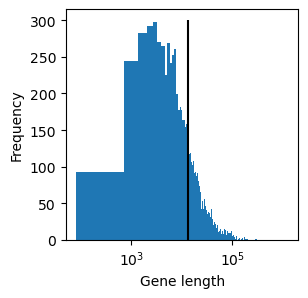

In [24]:
#Visualize gene length
median_gene_length=all_genes_details_expr_4["Length"].median()
print(median_gene_length)
fig=plt.figure(figsize=(3,3))
ax1 = fig.add_subplot(111)
len_hist=ax1.hist(all_genes_details_expr_4["Length"].to_numpy(),bins=2000)
plt.xscale("log")
plt.xlabel("Gene length")
plt.ylabel("Frequency")
plt.vlines(median_gene_length,0,300,color="black")

In [25]:
# So far cases where there are mutliple ensemble IDs or where a gene has synonym names are not considered!
# Thus, it might be possible to find a few more cases where a unique name and matching RNA value can be found

# 3. ChIP-Seq data

Analyzing Chip-Seq and other sequencing based data, based on gene positions obtained before

Focus on development time window around 4 hours post fertilization.

The supplememnt in https://www.cell.com/molecular-cell/fulltext/S1097-2765(22)00100-9?_returnURL=https%3A%2F%2Flinkinghub.elsevier.com%2Fretrieve%2Fpii%2FS1097276522001009%3Fshowall%3Dtrue#sectitle0030 mentions high overlap in omni ATAC seq peaks between 3.7, 4 and 4.3hpf, suggesting that the data is likely comparable between very close stages (i.e. between 4 and 4.3hpf). Still have to keep in mind that not all data sets report the exact same time points

In [26]:
#obtain ChIP-Seq data coverage from bigwig files for genes in dataframe
#return dataframe with gene annotation column for ChIP-Seq signal
#-1 are filled in instead of signal if problems/error with data retrival occurs
def get_coverage_for_genes_V1(df_genes,ID_col,Name_col,Chr_col,Start_col,Stop_col,Orientation_col,Signal_col,expected_dim,add_interval,big_wig_file_name,chr_add="chr",signal_type="mean"):
    #(names_list, chr_list, pos_start_list, pos_end_list, orientation_list, big_wig_file_name,intervall_at_pos,expected_dim,signal_type="mean")
    #names_list2=[]
    #chr_list2=[]
    #pos_list2=[]
    #orientation_list2=[]
    
    #return_coverage_dict={}
    chip_seq_signal=[]
    
    #lists of boundaries for signal read in
    list_lower_int_b=[]
    list_upper_int_b=[]
    
    for index, row in df_genes.iterrows():
        #get chromosome of the selected gene, possibly with name add i.e. 12->chr12
        #print(row[Chr_col])
        if chr_add!=None:
            gene_chr=chr_add+row[Chr_col]
        else:
            gene_chr=row[Chr_col]
        
        #get start stop pos of selected gene and increase by interval
        gene_lower_int_b=int(row[Start_col]-add_interval)
        gene_upper_int_b=int(row[Stop_col]+add_interval)
        
        list_lower_int_b.append(gene_lower_int_b)
        list_upper_int_b.append(gene_upper_int_b)
        
        #check if negative boundaries 
        if gene_lower_int_b>=0 and gene_upper_int_b>=0:
            try:
                big_wig_signal=big_wig_file_name.stats(gene_chr,gene_lower_int_b ,gene_upper_int_b,type=signal_type,nBins=expected_dim)
                print(row[ID_col],row[Name_col],gene_chr,gene_lower_int_b ,gene_upper_int_b,signal_type,expected_dim)
                if len(big_wig_signal)==expected_dim:
                    if expected_dim==1:#for sum of signal no need for additional brakets [1,2,3,...]
                        chip_seq_signal.append(big_wig_signal[0])
                    else:# longer sequences [[1,2,3],[2,3,4],...]
                        chip_seq_signal.append(big_wig_signal)
                #case of wrong dimension for chip seq read in
                else:
                    print("dimension error when trying to get data for ",row[ID_col],row[Name_col],len(big_wig_signal))

                    #chip_seq_signal.append("error")
                    chip_seq_signal.append(-np.ones(expected_dim))
                    
            #case of failed chipseq read in    
            except:
                print("error when trying to get data for ",row[ID_col],row[Name_col])

                #chip_seq_signal.append("error") 
                chip_seq_signal.append(-np.ones(expected_dim))
                
        #case of negative interval boundaries
        else:
            print("negative interval boundaries when trying to get data for ",row[ID_col],row[Name_col],gene_lower_int_b,gene_upper_int_b)

            #chip_seq_signal.append("error")             
            chip_seq_signal.append(-np.ones(expected_dim))
            
        print(index,"/",len(df_genes)-1)
        
        #filters out None
        if expected_dim!=1:
            chip_seq_signal_drop_nan=[[0 if item is None else item for item in inner_list] for inner_list in chip_seq_signal]
        if expected_dim==1:
            chip_seq_signal_drop_nan=[0 if item is None else item for item in chip_seq_signal]
            
    return_coverage_dict={"ID":df_genes[ID_col].tolist(),
                         "Name":df_genes[Name_col].tolist(),
                         "Chr":df_genes[Chr_col].tolist(),
                         "Signal start":list_lower_int_b,
                         "Signal stop":list_upper_int_b,
                         "Orientation":df_genes[Orientation_col].tolist(),
                         Signal_col:chip_seq_signal_drop_nan}

    return_coverage_df=pd.DataFrame(return_coverage_dict)
    return return_coverage_df


## Pol II Ser5P
(recruited RNA polymerase II, marked by phosphorylation at Serin5) 

https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3912416/

4.5 hpf /dome

Pol II (ab5408) antibody,for S5 phosphorylation (https://www.abcam.com/products/primary-antibodies/rna-polymerase-ii-ctd-repeat-ysptsps-phospho-s5-antibody-4h8-chip-grade-ab5408.html)


directly from DANIO Code: DCD000228SR / DCD006633BS


In [27]:
bw_Serin5P_4_3_hpf= pyBigWig.open("clustering_genome_sections/Serin5_data/Danio_code/Pol_II_4H8.bigwig")


In [28]:
df_Serin5P=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="S5P",expected_dim=1,add_interval=1000,big_wig_file_name=bw_Serin5P_4_3_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000019371 flt1 chr24 21749810 21809819 mean 1
402 / 8897
ENSDARG00000015537 gad2 chr24 6132145 6159933 mean 1
403 / 8897
ENSDARG00000076010 twist1b chr16 19731539 19736040 mean 1
404 / 8897
ENSDARG00000103019 gstp1.1 chr14 3494542 3504549 mean 1
405 / 8897
ENSDARG00000070917 kitlga chr25 18117905 18141584 mean 1
406 / 8897
ENSDARG00000015566 dnmt3ab chr17 36936808 37055963 mean 1
407 / 8897
ENSDARG00000067829 ppargc1a chr7 70577429 70670850 mean 1
408 / 8897
ENSDARG00000102004 apoea chr19 10854158 10860694 mean 1
409 / 8897
ENSDARG00000103295 cyp3a65 chr1 59337174 59349105 mean 1
410 / 8897
ENSDARG00000056029 cyp26c1 chr17 19521856 19536316 mean 1
411 / 8897
ENSDARG00000013598 tnfb chr15 34698593 34703646 mean 1
412 / 8897
ENSDARG00000017321 kdr chr20 22219988 22278544 mean 1
413 / 8897
ENSDARG00000023537 ahr1b chr22 12978213 13043992 mean 1
414 / 8897
ENSDARG00000035435 m17 chr5 32154227 32159198 mean 1
415 / 8897
ENSDARG00000053868 etsrp chr16 42007813 42015143 mean 1
416 / 

ENSDARG00000042978 cyp2p6 chr20 25562105 25569441 mean 1
1212 / 8897
ENSDARG00000032617 fgfrl1a chr14 17441919 17564400 mean 1
1213 / 8897
ENSDARG00000038153 lgals2b chr6 602278 610921 mean 1
1214 / 8897
ENSDARG00000018283 cyba chr18 31072265 31076620 mean 1
1215 / 8897
ENSDARG00000012381 hsc70 chr15 37834916 37851961 mean 1
1216 / 8897
ENSDARG00000011434 ptger2a chr17 14885828 14890109 mean 1
1217 / 8897
ENSDARG00000057113 c6 chr21 20914456 20933729 mean 1
1218 / 8897
ENSDARG00000012504 rlbp1a chr7 13866721 13885508 mean 1
1219 / 8897
ENSDARG00000041062 calb2a chr18 21197762 21219851 mean 1
1220 / 8897
ENSDARG00000074396 fscn2b chr12 34438254 34459662 mean 1
1221 / 8897
ENSDARG00000010434 clu chr20 39259608 39274884 mean 1
1222 / 8897
ENSDARG00000022509 cox4i2 chr23 18943496 18952148 mean 1
1223 / 8897
ENSDARG00000058039 bhlhe22 chr24 24460558 24464346 mean 1
1224 / 8897
ENSDARG00000008133 foxl1 chr18 17482557 17486419 mean 1
1225 / 8897
ENSDARG00000053476 lipca chr7 30391705 30407479

!None! mmrn2b chr12 25929845 25950093 mean 1
2111 / 8897
ENSDARG00000099096 gabrb4 chr21 37786616 37892763 mean 1
2112 / 8897
ENSDARG00000057992 fstb chr10 8967206 8977823 mean 1
2113 / 8897
ENSDARG00000068088 tcnba chr5 30617027 30621600 mean 1
2114 / 8897
ENSDARG00000074253 olig3 chr13 1304351 1309020 mean 1
2115 / 8897
ENSDARG00000075752 myo18aa chr10 36949772 37076375 mean 1
2116 / 8897
ENSDARG00000056938 kera chr4 16336156 16346059 mean 1
2117 / 8897
ENSDARG00000007715 lgsn chr11 11262451 11267878 mean 1
2118 / 8897
ENSDARG00000090615 cd59 chr7 38694724 38699613 mean 1
2119 / 8897
ENSDARG00000070726 cnga3a chr6 38792933 38820054 mean 1
2120 / 8897
ENSDARG00000099124 f3a chr24 31276401 31291719 mean 1
2121 / 8897
ENSDARG00000062590 pleca chr19 22407308 22622646 mean 1
2122 / 8897
ENSDARG00000100244 ebf3a chr12 42434792 42580480 mean 1
2123 / 8897
ENSDARG00000055843 cdh10a chr2 28888936 28935284 mean 1
2124 / 8897
ENSDARG00000098226 smpd3 chr25 13063228 13155364 mean 1
2125 / 8897
E

ENSDARG00000101054 syn2b chr11 673592 763721 mean 1
2867 / 8897
ENSDARG00000002192 aspn chr22 10478965 10488511 mean 1
2868 / 8897
ENSDARG00000056739 tas1r1 chr23 21423747 21441054 mean 1
2869 / 8897
ENSDARG00000041358 lgi3 chr8 51374308 51405806 mean 1
2870 / 8897
ENSDARG00000041715 bco2b chr15 21672454 21679634 mean 1
2871 / 8897
ENSDARG00000101109 cldn15b chr5 53907608 53956183 mean 1
2872 / 8897
ENSDARG00000091320 nlrc6 chr1 54765855 54786185 mean 1
2873 / 8897
ENSDARG00000012833 foxn3 chr17 16564185 16735471 mean 1
2874 / 8897
ENSDARG00000053293 ftr14 chr2 43130147 43136700 mean 1
2875 / 8897
ENSDARG00000103467 limk1a chr15 165139 253813 mean 1
2876 / 8897
ENSDARG00000051925 cyb5r2 chr25 16045615 16058540 mean 1
2877 / 8897
ENSDARG00000061405 eva1a chr17 32567575 32608533 mean 1
2878 / 8897
ENSDARG00000099149 hs3st3b1a chr3 48842221 48870871 mean 1
2879 / 8897
ENSDARG00000002259 ca15c chr12 4337291 4347109 mean 1
2880 / 8897
ENSDARG00000101713 scn2b chr15 12515188 12546683 mean 1


ENSDARG00000014849 pih1d2 chr15 18137518 18163650 mean 1
3637 / 8897
ENSDARG00000034808 kcnip1b chr10 21972447 22032921 mean 1
3638 / 8897
ENSDARG00000004363 lhfpl6 chr10 31950338 32039263 mean 1
3639 / 8897
ENSDARG00000011724 marveld1 chr13 39531050 39534365 mean 1
3640 / 8897
ENSDARG00000039070 pnhd chr2 53500747 53526896 mean 1
3641 / 8897
ENSDARG00000069265 matn3b chr13 32626283 32636905 mean 1
3642 / 8897
ENSDARG00000101307 pcdh1gb2 chr10 21676058 21821057 mean 1
3643 / 8897
ENSDARG00000056464 fitm1l chr2 24303841 24310582 mean 1
3644 / 8897
ENSDARG00000074148 rbpjl chr6 52756439 52788489 mean 1
3645 / 8897
ENSDARG00000109310 im:7150988 chr14 3366534 3382229 mean 1
3646 / 8897
ENSDARG00000079497 tcima chr5 27865649 27868657 mean 1
3647 / 8897
ENSDARG00000034757 zdhhc2 chr14 30425956 30453268 mean 1
3648 / 8897
ENSDARG00000045145 shisa9a chr12 19791918 19866585 mean 1
3649 / 8897
ENSDARG00000094854 ms4a17a.9 chr4 76607795 76633648 mean 1
3650 / 8897
ENSDARG00000045447 slc35g2b chr2

... (4 outputs left out)

ENSDARG00000006292 cfap91 chr9 9440541 9499954 mean 1
6811 / 8897
!None! si:ch73-92e7.6 chr22 2573182 2591514 mean 1
6812 / 8897
ENSDARG00000067646 tmem232 chr5 56964171 56998795 mean 1
6813 / 8897
ENSDARG00000079857 sanbr chr17 23936394 23958037 mean 1
6814 / 8897
ENSDARG00000104752 colec10 chr16 9679908 9695822 mean 1
6815 / 8897
ENSDARG00000063088 si:dkey-211g8.6 chr19 10610661 10620787 mean 1
6816 / 8897
ENSDARG00000095136 si:ch211-130m23.2 chr5 46292850 46308909 mean 1
6817 / 8897
ENSDARG00000094708 sftpba chr10 7797070 7805465 mean 1
6818 / 8897
ENSDARG00000074669 cacng4b chr3 61076532 61099950 mean 1
6819 / 8897
ENSDARG00000099042 cfap157 chr5 65156538 65172706 mean 1
6820 / 8897
ENSDARG00000061000 klhdc8a chr11 38032047 38084407 mean 1
6821 / 8897
ENSDARG00000090041 si:dkey-163m14.6 chr21 8005306 8027770 mean 1
6822 / 8897
ENSDARG00000088625 si:ch211-142d6.2 chr7 73442802 73446871 mean 1
6823 / 8897
ENSDARG00000075417 zgc:175107 chr4 72533789 72545805 mean 1
6824 / 8897
ENSDARG

ENSDARG00000075813 asphd1 chr3 15270922 15285695 mean 1
7398 / 8897
!None! phc3 chr2 37423243 37450325 mean 1
7399 / 8897
ENSDARG00000008263 mfsd4ab chr23 18102103 18115890 mean 1
7400 / 8897
ENSDARG00000075151 ifi27.7 chr13 37644570 37650598 mean 1
7401 / 8897
ENSDARG00000052435 spred2a chr1 51448274 51476000 mean 1
7402 / 8897
ENSDARG00000074217 ifi27.3 chr13 37608458 37616026 mean 1
7403 / 8897
ENSDARG00000014395 selenoo2 chr4 5377374 5389423 mean 1
7404 / 8897
ENSDARG00000038855 chmp5a chr2 30893590 30903344 mean 1
7405 / 8897
ENSDARG00000095580 si:ch211-67e16.11 chr9 14151154 14197077 mean 1
7406 / 8897
ENSDARG00000070442 si:ch211-113g11.6 chr16 29406666 29453039 mean 1
7407 / 8897
ENSDARG00000015931 snap91b chr4 5259255 5303180 mean 1
7408 / 8897
ENSDARG00000093584 zgc:193505 chr13 22674785 22679490 mean 1
7409 / 8897
ENSDARG00000068865 si:dkey-61p9.7 chr4 77656660 77670220 mean 1
7410 / 8897
ENSDARG00000078108 dok1a chr1 41477290 41485978 mean 1
7411 / 8897
ENSDARG00000062277 pp

ENSDARG00000096226 znf1072 chr4 43059273 43071566 mean 1
7915 / 8897
ENSDARG00000115506 si:dkey-122c11.8 chr4 39104046 39113613 mean 1
7916 / 8897
ENSDARG00000103527 si:dkeyp-35e5.9 chr4 62184244 62192740 mean 1
7917 / 8897
ENSDARG00000104335 si:ch211-212k5.4 chr4 58575578 58584040 mean 1
7918 / 8897
ENSDARG00000116915 si:ch211-133h13.1 chr4 67998935 68020811 mean 1
7919 / 8897
ENSDARG00000105471 si:ch73-368j24.1 chr7 6408215 6411086 mean 1
7920 / 8897
ENSDARG00000093284 si:ch211-173m16.2 chr9 3034077 3038315 mean 1
7921 / 8897
ENSDARG00000102198 si:ch73-233f7.3 chr14 2361332 2365897 mean 1
7922 / 8897
ENSDARG00000104721 spink2.6 chr14 15621810 15626476 mean 1
7923 / 8897
ENSDARG00000099621 si:ch211-69b22.5 chr14 32070776 32092158 mean 1
7924 / 8897
ENSDARG00000109963 tcerg1l chr12 41990648 42197298 mean 1
7925 / 8897
ENSDARG00000071735 prlh2 chr24 11104830 11111406 mean 1
7926 / 8897
ENSDARG00000112100 neto2 chr7 41950006 41978760 mean 1
7927 / 8897
ENSDARG00000095540 sid1 chr11 13615

ENSDARG00000103312 LOC101883133 chr16 51309858 51332907 mean 1
8454 / 8897
!None! erc2 chr8 53700403 53727365 mean 1
8455 / 8897
ENSDARG00000052027 tspan1 chr6 33104454 33130367 mean 1
8456 / 8897
ENSDARG00000101088 si:ch73-359m17.5 chr19 48338355 48341773 mean 1
8457 / 8897
ENSDARG00000100639 si:ch211-262i1.2 chr11 14308083 14312116 mean 1
8458 / 8897
ENSDARG00000069904 col24a1 chr23 46048495 46139053 mean 1
8459 / 8897
ENSDARG00000103788 si:rp71-1d10.6 chr14 25051490 25056736 mean 1
8460 / 8897
ENSDARG00000099764 si:dkey-74i1.3 chr15 32706715 32710449 mean 1
8461 / 8897
ENSDARG00000102823 LOC101884131 chr25 16063376 16074397 mean 1
8462 / 8897
ENSDARG00000109818 c13h7orf72 chr13 16029314 16067991 mean 1
8463 / 8897
ENSDARG00000097731 si:dkey-166f24.2 chr17 44248840 44255274 mean 1
8464 / 8897
ENSDARG00000071261 LOC101884253 chr23 6141097 6157161 mean 1
8465 / 8897
ENSDARG00000103254 si:dkeyp-80d11.4 chr4 71000548 71007549 mean 1
8466 / 8897
ENSDARG00000087245 LOC101884526 chr10 23536

In [29]:
df_Serin5P

,ID,Name,Chr,Signal start,Signal stop,Orientation,S5P
0,ENSDARG00000069105,fgfr4,21,37182903,37195362,minus,1.026523
1,ENSDARG00000014496,trpv6,16,12293284,12320831,minus,0.403468
2,ENSDARG00000053475,ngb,17,44960947,44969219,minus,0.334368
3,ENSDARG00000053502,cryaa,1,29095907,29101918,plus,0.495911
4,ENSDARG00000054771,ghra,8,31464222,31607409,minus,0.280604
...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,72216296,72262262,minus,0.463831
8894,ENSDARG00000099181,LOC798522,14,668735,679850,minus,0.57247
8895,ENSDARG00000093052,LOC798694,21,20794468,20841952,minus,0.426057
8896,ENSDARG00000097256,LOC799067,17,15296332,15305804,plus,0.420374


# H3K27ac
(Histone modification)

In [30]:
#DCD000136SR , 4.3 hpf
#https://pubmed.ncbi.nlm.nih.gov/22593555/
#bw_H3K27ac_4_3_hpf = pyBigWig.open("https://danio-code.zfin.org/files/annotated_files/ChIP-seq/DCD006178BS/ChIP-seq_Skarmeta_Lab_H3K27ac_0002AS.DCD000638SQ.danRer11.USERpanosfirbas.R1.merged.nodup.pval.signal.bigwig")
bw_H3K27ac_4_3_hpf =pyBigWig.open("clustering_genome_sections/H3K27ac_data_4_3hpf/H3K27ac.bigwig")



#data from Pancholi et al paper aligned to danrer11 (also https://pubmed.ncbi.nlm.nih.gov/22593555/)
#bw_H3K27ac_4_3_hpf =pyBigWig.open("clustering_genome_sections/H3K27ac_data_4_3hpf/H3K27ac_Dome_ut1m.bw")

#data from Pancholi et al paper aligned to danrer11, with lowered quality threshold -q 20 
#bw_H3K27ac_4_3_hpf =pyBigWig.open("clustering_genome_sections/H3K27ac_data_4_3hpf/H3K27ac_Dome_ut1m_4.bw")

In [31]:
df_H3K27ac=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="H3K27ac",expected_dim=1,add_interval=1000,big_wig_file_name=bw_H3K27ac_4_3_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000070683 dkk3b chr25 16131575 16147845 mean 1
587 / 8897
ENSDARG00000018566 flnca chr25 35019128 35042066 mean 1
588 / 8897
!None! lama2 chr20 1798016 2036120 mean 1
589 / 8897
ENSDARG00000103969 smyhc2 chr24 40679153 40701596 mean 1
590 / 8897
ENSDARG00000104474 il6r chr16 22176254 22195400 mean 1
591 / 8897
ENSDARG00000069945 p2ry12 chr15 1115467 1121832 mean 1
592 / 8897
ENSDARG00000075694 adora1b chr8 24121498 24136171 mean 1
593 / 8897
ENSDARG00000102211 csf3a chr12 10630042 10639063 mean 1
594 / 8897
ENSDARG00000090833 igfbp6b chr23 36600984 36606843 mean 1
595 / 8897
ENSDARG00000007412 slc2a1b chr6 48064134 48095342 mean 1
596 / 8897
!None! slc12a1 chr18 5263561 5307656 mean 1
597 / 8897
ENSDARG00000068141 tnfsf11 chr9 18021993 18044304 mean 1
598 / 8897
ENSDARG00000011257 enpp2 chr16 9608712 9663244 mean 1
599 / 8897
ENSDARG00000077778 adamts9 chr11 19158090 19228802 mean 1
600 / 8897
ENSDARG00000012593 col5a1 chr21 6555569 6726777 mean 1
601 / 8897
ENSDARG00000070348

ENSDARG00000014103 dkk1a chr13 41021502 41027398 mean 1
1487 / 8897
ENSDARG00000070142 cart4 chr19 42240530 42245358 mean 1
1488 / 8897
ENSDARG00000053625 anxa2b chr7 29517396 29534948 mean 1
1489 / 8897
ENSDARG00000015955 cldn3d chr21 25753276 25757119 mean 1
1490 / 8897
ENSDARG00000058880 cldnj chr15 2630211 2633891 mean 1
1491 / 8897
!None! cldn1 chr2 67788 72962 mean 1
1492 / 8897
ENSDARG00000044155 mafaa chr6 32698363 32704518 mean 1
1493 / 8897
ENSDARG00000055781 ptger3 chr6 37306570 37313553 mean 1
1494 / 8897
ENSDARG00000022817 pvalb3 chr12 17704216 17708517 mean 1
1495 / 8897
ENSDARG00000067781 urp2 chr1 1598979 1615496 mean 1
1496 / 8897
ENSDARG00000068729 eif2ak2 chr13 50206947 50235100 mean 1
1497 / 8897
ENSDARG00000114031 smyhc3 chr24 40711794 40727073 mean 1
1498 / 8897
ENSDARG00000045070 itgb3b chr12 26435104 26462744 mean 1
1499 / 8897
ENSDARG00000001993 myhb chr6 40744667 40757175 mean 1
1500 / 8897
ENSDARG00000056284 drd7 chr5 27436481 27439812 mean 1
1501 / 8897
ENSD

ENSDARG00000034211 capn2l chr22 26442235 26477079 mean 1
2341 / 8897
ENSDARG00000039516 c8a chr2 1486048 1500527 mean 1
2342 / 8897
ENSDARG00000069048 serpinf1 chr21 40105466 40121169 mean 1
2343 / 8897
ENSDARG00000071196 cavin2b chr6 8706812 8737767 mean 1
2344 / 8897
ENSDARG00000036028 arrdc3b chr10 43760480 43772447 mean 1
2345 / 8897
ENSDARG00000004307 lypd6 chr9 23067151 23119350 mean 1
2346 / 8897
ENSDARG00000055302 grid2 chr8 28899600 29588703 mean 1
2347 / 8897
ENSDARG00000038123 myl9a chr23 42812343 42824419 mean 1
2348 / 8897
ENSDARG00000006174 lrrc23 chr23 20126883 20134982 mean 1
2349 / 8897
ENSDARG00000041179 crygm5 chr9 22349937 22353271 mean 1
2350 / 8897
ENSDARG00000044254 anxa3b chr10 9246593 9270733 mean 1
2351 / 8897
ENSDARG00000045592 tnni2a.1 chr25 31221069 31237549 mean 1
2352 / 8897
ENSDARG00000014941 tprkb chr4 28370727 28374928 mean 1
2353 / 8897
ENSDARG00000012829 asah2 chr12 6116682 6143308 mean 1
2354 / 8897
ENSDARG00000043719 c3a.6 chr1 56035644 56081165 me

ENSDARG00000098788 pcdh2g17 chr14 1888679 2002386 mean 1
3054 / 8897
ENSDARG00000018797 crygmxl1 chr9 22055172 22058658 mean 1
3055 / 8897
ENSDARG00000039064 st3gal7 chr13 40715318 40727881 mean 1
3056 / 8897
ENSDARG00000077643 lypd6b chr9 23141170 23181883 mean 1
3057 / 8897
ENSDARG00000019355 coa7 chr20 16162200 16172297 mean 1
3058 / 8897
ENSDARG00000056178 dpt chr6 29183137 29196623 mean 1
3059 / 8897
ENSDARG00000076594 pcdh12 chr14 16305595 16329905 mean 1
3060 / 8897
ENSDARG00000077084 col28a1a chr19 25475220 25513695 mean 1
3061 / 8897
ENSDARG00000035151 drll.1 chr5 61629696 61639125 mean 1
3062 / 8897
ENSDARG00000053724 adcyap1r1b chr6 32965721 33024742 mean 1
3063 / 8897
ENSDARG00000062661 abca4b chr2 15202318 15295707 mean 1
3064 / 8897
ENSDARG00000035150 drll.2 chr5 61614663 61625693 mean 1
3065 / 8897
ENSDARG00000101535 col10a1b chr20 483128 489236 mean 1
3066 / 8897
ENSDARG00000092858 si:ch1073-126c3.2 chr13 20534159 20541790 mean 1
3067 / 8897
ENSDARG00000096304 btr31 chr

ENSDARG00000024708 slc25a23b chr3 34219194 34232082 mean 1
3806 / 8897
ENSDARG00000079455 nlgn4xa chr1 32520542 32694355 mean 1
3807 / 8897
ENSDARG00000069113 dbn1 chr21 36796027 36973213 mean 1
3808 / 8897
ENSDARG00000058100 b3gnt3.4 chr8 13629047 13642040 mean 1
3809 / 8897
ENSDARG00000079892 plxnb2a.3 chr4 14643076 14667726 mean 1
3810 / 8897
ENSDARG00000062936 ndnf chr23 2051962 2100338 mean 1
3811 / 8897
ENSDARG00000068156 chchd7 chr7 58719601 58730894 mean 1
3812 / 8897
ENSDARG00000060948 dync1i1 chr16 25315819 25338834 mean 1
3813 / 8897
ENSDARG00000100486 foxo6a chr16 7312481 7363809 mean 1
3814 / 8897
ENSDARG00000055698 pcnx2 chr13 23668666 23715936 mean 1
3815 / 8897
ENSDARG00000069264 si:ch211-196h16.5 chr1 54864513 54890124 mean 1
3816 / 8897
ENSDARG00000030954 ftr56 chr19 12397132 12405622 mean 1
3817 / 8897
ENSDARG00000075098 wdr17 chr1 38757394 38804939 mean 1
3818 / 8897
ENSDARG00000079165 galr1b chr7 34978182 35037567 mean 1
3819 / 8897
ENSDARG00000062171 olfml3b chr11

... (4 outputs left out)

ENSDARG00000099712 zgc:163073 chr12 4835856 4842018 mean 1
6942 / 8897
ENSDARG00000042521 si:dkey-251i10.1 chr5 67447637 67461185 mean 1
6943 / 8897
ENSDARG00000008790 actr3b chr24 7292946 7323188 mean 1
6944 / 8897
ENSDARG00000094894 tyrobp chr16 25194602 25201757 mean 1
6945 / 8897
ENSDARG00000044973 krt98 chr11 11502557 11515153 mean 1
6946 / 8897
ENSDARG00000076132 siglec15l chr16 41504263 41516698 mean 1
6947 / 8897
ENSDARG00000074219 map3k22 chr24 20212338 20321869 mean 1
6948 / 8897
ENSDARG00000052158 il23r chr6 34868701 34896164 mean 1
6949 / 8897
ENSDARG00000079227 plekhs1.1 chr12 30516379 30524324 mean 1
6950 / 8897
ENSDARG00000003632 cav4a chr11 36243143 36251017 mean 1
6951 / 8897
ENSDARG00000076440 btbd6a chr13 33393113 33400828 mean 1
6952 / 8897
ENSDARG00000074772 ccl44 chr11 6181951 6189393 mean 1
6953 / 8897
ENSDARG00000056554 rap1gapa chr23 22310580 22426257 mean 1
6954 / 8897
ENSDARG00000090472 ttll10 chr23 24067077 24114498 mean 1
6955 / 8897
ENSDARG00000111698 tnfs

ENSDARG00000003077 gpx9 chr12 45676241 45689595 mean 1
7523 / 8897
ENSDARG00000074813 btr05 chr7 16197397 16206820 mean 1
7524 / 8897
ENSDARG00000088251 lgals17 chr15 17058369 17072280 mean 1
7525 / 8897
ENSDARG00000073799 zgc:194210 chr16 31426049 31435882 mean 1
7526 / 8897
ENSDARG00000087318 jac10 chr7 8378840 8382432 mean 1
7527 / 8897
ENSDARG00000075996 znfl1b chr9 15836398 15842997 mean 1
7528 / 8897
ENSDARG00000075330 phox2ba chr1 19073326 19080957 mean 1
7529 / 8897
ENSDARG00000088567 vps72b chr16 29629197 29648824 mean 1
7530 / 8897
ENSDARG00000055172 si:ch211-256m1.8 chr3 25152998 25166137 mean 1
7531 / 8897
ENSDARG00000089717 qpct chr17 42841684 42873385 mean 1
7532 / 8897
ENSDARG00000076958 jac8 chr7 8542317 8545858 mean 1
7533 / 8897
ENSDARG00000098076 kcnq1.2 chr25 2354926 2437570 mean 1
7534 / 8897
ENSDARG00000044695 ccdc80l2 chr21 19833027 19843105 mean 1
7535 / 8897
ENSDARG00000089326 arhgap20 chr9 29527386 29546462 mean 1
7536 / 8897
ENSDARG00000063604 coro2bb chr25 1

ENSDARG00000029114 lmtk3 chr16 32058415 32081796 mean 1
8104 / 8897
ENSDARG00000086957 si:dkeyp-118a3.2 chr1 19302182 19330853 mean 1
8105 / 8897
!None! si:ch73-375g18.1 chr23 44500271 44517901 mean 1
8106 / 8897
ENSDARG00000076265 ano8a chr2 24320333 24349972 mean 1
8107 / 8897
ENSDARG00000061797 zgc:154006 chr2 24385453 24403342 mean 1
8108 / 8897
ENSDARG00000020594 txlnba chr20 36844789 36888250 mean 1
8109 / 8897
ENSDARG00000111920 LOC563082 chr14 51825150 51857895 mean 1
8110 / 8897
ENSDARG00000075517 si:ch211-120k19.1 chr16 16967684 16976231 mean 1
8111 / 8897
ENSDARG00000061191 plekho1a chr19 42366286 42392635 mean 1
8112 / 8897
ENSDARG00000011983 zgc:136908 chr1 55786036 55811599 mean 1
8113 / 8897
ENSDARG00000078839 LOC563710 chr10 18290418 18469275 mean 1
8114 / 8897
ENSDARG00000086056 plekhg6 chr16 17006089 17057664 mean 1
8115 / 8897
ENSDARG00000099284 si:dkey-228b2.6 chr21 13146015 13150551 mean 1
8116 / 8897
ENSDARG00000076230 atp10b chr14 22296123 22363415 mean 1
8117 / 

ENSDARG00000069787 LOC100149241 chr3 57787695 57817882 mean 1
8628 / 8897
ENSDARG00000060566 LOC100150676 chr21 39359011 39421136 mean 1
8629 / 8897
ENSDARG00000101785 LOC100151049 chr19 43296534 43310596 mean 1
8630 / 8897
ENSDARG00000098478 LOC100329294 chr8 546316 556227 mean 1
8631 / 8897
ENSDARG00000105022 LOC100329607 chr2 58214747 58244413 mean 1
8632 / 8897
ENSDARG00000102580 LOC100330257 chr17 5622625 5630904 mean 1
8633 / 8897
ENSDARG00000098551 LOC100330316 chr4 3269592 3298355 mean 1
8634 / 8897
ENSDARG00000034667 LOC100331214 chr22 15631805 15669516 mean 1
8635 / 8897
ENSDARG00000106579 LOC100331257 chr8 50517493 50526282 mean 1
8636 / 8897
ENSDARG00000092652 LOC100331807 chr21 16143265 16166997 mean 1
8637 / 8897
ENSDARG00000115511 LOC100331974 chr22 6025208 6055998 mean 1
8638 / 8897
ENSDARG00000109276 LOC100332446 chr12 45338581 45350913 mean 1
8639 / 8897
ENSDARG00000060549 LOC100332538 chr15 47007504 47077914 mean 1
8640 / 8897
ENSDARG00000101243 LOC100333095 chr8 347

In [32]:
df_H3K27ac

,ID,Name,Chr,Signal start,Signal stop,Orientation,H3K27ac
0,ENSDARG00000069105,fgfr4,21,37182903,37195362,minus,2.483461
1,ENSDARG00000014496,trpv6,16,12293284,12320831,minus,0.315049
2,ENSDARG00000053475,ngb,17,44960947,44969219,minus,0.220935
3,ENSDARG00000053502,cryaa,1,29095907,29101918,plus,0.214778
4,ENSDARG00000054771,ghra,8,31464222,31607409,minus,0.206504
...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,72216296,72262262,minus,0.242808
8894,ENSDARG00000099181,LOC798522,14,668735,679850,minus,0.163545
8895,ENSDARG00000093052,LOC798694,21,20794468,20841952,minus,0.167495
8896,ENSDARG00000097256,LOC799067,17,15296332,15305804,plus,0.263778


# H3K27 at Prim 5 stage (24hpf)


In [33]:
#DCD000652SQ
#https://pubmed.ncbi.nlm.nih.gov/22593555/ (same as 4.3 hpf)

bw_H3K27ac_24_hpf =pyBigWig.open("clustering_genome_sections/H3K27ac_data_24hpf/H3K27ac_24hpf.bigwig")

df_H3K27ac_24_hpf=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="H3K27ac 24hpf",expected_dim=1,add_interval=1000,big_wig_file_name=bw_H3K27ac_24_hpf,chr_add="chr",signal_type="mean")

df_H3K27ac_24_hpf

ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

550 / 8897
ENSDARG00000036292 cdx4 chr14 32960703 32966158 mean 1
551 / 8897
ENSDARG00000054239 ghrl chr6 40436481 40440615 mean 1
552 / 8897
ENSDARG00000044457 gfi1ab chr6 29003062 29008456 mean 1
553 / 8897
ENSDARG00000009418 mef2cb chr5 48180004 48308767 mean 1
554 / 8897
ENSDARG00000055100 cxcl12b chr22 26928559 26946511 mean 1
555 / 8897
ENSDARG00000042112 dio1 chr8 18038559 18043062 mean 1
556 / 8897
ENSDARG00000070668 cd4-1 chr16 11910903 11947162 mean 1
557 / 8897
ENSDARG00000004246 slit2 chr1 23783073 23911040 mean 1
558 / 8897
ENSDARG00000034268 slit3 chr14 24490818 24762133 mean 1
559 / 8897
ENSDARG00000004219 slc6a3 chr16 247239 264658 mean 1
560 / 8897
!None! hbbe1.1 chr3 55113097 55115874 mean 1
561 / 8897
ENSDARG00000069888 cldna chr15 2654658 2658508 mean 1
562 / 8897
ENSDARG00000009544 cldnb chr21 25764712 25767840 mean 1
563 / 8897
ENSDARG00000011989 crx chr5 36931741 36937443 mean 1
564 / 8897
ENSDARG00000019835 nkx2.1 chr17 38261443 38265625 mean 1
565 / 8897
ENSDAR

ENSDARG00000014287 eno2 chr19 5071913 5092687 mean 1
772 / 8897
ENSDARG00000000943 dzip1 chr6 7248453 7281302 mean 1
773 / 8897
ENSDARG00000032963 her12 chr23 21443922 21447982 mean 1
774 / 8897
ENSDARG00000091756 insm1a chr20 48481924 48486354 mean 1
775 / 8897
ENSDARG00000027290 nrp1b chr2 43468241 43508278 mean 1
776 / 8897
ENSDARG00000016457 irf9 chr12 13281709 13307886 mean 1
777 / 8897
ENSDARG00000025348 igfbp5b chr9 46819636 46843179 mean 1
778 / 8897
ENSDARG00000052131 gli3 chr24 11527247 11822546 mean 1
779 / 8897
ENSDARG00000044415 tlr5a chr20 51477717 51483699 mean 1
780 / 8897
ENSDARG00000034930 gja10b chr20 23959384 23965382 mean 1
781 / 8897
ENSDARG00000019342 chrnd chr24 25682024 25692020 mean 1
782 / 8897
ENSDARG00000003259 loxa chr10 7737540 7757894 mean 1
783 / 8897
ENSDARG00000026473 six1b chr20 20498923 20502818 mean 1
784 / 8897
ENSDARG00000040065 gja5a chr9 30463402 30478594 mean 1
785 / 8897
ENSDARG00000023362 nr5a1b chr21 8275989 8318588 mean 1
786 / 8897
ENSDAR

ENSDARG00000070148 cygb2 chr6 22596370 22630399 mean 1
1353 / 8897
ENSDARG00000031737 pthlha chr4 575992 627858 mean 1
1354 / 8897
ENSDARG00000052061 col4a6 chr7 50919437 51103550 mean 1
1355 / 8897
ENSDARG00000055009 col4a1 chr9 8634263 8731458 mean 1
1356 / 8897
ENSDARG00000104815 lmx1ba chr5 5031833 5148391 mean 1
1357 / 8897
ENSDARG00000101984 pde6gb chr12 35979523 35989575 mean 1
1358 / 8897
ENSDARG00000001910 rorab chr7 29537633 29626728 mean 1
1359 / 8897
ENSDARG00000003523 itln3 chr14 16344004 16353209 mean 1
1360 / 8897
ENSDARG00000061355 aoc1 chr24 40000290 40010419 mean 1
1361 / 8897
ENSDARG00000060222 scn1ba chr16 41871298 41899007 mean 1
1362 / 8897
ENSDARG00000102805 cyp2aa12 chr23 42291748 42307332 mean 1
1363 / 8897
ENSDARG00000092730 enam chr1 43900966 43906263 mean 1
1364 / 8897
ENSDARG00000070954 hmx2 chr17 21781176 21785497 mean 1
1365 / 8897
ENSDARG00000055559 chrna6 chr1 22483565 22513063 mean 1
1366 / 8897
ENSDARG00000101569 ppargc1b chr14 24934054 25002584 mean 

ENSDARG00000053831 vtnb chr21 39066510 39082015 mean 1
1602 / 8897
ENSDARG00000019144 rab4a chr13 24294896 24312630 mean 1
1603 / 8897
ENSDARG00000073675 tlr8b chr10 43837297 43851090 mean 1
1604 / 8897
ENSDARG00000090035 rtn4r chr5 10765558 10947232 mean 1
1605 / 8897
ENSDARG00000052012 rtn4rl2a chr1 44490077 44494548 mean 1
1606 / 8897
ENSDARG00000004082 gja2 chr5 23629362 23637389 mean 1
1607 / 8897
ENSDARG00000006350 nkx1.2la chr13 40769628 40774595 mean 1
1608 / 8897
ENSDARG00000022689 itgb1b.2 chr2 43637983 43654368 mean 1
1609 / 8897
ENSDARG00000005485 ucmab chr25 7982014 7989936 mean 1
1610 / 8897
ENSDARG00000025254 s100a10b chr16 23396785 23400285 mean 1
1611 / 8897
ENSDARG00000033609 map1lc3a chr11 26608110 26616608 mean 1
1612 / 8897
ENSDARG00000095751 leg1.2 chr20 1397730 1407308 mean 1
1613 / 8897
ENSDARG00000008030 myl9b chr6 1786280 1800330 mean 1
1614 / 8897
ENSDARG00000031483 col9a1b chr13 39118464 39160807 mean 1
1615 / 8897
ENSDARG00000021184 rbfox1l chr16 31899129 3

ENSDARG00000052997 sema4e chr2 49567980 49604676 mean 1
2171 / 8897
ENSDARG00000038139 pdgfbb chr3 24274744 24296936 mean 1
2172 / 8897
ENSDARG00000068858 il2rga chr10 33543329 33558299 mean 1
2173 / 8897
ENSDARG00000063097 scube1 chr4 8906147 9009846 mean 1
2174 / 8897
ENSDARG00000028725 adra1aa chr8 5023468 5081889 mean 1
2175 / 8897
ENSDARG00000039929 ckmt2b chr5 51593174 51609761 mean 1
2176 / 8897
ENSDARG00000058004 six2a chr13 10231695 10236566 mean 1
2177 / 8897
!None! mapta chr12 4733885 4803930 mean 1
2178 / 8897
ENSDARG00000096368 neu3.5 chr21 21816587 21820946 mean 1
2179 / 8897
ENSDARG00000101021 slc22a5 chr21 45660275 45673184 mean 1
2180 / 8897
ENSDARG00000090537 ifit11 chr12 17016864 17025095 mean 1
2181 / 8897
ENSDARG00000077290 mmp25a chr3 32619952 32630335 mean 1
2182 / 8897
ENSDARG00000062182 slc22a7b.3 chr17 21981059 21994853 mean 1
2183 / 8897
ENSDARG00000075253 pik3cb chr15 7063796 7162784 mean 1
2184 / 8897
ENSDARG00000070389 foxf2b chr20 26689000 26693944 mean 1

... (15 outputs left out)

!None! si:ch1073-209e23.1 chr17 56251 73436 mean 1
7813 / 8897
ENSDARG00000105557 LOC101885004 chr7 24840439 24862955 mean 1
7814 / 8897
!None! akap7 chr20 2432293 2482813 mean 1
7815 / 8897
ENSDARG00000116896 LOC101885033 chr8 39662686 39674425 mean 1
7816 / 8897
ENSDARG00000087100 ntng2b chr21 3976670 4033674 mean 1
7817 / 8897
ENSDARG00000100596 si:ch73-43g23.1 chr14 7119618 7129892 mean 1
7818 / 8897
ENSDARG00000088283 si:ch73-248e21.5 chr3 32607018 32613051 mean 1
7819 / 8897
ENSDARG00000089112 zmp:0000000951 chr16 44757083 44764239 mean 1
7820 / 8897
!None! muc5f chr7 72344925 72358735 mean 1
7821 / 8897
ENSDARG00000093074 si:ch211-139g16.8 chr3 18388339 18397626 mean 1
7822 / 8897
ENSDARG00000088377 rp1l1b chr20 19118838 19151578 mean 1
7823 / 8897
ENSDARG00000063129 kcnmb3 chr2 7830929 7846120 mean 1
7824 / 8897
ENSDARG00000092456 si:ch211-188i4.4 chr13 37527161 37536794 mean 1
7825 / 8897
ENSDARG00000079777 map6d1 chr2 44693968 44721880 mean 1
7826 / 8897
!None! si:dkey-81j8.6

ENSDARG00000093006 rarres3 chr14 45558281 45565930 mean 1
8320 / 8897
ENSDARG00000061773 neurl1ab chr17 20499286 20519626 mean 1
8321 / 8897
ENSDARG00000105355 zgc:154164 chr7 6456759 6459222 mean 1
8322 / 8897
ENSDARG00000038981 zgc:153615 chr2 9628551 9647895 mean 1
8323 / 8897
ENSDARG00000099373 zgc:158320 chr9 353868 357501 mean 1
8324 / 8897
!None! nell2a chr25 580140 693366 mean 1
8325 / 8897
ENSDARG00000003998 phyhipla chr17 20959676 20980199 mean 1
8326 / 8897
ENSDARG00000017785 zgc:158689 chr16 5677027 5713256 mean 1
8327 / 8897
ENSDARG00000070229 zgc:158258 chr11 37682279 37693643 mean 1
8328 / 8897
ENSDARG00000062959 zgc:158785 chr7 12798877 12822967 mean 1
8329 / 8897
ENSDARG00000101206 zgc:113363 chr8 7832610 7852590 mean 1
8330 / 8897
ENSDARG00000020738 LOC791500 chr3 1036713 1046316 mean 1
8331 / 8897
ENSDARG00000077188 atrnl1a chr13 19883623 20350216 mean 1
8332 / 8897
ENSDARG00000077138 zgc:195173 chr24 33278630 33285889 mean 1
8333 / 8897
ENSDARG00000097743 si:dkey-27

ENSDARG00000104200 LOC407643 chr15 17867502 17924637 mean 1
8866 / 8897
ENSDARG00000095831 LOC556653 chr16 4011664 4031838 mean 1
8867 / 8897
ENSDARG00000097292 LOC558704 chr8 26253464 26268162 mean 1
8868 / 8897
ENSDARG00000060671 LOC559107 chr9 46368534 46383669 mean 1
8869 / 8897
ENSDARG00000073713 LOC559501 chr2 15775169 15944406 mean 1
8870 / 8897
ENSDARG00000106669 LOC562542 chr12 45491932 45503292 mean 1
8871 / 8897
ENSDARG00000105405 LOC564481 chr7 8468707 8478511 mean 1
8872 / 8897
ENSDARG00000099693 LOC567472 chr5 37816870 37821878 mean 1
8873 / 8897
ENSDARG00000037576 LOC567498 chr1 14371550 14375931 mean 1
8874 / 8897
ENSDARG00000002483 LOC568110 chr23 4413012 4435329 mean 1
8875 / 8897
ENSDARG00000109568 LOC568758 chr5 71997217 72005290 mean 1
8876 / 8897
ENSDARG00000104015 LOC569566 chr22 6968476 6992502 mean 1
8877 / 8897
ENSDARG00000105085 LOC570184 chr18 32085388 32090692 mean 1
8878 / 8897
ENSDARG00000096991 LOC570372 chr12 40205269 40520108 mean 1
8879 / 8897
ENSDARG

,ID,Name,Chr,Signal start,Signal stop,Orientation,H3K27ac 24hpf
0,ENSDARG00000069105,fgfr4,21,37182903,37195362,minus,0.731555
1,ENSDARG00000014496,trpv6,16,12293284,12320831,minus,0.570507
2,ENSDARG00000053475,ngb,17,44960947,44969219,minus,0.749534
3,ENSDARG00000053502,cryaa,1,29095907,29101918,plus,0.666906
4,ENSDARG00000054771,ghra,8,31464222,31607409,minus,0.398179
...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,72216296,72262262,minus,0.652424
8894,ENSDARG00000099181,LOC798522,14,668735,679850,minus,0.920676
8895,ENSDARG00000093052,LOC798694,21,20794468,20841952,minus,0.512929
8896,ENSDARG00000097256,LOC799067,17,15296332,15305804,plus,0.710992


# H3K4me3
(Histone modification)

In [34]:
#DCD000136SR, 4.3hpf
bw_H3K4me3_hpf= pyBigWig.open("clustering_genome_sections/H3K4me3_data/H3K4me_3_dome.bigwig")

In [35]:
df_H3K4me3=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="H3K4me3",expected_dim=1,add_interval=1000,big_wig_file_name=bw_H3K4me3_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000015554 zic2a chr9 31281230 31288010 mean 1
487 / 8897
ENSDARG00000007277 myf5 chr4 21740228 21746107 mean 1
488 / 8897
ENSDARG00000104107 nkx2.4b chr20 48802248 48807728 mean 1
489 / 8897
ENSDARG00000087646 runx1 chr1 1360974 1403588 mean 1
490 / 8897
ENSDARG00000007697 fabp7a chr17 15432528 15436875 mean 1
491 / 8897
ENSDARG00000004782 fgfr3 chr13 13212566 13295982 mean 1
492 / 8897
ENSDARG00000017917 her7 chr5 68806198 68809485 mean 1
493 / 8897
ENSDARG00000067990 myhz1.1 chr5 32297624 32310131 mean 1
494 / 8897
ENSDARG00000013441 hey2 chr20 39587815 39597338 mean 1
495 / 8897
ENSDARG00000008305 hand2 chr1 38192147 38196012 mean 1
496 / 8897
ENSDARG00000005775 scn8aa chr23 27247689 27346450 mean 1
497 / 8897
ENSDARG00000069552 atoh7 chr13 25448699 25451724 mean 1
498 / 8897
ENSDARG00000014891 robo2 chr15 38371130 39231643 mean 1
499 / 8897
ENSDARG00000070955 hmx3a chr17 21789606 21794168 mean 1
500 / 8897
ENSDARG00000058822 wnt3a chr2 3102907 3160404 mean 1
501 / 8897
ENS

ENSDARG00000009922 dmbx1a chr2 10185547 10193381 mean 1
618 / 8897
ENSDARG00000070173 gria2a chr1 21330599 21410906 mean 1
619 / 8897
ENSDARG00000052765 gria2b chr14 35747343 35814618 mean 1
620 / 8897
ENSDARG00000032737 gria3a chr5 23351348 23430545 mean 1
621 / 8897
ENSDARG00000045926 crabp1a chr25 6305955 6338380 mean 1
622 / 8897
ENSDARG00000073978 crabp2a chr16 14382479 14397984 mean 1
623 / 8897
ENSDARG00000099371 cygb1 chr3 6638788 6669176 mean 1
624 / 8897
ENSDARG00000021339 cpa5 chr25 18458928 18471695 mean 1
625 / 8897
ENSDARG00000052039 caspb chr1 58049910 58065721 mean 1
626 / 8897
ENSDARG00000103383 dnah9 chr12 136149 146076 mean 1
627 / 8897
ENSDARG00000042526 sebox chr5 67370650 67383183 mean 1
628 / 8897
ENSDARG00000020364 fbp1b chr5 35457240 35463118 mean 1
629 / 8897
ENSDARG00000031348 mc5ra chr19 12761846 12805424 mean 1
630 / 8897
ENSDARG00000077840 meis2b chr20 10098109 10121437 mean 1
631 / 8897
ENSDARG00000030058 tbx4 chr15 27386555 27412205 mean 1
632 / 8897
ENS

ENSDARG00000018881 apobec2a chr22 640346 652678 mean 1
1325 / 8897
ENSDARG00000013251 hsf4 chr18 22738732 22754781 mean 1
1326 / 8897
ENSDARG00000059058 vipr1b chr24 20705581 20809371 mean 1
1327 / 8897
ENSDARG00000055589 s100t chr16 22680818 22684386 mean 1
1328 / 8897
ENSDARG00000010710 msi1b chr8 39606464 39648192 mean 1
1329 / 8897
ENSDARG00000034423 sncga chr13 22658143 22674166 mean 1
1330 / 8897
ENSDARG00000045832 cart2 chr25 19440920 19444421 mean 1
1331 / 8897
ENSDARG00000103092 grem2b chr12 47541132 47559499 mean 1
1332 / 8897
ENSDARG00000104685 grk1b chr5 54160371 54198248 mean 1
1333 / 8897
ENSDARG00000053617 camk2a chr21 43896117 43953958 mean 1
1334 / 8897
ENSDARG00000012667 tfap2b chr20 47687719 47707993 mean 1
1335 / 8897
ENSDARG00000054890 rgra chr13 29445229 29456741 mean 1
1336 / 8897
ENSDARG00000007097 her13 chr15 7186231 7191182 mean 1
1337 / 8897
ENSDARG00000038658 cavin4a chr2 42190592 42199600 mean 1
1338 / 8897
ENSDARG00000034300 sema3c chr4 22571255 22657266 m

ENSDARG00000017107 nr2e1 chr20 32436398 32447399 mean 1
2033 / 8897
ENSDARG00000052129 boka chr6 27061546 27089717 mean 1
2034 / 8897
ENSDARG00000017314 cela1.6 chr22 7438523 7445252 mean 1
2035 / 8897
ENSDARG00000012366 fbp2 chr5 44812665 44830728 mean 1
2036 / 8897
ENSDARG00000036189 spata4 chr14 36392852 36398797 mean 1
2037 / 8897
ENSDARG00000041864 capn3a chr17 45304445 45347637 mean 1
2038 / 8897
ENSDARG00000073896 gjc2 chr2 3471832 3499455 mean 1
2039 / 8897
ENSDARG00000068680 ctrl chr15 37819867 37830161 mean 1
2040 / 8897
ENSDARG00000070157 tgm2a chr23 43254374 43273125 mean 1
2041 / 8897
ENSDARG00000003991 fhl2b chr6 15074793 15102477 mean 1
2042 / 8897
ENSDARG00000041173 adra1bb chr14 43553490 43573764 mean 1
2043 / 8897
ENSDARG00000015010 odad1 chr11 40713075 40729343 mean 1
2044 / 8897
ENSDARG00000011998 bfsp2 chr2 32760130 32770295 mean 1
2045 / 8897
ENSDARG00000058800 rab25a chr19 7412606 7421863 mean 1
2046 / 8897
ENSDARG00000042992 crygs1 chr22 11709514 11715123 mean 1

ENSDARG00000052567 tmem35 chr14 41278520 41286392 mean 1
2165 / 8897
ENSDARG00000109567 ft2 chr19 5636414 5643842 mean 1
2166 / 8897
ENSDARG00000018478 agxtb chr2 22676015 22689625 mean 1
2167 / 8897
ENSDARG00000018032 scn8ab chr6 39387150 39490331 mean 1
2168 / 8897
ENSDARG00000060893 col8a2 chr19 35495282 35597207 mean 1
2169 / 8897
ENSDARG00000038424 c4b chr16 16664200 16702810 mean 1
2170 / 8897
ENSDARG00000052997 sema4e chr2 49567980 49604676 mean 1
2171 / 8897
ENSDARG00000038139 pdgfbb chr3 24274744 24296936 mean 1
2172 / 8897
ENSDARG00000068858 il2rga chr10 33543329 33558299 mean 1
2173 / 8897
ENSDARG00000063097 scube1 chr4 8906147 9009846 mean 1
2174 / 8897
ENSDARG00000028725 adra1aa chr8 5023468 5081889 mean 1
2175 / 8897
ENSDARG00000039929 ckmt2b chr5 51593174 51609761 mean 1
2176 / 8897
ENSDARG00000058004 six2a chr13 10231695 10236566 mean 1
2177 / 8897
!None! mapta chr12 4733885 4803930 mean 1
2178 / 8897
ENSDARG00000096368 neu3.5 chr21 21816587 21820946 mean 1
2179 / 8897


... (9 outputs left out)

ENSDARG00000060622 si:ch73-14h1.2 chr2 20527671 20556746 mean 1
7281 / 8897
ENSDARG00000068100 tafa5l chr8 10560870 10707025 mean 1
7282 / 8897
ENSDARG00000058410 acbd5b chr2 9917654 9942535 mean 1
7283 / 8897
ENSDARG00000094537 si:ch211-137i24.12 chr5 24263505 24272143 mean 1
7284 / 8897
ENSDARG00000105665 tmem100b chr12 32185094 32190039 mean 1
7285 / 8897
ENSDARG00000093021 fam163ab chr22 17285841 17301617 mean 1
7286 / 8897
ENSDARG00000089953 si:ch73-367f21.6 chr19 6927182 6935662 mean 1
7287 / 8897
ENSDARG00000069775 fbxo40.1 chr21 22725759 22731832 mean 1
7288 / 8897
ENSDARG00000052609 LOC100005318 chr14 9058215 9067758 mean 1
7289 / 8897
ENSDARG00000058579 si:ch211-274f20.2 chr14 9008463 9029957 mean 1
7290 / 8897
ENSDARG00000058336 slc25a22b chr7 12975060 13001180 mean 1
7291 / 8897
ENSDARG00000074950 zgc:194114 chr15 22301724 22305193 mean 1
7292 / 8897
ENSDARG00000055334 zmp:0000000652 chr22 8698994 8703821 mean 1
7293 / 8897
ENSDARG00000091393 si:ch211-161m3.6 chr4 72437682 

ENSDARG00000092667 si:ch211-271e10.2 chr5 38610846 38616541 mean 1
7831 / 8897
ENSDARG00000091633 si:dkey-177p2.18 chr20 27002344 27013180 mean 1
7832 / 8897
ENSDARG00000101146 LOC101886098 chr11 45189340 45200232 mean 1
7833 / 8897
ENSDARG00000104899 si:dkey-242k1.4 chr8 7844358 7849471 mean 1
7834 / 8897
ENSDARG00000104852 si:ch211-142b24.8 chr4 42018635 42029730 mean 1
7835 / 8897
ENSDARG00000104960 si:ch211-11n16.3 chr15 14245124 14249399 mean 1
7836 / 8897
ENSDARG00000037359 cdr2b chr12 999340 1011521 mean 1
7837 / 8897
ENSDARG00000075745 ovgp1 chr11 24025255 24034247 mean 1
7838 / 8897
ENSDARG00000093064 smim18 chr1 22856749 22862348 mean 1
7839 / 8897
ENSDARG00000091627 si:dkey-271j15.3 chr16 21129659 21141260 mean 1
7840 / 8897
ENSDARG00000104767 LOC101886435 chr23 33776636 33902621 mean 1
7841 / 8897
!None! camta2 chr23 44654867 44707454 mean 1
7842 / 8897
ENSDARG00000105631 si:cabz01076231.1 chr7 808698 824344 mean 1
7843 / 8897
ENSDARG00000086271 acyp2 chr11 43101119 4310559

ENSDARG00000097503 si:ch73-288o11.5 chr17 20604018 20612312 mean 1
8344 / 8897
ENSDARG00000093188 si:dkey-75a21.2 chr8 46326324 46349590 mean 1
8345 / 8897
ENSDARG00000096908 si:ch73-185c24.2 chr6 34027532 34037443 mean 1
8346 / 8897
ENSDARG00000077414 zgc:194312 chr7 20331706 20340945 mean 1
8347 / 8897
!None! si:dkey-103d23.3 chr9 15783380 15790736 mean 1
8348 / 8897
ENSDARG00000095294 si:dkey-200l5.4 chr10 17730102 17746364 mean 1
8349 / 8897
ENSDARG00000074696 zgc:194621 chr24 26394276 26400507 mean 1
8350 / 8897
ENSDARG00000040816 uts2r3 chr16 16755424 16762563 mean 1
8351 / 8897
ENSDARG00000101767 si:dkey-183i3.6 chr21 25197357 25207463 mean 1
8352 / 8897
ENSDARG00000069795 zgc:154058 chr13 18544794 18629085 mean 1
8353 / 8897
ENSDARG00000056244 zgc:171740 chr21 25053420 25063590 mean 1
8354 / 8897
ENSDARG00000070960 si:ch211-288g17.4 chr19 9343143 9365345 mean 1
8355 / 8897
ENSDARG00000116895 gjd4 chr24 4432999 4441743 mean 1
8356 / 8897
ENSDARG00000056502 si:ch73-334d15.4 chr24

ENSDARG00000092066 LOC110438174 chr2 14489051 14492973 mean 1
8837 / 8897
ENSDARG00000092632 LOC110438227 chr21 17983501 18014630 mean 1
8838 / 8897
ENSDARG00000113365 LOC110438262 chr22 1376398 1394728 mean 1
8839 / 8897
ENSDARG00000094821 LOC110438267 chr22 7791562 7795855 mean 1
8840 / 8897
ENSDARG00000095557 LOC110438274 chr22 18242914 18304378 mean 1
8841 / 8897
ENSDARG00000095252 LOC110438352 chr24 22484379 22489704 mean 1
8842 / 8897
ENSDARG00000096820 LOC110438384 chr25 16937711 16963213 mean 1
8843 / 8897
ENSDARG00000097952 LOC110438659 chr5 38101613 38109044 mean 1
8844 / 8897
ENSDARG00000020853 LOC110438944 chr12 36391251 36398316 mean 1
8845 / 8897
ENSDARG00000102162 LOC110438985 chr14 22840441 22867539 mean 1
8846 / 8897
ENSDARG00000074712 LOC110439158 chr5 28856970 28860921 mean 1
8847 / 8897
ENSDARG00000105403 LOC110439293 chr3 36755252 36766322 mean 1
8848 / 8897
ENSDARG00000079603 LOC110439304 chr3 58102521 58117354 mean 1
8849 / 8897
ENSDARG00000100690 LOC110439305 ch

In [36]:
df_H3K4me3

,ID,Name,Chr,Signal start,Signal stop,Orientation,H3K4me3
0,ENSDARG00000069105,fgfr4,21,37182903,37195362,minus,10.207094
1,ENSDARG00000014496,trpv6,16,12293284,12320831,minus,0.252558
2,ENSDARG00000053475,ngb,17,44960947,44969219,minus,0.178801
3,ENSDARG00000053502,cryaa,1,29095907,29101918,plus,0.210218
4,ENSDARG00000054771,ghra,8,31464222,31607409,minus,0.227399
...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,72216296,72262262,minus,0.224399
8894,ENSDARG00000099181,LOC798522,14,668735,679850,minus,0.176837
8895,ENSDARG00000093052,LOC798694,21,20794468,20841952,minus,0.189545
8896,ENSDARG00000097256,LOC799067,17,15296332,15305804,plus,0.571577


# ATAC Seq
(accessible chromatin regions)

In [37]:
#biosample DCD007265BS , 4.3 hpf
#https://www.nature.com/articles/s41586-018-0734-6#Sec10
#name mentions rpm unit

#bw_ATAC_4_3_hpf = pyBigWig.open("https://danio-code.zfin.org/files/annotated_files/ATAC-seq/DCD007265BS/ATAC-seq_Skarmeta_Lab_0002AS.DCD003082SQ.danRer11.USERmickael.dong.R1.merged.filt.tn5.rpm.signal.bigwig")


bw_ATAC_4_3_hpf=pyBigWig.open("clustering_genome_sections/ATAC_seq_data_4_3hpf/ATAC_seq.bigwig")

In [38]:
bw_ATAC_4_3_hpf.header()

{'version': 4,
 'nLevels': 10,
 'nBasesCovered': 1372676257,
 'minVal': 0,
 'maxVal': 39,
 'sumData': 75000903,
 'sumSquared': 14292395}

In [39]:
df_ATAC_Seq=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="ATAC-Seq",expected_dim=1,add_interval=1000,big_wig_file_name=bw_ATAC_4_3_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000005481 nfkbiaa chr20 16880889 16885737 mean 1
359 / 8897
ENSDARG00000018569 tnfrsf1a chr16 17061091 17073440 mean 1
360 / 8897
ENSDARG00000090228 gsta.1 chr13 828613 853506 mean 1
361 / 8897
ENSDARG00000074378 junba chr1 51731979 51735540 mean 1
362 / 8897
ENSDARG00000038185 gh1 chr3 22326741 22333913 mean 1
363 / 8897
ENSDARG00000057239 tph2 chr18 16988764 17002056 mean 1
364 / 8897
ENSDARG00000019122 he1.2 chr22 14097028 14100399 mean 1
365 / 8897
ENSDARG00000007561 cdh23 chr13 42761194 43214012 mean 1
366 / 8897
ENSDARG00000102525 lck chr17 25343736 25383420 mean 1
367 / 8897
ENSDARG00000038384 th2 chr4 17379551 17392419 mean 1
368 / 8897
ENSDARG00000036082 tph1b chr7 33105332 33115850 mean 1
369 / 8897
ENSDARG00000044566 fabp6 chr21 30042037 30048356 mean 1
370 / 8897
ENSDARG00000044276 spp1 chr10 15119710 15129749 mean 1
371 / 8897
ENSDARG00000014098 pkd2 chr1 50537497 50558185 mean 1
372 / 8897
ENSDARG00000032639 cd36 chr4 22657472 22672287 mean 1
373 / 8897
ENSDARG00

ENSDARG00000091377 gal chr25 10555288 10565599 mean 1
580 / 8897
!None! kcnh3 chr9 27907392 28104547 mean 1
581 / 8897
ENSDARG00000070810 ccka chr16 5773974 5780208 mean 1
582 / 8897
ENSDARG00000067997 myhz1.3 chr5 32261499 32275411 mean 1
583 / 8897
ENSDARG00000017007 nr4a2a chr9 5041036 5047017 mean 1
584 / 8897
ENSDARG00000069307 pomcb chr20 42967607 42979321 mean 1
585 / 8897
ENSDARG00000054003 rargb chr11 2088486 2097468 mean 1
586 / 8897
ENSDARG00000070683 dkk3b chr25 16131575 16147845 mean 1
587 / 8897
ENSDARG00000018566 flnca chr25 35019128 35042066 mean 1
588 / 8897
!None! lama2 chr20 1798016 2036120 mean 1
589 / 8897
ENSDARG00000103969 smyhc2 chr24 40679153 40701596 mean 1
590 / 8897
ENSDARG00000104474 il6r chr16 22176254 22195400 mean 1
591 / 8897
ENSDARG00000069945 p2ry12 chr15 1115467 1121832 mean 1
592 / 8897
ENSDARG00000075694 adora1b chr8 24121498 24136171 mean 1
593 / 8897
ENSDARG00000102211 csf3a chr12 10630042 10639063 mean 1
594 / 8897
ENSDARG00000090833 igfbp6b chr

ENSDARG00000030215 matn1 chr19 43313693 43339282 mean 1
1240 / 8897
ENSDARG00000016022 zic5 chr9 31273108 31279048 mean 1
1241 / 8897
ENSDARG00000032714 gria1b chr21 26151332 26251748 mean 1
1242 / 8897
ENSDARG00000056744 ela2 chr8 21375289 21382734 mean 1
1243 / 8897
ENSDARG00000098645 rgn chr6 9130024 9140990 mean 1
1244 / 8897
ENSDARG00000040249 tlr18 chr16 29389998 29406258 mean 1
1245 / 8897
!None! tirap chr18 48750608 48756948 mean 1
1246 / 8897
ENSDARG00000010423 npsn chr7 38652481 38659412 mean 1
1247 / 8897
ENSDARG00000086453 gja9b chr17 53434279 53438459 mean 1
1248 / 8897
ENSDARG00000075854 gjb10 chr17 24840718 24848005 mean 1
1249 / 8897
!None! dact1 chr17 11004873 11016878 mean 1
1250 / 8897
ENSDARG00000099374 sp9 chr9 2590965 2595510 mean 1
1251 / 8897
ENSDARG00000017591 fat1a chr1 17373746 17525927 mean 1
1252 / 8897
ENSDARG00000042106 mnx2a chr9 7723152 7729223 mean 1
1253 / 8897
ENSDARG00000030350 mnx2b chr1 5448777 5456502 mean 1
1254 / 8897
ENSDARG00000044924 gdf11 c

ENSDARG00000004561 prkcg chr16 13012320 13113721 mean 1
1505 / 8897
ENSDARG00000070537 stmn2b chr19 31770252 31791551 mean 1
1506 / 8897
ENSDARG00000092060 tbx5b chr5 23149621 23163653 mean 1
1507 / 8897
ENSDARG00000019451 pcsk2 chr13 911123 978652 mean 1
1508 / 8897
!None! ripk3 chr7 1322440 1367221 mean 1
1509 / 8897
ENSDARG00000094929 apoa4b.3 chr16 23920578 23923967 mean 1
1510 / 8897
ENSDARG00000059993 trpm4a chr3 32491402 32519443 mean 1
1511 / 8897
ENSDARG00000079829 ccr2 chr16 8667555 8671413 mean 1
1512 / 8897
ENSDARG00000079071 jam2b chr9 34995245 35010747 mean 1
1513 / 8897
ENSDARG00000039196 greb1l chr2 11684785 11834279 mean 1
1514 / 8897
ENSDARG00000076510 fgf22 chr22 19110444 19157332 mean 1
1515 / 8897
ENSDARG00000088332 alx4a chr7 26893213 26926068 mean 1
1516 / 8897
ENSDARG00000030644 gnai3 chr8 25189023 25221957 mean 1
1517 / 8897
ENSDARG00000068221 hbl1 chr2 37893849 37898046 mean 1
1518 / 8897
ENSDARG00000097181 defbl3 chr15 5010080 5017039 mean 1
1519 / 8897
ENSDA

ENSDARG00000057792 gja10a chr17 15744392 15748392 mean 1
2140 / 8897
ENSDARG00000111977 gjd1a chr5 36973931 36998238 mean 1
2141 / 8897
ENSDARG00000070337 hoxc1a chr23 36177104 36184497 mean 1
2142 / 8897
ENSDARG00000103133 hoxc12b chr11 2171335 2174459 mean 1
2143 / 8897
ENSDARG00000076748 ntn2 chr24 38726509 38762354 mean 1
2144 / 8897
ENSDARG00000019856 atp1a1b chr9 35900663 35923188 mean 1
2145 / 8897
ENSDARG00000012426 neflb chr8 6873752 6878381 mean 1
2146 / 8897
ENSDARG00000023082 krt1-19d chr19 5323648 5333826 mean 1
2147 / 8897
ENSDARG00000053424 myl2b chr8 4332834 4360475 mean 1
2148 / 8897
ENSDARG00000116608 pitx1 chr21 45815095 45825443 mean 1
2149 / 8897
ENSDARG00000070360 inka1a chr11 35049175 35057612 mean 1
2150 / 8897
ENSDARG00000045944 slc6a1a chr23 4833415 4856122 mean 1
2151 / 8897
ENSDARG00000043089 alox5b.2 chr15 962215 977353 mean 1
2152 / 8897
ENSDARG00000030307 hspa12b chr7 60110581 60146018 mean 1
2153 / 8897
ENSDARG00000016818 abcg2d chr1 50563405 50593738 me

... (17 outputs left out)

ENSDARG00000096514 si:ch211-286b5.2 chr1 55238622 55248311 mean 1
8009 / 8897
ENSDARG00000038862 kcnb2a chr2 30143728 30178469 mean 1
8010 / 8897
ENSDARG00000101387 camk2n1 chr11 3549371 3553067 mean 1
8011 / 8897
ENSDARG00000040633 LOC556054 chr18 11505550 11551723 mean 1
8012 / 8897
ENSDARG00000091625 si:dkeyp-67f1.2 chr6 46308767 46337598 mean 1
8013 / 8897
ENSDARG00000077349 sorcs3b chr17 20320356 20431823 mean 1
8014 / 8897
ENSDARG00000077313 slc46a3 chr10 24626666 24642400 mean 1
8015 / 8897
ENSDARG00000068653 rhoga chr15 38200935 38219859 mean 1
8016 / 8897
ENSDARG00000079369 sgpp1a chr20 20273999 20313919 mean 1
8017 / 8897
ENSDARG00000091287 ebf3b chr17 20218238 20230799 mean 1
8018 / 8897
ENSDARG00000095510 si:ch211-10d23.5 chr23 4273076 4282195 mean 1
8019 / 8897
ENSDARG00000089187 wfdc2 chr23 12417612 12424803 mean 1
8020 / 8897
!None! si:ch211-69b7.6 chr11 11890579 11912090 mean 1
8021 / 8897
ENSDARG00000061292 pi15b chr2 30367609 30375007 mean 1
8022 / 8897
ENSDARG0000007

ENSDARG00000079415 dnajc30b chr15 2589379 2597127 mean 1
8151 / 8897
ENSDARG00000029170 si:ch211-200p22.4 chr7 23755094 23850317 mean 1
8152 / 8897
ENSDARG00000104153 prkd4 chr7 6878534 6909645 mean 1
8153 / 8897
ENSDARG00000077905 csmd3a chr16 47530362 48132873 mean 1
8154 / 8897
ENSDARG00000098191 si:dkey-16l2.20 chr3 32854157 32860348 mean 1
8155 / 8897
ENSDARG00000097018 si:dkey-29g22.2 chr6 38758271 38765609 mean 1
8156 / 8897
ENSDARG00000040319 c5ar1 chr18 46793575 46800988 mean 1
8157 / 8897
ENSDARG00000096703 si:dkey-1h6.8 chr20 27689863 27694855 mean 1
8158 / 8897
ENSDARG00000111129 LOC100001620 chr22 36740262 36753735 mean 1
8159 / 8897
ENSDARG00000102364 si:dkey-202l22.6 chr15 12003778 12012218 mean 1
8160 / 8897
ENSDARG00000033544 LOC100002059 chr15 17600570 17619829 mean 1
8161 / 8897
ENSDARG00000089636 LOC100002141 chr22 5970504 5978530 mean 1
8162 / 8897
ENSDARG00000117144 LOC100002544 chr10 22493442 22499972 mean 1
8163 / 8897
ENSDARG00000099953 si:dkey-202l22.3 chr15 1

!None! si:ch211-107e6.6 chr25 10577585 10596183 mean 1
8524 / 8897
ENSDARG00000103814 si:dkeyp-55h4.2 chr25 12966909 12970670 mean 1
8525 / 8897
ENSDARG00000111648 si:dkey-108k21.15 chr25 35063617 35066152 mean 1
8526 / 8897
ENSDARG00000114500 si:dkey-108k21.25 chr25 35107585 35110858 mean 1
8527 / 8897
ENSDARG00000095059 si:ch211-106h4.5 chr2 31610054 31615342 mean 1
8528 / 8897
ENSDARG00000092137 si:dkey-4i23.5 chr2 35611577 35615298 mean 1
8529 / 8897
ENSDARG00000107526 smkr1 chr4 4231562 4234275 mean 1
8530 / 8897
ENSDARG00000103346 si:ch211-142b24.6 chr4 42029354 42039950 mean 1
8531 / 8897
ENSDARG00000096091 si:dkey-29j8.3 chr4 43360790 43365829 mean 1
8532 / 8897
ENSDARG00000105340 si:ch1073-153i20.3 chr7 6427573 6430090 mean 1
8533 / 8897
ENSDARG00000105345 si:ch1073-153i20.2 chr7 6428658 6431128 mean 1
8534 / 8897
ENSDARG00000098184 si:dkey-24m14.5 chr7 48265494 48298725 mean 1
8535 / 8897
ENSDARG00000095724 si:ch211-196c10.15 chr8 23185502 23195185 mean 1
8536 / 8897
ENSDARG0

ENSDARG00000103903 LOC100534755 chr12 39669496 39771729 mean 1
8652 / 8897
ENSDARG00000107431 LOC100534777 chr14 26228068 26233820 mean 1
8653 / 8897
ENSDARG00000095609 LOC100535043 chr24 6024529 6030382 mean 1
8654 / 8897
ENSDARG00000055690 LOC100535121 chr15 44105184 44117954 mean 1
8655 / 8897
ENSDARG00000092191 LOC100535167 chr18 7583482 7588290 mean 1
8656 / 8897
ENSDARG00000097908 LOC100535200 chr15 30046659 30131199 mean 1
8657 / 8897
ENSDARG00000117347 LOC100535223 chr8 27196310 27201372 mean 1
8658 / 8897
ENSDARG00000113458 LOC100535316 chr3 8758320 8766261 mean 1
8659 / 8897
ENSDARG00000117319 LOC100535731 chr13 52107342 52112995 mean 1
8660 / 8897
ENSDARG00000088631 LOC100535969 chr17 6216670 6268639 mean 1
8661 / 8897
ENSDARG00000095388 LOC100536104 chr1 19688741 19702056 mean 1
8662 / 8897
ENSDARG00000114697 LOC100536316 chr9 187235 205620 mean 1
8663 / 8897
ENSDARG00000094879 LOC100536431 chr21 10882512 10887535 mean 1
8664 / 8897
ENSDARG00000091598 LOC100536673 chr20 513

# Nanog
(transcription factor)

literature and details:

https://www.cell.com/molecular-cell/fulltext/S1097-2765(22)00100-9?_returnURL=https%3A%2F%2Flinkinghub.elsevier.com%2Fretrieve%2Fpii%2FS1097276522001009%3Fshowall%3Dtrue#sectitle0030
https://www.giraldezlab.org/data/miao_et_al_2022_molecular_cell/

original paper: https://www.sciencedirect.com/science/article/pii/S1534580712000378

4 hpf stated, but might be 4.3 hpf as the original publication mentions two time points: dome and high
*'were collected for ChIP-Seq analysis at the high (3.3 hpf) or dome (4.3 hpf) stage.'*

In [40]:
#Nanog ChIP-seq WT

#bw_nanog_4_hpf= pyBigWig.open("https://track.giraldezlab.org/miao_et_al_2022_molecular_cell_ChIP-seq/danRer11/SIS000084.bw")
bw_nanog_4_hpf= pyBigWig.open("clustering_genome_sections/nanog_4hpf/SIS000084.bw")

In [41]:
df_nanog=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="Nanog",expected_dim=1,add_interval=1000,big_wig_file_name=bw_nanog_4_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000055398 foxc1b chr20 26701375 26705325 mean 1
544 / 8897
ENSDARG00000039959 gdnfa chr10 1395925 1414737 mean 1
545 / 8897
ENSDARG00000052470 igfbp2a chr6 20920546 20953178 mean 1
546 / 8897
ENSDARG00000052094 notch1b chr5 65675304 65783882 mean 1
547 / 8897
ENSDARG00000075045 cxcl18b chr1 49221569 49226759 mean 1
548 / 8897
ENSDARG00000005574 vsx2 chr17 31651639 31660906 mean 1
549 / 8897
ENSDARG00000058598 sox18 chr23 8796002 8801754 mean 1
550 / 8897
ENSDARG00000036292 cdx4 chr14 32960703 32966158 mean 1
551 / 8897
ENSDARG00000054239 ghrl chr6 40436481 40440615 mean 1
552 / 8897
ENSDARG00000044457 gfi1ab chr6 29003062 29008456 mean 1
553 / 8897
ENSDARG00000009418 mef2cb chr5 48180004 48308767 mean 1
554 / 8897
ENSDARG00000055100 cxcl12b chr22 26928559 26946511 mean 1
555 / 8897
ENSDARG00000042112 dio1 chr8 18038559 18043062 mean 1
556 / 8897
ENSDARG00000070668 cd4-1 chr16 11910903 11947162 mean 1
557 / 8897
ENSDARG00000004246 slit2 chr1 23783073 23911040 mean 1
558 / 8897


ENSDARG00000055876 msmo1 chr1 20915551 20929737 mean 1
801 / 8897
ENSDARG00000003808 aqp3a chr5 43005422 43012814 mean 1
802 / 8897
ENSDARG00000039452 hk1 chr13 22971888 23008813 mean 1
803 / 8897
ENSDARG00000009612 chia.3 chr11 24012861 24017784 mean 1
804 / 8897
ENSDARG00000006849 asic2 chr3 37823268 38626952 mean 1
805 / 8897
ENSDARG00000037496 gria4a chr15 44498187 44811224 mean 1
806 / 8897
ENSDARG00000034650 fabp7b chr20 40368268 40371736 mean 1
807 / 8897
ENSDARG00000102778 fgf17 chr8 52731111 52746631 mean 1
808 / 8897
ENSDARG00000042535 actc1a chr20 29476147 29484509 mean 1
809 / 8897
ENSDARG00000098529 ccne2 chr16 40574742 40586782 mean 1
810 / 8897
ENSDARG00000037539 tnnc1b chr23 20109173 20113588 mean 1
811 / 8897
ENSDARG00000057575 pnp4a chr11 24289130 24298701 mean 1
812 / 8897
ENSDARG00000028027 trim63a chr6 15650985 15654494 mean 1
813 / 8897
ENSDARG00000040907 gcgb chr9 51264283 51272596 mean 1
814 / 8897
ENSDARG00000007024 uox chr11 8159894 8168856 mean 1
815 / 8897
E

!None! dact1 chr17 11004873 11016878 mean 1
1250 / 8897
ENSDARG00000099374 sp9 chr9 2590965 2595510 mean 1
1251 / 8897
ENSDARG00000017591 fat1a chr1 17373746 17525927 mean 1
1252 / 8897
ENSDARG00000042106 mnx2a chr9 7723152 7729223 mean 1
1253 / 8897
ENSDARG00000030350 mnx2b chr1 5448777 5456502 mean 1
1254 / 8897
ENSDARG00000044924 gdf11 chr11 15612175 15762650 mean 1
1255 / 8897
ENSDARG00000045014 tuba2 chr11 3335524 3344463 mean 1
1256 / 8897
ENSDARG00000030530 slc22a2 chr20 42667902 42689487 mean 1
1257 / 8897
ENSDARG00000036840 krt15 chr11 11514778 11519475 mean 1
1258 / 8897
ENSDARG00000016570 prlra chr21 11074975 11136943 mean 1
1259 / 8897
ENSDARG00000004243 asic4b chr6 13605417 13689949 mean 1
1260 / 8897
ENSDARG00000025162 asic4a chr9 11033967 11229363 mean 1
1261 / 8897
ENSDARG00000098428 asic1c chr24 33848024 34036685 mean 1
1262 / 8897
ENSDARG00000012248 rgma chr18 24918614 24933060 mean 1
1263 / 8897
ENSDARG00000087798 pdyn chr23 41797038 41803335 mean 1
1264 / 8897
ENSDA

ENSDARG00000004196 tnfsf10l chr7 22910603 22957995 mean 1
1548 / 8897
ENSDARG00000101481 rbp5 chr16 31708371 31718918 mean 1
1549 / 8897
ENSDARG00000040253 onecutl chr16 29518968 29529312 mean 1
1550 / 8897
ENSDARG00000020072 thbs4b chr21 5128523 5163687 mean 1
1551 / 8897
ENSDARG00000099729 pcdh10a chr1 12762417 12798552 mean 1
1552 / 8897
ENSDARG00000105046 ccnf chr3 12553801 12587614 mean 1
1553 / 8897
ENSDARG00000088581 f10 chr1 135020 143173 mean 1
1554 / 8897
ENSDARG00000075827 f7i chr1 126258 135079 mean 1
1555 / 8897
ENSDARG00000067544 tcf15 chr8 28592749 28596495 mean 1
1556 / 8897
ENSDARG00000103498 epd chr5 37836245 37840310 mean 1
1557 / 8897
ENSDARG00000056023 hoxb9a chr3 23676351 23683436 mean 1
1558 / 8897
ENSDARG00000015790 atp1b3a chr2 16546706 16566691 mean 1
1559 / 8897
ENSDARG00000042485 foxd5 chr8 30451945 30455096 mean 1
1560 / 8897
ENSDARG00000058133 foxd2 chr8 19673353 19677642 mean 1
1561 / 8897
ENSDARG00000070220 pou3f2a chr4 5740795 5745465 mean 1
1562 / 8897

ENSDARG00000043722 cpa4 chr25 16581172 16590461 mean 1
2018 / 8897
ENSDARG00000104643 tuba7l chr10 44916351 44925289 mean 1
2019 / 8897
ENSDARG00000006838 eef1a2 chr23 15849938 15879879 mean 1
2020 / 8897
ENSDARG00000041617 nme5 chr14 6953577 6962746 mean 1
2021 / 8897
ENSDARG00000014462 rab3c chr8 17054292 17068365 mean 1
2022 / 8897
ENSDARG00000055416 serpinb1 chr20 26879876 26887849 mean 1
2023 / 8897
ENSDARG00000045230 cox6b1 chr24 39605051 39611578 mean 1
2024 / 8897
ENSDARG00000029995 tnni2b.2 chr7 39386082 39393865 mean 1
2025 / 8897
ENSDARG00000027236 rs1a chr11 30243402 30253098 mean 1
2026 / 8897
ENSDARG00000036830 krt91 chr19 5377563 5381696 mean 1
2027 / 8897
ENSDARG00000098108 dusp2 chr8 40628309 40634289 mean 1
2028 / 8897
ENSDARG00000044612 c1qb chr21 22711307 22716256 mean 1
2029 / 8897
ENSDARG00000012341 capn9 chr1 53880844 53908047 mean 1
2030 / 8897
ENSDARG00000070155 tuba8l3 chr9 7661642 7674856 mean 1
2031 / 8897
ENSDARG00000014358 optc chr11 23204828 23220361 mean

... (17 outputs left out)

7669 / 8897
ENSDARG00000097824 smco4 chr15 41237246 41247011 mean 1
7670 / 8897
ENSDARG00000098012 itgae.1 chr15 17195832 17214711 mean 1
7671 / 8897
ENSDARG00000099257 si:ch73-119p20.1 chr7 13374575 13382031 mean 1
7672 / 8897
ENSDARG00000098024 si:dkey-262k9.2 chr15 36444240 36496373 mean 1
7673 / 8897
ENSDARG00000102788 si:zfos-128g4.1 chr5 1071924 1077441 mean 1
7674 / 8897
ENSDARG00000104480 LOC100334297 chr21 10250716 10447886 mean 1
7675 / 8897
ENSDARG00000100582 si:ch211-195b11.3 chr14 38785287 38792884 mean 1
7676 / 8897
ENSDARG00000105068 si:ch1073-443f11.2 chr3 36423043 36426851 mean 1
7677 / 8897
ENSDARG00000088985 si:ch1073-228j22.2 chr23 44463701 44467477 mean 1
7678 / 8897
ENSDARG00000100948 osm chr5 11964111 11973538 mean 1
7679 / 8897
ENSDARG00000077715 grik3 chr16 3462556 3679727 mean 1
7680 / 8897
ENSDARG00000001937 LOC100334818 chr17 48432881 48456135 mean 1
7681 / 8897
ENSDARG00000099546 kynu chr6 611456 624812 mean 1
7682 / 8897
ENSDARG00000096756 si:ch211-196c10.

ENSDARG00000101688 si:dkey-207l24.2 chr4 37760019 37767954 mean 1
7785 / 8897
ENSDARG00000096577 adgre9 chr1 55477543 55519252 mean 1
7786 / 8897
ENSDARG00000103071 si:ch211-244c8.4 chr10 35536974 35542945 mean 1
7787 / 8897
ENSDARG00000104295 arhgap21a chr24 6554075 6630167 mean 1
7788 / 8897
ENSDARG00000104295 arhgap21a chr24 6510198 6556200 mean 1
7789 / 8897
ENSDARG00000091535 ccser2b chr12 12953971 13082362 mean 1
7790 / 8897
ENSDARG00000111259 gng4 chr13 49823947 49861456 mean 1
7791 / 8897
ENSDARG00000104798 LOC101883936 chr21 2166032 2170692 mean 1
7792 / 8897
ENSDARG00000089404 si:dkey-24p1.7 chr15 38155683 38179765 mean 1
7793 / 8897
ENSDARG00000103205 si:ch211-161f7.2 chr11 30089832 30106459 mean 1
7794 / 8897
ENSDARG00000097617 si:ch211-178n15.1 chr2 56064945 56096280 mean 1
7795 / 8897
ENSDARG00000090164 si:ch73-362m14.2 chr21 43535083 43551247 mean 1
7796 / 8897
ENSDARG00000091573 rap1gapl chr16 31923587 31935061 mean 1
7797 / 8897
ENSDARG00000093677 ppp1r17 chr24 3240588

ENSDARG00000104501 LOC100329560 chr7 73817468 73821353 mean 1
8190 / 8897
ENSDARG00000102581 LOC100329723 chr4 70479399 70488679 mean 1
8191 / 8897
ENSDARG00000105552 LOC100329853 chr7 19006843 19009599 mean 1
8192 / 8897
ENSDARG00000097080 si:ch73-181m17.1 chr12 38979945 39032733 mean 1
8193 / 8897
!None! tex15 chr10 7572243 7590346 mean 1
8194 / 8897
ENSDARG00000116988 LOC100330650 chr10 42875105 42883234 mean 1
8195 / 8897
ENSDARG00000031588 si:ch211-39f2.3 chr12 38877830 38975878 mean 1
8196 / 8897
ENSDARG00000112045 axl chr15 52100 87428 mean 1
8197 / 8897
ENSDARG00000045137 LOC100331077 chr2 1172803 1189749 mean 1
8198 / 8897
ENSDARG00000086172 acvr1c chr9 5270827 5319889 mean 1
8199 / 8897
ENSDARG00000101245 LOC100331219 chr4 48628400 48637946 mean 1
8200 / 8897
ENSDARG00000104134 LOC100331378 chr16 46583839 46589413 mean 1
8201 / 8897
ENSDARG00000076824 LOC100331465 chr9 5774100 5857514 mean 1
8202 / 8897
ENSDARG00000113503 LOC100331538 chr11 42732915 42740002 mean 1
8203 / 889

ENSDARG00000095388 LOC100536104 chr1 19688741 19702056 mean 1
8662 / 8897
ENSDARG00000114697 LOC100536316 chr9 187235 205620 mean 1
8663 / 8897
ENSDARG00000094879 LOC100536431 chr21 10882512 10887535 mean 1
8664 / 8897
ENSDARG00000091598 LOC100536673 chr20 51396199 51400776 mean 1
8665 / 8897
ENSDARG00000095820 LOC100536946 chr22 11096334 11099320 mean 1
8666 / 8897
ENSDARG00000117418 LOC100536965 chr11 11587091 11591680 mean 1
8667 / 8897
ENSDARG00000062808 LOC100537541 chr4 14174753 14185022 mean 1
8668 / 8897
ENSDARG00000002241 LOC100537815 chr6 49406855 49416407 mean 1
8669 / 8897
ENSDARG00000092241 LOC100538032 chr4 77141397 77193217 mean 1
8670 / 8897
ENSDARG00000100302 LOC101882060 chr4 68474796 68481942 mean 1
8671 / 8897
ENSDARG00000088002 LOC101882092 chr4 16443600 16452045 mean 1
8672 / 8897
ENSDARG00000087516 LOC101882185 chr2 351057 353894 mean 1
8673 / 8897
ENSDARG00000100461 LOC101882195 chr9 9203 22289 mean 1
8674 / 8897
ENSDARG00000093872 LOC101882212 chr22 14489569 14

# Pou5f3
(transcription factor)

literature and details:

#https://www.cell.com/molecular-cell/fulltext/S1097-2765(22)00100-9?_returnURL=https%3A%2F%2Flinkinghub.elsevier.com%2Fretrieve%2Fpii%2FS1097276522001009%3Fshowall%3Dtrue#sectitle0030

for pou5f3 and sox19b, embryos were fixed at 4phf according to 
however, SRX mentions 3.7phf for sox19b

*"For each assay, 1000 embryos were fixed at 4 hpf with"*

*"Because there are no antibodies available to perform ChIP-seq against zebrafish Pou5f3 or Sox19b, we overexpressed Myc-tagged Pou5f3 and Myc-tagged Sox19b and performed ChIP-seq using 4 μg of anti-Myc-tag antibody"*


SRX: https://www.ncbi.nlm.nih.gov/sra/SRX13823181[accn]

SRX:https://www.ncbi.nlm.nih.gov/sra/SRX13823065[accn]


In [42]:
bw_Pou5f3_4_hpf= pyBigWig.open("clustering_genome_sections/pou5f3_4_hpf/AGS001836.bw")

In [43]:
df_Pou5f3=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="Pou5f3",expected_dim=1,add_interval=1000,big_wig_file_name=bw_Pou5f3_4_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000006514 her6 chr6 36550083 36553768 mean 1
141 / 8897
ENSDARG00000101279 ndr2 chr12 48203979 48213734 mean 1
142 / 8897
ENSDARG00000002193 rho chr8 54075192 54078740 mean 1
143 / 8897
ENSDARG00000015002 cdh4 chr11 20370182 20827753 mean 1
144 / 8897
ENSDARG00000058815 ihhb chr6 7058999 7083672 mean 1
145 / 8897
ENSDARG00000056729 her4.5 chr23 21468203 21472024 mean 1
146 / 8897
ENSDARG00000055294 atoh1a chr8 29592978 29596615 mean 1
147 / 8897
ENSDARG00000013057 hoxb5a chr3 23706700 23711095 mean 1
148 / 8897
ENSDARG00000023031 hoxa2b chr16 20925673 20930067 mean 1
149 / 8897
ENSDARG00000059276 hoxd4a chr9 1948366 1952004 mean 1
150 / 8897
ENSDARG00000011166 cahz chr2 29476383 29486105 mean 1
151 / 8897
ENSDARG00000095019 lmo2 chr18 38287980 38297665 mean 1
152 / 8897
ENSDARG00000056012 eve1 chr3 23640926 23645276 mean 1
153 / 8897
ENSDARG00000008174 hoxb1a chr3 23767905 23771711 mean 1
154 / 8897
ENSDARG00000000175 hoxb2a chr3 23751150 23755831 mean 1
155 / 8897
ENSDARG0000

ENSDARG00000042850 nphs2 chr22 17250275 17259061 mean 1
418 / 8897
ENSDARG00000036869 tcf21 chr23 31553269 31556696 mean 1
419 / 8897
ENSDARG00000034700 vegfab chr4 5586168 5598900 mean 1
420 / 8897
ENSDARG00000002593 slc45a2 chr21 19444942 19485289 mean 1
421 / 8897
ENSDARG00000054753 col10a1a chr17 15541083 15547851 mean 1
422 / 8897
ENSDARG00000086374 isg15 chr5 20111032 20114286 mean 1
423 / 8897
ENSDARG00000010276 ptgs2b chr20 34120823 34128397 mean 1
424 / 8897
ENSDARG00000041107 cftr chr18 20676184 20723548 mean 1
425 / 8897
ENSDARG00000062744 scn1lab chr6 10245549 10322670 mean 1
426 / 8897
ENSDARG00000092233 vtg1 chr22 24729965 24739207 mean 1
427 / 8897
ENSDARG00000100897 pdgfrb chr14 3188540 3269072 mean 1
428 / 8897
ENSDARG00000007356 fgf20a chr1 16391410 16395473 mean 1
429 / 8897
ENSDARG00000071113 xirp2a chr6 10171574 10235683 mean 1
430 / 8897
ENSDARG00000092419 vtg7 chr22 24839237 24859051 mean 1
431 / 8897
ENSDARG00000055723 hsp70l chr8 4797158 4801911 mean 1
432 / 88

ENSDARG00000014196 myl1 chr9 38993232 39006300 mean 1
713 / 8897
ENSDARG00000079586 gabrb2a chr14 22171100 22274845 mean 1
714 / 8897
ENSDARG00000056877 vamp2 chr10 22837373 22846484 mean 1
715 / 8897
ENSDARG00000004588 sox4a chr19 28785149 28790409 mean 1
716 / 8897
ENSDARG00000027088 ptgdsb.1 chr24 17026313 17030335 mean 1
717 / 8897
ENSDARG00000037159 oprd1b chr16 34159835 34175260 mean 1
718 / 8897
ENSDARG00000088641 grna.2 chr19 40195462 40200102 mean 1
719 / 8897
ENSDARG00000014427 mxe chr9 32823572 32840888 mean 1
720 / 8897
ENSDARG00000033170 sult2st1 chr12 629295 646972 mean 1
721 / 8897
ENSDARG00000101980 bmper chr16 7153298 7196677 mean 1
722 / 8897
ENSDARG00000005368 mcamb chr15 23270862 23343752 mean 1
723 / 8897
ENSDARG00000007553 opn4.1 chr2 32842133 32847324 mean 1
724 / 8897
ENSDARG00000016536 npas2 chr5 22706909 22834042 mean 1
725 / 8897
ENSDARG00000005050 wnt2ba chr6 48252191 48272687 mean 1
726 / 8897
ENSDARG00000036045 penkb chr7 58680546 58697026 mean 1
727 / 889

ENSDARG00000021555 prkn chr13 3353895 3475366 mean 1
858 / 8897
ENSDARG00000056979 lhx9 chr22 23241814 23256940 mean 1
859 / 8897
ENSDARG00000036371 acta1a chr1 53944959 53954532 mean 1
860 / 8897
ENSDARG00000055186 ccr9a chr2 32795896 32800080 mean 1
861 / 8897
ENSDARG00000068382 pglyrp5 chr18 40901636 40906901 mean 1
862 / 8897
ENSDARG00000053665 gabrg2 chr21 41902269 42008567 mean 1
863 / 8897
ENSDARG00000053542 kctd12.2 chr1 34294925 34298401 mean 1
864 / 8897
ENSDARG00000017251 smtlb chr10 39313578 39322366 mean 1
865 / 8897
ENSDARG00000032083 dpysl2b chr10 18945812 18996646 mean 1
866 / 8897
ENSDARG00000013963 mipb chr23 6636611 6642218 mean 1
867 / 8897
ENSDARG00000013422 slc8a1a chr11 30531597 30612871 mean 1
868 / 8897
ENSDARG00000002311 fabp4b chr16 16147765 16153196 mean 1
869 / 8897
ENSDARG00000109715 sncgb chr12 25892006 25917598 mean 1
870 / 8897
ENSDARG00000020746 gfi1aa chr2 10765744 10786640 mean 1
871 / 8897
ENSDARG00000024759 inhbab chr2 21485529 21504748 mean 1
872 

ENSDARG00000098803 cyp2aa4 chr23 42361337 42379392 mean 1
1269 / 8897
ENSDARG00000024479 pigk chr2 9060885 9139497 mean 1
1270 / 8897
ENSDARG00000087188 nfil3-6 chr3 14096540 14104531 mean 1
1271 / 8897
ENSDARG00000037655 pls3 chr14 13452199 13526024 mean 1
1272 / 8897
ENSDARG00000004697 rxrgb chr20 33874255 33921020 mean 1
1273 / 8897
ENSDARG00000003902 ctsl.1 chr17 27455809 27462230 mean 1
1274 / 8897
ENSDARG00000000212 krt97 chr22 11755057 11760106 mean 1
1275 / 8897
ENSDARG00000100944 glrx2 chr22 24213662 24220171 mean 1
1276 / 8897
ENSDARG00000040178 havcr1 chr21 29101392 29111365 mean 1
1277 / 8897
ENSDARG00000004358 gnb3a chr16 12021550 12050767 mean 1
1278 / 8897
ENSDARG00000101456 acp5b chr24 31293019 31307724 mean 1
1279 / 8897
ENSDARG00000056590 calca chr7 27679556 27687074 mean 1
1280 / 8897
ENSDARG00000041925 cryba2b chr9 11553359 11561436 mean 1
1281 / 8897
ENSDARG00000006811 sult1st6 chr12 15196857 15206064 mean 1
1282 / 8897
ENSDARG00000102890 clrn1 chr15 3946693 395790

... (19 outputs left out)

ENSDARG00000030650 r3hdml chr23 25819831 25828376 mean 1
8096 / 8897
ENSDARG00000087426 si:ch211-151p13.8 chr1 45079774 45096138 mean 1
8097 / 8897
!None! si:dkey-13n15.2 chr5 21032432 21066447 mean 1
8098 / 8897
ENSDARG00000026840 arhgap23b chr12 15475839 15562521 mean 1
8099 / 8897
ENSDARG00000075929 si:dkey-219c10.4 chr9 38138675 38157923 mean 1
8100 / 8897
ENSDARG00000061044 si:dkey-72l14.3 chr8 25972151 25981807 mean 1
8101 / 8897
ENSDARG00000070555 ldlrad4a chr19 12443948 12625282 mean 1
8102 / 8897
ENSDARG00000093957 si:dkey-251i10.2 chr5 67461808 67472401 mean 1
8103 / 8897
ENSDARG00000029114 lmtk3 chr16 32058415 32081796 mean 1
8104 / 8897
ENSDARG00000086957 si:dkeyp-118a3.2 chr1 19302182 19330853 mean 1
8105 / 8897
!None! si:ch73-375g18.1 chr23 44500271 44517901 mean 1
8106 / 8897
ENSDARG00000076265 ano8a chr2 24320333 24349972 mean 1
8107 / 8897
ENSDARG00000061797 zgc:154006 chr2 24385453 24403342 mean 1
8108 / 8897
ENSDARG00000020594 txlnba chr20 36844789 36888250 mean 1
81

ENSDARG00000094533 si:dkey-246e1.3 chr22 27088381 27093382 mean 1
8237 / 8897
ENSDARG00000061852 olfml3a chr23 24788205 24798586 mean 1
8238 / 8897
ENSDARG00000075812 kcnt2 chr2 12018040 12087140 mean 1
8239 / 8897
ENSDARG00000060130 dusp3b chr3 34682147 34689214 mean 1
8240 / 8897
!None! pimr185 chr8 47815645 47820525 mean 1
8241 / 8897
ENSDARG00000074111 LOC568375 chr22 5740997 5753157 mean 1
8242 / 8897
ENSDARG00000097573 si:ch211-107e6.5 chr25 10567508 10589692 mean 1
8243 / 8897
ENSDARG00000093156 si:ch73-21g5.7 chr23 21472106 21475482 mean 1
8244 / 8897
ENSDARG00000097421 si:dkeyp-50b9.1 chr25 13155921 13184475 mean 1
8245 / 8897
ENSDARG00000087709 LOC568600 chr10 25086521 25206137 mean 1
8246 / 8897
ENSDARG00000097483 linc.pou2af1 chr15 17750379 17758029 mean 1
8247 / 8897
ENSDARG00000075383 gramd1ba chr10 40159496 40276205 mean 1
8248 / 8897
ENSDARG00000089063 lactbl1a chr23 21963334 21975820 mean 1
8249 / 8897
ENSDARG00000077962 gltpb chr10 40319242 40329990 mean 1
8250 / 8897

ENSDARG00000105353 LOC564610 chr7 6339625 6353838 mean 1
8585 / 8897
ENSDARG00000116863 LOC564748 chr5 37487138 37497738 mean 1
8586 / 8897
ENSDARG00000092288 si:ch211-214p13.7 chr9 9370429 9392378 mean 1
8587 / 8897
ENSDARG00000089556 si:dkey-63j12.4 chr20 9750484 9761446 mean 1
8588 / 8897
ENSDARG00000038121 LOC565819 chr18 25558147 25646802 mean 1
8589 / 8897
ENSDARG00000086483 LOC567149 chr14 36894870 36902116 mean 1
8590 / 8897
ENSDARG00000104016 lgals4 chr18 50649152 50673463 mean 1
8591 / 8897
ENSDARG00000100960 si:ch211-155m12.5 chr5 8958903 8964775 mean 1
8592 / 8897
ENSDARG00000101642 si:ch211-155m12.1 chr5 9036650 9045893 mean 1
8593 / 8897
ENSDARG00000062319 LOC567816 chr15 21859775 21875021 mean 1
8594 / 8897
ENSDARG00000091368 LOC567978 chr16 34299330 34307637 mean 1
8595 / 8897
ENSDARG00000097934 si:dkey-221l4.10 chr17 26847212 26869169 mean 1
8596 / 8897
ENSDARG00000099600 si:dkey-93h22.7 chr11 45173521 45186802 mean 1
8597 / 8897
ENSDARG00000109926 LOC570115 chr7 73854

ENSDARG00000098100 LOC103911305 chr7 1629354 1643880 mean 1
8742 / 8897
ENSDARG00000105524 LOC103911374 chr7 23852980 23859137 mean 1
8743 / 8897
ENSDARG00000101219 LOC103911411 chr7 44670925 44681813 mean 1
8744 / 8897
ENSDARG00000105682 LOC103911422 chr7 51824355 51827238 mean 1
8745 / 8897
ENSDARG00000110950 LOC103911449 chr7 74009169 74057904 mean 1
8746 / 8897
ENSDARG00000109566 LOC103911535 chr8 34718781 34727904 mean 1
8747 / 8897
ENSDARG00000088927 LOC103911751 chr10 26934111 26939095 mean 1
8748 / 8897
ENSDARG00000094713 LOC103911769 chr10 34070305 34087343 mean 1
8749 / 8897
ENSDARG00000102380 LOC103911794 chr10 44939488 44943138 mean 1
8750 / 8897
ENSDARG00000096532 LOC103911894 chr12 2968407 2993503 mean 1
8751 / 8897
ENSDARG00000104642 LOC103911950 chr12 44161610 44171310 mean 1
8752 / 8897
ENSDARG00000105465 LOC107195253 chr14 24277191 24284721 mean 1
8753 / 8897
ENSDARG00000043770 LOC107980443 chr7 3596426 3608153 mean 1
8754 / 8897
ENSDARG00000101892 LOC107988037 chr16 

# Sox19b
(transcription factor)

literature and details:

https://www.cell.com/molecular-cell/fulltext/S1097-2765(22)00100-9?_returnURL=https%3A%2F%2Flinkinghub.elsevier.com%2Fretrieve%2Fpii%2FS1097276522001009%3Fshowall%3Dtrue#sectitle0030
 4hpf (according to methods)
3.7 hpf according to SRI (see Pof5f3 text)

In [44]:
bw_Sox19b_3_7_hpf=pyBigWig.open("clustering_genome_sections/sox19b_3_7hpf/AGS000416.bw")

In [45]:
df_Sox19b=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="Sox19b",expected_dim=1,add_interval=1000,big_wig_file_name=bw_Sox19b_3_7_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000023188 lcp1 chr9 56250000 56260481 mean 1
216 / 8897
ENSDARG00000018260 bmp7a chr11 7108332 7140555 mean 1
217 / 8897
ENSDARG00000014626 dlx3b chr12 5707423 5712920 mean 1
218 / 8897
ENSDARG00000042291 dlx6a chr19 41464094 41468029 mean 1
219 / 8897
ENSDARG00000100398 pax7a chr11 41241974 41374311 mean 1
220 / 8897
ENSDARG00000019096 myl7 chr8 40456107 40465935 mean 1
221 / 8897
ENSDARG00000038147 hbbe3 chr12 20338469 20341543 mean 1
222 / 8897
ENSDARG00000089475 hbae1.1 chr3 55119372 55122066 mean 1
223 / 8897
ENSDARG00000056292 vsx1 chr17 21062403 21067104 mean 1
224 / 8897
ENSDARG00000079305 hbae3 chr3 55145596 55148767 mean 1
225 / 8897
ENSDARG00000019995 bmp4 chr17 50563103 50587135 mean 1
226 / 8897
ENSDARG00000079564 myh7 chr2 24255521 24270913 mean 1
227 / 8897
ENSDARG00000054632 fli1 chr18 48419976 48488875 mean 1
228 / 8897
ENSDARG00000027199 smad1 chr1 35896043 35930002 mean 1
229 / 8897
ENSDARG00000013409 bmp2a chr17 4226274 4232388 mean 1
230 / 8897
ENSDARG0000

ENSDARG00000017917 her7 chr5 68806198 68809485 mean 1
493 / 8897
ENSDARG00000067990 myhz1.1 chr5 32297624 32310131 mean 1
494 / 8897
ENSDARG00000013441 hey2 chr20 39587815 39597338 mean 1
495 / 8897
ENSDARG00000008305 hand2 chr1 38192147 38196012 mean 1
496 / 8897
ENSDARG00000005775 scn8aa chr23 27247689 27346450 mean 1
497 / 8897
ENSDARG00000069552 atoh7 chr13 25448699 25451724 mean 1
498 / 8897
ENSDARG00000014891 robo2 chr15 38371130 39231643 mean 1
499 / 8897
ENSDARG00000070955 hmx3a chr17 21789606 21794168 mean 1
500 / 8897
ENSDARG00000058822 wnt3a chr2 3102907 3160404 mean 1
501 / 8897
ENSDARG00000070677 fezf2 chr11 20055613 20060410 mean 1
502 / 8897
ENSDARG00000037383 pax5 chr1 21724821 21816872 mean 1
503 / 8897
ENSDARG00000045936 pax6b chr7 15870376 15898386 mean 1
504 / 8897
ENSDARG00000098360 cyp19a1b chr25 4889767 4905789 mean 1
505 / 8897
ENSDARG00000003293 sox9a chr12 1946593 1952233 mean 1
506 / 8897
ENSDARG00000068910 nos1 chr5 12099447 12224359 mean 1
507 / 8897
ENSDAR

ENSDARG00000015025 l1camb chr23 593827 638345 mean 1
675 / 8897
ENSDARG00000000656 psmb9a chr19 7119434 7123373 mean 1
676 / 8897
ENSDARG00000020609 snap25a chr20 34912042 34957043 mean 1
677 / 8897
ENSDARG00000005780 npy8br chr8 51632518 51663054 mean 1
678 / 8897
ENSDARG00000017234 npy8ar chr10 42461659 42464780 mean 1
679 / 8897
ENSDARG00000059163 rbp3 chr12 2659692 2671160 mean 1
680 / 8897
ENSDARG00000075963 mhc1uba chr19 7071854 7102100 mean 1
681 / 8897
ENSDARG00000020606 nfe2 chr23 36309916 36320736 mean 1
682 / 8897
ENSDARG00000091298 pmela chr11 3253518 3272603 mean 1
683 / 8897
ENSDARG00000058543 lama5 chr23 9566334 9769762 mean 1
684 / 8897
ENSDARG00000071586 tgfbi chr14 26510041 26537497 mean 1
685 / 8897
ENSDARG00000042684 serpinc1 chr22 16021211 16029191 mean 1
686 / 8897
ENSDARG00000090428 ctrb.1 chr7 35075021 35079567 mean 1
687 / 8897
ENSDARG00000091211 adh8a chr13 12652974 12661364 mean 1
688 / 8897
ENSDARG00000040298 apoa4b.1 chr16 23913078 23916980 mean 1
689 / 889

ENSDARG00000002533 adora2b chr5 62779249 62802777 mean 1
900 / 8897
ENSDARG00000007671 ghrb chr21 20741876 20766352 mean 1
901 / 8897
ENSDARG00000055240 xdh chr17 33339772 33375389 mean 1
902 / 8897
ENSDARG00000013649 casr chr5 67767162 67784593 mean 1
903 / 8897
ENSDARG00000037195 tshr chr20 6034427 6080923 mean 1
904 / 8897
ENSDARG00000057029 htr2aa chr9 25196685 25257206 mean 1
905 / 8897
ENSDARG00000100506 crb1 chr22 23491770 23546307 mean 1
906 / 8897
ENSDARG00000023722 hcrtr2 chr13 2019215 2061671 mean 1
907 / 8897
ENSDARG00000012945 tnfsf13b chr9 5325293 5340737 mean 1
908 / 8897
ENSDARG00000071331 ryr3 chr20 29267597 29421717 mean 1
909 / 8897
ENSDARG00000010252 jak3 chr8 13384807 13414119 mean 1
910 / 8897
ENSDARG00000015337 comta chr8 8458136 8480409 mean 1
911 / 8897
ENSDARG00000012422 col11a2 chr19 7178742 7226228 mean 1
912 / 8897
ENSDARG00000033706 adora2aa chr8 30662831 30682854 mean 1
913 / 8897
ENSDARG00000002728 kiss1ra chr2 33795207 33822163 mean 1
914 / 8897
ENSDARG

ENSDARG00000010434 clu chr20 39259608 39274884 mean 1
1222 / 8897
ENSDARG00000022509 cox4i2 chr23 18943496 18952148 mean 1
1223 / 8897
ENSDARG00000058039 bhlhe22 chr24 24460558 24464346 mean 1
1224 / 8897
ENSDARG00000008133 foxl1 chr18 17482557 17486419 mean 1
1225 / 8897
ENSDARG00000053476 lipca chr7 30391705 30407479 mean 1
1226 / 8897
ENSDARG00000032435 itga9 chr13 47858058 48059813 mean 1
1227 / 8897
ENSDARG00000101701 bmp5 chr13 1871769 1907735 mean 1
1228 / 8897
ENSDARG00000001785 irx2a chr16 557693 564174 mean 1
1229 / 8897
ENSDARG00000018351 hpda chr5 2813989 2853285 mean 1
1230 / 8897
ENSDARG00000042041 tal2 chr5 9347282 9351207 mean 1
1231 / 8897
ENSDARG00000071498 fhl1a chr14 31650516 31669498 mean 1
1232 / 8897
ENSDARG00000058045 tlr21 chr16 11784898 11790108 mean 1
1233 / 8897
ENSDARG00000003181 sult1st4 chr8 53170006 53181060 mean 1
1234 / 8897
ENSDARG00000086189 mgp chr3 1413870 1435135 mean 1
1235 / 8897
ENSDARG00000056920 tmem88a chr10 22771147 22780655 mean 1
1236 / 8

... (24 outputs left out)

ENSDARG00000101387 camk2n1 chr11 3549371 3553067 mean 1
8011 / 8897
ENSDARG00000040633 LOC556054 chr18 11505550 11551723 mean 1
8012 / 8897
ENSDARG00000091625 si:dkeyp-67f1.2 chr6 46308767 46337598 mean 1
8013 / 8897
ENSDARG00000077349 sorcs3b chr17 20320356 20431823 mean 1
8014 / 8897
ENSDARG00000077313 slc46a3 chr10 24626666 24642400 mean 1
8015 / 8897
ENSDARG00000068653 rhoga chr15 38200935 38219859 mean 1
8016 / 8897
ENSDARG00000079369 sgpp1a chr20 20273999 20313919 mean 1
8017 / 8897
ENSDARG00000091287 ebf3b chr17 20218238 20230799 mean 1
8018 / 8897
ENSDARG00000095510 si:ch211-10d23.5 chr23 4273076 4282195 mean 1
8019 / 8897
ENSDARG00000089187 wfdc2 chr23 12417612 12424803 mean 1
8020 / 8897
!None! si:ch211-69b7.6 chr11 11890579 11912090 mean 1
8021 / 8897
ENSDARG00000061292 pi15b chr2 30367609 30375007 mean 1
8022 / 8897
ENSDARG00000079231 slc7a14b chr24 26444810 26462395 mean 1
8023 / 8897
ENSDARG00000039096 si:dkey-24p1.1 chr15 38100135 38130845 mean 1
8024 / 8897
ENSDARG00000

ENSDARG00000097726 si:ch211-149e23.4 chr15 15172643 15220589 mean 1
8365 / 8897
ENSDARG00000074930 msmp2 chr19 10978970 10990591 mean 1
8366 / 8897
ENSDARG00000079188 nxph2b chr11 33845624 33858909 mean 1
8367 / 8897
ENSDARG00000089795 sertad4 chr13 31808006 31831158 mean 1
8368 / 8897
ENSDARG00000074322 LOC797571 chr25 13190363 13195674 mean 1
8369 / 8897
ENSDARG00000074235 LOC797620 chr13 44895557 44998896 mean 1
8370 / 8897
ENSDARG00000092099 si:ch211-133n4.6 chr19 3185669 3194917 mean 1
8371 / 8897
ENSDARG00000101526 si:dkey-82o10.4 chr16 49600767 49619315 mean 1
8372 / 8897
ENSDARG00000079697 zgc:194908 chr5 50779985 50782623 mean 1
8373 / 8897
ENSDARG00000043687 saysd1 chr20 9123369 9126011 mean 1
8374 / 8897
!None! znf385d chr16 49727890 49883982 mean 1
8375 / 8897
ENSDARG00000100698 eva1bb chr19 3848484 3863376 mean 1
8376 / 8897
ENSDARG00000096242 si:ch211-76l23.4 chr3 28822411 28829277 mean 1
8377 / 8897
ENSDARG00000032482 si:dkey-40c11.2 chr5 43529390 43612948 mean 1
8378 / 

ENSDARG00000078204 LOC101885642 chr16 40460608 40465494 mean 1
8489 / 8897
ENSDARG00000115573 LOC101885757 chr3 56644252 56683057 mean 1
8490 / 8897
ENSDARG00000102917 si:ch211-199m9.3 chr4 58297324 58320539 mean 1
8491 / 8897
ENSDARG00000101597 si:dkeyp-57d7.4 chr1 9229981 9232841 mean 1
8492 / 8897
ENSDARG00000103927 LOC101885864 chr23 6647820 6662687 mean 1
8493 / 8897
ENSDARG00000113270 ctxn1 chr2 56429847 56432298 mean 1
8494 / 8897
ENSDARG00000101823 si:ch211-243p7.3 chr8 47728186 47752942 mean 1
8495 / 8897
ENSDARG00000096684 si:dkeyp-122d12.1 chr4 29261153 29265235 mean 1
8496 / 8897
ENSDARG00000095595 si:ch211-283e2.7 chr9 30104689 30109439 mean 1
8497 / 8897
ENSDARG00000096791 si:ch73-344o19.1 chr2 6180591 6198348 mean 1
8498 / 8897
ENSDARG00000092254 si:dkeyp-33e11.1 chr11 17137584 17142079 mean 1
8499 / 8897
ENSDARG00000096950 si:ch211-116o3.6 chr15 14061612 14065349 mean 1
8500 / 8897
ENSDARG00000100246 si:ch73-264i18.3 chr3 5514329 5524026 mean 1
8501 / 8897
ENSDARG000000

ENSDARG00000110627 LOC110437816 chr21 29414749 29418747 mean 1
8825 / 8897
ENSDARG00000101056 LOC110437819 chr21 2362648 2367084 mean 1
8826 / 8897
ENSDARG00000097086 LOC110437822 chr4 77220520 77229749 mean 1
8827 / 8897
ENSDARG00000039747 LOC110437869 chr13 45839780 45844939 mean 1
8828 / 8897
ENSDARG00000106745 LOC110437892 chr15 12029622 12054353 mean 1
8829 / 8897
ENSDARG00000078683 LOC110437942 chr15 3765123 3772429 mean 1
8830 / 8897
ENSDARG00000097762 LOC110437952 chr2 334698 339709 mean 1
8831 / 8897
ENSDARG00000099604 LOC110437955 chr2 4280505 4289348 mean 1
8832 / 8897
ENSDARG00000097553 LOC110437990 chr2 12797374 12803270 mean 1
8833 / 8897
ENSDARG00000106112 LOC110438015 chr16 24705033 24709682 mean 1
8834 / 8897
ENSDARG00000098316 LOC110438099 chr18 32014801 32024122 mean 1
8835 / 8897
ENSDARG00000086613 LOC110438134 chr19 7953679 7958848 mean 1
8836 / 8897
ENSDARG00000092066 LOC110438174 chr2 14489051 14492973 mean 1
8837 / 8897
ENSDARG00000092632 LOC110438227 chr21 1798

# BS-Seq
(bisulfite-sequencing measuring DNA methylation)

In [46]:
#Danio Code DCD006637BS:
#bw_BS_seq_2_75_hpf =pyBigWig.open("clustering_genome_sections/BS_seq_2_75hpf/Pot_256cells_danRer10_deduplicated_filter_CpG_danrer11.bigwig")


#Danio Code DCD006635BS:
bw_BS_seq_4_hpf =pyBigWig.open("clustering_genome_sections/BS_seq_4hpf/Pot_sphere_danRer10_deduplicated_filter_CpG_danrer11.bigwig")

#Danio Code DCD002965AA:
#bw_BS_seq_adult=pyBigWig.open("clustering_genome_sections/BS_seq_adult/Pot_muscle_danRer10_deduplicated_CpG_danrer11.bigwig")

In [47]:
df_BS_Seq=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="BS-Seq",expected_dim=1,add_interval=1000,big_wig_file_name=bw_BS_seq_4_hpf,chr_add="chr",signal_type="mean")


ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000074378 junba chr1 51731979 51735540 mean 1
362 / 8897
ENSDARG00000038185 gh1 chr3 22326741 22333913 mean 1
363 / 8897
ENSDARG00000057239 tph2 chr18 16988764 17002056 mean 1
364 / 8897
ENSDARG00000019122 he1.2 chr22 14097028 14100399 mean 1
365 / 8897
ENSDARG00000007561 cdh23 chr13 42761194 43214012 mean 1
366 / 8897
ENSDARG00000102525 lck chr17 25343736 25383420 mean 1
367 / 8897
ENSDARG00000038384 th2 chr4 17379551 17392419 mean 1
368 / 8897
ENSDARG00000036082 tph1b chr7 33105332 33115850 mean 1
369 / 8897
ENSDARG00000044566 fabp6 chr21 30042037 30048356 mean 1
370 / 8897
ENSDARG00000044276 spp1 chr10 15119710 15129749 mean 1
371 / 8897
ENSDARG00000014098 pkd2 chr1 50537497 50558185 mean 1
372 / 8897
ENSDARG00000032639 cd36 chr4 22657472 22672287 mean 1
373 / 8897
ENSDARG00000044861 opn1lw2 chr11 25480101 25484191 mean 1
374 / 8897
ENSDARG00000022569 nkx6.1 chr21 19069921 19074831 mean 1
375 / 8897
ENSDARG00000002230 sypb chr8 49403076 49433010 mean 1
376 / 8897
ENSDARG000

ENSDARG00000017007 nr4a2a chr9 5041036 5047017 mean 1
584 / 8897
ENSDARG00000069307 pomcb chr20 42967607 42979321 mean 1
585 / 8897
ENSDARG00000054003 rargb chr11 2088486 2097468 mean 1
586 / 8897
ENSDARG00000070683 dkk3b chr25 16131575 16147845 mean 1
587 / 8897
ENSDARG00000018566 flnca chr25 35019128 35042066 mean 1
588 / 8897
!None! lama2 chr20 1798016 2036120 mean 1
589 / 8897
ENSDARG00000103969 smyhc2 chr24 40679153 40701596 mean 1
590 / 8897
ENSDARG00000104474 il6r chr16 22176254 22195400 mean 1
591 / 8897
ENSDARG00000069945 p2ry12 chr15 1115467 1121832 mean 1
592 / 8897
ENSDARG00000075694 adora1b chr8 24121498 24136171 mean 1
593 / 8897
ENSDARG00000102211 csf3a chr12 10630042 10639063 mean 1
594 / 8897
ENSDARG00000090833 igfbp6b chr23 36600984 36606843 mean 1
595 / 8897
ENSDARG00000007412 slc2a1b chr6 48064134 48095342 mean 1
596 / 8897
!None! slc12a1 chr18 5263561 5307656 mean 1
597 / 8897
ENSDARG00000068141 tnfsf11 chr9 18021993 18044304 mean 1
598 / 8897
ENSDARG00000011257 en

ENSDARG00000079947 gfi1b chr21 17278643 17297679 mean 1
1089 / 8897
ENSDARG00000079144 bcl2l11 chr13 47360104 47404154 mean 1
1090 / 8897
ENSDARG00000076978 pmchl chr5 54684175 54686710 mean 1
1091 / 8897
ENSDARG00000054968 cd40 chr23 37822156 37836794 mean 1
1092 / 8897
ENSDARG00000093089 tac3a chr23 28138322 28142442 mean 1
1093 / 8897
ENSDARG00000103398 fabp1b.2 chr8 1008818 1014294 mean 1
1094 / 8897
ENSDARG00000099558 npc1l1 chr8 40523245 40556290 mean 1
1095 / 8897
ENSDARG00000089697 nfe2l2b chr6 10889081 10903853 mean 1
1096 / 8897
ENSDARG00000076075 myh7ba chr11 25180886 25214689 mean 1
1097 / 8897
ENSDARG00000056859 spx chr4 16793073 16798486 mean 1
1098 / 8897
ENSDARG00000103050 mrap2b chr4 904303 910123 mean 1
1099 / 8897
!None! akt1 chr17 1436377 1534215 mean 1
1100 / 8897
ENSDARG00000101814 lpar3 chr22 24644325 24665776 mean 1
1101 / 8897
ENSDARG00000068460 otog chr7 39462047 39538452 mean 1
1102 / 8897
ENSDARG00000074050 efnb2b chr1 7633516 7660569 mean 1
1103 / 8897
ENSD

ENSDARG00000104441 hspb7 chr23 24257319 24264474 mean 1
1297 / 8897
ENSDARG00000014091 osr1 chr13 32143370 32151443 mean 1
1298 / 8897
ENSDARG00000034420 irx6a chr7 35510732 35517479 mean 1
1299 / 8897
ENSDARG00000039412 dmrta2 chr8 16256220 16260063 mean 1
1300 / 8897
ENSDARG00000016918 ace2 chr11 29980678 29997395 mean 1
1301 / 8897
ENSDARG00000055751 fosb chr18 36767849 36780598 mean 1
1302 / 8897
ENSDARG00000040526 s1pr5a chr3 19363953 19369398 mean 1
1303 / 8897
ENSDARG00000045560 mybpc1 chr4 17725841 17794174 mean 1
1304 / 8897
ENSDARG00000042953 cyp2n13 chr20 25514259 25523781 mean 1
1305 / 8897
ENSDARG00000037873 cyp3c3 chr3 40946961 40956782 mean 1
1306 / 8897
ENSDARG00000040291 cadm4 chr16 24212078 24519064 mean 1
1307 / 8897
ENSDARG00000089769 hapln1a chr5 46489621 46506702 mean 1
1308 / 8897
ENSDARG00000040606 tfap2c chr6 56140788 56180707 mean 1
1309 / 8897
ENSDARG00000056743 cavin4b chr24 33696831 33704380 mean 1
1310 / 8897
ENSDARG00000052708 tnni1b chr6 54805935 5482706

ENSDARG00000023771 gabrb3 chr6 38380937 38514525 mean 1
1427 / 8897
ENSDARG00000033227 lect2.1 chr14 36884524 36888063 mean 1
1428 / 8897
ENSDARG00000006677 ripk1l chr2 903419 921580 mean 1
1429 / 8897
ENSDARG00000078864 lats2 chr9 21276689 21303531 mean 1
1430 / 8897
ENSDARG00000033498 rorb chr5 25365677 25378147 mean 1
1431 / 8897
ENSDARG00000103466 ccl35.1 chr25 13047624 13051933 mean 1
1432 / 8897
ENSDARG00000063037 lipea chr19 10793007 10830606 mean 1
1433 / 8897
ENSDARG00000055154 slc8a4a chr21 27046333 27187334 mean 1
1434 / 8897
ENSDARG00000102051 mtbl chr7 29147714 29150227 mean 1
1435 / 8897
!None! mylka chr9 4023250 4146653 mean 1
1436 / 8897
ENSDARG00000026764 ahsg1 chr22 37873697 37882713 mean 1
1437 / 8897
ENSDARG00000057429 arg1 chr12 9596151 9618770 mean 1
1438 / 8897
ENSDARG00000076484 stab1 chr22 10281037 10354786 mean 1
1439 / 8897
ENSDARG00000078676 myrf chr25 3897675 3980583 mean 1
1440 / 8897
ENSDARG00000077083 avpr1aa chr25 1549220 1559366 mean 1
1441 / 8897
ENSD

... (21 outputs left out)

ENSDARG00000103761 ugt1b6p chr11 30297703 30301054 mean 1
7688 / 8897
ENSDARG00000104203 ugt5b5 chr1 9625277 9630705 mean 1
7689 / 8897
ENSDARG00000098980 si:ch211-153f2.3 chr19 45982138 45988838 mean 1
7690 / 8897
ENSDARG00000089853 si:dkey-22n8.3 chr1 46984633 46991345 mean 1
7691 / 8897
ENSDARG00000076862 gask1a chr16 8187522 8252989 mean 1
7692 / 8897
ENSDARG00000093444 si:dkey-106l3.7 chr10 17086962 17101821 mean 1
7693 / 8897
ENSDARG00000106212 LOC100534815 chr3 31256212 31261619 mean 1
7694 / 8897
ENSDARG00000102911 iffo2b chr11 41857940 41931255 mean 1
7695 / 8897
ENSDARG00000037256 kcnip4b chr1 26010421 26024524 mean 1
7696 / 8897
ENSDARG00000105630 alpk3b chr7 30108978 30133573 mean 1
7697 / 8897
ENSDARG00000090145 tmem240b chr22 348120 356149 mean 1
7698 / 8897
ENSDARG00000101374 si:dkey-11n14.1 chr4 30883720 31063186 mean 1
7699 / 8897
ENSDARG00000091988 si:dkey-164n2.1 chr19 36624102 36628569 mean 1
7700 / 8897
ENSDARG00000093783 tex55 chr5 67661310 67665835 mean 1
7701 / 

ENSDARG00000077176 zgc:174888 chr16 13854072 13860165 mean 1
8043 / 8897
ENSDARG00000011088 si:ch211-288d18.1 chr7 48998736 49057248 mean 1
8044 / 8897
ENSDARG00000041083 anpeplb chr18 21076528 21098663 mean 1
8045 / 8897
ENSDARG00000077489 lrfn2b chr20 25313 78289 mean 1
8046 / 8897
ENSDARG00000102058 si:dkeyp-11e3.1 chr14 31750218 31756722 mean 1
8047 / 8897
ENSDARG00000057395 ssbp2a chr5 46204256 46275047 mean 1
8048 / 8897
ENSDARG00000061520 b4galnt1a chr23 28094328 28124841 mean 1
8049 / 8897
ENSDARG00000101095 cpne4a chr16 41344479 41466537 mean 1
8050 / 8897
ENSDARG00000114258 si:dkey-30c15.13 chr18 7394164 7401086 mean 1
8051 / 8897
ENSDARG00000041092 pgpep1l chr18 20869722 20872790 mean 1
8052 / 8897
ENSDARG00000040920 si:dkey-49n23.1 chr22 30811246 30936514 mean 1
8053 / 8897
ENSDARG00000039453 dhrs7ca chr3 58632692 58651023 mean 1
8054 / 8897
ENSDARG00000092387 zgc:193742 chr10 26990811 26998382 mean 1
8055 / 8897
ENSDARG00000074839 impg1b chr17 36626071 36682729 mean 1
8056

ENSDARG00000096703 si:dkey-1h6.8 chr20 27689863 27694855 mean 1
8158 / 8897
ENSDARG00000111129 LOC100001620 chr22 36740262 36753735 mean 1
8159 / 8897
ENSDARG00000102364 si:dkey-202l22.6 chr15 12003778 12012218 mean 1
8160 / 8897
ENSDARG00000033544 LOC100002059 chr15 17600570 17619829 mean 1
8161 / 8897
ENSDARG00000089636 LOC100002141 chr22 5970504 5978530 mean 1
8162 / 8897
ENSDARG00000117144 LOC100002544 chr10 22493442 22499972 mean 1
8163 / 8897
ENSDARG00000099953 si:dkey-202l22.3 chr15 11951912 11957970 mean 1
8164 / 8897
ENSDARG00000096712 si:dkey-193p11.2 chr12 25884659 25888891 mean 1
8165 / 8897
ENSDARG00000008450 pcolce2a chr2 8030253 8048743 mean 1
8166 / 8897
ENSDARG00000057504 si:dkey-202g17.3 chr15 9071790 9090394 mean 1
8167 / 8897
ENSDARG00000105352 si:dkey-23a13.7 chr7 5908075 5910790 mean 1
8168 / 8897
ENSDARG00000067814 zmp:0000001127 chr2 9620173 9626547 mean 1
8169 / 8897
ENSDARG00000011463 LOC100004411 chr15 46603644 46625956 mean 1
8170 / 8897
ENSDARG00000101990 L

ENSDARG00000095696 si:dkey-240n22.1 chr4 77021058 77042387 mean 1
8513 / 8897
ENSDARG00000104985 wu:fd06e11 chr3 39211 46995 mean 1
8514 / 8897
ENSDARG00000115799 si:ch211-113a14.26 chr25 36361599 36366063 mean 1
8515 / 8897
ENSDARG00000105314 si:dkey-23a13.6 chr7 5906860 5909554 mean 1
8516 / 8897
ENSDARG00000111753 si:dkey-108k21.18 chr25 35044641 35047164 mean 1
8517 / 8897
!None! si:ch73-321d9.2 chr15 11390687 11396113 mean 1
8518 / 8897
ENSDARG00000116758 c16h2orf66 chr16 20160805 20165454 mean 1
8519 / 8897
ENSDARG00000108781 c17h14orf132 chr17 2905110 2946327 mean 1
8520 / 8897
ENSDARG00000104273 si:dkey-46i9.3 chr7 73718390 73721401 mean 1
8521 / 8897
ENSDARG00000092770 si:ch211-253p18.2 chr20 20610891 20614630 mean 1
8522 / 8897
ENSDARG00000097391 si:dkey-33c14.7 chr2 370657 373381 mean 1
8523 / 8897
!None! si:ch211-107e6.6 chr25 10577585 10596183 mean 1
8524 / 8897
ENSDARG00000103814 si:dkeyp-55h4.2 chr25 12966909 12970670 mean 1
8525 / 8897
ENSDARG00000111648 si:dkey-108k21.

# GC content
(content of guanin and cytosine)

In [48]:
#percentage of G and C bases in 5-base windows-> gene rich areas
#https://genome.ucsc.edu/cgi-bin/hgTrackUi?hgsid=2321822962_7wbA5WqrftOadyG1S085EHz1chWm&db=danRer11&c=chr8&g=gc5BaseBw

GC_content=pyBigWig.open("clustering_genome_sections/CpG_regions_zebrafish/gc5Base.bw")

In [49]:
df_GC_content=get_coverage_for_genes_V1(df_genes=all_genes_details_expr_4,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Orientation",Signal_col="GC content",expected_dim=1,add_interval=1000,big_wig_file_name=GC_content,chr_add="chr",signal_type="mean")

ENSDARG00000069105 fgfr4 chr21 37182903 37195362 mean 1
0 / 8897
ENSDARG00000014496 trpv6 chr16 12293284 12320831 mean 1
1 / 8897
ENSDARG00000053475 ngb chr17 44960947 44969219 mean 1
2 / 8897
ENSDARG00000053502 cryaa chr1 29095907 29101918 mean 1
3 / 8897
ENSDARG00000054771 ghra chr8 31464222 31607409 mean 1
4 / 8897
ENSDARG00000038116 gnrhr4 chr18 25389740 25403909 mean 1
5 / 8897
ENSDARG00000093745 htr1aa chr8 31940650 31944435 mean 1
6 / 8897
ENSDARG00000104795 cxcl8a chr1 14252145 14255126 mean 1
7 / 8897
ENSDARG00000045768 cry1a chr4 12012042 12027537 mean 1
8 / 8897
ENSDARG00000052846 fsta chr5 40503910 40511465 mean 1
9 / 8897
ENSDARG00000025728 grin1b chr5 29596944 29644829 mean 1
10 / 8897
ENSDARG00000094673 rhoab chr8 25899059 25907026 mean 1
11 / 8897
ENSDARG00000059263 hoxd12a chr9 1980882 1985721 mean 1
12 / 8897
ENSDARG00000075161 defbl1 chr21 21740804 21743838 mean 1
13 / 8897
ENSDARG00000029688,ENSDARG00000092362 hsp70.1 chr3 26111776 26123400 mean 1
14 / 8897
ENSDARG0

ENSDARG00000098995 cyp2k6 chr3 12815335 12827517 mean 1
755 / 8897
ENSDARG00000058476 stc1l chr10 42677005 42685962 mean 1
756 / 8897
ENSDARG00000033501,ENSDARG00000075666,ENSDARG00000105498 tsc22d3 chr14 27986966 28053714 mean 1
757 / 8897
ENSDARG00000017388 gstt1b chr21 15712181 15721534 mean 1
758 / 8897
ENSDARG00000014031 abcc2 chr13 680627 712588 mean 1
759 / 8897
ENSDARG00000017542 fgf1a chr14 23730959 23738593 mean 1
760 / 8897
ENSDARG00000071017 nt5e chr20 825459 849068 mean 1
761 / 8897
ENSDARG00000059054 pdk2b chr19 5673893 5688749 mean 1
762 / 8897
!None! slc18a3b chr12 48957822 48961461 mean 1
763 / 8897
ENSDARG00000069018 cyp7a1 chr2 22149134 22153791 mean 1
764 / 8897
ENSDARG00000075713 shox2 chr15 2180622 2189473 mean 1
765 / 8897
ENSDARG00000101702 chrna7a chr7 53640257 53670653 mean 1
766 / 8897
ENSDARG00000034705 pvalb7 chr22 29167694 29243347 mean 1
767 / 8897
ENSDARG00000003820 nr1d2a chr16 50088417 50112057 mean 1
768 / 8897
ENSDARG00000069737 pou4f2 chr1 36435936 

1588 / 8897
ENSDARG00000016695 p2rx1 chr5 31441307 31470918 mean 1
1589 / 8897
ENSDARG00000055229 ncs1a chr5 32401877 32446789 mean 1
1590 / 8897
ENSDARG00000022631 cyp2p9 chr20 25580329 25585870 mean 1
1591 / 8897
ENSDARG00000101567 guca1e chr22 1092001 1108767 mean 1
1592 / 8897
ENSDARG00000055377 gnb5b chr18 39066575 39106296 mean 1
1593 / 8897
ENSDARG00000006773 elovl4a chr16 5155459 5167830 mean 1
1594 / 8897
ENSDARG00000032098 c8g chr24 17030129 17040617 mean 1
1595 / 8897
ENSDARG00000021647 gnai1 chr4 22679487 22715063 mean 1
1596 / 8897
ENSDARG00000086685 trim63b chr9 23899703 23903215 mean 1
1597 / 8897
ENSDARG00000017340 uts2b chr11 40023181 40031622 mean 1
1598 / 8897
ENSDARG00000099161 dnaaf4 chr18 2168144 2181811 mean 1
1599 / 8897
ENSDARG00000020944 ezra chr17 45412634 45451150 mean 1
1600 / 8897
ENSDARG00000044685 nr0b2a chr16 54874532 54881550 mean 1
1601 / 8897
ENSDARG00000053831 vtnb chr21 39066510 39082015 mean 1
1602 / 8897
ENSDARG00000019144 rab4a chr13 24294896 24

ENSDARG00000055874 cpe chr1 20865858 20912278 mean 1
2333 / 8897
ENSDARG00000100947 mafk chr3 42961398 42982809 mean 1
2334 / 8897
ENSDARG00000071076 ldhbb chr25 3325812 3337589 mean 1
2335 / 8897
ENSDARG00000038941 ppp1r1c chr9 44429797 44490543 mean 1
2336 / 8897
ENSDARG00000090086 rab11bb chr2 56462167 56477990 mean 1
2337 / 8897
ENSDARG00000043279 aqp12 chr22 2873831 2887946 mean 1
2338 / 8897
ENSDARG00000003517 impa1 chr2 26681927 26689922 mean 1
2339 / 8897
ENSDARG00000090062 rac3a chr3 36247851 36260930 mean 1
2340 / 8897
ENSDARG00000034211 capn2l chr22 26442235 26477079 mean 1
2341 / 8897
ENSDARG00000039516 c8a chr2 1486048 1500527 mean 1
2342 / 8897
ENSDARG00000069048 serpinf1 chr21 40105466 40121169 mean 1
2343 / 8897
ENSDARG00000071196 cavin2b chr6 8706812 8737767 mean 1
2344 / 8897
ENSDARG00000036028 arrdc3b chr10 43760480 43772447 mean 1
2345 / 8897
ENSDARG00000004307 lypd6 chr9 23067151 23119350 mean 1
2346 / 8897
ENSDARG00000055302 grid2 chr8 28899600 29588703 mean 1
234

ENSDARG00000092858 si:ch1073-126c3.2 chr13 20534159 20541790 mean 1
3067 / 8897
ENSDARG00000096304 btr31 chr23 46182418 46191113 mean 1
3068 / 8897
ENSDARG00000069832 sfxn4 chr13 9830015 9842770 mean 1
3069 / 8897
ENSDARG00000025013 gna14a chr8 51957693 51988344 mean 1
3070 / 8897
ENSDARG00000101995 gabrg1 chr13 12168177 12225589 mean 1
3071 / 8897
ENSDARG00000002917 gls2b chr22 10097544 10112494 mean 1
3072 / 8897
ENSDARG00000061471 sema5ba chr9 37479189 37750967 mean 1
3073 / 8897
!None! slc10a4 chr20 23429582 23441955 mean 1
3074 / 8897
ENSDARG00000011113 chrna10a chr15 38178564 38194404 mean 1
3075 / 8897
ENSDARG00000094002 ccl34b.4 chr24 27415591 27420198 mean 1
3076 / 8897
ENSDARG00000045822 tnnt2e chr4 7507302 7545689 mean 1
3077 / 8897
ENSDARG00000079496 bicd1a chr18 12057070 12124518 mean 1
3078 / 8897
ENSDARG00000059423 prune2 chr5 55370244 55396986 mean 1
3079 / 8897
ENSDARG00000037337 cnrip1b chr13 1088840 1098528 mean 1
3080 / 8897
ENSDARG00000075748 nckap1l chr11 140488 1

!None! exoc3l2a chr5 36742414 36764372 mean 1
3673 / 8897
ENSDARG00000028625 jph2 chr23 35720607 35757115 mean 1
3674 / 8897
ENSDARG00000028740 msnb chr14 9286667 9337651 mean 1
3675 / 8897
ENSDARG00000028096 cldn23.1 chr10 15045837 15049824 mean 1
3676 / 8897
ENSDARG00000044338 or70a8 chr21 40267263 40270740 mean 1
3677 / 8897
ENSDARG00000094210 fthl31 chr3 32117670 32121354 mean 1
3678 / 8897
ENSDARG00000078854 tusc3 chr1 16072863 16221238 mean 1
3679 / 8897
ENSDARG00000020122 endou2 chr21 41862537 41874127 mean 1
3680 / 8897
ENSDARG00000030632 ccdc3b chr11 4147808 4176773 mean 1
3681 / 8897
ENSDARG00000059411 impa2 chr24 791294 803082 mean 1
3682 / 8897
ENSDARG00000008662 fign chr9 50598362 50754942 mean 1
3683 / 8897
ENSDARG00000014871 syngr3a chr3 40169216 40181201 mean 1
3684 / 8897
ENSDARG00000055138 zgc:110410 chr16 25598379 25608266 mean 1
3685 / 8897
ENSDARG00000042157 ppil6 chr20 33738093 33744291 mean 1
3686 / 8897
ENSDARG00000013669 napba chr17 4296065 4319393 mean 1
3687 

... (5 outputs left out)

!None! klhdc8b chr23 19247744 19313996 mean 1
7204 / 8897
ENSDARG00000102594 zgc:194627 chr22 5432051 5442364 mean 1
7205 / 8897
ENSDARG00000070845 si:dkey-56d12.4 chr3 15441152 15445505 mean 1
7206 / 8897
ENSDARG00000079824 ninj2 chr4 8167373 8209560 mean 1
7207 / 8897
ENSDARG00000116941 nfil3-3 chr6 8150703 8156588 mean 1
7208 / 8897
ENSDARG00000059818 kif5ab chr6 58767460 58829384 mean 1
7209 / 8897
!None! si:ch211-168k14.2 chr9 31527683 31587753 mean 1
7210 / 8897
!None! si:dkey-71p21.13 chr13 33316727 33322845 mean 1
7211 / 8897
ENSDARG00000099008 egflam chr5 7914012 7978987 mean 1
7212 / 8897
ENSDARG00000069199 zgc:172120 chr13 33341455 33363247 mean 1
7213 / 8897
ENSDARG00000070590 nt5c1ab chr17 43536422 43559699 mean 1
7214 / 8897
ENSDARG00000091869 zgc:171727 chr4 73351062 73395513 mean 1
7215 / 8897
ENSDARG00000042954 slc17a9a chr8 23151098 23165580 mean 1
7216 / 8897
ENSDARG00000070669 cxcr3.3 chr16 11833552 11839461 mean 1
7217 / 8897
ENSDARG00000092202 si:dkey-112g5.16 chr

ENSDARG00000097415 lrrc53 chr2 11082139 11103607 mean 1
7766 / 8897
ENSDARG00000105364 si:ch73-223f5.1 chr7 5182494 5192937 mean 1
7767 / 8897
ENSDARG00000086027 si:ch211-168d23.3 chr17 51762985 51790621 mean 1
7768 / 8897
ENSDARG00000098512 si:ch73-215f7.1 chr10 43498821 43541068 mean 1
7769 / 8897
!None! pard3aa chr24 1623922 2275582 mean 1
7770 / 8897
ENSDARG00000104099 LOC101883013 chr3 6202441 6213007 mean 1
7771 / 8897
!None! si:ch211-57f7.7 chr13 15853669 15866220 mean 1
7772 / 8897
ENSDARG00000091974 si:ch211-262n1.5 chr4 6505345 6509630 mean 1
7773 / 8897
ENSDARG00000090468 ppp1r3aa chr4 6564286 6581422 mean 1
7774 / 8897
ENSDARG00000097160 cracdla chr9 7243797 7276144 mean 1
7775 / 8897
ENSDARG00000003022 limk1b chr21 40803995 40835540 mean 1
7776 / 8897
ENSDARG00000093108 si:ch211-69l10.2 chr24 10416292 10510466 mean 1
7777 / 8897
ENSDARG00000075905 si:ch211-266g18.9 chr17 15579719 15604225 mean 1
7778 / 8897
ENSDARG00000102434 il12rb1 chr11 13372255 13415430 mean 1
7779 / 8

ENSDARG00000099645 zgc:153184 chr15 2932130 2974175 mean 1
8315 / 8897
ENSDARG00000070423 zgc:153157 chr20 27731592 27734683 mean 1
8316 / 8897
ENSDARG00000059351 hnrnpa3 chr9 1691319 1704801 mean 1
8317 / 8897
ENSDARG00000100439 zgc:153383 chr20 12701901 12769802 mean 1
8318 / 8897
ENSDARG00000061547 zgc:153409 chr5 27428872 27431240 mean 1
8319 / 8897
ENSDARG00000093006 rarres3 chr14 45558281 45565930 mean 1
8320 / 8897
ENSDARG00000061773 neurl1ab chr17 20499286 20519626 mean 1
8321 / 8897
ENSDARG00000105355 zgc:154164 chr7 6456759 6459222 mean 1
8322 / 8897
ENSDARG00000038981 zgc:153615 chr2 9628551 9647895 mean 1
8323 / 8897
ENSDARG00000099373 zgc:158320 chr9 353868 357501 mean 1
8324 / 8897
!None! nell2a chr25 580140 693366 mean 1
8325 / 8897
ENSDARG00000003998 phyhipla chr17 20959676 20980199 mean 1
8326 / 8897
ENSDARG00000017785 zgc:158689 chr16 5677027 5713256 mean 1
8327 / 8897
ENSDARG00000070229 zgc:158258 chr11 37682279 37693643 mean 1
8328 / 8897
ENSDARG00000062959 zgc:1587

ENSDARG00000113294 LOC108179178 chr4 68455878 68465635 mean 1
8762 / 8897
ENSDARG00000078757 LOC108179231 chr15 21156572 21166024 mean 1
8763 / 8897
ENSDARG00000095024 LOC108179272 chr2 57800852 57820106 mean 1
8764 / 8897
ENSDARG00000096951 LOC108179323 chr15 29770665 29777998 mean 1
8765 / 8897
ENSDARG00000093926 LOC108179599 chr16 22021522 22098391 mean 1
8766 / 8897
ENSDARG00000097512 LOC108179765 chr17 24308952 24319579 mean 1
8767 / 8897
ENSDARG00000097277 LOC108179794 chr17 41406413 41419438 mean 1
8768 / 8897
ENSDARG00000097719 LOC108179930 chr18 1150955 1159443 mean 1
8769 / 8897
ENSDARG00000095601 LOC108180171 chr19 31078379 31082391 mean 1
8770 / 8897
ENSDARG00000094889 LOC108180184 chr2 56001890 56004845 mean 1
8771 / 8897
ENSDARG00000094247 LOC108180337 chr20 23025335 23032218 mean 1
8772 / 8897
ENSDARG00000039891 LOC108180716 chr21 7981302 7984481 mean 1
8773 / 8897
ENSDARG00000094770 LOC108181196 chr22 6739147 6742439 mean 1
8774 / 8897
ENSDARG00000097984 LOC108181550 ch

# Gene-(super-)-enhancer relationship

In [50]:
#overlap for arrays, with distance separation if no overlap
def calc_overlap_V3(max1, max2, min1, min2):
    result = np.minimum(max1, max2) - np.maximum(min1, min2)
    return result


#check for each element in df1 if at least on element in df2 overlaps it (on the same chr), return distances and the df2 entries

#include option for minimum distance between gene and element (e.g. to exclude TSS peaks)
#include option to not return distances that overlap
#max_sep= if 0, only true overlap, if -100 also if separated by up to 100 bp
#min_sep: minimum separation to count overlap, if -100, must be further than 100 bp apart
#if no minimum separation needed, use very large value for min_sep
def check_df1_overlapped_by_df2_V3(df1, df2, name_1, id_1, chr_name_1,start_name_1,stop_name_1, name_2, id_2, chr_name_2,start_name_2,stop_name_2,max_sep=0,return_dist=False,min_sep=0,chr_name_add_df2=None,chr_name_rm_df2=None):
    
    bool_overlap_entries=[] #if at least one element in df2 overlaps element i in df 1
    count_overlap_entries=[] #count how many elements in df2 overlap element i in df1
    
    mean_dist_entries=[] #mean distance/overlap between of all elements in df2 found to overlap element i in df 1
    all_dist_entries=[] #all distancens/overlap of all elements in df2 found to overlap element i in df 1
    
    #return_overlap_entries=[] #return df2 elements that overlap element i in df1
    
    names_overlap_entries=[] #names of elements in df2 that fulfill overlap/separation criteria
    id_overlap_entries=[] #id of elements in df2 that fulfill overlap/separation criteria
    
    iter_index=1
    for i, row in df1.iterrows():
        #get chr, start and stop of entry in df1
        #name_sel=row[name_1]
        #id_sel=row[id_1]
        chr_sel=row[chr_name_1]
        start_sel=row[start_name_1]
        stop_sel=row[stop_name_1]
        
        #select sub dataframe on df2 with same chr
        #sometimes chr12 instead of 12
        if chr_name_add_df2!=None:
            chr_sel_df_2_name=chr_name_add_df2+chr_sel
        if chr_name_add_df2==None:
            chr_sel_df_2_name=chr_sel
            
        #sometimes need to convert chr12 to 12
        if chr_name_rm_df2!=None:
            chr_sel_df_2_name=chr_sel[chr_name_rm_df2:]
            
        df2_sel_chr=df2[df2[chr_name_2]==chr_sel_df_2_name]
        

        
        ###
        #get arrays of all start and stop points on chr
        start_sel_df2=df2_sel_chr.iloc[:][start_name_2].to_numpy()
        stop_sel_df2=df2_sel_chr.iloc[:][stop_name_2].to_numpy()
        
        #overlap/separation between element on df1 and all elements in df2 on same chr
        overlap_array=calc_overlap_V3(min1=start_sel,max1=stop_sel,min2=start_sel_df2,max2=stop_sel_df2)
        #pos values=overlap in Bp
        #neg values=separation in Bp
        
        ###
        #any overlap/max sep?
        bool_overlap_e=0
        if any(min_sep>x > max_sep for x in overlap_array):
            bool_overlap_e=1
        
        mask_overlap_all=np.array([1 if min_sep>e>max_sep else 0 for e in overlap_array ])
        bool_overlap_all=np.array(mask_overlap_all,dtype=bool)
            
        ###
        #count number of elements in df 2 that fulfill overlap/separation criteria
        count_overlap_e=mask_overlap_all.sum()
        
        bool_overlap_entries.append(bool_overlap_e) 
        count_overlap_entries.append(count_overlap_e)
        
        ###
        #distances
        all_dist_entries.append(overlap_array[bool_overlap_all])
        mean_dist_entries.append(np.mean(overlap_array[bool_overlap_all]))
        
        ###
        #print(bool_overlap_e)
        #get names/ids of elements fulfill overlap/separation criteria
        if return_dist==True:
            #get df of entries that fulfill criteria
            df2_sel_chr_crit=df2_sel_chr[np.array(bool_overlap_all,dtype=bool)]
            
            names_overlap_entries.append(df2_sel_chr_crit[name_2].tolist())
            id_overlap_entries.append(df2_sel_chr_crit[id_2].tolist())
            
            
        
        print(iter_index,"/",len(df1)-1)
        iter_index=iter_index+1
        
    return_overlap_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_name_1].tolist(),
                         "Bool overlap":bool_overlap_entries,
                         "Count overlap":count_overlap_entries,
                         "Mean sep. in bp":mean_dist_entries,
                         "All sep. in bp":all_dist_entries,
                         "IDs overlap":id_overlap_entries,
                          "Names overlap":names_overlap_entries}

    return_overlap_df=pd.DataFrame(return_overlap_dict)
    
    
    return return_overlap_df

#Version of check_df1_overlapped_by_df2_V3 that can exclude check for elements with same name
#check for each element in df1 if at least on element in df2 overlaps it (on the same chr), return distances and the df2 entries

#include option for minimum distance between gene and element (e.g. to exclude TSS peaks)
#include option to not return ditances that overlap
#max_sep= if 0, only true overlap, if -100 also if separated by up to 100 bp
#min_sep: minimum separation to count overlap, if -100, must be further than 100 bp apart
#if no minimum separation needed, use very large value for min_sep
def check_df1_overlapped_by_df2_V4(df1, df2, name_1, id_1, chr_name_1,start_name_1,stop_name_1, name_2, id_2, chr_name_2,start_name_2,stop_name_2,max_sep=0,return_dist=False,min_sep=0,chr_name_add_df2=None,chr_name_rm_df2=None,count_identical_elements=False):
    
    bool_overlap_entries=[] #if at least one element in df2 overlaps element i in df 1
    count_overlap_entries=[] #count how many elements in df2 overlap element i in df1
    
    mean_dist_entries=[] #mean distance/overlap between of all elements in df2 found to overlap element i in df 1
    all_dist_entries=[] #all distancens/overlap of all elements in df2 found to overlap element i in df 1
    
    #return_overlap_entries=[] #return df2 elements that overlap element i in df1
    
    names_overlap_entries=[] #names of elements in df2 that fulfill overlap/separation criteria
    id_overlap_entries=[] #id of elements in df2 that fulfill overlap/separation criteria
    
    iter_index=1
    for i, row in df1.iterrows():
        #get chr, start and stop of entry in df1
        name_sel=row[name_1]
        id_sel=row[id_1]
        chr_sel=row[chr_name_1]
        start_sel=row[start_name_1]
        stop_sel=row[stop_name_1]
        
        #select sub dataframe on df2 with same chr
        #sometimes chr12 instead of 12
        if chr_name_add_df2!=None:
            chr_sel_df_2_name=chr_name_add_df2+chr_sel
        if chr_name_add_df2==None:
            chr_sel_df_2_name=chr_sel
            
        #sometimes need to convert chr12 to 12
        if chr_name_rm_df2!=None:
            chr_sel_df_2_name=chr_sel[chr_name_rm_df2:]
            
        df2_sel_chr=df2[df2[chr_name_2]==chr_sel_df_2_name]
        
        #get df2 subset without name of current element (to avoid overlap with identical element)
        if count_identical_elements==False:
            df2_sel_chr=df2_sel_chr[~df2_sel_chr[name_2].isin([name_sel]) & ~df2_sel_chr[id_2].isin([id_sel])]
            
        
        ###
        #get arrays of all start and stop points on chr
        start_sel_df2=df2_sel_chr.iloc[:][start_name_2].to_numpy()
        stop_sel_df2=df2_sel_chr.iloc[:][stop_name_2].to_numpy()
        
        #overlap/separation between element on df1 and all elements in df2 on same chr
        overlap_array=calc_overlap_V3(min1=start_sel,max1=stop_sel,min2=start_sel_df2,max2=stop_sel_df2)
        #pos values=overlap in Bp
        #neg values=separation in Bp
        
        ###
        #any overlap/max sep?
        bool_overlap_e=0
        if any(min_sep>x > max_sep for x in overlap_array):
            bool_overlap_e=1
        
        mask_overlap_all=np.array([1 if min_sep>e>max_sep else 0 for e in overlap_array ])
        bool_overlap_all=np.array(mask_overlap_all,dtype=bool)
            
        ###
        #count number of elements in df 2 that fulfill overlap/separation criteria
        count_overlap_e=mask_overlap_all.sum()
        
        bool_overlap_entries.append(bool_overlap_e) 
        count_overlap_entries.append(count_overlap_e)
        
        ###
        #distances
        all_dist_entries.append(overlap_array[bool_overlap_all])
        mean_dist_entries.append(np.mean(overlap_array[bool_overlap_all]))
        
        ###
        #print(bool_overlap_e)
        #get names/ids of elements fulfill overlap/separation criteria
        if return_dist==True:
            #get df of entries that fulfill criteria
            df2_sel_chr_crit=df2_sel_chr[np.array(bool_overlap_all,dtype=bool)]
            
            names_overlap_entries.append(df2_sel_chr_crit[name_2].tolist())
            id_overlap_entries.append(df2_sel_chr_crit[id_2].tolist())
            
            
        
        print(iter_index,"/",len(df1)-1)
        iter_index=iter_index+1
        
    return_overlap_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_name_1].tolist(),
                         "Bool overlap":bool_overlap_entries,
                         "Count overlap":count_overlap_entries,
                         "Mean sep. in bp":mean_dist_entries,
                         "All sep. in bp":all_dist_entries,
                         "IDs overlap":id_overlap_entries,
                          "Names overlap":names_overlap_entries}

    return_overlap_df=pd.DataFrame(return_overlap_dict)
    
    
    return return_overlap_df

#get contact freq. between genes and all SEs in range from Hi-C data
def gene_SE_contact_freq2(positions,names,chr_num,SE_file,max_distance_SE,matrix_zoom_hic_list,all_genes_details,min_distance_SE=0):
    
    gene_SE_contact_freq=[]
    for i in range(len(positions)):
        #get gene pos
        gene_name=names[i]

        #ensemble name (not available for all genes)
        gene_name_start_stop=all_genes_details[all_genes_details["Ensembl GeneIDs"]==gene_name]
        
        #alternative name
        gene_name_start_stop2=all_genes_details[all_genes_details["Symbol"]==gene_name]
        try:   
            gene_name_start=gene_name_start_stop.loc[:,"Annotation Genomic Range Start"].to_numpy()[0]
            gene_name_stop=gene_name_start_stop.loc[:,"Annotation Genomic Range Stop"].to_numpy()[0]
        except:
            gene_name_start=gene_name_start_stop2.loc[:,"Annotation Genomic Range Start"].to_numpy()[0]
            gene_name_stop=gene_name_start_stop2.loc[:,"Annotation Genomic Range Stop"].to_numpy()[0]            
            
        #print(gene_name_start_stop,gene_name_start)
        
        gr1=int(gene_name_start-1000)
        gr2=int(gene_name_stop+1000)
        
        pos_e=positions[i]
        chr_e="chr"+str(chr_num[i])

        #get subsection of dataframe with chr and Start-Stop
        SE_int=SE_file.loc[SE_file['CHROM'] == chr_e].loc[:,"START":"STOP"].to_numpy()
        
        print(i+1,len(positions))
        
        #could be multiple SEs
        gene_SE_contact_freq_all=[]    
        for j in range(len(SE_int)):
            
            
            #get middle of SE
            SE_middle=SE_int[j][0] + (SE_int[j][1] - SE_int[j][0])/2
            
            #get distance from gene to middle of SE
            dist_from_SE_middle=abs(pos_e-SE_middle)
            
            if min_distance_SE<=dist_from_SE_middle<=max_distance_SE:
                
                gc1=int(SE_int[j][0]-1000)
                gc2=int(SE_int[j][1]+1000)
                
                
                hic_matrix=matrix_zoom_hic_list[str(chr_num[i])].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
                #sum of hic signal
                #hic_matrix_sum=np.sum(hic_matrix.flatten())
                #mean of hic signal
                hic_matrix_sum=np.mean(hic_matrix.flatten())
                gene_SE_contact_freq_all.append(hic_matrix_sum)
                #print("dim Hic section",len(hic_matrix),hi_matrix_sum)
        #sum of contributions from all SEs
        gene_SE_contact_freq.append(np.sum(gene_SE_contact_freq_all))
        
        #get mean of contributions from all SEs
        '''if len(gene_SE_contact_freq_all) >0:
            gene_SE_contact_freq.append(np.mean(gene_SE_contact_freq_all))
        else:
            gene_SE_contact_freq.append(0) '''  
        #print("num SE",len(gene_SE_contact_freq_all))
    return gene_SE_contact_freq


#get HiC contact freq. for elements in df1 that have regulatory elements (start stop for df1 elements in df1_ref, for regulatory elements in df_reg_ref)
#df1: contains elements with name_1, id_1 and regulatory elements ( e.g. in proximity ) with name_reg, id_reg
#df1_ref: contains name_df1_ref,id_df1_ref, start_df1_ref,stop_df1_ref,chr_df1_ref for elements in df1 (e.g. df with gene annotation)
#df_reg_ref: contains name_reg_ref,id_reg_ref,df_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref for regulatory elements to each entry in df1 (e.g. df with regulatory element annotation)
#hic_zoom_matrix: dictionary with hic zoom matrix entries for each chr
def HiC_contact_freq_elements_V1(df1,name_1, id_1,chr_1,id_reg,name_reg,
                                 df1_ref,name_df1_ref,id_df1_ref,start_df1_ref,stop_df1_ref,chr_df1_ref, 
                                 df_reg_ref,name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref,  
                                 add_interval,hic_zoom_matrix):
    
    hic_interaction_freq=[] #sum of mean interaction freq of all regulatory elements for each element in df1
    for i, row in df1.iterrows():
        name_sel=row[name_1]
        id_sel=row[id_1]
        #print(name_sel,id_sel)
        #get start, stop, chr for element i identified by both name and id in df1:
        chr_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][chr_df1_ref].to_numpy()[0]
        start_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][start_df1_ref].to_numpy()[0]
        stop_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][stop_df1_ref].to_numpy()[0]
        
        #select regulatory elements in df1 for which int. freq. will be calculated
        id_reg_list=row[id_reg]
        name_reg_list=row[name_reg]
        
        hic_interaction_freq_e=[]
        
        for k in range(len(id_reg_list)):
            #print(name_reg_list[k],id_reg_list[k],name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref)
            #select start and stop position for ech regulatory element from reference dataframe
            #chr_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_sel) & (df_reg_ref[id_reg_ref]==id_sel) ][chr_reg_ref][0]
            start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][start_reg_ref].to_numpy()[0]
            stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][stop_reg_ref].to_numpy()[0]
                   
            #start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][start_reg_ref][0]
            #stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][stop_reg_ref][0]
     
            
            #select Hi-C window
            gr1=int(start_sel-add_interval)
            gr2=int(stop_sel+add_interval)
            
            gc1=int(start_sel_reg-add_interval)
            gc2=int(stop_sel_reg+add_interval)
            
            hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
            hic_interaction_freq_e.append(np.mean(hic_matrix.flatten()))
        hic_interaction_freq.append(np.sum(hic_interaction_freq_e))
        
        print(i,"/",len(df1)-1)
        
    return_interaction_freq_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_1].tolist(),
                         "Int. freq.":hic_interaction_freq,
                         "IDs int. freq.":df1[id_reg].tolist(),
                         "Names int. fre.":df1[name_reg].tolist()}

    return_interaction_freq_df=pd.DataFrame(return_interaction_freq_dict)
    return return_interaction_freq_df
    
    
#Version of HiC_contact_freq_elements_V1 that parallelized evaluation of Hi-C data
#get HiC contact freq. for elements in df1 that have regulatory elements (start stop for df1 elements in df1_ref, for regulatory elements in df_reg_ref)
#df1: contains elements with name_1, id_1 and regulatory elements ( e.g. in proximity ) with name_reg, id_reg
#df1_ref: contains name_df1_ref,id_df1_ref, start_df1_ref,stop_df1_ref,chr_df1_ref for elements in df1 (e.g. df with gene annotation)
#df_reg_ref: contains name_reg_ref,id_reg_ref,df_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref for regulatory elements to each entry in df1 (e.g. df with regulatory element annotation)
#hic_zoom_matrix: dictionary with hic zoom matrix entries for each chr
def HiC_contact_freq_elements_V2(df1,name_1, id_1,chr_1,id_reg,name_reg,
                                 df1_ref,name_df1_ref,id_df1_ref,start_df1_ref,stop_df1_ref,chr_df1_ref, 
                                 df_reg_ref,name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref,  
                                 add_interval,add_interval_reg,hic_zoom_matrix,sel_res,max_workers_1=10):
    
    hic_interaction_freq=[] #sum of mean interaction freq of all regulatory elements for each element in df1
    for i, row in df1.iterrows():
        name_sel=row[name_1]
        id_sel=row[id_1]
        #print(name_sel,id_sel)
        #get start, stop, chr for element i identified by both name and id in df1:
        chr_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][chr_df1_ref].to_numpy()[0]
        start_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][start_df1_ref].to_numpy()[0]
        stop_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][stop_df1_ref].to_numpy()[0]
        
        #select regulatory elements in df1 for which int. freq. will be calculated
        id_reg_list=row[id_reg]
        name_reg_list=row[name_reg]
        
        hic_interaction_freq_e=[]
        
        hic_chr_coord_sel_list=[] #[[chr_1,gr1_1,gr2_1,gc1_1,gc2_1],[chr_2,gr1_2,gr2_2,gc1_2,gc2_2],...]
        
        for k in range(len(id_reg_list)):
            #print(name_reg_list[k],id_reg_list[k],name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref)
            #select start and stop position for ech regulatory element from reference dataframe
            #chr_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_sel) & (df_reg_ref[id_reg_ref]==id_sel) ][chr_reg_ref][0]
            start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][start_reg_ref].to_numpy()[0]
            stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][stop_reg_ref].to_numpy()[0]
                   
            #start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][start_reg_ref][0]
            #stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][stop_reg_ref][0]
     
            
            #select Hi-C window
            gr1=int(start_sel-add_interval)
            gr2=int(stop_sel+add_interval)
            
            gc1=int(start_sel_reg-add_interval_reg)
            gc2=int(stop_sel_reg+add_interval_reg)
            
            #select lower, upper boundary such that no empty row/column is appended if boundaries dont match resolution
            gr1_r=int(np.round(gr1/sel_res)*sel_res)
            gr2_r=int(np.round(gr2/sel_res)*sel_res -sel_res/2)
            gc1_r=int(np.round(gc1/sel_res)*sel_res)
            gc2_r=int(np.round(gc2/sel_res)*sel_res -sel_res/2)
            
            hic_chr_coord_sel_list.append((hic_zoom_matrix,chr_sel,gr1_r,gr2_r,gc1_r,gc2_r))
            
            #hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
            #hic_interaction_freq_e.append(np.mean(hic_matrix.flatten()))
        #print(hic_chr_coord_sel_list)   
        with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers_1) as executor:
            hic_interaction_freq_e_p=list(executor.map(Hi_C_load_fct_parallel, hic_chr_coord_sel_list))
         
        hic_interaction_freq_e.extend(hic_interaction_freq_e_p)
        
        #total sum
        hic_interaction_freq.append(np.sum(hic_interaction_freq_e))
        
        #sum above threshold
        #hic_interaction_freq.append(sum(e for e in hic_interaction_freq_e if e>1))
        
        #max of all mean interactions
        '''if len(hic_interaction_freq_e)>0:
            hic_interaction_freq.append(np.max(hic_interaction_freq_e))
        else: #case of empty list, if no SEs in range
            hic_interaction_freq.append(0)'''
        
        #binary decision
        '''if any(e>1.5 for e in hic_interaction_freq_e):
            hic_interaction_freq.append(1)
        else:
            hic_interaction_freq.append(0)'''
        
        #mean of all mean contact freq.
        '''if len(hic_interaction_freq_e)>0:
            hic_interaction_freq.append(np.mean(hic_interaction_freq_e))
        else: #case of empty list, if no SEs in range
            hic_interaction_freq.append(0)'''
        #mean of non-zero contact freq.
        '''if len(hic_interaction_freq_e)>0:
            hic_interaction_freq_e=np.asarray(hic_interaction_freq_e)
            hic_interaction_freq_e_nz=hic_interaction_freq_e[hic_interaction_freq_e!=0]
            hic_interaction_freq.append(np.mean(hic_interaction_freq_e_nz))
        else: #case of empty list, if no SEs in range
            hic_interaction_freq.append(0)'''
        
        print(i,"/",len(df1)-1)
        
    return_interaction_freq_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_1].tolist(),
                         "Int. freq.":hic_interaction_freq,
                         "IDs int. freq.":df1[id_reg].tolist(),
                         "Names int. fre.":df1[name_reg].tolist()}

    return_interaction_freq_df=pd.DataFrame(return_interaction_freq_dict)
    return return_interaction_freq_df

#Version of HiC_contact_freq_elements_V2, that allows to also load and use hic map with expected reads
#Version of HiC_contact_freq_elements_V1 that parallelized evaluation of Hi-C data
#get HiC contact freq. for elements in df1 that have regulatory elements (start stop for df1 elements in df1_ref, for regulatory elements in df_reg_ref)
#df1: contains elements with name_1, id_1 and regulatory elements ( e.g. in proximity ) with name_reg, id_reg
#df1_ref: contains name_df1_ref,id_df1_ref, start_df1_ref,stop_df1_ref,chr_df1_ref for elements in df1 (e.g. df with gene annotation)
#df_reg_ref: contains name_reg_ref,id_reg_ref,df_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref for regulatory elements to each entry in df1 (e.g. df with regulatory element annotation)
#hic_zoom_matrix: dictionary with hic zoom matrix entries for each chr
def HiC_contact_freq_elements_V3(df1,name_1, id_1,chr_1,id_reg,name_reg,
                                 df1_ref,name_df1_ref,id_df1_ref,start_df1_ref,stop_df1_ref,chr_df1_ref, 
                                 df_reg_ref,name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref,  
                                 add_interval,add_interval_reg,hic_zoom_matrix,hic_exp_zoom_matrix,sel_res,max_workers_1=10):
    
    hic_interaction_freq=[] #sum of mean interaction freq of all regulatory elements for each element in df1
    for i, row in df1.iterrows():
        name_sel=row[name_1]
        id_sel=row[id_1]
        #print(name_sel,id_sel)
        #get start, stop, chr for element i identified by both name and id in df1:
        chr_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][chr_df1_ref].to_numpy()[0]
        start_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][start_df1_ref].to_numpy()[0]
        stop_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][stop_df1_ref].to_numpy()[0]
        
        #select regulatory elements in df1 for which int. freq. will be calculated
        id_reg_list=row[id_reg]
        name_reg_list=row[name_reg]
        
        hic_interaction_freq_e=[]
        
        hic_chr_coord_sel_list=[] #[[chr_1,gr1_1,gr2_1,gc1_1,gc2_1],[chr_2,gr1_2,gr2_2,gc1_2,gc2_2],...]
        
        for k in range(len(id_reg_list)):
            #print(name_reg_list[k],id_reg_list[k],name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref)
            #select start and stop position for ech regulatory element from reference dataframe
            #chr_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_sel) & (df_reg_ref[id_reg_ref]==id_sel) ][chr_reg_ref][0]
            start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][start_reg_ref].to_numpy()[0]
            stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][stop_reg_ref].to_numpy()[0]
                   
            #start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][start_reg_ref][0]
            #stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][stop_reg_ref][0]
     
            
            #select Hi-C window
            gr1=int(start_sel-add_interval)
            gr2=int(stop_sel+add_interval)
            
            gc1=int(start_sel_reg-add_interval_reg)
            gc2=int(stop_sel_reg+add_interval_reg)
            
            #select lower, upper boundary such that no empty row/column is appended if boundaries dont match resolution
            gr1_r=int(np.round(gr1/sel_res)*sel_res)
            gr2_r=int(np.round(gr2/sel_res)*sel_res -sel_res/2)
            gc1_r=int(np.round(gc1/sel_res)*sel_res)
            gc2_r=int(np.round(gc2/sel_res)*sel_res -sel_res/2)
            
            hic_chr_coord_sel_list.append((hic_zoom_matrix,hic_exp_zoom_matrix,chr_sel,gr1_r,gr2_r,gc1_r,gc2_r))
            
            #hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
            #hic_interaction_freq_e.append(np.mean(hic_matrix.flatten()))
        #print(hic_chr_coord_sel_list)   
        with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers_1) as executor:
            hic_interaction_freq_e_p=list(executor.map(Hi_C_load_fct_parallel_V2, hic_chr_coord_sel_list))
         
        hic_interaction_freq_e.extend(hic_interaction_freq_e_p)
        
        #hic_interaction_freq_e=[Hi_C_load_fct_V2(*e) for e in hic_chr_coord_sel_list]
        
        #total sum
        hic_interaction_freq.append(np.sum(hic_interaction_freq_e))
        #print(hic_chr_coord_sel_list)
        
        #sum above threshold
        #hic_interaction_freq.append(sum(e for e in hic_interaction_freq_e if e>0.0))
        
        #max of all mean interactions
        '''if len(hic_interaction_freq_e)>0:
            hic_interaction_freq.append(np.max(hic_interaction_freq_e))
        else: #case of empty list, if no SEs in range
            hic_interaction_freq.append(0)'''
        
        #binary decision
        '''if any(e>1.5 for e in hic_interaction_freq_e):
            hic_interaction_freq.append(1)
        else:
            hic_interaction_freq.append(0)'''
        
        #mean of all mean contact freq.
        '''if len(hic_interaction_freq_e)>0:
            hic_interaction_freq.append(np.mean(hic_interaction_freq_e))
        else: #case of empty list, if no SEs in range
            hic_interaction_freq.append(0)'''
        #mean of non-zero contact freq.
        '''if len(hic_interaction_freq_e)>0:
            hic_interaction_freq_e=np.asarray(hic_interaction_freq_e)
            hic_interaction_freq_e_nz=hic_interaction_freq_e[hic_interaction_freq_e!=0]
            hic_interaction_freq.append(np.mean(hic_interaction_freq_e_nz))
        else: #case of empty list, if no SEs in range
            hic_interaction_freq.append(0)'''
        
        print(i,"/",len(df1)-1)
        
    return_interaction_freq_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_1].tolist(),
                         "Int. freq.":hic_interaction_freq,
                         "IDs int. freq.":df1[id_reg].tolist(),
                         "Names int. fre.":df1[name_reg].tolist()}

    return_interaction_freq_df=pd.DataFrame(return_interaction_freq_dict)
    return return_interaction_freq_df


#Version of HiC_contact_freq_elements_V3 that returns the full Hi-C array for later use (e.g. pile-up)
#Version of HiC_contact_freq_elements_V2, that allows to also load and use hic map with expected reads
#Version of HiC_contact_freq_elements_V1 that parallelized evaluation of Hi-C data
#get HiC contact freq. for elements in df1 that have regulatory elements (start stop for df1 elements in df1_ref, for regulatory elements in df_reg_ref)
#df1: contains elements with name_1, id_1 and regulatory elements ( e.g. in proximity ) with name_reg, id_reg
#df1_ref: contains name_df1_ref,id_df1_ref, start_df1_ref,stop_df1_ref,chr_df1_ref for elements in df1 (e.g. df with gene annotation)
#df_reg_ref: contains name_reg_ref,id_reg_ref,df_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref for regulatory elements to each entry in df1 (e.g. df with regulatory element annotation)
#hic_zoom_matrix: dictionary with hic zoom matrix entries for each chr
def HiC_contact_freq_elements_squares(df1,name_1, id_1,chr_1,id_reg,name_reg,
                                 df1_ref,name_df1_ref,id_df1_ref,start_df1_ref,stop_df1_ref,chr_df1_ref, 
                                 df_reg_ref,name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref,chr_reg_ref,  
                                 add_interval,add_interval_reg,hic_zoom_matrix,hic_exp_zoom_matrix,sel_res,max_workers_1=10):
    
    hic_interaction_freq=[] #sum of mean interaction freq of all regulatory elements for each element in df1
    for i, row in df1.iterrows():
        name_sel=row[name_1]
        id_sel=row[id_1]
        #print(name_sel,id_sel)
        #get start, stop, chr for element i identified by both name and id in df1:
        chr_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][chr_df1_ref].to_numpy()[0]
        start_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][start_df1_ref].to_numpy()[0]
        stop_sel=df1_ref.loc[(df1_ref[name_df1_ref]==name_sel) & (df1_ref[id_df1_ref]==id_sel)][stop_df1_ref].to_numpy()[0]
        
        #select regulatory elements in df1 for which int. freq. will be calculated
        id_reg_list=row[id_reg]
        name_reg_list=row[name_reg]
        
        hic_interaction_freq_e=[]
        
        hic_chr_coord_sel_list=[] #[[chr_1,gr1_1,gr2_1,gc1_1,gc2_1],[chr_2,gr1_2,gr2_2,gc1_2,gc2_2],...]
        
        for k in range(len(id_reg_list)):
            #print(name_reg_list[k],id_reg_list[k],name_reg_ref,id_reg_ref,start_reg_ref,stop_reg_ref)
            #select start and stop position for ech regulatory element from reference dataframe
            #chr_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_sel) & (df_reg_ref[id_reg_ref]==id_sel) ][chr_reg_ref][0]
            start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][start_reg_ref].to_numpy()[0]
            stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]==name_reg_list[k]) & (df_reg_ref[id_reg_ref]==id_reg_list[k])][stop_reg_ref].to_numpy()[0]
                   
            #start_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][start_reg_ref][0]
            #stop_sel_reg=df_reg_ref.loc[(df_reg_ref[name_reg_ref]=="Rose 0") & (df_reg_ref[id_reg_ref]=="71_H3K27ac_Dome_peak_24258_lociStitched")][stop_reg_ref][0]
     
            
            #select Hi-C window
            gr1=int(start_sel-add_interval)
            gr2=int(stop_sel+add_interval)
            
            gc1=int(start_sel_reg-add_interval_reg)
            gc2=int(stop_sel_reg+add_interval_reg)
            
            #select lower, upper boundary such that no empty row/column is appended if boundaries dont match resolution
            gr1_r=int(np.round(gr1/sel_res)*sel_res)
            gr2_r=int(np.round(gr2/sel_res)*sel_res -sel_res/2)
            gc1_r=int(np.round(gc1/sel_res)*sel_res)
            gc2_r=int(np.round(gc2/sel_res)*sel_res -sel_res/2)
            
            hic_chr_coord_sel_list.append((hic_zoom_matrix,hic_exp_zoom_matrix,chr_sel,gr1_r,gr2_r,gc1_r,gc2_r))
            
            #hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
            #hic_interaction_freq_e.append(np.mean(hic_matrix.flatten()))
        #print(hic_chr_coord_sel_list)   
        with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers_1) as executor:
            hic_interaction_freq_e_p=list(executor.map(Hi_C_load_fct_parallel_window, hic_chr_coord_sel_list))
         
        hic_interaction_freq_e.extend(hic_interaction_freq_e_p)
        
        #hic_interaction_freq_e=[Hi_C_load_fct_V2(*e) for e in hic_chr_coord_sel_list]
        
        #total array
        hic_interaction_freq.append(hic_interaction_freq_e)

        
        print(i,"/",len(df1)-1)
        
    return_interaction_freq_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_1].tolist(),
                         "Hi-C window":hic_interaction_freq,
                         "IDs int. freq.":df1[id_reg].tolist(),
                         "Names int. fre.":df1[name_reg].tolist()}

    return_interaction_freq_df=pd.DataFrame(return_interaction_freq_dict)
    return return_interaction_freq_df

#load chr and select contact freq. in one function
#use as function to parallelize in HiC_contact_freq_elements_V2
def Hi_C_load_fct(hic_zoom_matrix,chr_sel,gr1,gr2,gc1,gc2):
    hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
    #mean
    #hic_interaction_freq_e=np.mean(hic_matrix.flatten())
    
    #mean of non-zero entries
    hic_e=hic_matrix.flatten()
    hic_e_nz=hic_e[hic_e!=0]
    if len(hic_e_nz)>0:
        hic_interaction_freq_e=np.mean(hic_e_nz)
    else:
        hic_interaction_freq_e=0

    
    return hic_interaction_freq_e

def Hi_C_load_fct_parallel(inp):
    return Hi_C_load_fct(*inp)

#Version of Hi_C_load_fct that allows to also load and use hic map with expected reads
#load chr and select contact freq. in one function
#use as function to parallelize in HiC_contact_freq_elements_V2
def Hi_C_load_fct_V2(hic_zoom_matrix,hic_exp_zoom_matrix,chr_sel,gr1,gr2,gc1,gc2):
    hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
    
    

    #mean
    #hic_interaction_freq_e=np.mean(hic_matrix.flatten())
    
    #mean of non-zero entries
    hic_e=hic_matrix.flatten()
    hic_e_nz=hic_e[hic_e!=0]
    if len(hic_e_nz)>0:
        hic_interaction_freq_e=np.mean(hic_e_nz)
    else:
        hic_interaction_freq_e=0
    
    #expected reads
    #mean of non-zero entries
    if hic_exp_zoom_matrix!=None:
        hic_matrix_exp=hic_exp_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
        
        hic_e_exp=hic_matrix_exp.flatten()
        hic_e_exp_nz=hic_e_exp[hic_e_exp!=0]
        if len(hic_e_exp_nz)>0:
            hic_exp_interaction_freq_e=np.mean(hic_e_exp_nz)
        else:
            hic_exp_interaction_freq_e=0
            
        hic_return=hic_interaction_freq_e-hic_exp_interaction_freq_e
        
    if hic_exp_zoom_matrix==None:
        hic_return=hic_interaction_freq_e
    return hic_return

def Hi_C_load_fct_parallel_V2(inp):
    return Hi_C_load_fct_V2(*inp)



#Version of Hi_C_load_fct that allows to also load and use hic map with expected reads and returns full Hi-C array
#load chr and select contact freq. in one function
#use as function to parallelize in HiC_contact_freq_elements_V2
def Hi_C_load_fct_window(hic_zoom_matrix,hic_exp_zoom_matrix,chr_sel,gr1,gr2,gc1,gc2):
    hic_matrix=hic_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)
    
    #expected reads
    #mean of non-zero entries
    if hic_exp_zoom_matrix!=None:
        hic_matrix_exp=hic_exp_zoom_matrix[chr_sel].getRecordsAsMatrix(gr1,gr2,gc1,gc2)

        hic_return=hic_matrix-hic_matrix_exp
        
    if hic_exp_zoom_matrix==None:
        hic_return=hic_matrix
    return hic_return

def Hi_C_load_fct_parallel_window(inp):
    return Hi_C_load_fct_window(*inp)

# CpG Islands

In [51]:
# load in CpG

#https://genome.ucsc.edu/cgi-bin/hgTables?db=danRer11&hgta_group=regulation&hgta_track=cpgIslandExtUnmasked&hgta_table=cpgIslandExtUnmasked&hgta_doSchema=describe+table+schema


CpG_read_in_1=pd.read_csv("clustering_genome_sections/CpG_regions_zebrafish/cpgIslandExtUnmasked.txt",sep='\t',comment="#")


CpG_read_in_1.columns = ["REGION_ID","CHROM","START","STOP","CpG ID","length","cpgNum","gcNum","perCpg","perGc","obsExp"]

#add short, unique name to each CpG island
CpG_read_in_1["NAME"]=["CpG "+str(e) for e in range(len(CpG_read_in_1))]

#add middle of CpGs
CpG_read_in_1["MIDDLE"]=CpG_read_in_1["START"]+(CpG_read_in_1["STOP"]-CpG_read_in_1["STOP"])/2
CpG_read_in_1=CpG_read_in_1.astype({'START': int, 'STOP': int,"MIDDLE":int})

CpG_read_in_1

,REGION_ID,CHROM,START,STOP,CpG ID,length,cpgNum,gcNum,perCpg,perGc,obsExp,NAME,MIDDLE
0,585,chr1,13752,14139,CpG: 40,387,40,240,20.7,62.0,1.30,CpG 0,13752
1,585,chr1,18589,18912,CpG: 27,323,27,193,16.7,59.8,0.94,CpG 1,18589
2,585,chr1,27716,27974,CpG: 25,258,25,151,19.4,58.5,1.14,CpG 2,27716
3,585,chr1,31994,32246,CpG: 20,252,20,151,15.9,59.9,1.03,CpG 3,31994
4,585,chr1,32993,33352,CpG: 27,359,27,217,15.0,60.4,0.82,CpG 4,32993
...,...,...,...,...,...,...,...,...,...,...,...,...,...
53465,585,chrUn_KZ116067v1,94489,94694,CpG: 14,205,14,107,13.7,52.2,1.04,CpG 53465,94489
53466,585,chrUn_KZ116067v1,116634,116983,CpG: 24,349,24,176,13.8,50.4,1.09,CpG 53466,116634
53467,585,chrUn_KZ116067v1,118598,118887,CpG: 30,289,30,175,20.8,60.6,1.14,CpG 53467,118598
53468,586,chrUn_KZ116067v1,139624,139913,CpG: 30,289,30,174,20.8,60.2,1.15,CpG 53468,139624


In [52]:
#overlap between genes and CpG islands
Gene_CpG_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=CpG_read_in_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Prom. Start",stop_name_1="Prom. Stop", name_2="NAME", id_2="CpG ID", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")


/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897
100 / 8897
101 / 88

809 / 8897
810 / 8897
811 / 8897
812 / 8897
813 / 8897
814 / 8897
815 / 8897
816 / 8897
817 / 8897
818 / 8897
819 / 8897
820 / 8897
821 / 8897
822 / 8897
823 / 8897
824 / 8897
825 / 8897
826 / 8897
827 / 8897
828 / 8897
829 / 8897
830 / 8897
831 / 8897
832 / 8897
833 / 8897
834 / 8897
835 / 8897
836 / 8897
837 / 8897
838 / 8897
839 / 8897
840 / 8897
841 / 8897
842 / 8897
843 / 8897
844 / 8897
845 / 8897
846 / 8897
847 / 8897
848 / 8897
849 / 8897
850 / 8897
851 / 8897
852 / 8897
853 / 8897
854 / 8897
855 / 8897
856 / 8897
857 / 8897
858 / 8897
859 / 8897
860 / 8897
861 / 8897
862 / 8897
863 / 8897
864 / 8897
865 / 8897
866 / 8897
867 / 8897
868 / 8897
869 / 8897
870 / 8897
871 / 8897
872 / 8897
873 / 8897
874 / 8897
875 / 8897
876 / 8897
877 / 8897
878 / 8897
879 / 8897
880 / 8897
881 / 8897
882 / 8897
883 / 8897
884 / 8897
885 / 8897
886 / 8897
887 / 8897
888 / 8897
889 / 8897
890 / 8897
891 / 8897
892 / 8897
893 / 8897
894 / 8897
895 / 8897
896 / 8897
897 / 8897
898 / 8897
899 / 8897

1545 / 8897
1546 / 8897
1547 / 8897
1548 / 8897
1549 / 8897
1550 / 8897
1551 / 8897
1552 / 8897
1553 / 8897
1554 / 8897
1555 / 8897
1556 / 8897
1557 / 8897
1558 / 8897
1559 / 8897
1560 / 8897
1561 / 8897
1562 / 8897
1563 / 8897
1564 / 8897
1565 / 8897
1566 / 8897
1567 / 8897
1568 / 8897
1569 / 8897
1570 / 8897
1571 / 8897
1572 / 8897
1573 / 8897
1574 / 8897
1575 / 8897
1576 / 8897
1577 / 8897
1578 / 8897
1579 / 8897
1580 / 8897
1581 / 8897
1582 / 8897
1583 / 8897
1584 / 8897
1585 / 8897
1586 / 8897
1587 / 8897
1588 / 8897
1589 / 8897
1590 / 8897
1591 / 8897
1592 / 8897
1593 / 8897
1594 / 8897
1595 / 8897
1596 / 8897
1597 / 8897
1598 / 8897
1599 / 8897
1600 / 8897
1601 / 8897
1602 / 8897
1603 / 8897
1604 / 8897
1605 / 8897
1606 / 8897
1607 / 8897
1608 / 8897
1609 / 8897
1610 / 8897
1611 / 8897
1612 / 8897
1613 / 8897
1614 / 8897
1615 / 8897
1616 / 8897
1617 / 8897
1618 / 8897
1619 / 8897
1620 / 8897
1621 / 8897
1622 / 8897
1623 / 8897
1624 / 8897
1625 / 8897
1626 / 8897
1627 / 8897
1628

2263 / 8897
2264 / 8897
2265 / 8897
2266 / 8897
2267 / 8897
2268 / 8897
2269 / 8897
2270 / 8897
2271 / 8897
2272 / 8897
2273 / 8897
2274 / 8897
2275 / 8897
2276 / 8897
2277 / 8897
2278 / 8897
2279 / 8897
2280 / 8897
2281 / 8897
2282 / 8897
2283 / 8897
2284 / 8897
2285 / 8897
2286 / 8897
2287 / 8897
2288 / 8897
2289 / 8897
2290 / 8897
2291 / 8897
2292 / 8897
2293 / 8897
2294 / 8897
2295 / 8897
2296 / 8897
2297 / 8897
2298 / 8897
2299 / 8897
2300 / 8897
2301 / 8897
2302 / 8897
2303 / 8897
2304 / 8897
2305 / 8897
2306 / 8897
2307 / 8897
2308 / 8897
2309 / 8897
2310 / 8897
2311 / 8897
2312 / 8897
2313 / 8897
2314 / 8897
2315 / 8897
2316 / 8897
2317 / 8897
2318 / 8897
2319 / 8897
2320 / 8897
2321 / 8897
2322 / 8897
2323 / 8897
2324 / 8897
2325 / 8897
2326 / 8897
2327 / 8897
2328 / 8897
2329 / 8897
2330 / 8897
2331 / 8897
2332 / 8897
2333 / 8897
2334 / 8897
2335 / 8897
2336 / 8897
2337 / 8897
2338 / 8897
2339 / 8897
2340 / 8897
2341 / 8897
2342 / 8897
2343 / 8897
2344 / 8897
2345 / 8897
2346

2955 / 8897
2956 / 8897
2957 / 8897
2958 / 8897
2959 / 8897
2960 / 8897
2961 / 8897
2962 / 8897
2963 / 8897
2964 / 8897
2965 / 8897
2966 / 8897
2967 / 8897
2968 / 8897
2969 / 8897
2970 / 8897
2971 / 8897
2972 / 8897
2973 / 8897
2974 / 8897
2975 / 8897
2976 / 8897
2977 / 8897
2978 / 8897
2979 / 8897
2980 / 8897
2981 / 8897
2982 / 8897
2983 / 8897
2984 / 8897
2985 / 8897
2986 / 8897
2987 / 8897
2988 / 8897
2989 / 8897
2990 / 8897
2991 / 8897
2992 / 8897
2993 / 8897
2994 / 8897
2995 / 8897
2996 / 8897
2997 / 8897
2998 / 8897
2999 / 8897
3000 / 8897
3001 / 8897
3002 / 8897
3003 / 8897
3004 / 8897
3005 / 8897
3006 / 8897
3007 / 8897
3008 / 8897
3009 / 8897
3010 / 8897
3011 / 8897
3012 / 8897
3013 / 8897
3014 / 8897
3015 / 8897
3016 / 8897
3017 / 8897
3018 / 8897
3019 / 8897
3020 / 8897
3021 / 8897
3022 / 8897
3023 / 8897
3024 / 8897
3025 / 8897
3026 / 8897
3027 / 8897
3028 / 8897
3029 / 8897
3030 / 8897
3031 / 8897
3032 / 8897
3033 / 8897
3034 / 8897
3035 / 8897
3036 / 8897
3037 / 8897
3038

... (4 outputs left out)

6556 / 8897
6557 / 8897
6558 / 8897
6559 / 8897
6560 / 8897
6561 / 8897
6562 / 8897
6563 / 8897
6564 / 8897
6565 / 8897
6566 / 8897
6567 / 8897
6568 / 8897
6569 / 8897
6570 / 8897
6571 / 8897
6572 / 8897
6573 / 8897
6574 / 8897
6575 / 8897
6576 / 8897
6577 / 8897
6578 / 8897
6579 / 8897
6580 / 8897
6581 / 8897
6582 / 8897
6583 / 8897
6584 / 8897
6585 / 8897
6586 / 8897
6587 / 8897
6588 / 8897
6589 / 8897
6590 / 8897
6591 / 8897
6592 / 8897
6593 / 8897
6594 / 8897
6595 / 8897
6596 / 8897
6597 / 8897
6598 / 8897
6599 / 8897
6600 / 8897
6601 / 8897
6602 / 8897
6603 / 8897
6604 / 8897
6605 / 8897
6606 / 8897
6607 / 8897
6608 / 8897
6609 / 8897
6610 / 8897
6611 / 8897
6612 / 8897
6613 / 8897
6614 / 8897
6615 / 8897
6616 / 8897
6617 / 8897
6618 / 8897
6619 / 8897
6620 / 8897
6621 / 8897
6622 / 8897
6623 / 8897
6624 / 8897
6625 / 8897
6626 / 8897
6627 / 8897
6628 / 8897
6629 / 8897
6630 / 8897
6631 / 8897
6632 / 8897
6633 / 8897
6634 / 8897
6635 / 8897
6636 / 8897
6637 / 8897
6638 / 8897
6639

7297 / 8897
7298 / 8897
7299 / 8897
7300 / 8897
7301 / 8897
7302 / 8897
7303 / 8897
7304 / 8897
7305 / 8897
7306 / 8897
7307 / 8897
7308 / 8897
7309 / 8897
7310 / 8897
7311 / 8897
7312 / 8897
7313 / 8897
7314 / 8897
7315 / 8897
7316 / 8897
7317 / 8897
7318 / 8897
7319 / 8897
7320 / 8897
7321 / 8897
7322 / 8897
7323 / 8897
7324 / 8897
7325 / 8897
7326 / 8897
7327 / 8897
7328 / 8897
7329 / 8897
7330 / 8897
7331 / 8897
7332 / 8897
7333 / 8897
7334 / 8897
7335 / 8897
7336 / 8897
7337 / 8897
7338 / 8897
7339 / 8897
7340 / 8897
7341 / 8897
7342 / 8897
7343 / 8897
7344 / 8897
7345 / 8897
7346 / 8897
7347 / 8897
7348 / 8897
7349 / 8897
7350 / 8897
7351 / 8897
7352 / 8897
7353 / 8897
7354 / 8897
7355 / 8897
7356 / 8897
7357 / 8897
7358 / 8897
7359 / 8897
7360 / 8897
7361 / 8897
7362 / 8897
7363 / 8897
7364 / 8897
7365 / 8897
7366 / 8897
7367 / 8897
7368 / 8897
7369 / 8897
7370 / 8897
7371 / 8897
7372 / 8897
7373 / 8897
7374 / 8897
7375 / 8897
7376 / 8897
7377 / 8897
7378 / 8897
7379 / 8897
7380

8018 / 8897
8019 / 8897
8020 / 8897
8021 / 8897
8022 / 8897
8023 / 8897
8024 / 8897
8025 / 8897
8026 / 8897
8027 / 8897
8028 / 8897
8029 / 8897
8030 / 8897
8031 / 8897
8032 / 8897
8033 / 8897
8034 / 8897
8035 / 8897
8036 / 8897
8037 / 8897
8038 / 8897
8039 / 8897
8040 / 8897
8041 / 8897
8042 / 8897
8043 / 8897
8044 / 8897
8045 / 8897
8046 / 8897
8047 / 8897
8048 / 8897
8049 / 8897
8050 / 8897
8051 / 8897
8052 / 8897
8053 / 8897
8054 / 8897
8055 / 8897
8056 / 8897
8057 / 8897
8058 / 8897
8059 / 8897
8060 / 8897
8061 / 8897
8062 / 8897
8063 / 8897
8064 / 8897
8065 / 8897
8066 / 8897
8067 / 8897
8068 / 8897
8069 / 8897
8070 / 8897
8071 / 8897
8072 / 8897
8073 / 8897
8074 / 8897
8075 / 8897
8076 / 8897
8077 / 8897
8078 / 8897
8079 / 8897
8080 / 8897
8081 / 8897
8082 / 8897
8083 / 8897
8084 / 8897
8085 / 8897
8086 / 8897
8087 / 8897
8088 / 8897
8089 / 8897
8090 / 8897
8091 / 8897
8092 / 8897
8093 / 8897
8094 / 8897
8095 / 8897
8096 / 8897
8097 / 8897
8098 / 8897
8099 / 8897
8100 / 8897
8101

8756 / 8897
8757 / 8897
8758 / 8897
8759 / 8897
8760 / 8897
8761 / 8897
8762 / 8897
8763 / 8897
8764 / 8897
8765 / 8897
8766 / 8897
8767 / 8897
8768 / 8897
8769 / 8897
8770 / 8897
8771 / 8897
8772 / 8897
8773 / 8897
8774 / 8897
8775 / 8897
8776 / 8897
8777 / 8897
8778 / 8897
8779 / 8897
8780 / 8897
8781 / 8897
8782 / 8897
8783 / 8897
8784 / 8897
8785 / 8897
8786 / 8897
8787 / 8897
8788 / 8897
8789 / 8897
8790 / 8897
8791 / 8897
8792 / 8897
8793 / 8897
8794 / 8897
8795 / 8897
8796 / 8897
8797 / 8897
8798 / 8897
8799 / 8897
8800 / 8897
8801 / 8897
8802 / 8897
8803 / 8897
8804 / 8897
8805 / 8897
8806 / 8897
8807 / 8897
8808 / 8897
8809 / 8897
8810 / 8897
8811 / 8897
8812 / 8897
8813 / 8897
8814 / 8897
8815 / 8897
8816 / 8897
8817 / 8897
8818 / 8897
8819 / 8897
8820 / 8897
8821 / 8897
8822 / 8897
8823 / 8897
8824 / 8897
8825 / 8897
8826 / 8897
8827 / 8897
8828 / 8897
8829 / 8897
8830 / 8897
8831 / 8897
8832 / 8897
8833 / 8897
8834 / 8897
8835 / 8897
8836 / 8897
8837 / 8897
8838 / 8897
8839

In [53]:
Gene_CpG_overlap_1=Gene_CpG_overlap_1.rename(columns={"Bool overlap":"Bool overlap CpG","Count overlap":"Count overlap CpG"})
Gene_CpG_overlap_1

,ID,Name,Chr,Bool overlap CpG,Count overlap CpG,Mean sep. in bp,All sep. in bp,IDs overlap,Names overlap
0,ENSDARG00000069105,fgfr4,21,0,0,NaN,[],[],[]
1,ENSDARG00000014496,trpv6,16,0,0,NaN,[],[],[]
2,ENSDARG00000053475,ngb,17,0,0,NaN,[],[],[]
3,ENSDARG00000053502,cryaa,1,0,0,NaN,[],[],[]
4,ENSDARG00000054771,ghra,8,1,1,322.0,[322],[CpG: 33],[CpG 48855]
...,...,...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,0,0,NaN,[],[],[]
8894,ENSDARG00000099181,LOC798522,14,0,0,NaN,[],[],[]
8895,ENSDARG00000093052,LOC798694,21,0,0,NaN,[],[],[]
8896,ENSDARG00000097256,LOC799067,17,0,0,NaN,[],[],[]


In [54]:
print("Mean overlap %",Gene_CpG_overlap_1["Bool overlap CpG"].mean()*100)

Mean overlap % 12.542144302090358


In [55]:
#CpG in proximity to genes for later visalization in genome track

Gene_CpG_overlap_2=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=CpG_read_in_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Prom. Start",stop_name_1="Prom. Stop", name_2="NAME", id_2="CpG ID", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-10**5,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")
Gene_CpG_overlap_2=Gene_CpG_overlap_2.rename(columns={"Bool overlap":"Bool overlap CpG","Count overlap":"Count overlap CpG"})
#Gene_CpG_overlap_2

print("CpC in proximity %",Gene_CpG_overlap_2["Bool overlap CpG"].mean()*100)

1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897


/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


100 / 8897
101 / 8897
102 / 8897
103 / 8897
104 / 8897
105 / 8897
106 / 8897
107 / 8897
108 / 8897
109 / 8897
110 / 8897
111 / 8897
112 / 8897
113 / 8897
114 / 8897
115 / 8897
116 / 8897
117 / 8897
118 / 8897
119 / 8897
120 / 8897
121 / 8897
122 / 8897
123 / 8897
124 / 8897
125 / 8897
126 / 8897
127 / 8897
128 / 8897
129 / 8897
130 / 8897
131 / 8897
132 / 8897
133 / 8897
134 / 8897
135 / 8897
136 / 8897
137 / 8897
138 / 8897
139 / 8897
140 / 8897
141 / 8897
142 / 8897
143 / 8897
144 / 8897
145 / 8897
146 / 8897
147 / 8897
148 / 8897
149 / 8897
150 / 8897
151 / 8897
152 / 8897
153 / 8897
154 / 8897
155 / 8897
156 / 8897
157 / 8897
158 / 8897
159 / 8897
160 / 8897
161 / 8897
162 / 8897
163 / 8897
164 / 8897
165 / 8897
166 / 8897
167 / 8897
168 / 8897
169 / 8897
170 / 8897
171 / 8897
172 / 8897
173 / 8897
174 / 8897
175 / 8897
176 / 8897
177 / 8897
178 / 8897
179 / 8897
180 / 8897
181 / 8897
182 / 8897
183 / 8897
184 / 8897
185 / 8897
186 / 8897
187 / 8897
188 / 8897
189 / 8897
190 / 8897

864 / 8897
865 / 8897
866 / 8897
867 / 8897
868 / 8897
869 / 8897
870 / 8897
871 / 8897
872 / 8897
873 / 8897
874 / 8897
875 / 8897
876 / 8897
877 / 8897
878 / 8897
879 / 8897
880 / 8897
881 / 8897
882 / 8897
883 / 8897
884 / 8897
885 / 8897
886 / 8897
887 / 8897
888 / 8897
889 / 8897
890 / 8897
891 / 8897
892 / 8897
893 / 8897
894 / 8897
895 / 8897
896 / 8897
897 / 8897
898 / 8897
899 / 8897
900 / 8897
901 / 8897
902 / 8897
903 / 8897
904 / 8897
905 / 8897
906 / 8897
907 / 8897
908 / 8897
909 / 8897
910 / 8897
911 / 8897
912 / 8897
913 / 8897
914 / 8897
915 / 8897
916 / 8897
917 / 8897
918 / 8897
919 / 8897
920 / 8897
921 / 8897
922 / 8897
923 / 8897
924 / 8897
925 / 8897
926 / 8897
927 / 8897
928 / 8897
929 / 8897
930 / 8897
931 / 8897
932 / 8897
933 / 8897
934 / 8897
935 / 8897
936 / 8897
937 / 8897
938 / 8897
939 / 8897
940 / 8897
941 / 8897
942 / 8897
943 / 8897
944 / 8897
945 / 8897
946 / 8897
947 / 8897
948 / 8897
949 / 8897
950 / 8897
951 / 8897
952 / 8897
953 / 8897
954 / 8897

1598 / 8897
1599 / 8897
1600 / 8897
1601 / 8897
1602 / 8897
1603 / 8897
1604 / 8897
1605 / 8897
1606 / 8897
1607 / 8897
1608 / 8897
1609 / 8897
1610 / 8897
1611 / 8897
1612 / 8897
1613 / 8897
1614 / 8897
1615 / 8897
1616 / 8897
1617 / 8897
1618 / 8897
1619 / 8897
1620 / 8897
1621 / 8897
1622 / 8897
1623 / 8897
1624 / 8897
1625 / 8897
1626 / 8897
1627 / 8897
1628 / 8897
1629 / 8897
1630 / 8897
1631 / 8897
1632 / 8897
1633 / 8897
1634 / 8897
1635 / 8897
1636 / 8897
1637 / 8897
1638 / 8897
1639 / 8897
1640 / 8897
1641 / 8897
1642 / 8897
1643 / 8897
1644 / 8897
1645 / 8897
1646 / 8897
1647 / 8897
1648 / 8897
1649 / 8897
1650 / 8897
1651 / 8897
1652 / 8897
1653 / 8897
1654 / 8897
1655 / 8897
1656 / 8897
1657 / 8897
1658 / 8897
1659 / 8897
1660 / 8897
1661 / 8897
1662 / 8897
1663 / 8897
1664 / 8897
1665 / 8897
1666 / 8897
1667 / 8897
1668 / 8897
1669 / 8897
1670 / 8897
1671 / 8897
1672 / 8897
1673 / 8897
1674 / 8897
1675 / 8897
1676 / 8897
1677 / 8897
1678 / 8897
1679 / 8897
1680 / 8897
1681

2301 / 8897
2302 / 8897
2303 / 8897
2304 / 8897
2305 / 8897
2306 / 8897
2307 / 8897
2308 / 8897
2309 / 8897
2310 / 8897
2311 / 8897
2312 / 8897
2313 / 8897
2314 / 8897
2315 / 8897
2316 / 8897
2317 / 8897
2318 / 8897
2319 / 8897
2320 / 8897
2321 / 8897
2322 / 8897
2323 / 8897
2324 / 8897
2325 / 8897
2326 / 8897
2327 / 8897
2328 / 8897
2329 / 8897
2330 / 8897
2331 / 8897
2332 / 8897
2333 / 8897
2334 / 8897
2335 / 8897
2336 / 8897
2337 / 8897
2338 / 8897
2339 / 8897
2340 / 8897
2341 / 8897
2342 / 8897
2343 / 8897
2344 / 8897
2345 / 8897
2346 / 8897
2347 / 8897
2348 / 8897
2349 / 8897
2350 / 8897
2351 / 8897
2352 / 8897
2353 / 8897
2354 / 8897
2355 / 8897
2356 / 8897
2357 / 8897
2358 / 8897
2359 / 8897
2360 / 8897
2361 / 8897
2362 / 8897
2363 / 8897
2364 / 8897
2365 / 8897
2366 / 8897
2367 / 8897
2368 / 8897
2369 / 8897
2370 / 8897
2371 / 8897
2372 / 8897
2373 / 8897
2374 / 8897
2375 / 8897
2376 / 8897
2377 / 8897
2378 / 8897
2379 / 8897
2380 / 8897
2381 / 8897
2382 / 8897
2383 / 8897
2384

... (5 outputs left out)

6616 / 8897
6617 / 8897
6618 / 8897
6619 / 8897
6620 / 8897
6621 / 8897
6622 / 8897
6623 / 8897
6624 / 8897
6625 / 8897
6626 / 8897
6627 / 8897
6628 / 8897
6629 / 8897
6630 / 8897
6631 / 8897
6632 / 8897
6633 / 8897
6634 / 8897
6635 / 8897
6636 / 8897
6637 / 8897
6638 / 8897
6639 / 8897
6640 / 8897
6641 / 8897
6642 / 8897
6643 / 8897
6644 / 8897
6645 / 8897
6646 / 8897
6647 / 8897
6648 / 8897
6649 / 8897
6650 / 8897
6651 / 8897
6652 / 8897
6653 / 8897
6654 / 8897
6655 / 8897
6656 / 8897
6657 / 8897
6658 / 8897
6659 / 8897
6660 / 8897
6661 / 8897
6662 / 8897
6663 / 8897
6664 / 8897
6665 / 8897
6666 / 8897
6667 / 8897
6668 / 8897
6669 / 8897
6670 / 8897
6671 / 8897
6672 / 8897
6673 / 8897
6674 / 8897
6675 / 8897
6676 / 8897
6677 / 8897
6678 / 8897
6679 / 8897
6680 / 8897
6681 / 8897
6682 / 8897
6683 / 8897
6684 / 8897
6685 / 8897
6686 / 8897
6687 / 8897
6688 / 8897
6689 / 8897
6690 / 8897
6691 / 8897
6692 / 8897
6693 / 8897
6694 / 8897
6695 / 8897
6696 / 8897
6697 / 8897
6698 / 8897
6699

7305 / 8897
7306 / 8897
7307 / 8897
7308 / 8897
7309 / 8897
7310 / 8897
7311 / 8897
7312 / 8897
7313 / 8897
7314 / 8897
7315 / 8897
7316 / 8897
7317 / 8897
7318 / 8897
7319 / 8897
7320 / 8897
7321 / 8897
7322 / 8897
7323 / 8897
7324 / 8897
7325 / 8897
7326 / 8897
7327 / 8897
7328 / 8897
7329 / 8897
7330 / 8897
7331 / 8897
7332 / 8897
7333 / 8897
7334 / 8897
7335 / 8897
7336 / 8897
7337 / 8897
7338 / 8897
7339 / 8897
7340 / 8897
7341 / 8897
7342 / 8897
7343 / 8897
7344 / 8897
7345 / 8897
7346 / 8897
7347 / 8897
7348 / 8897
7349 / 8897
7350 / 8897
7351 / 8897
7352 / 8897
7353 / 8897
7354 / 8897
7355 / 8897
7356 / 8897
7357 / 8897
7358 / 8897
7359 / 8897
7360 / 8897
7361 / 8897
7362 / 8897
7363 / 8897
7364 / 8897
7365 / 8897
7366 / 8897
7367 / 8897
7368 / 8897
7369 / 8897
7370 / 8897
7371 / 8897
7372 / 8897
7373 / 8897
7374 / 8897
7375 / 8897
7376 / 8897
7377 / 8897
7378 / 8897
7379 / 8897
7380 / 8897
7381 / 8897
7382 / 8897
7383 / 8897
7384 / 8897
7385 / 8897
7386 / 8897
7387 / 8897
7388

8057 / 8897
8058 / 8897
8059 / 8897
8060 / 8897
8061 / 8897
8062 / 8897
8063 / 8897
8064 / 8897
8065 / 8897
8066 / 8897
8067 / 8897
8068 / 8897
8069 / 8897
8070 / 8897
8071 / 8897
8072 / 8897
8073 / 8897
8074 / 8897
8075 / 8897
8076 / 8897
8077 / 8897
8078 / 8897
8079 / 8897
8080 / 8897
8081 / 8897
8082 / 8897
8083 / 8897
8084 / 8897
8085 / 8897
8086 / 8897
8087 / 8897
8088 / 8897
8089 / 8897
8090 / 8897
8091 / 8897
8092 / 8897
8093 / 8897
8094 / 8897
8095 / 8897
8096 / 8897
8097 / 8897
8098 / 8897
8099 / 8897
8100 / 8897
8101 / 8897
8102 / 8897
8103 / 8897
8104 / 8897
8105 / 8897
8106 / 8897
8107 / 8897
8108 / 8897
8109 / 8897
8110 / 8897
8111 / 8897
8112 / 8897
8113 / 8897
8114 / 8897
8115 / 8897
8116 / 8897
8117 / 8897
8118 / 8897
8119 / 8897
8120 / 8897
8121 / 8897
8122 / 8897
8123 / 8897
8124 / 8897
8125 / 8897
8126 / 8897
8127 / 8897
8128 / 8897
8129 / 8897
8130 / 8897
8131 / 8897
8132 / 8897
8133 / 8897
8134 / 8897
8135 / 8897
8136 / 8897
8137 / 8897
8138 / 8897
8139 / 8897
8140

8760 / 8897
8761 / 8897
8762 / 8897
8763 / 8897
8764 / 8897
8765 / 8897
8766 / 8897
8767 / 8897
8768 / 8897
8769 / 8897
8770 / 8897
8771 / 8897
8772 / 8897
8773 / 8897
8774 / 8897
8775 / 8897
8776 / 8897
8777 / 8897
8778 / 8897
8779 / 8897
8780 / 8897
8781 / 8897
8782 / 8897
8783 / 8897
8784 / 8897
8785 / 8897
8786 / 8897
8787 / 8897
8788 / 8897
8789 / 8897
8790 / 8897
8791 / 8897
8792 / 8897
8793 / 8897
8794 / 8897
8795 / 8897
8796 / 8897
8797 / 8897
8798 / 8897
8799 / 8897
8800 / 8897
8801 / 8897
8802 / 8897
8803 / 8897
8804 / 8897
8805 / 8897
8806 / 8897
8807 / 8897
8808 / 8897
8809 / 8897
8810 / 8897
8811 / 8897
8812 / 8897
8813 / 8897
8814 / 8897
8815 / 8897
8816 / 8897
8817 / 8897
8818 / 8897
8819 / 8897
8820 / 8897
8821 / 8897
8822 / 8897
8823 / 8897
8824 / 8897
8825 / 8897
8826 / 8897
8827 / 8897
8828 / 8897
8829 / 8897
8830 / 8897
8831 / 8897
8832 / 8897
8833 / 8897
8834 / 8897
8835 / 8897
8836 / 8897
8837 / 8897
8838 / 8897
8839 / 8897
8840 / 8897
8841 / 8897
8842 / 8897
8843

## Peaks detected in S5P data


1. chrom - Name of the chromosome (or contig, scaffold, etc.).
2. chromStart - The starting position of the feature in the chromosome or scaffold. The first base in a chromosome is numbered 0.
3. chromEnd - The ending position of the feature in the chromosome or scaffold. The chromEnd base is not included in the display of the feature. For example, the first 100 bases of a chromosome are defined as chromStart=0, chromEnd=100, and span the bases numbered 0-99.
4. name - Name given to a region (preferably unique). Use "." if no name is assigned.
5. score - Indicates how dark the peak will be displayed in the browser (0-1000). If all scores were "'0"' when the data were submitted to the DCC, the DCC assigned scores 1-1000 based on signal value. Ideally the average signalValue per base spread is between 100-1000.
6. strand - +/- to denote strand or orientation (whenever applicable). Use "." if no orientation is assigned.
7. signalValue - Measurement of overall (usually, average) enrichment for the region.
8. pValue - Measurement of statistical significance (-log10). Use -1 if no pValue is assigned.
9. qValue - Measurement of statistical significance using false discovery rate (-log10). Use -1 if no qValue is assigned.
10. peak - Point-source called for this peak; 0-based offset from chromStart. Use -1 if no point-source called.


In [56]:
#use S5P peaks from DANIO Code DCD000228SR / DCD006633BS


S5P_peaks_read_in_2=pd.read_csv("clustering_genome_sections/Serin5_data/Danio_code/Pol_II_4H8.narrowPeak",sep='\t', header=None)



S5P_peaks_read_in_2.columns=["CHROM","START","STOP","name","score","strand","signal value","p value","q value","peak"]

S5P_peaks_read_in_2["MIDDLE"]=S5P_peaks_read_in_2["START"]+(S5P_peaks_read_in_2["STOP"]-S5P_peaks_read_in_2["START"])/2
S5P_peaks_read_in_2=S5P_peaks_read_in_2.astype({'START': int, 'STOP':int,"MIDDLE":int})

In [57]:

S5P_peaks_read_in_2

,CHROM,START,STOP,name,score,strand,signal value,p value,q value,peak,MIDDLE
0,chr17,53383447,53383857,Peak_1,2463,.,24.84666,246.38214,237.24477,186,53383652
1,chr14,20104266,20104656,Peak_2,2217,.,16.09500,221.79599,214.59311,189,20104461
2,chr20,4608717,4609147,Peak_3,2187,.,26.84475,218.79016,211.74969,189,4608932
3,chr10,16794091,16794740,Peak_4,1726,.,13.42756,172.66121,166.11823,231,16794415
4,chr10,16800626,16801008,Peak_5,1565,.,13.08130,156.51080,150.12778,179,16800817
...,...,...,...,...,...,...,...,...,...,...,...
3814,chrUn_KN150127v1,25182,25373,Peak_3815,89,.,2.38781,8.97490,5.88778,130,25277
3815,chrUn_KZ115985v1,2615,2844,Peak_3816,85,.,4.56737,8.57836,5.52450,109,2729
3816,chr12,24100698,24101024,Peak_3817,77,.,4.46429,7.77530,4.80048,197,24100861
3817,chr19,20190148,20190346,Peak_3818,77,.,2.59100,7.76659,4.79256,6,20190247


In [58]:
'''print(np.min(S5P_peaks_read_in_2["signal value"].to_numpy()),np.mean(S5P_peaks_read_in_2["signal value"].to_numpy()),np.max(S5P_peaks_read_in_2["signal value"].to_numpy()))
S5P_percentile=np.percentile(S5P_peaks_read_in_2["signal value"].to_numpy(),90)

print(S5P_percentile)

S5P_peaks_read_in_2=S5P_peaks_read_in_2[S5P_peaks_read_in_2["signal value"]>S5P_percentile]'''

'print(np.min(S5P_peaks_read_in_2["signal value"].to_numpy()),np.mean(S5P_peaks_read_in_2["signal value"].to_numpy()),np.max(S5P_peaks_read_in_2["signal value"].to_numpy()))\nS5P_percentile=np.percentile(S5P_peaks_read_in_2["signal value"].to_numpy(),90)\n\nprint(S5P_percentile)\n\nS5P_peaks_read_in_2=S5P_peaks_read_in_2[S5P_peaks_read_in_2["signal value"]>S5P_percentile]'

In [59]:
S5P_peaks_read_in_2

,CHROM,START,STOP,name,score,strand,signal value,p value,q value,peak,MIDDLE
0,chr17,53383447,53383857,Peak_1,2463,.,24.84666,246.38214,237.24477,186,53383652
1,chr14,20104266,20104656,Peak_2,2217,.,16.09500,221.79599,214.59311,189,20104461
2,chr20,4608717,4609147,Peak_3,2187,.,26.84475,218.79016,211.74969,189,4608932
3,chr10,16794091,16794740,Peak_4,1726,.,13.42756,172.66121,166.11823,231,16794415
4,chr10,16800626,16801008,Peak_5,1565,.,13.08130,156.51080,150.12778,179,16800817
...,...,...,...,...,...,...,...,...,...,...,...
3814,chrUn_KN150127v1,25182,25373,Peak_3815,89,.,2.38781,8.97490,5.88778,130,25277
3815,chrUn_KZ115985v1,2615,2844,Peak_3816,85,.,4.56737,8.57836,5.52450,109,2729
3816,chr12,24100698,24101024,Peak_3817,77,.,4.46429,7.77530,4.80048,197,24100861
3817,chr19,20190148,20190346,Peak_3818,77,.,2.59100,7.76659,4.79256,6,20190247


In [60]:
size_S5P_peaks_read_in_2=S5P_peaks_read_in_2["STOP"].to_numpy()-S5P_peaks_read_in_2["START"].to_numpy()


print(np.mean(size_S5P_peaks_read_in_2),"min:",np.min(size_S5P_peaks_read_in_2),"max:",np.max(size_S5P_peaks_read_in_2))

370.24770882429954 min: 170 max: 2439


In [61]:
#use S5P peaks instead
#SE_read_in_1=pd.read_csv("clustering_genome_sections/Serin5_data/Danio_code/peakcalling_S5P/NA_peaks_b.txt",sep='\t',comment="#")
#read in as separate file
'''S5P_peaks_read_in_1=pd.read_csv("clustering_genome_sections/Serin5_data/Danio_code/peakcalling_S5P/NA_peaks_b.txt",sep='\t',comment="#")


#get middle of S5P peaks
S5P_peaks_read_in_1["MIDDLE"]=S5P_peaks_read_in_1["START"]+(S5P_peaks_read_in_1["STOP"]-S5P_peaks_read_in_1["START"])/2
S5P_peaks_read_in_1=S5P_peaks_read_in_1.astype({'START': int, 'STOP':int,"MIDDLE":int})'''

'S5P_peaks_read_in_1=pd.read_csv("clustering_genome_sections/Serin5_data/Danio_code/peakcalling_S5P/NA_peaks_b.txt",sep=\'\t\',comment="#")\n\n\n#get middle of S5P peaks\nS5P_peaks_read_in_1["MIDDLE"]=S5P_peaks_read_in_1["START"]+(S5P_peaks_read_in_1["STOP"]-S5P_peaks_read_in_1["START"])/2\nS5P_peaks_read_in_1=S5P_peaks_read_in_1.astype({\'START\': int, \'STOP\':int,"MIDDLE":int})'

In [64]:
#S5P_peaks_read_in_1

In [68]:
'''size_S5P_peaks_read_in_1=S5P_peaks_read_in_1["STOP"].to_numpy()-S5P_peaks_read_in_1["START"].to_numpy()


print(np.mean(size_S5P_peaks_read_in_1))'''

'size_S5P_peaks_read_in_1=S5P_peaks_read_in_1["STOP"].to_numpy()-S5P_peaks_read_in_1["START"].to_numpy()\n\n\nprint(np.mean(size_S5P_peaks_read_in_1))'

In [69]:
'''print(np.min(S5P_peaks_read_in_1["fold_enrichment"].to_numpy()),np.mean(S5P_peaks_read_in_1["fold_enrichment"].to_numpy()),np.max(S5P_peaks_read_in_1["fold_enrichment"].to_numpy())            )
S5P_percentile=np.percentile(S5P_peaks_read_in_1["fold_enrichment"].to_numpy(),90)

print(S5P_percentile)

S5P_peaks_read_in_1=S5P_peaks_read_in_1[S5P_peaks_read_in_1["fold_enrichment"]>S5P_percentile]'''

'print(np.min(S5P_peaks_read_in_1["fold_enrichment"].to_numpy()),np.mean(S5P_peaks_read_in_1["fold_enrichment"].to_numpy()),np.max(S5P_peaks_read_in_1["fold_enrichment"].to_numpy())            )\nS5P_percentile=np.percentile(S5P_peaks_read_in_1["fold_enrichment"].to_numpy(),90)\n\nprint(S5P_percentile)\n\nS5P_peaks_read_in_1=S5P_peaks_read_in_1[S5P_peaks_read_in_1["fold_enrichment"]>S5P_percentile]'

## SEs detected with ROSE
(super enhancers)

In [62]:
#Pancholi et al paper, danrer11, Rose with setting -q20 (suppl figure)
SE_read_in_1=pd.read_csv("clustering_genome_sections/ROSE_SE_data/Pancholi_danrer11_23_8_2023/H3K27ac_Dome_peaks_SuperStitched.table.txt", sep='\t',header=5)
#SE_read_in_1=pd.read_csv("clustering_genome_sections/ROSE_SE_data/Pancholi_danrer11_23_8_2023/H3K27ac_Dome_peaks_AllStitched.table.txt", sep='\t',header=5)


#selecting SE or E from table with both
#SE_read_in_1=SE_read_in_1[SE_read_in_1["isSuper"]==0]
#for hic contact for classes
#E_read_in_1=SE_read_in_1[SE_read_in_1["isSuper"]==0]



#add short, unique name to each SE
SE_read_in_1["Name"]=["Rose "+str(e) for e in range(len(SE_read_in_1))]

#add middle of SEs
SE_read_in_1["MIDDLE"]=SE_read_in_1["START"]+(SE_read_in_1["STOP"]-SE_read_in_1["STOP"])/2
SE_read_in_1=SE_read_in_1.astype({'START': int, 'STOP': int,"MIDDLE":int})


In [63]:
SE_read_in_1

,REGION_ID,CHROM,START,STOP,NUM_LOCI,CONSTITUENT_SIZE,H3K27ac_Dome_ut1m_4_sorted.bam,Input_Dome_ut1m_4_sorted.bam,enhancerRank,isSuper,Name,MIDDLE
0,71_H3K27ac_Dome_peak_24258_lociStitched,chr23,38817567,39006540,71,93849,314054.2287,51173.8884,1,1,Rose 0,38817567
1,32_H3K27ac_Dome_peak_16002_lociStitched,chr19,29701236,29799763,32,60483,253086.3049,36661.8967,2,1,Rose 1,29701236
2,36_H3K27ac_Dome_peak_5871_lociStitched,chr13,16988149,17103422,36,70971,221681.5063,34155.3899,3,1,Rose 2,16988149
3,20_H3K27ac_Dome_peak_3390_lociStitched,chr11,18699822,18764196,20,48280,205816.5528,23110.2660,4,1,Rose 3,18699822
4,37_H3K27ac_Dome_peak_36268_lociStitched,chr7,54674502,54796214,37,66884,214286.1472,35868.5264,5,1,Rose 4,54674502
...,...,...,...,...,...,...,...,...,...,...,...,...
746,6_H3K27ac_Dome_peak_22474_lociStitched,chr22,11168036,11196510,6,7853,30589.6182,9561.5692,747,1,Rose 746,11168036
747,2_H3K27ac_Dome_peak_4326_lociStitched,chr12,282338,295583,2,8109,25464.8370,4468.8630,748,1,Rose 747,282338
748,6_H3K27ac_Dome_peak_32218_lociStitched,chr5,54717051,54734494,6,6864,27233.7559,6286.4572,749,1,Rose 748,54717051
749,4_H3K27ac_Dome_peak_12567_lociStitched,chr17,24281035,24301996,4,10257,28383.2901,7439.0589,750,1,Rose 749,24281035


In [64]:
size_SE_read_in_1=SE_read_in_1["STOP"].to_numpy()-SE_read_in_1["START"].to_numpy()


print("mean:",np.mean(size_SE_read_in_1),"min:",np.min(size_SE_read_in_1),"max:",np.max(size_SE_read_in_1))

mean: 34048.19707057257 min: 1710 max: 188973


# PADRES 

https://www.biorxiv.org/content/10.1101/2021.08.09.454869v1.full

https://www.nature.com/articles/s41588-022-01089-w

Option to load in other regulatory sequences for data analysis

TssA1: Active Transcription Start Site
TssA2: Active Transcription Start Site
TssFlank1: Transcription Start Site flanking region
TssFlank2: Transcription Start Site flanking region
EnhA1: Active enhancer
EnhFlank: Flanking Enhancer
EnhWk1: Weak Enhancer
Pois: Poised elements
ReprPC: PolyComb repressed regions
Quies: Quiescent state


In [56]:

bb = pyBigWig.open("clustering_genome_sections/alt_enhancer_pos/Dome_PADREs.bb")


entries = []
for chrom in bb.chroms().keys():
    #print(chrom)
    len_chr=bb.chroms(chrom)
    intervals = bb.entries(chrom,0,len_chr)
    for interval in intervals:
        entries.append([chrom, interval[0], interval[1], interval[2]])


PADRES_read_in_1 = pd.DataFrame(entries, columns=["Chr", "Start", "Stop", "ID"])
PADRES_read_in_1["Name"]=["PADRE "+str(e) for e in range(len(PADRES_read_in_1))]

PADRES_read_in_1["Middle"]=PADRES_read_in_1["Start"]+(PADRES_read_in_1["Stop"]-PADRES_read_in_1["Start"])/2
PADRES_read_in_1=PADRES_read_in_1.astype({'Start': int, 'Stop': int,"Middle":int})


bb.close()


PADRES_read_in_1

,Chr,Start,Stop,ID,Name,Middle
0,chr1,11016,12769,"1_TssA1\t872\t.\t11016\t12769\t166,206,227",PADRE 0,11892
1,chr1,18471,19106,"1_TssA1\t1000\t.\t18471\t19106\t166,206,227",PADRE 1,18788
2,chr1,27237,28554,"1_TssA1\t1000\t.\t27237\t28554\t166,206,227",PADRE 2,27895
3,chr1,36544,37832,"1_TssA1\t1000\t.\t36544\t37832\t166,206,227",PADRE 3,37188
4,chr1,43572,44794,"1_TssA1\t1000\t.\t43572\t44794\t166,206,227",PADRE 4,44183
...,...,...,...,...,...,...
85745,chrUn_KZ116059v1,19478,19859,"8_Pois\t1000\t.\t19478\t19859\t106,61,154",PADRE 85745,19668
85746,chrUn_KZ116059v1,25791,26020,"10_Quies\t971\t.\t25791\t26020\t161,162,163",PADRE 85746,25905
85747,chrUn_KZ116061v1,487,1057,"10_Quies\t1000\t.\t487\t1057\t161,162,163",PADRE 85747,772
85748,chrUn_KZ116065v1,35144,35662,"10_Quies\t607\t.\t35144\t35662\t161,162,163",PADRE 85748,35403


In [57]:
#select enhancer subset
PADRES_read_in_enh_1=PADRES_read_in_1[PADRES_read_in_1["ID"].str.contains("EnhA")]

In [58]:
PADRES_read_in_enh_1

,Chr,Start,Stop,ID,Name,Middle
7,chr1,93220,93918,"5_EnhA1\t1000\t.\t93220\t93918\t227,26,28",PADRE 7,93569
54,chr1,594439,595200,"5_EnhA1\t1000\t.\t594439\t595200\t227,26,28",PADRE 54,594819
61,chr1,643253,644408,"5_EnhA1\t1000\t.\t643253\t644408\t227,26,28",PADRE 61,643830
62,chr1,644455,644986,"5_EnhA1\t992\t.\t644455\t644986\t227,26,28",PADRE 62,644720
154,chr1,1715592,1715868,"5_EnhA1\t941\t.\t1715592\t1715868\t227,26,28",PADRE 154,1715730
...,...,...,...,...,...,...
85615,chrUn_KN150642v1,54434,55366,"5_EnhA1\t1000\t.\t54434\t55366\t227,26,28",PADRE 85615,54900
85704,chrUn_KZ115993v1,12729,13097,"5_EnhA1\t1000\t.\t12729\t13097\t227,26,28",PADRE 85704,12913
85716,chrUn_KZ116011v1,50440,50819,"5_EnhA1\t1000\t.\t50440\t50819\t227,26,28",PADRE 85716,50629
85728,chrUn_KZ116034v1,219,672,"5_EnhA1\t1000\t.\t219\t672\t227,26,28",PADRE 85728,445


In [59]:
size_PADRES_read_in_enh_1=PADRES_read_in_enh_1["Stop"].to_numpy()-PADRES_read_in_enh_1["Start"].to_numpy()


print("mean:",np.mean(size_PADRES_read_in_enh_1),"max:",np.max(size_PADRES_read_in_enh_1),"min:",np.min(size_PADRES_read_in_enh_1))


mean: 629.7157432114268 max: 2104 min: 152


In [60]:
# get S5P levels at PADREs
df_PADRES_Serin5P=get_coverage_for_genes_V1(df_genes=PADRES_read_in_enh_1,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Start",Stop_col="Stop",Orientation_col="Start",Signal_col="PADREs S5P",expected_dim=1,add_interval=0,big_wig_file_name=bw_Serin5P_4_3_hpf,chr_add=None,signal_type="mean")


5_EnhA1	1000	.	93220	93918	227,26,28 PADRE 7 chr1 93220 93918 mean 1
7 / 6370
5_EnhA1	1000	.	594439	595200	227,26,28 PADRE 54 chr1 594439 595200 mean 1
54 / 6370
5_EnhA1	1000	.	643253	644408	227,26,28 PADRE 61 chr1 643253 644408 mean 1
61 / 6370
5_EnhA1	992	.	644455	644986	227,26,28 PADRE 62 chr1 644455 644986 mean 1
62 / 6370
5_EnhA1	941	.	1715592	1715868	227,26,28 PADRE 154 chr1 1715592 1715868 mean 1
154 / 6370
5_EnhA1	1000	.	2295890	2296880	227,26,28 PADRE 198 chr1 2295890 2296880 mean 1
198 / 6370
5_EnhA1	1000	.	2296962	2297412	227,26,28 PADRE 199 chr1 2296962 2297412 mean 1
199 / 6370
5_EnhA1	1000	.	3305624	3306565	227,26,28 PADRE 245 chr1 3305624 3306565 mean 1
245 / 6370
5_EnhA1	1000	.	3308313	3308677	227,26,28 PADRE 246 chr1 3308313 3308677 mean 1
246 / 6370
5_EnhA1	1000	.	3308833	3309057	227,26,28 PADRE 247 chr1 3308833 3309057 mean 1
247 / 6370
5_EnhA1	1000	.	4330066	4330576	227,26,28 PADRE 295 chr1 4330066 4330576 mean 1
295 / 6370
5_EnhA1	1000	.	5196156	5197048	227,26,28 P

5_EnhA1	805	.	3406759	3407276	227,26,28 PADRE 12839 chr13 3406759 3407276 mean 1
12839 / 6370
5_EnhA1	719	.	4406563	4407017	227,26,28 PADRE 12889 chr13 4406563 4407017 mean 1
12889 / 6370
5_EnhA1	1000	.	4514126	4514610	227,26,28 PADRE 12899 chr13 4514126 4514610 mean 1
12899 / 6370
5_EnhA1	1000	.	4520157	4520622	227,26,28 PADRE 12900 chr13 4520157 4520622 mean 1
12900 / 6370
5_EnhA1	1000	.	4739621	4740266	227,26,28 PADRE 12907 chr13 4739621 4740266 mean 1
12907 / 6370
5_EnhA1	521	.	4894844	4895765	227,26,28 PADRE 12917 chr13 4894844 4895765 mean 1
12917 / 6370
5_EnhA1	542	.	4899560	4900193	227,26,28 PADRE 12918 chr13 4899560 4900193 mean 1
12918 / 6370
5_EnhA1	859	.	4900700	4901133	227,26,28 PADRE 12919 chr13 4900700 4901133 mean 1
12919 / 6370
5_EnhA1	620	.	4902371	4902810	227,26,28 PADRE 12920 chr13 4902371 4902810 mean 1
12920 / 6370
5_EnhA1	1000	.	6048272	6048855	227,26,28 PADRE 12997 chr13 6048272 6048855 mean 1
12997 / 6370
5_EnhA1	1000	.	6176510	6176968	227,26,28 PADRE 13011 chr

5_EnhA1	1000	.	10950600	10951845	227,26,28 PADRE 23088 chr16 10950600 10951845 mean 1
23088 / 6370
5_EnhA1	1000	.	11004022	11005358	227,26,28 PADRE 23095 chr16 11004022 11005358 mean 1
23095 / 6370
5_EnhA1	524	.	11842679	11843092	227,26,28 PADRE 23138 chr16 11842679 11843092 mean 1
23138 / 6370
5_EnhA1	990	.	11844546	11845034	227,26,28 PADRE 23139 chr16 11844546 11845034 mean 1
23139 / 6370
5_EnhA1	493	.	12213631	12214297	227,26,28 PADRE 23168 chr16 12213631 12214297 mean 1
23168 / 6370
5_EnhA1	1000	.	13082103	13082867	227,26,28 PADRE 23226 chr16 13082103 13082867 mean 1
23226 / 6370
5_EnhA1	1000	.	13399190	13400449	227,26,28 PADRE 23232 chr16 13399190 13400449 mean 1
23232 / 6370
5_EnhA1	1000	.	13415704	13416387	227,26,28 PADRE 23233 chr16 13415704 13416387 mean 1
23233 / 6370
5_EnhA1	1000	.	13542362	13542665	227,26,28 PADRE 23243 chr16 13542362 13542665 mean 1
23243 / 6370
5_EnhA1	446	.	13673727	13674242	227,26,28 PADRE 23263 chr16 13673727 13674242 mean 1
23263 / 6370
5_EnhA1	1000	.

5_EnhA1	1000	.	2448179	2449273	227,26,28 PADRE 32755 chr19 2448179 2449273 mean 1
32755 / 6370
5_EnhA1	1000	.	3127747	3128158	227,26,28 PADRE 32814 chr19 3127747 3128158 mean 1
32814 / 6370
5_EnhA1	1000	.	3164510	3165054	227,26,28 PADRE 32817 chr19 3164510 3165054 mean 1
32817 / 6370
5_EnhA1	1000	.	3170150	3170782	227,26,28 PADRE 32819 chr19 3170150 3170782 mean 1
32819 / 6370
5_EnhA1	962	.	3173018	3173402	227,26,28 PADRE 32820 chr19 3173018 3173402 mean 1
32820 / 6370
5_EnhA1	670	.	3244793	3245271	227,26,28 PADRE 32831 chr19 3244793 3245271 mean 1
32831 / 6370
5_EnhA1	1000	.	3245333	3245769	227,26,28 PADRE 32832 chr19 3245333 3245769 mean 1
32832 / 6370
5_EnhA1	1000	.	3657955	3658379	227,26,28 PADRE 32855 chr19 3657955 3658379 mean 1
32855 / 6370
5_EnhA1	1000	.	3860217	3861062	227,26,28 PADRE 32870 chr19 3860217 3861062 mean 1
32870 / 6370
5_EnhA1	861	.	4072653	4073441	227,26,28 PADRE 32891 chr19 4072653 4073441 mean 1
32891 / 6370
5_EnhA1	415	.	4215700	4216052	227,26,28 PADRE 32899 c

5_EnhA1	1000	.	27382100	27382660	227,26,28 PADRE 41497 chr20 27382100 27382660 mean 1
41497 / 6370
5_EnhA1	846	.	27721639	27722957	227,26,28 PADRE 41514 chr20 27721639 27722957 mean 1
41514 / 6370
5_EnhA1	1000	.	27743163	27743681	227,26,28 PADRE 41516 chr20 27743163 27743681 mean 1
41516 / 6370
5_EnhA1	1000	.	27753946	27754240	227,26,28 PADRE 41519 chr20 27753946 27754240 mean 1
41519 / 6370
5_EnhA1	1000	.	28091016	28092032	227,26,28 PADRE 41530 chr20 28091016 28092032 mean 1
41530 / 6370
5_EnhA1	1000	.	28227847	28228321	227,26,28 PADRE 41539 chr20 28227847 28228321 mean 1
41539 / 6370
5_EnhA1	1000	.	28259878	28260279	227,26,28 PADRE 41546 chr20 28259878 28260279 mean 1
41546 / 6370
5_EnhA1	1000	.	28297092	28297693	227,26,28 PADRE 41548 chr20 28297092 28297693 mean 1
41548 / 6370
5_EnhA1	1000	.	28369950	28370259	227,26,28 PADRE 41555 chr20 28369950 28370259 mean 1
41555 / 6370
5_EnhA1	876	.	28373456	28373992	227,26,28 PADRE 41556 chr20 28373456 28373992 mean 1
41556 / 6370
5_EnhA1	1000

5_EnhA1	1000	.	17751686	17752289	227,26,28 PADRE 49930 chr23 17751686 17752289 mean 1
49930 / 6370
5_EnhA1	1000	.	17755234	17755626	227,26,28 PADRE 49931 chr23 17755234 17755626 mean 1
49931 / 6370
5_EnhA1	1000	.	17764272	17764817	227,26,28 PADRE 49932 chr23 17764272 17764817 mean 1
49932 / 6370
5_EnhA1	1000	.	17769604	17770565	227,26,28 PADRE 49933 chr23 17769604 17770565 mean 1
49933 / 6370
5_EnhA1	501	.	17773317	17773530	227,26,28 PADRE 49934 chr23 17773317 17773530 mean 1
49934 / 6370
5_EnhA1	746	.	18854709	18855221	227,26,28 PADRE 49991 chr23 18854709 18855221 mean 1
49991 / 6370
5_EnhA1	721	.	18855307	18855798	227,26,28 PADRE 49992 chr23 18855307 18855798 mean 1
49992 / 6370
5_EnhA1	1000	.	18870947	18871915	227,26,28 PADRE 49994 chr23 18870947 18871915 mean 1
49994 / 6370
5_EnhA1	1000	.	18900278	18900542	227,26,28 PADRE 49997 chr23 18900278 18900542 mean 1
49997 / 6370
5_EnhA1	679	.	18901486	18901964	227,26,28 PADRE 49998 chr23 18901486 18901964 mean 1
49998 / 6370
5_EnhA1	636	.	

5_EnhA1	649	.	30474697	30475095	227,26,28 PADRE 59314 chr3 30474697 30475095 mean 1
59314 / 6370
5_EnhA1	1000	.	30763354	30763685	227,26,28 PADRE 59334 chr3 30763354 30763685 mean 1
59334 / 6370
5_EnhA1	992	.	30763729	30764380	227,26,28 PADRE 59335 chr3 30763729 30764380 mean 1
59335 / 6370
5_EnhA1	688	.	30947717	30948513	227,26,28 PADRE 59352 chr3 30947717 30948513 mean 1
59352 / 6370
5_EnhA1	1000	.	30962023	30964048	227,26,28 PADRE 59353 chr3 30962023 30964048 mean 1
59353 / 6370
5_EnhA1	1000	.	31263364	31264634	227,26,28 PADRE 59382 chr3 31263364 31264634 mean 1
59382 / 6370
5_EnhA1	1000	.	31409914	31410357	227,26,28 PADRE 59391 chr3 31409914 31410357 mean 1
59391 / 6370
5_EnhA1	1000	.	31565371	31566268	227,26,28 PADRE 59396 chr3 31565371 31566268 mean 1
59396 / 6370
5_EnhA1	1000	.	31829145	31829738	227,26,28 PADRE 59416 chr3 31829145 31829738 mean 1
59416 / 6370
5_EnhA1	599	.	31878693	31879351	227,26,28 PADRE 59422 chr3 31878693 31879351 mean 1
59422 / 6370
5_EnhA1	1000	.	31907242	

5_EnhA1	1000	.	44185297	44185804	227,26,28 PADRE 67120 chr5 44185297 44185804 mean 1
67120 / 6370
5_EnhA1	959	.	44189935	44190380	227,26,28 PADRE 67121 chr5 44189935 44190380 mean 1
67121 / 6370
5_EnhA1	1000	.	44471821	44472638	227,26,28 PADRE 67133 chr5 44471821 44472638 mean 1
67133 / 6370
5_EnhA1	675	.	44547460	44547805	227,26,28 PADRE 67143 chr5 44547460 44547805 mean 1
67143 / 6370
5_EnhA1	1000	.	44701025	44701612	227,26,28 PADRE 67150 chr5 44701025 44701612 mean 1
67150 / 6370
5_EnhA1	1000	.	44703041	44703610	227,26,28 PADRE 67151 chr5 44703041 44703610 mean 1
67151 / 6370
5_EnhA1	550	.	44709254	44709623	227,26,28 PADRE 67152 chr5 44709254 44709623 mean 1
67152 / 6370
5_EnhA1	1000	.	44800153	44800579	227,26,28 PADRE 67157 chr5 44800153 44800579 mean 1
67157 / 6370
5_EnhA1	837	.	44880365	44881150	227,26,28 PADRE 67165 chr5 44880365 44881150 mean 1
67165 / 6370
5_EnhA1	1000	.	44882107	44882620	227,26,28 PADRE 67166 chr5 44882107 44882620 mean 1
67166 / 6370
5_EnhA1	1000	.	44994202	

5_EnhA1	1000	.	30229061	30229462	227,26,28 PADRE 74857 chr7 30229061 30229462 mean 1
74857 / 6370
5_EnhA1	1000	.	30231766	30232506	227,26,28 PADRE 74858 chr7 30231766 30232506 mean 1
74858 / 6370
5_EnhA1	1000	.	30232558	30232873	227,26,28 PADRE 74859 chr7 30232558 30232873 mean 1
74859 / 6370
5_EnhA1	631	.	30235032	30235284	227,26,28 PADRE 74860 chr7 30235032 30235284 mean 1
74860 / 6370
5_EnhA1	1000	.	30249070	30249645	227,26,28 PADRE 74862 chr7 30249070 30249645 mean 1
74862 / 6370
5_EnhA1	599	.	30311673	30312277	227,26,28 PADRE 74868 chr7 30311673 30312277 mean 1
74868 / 6370
5_EnhA1	1000	.	30315402	30316593	227,26,28 PADRE 74869 chr7 30315402 30316593 mean 1
74869 / 6370
5_EnhA1	862	.	30368331	30368832	227,26,28 PADRE 74875 chr7 30368331 30368832 mean 1
74875 / 6370
5_EnhA1	1000	.	30428521	30429642	227,26,28 PADRE 74878 chr7 30428521 30429642 mean 1
74878 / 6370
5_EnhA1	826	.	30635708	30636556	227,26,28 PADRE 74893 chr7 30635708 30636556 mean 1
74893 / 6370
5_EnhA1	1000	.	30744848	

5_EnhA1	1000	.	30733952	30734798	227,26,28 PADRE 82996 chr9 30733952 30734798 mean 1
82996 / 6370
5_EnhA1	1000	.	30812164	30812501	227,26,28 PADRE 83004 chr9 30812164 30812501 mean 1
83004 / 6370
5_EnhA1	1000	.	30940676	30941863	227,26,28 PADRE 83011 chr9 30940676 30941863 mean 1
83011 / 6370
5_EnhA1	883	.	31189321	31189931	227,26,28 PADRE 83025 chr9 31189321 31189931 mean 1
83025 / 6370
5_EnhA1	867	.	31204366	31205001	227,26,28 PADRE 83030 chr9 31204366 31205001 mean 1
83030 / 6370
5_EnhA1	896	.	31205108	31205712	227,26,28 PADRE 83031 chr9 31205108 31205712 mean 1
83031 / 6370
5_EnhA1	1000	.	31212656	31213354	227,26,28 PADRE 83032 chr9 31212656 31213354 mean 1
83032 / 6370
5_EnhA1	607	.	31213472	31213869	227,26,28 PADRE 83033 chr9 31213472 31213869 mean 1
83033 / 6370
5_EnhA1	949	.	31297733	31298192	227,26,28 PADRE 83050 chr9 31297733 31298192 mean 1
83050 / 6370
5_EnhA1	490	.	31298435	31298633	227,26,28 PADRE 83051 chr9 31298435 31298633 mean 1
83051 / 6370
5_EnhA1	494	.	31298678	312

In [315]:
df_PADRES_Serin5P

,ID,Name,Chr,Signal start,Signal stop,Orientation,PADREs S5P
0,"5_EnhA1\t1000\t.\t93220\t93918\t227,26,28",PADRE 7,chr1,93220,93918,93220,1.061258
1,"5_EnhA1\t1000\t.\t594439\t595200\t227,26,28",PADRE 54,chr1,594439,595200,594439,0.560096
2,"5_EnhA1\t1000\t.\t643253\t644408\t227,26,28",PADRE 61,chr1,643253,644408,643253,1.240478
3,"5_EnhA1\t992\t.\t644455\t644986\t227,26,28",PADRE 62,chr1,644455,644986,644455,0.845126
4,"5_EnhA1\t941\t.\t1715592\t1715868\t227,26,28",PADRE 154,chr1,1715592,1715868,1715592,0.868933
...,...,...,...,...,...,...,...
6366,"5_EnhA1\t1000\t.\t54434\t55366\t227,26,28",PADRE 85615,chrUn_KN150642v1,54434,55366,54434,0.863649
6367,"5_EnhA1\t1000\t.\t12729\t13097\t227,26,28",PADRE 85704,chrUn_KZ115993v1,12729,13097,12729,1.219157
6368,"5_EnhA1\t1000\t.\t50440\t50819\t227,26,28",PADRE 85716,chrUn_KZ116011v1,50440,50819,50440,0.447596
6369,"5_EnhA1\t1000\t.\t219\t672\t227,26,28",PADRE 85728,chrUn_KZ116034v1,219,672,219,0.091061


In [316]:
#select PADREs with max S5P levels

S5P_PADRE_threshold=df_PADRES_Serin5P["PADREs S5P"].quantile(0.95)
print(S5P_PADRE_threshold)
df_PADRES_Serin5P_threshold=df_PADRES_Serin5P[df_PADRES_Serin5P["PADREs S5P"]>=S5P_PADRE_threshold]

df_PADRES_Serin5P_threshold

2.0253318837978362


,ID,Name,Chr,Signal start,Signal stop,Orientation,PADREs S5P
5,"5_EnhA1\t1000\t.\t2295890\t2296880\t227,26,28",PADRE 198,chr1,2295890,2296880,2295890,3.591929
7,"5_EnhA1\t1000\t.\t3305624\t3306565\t227,26,28",PADRE 245,chr1,3305624,3306565,3305624,2.032662
59,"5_EnhA1\t805\t.\t17304880\t17305250\t227,26,28",PADRE 1033,chr1,17304880,17305250,17304880,2.154376
74,"5_EnhA1\t984\t.\t19669991\t19670293\t227,26,28",PADRE 1184,chr1,19669991,19670293,19669991,3.310726
96,"5_EnhA1\t1000\t.\t23350164\t23351016\t227,26,28",PADRE 1389,chr1,23350164,23351016,23350164,2.507872
...,...,...,...,...,...,...,...
6124,"5_EnhA1\t1000\t.\t14602748\t14603362\t227,26,28",PADRE 81942,chr9,14602748,14603362,14602748,2.273913
6144,"5_EnhA1\t1000\t.\t17706401\t17706763\t227,26,28",PADRE 82173,chr9,17706401,17706763,17706401,2.117770
6253,"5_EnhA1\t1000\t.\t37043537\t37044137\t227,26,28",PADRE 83403,chr9,37043537,37044137,37043537,2.311528
6256,"5_EnhA1\t1000\t.\t37202701\t37203547\t227,26,28",PADRE 83422,chr9,37202701,37203547,37202701,2.332972


In [317]:
#select subset of PADREs with high S5P from PADREs read in dataframe

PADRES_read_in_enh_high_S5P_1=PADRES_read_in_enh_1[PADRES_read_in_enh_1["Name"].isin(df_PADRES_Serin5P_threshold["Name"].tolist())]

PADRES_read_in_enh_high_S5P_1

,Chr,Start,Stop,ID,Name,Middle
198,chr1,2295890,2296880,"5_EnhA1\t1000\t.\t2295890\t2296880\t227,26,28",PADRE 198,2296385
245,chr1,3305624,3306565,"5_EnhA1\t1000\t.\t3305624\t3306565\t227,26,28",PADRE 245,3306094
1033,chr1,17304880,17305250,"5_EnhA1\t805\t.\t17304880\t17305250\t227,26,28",PADRE 1033,17305065
1184,chr1,19669991,19670293,"5_EnhA1\t984\t.\t19669991\t19670293\t227,26,28",PADRE 1184,19670142
1389,chr1,23350164,23351016,"5_EnhA1\t1000\t.\t23350164\t23351016\t227,26,28",PADRE 1389,23350590
...,...,...,...,...,...,...
81942,chr9,14602748,14603362,"5_EnhA1\t1000\t.\t14602748\t14603362\t227,26,28",PADRE 81942,14603055
82173,chr9,17706401,17706763,"5_EnhA1\t1000\t.\t17706401\t17706763\t227,26,28",PADRE 82173,17706582
83403,chr9,37043537,37044137,"5_EnhA1\t1000\t.\t37043537\t37044137\t227,26,28",PADRE 83403,37043837
83422,chr9,37202701,37203547,"5_EnhA1\t1000\t.\t37202701\t37203547\t227,26,28",PADRE 83422,37203124


## cCREs detected with SPATAC-Seq

In [59]:
# Candidate cis-regulatory elements (cCREs) from SPATAC-Seq,  https://doi.org/10.1038/s41556-024-01449-0
cCRE_dynamic_read_in_1=pd.read_csv("clustering_genome_sections/Chrom_accessibility_SPATAC_Seq/The dynamic cCREs during zebrafish development.csv", sep='\;',engine='python')


#split column with chr, start and stop into additional columns

cCRE_dynamic_read_in_1[["Chr","Start","Stop"]] =cCRE_dynamic_read_in_1["pos"].str.split('-', expand=True)



#add short, unique name to each cCRE
cCRE_dynamic_read_in_1["Name"]=["SPATAC "+str(e) for e in range(len(cCRE_dynamic_read_in_1))]

cCRE_dynamic_read_in_1




,pos,4hpf_sc,5hpf_sc,6hpf_sc,7hpf_sc,8hpf_sc,9hpf_sc,10hpf_sc,11hpf_sc,12hpf_sc,14hpf_sc,18hpf_sc,20hpf_sc,22hpf_sc,24hpf_sc,30hpf_sc,34hpf_sc,38hpf_sc,42hpf_sc,48hpf_sc,72hpf_sc,cluster,Chr,Start,Stop,Name
0,chr5-53858515-53859668,1.000000,0.798566,0.730390,0.519431,0.337187,0.491655,0.211953,0.250931,0.190999,0.214136,0.230878,0.243413,0.270031,0.183161,0.236620,0.157650,0.199354,0.146578,0.172253,0.129099,1,chr5,53858515,53859668,SPATAC 0
1,chr13-15256193-15257119,1.000000,0.810402,0.767799,0.497753,0.326008,0.420363,0.215729,0.241885,0.256567,0.220814,0.232036,0.237082,0.230582,0.174206,0.196209,0.122002,0.145776,0.129094,0.143724,0.082141,1,chr13,15256193,15257119,SPATAC 1
2,chr12-6707972-6708344,1.000000,0.836310,0.547371,0.430017,0.382404,0.280870,0.258921,0.215342,0.202970,0.176052,0.148833,0.117686,0.212122,0.142020,0.167843,0.127356,0.140134,0.080237,0.157215,0.128591,1,chr12,6707972,6708344,SPATAC 2
3,chr15-10185690-10186279,1.000000,0.739961,0.513169,0.408732,0.362306,0.361779,0.297774,0.297408,0.317922,0.279800,0.266723,0.229028,0.305545,0.267209,0.228911,0.261518,0.249377,0.199573,0.204311,0.203493,1,chr15,10185690,10186279,SPATAC 3
4,chr15-7376282-7377139,1.000000,0.813047,0.592048,0.534359,0.445147,0.440990,0.171772,0.217785,0.216443,0.208348,0.166281,0.199600,0.374965,0.188436,0.265930,0.216001,0.291134,0.246696,0.229458,0.257635,1,chr15,7376282,7377139,SPATAC 4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102392,chr25-33767602-33767790,0.384972,0.288079,0.373244,0.252245,0.204792,0.180121,0.178280,0.213689,0.145641,0.150951,0.186524,0.166832,0.278072,0.176881,0.270593,0.327066,0.454813,0.356921,0.744221,1.000000,16,chr25,33767602,33767790,SPATAC 102392
102393,chr5-55612324-55612656,0.345352,0.217541,0.201817,0.159326,0.170514,0.134186,0.160411,0.125448,0.134621,0.131415,0.111694,0.120887,0.177164,0.174003,0.251366,0.352438,0.362821,0.501446,0.656907,1.000000,16,chr5,55612324,55612656,SPATAC 102393
102394,chr21-24828519-24828991,0.124333,0.094711,0.106564,0.090532,0.086339,0.076360,0.074128,0.064678,0.064232,0.054921,0.057302,0.066176,0.104177,0.104485,0.171022,0.242154,0.306789,0.414572,0.702297,1.000000,16,chr21,24828519,24828991,SPATAC 102394
102395,chr6-31040646-31042037,0.279473,0.201089,0.129240,0.199015,0.175999,0.204312,0.172881,0.170313,0.192332,0.173811,0.248804,0.236410,0.242554,0.251856,0.304113,0.339532,0.411927,0.436594,0.598295,1.000000,16,chr6,31040646,31042037,SPATAC 102395


In [66]:
#select subset based on cluster of cCRE

cCRE_dynamic_read_in_clusters_1=cCRE_dynamic_read_in_1[cCRE_dynamic_read_in_1["cluster"].isin([1,2])] #np.arange(1,17)
cCRE_dynamic_read_in_clusters_1=cCRE_dynamic_read_in_clusters_1[["Name","Chr","Start","Stop"]]
cCRE_dynamic_read_in_clusters_1=cCRE_dynamic_read_in_clusters_1.astype({'Start': int, 'Stop':int})
cCRE_dynamic_read_in_clusters_1["Middle"]=cCRE_dynamic_read_in_clusters_1["Start"]+(cCRE_dynamic_read_in_clusters_1["Stop"]-cCRE_dynamic_read_in_clusters_1["Start"])/2
cCRE_dynamic_read_in_clusters_1=cCRE_dynamic_read_in_clusters_1.astype({'Start': int, 'Stop': int,"Middle":int})

cCRE_dynamic_read_in_clusters_1

,Name,Chr,Start,Stop,Middle
0,SPATAC 0,chr5,53858515,53859668,53859091
1,SPATAC 1,chr13,15256193,15257119,15256656
2,SPATAC 2,chr12,6707972,6708344,6708158
3,SPATAC 3,chr15,10185690,10186279,10185984
4,SPATAC 4,chr15,7376282,7377139,7376710
...,...,...,...,...,...
30419,SPATAC 30419,chr3,52398573,52398890,52398731
30420,SPATAC 30420,chr20,14748077,14748446,14748261
30421,SPATAC 30421,chr5,72248130,72248930,72248530
30422,SPATAC 30422,chr18,47651728,47652216,47651972


In [67]:
size_cCRE_dynamic_read_in_clusters_1=cCRE_dynamic_read_in_clusters_1["Stop"].to_numpy()-cCRE_dynamic_read_in_clusters_1["Start"].to_numpy()


print(np.mean(size_cCRE_dynamic_read_in_clusters_1))

518.4952011569814


## Regulatory elements overlapping S5P peaks

In [59]:
#cCREs that overlap S5P peaks
cCRE_S5P_peak_overlap_1=check_df1_overlapped_by_df2_V3(df1=cCRE_dynamic_read_in_clusters_1, df2=S5P_peaks_read_in_2, name_1="Name", id_1="Name", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="name", id_2="name", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2=None)

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


0 / 30423
1 / 30423
2 / 30423
3 / 30423
4 / 30423
5 / 30423
6 / 30423
7 / 30423
8 / 30423
9 / 30423
10 / 30423
11 / 30423
12 / 30423
13 / 30423
14 / 30423
15 / 30423
16 / 30423
17 / 30423
18 / 30423
19 / 30423
20 / 30423
21 / 30423
22 / 30423
23 / 30423
24 / 30423
25 / 30423
26 / 30423
27 / 30423
28 / 30423
29 / 30423
30 / 30423
31 / 30423
32 / 30423
33 / 30423
34 / 30423
35 / 30423
36 / 30423
37 / 30423
38 / 30423
39 / 30423
40 / 30423
41 / 30423
42 / 30423
43 / 30423
44 / 30423
45 / 30423
46 / 30423
47 / 30423
48 / 30423
49 / 30423
50 / 30423
51 / 30423
52 / 30423
53 / 30423
54 / 30423
55 / 30423
56 / 30423
57 / 30423
58 / 30423
59 / 30423
60 / 30423
61 / 30423
62 / 30423
63 / 30423
64 / 30423
65 / 30423
66 / 30423
67 / 30423
68 / 30423
69 / 30423
70 / 30423
71 / 30423
72 / 30423
73 / 30423
74 / 30423
75 / 30423
76 / 30423
77 / 30423
78 / 30423
79 / 30423
80 / 30423
81 / 30423
82 / 30423
83 / 30423
84 / 30423
85 / 30423
86 / 30423
87 / 30423
88 / 30423
89 / 30423
90 / 30423
91 / 3042

809 / 30423
810 / 30423
811 / 30423
812 / 30423
813 / 30423
814 / 30423
815 / 30423
816 / 30423
817 / 30423
818 / 30423
819 / 30423
820 / 30423
821 / 30423
822 / 30423
823 / 30423
824 / 30423
825 / 30423
826 / 30423
827 / 30423
828 / 30423
829 / 30423
830 / 30423
831 / 30423
832 / 30423
833 / 30423
834 / 30423
835 / 30423
836 / 30423
837 / 30423
838 / 30423
839 / 30423
840 / 30423
841 / 30423
842 / 30423
843 / 30423
844 / 30423
845 / 30423
846 / 30423
847 / 30423
848 / 30423
849 / 30423
850 / 30423
851 / 30423
852 / 30423
853 / 30423
854 / 30423
855 / 30423
856 / 30423
857 / 30423
858 / 30423
859 / 30423
860 / 30423
861 / 30423
862 / 30423
863 / 30423
864 / 30423
865 / 30423
866 / 30423
867 / 30423
868 / 30423
869 / 30423
870 / 30423
871 / 30423
872 / 30423
873 / 30423
874 / 30423
875 / 30423
876 / 30423
877 / 30423
878 / 30423
879 / 30423
880 / 30423
881 / 30423
882 / 30423
883 / 30423
884 / 30423
885 / 30423
886 / 30423
887 / 30423
888 / 30423
889 / 30423
890 / 30423
891 / 30423
892 

1863 / 30423
1864 / 30423
1865 / 30423
1866 / 30423
1867 / 30423
1868 / 30423
1869 / 30423
1870 / 30423
1871 / 30423
1872 / 30423
1873 / 30423
1874 / 30423
1875 / 30423
1876 / 30423
1877 / 30423
1878 / 30423
1879 / 30423
1880 / 30423
1881 / 30423
1882 / 30423
1883 / 30423
1884 / 30423
1885 / 30423
1886 / 30423
1887 / 30423
1888 / 30423
1889 / 30423
1890 / 30423
1891 / 30423
1892 / 30423
1893 / 30423
1894 / 30423
1895 / 30423
1896 / 30423
1897 / 30423
1898 / 30423
1899 / 30423
1900 / 30423
1901 / 30423
1902 / 30423
1903 / 30423
1904 / 30423
1905 / 30423
1906 / 30423
1907 / 30423
1908 / 30423
1909 / 30423
1910 / 30423
1911 / 30423
1912 / 30423
1913 / 30423
1914 / 30423
1915 / 30423
1916 / 30423
1917 / 30423
1918 / 30423
1919 / 30423
1920 / 30423
1921 / 30423
1922 / 30423
1923 / 30423
1924 / 30423
1925 / 30423
1926 / 30423
1927 / 30423
1928 / 30423
1929 / 30423
1930 / 30423
1931 / 30423
1932 / 30423
1933 / 30423
1934 / 30423
1935 / 30423
1936 / 30423
1937 / 30423
1938 / 30423
1939 / 30423

2935 / 30423
2936 / 30423
2937 / 30423
2938 / 30423
2939 / 30423
2940 / 30423
2941 / 30423
2942 / 30423
2943 / 30423
2944 / 30423
2945 / 30423
2946 / 30423
2947 / 30423
2948 / 30423
2949 / 30423
2950 / 30423
2951 / 30423
2952 / 30423
2953 / 30423
2954 / 30423
2955 / 30423
2956 / 30423
2957 / 30423
2958 / 30423
2959 / 30423
2960 / 30423
2961 / 30423
2962 / 30423
2963 / 30423
2964 / 30423
2965 / 30423
2966 / 30423
2967 / 30423
2968 / 30423
2969 / 30423
2970 / 30423
2971 / 30423
2972 / 30423
2973 / 30423
2974 / 30423
2975 / 30423
2976 / 30423
2977 / 30423
2978 / 30423
2979 / 30423
2980 / 30423
2981 / 30423
2982 / 30423
2983 / 30423
2984 / 30423
2985 / 30423
2986 / 30423
2987 / 30423
2988 / 30423
2989 / 30423
2990 / 30423
2991 / 30423
2992 / 30423
2993 / 30423
2994 / 30423
2995 / 30423
2996 / 30423
2997 / 30423
2998 / 30423
2999 / 30423
3000 / 30423
3001 / 30423
3002 / 30423
3003 / 30423
3004 / 30423
3005 / 30423
3006 / 30423
3007 / 30423
3008 / 30423
3009 / 30423
3010 / 30423
3011 / 30423

3691 / 30423
3692 / 30423
3693 / 30423
3694 / 30423
3695 / 30423
3696 / 30423
3697 / 30423
3698 / 30423
3699 / 30423
3700 / 30423
3701 / 30423
3702 / 30423
3703 / 30423
3704 / 30423
3705 / 30423
3706 / 30423
3707 / 30423
3708 / 30423
3709 / 30423
3710 / 30423
3711 / 30423
3712 / 30423
3713 / 30423
3714 / 30423
3715 / 30423
3716 / 30423
3717 / 30423
3718 / 30423
3719 / 30423
3720 / 30423
3721 / 30423
3722 / 30423
3723 / 30423
3724 / 30423
3725 / 30423
3726 / 30423
3727 / 30423
3728 / 30423
3729 / 30423
3730 / 30423
3731 / 30423
3732 / 30423
3733 / 30423
3734 / 30423
3735 / 30423
3736 / 30423
3737 / 30423
3738 / 30423
3739 / 30423
3740 / 30423
3741 / 30423
3742 / 30423
3743 / 30423
3744 / 30423
3745 / 30423
3746 / 30423
3747 / 30423
3748 / 30423
3749 / 30423
3750 / 30423
3751 / 30423
3752 / 30423
3753 / 30423
3754 / 30423
3755 / 30423
3756 / 30423
3757 / 30423
3758 / 30423
3759 / 30423
3760 / 30423
3761 / 30423
3762 / 30423
3763 / 30423
3764 / 30423
3765 / 30423
3766 / 30423
3767 / 30423

... (25 outputs left out)

27409 / 30423
27410 / 30423
27411 / 30423
27412 / 30423
27413 / 30423
27414 / 30423
27415 / 30423
27416 / 30423
27417 / 30423
27418 / 30423
27419 / 30423
27420 / 30423
27421 / 30423
27422 / 30423
27423 / 30423
27424 / 30423
27425 / 30423
27426 / 30423
27427 / 30423
27428 / 30423
27429 / 30423
27430 / 30423
27431 / 30423
27432 / 30423
27433 / 30423
27434 / 30423
27435 / 30423
27436 / 30423
27437 / 30423
27438 / 30423
27439 / 30423
27440 / 30423
27441 / 30423
27442 / 30423
27443 / 30423
27444 / 30423
27445 / 30423
27446 / 30423
27447 / 30423
27448 / 30423
27449 / 30423
27450 / 30423
27451 / 30423
27452 / 30423
27453 / 30423
27454 / 30423
27455 / 30423
27456 / 30423
27457 / 30423
27458 / 30423
27459 / 30423
27460 / 30423
27461 / 30423
27462 / 30423
27463 / 30423
27464 / 30423
27465 / 30423
27466 / 30423
27467 / 30423
27468 / 30423
27469 / 30423
27470 / 30423
27471 / 30423
27472 / 30423
27473 / 30423
27474 / 30423
27475 / 30423
27476 / 30423
27477 / 30423
27478 / 30423
27479 / 30423
27480 

28058 / 30423
28059 / 30423
28060 / 30423
28061 / 30423
28062 / 30423
28063 / 30423
28064 / 30423
28065 / 30423
28066 / 30423
28067 / 30423
28068 / 30423
28069 / 30423
28070 / 30423
28071 / 30423
28072 / 30423
28073 / 30423
28074 / 30423
28075 / 30423
28076 / 30423
28077 / 30423
28078 / 30423
28079 / 30423
28080 / 30423
28081 / 30423
28082 / 30423
28083 / 30423
28084 / 30423
28085 / 30423
28086 / 30423
28087 / 30423
28088 / 30423
28089 / 30423
28090 / 30423
28091 / 30423
28092 / 30423
28093 / 30423
28094 / 30423
28095 / 30423
28096 / 30423
28097 / 30423
28098 / 30423
28099 / 30423
28100 / 30423
28101 / 30423
28102 / 30423
28103 / 30423
28104 / 30423
28105 / 30423
28106 / 30423
28107 / 30423
28108 / 30423
28109 / 30423
28110 / 30423
28111 / 30423
28112 / 30423
28113 / 30423
28114 / 30423
28115 / 30423
28116 / 30423
28117 / 30423
28118 / 30423
28119 / 30423
28120 / 30423
28121 / 30423
28122 / 30423
28123 / 30423
28124 / 30423
28125 / 30423
28126 / 30423
28127 / 30423
28128 / 30423
28129 

28897 / 30423
28898 / 30423
28899 / 30423
28900 / 30423
28901 / 30423
28902 / 30423
28903 / 30423
28904 / 30423
28905 / 30423
28906 / 30423
28907 / 30423
28908 / 30423
28909 / 30423
28910 / 30423
28911 / 30423
28912 / 30423
28913 / 30423
28914 / 30423
28915 / 30423
28916 / 30423
28917 / 30423
28918 / 30423
28919 / 30423
28920 / 30423
28921 / 30423
28922 / 30423
28923 / 30423
28924 / 30423
28925 / 30423
28926 / 30423
28927 / 30423
28928 / 30423
28929 / 30423
28930 / 30423
28931 / 30423
28932 / 30423
28933 / 30423
28934 / 30423
28935 / 30423
28936 / 30423
28937 / 30423
28938 / 30423
28939 / 30423
28940 / 30423
28941 / 30423
28942 / 30423
28943 / 30423
28944 / 30423
28945 / 30423
28946 / 30423
28947 / 30423
28948 / 30423
28949 / 30423
28950 / 30423
28951 / 30423
28952 / 30423
28953 / 30423
28954 / 30423
28955 / 30423
28956 / 30423
28957 / 30423
28958 / 30423
28959 / 30423
28960 / 30423
28961 / 30423
28962 / 30423
28963 / 30423
28964 / 30423
28965 / 30423
28966 / 30423
28967 / 30423
28968 

30033 / 30423
30034 / 30423
30035 / 30423
30036 / 30423
30037 / 30423
30038 / 30423
30039 / 30423
30040 / 30423
30041 / 30423
30042 / 30423
30043 / 30423
30044 / 30423
30045 / 30423
30046 / 30423
30047 / 30423
30048 / 30423
30049 / 30423
30050 / 30423
30051 / 30423
30052 / 30423
30053 / 30423
30054 / 30423
30055 / 30423
30056 / 30423
30057 / 30423
30058 / 30423
30059 / 30423
30060 / 30423
30061 / 30423
30062 / 30423
30063 / 30423
30064 / 30423
30065 / 30423
30066 / 30423
30067 / 30423
30068 / 30423
30069 / 30423
30070 / 30423
30071 / 30423
30072 / 30423
30073 / 30423
30074 / 30423
30075 / 30423
30076 / 30423
30077 / 30423
30078 / 30423
30079 / 30423
30080 / 30423
30081 / 30423
30082 / 30423
30083 / 30423
30084 / 30423
30085 / 30423
30086 / 30423
30087 / 30423
30088 / 30423
30089 / 30423
30090 / 30423
30091 / 30423
30092 / 30423
30093 / 30423
30094 / 30423
30095 / 30423
30096 / 30423
30097 / 30423
30098 / 30423
30099 / 30423
30100 / 30423
30101 / 30423
30102 / 30423
30103 / 30423
30104 

In [60]:
#get cCREs that have overlap with S5P=true
cCRE_S5P_peak_overlap_true_1=cCRE_S5P_peak_overlap_1[cCRE_S5P_peak_overlap_1["Bool overlap"]==1]
cCRE_S5P_peak_overlap_true_1

,ID,Name,Chr,Bool overlap,Count overlap,Mean sep. in bp,All sep. in bp,IDs overlap,Names overlap
582,SPATAC 582,SPATAC 582,chr4,1,1,246.0,[246],[Peak_1957],[Peak_1957]
980,SPATAC 980,SPATAC 980,chr1,1,1,688.0,[688],[Peak_137],[Peak_137]
1146,SPATAC 1146,SPATAC 1146,chr17,1,1,34.0,[34],[Peak_3779],[Peak_3779]
1179,SPATAC 1179,SPATAC 1179,chr24,1,1,345.0,[345],[Peak_1932],[Peak_1932]
1294,SPATAC 1294,SPATAC 1294,chr21,1,1,121.0,[121],[Peak_2968],[Peak_2968]
...,...,...,...,...,...,...,...,...,...
26439,SPATAC 26439,SPATAC 26439,chr12,1,1,207.0,[207],[Peak_2042],[Peak_2042]
26650,SPATAC 26650,SPATAC 26650,chr25,1,1,223.0,[223],[Peak_3542],[Peak_3542]
27848,SPATAC 27848,SPATAC 27848,chr8,1,1,262.0,[262],[Peak_243],[Peak_243]
29274,SPATAC 29274,SPATAC 29274,chr16,1,1,226.0,[226],[Peak_1346],[Peak_1346]


In [61]:
#mask cCREs in original dataframe with Start, Stop,..
cCRE_dynamic_read_in_clusters_overlap_S5P_1=cCRE_dynamic_read_in_clusters_1[cCRE_dynamic_read_in_clusters_1["Name"].isin(cCRE_S5P_peak_overlap_true_1["Name"].tolist())]

cCRE_dynamic_read_in_clusters_overlap_S5P_1


,Name,Chr,Start,Stop,Middle
582,SPATAC 582,chr4,56715990,56716579,56716284
980,SPATAC 980,chr1,46832137,46833113,46832625
1146,SPATAC 1146,chr17,2148122,2148761,2148441
1179,SPATAC 1179,chr24,12837710,12838201,12837955
1294,SPATAC 1294,chr21,24311478,24311678,24311578
...,...,...,...,...,...
26439,SPATAC 26439,chr12,4239840,4240861,4240350
26650,SPATAC 26650,chr25,27675157,27676415,27675786
27848,SPATAC 27848,chr8,34570352,34571074,34570713
29274,SPATAC 29274,chr16,36448426,36449041,36448733


# Regulatory elements overlapping cCREs

In [62]:
#SEs that overlap cCRE peaks
SE_sCRE_overlap_1=check_df1_overlapped_by_df2_V3(df1=SE_read_in_1, df2=cCRE_dynamic_read_in_clusters_1, name_1="Name", id_1="REGION_ID", chr_name_1="CHROM",start_name_1="START",stop_name_1="STOP", name_2="Name", id_2="Name", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2=None)

0 / 13885
1 / 13885
2 / 13885
3 / 13885
4 / 13885
5 / 13885
6 / 13885
7 / 13885
8 / 13885
9 / 13885
10 / 13885
11 / 13885
12 / 13885
13 / 13885
14 / 13885
15 / 13885
16 / 13885
17 / 13885
18 / 13885
19 / 13885
20 / 13885
21 / 13885
22 / 13885
23 / 13885
24 / 13885
25 / 13885
26 / 13885
27 / 13885
28 / 13885
29 / 13885
30 / 13885
31 / 13885
32 / 13885
33 / 13885
34 / 13885
35 / 13885
36 / 13885
37 / 13885
38 / 13885
39 / 13885
40 / 13885
41 / 13885
42 / 13885
43 / 13885
44 / 13885
45 / 13885
46 / 13885
47 / 13885
48 / 13885
49 / 13885
50 / 13885
51 / 13885
52 / 13885
53 / 13885
54 / 13885
55 / 13885
56 / 13885
57 / 13885
58 / 13885
59 / 13885
60 / 13885
61 / 13885
62 / 13885
63 / 13885
64 / 13885
65 / 13885
66 / 13885
67 / 13885
68 / 13885
69 / 13885
70 / 13885
71 / 13885
72 / 13885
73 / 13885
74 / 13885
75 / 13885
76 / 13885
77 / 13885
78 / 13885
79 / 13885
80 / 13885
81 / 13885
82 / 13885
83 / 13885
84 / 13885
85 / 13885
86 / 13885
87 / 13885
88 / 13885
89 / 13885
90 / 13885
91 / 1388

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


119 / 13885
120 / 13885
121 / 13885
122 / 13885
123 / 13885
124 / 13885
125 / 13885
126 / 13885
127 / 13885
128 / 13885
129 / 13885
130 / 13885
131 / 13885
132 / 13885
133 / 13885
134 / 13885
135 / 13885
136 / 13885
137 / 13885
138 / 13885
139 / 13885
140 / 13885
141 / 13885
142 / 13885
143 / 13885
144 / 13885
145 / 13885
146 / 13885
147 / 13885
148 / 13885
149 / 13885
150 / 13885
151 / 13885
152 / 13885
153 / 13885
154 / 13885
155 / 13885
156 / 13885
157 / 13885
158 / 13885
159 / 13885
160 / 13885
161 / 13885
162 / 13885
163 / 13885
164 / 13885
165 / 13885
166 / 13885
167 / 13885
168 / 13885
169 / 13885
170 / 13885
171 / 13885
172 / 13885
173 / 13885
174 / 13885
175 / 13885
176 / 13885
177 / 13885
178 / 13885
179 / 13885
180 / 13885
181 / 13885
182 / 13885
183 / 13885
184 / 13885
185 / 13885
186 / 13885
187 / 13885
188 / 13885
189 / 13885
190 / 13885
191 / 13885
192 / 13885
193 / 13885
194 / 13885
195 / 13885
196 / 13885
197 / 13885
198 / 13885
199 / 13885
200 / 13885
201 / 13885
202 

857 / 13885
858 / 13885
859 / 13885
860 / 13885
861 / 13885
862 / 13885
863 / 13885
864 / 13885
865 / 13885
866 / 13885
867 / 13885
868 / 13885
869 / 13885
870 / 13885
871 / 13885
872 / 13885
873 / 13885
874 / 13885
875 / 13885
876 / 13885
877 / 13885
878 / 13885
879 / 13885
880 / 13885
881 / 13885
882 / 13885
883 / 13885
884 / 13885
885 / 13885
886 / 13885
887 / 13885
888 / 13885
889 / 13885
890 / 13885
891 / 13885
892 / 13885
893 / 13885
894 / 13885
895 / 13885
896 / 13885
897 / 13885
898 / 13885
899 / 13885
900 / 13885
901 / 13885
902 / 13885
903 / 13885
904 / 13885
905 / 13885
906 / 13885
907 / 13885
908 / 13885
909 / 13885
910 / 13885
911 / 13885
912 / 13885
913 / 13885
914 / 13885
915 / 13885
916 / 13885
917 / 13885
918 / 13885
919 / 13885
920 / 13885
921 / 13885
922 / 13885
923 / 13885
924 / 13885
925 / 13885
926 / 13885
927 / 13885
928 / 13885
929 / 13885
930 / 13885
931 / 13885
932 / 13885
933 / 13885
934 / 13885
935 / 13885
936 / 13885
937 / 13885
938 / 13885
939 / 13885
940 

1628 / 13885
1629 / 13885
1630 / 13885
1631 / 13885
1632 / 13885
1633 / 13885
1634 / 13885
1635 / 13885
1636 / 13885
1637 / 13885
1638 / 13885
1639 / 13885
1640 / 13885
1641 / 13885
1642 / 13885
1643 / 13885
1644 / 13885
1645 / 13885
1646 / 13885
1647 / 13885
1648 / 13885
1649 / 13885
1650 / 13885
1651 / 13885
1652 / 13885
1653 / 13885
1654 / 13885
1655 / 13885
1656 / 13885
1657 / 13885
1658 / 13885
1659 / 13885
1660 / 13885
1661 / 13885
1662 / 13885
1663 / 13885
1664 / 13885
1665 / 13885
1666 / 13885
1667 / 13885
1668 / 13885
1669 / 13885
1670 / 13885
1671 / 13885
1672 / 13885
1673 / 13885
1674 / 13885
1675 / 13885
1676 / 13885
1677 / 13885
1678 / 13885
1679 / 13885
1680 / 13885
1681 / 13885
1682 / 13885
1683 / 13885
1684 / 13885
1685 / 13885
1686 / 13885
1687 / 13885
1688 / 13885
1689 / 13885
1690 / 13885
1691 / 13885
1692 / 13885
1693 / 13885
1694 / 13885
1695 / 13885
1696 / 13885
1697 / 13885
1698 / 13885
1699 / 13885
1700 / 13885
1701 / 13885
1702 / 13885
1703 / 13885
1704 / 13885

2263 / 13885
2264 / 13885
2265 / 13885
2266 / 13885
2267 / 13885
2268 / 13885
2269 / 13885
2270 / 13885
2271 / 13885
2272 / 13885
2273 / 13885
2274 / 13885
2275 / 13885
2276 / 13885
2277 / 13885
2278 / 13885
2279 / 13885
2280 / 13885
2281 / 13885
2282 / 13885
2283 / 13885
2284 / 13885
2285 / 13885
2286 / 13885
2287 / 13885
2288 / 13885
2289 / 13885
2290 / 13885
2291 / 13885
2292 / 13885
2293 / 13885
2294 / 13885
2295 / 13885
2296 / 13885
2297 / 13885
2298 / 13885
2299 / 13885
2300 / 13885
2301 / 13885
2302 / 13885
2303 / 13885
2304 / 13885
2305 / 13885
2306 / 13885
2307 / 13885
2308 / 13885
2309 / 13885
2310 / 13885
2311 / 13885
2312 / 13885
2313 / 13885
2314 / 13885
2315 / 13885
2316 / 13885
2317 / 13885
2318 / 13885
2319 / 13885
2320 / 13885
2321 / 13885
2322 / 13885
2323 / 13885
2324 / 13885
2325 / 13885
2326 / 13885
2327 / 13885
2328 / 13885
2329 / 13885
2330 / 13885
2331 / 13885
2332 / 13885
2333 / 13885
2334 / 13885
2335 / 13885
2336 / 13885
2337 / 13885
2338 / 13885
2339 / 13885

... (13 outputs left out)

11918 / 13885
11919 / 13885
11920 / 13885
11921 / 13885
11922 / 13885
11923 / 13885
11924 / 13885
11925 / 13885
11926 / 13885
11927 / 13885
11928 / 13885
11929 / 13885
11930 / 13885
11931 / 13885
11932 / 13885
11933 / 13885
11934 / 13885
11935 / 13885
11936 / 13885
11937 / 13885
11938 / 13885
11939 / 13885
11940 / 13885
11941 / 13885
11942 / 13885
11943 / 13885
11944 / 13885
11945 / 13885
11946 / 13885
11947 / 13885
11948 / 13885
11949 / 13885
11950 / 13885
11951 / 13885
11952 / 13885
11953 / 13885
11954 / 13885
11955 / 13885
11956 / 13885
11957 / 13885
11958 / 13885
11959 / 13885
11960 / 13885
11961 / 13885
11962 / 13885
11963 / 13885
11964 / 13885
11965 / 13885
11966 / 13885
11967 / 13885
11968 / 13885
11969 / 13885
11970 / 13885
11971 / 13885
11972 / 13885
11973 / 13885
11974 / 13885
11975 / 13885
11976 / 13885
11977 / 13885
11978 / 13885
11979 / 13885
11980 / 13885
11981 / 13885
11982 / 13885
11983 / 13885
11984 / 13885
11985 / 13885
11986 / 13885
11987 / 13885
11988 / 13885
11989 

12564 / 13885
12565 / 13885
12566 / 13885
12567 / 13885
12568 / 13885
12569 / 13885
12570 / 13885
12571 / 13885
12572 / 13885
12573 / 13885
12574 / 13885
12575 / 13885
12576 / 13885
12577 / 13885
12578 / 13885
12579 / 13885
12580 / 13885
12581 / 13885
12582 / 13885
12583 / 13885
12584 / 13885
12585 / 13885
12586 / 13885
12587 / 13885
12588 / 13885
12589 / 13885
12590 / 13885
12591 / 13885
12592 / 13885
12593 / 13885
12594 / 13885
12595 / 13885
12596 / 13885
12597 / 13885
12598 / 13885
12599 / 13885
12600 / 13885
12601 / 13885
12602 / 13885
12603 / 13885
12604 / 13885
12605 / 13885
12606 / 13885
12607 / 13885
12608 / 13885
12609 / 13885
12610 / 13885
12611 / 13885
12612 / 13885
12613 / 13885
12614 / 13885
12615 / 13885
12616 / 13885
12617 / 13885
12618 / 13885
12619 / 13885
12620 / 13885
12621 / 13885
12622 / 13885
12623 / 13885
12624 / 13885
12625 / 13885
12626 / 13885
12627 / 13885
12628 / 13885
12629 / 13885
12630 / 13885
12631 / 13885
12632 / 13885
12633 / 13885
12634 / 13885
12635 

13205 / 13885
13206 / 13885
13207 / 13885
13208 / 13885
13209 / 13885
13210 / 13885
13211 / 13885
13212 / 13885
13213 / 13885
13214 / 13885
13215 / 13885
13216 / 13885
13217 / 13885
13218 / 13885
13219 / 13885
13220 / 13885
13221 / 13885
13222 / 13885
13223 / 13885
13224 / 13885
13225 / 13885
13226 / 13885
13227 / 13885
13228 / 13885
13229 / 13885
13230 / 13885
13231 / 13885
13232 / 13885
13233 / 13885
13234 / 13885
13235 / 13885
13236 / 13885
13237 / 13885
13238 / 13885
13239 / 13885
13240 / 13885
13241 / 13885
13242 / 13885
13243 / 13885
13244 / 13885
13245 / 13885
13246 / 13885
13247 / 13885
13248 / 13885
13249 / 13885
13250 / 13885
13251 / 13885
13252 / 13885
13253 / 13885
13254 / 13885
13255 / 13885
13256 / 13885
13257 / 13885
13258 / 13885
13259 / 13885
13260 / 13885
13261 / 13885
13262 / 13885
13263 / 13885
13264 / 13885
13265 / 13885
13266 / 13885
13267 / 13885
13268 / 13885
13269 / 13885
13270 / 13885
13271 / 13885
13272 / 13885
13273 / 13885
13274 / 13885
13275 / 13885
13276 

13858 / 13885
13859 / 13885
13860 / 13885
13861 / 13885
13862 / 13885
13863 / 13885
13864 / 13885
13865 / 13885
13866 / 13885
13867 / 13885
13868 / 13885
13869 / 13885
13870 / 13885
13871 / 13885
13872 / 13885
13873 / 13885
13874 / 13885
13875 / 13885
13876 / 13885
13877 / 13885
13878 / 13885
13879 / 13885
13880 / 13885
13881 / 13885
13882 / 13885
13883 / 13885
13884 / 13885
13885 / 13885


In [63]:
SE_sCRE_overlap_true_1=SE_sCRE_overlap_1[SE_sCRE_overlap_1["Bool overlap"]==1]

In [64]:
overlap_SE_sCRE_overlap_1=SE_sCRE_overlap_1["Bool overlap"].mean()


print(overlap_SE_sCRE_overlap_1*100)

15.951317874117816


In [70]:
#mask SEs in original dataframe with Start, Stop,..
SE_read_in_1_overlap_cCREs_1=SE_read_in_1[SE_read_in_1["Name"].isin(SE_sCRE_overlap_true_1["Name"].tolist())]

SE_read_in_1_overlap_cCREs_1

,REGION_ID,CHROM,START,STOP,NUM_LOCI,CONSTITUENT_SIZE,H3K27ac_Dome_ut1m_4_sorted.bam,Input_Dome_ut1m_4_sorted.bam,enhancerRank,isSuper,Name,MIDDLE
0,71_H3K27ac_Dome_peak_24258_lociStitched,chr23,38817567,39006540,71,93849,314054.2287,51173.8884,1,1,Rose 0,38817567
1,32_H3K27ac_Dome_peak_16002_lociStitched,chr19,29701236,29799763,32,60483,253086.3049,36661.8967,2,1,Rose 1,29701236
2,36_H3K27ac_Dome_peak_5871_lociStitched,chr13,16988149,17103422,36,70971,221681.5063,34155.3899,3,1,Rose 2,16988149
6,19_H3K27ac_Dome_peak_33633_lociStitched,chr6,29216818,29279357,19,43877,186660.1533,22145.0599,7,1,Rose 6,29216818
8,14_H3K27ac_Dome_peak_28539_lociStitched,chr3,45774098,45847457,14,44094,178042.2930,24846.6933,9,1,Rose 8,45774098
...,...,...,...,...,...,...,...,...,...,...,...,...
13879,3_H3K27ac_Dome_peak_26538_lociStitched,chr25,28748523,28768870,3,2071,3906.6240,4303.3905,13880,0,Rose 13879,28748523
13881,3_H3K27ac_Dome_peak_30868_lociStitched,chr4,73550338,73571931,3,1459,4195.5199,4640.3357,13882,0,Rose 13881,73550338
13882,4_H3K27ac_Dome_peak_33785_lociStitched,chr6,35022598,35045843,4,2014,6171.5475,6273.8255,13883,0,Rose 13882,35022598
13884,4_H3K27ac_Dome_peak_4033_lociStitched,chr11,37094809,37120867,4,2151,7421.3184,7866.9102,13885,0,Rose 13884,37094809


# SEs overlapping S5P peaks

In [66]:

SE_S5P_overlap_1=check_df1_overlapped_by_df2_V3(df1=SE_read_in_1, df2=S5P_peaks_read_in_2, name_1="Name", id_1="REGION_ID", chr_name_1="CHROM",start_name_1="START",stop_name_1="STOP", name_2="name", id_2="name", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2=None)

0 / 13885
1 / 13885
2 / 13885
3 / 13885
4 / 13885
5 / 13885
6 / 13885
7 / 13885
8 / 13885
9 / 13885
10 / 13885
11 / 13885
12 / 13885
13 / 13885
14 / 13885
15 / 13885
16 / 13885
17 / 13885
18 / 13885
19 / 13885
20 / 13885
21 / 13885
22 / 13885
23 / 13885
24 / 13885
25 / 13885
26 / 13885
27 / 13885
28 / 13885
29 / 13885
30 / 13885
31 / 13885
32 / 13885
33 / 13885
34 / 13885
35 / 13885
36 / 13885
37 / 13885
38 / 13885
39 / 13885
40 / 13885
41 / 13885
42 / 13885
43 / 13885
44 / 13885
45 / 13885
46 / 13885
47 / 13885
48 / 13885
49 / 13885
50 / 13885
51 / 13885
52 / 13885
53 / 13885
54 / 13885
55 / 13885
56 / 13885
57 / 13885
58 / 13885
59 / 13885
60 / 13885
61 / 13885
62 / 13885
63 / 13885
64 / 13885
65 / 13885
66 / 13885
67 / 13885
68 / 13885
69 / 13885
70 / 13885
71 / 13885
72 / 13885
73 / 13885
74 / 13885
75 / 13885
76 / 13885
77 / 13885
78 / 13885
79 / 13885
80 / 13885
81 / 13885
82 / 13885
83 / 13885
84 / 13885
85 / 13885
86 / 13885
87 / 13885
88 / 13885
89 / 13885
90 / 13885
91 / 1388

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


360 / 13885
361 / 13885
362 / 13885
363 / 13885
364 / 13885
365 / 13885
366 / 13885
367 / 13885
368 / 13885
369 / 13885
370 / 13885
371 / 13885
372 / 13885
373 / 13885
374 / 13885
375 / 13885
376 / 13885
377 / 13885
378 / 13885
379 / 13885
380 / 13885
381 / 13885
382 / 13885
383 / 13885
384 / 13885
385 / 13885
386 / 13885
387 / 13885
388 / 13885
389 / 13885
390 / 13885
391 / 13885
392 / 13885
393 / 13885
394 / 13885
395 / 13885
396 / 13885
397 / 13885
398 / 13885
399 / 13885
400 / 13885
401 / 13885
402 / 13885
403 / 13885
404 / 13885
405 / 13885
406 / 13885
407 / 13885
408 / 13885
409 / 13885
410 / 13885
411 / 13885
412 / 13885
413 / 13885
414 / 13885
415 / 13885
416 / 13885
417 / 13885
418 / 13885
419 / 13885
420 / 13885
421 / 13885
422 / 13885
423 / 13885
424 / 13885
425 / 13885
426 / 13885
427 / 13885
428 / 13885
429 / 13885
430 / 13885
431 / 13885
432 / 13885
433 / 13885
434 / 13885
435 / 13885
436 / 13885
437 / 13885
438 / 13885
439 / 13885
440 / 13885
441 / 13885
442 / 13885
443 

1314 / 13885
1315 / 13885
1316 / 13885
1317 / 13885
1318 / 13885
1319 / 13885
1320 / 13885
1321 / 13885
1322 / 13885
1323 / 13885
1324 / 13885
1325 / 13885
1326 / 13885
1327 / 13885
1328 / 13885
1329 / 13885
1330 / 13885
1331 / 13885
1332 / 13885
1333 / 13885
1334 / 13885
1335 / 13885
1336 / 13885
1337 / 13885
1338 / 13885
1339 / 13885
1340 / 13885
1341 / 13885
1342 / 13885
1343 / 13885
1344 / 13885
1345 / 13885
1346 / 13885
1347 / 13885
1348 / 13885
1349 / 13885
1350 / 13885
1351 / 13885
1352 / 13885
1353 / 13885
1354 / 13885
1355 / 13885
1356 / 13885
1357 / 13885
1358 / 13885
1359 / 13885
1360 / 13885
1361 / 13885
1362 / 13885
1363 / 13885
1364 / 13885
1365 / 13885
1366 / 13885
1367 / 13885
1368 / 13885
1369 / 13885
1370 / 13885
1371 / 13885
1372 / 13885
1373 / 13885
1374 / 13885
1375 / 13885
1376 / 13885
1377 / 13885
1378 / 13885
1379 / 13885
1380 / 13885
1381 / 13885
1382 / 13885
1383 / 13885
1384 / 13885
1385 / 13885
1386 / 13885
1387 / 13885
1388 / 13885
1389 / 13885
1390 / 13885

2197 / 13885
2198 / 13885
2199 / 13885
2200 / 13885
2201 / 13885
2202 / 13885
2203 / 13885
2204 / 13885
2205 / 13885
2206 / 13885
2207 / 13885
2208 / 13885
2209 / 13885
2210 / 13885
2211 / 13885
2212 / 13885
2213 / 13885
2214 / 13885
2215 / 13885
2216 / 13885
2217 / 13885
2218 / 13885
2219 / 13885
2220 / 13885
2221 / 13885
2222 / 13885
2223 / 13885
2224 / 13885
2225 / 13885
2226 / 13885
2227 / 13885
2228 / 13885
2229 / 13885
2230 / 13885
2231 / 13885
2232 / 13885
2233 / 13885
2234 / 13885
2235 / 13885
2236 / 13885
2237 / 13885
2238 / 13885
2239 / 13885
2240 / 13885
2241 / 13885
2242 / 13885
2243 / 13885
2244 / 13885
2245 / 13885
2246 / 13885
2247 / 13885
2248 / 13885
2249 / 13885
2250 / 13885
2251 / 13885
2252 / 13885
2253 / 13885
2254 / 13885
2255 / 13885
2256 / 13885
2257 / 13885
2258 / 13885
2259 / 13885
2260 / 13885
2261 / 13885
2262 / 13885
2263 / 13885
2264 / 13885
2265 / 13885
2266 / 13885
2267 / 13885
2268 / 13885
2269 / 13885
2270 / 13885
2271 / 13885
2272 / 13885
2273 / 13885

3074 / 13885
3075 / 13885
3076 / 13885
3077 / 13885
3078 / 13885
3079 / 13885
3080 / 13885
3081 / 13885
3082 / 13885
3083 / 13885
3084 / 13885
3085 / 13885
3086 / 13885
3087 / 13885
3088 / 13885
3089 / 13885
3090 / 13885
3091 / 13885
3092 / 13885
3093 / 13885
3094 / 13885
3095 / 13885
3096 / 13885
3097 / 13885
3098 / 13885
3099 / 13885
3100 / 13885
3101 / 13885
3102 / 13885
3103 / 13885
3104 / 13885
3105 / 13885
3106 / 13885
3107 / 13885
3108 / 13885
3109 / 13885
3110 / 13885
3111 / 13885
3112 / 13885
3113 / 13885
3114 / 13885
3115 / 13885
3116 / 13885
3117 / 13885
3118 / 13885
3119 / 13885
3120 / 13885
3121 / 13885
3122 / 13885
3123 / 13885
3124 / 13885
3125 / 13885
3126 / 13885
3127 / 13885
3128 / 13885
3129 / 13885
3130 / 13885
3131 / 13885
3132 / 13885
3133 / 13885
3134 / 13885
3135 / 13885
3136 / 13885
3137 / 13885
3138 / 13885
3139 / 13885
3140 / 13885
3141 / 13885
3142 / 13885
3143 / 13885
3144 / 13885
3145 / 13885
3146 / 13885
3147 / 13885
3148 / 13885
3149 / 13885
3150 / 13885

... (7 outputs left out)

10695 / 13885
10696 / 13885
10697 / 13885
10698 / 13885
10699 / 13885
10700 / 13885
10701 / 13885
10702 / 13885
10703 / 13885
10704 / 13885
10705 / 13885
10706 / 13885
10707 / 13885
10708 / 13885
10709 / 13885
10710 / 13885
10711 / 13885
10712 / 13885
10713 / 13885
10714 / 13885
10715 / 13885
10716 / 13885
10717 / 13885
10718 / 13885
10719 / 13885
10720 / 13885
10721 / 13885
10722 / 13885
10723 / 13885
10724 / 13885
10725 / 13885
10726 / 13885
10727 / 13885
10728 / 13885
10729 / 13885
10730 / 13885
10731 / 13885
10732 / 13885
10733 / 13885
10734 / 13885
10735 / 13885
10736 / 13885
10737 / 13885
10738 / 13885
10739 / 13885
10740 / 13885
10741 / 13885
10742 / 13885
10743 / 13885
10744 / 13885
10745 / 13885
10746 / 13885
10747 / 13885
10748 / 13885
10749 / 13885
10750 / 13885
10751 / 13885
10752 / 13885
10753 / 13885
10754 / 13885
10755 / 13885
10756 / 13885
10757 / 13885
10758 / 13885
10759 / 13885
10760 / 13885
10761 / 13885
10762 / 13885
10763 / 13885
10764 / 13885
10765 / 13885
10766 

11593 / 13885
11594 / 13885
11595 / 13885
11596 / 13885
11597 / 13885
11598 / 13885
11599 / 13885
11600 / 13885
11601 / 13885
11602 / 13885
11603 / 13885
11604 / 13885
11605 / 13885
11606 / 13885
11607 / 13885
11608 / 13885
11609 / 13885
11610 / 13885
11611 / 13885
11612 / 13885
11613 / 13885
11614 / 13885
11615 / 13885
11616 / 13885
11617 / 13885
11618 / 13885
11619 / 13885
11620 / 13885
11621 / 13885
11622 / 13885
11623 / 13885
11624 / 13885
11625 / 13885
11626 / 13885
11627 / 13885
11628 / 13885
11629 / 13885
11630 / 13885
11631 / 13885
11632 / 13885
11633 / 13885
11634 / 13885
11635 / 13885
11636 / 13885
11637 / 13885
11638 / 13885
11639 / 13885
11640 / 13885
11641 / 13885
11642 / 13885
11643 / 13885
11644 / 13885
11645 / 13885
11646 / 13885
11647 / 13885
11648 / 13885
11649 / 13885
11650 / 13885
11651 / 13885
11652 / 13885
11653 / 13885
11654 / 13885
11655 / 13885
11656 / 13885
11657 / 13885
11658 / 13885
11659 / 13885
11660 / 13885
11661 / 13885
11662 / 13885
11663 / 13885
11664 

12608 / 13885
12609 / 13885
12610 / 13885
12611 / 13885
12612 / 13885
12613 / 13885
12614 / 13885
12615 / 13885
12616 / 13885
12617 / 13885
12618 / 13885
12619 / 13885
12620 / 13885
12621 / 13885
12622 / 13885
12623 / 13885
12624 / 13885
12625 / 13885
12626 / 13885
12627 / 13885
12628 / 13885
12629 / 13885
12630 / 13885
12631 / 13885
12632 / 13885
12633 / 13885
12634 / 13885
12635 / 13885
12636 / 13885
12637 / 13885
12638 / 13885
12639 / 13885
12640 / 13885
12641 / 13885
12642 / 13885
12643 / 13885
12644 / 13885
12645 / 13885
12646 / 13885
12647 / 13885
12648 / 13885
12649 / 13885
12650 / 13885
12651 / 13885
12652 / 13885
12653 / 13885
12654 / 13885
12655 / 13885
12656 / 13885
12657 / 13885
12658 / 13885
12659 / 13885
12660 / 13885
12661 / 13885
12662 / 13885
12663 / 13885
12664 / 13885
12665 / 13885
12666 / 13885
12667 / 13885
12668 / 13885
12669 / 13885
12670 / 13885
12671 / 13885
12672 / 13885
12673 / 13885
12674 / 13885
12675 / 13885
12676 / 13885
12677 / 13885
12678 / 13885
12679 

13576 / 13885
13577 / 13885
13578 / 13885
13579 / 13885
13580 / 13885
13581 / 13885
13582 / 13885
13583 / 13885
13584 / 13885
13585 / 13885
13586 / 13885
13587 / 13885
13588 / 13885
13589 / 13885
13590 / 13885
13591 / 13885
13592 / 13885
13593 / 13885
13594 / 13885
13595 / 13885
13596 / 13885
13597 / 13885
13598 / 13885
13599 / 13885
13600 / 13885
13601 / 13885
13602 / 13885
13603 / 13885
13604 / 13885
13605 / 13885
13606 / 13885
13607 / 13885
13608 / 13885
13609 / 13885
13610 / 13885
13611 / 13885
13612 / 13885
13613 / 13885
13614 / 13885
13615 / 13885
13616 / 13885
13617 / 13885
13618 / 13885
13619 / 13885
13620 / 13885
13621 / 13885
13622 / 13885
13623 / 13885
13624 / 13885
13625 / 13885
13626 / 13885
13627 / 13885
13628 / 13885
13629 / 13885
13630 / 13885
13631 / 13885
13632 / 13885
13633 / 13885
13634 / 13885
13635 / 13885
13636 / 13885
13637 / 13885
13638 / 13885
13639 / 13885
13640 / 13885
13641 / 13885
13642 / 13885
13643 / 13885
13644 / 13885
13645 / 13885
13646 / 13885
13647 

In [67]:
SE_S5P_overlap_true_1=SE_S5P_overlap_1[SE_S5P_overlap_1["Bool overlap"]==1]

In [68]:
overlap_SE_S5P_overlap_1=SE_S5P_overlap_1["Bool overlap"].mean()


print(overlap_SE_S5P_overlap_1*100)

6.524557107878438


In [71]:
#mask SEs in original dataframe with Start, Stop,..
SE_read_in_1_overlap_S5P_1=SE_read_in_1[SE_read_in_1["Name"].isin(SE_S5P_overlap_true_1["Name"].tolist())]

SE_read_in_1_overlap_S5P_1

,REGION_ID,CHROM,START,STOP,NUM_LOCI,CONSTITUENT_SIZE,H3K27ac_Dome_ut1m_4_sorted.bam,Input_Dome_ut1m_4_sorted.bam,enhancerRank,isSuper,Name,MIDDLE
0,71_H3K27ac_Dome_peak_24258_lociStitched,chr23,38817567,39006540,71,93849,314054.2287,51173.8884,1,1,Rose 0,38817567
1,32_H3K27ac_Dome_peak_16002_lociStitched,chr19,29701236,29799763,32,60483,253086.3049,36661.8967,2,1,Rose 1,29701236
3,20_H3K27ac_Dome_peak_3390_lociStitched,chr11,18699822,18764196,20,48280,205816.5528,23110.2660,4,1,Rose 3,18699822
4,37_H3K27ac_Dome_peak_36268_lociStitched,chr7,54674502,54796214,37,66884,214286.1472,35868.5264,5,1,Rose 4,54674502
6,19_H3K27ac_Dome_peak_33633_lociStitched,chr6,29216818,29279357,19,43877,186660.1533,22145.0599,7,1,Rose 6,29216818
...,...,...,...,...,...,...,...,...,...,...,...,...
12765,1_H3K27ac_Dome_peak_26039_lociStitched,chr25,8205809,8206106,1,298,323.4033,38.2833,12766,0,Rose 12765,8205809
12985,1_H3K27ac_Dome_peak_39523_lociStitched,chr9,38785324,38785621,1,298,373.7448,106.2072,12986,0,Rose 12985,38785324
13807,1_H3K27ac_Dome_peak_28987_lociStitched,chr3,62628134,62628433,1,300,2457.5707,4423.1967,13808,0,Rose 13807,62628134
13810,1_H3K27ac_Dome_peak_18499_lociStitched,chr2,56482184,56482714,1,531,3059.4780,15221.4940,13811,0,Rose 13810,56482184


# PADREs overlapping S5P peaks

In [68]:

PADRES_S5P_overlap_1=check_df1_overlapped_by_df2_V3(df1=PADRES_read_in_enh_1, df2=S5P_peaks_read_in_2, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="name", id_2="name", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-1000,return_dist=True,min_sep=10**10,chr_name_add_df2=None)

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


1 / 15646
2 / 15646
3 / 15646
4 / 15646
5 / 15646
6 / 15646
7 / 15646
8 / 15646
9 / 15646
10 / 15646
11 / 15646
12 / 15646
13 / 15646
14 / 15646
15 / 15646
16 / 15646
17 / 15646
18 / 15646
19 / 15646
20 / 15646
21 / 15646
22 / 15646
23 / 15646
24 / 15646
25 / 15646
26 / 15646
27 / 15646
28 / 15646
29 / 15646
30 / 15646
31 / 15646
32 / 15646
33 / 15646
34 / 15646
35 / 15646
36 / 15646
37 / 15646
38 / 15646
39 / 15646
40 / 15646
41 / 15646
42 / 15646
43 / 15646
44 / 15646
45 / 15646
46 / 15646
47 / 15646
48 / 15646
49 / 15646
50 / 15646
51 / 15646
52 / 15646
53 / 15646
54 / 15646
55 / 15646
56 / 15646
57 / 15646
58 / 15646
59 / 15646
60 / 15646
61 / 15646
62 / 15646
63 / 15646
64 / 15646
65 / 15646
66 / 15646
67 / 15646
68 / 15646
69 / 15646
70 / 15646
71 / 15646
72 / 15646
73 / 15646
74 / 15646
75 / 15646
76 / 15646
77 / 15646
78 / 15646
79 / 15646
80 / 15646
81 / 15646
82 / 15646
83 / 15646
84 / 15646
85 / 15646
86 / 15646
87 / 15646
88 / 15646
89 / 15646
90 / 15646
91 / 15646
92 / 156

977 / 15646
978 / 15646
979 / 15646
980 / 15646
981 / 15646
982 / 15646
983 / 15646
984 / 15646
985 / 15646
986 / 15646
987 / 15646
988 / 15646
989 / 15646
990 / 15646
991 / 15646
992 / 15646
993 / 15646
994 / 15646
995 / 15646
996 / 15646
997 / 15646
998 / 15646
999 / 15646
1000 / 15646
1001 / 15646
1002 / 15646
1003 / 15646
1004 / 15646
1005 / 15646
1006 / 15646
1007 / 15646
1008 / 15646
1009 / 15646
1010 / 15646
1011 / 15646
1012 / 15646
1013 / 15646
1014 / 15646
1015 / 15646
1016 / 15646
1017 / 15646
1018 / 15646
1019 / 15646
1020 / 15646
1021 / 15646
1022 / 15646
1023 / 15646
1024 / 15646
1025 / 15646
1026 / 15646
1027 / 15646
1028 / 15646
1029 / 15646
1030 / 15646
1031 / 15646
1032 / 15646
1033 / 15646
1034 / 15646
1035 / 15646
1036 / 15646
1037 / 15646
1038 / 15646
1039 / 15646
1040 / 15646
1041 / 15646
1042 / 15646
1043 / 15646
1044 / 15646
1045 / 15646
1046 / 15646
1047 / 15646
1048 / 15646
1049 / 15646
1050 / 15646
1051 / 15646
1052 / 15646
1053 / 15646
1054 / 15646
1055 / 15

1894 / 15646
1895 / 15646
1896 / 15646
1897 / 15646
1898 / 15646
1899 / 15646
1900 / 15646
1901 / 15646
1902 / 15646
1903 / 15646
1904 / 15646
1905 / 15646
1906 / 15646
1907 / 15646
1908 / 15646
1909 / 15646
1910 / 15646
1911 / 15646
1912 / 15646
1913 / 15646
1914 / 15646
1915 / 15646
1916 / 15646
1917 / 15646
1918 / 15646
1919 / 15646
1920 / 15646
1921 / 15646
1922 / 15646
1923 / 15646
1924 / 15646
1925 / 15646
1926 / 15646
1927 / 15646
1928 / 15646
1929 / 15646
1930 / 15646
1931 / 15646
1932 / 15646
1933 / 15646
1934 / 15646
1935 / 15646
1936 / 15646
1937 / 15646
1938 / 15646
1939 / 15646
1940 / 15646
1941 / 15646
1942 / 15646
1943 / 15646
1944 / 15646
1945 / 15646
1946 / 15646
1947 / 15646
1948 / 15646
1949 / 15646
1950 / 15646
1951 / 15646
1952 / 15646
1953 / 15646
1954 / 15646
1955 / 15646
1956 / 15646
1957 / 15646
1958 / 15646
1959 / 15646
1960 / 15646
1961 / 15646
1962 / 15646
1963 / 15646
1964 / 15646
1965 / 15646
1966 / 15646
1967 / 15646
1968 / 15646
1969 / 15646
1970 / 15646

2819 / 15646
2820 / 15646
2821 / 15646
2822 / 15646
2823 / 15646
2824 / 15646
2825 / 15646
2826 / 15646
2827 / 15646
2828 / 15646
2829 / 15646
2830 / 15646
2831 / 15646
2832 / 15646
2833 / 15646
2834 / 15646
2835 / 15646
2836 / 15646
2837 / 15646
2838 / 15646
2839 / 15646
2840 / 15646
2841 / 15646
2842 / 15646
2843 / 15646
2844 / 15646
2845 / 15646
2846 / 15646
2847 / 15646
2848 / 15646
2849 / 15646
2850 / 15646
2851 / 15646
2852 / 15646
2853 / 15646
2854 / 15646
2855 / 15646
2856 / 15646
2857 / 15646
2858 / 15646
2859 / 15646
2860 / 15646
2861 / 15646
2862 / 15646
2863 / 15646
2864 / 15646
2865 / 15646
2866 / 15646
2867 / 15646
2868 / 15646
2869 / 15646
2870 / 15646
2871 / 15646
2872 / 15646
2873 / 15646
2874 / 15646
2875 / 15646
2876 / 15646
2877 / 15646
2878 / 15646
2879 / 15646
2880 / 15646
2881 / 15646
2882 / 15646
2883 / 15646
2884 / 15646
2885 / 15646
2886 / 15646
2887 / 15646
2888 / 15646
2889 / 15646
2890 / 15646
2891 / 15646
2892 / 15646
2893 / 15646
2894 / 15646
2895 / 15646

3759 / 15646
3760 / 15646
3761 / 15646
3762 / 15646
3763 / 15646
3764 / 15646
3765 / 15646
3766 / 15646
3767 / 15646
3768 / 15646
3769 / 15646
3770 / 15646
3771 / 15646
3772 / 15646
3773 / 15646
3774 / 15646
3775 / 15646
3776 / 15646
3777 / 15646
3778 / 15646
3779 / 15646
3780 / 15646
3781 / 15646
3782 / 15646
3783 / 15646
3784 / 15646
3785 / 15646
3786 / 15646
3787 / 15646
3788 / 15646
3789 / 15646
3790 / 15646
3791 / 15646
3792 / 15646
3793 / 15646
3794 / 15646
3795 / 15646
3796 / 15646
3797 / 15646
3798 / 15646
3799 / 15646
3800 / 15646
3801 / 15646
3802 / 15646
3803 / 15646
3804 / 15646
3805 / 15646
3806 / 15646
3807 / 15646
3808 / 15646
3809 / 15646
3810 / 15646
3811 / 15646
3812 / 15646
3813 / 15646
3814 / 15646
3815 / 15646
3816 / 15646
3817 / 15646
3818 / 15646
3819 / 15646
3820 / 15646
3821 / 15646
3822 / 15646
3823 / 15646
3824 / 15646
3825 / 15646
3826 / 15646
3827 / 15646
3828 / 15646
3829 / 15646
3830 / 15646
3831 / 15646
3832 / 15646
3833 / 15646
3834 / 15646
3835 / 15646

... (8 outputs left out)

12206 / 15646
12207 / 15646
12208 / 15646
12209 / 15646
12210 / 15646
12211 / 15646
12212 / 15646
12213 / 15646
12214 / 15646
12215 / 15646
12216 / 15646
12217 / 15646
12218 / 15646
12219 / 15646
12220 / 15646
12221 / 15646
12222 / 15646
12223 / 15646
12224 / 15646
12225 / 15646
12226 / 15646
12227 / 15646
12228 / 15646
12229 / 15646
12230 / 15646
12231 / 15646
12232 / 15646
12233 / 15646
12234 / 15646
12235 / 15646
12236 / 15646
12237 / 15646
12238 / 15646
12239 / 15646
12240 / 15646
12241 / 15646
12242 / 15646
12243 / 15646
12244 / 15646
12245 / 15646
12246 / 15646
12247 / 15646
12248 / 15646
12249 / 15646
12250 / 15646
12251 / 15646
12252 / 15646
12253 / 15646
12254 / 15646
12255 / 15646
12256 / 15646
12257 / 15646
12258 / 15646
12259 / 15646
12260 / 15646
12261 / 15646
12262 / 15646
12263 / 15646
12264 / 15646
12265 / 15646
12266 / 15646
12267 / 15646
12268 / 15646
12269 / 15646
12270 / 15646
12271 / 15646
12272 / 15646
12273 / 15646
12274 / 15646
12275 / 15646
12276 / 15646
12277 

13082 / 15646
13083 / 15646
13084 / 15646
13085 / 15646
13086 / 15646
13087 / 15646
13088 / 15646
13089 / 15646
13090 / 15646
13091 / 15646
13092 / 15646
13093 / 15646
13094 / 15646
13095 / 15646
13096 / 15646
13097 / 15646
13098 / 15646
13099 / 15646
13100 / 15646
13101 / 15646
13102 / 15646
13103 / 15646
13104 / 15646
13105 / 15646
13106 / 15646
13107 / 15646
13108 / 15646
13109 / 15646
13110 / 15646
13111 / 15646
13112 / 15646
13113 / 15646
13114 / 15646
13115 / 15646
13116 / 15646
13117 / 15646
13118 / 15646
13119 / 15646
13120 / 15646
13121 / 15646
13122 / 15646
13123 / 15646
13124 / 15646
13125 / 15646
13126 / 15646
13127 / 15646
13128 / 15646
13129 / 15646
13130 / 15646
13131 / 15646
13132 / 15646
13133 / 15646
13134 / 15646
13135 / 15646
13136 / 15646
13137 / 15646
13138 / 15646
13139 / 15646
13140 / 15646
13141 / 15646
13142 / 15646
13143 / 15646
13144 / 15646
13145 / 15646
13146 / 15646
13147 / 15646
13148 / 15646
13149 / 15646
13150 / 15646
13151 / 15646
13152 / 15646
13153 

14071 / 15646
14072 / 15646
14073 / 15646
14074 / 15646
14075 / 15646
14076 / 15646
14077 / 15646
14078 / 15646
14079 / 15646
14080 / 15646
14081 / 15646
14082 / 15646
14083 / 15646
14084 / 15646
14085 / 15646
14086 / 15646
14087 / 15646
14088 / 15646
14089 / 15646
14090 / 15646
14091 / 15646
14092 / 15646
14093 / 15646
14094 / 15646
14095 / 15646
14096 / 15646
14097 / 15646
14098 / 15646
14099 / 15646
14100 / 15646
14101 / 15646
14102 / 15646
14103 / 15646
14104 / 15646
14105 / 15646
14106 / 15646
14107 / 15646
14108 / 15646
14109 / 15646
14110 / 15646
14111 / 15646
14112 / 15646
14113 / 15646
14114 / 15646
14115 / 15646
14116 / 15646
14117 / 15646
14118 / 15646
14119 / 15646
14120 / 15646
14121 / 15646
14122 / 15646
14123 / 15646
14124 / 15646
14125 / 15646
14126 / 15646
14127 / 15646
14128 / 15646
14129 / 15646
14130 / 15646
14131 / 15646
14132 / 15646
14133 / 15646
14134 / 15646
14135 / 15646
14136 / 15646
14137 / 15646
14138 / 15646
14139 / 15646
14140 / 15646
14141 / 15646
14142 

15013 / 15646
15014 / 15646
15015 / 15646
15016 / 15646
15017 / 15646
15018 / 15646
15019 / 15646
15020 / 15646
15021 / 15646
15022 / 15646
15023 / 15646
15024 / 15646
15025 / 15646
15026 / 15646
15027 / 15646
15028 / 15646
15029 / 15646
15030 / 15646
15031 / 15646
15032 / 15646
15033 / 15646
15034 / 15646
15035 / 15646
15036 / 15646
15037 / 15646
15038 / 15646
15039 / 15646
15040 / 15646
15041 / 15646
15042 / 15646
15043 / 15646
15044 / 15646
15045 / 15646
15046 / 15646
15047 / 15646
15048 / 15646
15049 / 15646
15050 / 15646
15051 / 15646
15052 / 15646
15053 / 15646
15054 / 15646
15055 / 15646
15056 / 15646
15057 / 15646
15058 / 15646
15059 / 15646
15060 / 15646
15061 / 15646
15062 / 15646
15063 / 15646
15064 / 15646
15065 / 15646
15066 / 15646
15067 / 15646
15068 / 15646
15069 / 15646
15070 / 15646
15071 / 15646
15072 / 15646
15073 / 15646
15074 / 15646
15075 / 15646
15076 / 15646
15077 / 15646
15078 / 15646
15079 / 15646
15080 / 15646
15081 / 15646
15082 / 15646
15083 / 15646
15084 

In [69]:
PADRES_S5P_overlap_true_1=PADRES_S5P_overlap_1[PADRES_S5P_overlap_1["Bool overlap"]==1]

overlap_PADRES_S5P_overlap_1=PADRES_S5P_overlap_1["Bool overlap"].mean()


print(overlap_PADRES_S5P_overlap_1*100)

#mask SEs in original dataframe with Start, Stop,..
PADRES_read_in_1_overlap_S5P_1=PADRES_read_in_enh_1[PADRES_read_in_enh_1["Name"].isin(PADRES_S5P_overlap_true_1["Name"].tolist())]

PADRES_read_in_1_overlap_S5P_1

1.3932383204448138


,Chr,Start,Stop,ID,Name,Middle
985,chr1,16459355,16459618,"7_EnhWk1\t1000\t.\t16459355\t16459618\t255,127,0",PADRE 985,16459486
1183,chr1,19664838,19665311,"6_EnhFlank\t434\t.\t19664838\t19665311\t251,15...",PADRE 1183,19665074
1578,chr1,26063726,26063986,"7_EnhWk1\t1000\t.\t26063726\t26063986\t255,127,0",PADRE 1578,26063856
1635,chr1,26660627,26660922,"6_EnhFlank\t692\t.\t26660627\t26660922\t251,15...",PADRE 1635,26660774
2104,chr1,35494011,35494220,"5_EnhA1\t426\t.\t35494011\t35494220\t227,26,28",PADRE 2104,35494115
...,...,...,...,...,...,...
82825,chr9,28398868,28399485,"7_EnhWk1\t1000\t.\t28398868\t28399485\t255,127,0",PADRE 82825,28399176
84400,chr9,53105617,53106255,"5_EnhA1\t1000\t.\t53105617\t53106255\t227,26,28",PADRE 84400,53105936
84471,chr9,54179718,54179980,"7_EnhWk1\t1000\t.\t54179718\t54179980\t255,127,0",PADRE 84471,54179849
84499,chr9,54639810,54640367,"6_EnhFlank\t1000\t.\t54639810\t54640367\t251,1...",PADRE 84499,54640088


# S5P peaks not overlapping genes

In [60]:
#S5P_peaks_read_in_1
#check for genes with RNA values and no expression at zygote stage
#S5P_peaks_gene_overlap_1=check_df1_overlapped_by_df2_V3(df1=S5P_peaks_read_in_2, df2=all_genes_details_expr_4, name_1="name", id_1="name", chr_name_1="CHROM",start_name_1="START",stop_name_1="STOP", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2=None,chr_name_rm_df2=3)


#check for all genes
#S5P_peaks_gene_overlap_1=check_df1_overlapped_by_df2_V3(df1=S5P_peaks_read_in_2, df2=all_genes_details_3, name_1="name", id_1="name", chr_name_1="CHROM",start_name_1="START",stop_name_1="STOP", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2=None,chr_name_rm_df2=3)


#check for all genes, only overlap exclude overlap with promotor region
S5P_peaks_gene_overlap_1=check_df1_overlapped_by_df2_V3(df1=S5P_peaks_read_in_2, df2=all_genes_details_3, name_1="name", id_1="name", chr_name_1="CHROM",start_name_1="START",stop_name_1="STOP", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Prom. Start",stop_name_2="Prom. Stop",max_sep=0,return_dist=True,min_sep=10**10,chr_name_add_df2=None,chr_name_rm_df2=3)


/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


1 / 3818
2 / 3818
3 / 3818
4 / 3818
5 / 3818
6 / 3818
7 / 3818
8 / 3818
9 / 3818
10 / 3818
11 / 3818
12 / 3818
13 / 3818
14 / 3818
15 / 3818
16 / 3818
17 / 3818
18 / 3818
19 / 3818
20 / 3818
21 / 3818
22 / 3818
23 / 3818
24 / 3818
25 / 3818
26 / 3818
27 / 3818
28 / 3818
29 / 3818
30 / 3818
31 / 3818
32 / 3818
33 / 3818
34 / 3818
35 / 3818
36 / 3818
37 / 3818
38 / 3818
39 / 3818
40 / 3818
41 / 3818
42 / 3818
43 / 3818
44 / 3818
45 / 3818
46 / 3818
47 / 3818
48 / 3818
49 / 3818
50 / 3818
51 / 3818
52 / 3818
53 / 3818
54 / 3818
55 / 3818
56 / 3818
57 / 3818
58 / 3818
59 / 3818
60 / 3818
61 / 3818
62 / 3818
63 / 3818
64 / 3818
65 / 3818
66 / 3818
67 / 3818
68 / 3818
69 / 3818
70 / 3818
71 / 3818
72 / 3818
73 / 3818
74 / 3818
75 / 3818
76 / 3818
77 / 3818
78 / 3818
79 / 3818
80 / 3818
81 / 3818
82 / 3818
83 / 3818
84 / 3818
85 / 3818
86 / 3818
87 / 3818
88 / 3818
89 / 3818
90 / 3818
91 / 3818
92 / 3818
93 / 3818
94 / 3818
95 / 3818
96 / 3818
97 / 3818
98 / 3818
99 / 3818
100 / 3818
101 / 38

790 / 3818
791 / 3818
792 / 3818
793 / 3818
794 / 3818
795 / 3818
796 / 3818
797 / 3818
798 / 3818
799 / 3818
800 / 3818
801 / 3818
802 / 3818
803 / 3818
804 / 3818
805 / 3818
806 / 3818
807 / 3818
808 / 3818
809 / 3818
810 / 3818
811 / 3818
812 / 3818
813 / 3818
814 / 3818
815 / 3818
816 / 3818
817 / 3818
818 / 3818
819 / 3818
820 / 3818
821 / 3818
822 / 3818
823 / 3818
824 / 3818
825 / 3818
826 / 3818
827 / 3818
828 / 3818
829 / 3818
830 / 3818
831 / 3818
832 / 3818
833 / 3818
834 / 3818
835 / 3818
836 / 3818
837 / 3818
838 / 3818
839 / 3818
840 / 3818
841 / 3818
842 / 3818
843 / 3818
844 / 3818
845 / 3818
846 / 3818
847 / 3818
848 / 3818
849 / 3818
850 / 3818
851 / 3818
852 / 3818
853 / 3818
854 / 3818
855 / 3818
856 / 3818
857 / 3818
858 / 3818
859 / 3818
860 / 3818
861 / 3818
862 / 3818
863 / 3818
864 / 3818
865 / 3818
866 / 3818
867 / 3818
868 / 3818
869 / 3818
870 / 3818
871 / 3818
872 / 3818
873 / 3818
874 / 3818
875 / 3818
876 / 3818
877 / 3818
878 / 3818
879 / 3818
880 / 3818

1588 / 3818
1589 / 3818
1590 / 3818
1591 / 3818
1592 / 3818
1593 / 3818
1594 / 3818
1595 / 3818
1596 / 3818
1597 / 3818
1598 / 3818
1599 / 3818
1600 / 3818
1601 / 3818
1602 / 3818
1603 / 3818
1604 / 3818
1605 / 3818
1606 / 3818
1607 / 3818
1608 / 3818
1609 / 3818
1610 / 3818
1611 / 3818
1612 / 3818
1613 / 3818
1614 / 3818
1615 / 3818
1616 / 3818
1617 / 3818
1618 / 3818
1619 / 3818
1620 / 3818
1621 / 3818
1622 / 3818
1623 / 3818
1624 / 3818
1625 / 3818
1626 / 3818
1627 / 3818
1628 / 3818
1629 / 3818
1630 / 3818
1631 / 3818
1632 / 3818
1633 / 3818
1634 / 3818
1635 / 3818
1636 / 3818
1637 / 3818
1638 / 3818
1639 / 3818
1640 / 3818
1641 / 3818
1642 / 3818
1643 / 3818
1644 / 3818
1645 / 3818
1646 / 3818
1647 / 3818
1648 / 3818
1649 / 3818
1650 / 3818
1651 / 3818
1652 / 3818
1653 / 3818
1654 / 3818
1655 / 3818
1656 / 3818
1657 / 3818
1658 / 3818
1659 / 3818
1660 / 3818
1661 / 3818
1662 / 3818
1663 / 3818
1664 / 3818
1665 / 3818
1666 / 3818
1667 / 3818
1668 / 3818
1669 / 3818
1670 / 3818
1671

2280 / 3818
2281 / 3818
2282 / 3818
2283 / 3818
2284 / 3818
2285 / 3818
2286 / 3818
2287 / 3818
2288 / 3818
2289 / 3818
2290 / 3818
2291 / 3818
2292 / 3818
2293 / 3818
2294 / 3818
2295 / 3818
2296 / 3818
2297 / 3818
2298 / 3818
2299 / 3818
2300 / 3818
2301 / 3818
2302 / 3818
2303 / 3818
2304 / 3818
2305 / 3818
2306 / 3818
2307 / 3818
2308 / 3818
2309 / 3818
2310 / 3818
2311 / 3818
2312 / 3818
2313 / 3818
2314 / 3818
2315 / 3818
2316 / 3818
2317 / 3818
2318 / 3818
2319 / 3818
2320 / 3818
2321 / 3818
2322 / 3818
2323 / 3818
2324 / 3818
2325 / 3818
2326 / 3818
2327 / 3818
2328 / 3818
2329 / 3818
2330 / 3818
2331 / 3818
2332 / 3818
2333 / 3818
2334 / 3818
2335 / 3818
2336 / 3818
2337 / 3818
2338 / 3818
2339 / 3818
2340 / 3818
2341 / 3818
2342 / 3818
2343 / 3818
2344 / 3818
2345 / 3818
2346 / 3818
2347 / 3818
2348 / 3818
2349 / 3818
2350 / 3818
2351 / 3818
2352 / 3818
2353 / 3818
2354 / 3818
2355 / 3818
2356 / 3818
2357 / 3818
2358 / 3818
2359 / 3818
2360 / 3818
2361 / 3818
2362 / 3818
2363

2989 / 3818
2990 / 3818
2991 / 3818
2992 / 3818
2993 / 3818
2994 / 3818
2995 / 3818
2996 / 3818
2997 / 3818
2998 / 3818
2999 / 3818
3000 / 3818
3001 / 3818
3002 / 3818
3003 / 3818
3004 / 3818
3005 / 3818
3006 / 3818
3007 / 3818
3008 / 3818
3009 / 3818
3010 / 3818
3011 / 3818
3012 / 3818
3013 / 3818
3014 / 3818
3015 / 3818
3016 / 3818
3017 / 3818
3018 / 3818
3019 / 3818
3020 / 3818
3021 / 3818
3022 / 3818
3023 / 3818
3024 / 3818
3025 / 3818
3026 / 3818
3027 / 3818
3028 / 3818
3029 / 3818
3030 / 3818
3031 / 3818
3032 / 3818
3033 / 3818
3034 / 3818
3035 / 3818
3036 / 3818
3037 / 3818
3038 / 3818
3039 / 3818
3040 / 3818
3041 / 3818
3042 / 3818
3043 / 3818
3044 / 3818
3045 / 3818
3046 / 3818
3047 / 3818
3048 / 3818
3049 / 3818
3050 / 3818
3051 / 3818
3052 / 3818
3053 / 3818
3054 / 3818
3055 / 3818
3056 / 3818
3057 / 3818
3058 / 3818
3059 / 3818
3060 / 3818
3061 / 3818
3062 / 3818
3063 / 3818
3064 / 3818
3065 / 3818
3066 / 3818
3067 / 3818
3068 / 3818
3069 / 3818
3070 / 3818
3071 / 3818
3072

3676 / 3818
3677 / 3818
3678 / 3818
3679 / 3818
3680 / 3818
3681 / 3818
3682 / 3818
3683 / 3818
3684 / 3818
3685 / 3818
3686 / 3818
3687 / 3818
3688 / 3818
3689 / 3818
3690 / 3818
3691 / 3818
3692 / 3818
3693 / 3818
3694 / 3818
3695 / 3818
3696 / 3818
3697 / 3818
3698 / 3818
3699 / 3818
3700 / 3818
3701 / 3818
3702 / 3818
3703 / 3818
3704 / 3818
3705 / 3818
3706 / 3818
3707 / 3818
3708 / 3818
3709 / 3818
3710 / 3818
3711 / 3818
3712 / 3818
3713 / 3818
3714 / 3818
3715 / 3818
3716 / 3818
3717 / 3818
3718 / 3818
3719 / 3818
3720 / 3818
3721 / 3818
3722 / 3818
3723 / 3818
3724 / 3818
3725 / 3818
3726 / 3818
3727 / 3818
3728 / 3818
3729 / 3818
3730 / 3818
3731 / 3818
3732 / 3818
3733 / 3818
3734 / 3818
3735 / 3818
3736 / 3818
3737 / 3818
3738 / 3818
3739 / 3818
3740 / 3818
3741 / 3818
3742 / 3818
3743 / 3818
3744 / 3818
3745 / 3818
3746 / 3818
3747 / 3818
3748 / 3818
3749 / 3818
3750 / 3818
3751 / 3818
3752 / 3818
3753 / 3818
3754 / 3818
3755 / 3818
3756 / 3818
3757 / 3818
3758 / 3818
3759

In [61]:
all_genes_details_3

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831
3,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219
5,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007
7,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409
...,...,...,...,...,...,...,...,...,...,...
51132,NaN,LOC799834,21,4468910,4484305,plus,15395,4476607,4467910,4469010
51133,NaN,LOC799879,1,45138800,45146813,minus,8013,45142806,45146713,45147813
51134,NaN,LOC799897,16,26832136,26838117,plus,5981,26835126,26831136,26832236
51135,NaN,LOC799914,24,41428928,41444732,plus,15804,41436830,41427928,41429028


In [62]:
overlap_S5P_peaks_gene_overlap_1=S5P_peaks_gene_overlap_1["Bool overlap"].mean()


print(overlap_S5P_peaks_gene_overlap_1*100)

45.954438334642575


In [63]:
S5P_peaks_gene_overlap_false_1=S5P_peaks_gene_overlap_1[S5P_peaks_gene_overlap_1["Bool overlap"]==0]

In [64]:
#mask S5P peaks in original dataframe with Start, Stop,..

S5P_peaks_read_in_no_overlap_genes_1=S5P_peaks_read_in_2[S5P_peaks_read_in_2["name"].isin(S5P_peaks_gene_overlap_false_1["Name"].tolist())]

S5P_peaks_read_in_no_overlap_genes_1

,CHROM,START,STOP,name,score,strand,signal value,p value,q value,peak,MIDDLE
0,chr17,53383447,53383857,Peak_1,2463,.,24.84666,246.38214,237.24477,186,53383652
1,chr14,20104266,20104656,Peak_2,2217,.,16.09500,221.79599,214.59311,189,20104461
2,chr20,4608717,4609147,Peak_3,2187,.,26.84475,218.79016,211.74969,189,4608932
3,chr10,16794091,16794740,Peak_4,1726,.,13.42756,172.66121,166.11823,231,16794415
4,chr10,16800626,16801008,Peak_5,1565,.,13.08130,156.51080,150.12778,179,16800817
...,...,...,...,...,...,...,...,...,...,...,...
3813,chr9,33700558,33700828,Peak_3814,88,.,4.85853,8.81001,5.73693,126,33700693
3814,chrUn_KN150127v1,25182,25373,Peak_3815,89,.,2.38781,8.97490,5.88778,130,25277
3815,chrUn_KZ115985v1,2615,2844,Peak_3816,85,.,4.56737,8.57836,5.52450,109,2729
3816,chr12,24100698,24101024,Peak_3817,77,.,4.46429,7.77530,4.80048,197,24100861


# S5P peaks not overlapping genes but overlapping cCREs

In [76]:
#use S5P peaks that dont overlap genes and select subset that does overlap cCREs

S5P_peaks_cCRE_overlap_gene_overlap_1=check_df1_overlapped_by_df2_V3(df1=S5P_peaks_read_in_no_overlap_genes_1, df2=cCRE_dynamic_read_in_clusters_1, name_1="name", id_1="name", chr_name_1="CHROM",start_name_1="START",stop_name_1="STOP", name_2="Name", id_2="Name", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-1000,return_dist=True,min_sep=10**10,chr_name_add_df2=None,chr_name_rm_df2=None)

0 / 764
1 / 764
2 / 764
3 / 764
4 / 764
6 / 764
8 / 764
9 / 764
14 / 764
15 / 764
16 / 764
17 / 764
18 / 764
19 / 764
21 / 764
22 / 764
23 / 764
26 / 764
27 / 764
28 / 764
29 / 764
30 / 764
31 / 764
32 / 764
33 / 764
34 / 764
37 / 764
38 / 764
39 / 764
42 / 764
43 / 764
46 / 764
49 / 764
50 / 764
52 / 764
54 / 764
56 / 764
59 / 764
60 / 764
61 / 764
62 / 764
63 / 764
64 / 764
70 / 764
73 / 764
74 / 764
76 / 764
86 / 764
88 / 764
89 / 764
90 / 764
93 / 764
95 / 764
97 / 764
101 / 764
103 / 764
104 / 764
105 / 764
107 / 764
108 / 764
113 / 764
114 / 764
115 / 764
117 / 764
118 / 764
119 / 764
125 / 764
130 / 764
135 / 764
138 / 764
147 / 764
148 / 764
149 / 764
152 / 764
154 / 764
155 / 764
159 / 764
165 / 764
170 / 764
173 / 764
174 / 764
176 / 764
181 / 764
183 / 764
188 / 764
190 / 764
191 / 764
194 / 764
195 / 764
196 / 764
197 / 764
199 / 764
204 / 764
206 / 764
209 / 764
219 / 764
220 / 764
227 / 764
228 / 764
238 / 764
242 / 764
243 / 764
245 / 764
247 / 764
248 / 764
253 / 764
25

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


340 / 764
352 / 764
353 / 764
357 / 764
359 / 764
364 / 764
376 / 764
385 / 764
389 / 764
392 / 764
394 / 764
396 / 764
398 / 764
401 / 764
404 / 764
406 / 764
412 / 764
414 / 764
417 / 764
418 / 764
419 / 764
425 / 764
430 / 764
432 / 764
434 / 764
439 / 764
447 / 764
448 / 764
449 / 764
450 / 764
452 / 764
454 / 764
459 / 764
463 / 764
469 / 764
477 / 764
484 / 764
487 / 764
488 / 764
490 / 764
497 / 764
503 / 764
506 / 764
515 / 764
517 / 764
518 / 764
520 / 764
523 / 764
529 / 764
530 / 764
533 / 764
534 / 764
535 / 764
538 / 764
541 / 764
556 / 764
562 / 764
563 / 764
567 / 764
568 / 764
574 / 764
576 / 764
580 / 764
591 / 764
593 / 764
600 / 764
602 / 764
615 / 764
632 / 764
640 / 764
642 / 764
643 / 764
644 / 764
651 / 764
652 / 764
655 / 764
656 / 764
663 / 764
668 / 764
670 / 764
704 / 764
706 / 764
712 / 764
718 / 764
721 / 764
733 / 764
735 / 764
736 / 764
742 / 764
751 / 764
758 / 764
759 / 764
765 / 764
769 / 764
779 / 764
781 / 764
787 / 764
790 / 764
791 / 764
796 / 764


In [77]:
overlap_S5P_peaks_cCRE_overlap_gene_overlap_1=S5P_peaks_cCRE_overlap_gene_overlap_1["Bool overlap"].mean()


print(overlap_S5P_peaks_cCRE_overlap_gene_overlap_1*100)

12.156862745098039


In [78]:
S5P_peaks_cCRE_overlap_gene_overlap_true_1=S5P_peaks_cCRE_overlap_gene_overlap_1[S5P_peaks_cCRE_overlap_gene_overlap_1["Bool overlap"]==1]

In [79]:

S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1=S5P_peaks_read_in_no_overlap_genes_1[S5P_peaks_read_in_no_overlap_genes_1["name"].isin(S5P_peaks_cCRE_overlap_gene_overlap_true_1["Name"].tolist())]

S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1

,CHROM,START,STOP,name,1,2,3,4,5,6,MIDDLE
0,chr17,53383447,53383857,Peak_1,2463,.,24.84666,246.38214,237.24477,186,53383652
60,chr2,14730831,14731249,Peak_61,814,.,19.78728,81.49549,76.14657,221,14731040
76,chr4,48455853,48456155,Peak_77,722,.,19.08602,72.23983,67.06040,156,48456004
104,chr5,47762888,47763321,Peak_105,639,.,11.09587,63.90211,58.87175,181,47763104
115,chr7,55076751,55077192,Peak_116,605,.,10.37736,60.57539,55.61575,130,55076971
...,...,...,...,...,...,...,...,...,...,...,...
3565,chr4,56775858,56776042,Peak_3566,105,.,2.69647,10.51966,7.30559,44,56775950
3648,chr11,2395,2601,Peak_3649,99,.,2.63427,9.98306,6.81173,52,2498
3653,chr13,45009576,45009749,Peak_3654,94,.,1.97096,9.44659,6.31626,87,45009662
3750,chr9,30262791,30263024,Peak_3751,98,.,3.18045,9.83694,6.67659,141,30262907


## Regulatory elements in proximity to genes

In [62]:
#get SEs in proximity to genes
#read in Rose SEs
#Gene_SE_overlap_1_rose=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=SE_read_in_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="REGION_ID", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-5*10**6,return_dist=True,min_sep=0,chr_name_add_df2="chr")

#read in ROSE SEs overlapping S5P peaks
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=SE_read_in_1_overlap_S5P_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="REGION_ID", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")


#read in SPATAC-Seq cCREs
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=cCRE_dynamic_read_in_clusters_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="Name", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")


#read SPATAC-Seq cCREs overlapping S5P peaks
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=cCRE_dynamic_read_in_clusters_overlap_S5P_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="Name", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")


#read in Rose SEs overlapping cCREs
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=SE_read_in_1_overlap_cCREs_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="REGION_ID", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")


#read S5P peaks not overlapping genes
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=S5P_peaks_read_in_no_overlap_genes_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="name", id_2="name", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")

#read S5P peaks not overlapping genes, but overlapping cCREs
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="name", id_2="name", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")

#read S5P peaks
Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=S5P_peaks_read_in_2, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="name", id_2="name", chr_name_2="CHROM",start_name_2="START",stop_name_2="STOP",max_sep=-5*10**6,return_dist=True,min_sep=0,chr_name_add_df2="chr")

#genes in proximity to other genes
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=all_genes_details_expr_4, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-1*10**5,return_dist=True,min_sep=10**10,chr_name_add_df2=None)


#read PADRES
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=PADRES_read_in_enh_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")

#read PADREs overlapping S5P peaks
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=PADRES_read_in_1_overlap_S5P_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")

#read in PADRES with high S5P levels
#Gene_SE_overlap_1=check_df1_overlapped_by_df2_V3(df1=all_genes_details_expr_4, df2=PADRES_read_in_enh_high_S5P_1, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2="chr")


1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897
100 / 8897
101 / 88

911 / 8897
912 / 8897
913 / 8897
914 / 8897
915 / 8897
916 / 8897
917 / 8897
918 / 8897
919 / 8897
920 / 8897
921 / 8897
922 / 8897
923 / 8897
924 / 8897
925 / 8897
926 / 8897
927 / 8897
928 / 8897
929 / 8897
930 / 8897
931 / 8897
932 / 8897
933 / 8897
934 / 8897
935 / 8897
936 / 8897
937 / 8897
938 / 8897
939 / 8897
940 / 8897
941 / 8897
942 / 8897
943 / 8897
944 / 8897
945 / 8897
946 / 8897
947 / 8897
948 / 8897
949 / 8897
950 / 8897
951 / 8897
952 / 8897
953 / 8897
954 / 8897
955 / 8897
956 / 8897
957 / 8897
958 / 8897
959 / 8897
960 / 8897
961 / 8897
962 / 8897
963 / 8897
964 / 8897
965 / 8897
966 / 8897
967 / 8897
968 / 8897
969 / 8897
970 / 8897
971 / 8897
972 / 8897
973 / 8897
974 / 8897
975 / 8897
976 / 8897
977 / 8897
978 / 8897
979 / 8897
980 / 8897
981 / 8897
982 / 8897
983 / 8897
984 / 8897
985 / 8897
986 / 8897
987 / 8897
988 / 8897
989 / 8897
990 / 8897
991 / 8897
992 / 8897
993 / 8897
994 / 8897
995 / 8897
996 / 8897
997 / 8897
998 / 8897
999 / 8897
1000 / 8897
1001 / 88

1814 / 8897
1815 / 8897
1816 / 8897
1817 / 8897
1818 / 8897
1819 / 8897
1820 / 8897
1821 / 8897
1822 / 8897
1823 / 8897
1824 / 8897
1825 / 8897
1826 / 8897
1827 / 8897
1828 / 8897
1829 / 8897
1830 / 8897
1831 / 8897
1832 / 8897
1833 / 8897
1834 / 8897
1835 / 8897
1836 / 8897
1837 / 8897
1838 / 8897
1839 / 8897
1840 / 8897
1841 / 8897
1842 / 8897
1843 / 8897
1844 / 8897
1845 / 8897
1846 / 8897
1847 / 8897
1848 / 8897
1849 / 8897
1850 / 8897
1851 / 8897
1852 / 8897
1853 / 8897
1854 / 8897
1855 / 8897
1856 / 8897
1857 / 8897
1858 / 8897
1859 / 8897
1860 / 8897
1861 / 8897
1862 / 8897
1863 / 8897
1864 / 8897
1865 / 8897
1866 / 8897
1867 / 8897
1868 / 8897
1869 / 8897
1870 / 8897
1871 / 8897
1872 / 8897
1873 / 8897
1874 / 8897
1875 / 8897
1876 / 8897
1877 / 8897
1878 / 8897
1879 / 8897
1880 / 8897
1881 / 8897
1882 / 8897
1883 / 8897
1884 / 8897
1885 / 8897
1886 / 8897
1887 / 8897
1888 / 8897
1889 / 8897
1890 / 8897
1891 / 8897
1892 / 8897
1893 / 8897
1894 / 8897
1895 / 8897
1896 / 8897
1897

2743 / 8897
2744 / 8897
2745 / 8897
2746 / 8897
2747 / 8897
2748 / 8897
2749 / 8897
2750 / 8897
2751 / 8897
2752 / 8897
2753 / 8897
2754 / 8897
2755 / 8897
2756 / 8897
2757 / 8897
2758 / 8897
2759 / 8897
2760 / 8897
2761 / 8897
2762 / 8897
2763 / 8897
2764 / 8897
2765 / 8897
2766 / 8897
2767 / 8897
2768 / 8897
2769 / 8897
2770 / 8897
2771 / 8897
2772 / 8897
2773 / 8897
2774 / 8897
2775 / 8897
2776 / 8897
2777 / 8897
2778 / 8897
2779 / 8897
2780 / 8897
2781 / 8897
2782 / 8897
2783 / 8897
2784 / 8897
2785 / 8897
2786 / 8897
2787 / 8897
2788 / 8897
2789 / 8897
2790 / 8897
2791 / 8897
2792 / 8897
2793 / 8897
2794 / 8897
2795 / 8897
2796 / 8897
2797 / 8897
2798 / 8897
2799 / 8897
2800 / 8897
2801 / 8897
2802 / 8897
2803 / 8897
2804 / 8897
2805 / 8897
2806 / 8897
2807 / 8897
2808 / 8897
2809 / 8897
2810 / 8897
2811 / 8897
2812 / 8897
2813 / 8897
2814 / 8897
2815 / 8897
2816 / 8897
2817 / 8897
2818 / 8897
2819 / 8897
2820 / 8897
2821 / 8897
2822 / 8897
2823 / 8897
2824 / 8897
2825 / 8897
2826

3707 / 8897
3708 / 8897
3709 / 8897
3710 / 8897
3711 / 8897
3712 / 8897
3713 / 8897
3714 / 8897
3715 / 8897
3716 / 8897
3717 / 8897
3718 / 8897
3719 / 8897
3720 / 8897
3721 / 8897
3722 / 8897
3723 / 8897
3724 / 8897
3725 / 8897
3726 / 8897
3727 / 8897
3728 / 8897
3729 / 8897
3730 / 8897
3731 / 8897
3732 / 8897
3733 / 8897
3734 / 8897
3735 / 8897
3736 / 8897
3737 / 8897
3738 / 8897
3739 / 8897
3740 / 8897
3741 / 8897
3742 / 8897
3743 / 8897
3744 / 8897
3745 / 8897
3746 / 8897
3747 / 8897
3748 / 8897
3749 / 8897
3750 / 8897
3751 / 8897
3752 / 8897
3753 / 8897
3754 / 8897
3755 / 8897
3756 / 8897
3757 / 8897
3758 / 8897
3759 / 8897
3760 / 8897
3761 / 8897
3762 / 8897
3763 / 8897
3764 / 8897
3765 / 8897
3766 / 8897
3767 / 8897
3768 / 8897
3769 / 8897
3770 / 8897
3771 / 8897
3772 / 8897
3773 / 8897
3774 / 8897
3775 / 8897
3776 / 8897
3777 / 8897
3778 / 8897
3779 / 8897
3780 / 8897
3781 / 8897
3782 / 8897
3783 / 8897
3784 / 8897
3785 / 8897
3786 / 8897
3787 / 8897
3788 / 8897
3789 / 8897
3790

4669 / 8897
4670 / 8897
4671 / 8897
4672 / 8897
4673 / 8897
4674 / 8897
4675 / 8897
4676 / 8897
4677 / 8897
4678 / 8897
4679 / 8897
4680 / 8897
4681 / 8897
4682 / 8897
4683 / 8897
4684 / 8897
4685 / 8897
4686 / 8897
4687 / 8897
4688 / 8897
4689 / 8897
4690 / 8897
4691 / 8897
4692 / 8897
4693 / 8897
4694 / 8897
4695 / 8897
4696 / 8897
4697 / 8897
4698 / 8897
4699 / 8897
4700 / 8897
4701 / 8897
4702 / 8897
4703 / 8897
4704 / 8897
4705 / 8897
4706 / 8897
4707 / 8897
4708 / 8897
4709 / 8897
4710 / 8897
4711 / 8897
4712 / 8897
4713 / 8897
4714 / 8897
4715 / 8897
4716 / 8897
4717 / 8897
4718 / 8897
4719 / 8897
4720 / 8897
4721 / 8897
4722 / 8897
4723 / 8897
4724 / 8897
4725 / 8897
4726 / 8897
4727 / 8897
4728 / 8897
4729 / 8897
4730 / 8897
4731 / 8897
4732 / 8897
4733 / 8897
4734 / 8897
4735 / 8897
4736 / 8897
4737 / 8897
4738 / 8897
4739 / 8897
4740 / 8897
4741 / 8897
4742 / 8897
4743 / 8897
4744 / 8897
4745 / 8897
4746 / 8897
4747 / 8897
4748 / 8897
4749 / 8897
4750 / 8897
4751 / 8897
4752

5595 / 8897
5596 / 8897
5597 / 8897
5598 / 8897
5599 / 8897
5600 / 8897
5601 / 8897
5602 / 8897
5603 / 8897
5604 / 8897
5605 / 8897
5606 / 8897
5607 / 8897
5608 / 8897
5609 / 8897
5610 / 8897
5611 / 8897
5612 / 8897
5613 / 8897
5614 / 8897
5615 / 8897
5616 / 8897
5617 / 8897
5618 / 8897
5619 / 8897
5620 / 8897
5621 / 8897
5622 / 8897
5623 / 8897
5624 / 8897
5625 / 8897
5626 / 8897
5627 / 8897
5628 / 8897
5629 / 8897
5630 / 8897
5631 / 8897
5632 / 8897
5633 / 8897
5634 / 8897
5635 / 8897
5636 / 8897
5637 / 8897
5638 / 8897
5639 / 8897
5640 / 8897
5641 / 8897
5642 / 8897
5643 / 8897
5644 / 8897
5645 / 8897
5646 / 8897
5647 / 8897
5648 / 8897
5649 / 8897
5650 / 8897
5651 / 8897
5652 / 8897
5653 / 8897
5654 / 8897
5655 / 8897
5656 / 8897
5657 / 8897
5658 / 8897
5659 / 8897
5660 / 8897
5661 / 8897
5662 / 8897
5663 / 8897
5664 / 8897
5665 / 8897
5666 / 8897
5667 / 8897
5668 / 8897
5669 / 8897
5670 / 8897
5671 / 8897
5672 / 8897
5673 / 8897
5674 / 8897
5675 / 8897
5676 / 8897
5677 / 8897
5678

6550 / 8897
6551 / 8897
6552 / 8897
6553 / 8897
6554 / 8897
6555 / 8897
6556 / 8897
6557 / 8897
6558 / 8897
6559 / 8897
6560 / 8897
6561 / 8897
6562 / 8897
6563 / 8897
6564 / 8897
6565 / 8897
6566 / 8897
6567 / 8897
6568 / 8897
6569 / 8897
6570 / 8897
6571 / 8897
6572 / 8897
6573 / 8897
6574 / 8897
6575 / 8897
6576 / 8897
6577 / 8897
6578 / 8897
6579 / 8897
6580 / 8897
6581 / 8897
6582 / 8897
6583 / 8897
6584 / 8897
6585 / 8897
6586 / 8897
6587 / 8897
6588 / 8897
6589 / 8897
6590 / 8897
6591 / 8897
6592 / 8897
6593 / 8897
6594 / 8897
6595 / 8897
6596 / 8897
6597 / 8897
6598 / 8897
6599 / 8897
6600 / 8897
6601 / 8897
6602 / 8897
6603 / 8897
6604 / 8897
6605 / 8897
6606 / 8897
6607 / 8897
6608 / 8897
6609 / 8897
6610 / 8897
6611 / 8897
6612 / 8897
6613 / 8897
6614 / 8897
6615 / 8897
6616 / 8897
6617 / 8897
6618 / 8897
6619 / 8897
6620 / 8897
6621 / 8897
6622 / 8897
6623 / 8897
6624 / 8897
6625 / 8897
6626 / 8897
6627 / 8897
6628 / 8897
6629 / 8897
6630 / 8897
6631 / 8897
6632 / 8897
6633

7545 / 8897
7546 / 8897
7547 / 8897
7548 / 8897
7549 / 8897
7550 / 8897
7551 / 8897
7552 / 8897
7553 / 8897
7554 / 8897
7555 / 8897
7556 / 8897
7557 / 8897
7558 / 8897
7559 / 8897
7560 / 8897
7561 / 8897
7562 / 8897
7563 / 8897
7564 / 8897
7565 / 8897
7566 / 8897
7567 / 8897
7568 / 8897
7569 / 8897
7570 / 8897
7571 / 8897
7572 / 8897
7573 / 8897
7574 / 8897
7575 / 8897
7576 / 8897
7577 / 8897
7578 / 8897
7579 / 8897
7580 / 8897
7581 / 8897
7582 / 8897
7583 / 8897
7584 / 8897
7585 / 8897
7586 / 8897
7587 / 8897
7588 / 8897
7589 / 8897
7590 / 8897
7591 / 8897
7592 / 8897
7593 / 8897
7594 / 8897
7595 / 8897
7596 / 8897
7597 / 8897
7598 / 8897
7599 / 8897
7600 / 8897
7601 / 8897
7602 / 8897
7603 / 8897
7604 / 8897
7605 / 8897
7606 / 8897
7607 / 8897
7608 / 8897
7609 / 8897
7610 / 8897
7611 / 8897
7612 / 8897
7613 / 8897
7614 / 8897
7615 / 8897
7616 / 8897
7617 / 8897
7618 / 8897
7619 / 8897
7620 / 8897
7621 / 8897
7622 / 8897
7623 / 8897
7624 / 8897
7625 / 8897
7626 / 8897
7627 / 8897
7628

8520 / 8897
8521 / 8897
8522 / 8897
8523 / 8897
8524 / 8897
8525 / 8897
8526 / 8897
8527 / 8897
8528 / 8897
8529 / 8897
8530 / 8897
8531 / 8897
8532 / 8897
8533 / 8897
8534 / 8897
8535 / 8897
8536 / 8897
8537 / 8897
8538 / 8897
8539 / 8897
8540 / 8897
8541 / 8897
8542 / 8897
8543 / 8897
8544 / 8897
8545 / 8897
8546 / 8897
8547 / 8897
8548 / 8897
8549 / 8897
8550 / 8897
8551 / 8897
8552 / 8897
8553 / 8897
8554 / 8897
8555 / 8897
8556 / 8897
8557 / 8897
8558 / 8897
8559 / 8897
8560 / 8897
8561 / 8897
8562 / 8897
8563 / 8897
8564 / 8897
8565 / 8897
8566 / 8897
8567 / 8897
8568 / 8897
8569 / 8897
8570 / 8897
8571 / 8897
8572 / 8897
8573 / 8897
8574 / 8897
8575 / 8897
8576 / 8897
8577 / 8897
8578 / 8897
8579 / 8897
8580 / 8897
8581 / 8897
8582 / 8897
8583 / 8897
8584 / 8897
8585 / 8897
8586 / 8897
8587 / 8897
8588 / 8897
8589 / 8897
8590 / 8897
8591 / 8897
8592 / 8897
8593 / 8897
8594 / 8897
8595 / 8897
8596 / 8897
8597 / 8897
8598 / 8897
8599 / 8897
8600 / 8897
8601 / 8897
8602 / 8897
8603

In [63]:
#get minimum distance to element

def min_elem_dist(entries):
    if len(entries)>0:
        min_entry=np.min([0,np.max(entries)]) #distance is negative, overlap is positive, get zero in case of overlap
    else:
        min_entry=None
    return min_entry

Gene_SE_overlap_1["Min. sep. in bp"]=Gene_SE_overlap_1["All sep. in bp"].apply(min_elem_dist)


Gene_SE_overlap_1

,ID,Name,Chr,Bool overlap,Count overlap,Mean sep. in bp,All sep. in bp,IDs overlap,Names overlap,Min. sep. in bp
0,ENSDARG00000069105,fgfr4,21,1,18,-2.575990e+06,"[-3206132, -3724207, -778016, -4643647, -48828...","[Peak_232, Peak_443, Peak_625, Peak_744, Peak_...","[Peak_232, Peak_443, Peak_625, Peak_744, Peak_...",-99
1,ENSDARG00000014496,trpv6,16,1,30,-1.619558e+06,"[-40780, -3338189, -3347075, -43333, -1928767,...","[Peak_70, Peak_114, Peak_377, Peak_726, Peak_7...","[Peak_70, Peak_114, Peak_377, Peak_726, Peak_7...",-40780
2,ENSDARG00000053475,ngb,17,1,22,-2.404127e+06,"[-2096681, -1525757, -2083365, -2083992, -3997...","[Peak_34, Peak_39, Peak_405, Peak_734, Peak_80...","[Peak_34, Peak_39, Peak_405, Peak_734, Peak_80...",-41909
3,ENSDARG00000053502,cryaa,1,1,20,-2.403528e+06,"[-4456393, -757054, -1943499, -758711, -707785...","[Peak_188, Peak_218, Peak_400, Peak_461, Peak_...","[Peak_188, Peak_218, Peak_400, Peak_461, Peak_...",-505006
4,ENSDARG00000054771,ghra,8,1,43,-3.204702e+06,"[-3444119, -3438638, -2964228, -3180347, -3449...","[Peak_16, Peak_182, Peak_243, Peak_308, Peak_3...","[Peak_16, Peak_182, Peak_243, Peak_308, Peak_3...",-48061
...,...,...,...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,1,34,-1.607602e+06,"[-1551513, -1586479, -1593043, -1584281, -1583...","[Peak_217, Peak_227, Peak_371, Peak_423, Peak_...","[Peak_217, Peak_227, Peak_371, Peak_423, Peak_...",-15097
8894,ENSDARG00000099181,LOC798522,14,1,11,-1.461736e+06,"[-566245, -574750, -33294, -165958, -492096, -...","[Peak_664, Peak_1023, Peak_1830, Peak_2062, Pe...","[Peak_664, Peak_1023, Peak_1830, Peak_2062, Pe...",-33294
8895,ENSDARG00000093052,LOC798694,21,1,23,-2.577178e+06,"[-315855, -674889, -672950, -1733107, -2037922...","[Peak_90, Peak_546, Peak_586, Peak_868, Peak_1...","[Peak_90, Peak_546, Peak_586, Peak_868, Peak_1...",-315855
8896,ENSDARG00000097256,LOC799067,17,1,20,-2.867108e+06,"[-4281338, -1124897, -2354472, -785559, -23910...","[Peak_290, Peak_378, Peak_468, Peak_1030, Peak...","[Peak_290, Peak_378, Peak_468, Peak_1030, Peak...",-230812


In [64]:
print("Mean overlap %",Gene_SE_overlap_1["Bool overlap"].mean()*100)

Mean overlap % 100.0


## Genes in proximity to other genes

In [65]:
#option to only count other genes (no overlap of gene with itself)
Gene_Gene_overlap_1=check_df1_overlapped_by_df2_V4(df1=all_genes_details_expr_4, df2=all_genes_details_expr_4, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-10**3,return_dist=True,min_sep=10**10,chr_name_add_df2=None,count_identical_elements=False)


/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897
100 / 8897
101 / 88

783 / 8897
784 / 8897
785 / 8897
786 / 8897
787 / 8897
788 / 8897
789 / 8897
790 / 8897
791 / 8897
792 / 8897
793 / 8897
794 / 8897
795 / 8897
796 / 8897
797 / 8897
798 / 8897
799 / 8897
800 / 8897
801 / 8897
802 / 8897
803 / 8897
804 / 8897
805 / 8897
806 / 8897
807 / 8897
808 / 8897
809 / 8897
810 / 8897
811 / 8897
812 / 8897
813 / 8897
814 / 8897
815 / 8897
816 / 8897
817 / 8897
818 / 8897
819 / 8897
820 / 8897
821 / 8897
822 / 8897
823 / 8897
824 / 8897
825 / 8897
826 / 8897
827 / 8897
828 / 8897
829 / 8897
830 / 8897
831 / 8897
832 / 8897
833 / 8897
834 / 8897
835 / 8897
836 / 8897
837 / 8897
838 / 8897
839 / 8897
840 / 8897
841 / 8897
842 / 8897
843 / 8897
844 / 8897
845 / 8897
846 / 8897
847 / 8897
848 / 8897
849 / 8897
850 / 8897
851 / 8897
852 / 8897
853 / 8897
854 / 8897
855 / 8897
856 / 8897
857 / 8897
858 / 8897
859 / 8897
860 / 8897
861 / 8897
862 / 8897
863 / 8897
864 / 8897
865 / 8897
866 / 8897
867 / 8897
868 / 8897
869 / 8897
870 / 8897
871 / 8897
872 / 8897
873 / 8897

1584 / 8897
1585 / 8897
1586 / 8897
1587 / 8897
1588 / 8897
1589 / 8897
1590 / 8897
1591 / 8897
1592 / 8897
1593 / 8897
1594 / 8897
1595 / 8897
1596 / 8897
1597 / 8897
1598 / 8897
1599 / 8897
1600 / 8897
1601 / 8897
1602 / 8897
1603 / 8897
1604 / 8897
1605 / 8897
1606 / 8897
1607 / 8897
1608 / 8897
1609 / 8897
1610 / 8897
1611 / 8897
1612 / 8897
1613 / 8897
1614 / 8897
1615 / 8897
1616 / 8897
1617 / 8897
1618 / 8897
1619 / 8897
1620 / 8897
1621 / 8897
1622 / 8897
1623 / 8897
1624 / 8897
1625 / 8897
1626 / 8897
1627 / 8897
1628 / 8897
1629 / 8897
1630 / 8897
1631 / 8897
1632 / 8897
1633 / 8897
1634 / 8897
1635 / 8897
1636 / 8897
1637 / 8897
1638 / 8897
1639 / 8897
1640 / 8897
1641 / 8897
1642 / 8897
1643 / 8897
1644 / 8897
1645 / 8897
1646 / 8897
1647 / 8897
1648 / 8897
1649 / 8897
1650 / 8897
1651 / 8897
1652 / 8897
1653 / 8897
1654 / 8897
1655 / 8897
1656 / 8897
1657 / 8897
1658 / 8897
1659 / 8897
1660 / 8897
1661 / 8897
1662 / 8897
1663 / 8897
1664 / 8897
1665 / 8897
1666 / 8897
1667

2377 / 8897
2378 / 8897
2379 / 8897
2380 / 8897
2381 / 8897
2382 / 8897
2383 / 8897
2384 / 8897
2385 / 8897
2386 / 8897
2387 / 8897
2388 / 8897
2389 / 8897
2390 / 8897
2391 / 8897
2392 / 8897
2393 / 8897
2394 / 8897
2395 / 8897
2396 / 8897
2397 / 8897
2398 / 8897
2399 / 8897
2400 / 8897
2401 / 8897
2402 / 8897
2403 / 8897
2404 / 8897
2405 / 8897
2406 / 8897
2407 / 8897
2408 / 8897
2409 / 8897
2410 / 8897
2411 / 8897
2412 / 8897
2413 / 8897
2414 / 8897
2415 / 8897
2416 / 8897
2417 / 8897
2418 / 8897
2419 / 8897
2420 / 8897
2421 / 8897
2422 / 8897
2423 / 8897
2424 / 8897
2425 / 8897
2426 / 8897
2427 / 8897
2428 / 8897
2429 / 8897
2430 / 8897
2431 / 8897
2432 / 8897
2433 / 8897
2434 / 8897
2435 / 8897
2436 / 8897
2437 / 8897
2438 / 8897
2439 / 8897
2440 / 8897
2441 / 8897
2442 / 8897
2443 / 8897
2444 / 8897
2445 / 8897
2446 / 8897
2447 / 8897
2448 / 8897
2449 / 8897
2450 / 8897
2451 / 8897
2452 / 8897
2453 / 8897
2454 / 8897
2455 / 8897
2456 / 8897
2457 / 8897
2458 / 8897
2459 / 8897
2460

3102 / 8897
3103 / 8897
3104 / 8897
3105 / 8897
3106 / 8897
3107 / 8897
3108 / 8897
3109 / 8897
3110 / 8897
3111 / 8897
3112 / 8897
3113 / 8897
3114 / 8897
3115 / 8897
3116 / 8897
3117 / 8897
3118 / 8897
3119 / 8897
3120 / 8897
3121 / 8897
3122 / 8897
3123 / 8897
3124 / 8897
3125 / 8897
3126 / 8897
3127 / 8897
3128 / 8897
3129 / 8897
3130 / 8897
3131 / 8897
3132 / 8897
3133 / 8897
3134 / 8897
3135 / 8897
3136 / 8897
3137 / 8897
3138 / 8897
3139 / 8897
3140 / 8897
3141 / 8897
3142 / 8897
3143 / 8897
3144 / 8897
3145 / 8897
3146 / 8897
3147 / 8897
3148 / 8897
3149 / 8897
3150 / 8897
3151 / 8897
3152 / 8897
3153 / 8897
3154 / 8897
3155 / 8897
3156 / 8897
3157 / 8897
3158 / 8897
3159 / 8897
3160 / 8897
3161 / 8897
3162 / 8897
3163 / 8897
3164 / 8897
3165 / 8897
3166 / 8897
3167 / 8897
3168 / 8897
3169 / 8897
3170 / 8897
3171 / 8897
3172 / 8897
3173 / 8897
3174 / 8897
3175 / 8897
3176 / 8897
3177 / 8897
3178 / 8897
3179 / 8897
3180 / 8897
3181 / 8897
3182 / 8897
3183 / 8897
3184 / 8897
3185

... (3 outputs left out)

6010 / 8897
6011 / 8897
6012 / 8897
6013 / 8897
6014 / 8897
6015 / 8897
6016 / 8897
6017 / 8897
6018 / 8897
6019 / 8897
6020 / 8897
6021 / 8897
6022 / 8897
6023 / 8897
6024 / 8897
6025 / 8897
6026 / 8897
6027 / 8897
6028 / 8897
6029 / 8897
6030 / 8897
6031 / 8897
6032 / 8897
6033 / 8897
6034 / 8897
6035 / 8897
6036 / 8897
6037 / 8897
6038 / 8897
6039 / 8897
6040 / 8897
6041 / 8897
6042 / 8897
6043 / 8897
6044 / 8897
6045 / 8897
6046 / 8897
6047 / 8897
6048 / 8897
6049 / 8897
6050 / 8897
6051 / 8897
6052 / 8897
6053 / 8897
6054 / 8897
6055 / 8897
6056 / 8897
6057 / 8897
6058 / 8897
6059 / 8897
6060 / 8897
6061 / 8897
6062 / 8897
6063 / 8897
6064 / 8897
6065 / 8897
6066 / 8897
6067 / 8897
6068 / 8897
6069 / 8897
6070 / 8897
6071 / 8897
6072 / 8897
6073 / 8897
6074 / 8897
6075 / 8897
6076 / 8897
6077 / 8897
6078 / 8897
6079 / 8897
6080 / 8897
6081 / 8897
6082 / 8897
6083 / 8897
6084 / 8897
6085 / 8897
6086 / 8897
6087 / 8897
6088 / 8897
6089 / 8897
6090 / 8897
6091 / 8897
6092 / 8897
6093

6755 / 8897
6756 / 8897
6757 / 8897
6758 / 8897
6759 / 8897
6760 / 8897
6761 / 8897
6762 / 8897
6763 / 8897
6764 / 8897
6765 / 8897
6766 / 8897
6767 / 8897
6768 / 8897
6769 / 8897
6770 / 8897
6771 / 8897
6772 / 8897
6773 / 8897
6774 / 8897
6775 / 8897
6776 / 8897
6777 / 8897
6778 / 8897
6779 / 8897
6780 / 8897
6781 / 8897
6782 / 8897
6783 / 8897
6784 / 8897
6785 / 8897
6786 / 8897
6787 / 8897
6788 / 8897
6789 / 8897
6790 / 8897
6791 / 8897
6792 / 8897
6793 / 8897
6794 / 8897
6795 / 8897
6796 / 8897
6797 / 8897
6798 / 8897
6799 / 8897
6800 / 8897
6801 / 8897
6802 / 8897
6803 / 8897
6804 / 8897
6805 / 8897
6806 / 8897
6807 / 8897
6808 / 8897
6809 / 8897
6810 / 8897
6811 / 8897
6812 / 8897
6813 / 8897
6814 / 8897
6815 / 8897
6816 / 8897
6817 / 8897
6818 / 8897
6819 / 8897
6820 / 8897
6821 / 8897
6822 / 8897
6823 / 8897
6824 / 8897
6825 / 8897
6826 / 8897
6827 / 8897
6828 / 8897
6829 / 8897
6830 / 8897
6831 / 8897
6832 / 8897
6833 / 8897
6834 / 8897
6835 / 8897
6836 / 8897
6837 / 8897
6838

7529 / 8897
7530 / 8897
7531 / 8897
7532 / 8897
7533 / 8897
7534 / 8897
7535 / 8897
7536 / 8897
7537 / 8897
7538 / 8897
7539 / 8897
7540 / 8897
7541 / 8897
7542 / 8897
7543 / 8897
7544 / 8897
7545 / 8897
7546 / 8897
7547 / 8897
7548 / 8897
7549 / 8897
7550 / 8897
7551 / 8897
7552 / 8897
7553 / 8897
7554 / 8897
7555 / 8897
7556 / 8897
7557 / 8897
7558 / 8897
7559 / 8897
7560 / 8897
7561 / 8897
7562 / 8897
7563 / 8897
7564 / 8897
7565 / 8897
7566 / 8897
7567 / 8897
7568 / 8897
7569 / 8897
7570 / 8897
7571 / 8897
7572 / 8897
7573 / 8897
7574 / 8897
7575 / 8897
7576 / 8897
7577 / 8897
7578 / 8897
7579 / 8897
7580 / 8897
7581 / 8897
7582 / 8897
7583 / 8897
7584 / 8897
7585 / 8897
7586 / 8897
7587 / 8897
7588 / 8897
7589 / 8897
7590 / 8897
7591 / 8897
7592 / 8897
7593 / 8897
7594 / 8897
7595 / 8897
7596 / 8897
7597 / 8897
7598 / 8897
7599 / 8897
7600 / 8897
7601 / 8897
7602 / 8897
7603 / 8897
7604 / 8897
7605 / 8897
7606 / 8897
7607 / 8897
7608 / 8897
7609 / 8897
7610 / 8897
7611 / 8897
7612

8310 / 8897
8311 / 8897
8312 / 8897
8313 / 8897
8314 / 8897
8315 / 8897
8316 / 8897
8317 / 8897
8318 / 8897
8319 / 8897
8320 / 8897
8321 / 8897
8322 / 8897
8323 / 8897
8324 / 8897
8325 / 8897
8326 / 8897
8327 / 8897
8328 / 8897
8329 / 8897
8330 / 8897
8331 / 8897
8332 / 8897
8333 / 8897
8334 / 8897
8335 / 8897
8336 / 8897
8337 / 8897
8338 / 8897
8339 / 8897
8340 / 8897
8341 / 8897
8342 / 8897
8343 / 8897
8344 / 8897
8345 / 8897
8346 / 8897
8347 / 8897
8348 / 8897
8349 / 8897
8350 / 8897
8351 / 8897
8352 / 8897
8353 / 8897
8354 / 8897
8355 / 8897
8356 / 8897
8357 / 8897
8358 / 8897
8359 / 8897
8360 / 8897
8361 / 8897
8362 / 8897
8363 / 8897
8364 / 8897
8365 / 8897
8366 / 8897
8367 / 8897
8368 / 8897
8369 / 8897
8370 / 8897
8371 / 8897
8372 / 8897
8373 / 8897
8374 / 8897
8375 / 8897
8376 / 8897
8377 / 8897
8378 / 8897
8379 / 8897
8380 / 8897
8381 / 8897
8382 / 8897
8383 / 8897
8384 / 8897
8385 / 8897
8386 / 8897
8387 / 8897
8388 / 8897
8389 / 8897
8390 / 8897
8391 / 8897
8392 / 8897
8393

In [66]:
#rename columns required later
Gene_Gene_overlap_1=Gene_Gene_overlap_1.rename(columns={"Bool overlap":"Bool overlap genes","Count overlap":"Count overlap genes"})

In [67]:
Gene_Gene_overlap_1

,ID,Name,Chr,Bool overlap genes,Count overlap genes,Mean sep. in bp,All sep. in bp,IDs overlap,Names overlap
0,ENSDARG00000069105,fgfr4,21,0,0,NaN,[],[],[]
1,ENSDARG00000014496,trpv6,16,1,1,184.0,[184],[ENSDARG00000088023],[si:dkey-26c10.5]
2,ENSDARG00000053475,ngb,17,0,0,NaN,[],[],[]
3,ENSDARG00000053502,cryaa,1,0,0,NaN,[],[],[]
4,ENSDARG00000054771,ghra,8,0,0,NaN,[],[],[]
...,...,...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,0,0,NaN,[],[],[]
8894,ENSDARG00000099181,LOC798522,14,0,0,NaN,[],[],[]
8895,ENSDARG00000093052,LOC798694,21,0,0,NaN,[],[],[]
8896,ENSDARG00000097256,LOC799067,17,0,0,NaN,[],[],[]


In [68]:
print("Mean overlap %",Gene_Gene_overlap_1["Bool overlap genes"].mean()*100)

Mean overlap % 9.282984940436053


# Expression of genes in proximity

In [69]:
#elments in df1 (name_1 + id_1+chr_1) are in proximity or otherwise related to a number of elements (name_related+id_related)
#for these related elements, values (value_2) are retrieved from a dataframe (df_2, name_2, id_2)
def data_for_related_elements_1(df1,name_1,id_1,chr_1, name_related,id_related, df2, name_2,id_2, value_2):
    df2_column_average_list=[] #average of values of elements related to each entry in df1
    df2_column_max_list=[] #max of values of elements related to each entry in df1
    diff_value_element_column_df2_list=[] #substrac average from values for entries in df1
    perc_diff_value_element_column_df2_list=[] #%-change of entry in df1 from average of related elements
    index_count=0
    for i, row in df1.iterrows():
        name_sel=row[name_1]
        id_sel=row[id_1]
        
        list_name_related=row[name_related]
        list_id_related=row[id_related]
        #print(name_related,id_related)
        #print(row)
        #chr_sel=row[chr_1]

        #get df2 subset only containing matches in name+id
        df2_sel=df2[(df2[name_2].isin(list_name_related)) & (df2[id_2].isin(list_id_related))]
        
        #get average of column
        df2_column_average=df2_sel[value_2].mean()
        df2_column_average_list.append(df2_column_average)
        
        #get max of column
        df2_column_max=df2_sel[value_2].max()
        df2_column_max_list.append(df2_column_max)
        
        #get difference between element with name_sel+id_sel and average of related elements
        value_element_column_df2=df2[(df2[name_2]==name_sel) & (df2[id_2]==id_sel)][value_2].values[0]
        diff_value_element_column_df2=value_element_column_df2-df2_column_average
        perc_diff_value_element_column_df2=diff_value_element_column_df2/df2_column_average *100
        #append differnce/%-difference to list
        diff_value_element_column_df2_list.append(diff_value_element_column_df2)
        perc_diff_value_element_column_df2_list.append(perc_diff_value_element_column_df2)
        
        index_count=index_count+1
        print(index_count,"/",len(df1)-1)
        
    return_column_average_dict={"ID":df1[id_1].tolist(),
                         "Name":df1[name_1].tolist(),
                         "Chr":df1[chr_1].tolist(),
                         "Avg. rel. elem.":df2_column_average_list,
                         "Max. rel. elem.":df2_column_max_list,
                         "Diff. avg. rel. elem.":diff_value_element_column_df2_list,
                         "%-diff. avg. rel. elem.":perc_diff_value_element_column_df2_list}

    return_column_average_df=pd.DataFrame(return_column_average_dict)
    return return_column_average_df

In [70]:
#option to only count other genes (no overlap of gene with itself)
Gene_Gene_overlap_2=check_df1_overlapped_by_df2_V4(df1=all_genes_details_expr_4, df2=all_genes_details_expr_4, name_1="Name", id_1="ID", chr_name_1="Chr",start_name_1="Start",stop_name_1="Stop", name_2="Name", id_2="ID", chr_name_2="Chr",start_name_2="Start",stop_name_2="Stop",max_sep=-5*10**6,return_dist=True,min_sep=10**10,chr_name_add_df2=None,count_identical_elements=False)


1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897
100 / 8897
101 / 88

800 / 8897
801 / 8897
802 / 8897
803 / 8897
804 / 8897
805 / 8897
806 / 8897
807 / 8897
808 / 8897
809 / 8897
810 / 8897
811 / 8897
812 / 8897
813 / 8897
814 / 8897
815 / 8897
816 / 8897
817 / 8897
818 / 8897
819 / 8897
820 / 8897
821 / 8897
822 / 8897
823 / 8897
824 / 8897
825 / 8897
826 / 8897
827 / 8897
828 / 8897
829 / 8897
830 / 8897
831 / 8897
832 / 8897
833 / 8897
834 / 8897
835 / 8897
836 / 8897
837 / 8897
838 / 8897
839 / 8897
840 / 8897
841 / 8897
842 / 8897
843 / 8897
844 / 8897
845 / 8897
846 / 8897
847 / 8897
848 / 8897
849 / 8897
850 / 8897
851 / 8897
852 / 8897
853 / 8897
854 / 8897
855 / 8897
856 / 8897
857 / 8897
858 / 8897
859 / 8897
860 / 8897
861 / 8897
862 / 8897
863 / 8897
864 / 8897
865 / 8897
866 / 8897
867 / 8897
868 / 8897
869 / 8897
870 / 8897
871 / 8897
872 / 8897
873 / 8897
874 / 8897
875 / 8897
876 / 8897
877 / 8897
878 / 8897
879 / 8897
880 / 8897
881 / 8897
882 / 8897
883 / 8897
884 / 8897
885 / 8897
886 / 8897
887 / 8897
888 / 8897
889 / 8897
890 / 8897

1596 / 8897
1597 / 8897
1598 / 8897
1599 / 8897
1600 / 8897
1601 / 8897
1602 / 8897
1603 / 8897
1604 / 8897
1605 / 8897
1606 / 8897
1607 / 8897
1608 / 8897
1609 / 8897
1610 / 8897
1611 / 8897
1612 / 8897
1613 / 8897
1614 / 8897
1615 / 8897
1616 / 8897
1617 / 8897
1618 / 8897
1619 / 8897
1620 / 8897
1621 / 8897
1622 / 8897
1623 / 8897
1624 / 8897
1625 / 8897
1626 / 8897
1627 / 8897
1628 / 8897
1629 / 8897
1630 / 8897
1631 / 8897
1632 / 8897
1633 / 8897
1634 / 8897
1635 / 8897
1636 / 8897
1637 / 8897
1638 / 8897
1639 / 8897
1640 / 8897
1641 / 8897
1642 / 8897
1643 / 8897
1644 / 8897
1645 / 8897
1646 / 8897
1647 / 8897
1648 / 8897
1649 / 8897
1650 / 8897
1651 / 8897
1652 / 8897
1653 / 8897
1654 / 8897
1655 / 8897
1656 / 8897
1657 / 8897
1658 / 8897
1659 / 8897
1660 / 8897
1661 / 8897
1662 / 8897
1663 / 8897
1664 / 8897
1665 / 8897
1666 / 8897
1667 / 8897
1668 / 8897
1669 / 8897
1670 / 8897
1671 / 8897
1672 / 8897
1673 / 8897
1674 / 8897
1675 / 8897
1676 / 8897
1677 / 8897
1678 / 8897
1679

2287 / 8897
2288 / 8897
2289 / 8897
2290 / 8897
2291 / 8897
2292 / 8897
2293 / 8897
2294 / 8897
2295 / 8897
2296 / 8897
2297 / 8897
2298 / 8897
2299 / 8897
2300 / 8897
2301 / 8897
2302 / 8897
2303 / 8897
2304 / 8897
2305 / 8897
2306 / 8897
2307 / 8897
2308 / 8897
2309 / 8897
2310 / 8897
2311 / 8897
2312 / 8897
2313 / 8897
2314 / 8897
2315 / 8897
2316 / 8897
2317 / 8897
2318 / 8897
2319 / 8897
2320 / 8897
2321 / 8897
2322 / 8897
2323 / 8897
2324 / 8897
2325 / 8897
2326 / 8897
2327 / 8897
2328 / 8897
2329 / 8897
2330 / 8897
2331 / 8897
2332 / 8897
2333 / 8897
2334 / 8897
2335 / 8897
2336 / 8897
2337 / 8897
2338 / 8897
2339 / 8897
2340 / 8897
2341 / 8897
2342 / 8897
2343 / 8897
2344 / 8897
2345 / 8897
2346 / 8897
2347 / 8897
2348 / 8897
2349 / 8897
2350 / 8897
2351 / 8897
2352 / 8897
2353 / 8897
2354 / 8897
2355 / 8897
2356 / 8897
2357 / 8897
2358 / 8897
2359 / 8897
2360 / 8897
2361 / 8897
2362 / 8897
2363 / 8897
2364 / 8897
2365 / 8897
2366 / 8897
2367 / 8897
2368 / 8897
2369 / 8897
2370

3114 / 8897
3115 / 8897
3116 / 8897
3117 / 8897
3118 / 8897
3119 / 8897
3120 / 8897
3121 / 8897
3122 / 8897
3123 / 8897
3124 / 8897
3125 / 8897
3126 / 8897
3127 / 8897
3128 / 8897
3129 / 8897
3130 / 8897
3131 / 8897
3132 / 8897
3133 / 8897
3134 / 8897
3135 / 8897
3136 / 8897
3137 / 8897
3138 / 8897
3139 / 8897
3140 / 8897
3141 / 8897
3142 / 8897
3143 / 8897
3144 / 8897
3145 / 8897
3146 / 8897
3147 / 8897
3148 / 8897
3149 / 8897
3150 / 8897
3151 / 8897
3152 / 8897
3153 / 8897
3154 / 8897
3155 / 8897
3156 / 8897
3157 / 8897
3158 / 8897
3159 / 8897
3160 / 8897
3161 / 8897
3162 / 8897
3163 / 8897
3164 / 8897
3165 / 8897
3166 / 8897
3167 / 8897
3168 / 8897
3169 / 8897
3170 / 8897
3171 / 8897
3172 / 8897
3173 / 8897
3174 / 8897
3175 / 8897
3176 / 8897
3177 / 8897
3178 / 8897
3179 / 8897
3180 / 8897
3181 / 8897
3182 / 8897
3183 / 8897
3184 / 8897
3185 / 8897
3186 / 8897
3187 / 8897
3188 / 8897
3189 / 8897
3190 / 8897
3191 / 8897
3192 / 8897
3193 / 8897
3194 / 8897
3195 / 8897
3196 / 8897
3197

3821 / 8897
3822 / 8897
3823 / 8897
3824 / 8897
3825 / 8897
3826 / 8897
3827 / 8897
3828 / 8897
3829 / 8897
3830 / 8897
3831 / 8897
3832 / 8897
3833 / 8897
3834 / 8897
3835 / 8897
3836 / 8897
3837 / 8897
3838 / 8897
3839 / 8897
3840 / 8897
3841 / 8897
3842 / 8897
3843 / 8897
3844 / 8897
3845 / 8897
3846 / 8897
3847 / 8897
3848 / 8897
3849 / 8897
3850 / 8897
3851 / 8897
3852 / 8897
3853 / 8897
3854 / 8897
3855 / 8897
3856 / 8897
3857 / 8897
3858 / 8897
3859 / 8897
3860 / 8897
3861 / 8897
3862 / 8897
3863 / 8897
3864 / 8897
3865 / 8897
3866 / 8897
3867 / 8897
3868 / 8897
3869 / 8897
3870 / 8897
3871 / 8897
3872 / 8897
3873 / 8897
3874 / 8897
3875 / 8897
3876 / 8897
3877 / 8897
3878 / 8897
3879 / 8897
3880 / 8897
3881 / 8897
3882 / 8897
3883 / 8897
3884 / 8897
3885 / 8897
3886 / 8897
3887 / 8897
3888 / 8897
3889 / 8897
3890 / 8897
3891 / 8897
3892 / 8897
3893 / 8897
3894 / 8897
3895 / 8897
3896 / 8897
3897 / 8897
3898 / 8897
3899 / 8897
3900 / 8897
3901 / 8897
3902 / 8897
3903 / 8897
3904

... (2 outputs left out)

5902 / 8897
5903 / 8897
5904 / 8897
5905 / 8897
5906 / 8897
5907 / 8897
5908 / 8897
5909 / 8897
5910 / 8897
5911 / 8897
5912 / 8897
5913 / 8897
5914 / 8897
5915 / 8897
5916 / 8897
5917 / 8897
5918 / 8897
5919 / 8897
5920 / 8897
5921 / 8897
5922 / 8897
5923 / 8897
5924 / 8897
5925 / 8897
5926 / 8897
5927 / 8897
5928 / 8897
5929 / 8897
5930 / 8897
5931 / 8897
5932 / 8897
5933 / 8897
5934 / 8897
5935 / 8897
5936 / 8897
5937 / 8897
5938 / 8897
5939 / 8897
5940 / 8897
5941 / 8897
5942 / 8897
5943 / 8897
5944 / 8897
5945 / 8897
5946 / 8897
5947 / 8897
5948 / 8897
5949 / 8897
5950 / 8897
5951 / 8897
5952 / 8897
5953 / 8897
5954 / 8897
5955 / 8897
5956 / 8897
5957 / 8897
5958 / 8897
5959 / 8897
5960 / 8897
5961 / 8897
5962 / 8897
5963 / 8897
5964 / 8897
5965 / 8897
5966 / 8897
5967 / 8897
5968 / 8897
5969 / 8897
5970 / 8897
5971 / 8897
5972 / 8897
5973 / 8897
5974 / 8897
5975 / 8897
5976 / 8897
5977 / 8897
5978 / 8897
5979 / 8897
5980 / 8897
5981 / 8897
5982 / 8897
5983 / 8897
5984 / 8897
5985

6591 / 8897
6592 / 8897
6593 / 8897
6594 / 8897
6595 / 8897
6596 / 8897
6597 / 8897
6598 / 8897
6599 / 8897
6600 / 8897
6601 / 8897
6602 / 8897
6603 / 8897
6604 / 8897
6605 / 8897
6606 / 8897
6607 / 8897
6608 / 8897
6609 / 8897
6610 / 8897
6611 / 8897
6612 / 8897
6613 / 8897
6614 / 8897
6615 / 8897
6616 / 8897
6617 / 8897
6618 / 8897
6619 / 8897
6620 / 8897
6621 / 8897
6622 / 8897
6623 / 8897
6624 / 8897
6625 / 8897
6626 / 8897
6627 / 8897
6628 / 8897
6629 / 8897
6630 / 8897
6631 / 8897
6632 / 8897
6633 / 8897
6634 / 8897
6635 / 8897
6636 / 8897
6637 / 8897
6638 / 8897
6639 / 8897
6640 / 8897
6641 / 8897
6642 / 8897
6643 / 8897
6644 / 8897
6645 / 8897
6646 / 8897
6647 / 8897
6648 / 8897
6649 / 8897
6650 / 8897
6651 / 8897
6652 / 8897
6653 / 8897
6654 / 8897
6655 / 8897
6656 / 8897
6657 / 8897
6658 / 8897
6659 / 8897
6660 / 8897
6661 / 8897
6662 / 8897
6663 / 8897
6664 / 8897
6665 / 8897
6666 / 8897
6667 / 8897
6668 / 8897
6669 / 8897
6670 / 8897
6671 / 8897
6672 / 8897
6673 / 8897
6674

7406 / 8897
7407 / 8897
7408 / 8897
7409 / 8897
7410 / 8897
7411 / 8897
7412 / 8897
7413 / 8897
7414 / 8897
7415 / 8897
7416 / 8897
7417 / 8897
7418 / 8897
7419 / 8897
7420 / 8897
7421 / 8897
7422 / 8897
7423 / 8897
7424 / 8897
7425 / 8897
7426 / 8897
7427 / 8897
7428 / 8897
7429 / 8897
7430 / 8897
7431 / 8897
7432 / 8897
7433 / 8897
7434 / 8897
7435 / 8897
7436 / 8897
7437 / 8897
7438 / 8897
7439 / 8897
7440 / 8897
7441 / 8897
7442 / 8897
7443 / 8897
7444 / 8897
7445 / 8897
7446 / 8897
7447 / 8897
7448 / 8897
7449 / 8897
7450 / 8897
7451 / 8897
7452 / 8897
7453 / 8897
7454 / 8897
7455 / 8897
7456 / 8897
7457 / 8897
7458 / 8897
7459 / 8897
7460 / 8897
7461 / 8897
7462 / 8897
7463 / 8897
7464 / 8897
7465 / 8897
7466 / 8897
7467 / 8897
7468 / 8897
7469 / 8897
7470 / 8897
7471 / 8897
7472 / 8897
7473 / 8897
7474 / 8897
7475 / 8897
7476 / 8897
7477 / 8897
7478 / 8897
7479 / 8897
7480 / 8897
7481 / 8897
7482 / 8897
7483 / 8897
7484 / 8897
7485 / 8897
7486 / 8897
7487 / 8897
7488 / 8897
7489

8215 / 8897
8216 / 8897
8217 / 8897
8218 / 8897
8219 / 8897
8220 / 8897
8221 / 8897
8222 / 8897
8223 / 8897
8224 / 8897
8225 / 8897
8226 / 8897
8227 / 8897
8228 / 8897
8229 / 8897
8230 / 8897
8231 / 8897
8232 / 8897
8233 / 8897
8234 / 8897
8235 / 8897
8236 / 8897
8237 / 8897
8238 / 8897
8239 / 8897
8240 / 8897
8241 / 8897
8242 / 8897
8243 / 8897
8244 / 8897
8245 / 8897
8246 / 8897
8247 / 8897
8248 / 8897
8249 / 8897
8250 / 8897
8251 / 8897
8252 / 8897
8253 / 8897
8254 / 8897
8255 / 8897
8256 / 8897
8257 / 8897
8258 / 8897
8259 / 8897
8260 / 8897
8261 / 8897
8262 / 8897
8263 / 8897
8264 / 8897
8265 / 8897
8266 / 8897
8267 / 8897
8268 / 8897
8269 / 8897
8270 / 8897
8271 / 8897
8272 / 8897
8273 / 8897
8274 / 8897
8275 / 8897
8276 / 8897
8277 / 8897
8278 / 8897
8279 / 8897
8280 / 8897
8281 / 8897
8282 / 8897
8283 / 8897
8284 / 8897
8285 / 8897
8286 / 8897
8287 / 8897
8288 / 8897
8289 / 8897
8290 / 8897
8291 / 8897
8292 / 8897
8293 / 8897
8294 / 8897
8295 / 8897
8296 / 8897
8297 / 8897
8298

In [71]:
Gene_Gene_overlap_2

,ID,Name,Chr,Bool overlap,Count overlap,Mean sep. in bp,All sep. in bp,IDs overlap,Names overlap
0,ENSDARG00000069105,fgfr4,21,1,62,-2.841318e+06,"[-1655489, -4855593, -3950552, -4708907, -7730...","[ENSDARG00000104045, ENSDARG00000068989, ENSDA...","[tlr22, gabra1, msx2b, gabrg2, ripply1, slco2b..."
1,ENSDARG00000014496,trpv6,16,1,78,-2.530464e+06,"[-3051588, -4850912, -4742260, -348122, -26320...","[ENSDARG00000036987, ENSDARG00000002445, ENSDA...","[has2, prdm1a, tnfrsf1a, cd4-1, enpp2, crabp2a..."
2,ENSDARG00000053475,ngb,17,1,55,-1.921514e+06,"[-2393509, -2743295, -4470999, -1284193, -6219...","[ENSDARG00000003411, ENSDARG00000053298, ENSDA...","[foxa2, nkx2.2a, cga, egr2a, entpd5a, smoc1, e..."
3,ENSDARG00000053502,cryaa,1,1,56,-2.514779e+06,"[-2964702, -467436, -1877018, -3245377, -33629...","[ENSDARG00000037262, ENSDARG00000089334, ENSDA...","[cdkn2a/b, ednrba, dlx2b, fabp2, npy2r, tet2, ..."
4,ENSDARG00000054771,ghra,8,1,66,-2.248101e+06,"[-335241, -1396945, -1869607, -1751601, -15888...","[ENSDARG00000093745, ENSDARG00000016404, ENSDA...","[htr1aa, ptch1, atoh1a, mpeg1.1, hsd17b3, p2rx..."
...,...,...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,1,40,-1.885887e+06,"[-660565, -1547446, -1456699, -2488834, -87800...","[ENSDARG00000004015, ENSDARG00000067829, ENSDA...","[adcyap1a, ppargc1a, casq1b, frem1a, sod3a, zf..."
8894,ENSDARG00000099181,LOC798522,14,1,53,-1.641465e+06,"[-656941, -454569, -4828134, -96796, -2816692,...","[ENSDARG00000116118, ENSDARG00000037639, ENSDA...","[msx1a, nkx3-2, fgf24, fgf2, gstp1.1, pdgfrb, ..."
8895,ENSDARG00000093052,LOC798694,21,1,92,-2.266106e+06,"[-900852, -4866457, -1347651, -4967439, -11128...","[ENSDARG00000075161, ENSDARG00000057936, ENSDA...","[defbl1, lhx5, ompb, gnrh2, fgf10a, nkx6.1, sl..."
8896,ENSDARG00000097256,LOC799067,17,1,52,-2.213026e+06,"[-4976400, -1568578, -4899318, -4218052, -2372...","[ENSDARG00000102138, ENSDARG00000094857, ENSDA...","[foxa1, dio2, gnrh3, cyp26c1, col10a1a, fabp7a..."


In [72]:
df_RNA_genes_in_proximity_1=data_for_related_elements_1(df1=Gene_Gene_overlap_2,name_1="Name",id_1="ID",chr_1="Chr", name_related="Names overlap",id_related="IDs overlap", df2=all_genes_details_expr_4, name_2="Name",id_2="ID", value_2="RNA")

1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897
100 / 8897
101 / 88

772 / 8897
773 / 8897
774 / 8897
775 / 8897
776 / 8897
777 / 8897
778 / 8897
779 / 8897
780 / 8897
781 / 8897
782 / 8897
783 / 8897
784 / 8897
785 / 8897
786 / 8897
787 / 8897
788 / 8897
789 / 8897
790 / 8897
791 / 8897
792 / 8897
793 / 8897
794 / 8897
795 / 8897
796 / 8897
797 / 8897
798 / 8897
799 / 8897
800 / 8897
801 / 8897
802 / 8897
803 / 8897
804 / 8897
805 / 8897
806 / 8897
807 / 8897
808 / 8897
809 / 8897
810 / 8897
811 / 8897
812 / 8897
813 / 8897
814 / 8897
815 / 8897
816 / 8897
817 / 8897
818 / 8897
819 / 8897
820 / 8897
821 / 8897
822 / 8897
823 / 8897
824 / 8897
825 / 8897
826 / 8897
827 / 8897
828 / 8897
829 / 8897
830 / 8897
831 / 8897
832 / 8897
833 / 8897
834 / 8897
835 / 8897
836 / 8897
837 / 8897
838 / 8897
839 / 8897
840 / 8897
841 / 8897
842 / 8897
843 / 8897
844 / 8897
845 / 8897
846 / 8897
847 / 8897
848 / 8897
849 / 8897
850 / 8897
851 / 8897
852 / 8897
853 / 8897
854 / 8897
855 / 8897
856 / 8897
857 / 8897
858 / 8897
859 / 8897
860 / 8897
861 / 8897
862 / 8897

1499 / 8897
1500 / 8897
1501 / 8897
1502 / 8897
1503 / 8897
1504 / 8897
1505 / 8897
1506 / 8897
1507 / 8897
1508 / 8897
1509 / 8897
1510 / 8897
1511 / 8897
1512 / 8897
1513 / 8897
1514 / 8897
1515 / 8897
1516 / 8897
1517 / 8897
1518 / 8897
1519 / 8897
1520 / 8897
1521 / 8897
1522 / 8897
1523 / 8897
1524 / 8897
1525 / 8897
1526 / 8897
1527 / 8897
1528 / 8897
1529 / 8897
1530 / 8897
1531 / 8897
1532 / 8897
1533 / 8897
1534 / 8897
1535 / 8897
1536 / 8897
1537 / 8897
1538 / 8897
1539 / 8897
1540 / 8897
1541 / 8897
1542 / 8897
1543 / 8897
1544 / 8897
1545 / 8897
1546 / 8897
1547 / 8897
1548 / 8897
1549 / 8897
1550 / 8897
1551 / 8897
1552 / 8897
1553 / 8897
1554 / 8897
1555 / 8897
1556 / 8897
1557 / 8897
1558 / 8897
1559 / 8897
1560 / 8897
1561 / 8897
1562 / 8897
1563 / 8897
1564 / 8897
1565 / 8897
1566 / 8897
1567 / 8897
1568 / 8897
1569 / 8897
1570 / 8897
1571 / 8897
1572 / 8897
1573 / 8897
1574 / 8897
1575 / 8897
1576 / 8897
1577 / 8897
1578 / 8897
1579 / 8897
1580 / 8897
1581 / 8897
1582

2260 / 8897
2261 / 8897
2262 / 8897
2263 / 8897
2264 / 8897
2265 / 8897
2266 / 8897
2267 / 8897
2268 / 8897
2269 / 8897
2270 / 8897
2271 / 8897
2272 / 8897
2273 / 8897
2274 / 8897
2275 / 8897
2276 / 8897
2277 / 8897
2278 / 8897
2279 / 8897
2280 / 8897
2281 / 8897
2282 / 8897
2283 / 8897
2284 / 8897
2285 / 8897
2286 / 8897
2287 / 8897
2288 / 8897
2289 / 8897
2290 / 8897
2291 / 8897
2292 / 8897
2293 / 8897
2294 / 8897
2295 / 8897
2296 / 8897
2297 / 8897
2298 / 8897
2299 / 8897
2300 / 8897
2301 / 8897
2302 / 8897
2303 / 8897
2304 / 8897
2305 / 8897
2306 / 8897
2307 / 8897
2308 / 8897
2309 / 8897
2310 / 8897
2311 / 8897
2312 / 8897
2313 / 8897
2314 / 8897
2315 / 8897
2316 / 8897
2317 / 8897
2318 / 8897
2319 / 8897
2320 / 8897
2321 / 8897
2322 / 8897
2323 / 8897
2324 / 8897
2325 / 8897
2326 / 8897
2327 / 8897
2328 / 8897
2329 / 8897
2330 / 8897
2331 / 8897
2332 / 8897
2333 / 8897
2334 / 8897
2335 / 8897
2336 / 8897
2337 / 8897
2338 / 8897
2339 / 8897
2340 / 8897
2341 / 8897
2342 / 8897
2343

3034 / 8897
3035 / 8897
3036 / 8897
3037 / 8897
3038 / 8897
3039 / 8897
3040 / 8897
3041 / 8897
3042 / 8897
3043 / 8897
3044 / 8897
3045 / 8897
3046 / 8897
3047 / 8897
3048 / 8897
3049 / 8897
3050 / 8897
3051 / 8897
3052 / 8897
3053 / 8897
3054 / 8897
3055 / 8897
3056 / 8897
3057 / 8897
3058 / 8897
3059 / 8897
3060 / 8897
3061 / 8897
3062 / 8897
3063 / 8897
3064 / 8897
3065 / 8897
3066 / 8897
3067 / 8897
3068 / 8897
3069 / 8897
3070 / 8897
3071 / 8897
3072 / 8897
3073 / 8897
3074 / 8897
3075 / 8897
3076 / 8897
3077 / 8897
3078 / 8897
3079 / 8897
3080 / 8897
3081 / 8897
3082 / 8897
3083 / 8897
3084 / 8897
3085 / 8897
3086 / 8897
3087 / 8897
3088 / 8897
3089 / 8897
3090 / 8897
3091 / 8897
3092 / 8897
3093 / 8897
3094 / 8897
3095 / 8897
3096 / 8897
3097 / 8897
3098 / 8897
3099 / 8897
3100 / 8897
3101 / 8897
3102 / 8897
3103 / 8897
3104 / 8897
3105 / 8897
3106 / 8897
3107 / 8897
3108 / 8897
3109 / 8897
3110 / 8897
3111 / 8897
3112 / 8897
3113 / 8897
3114 / 8897
3115 / 8897
3116 / 8897
3117

3768 / 8897
3769 / 8897
3770 / 8897
3771 / 8897
3772 / 8897
3773 / 8897
3774 / 8897
3775 / 8897
3776 / 8897
3777 / 8897
3778 / 8897
3779 / 8897
3780 / 8897
3781 / 8897
3782 / 8897
3783 / 8897
3784 / 8897
3785 / 8897
3786 / 8897
3787 / 8897
3788 / 8897
3789 / 8897
3790 / 8897
3791 / 8897
3792 / 8897
3793 / 8897
3794 / 8897
3795 / 8897
3796 / 8897
3797 / 8897
3798 / 8897
3799 / 8897
3800 / 8897
3801 / 8897
3802 / 8897
3803 / 8897
3804 / 8897
3805 / 8897
3806 / 8897
3807 / 8897
3808 / 8897
3809 / 8897
3810 / 8897
3811 / 8897
3812 / 8897
3813 / 8897
3814 / 8897
3815 / 8897
3816 / 8897
3817 / 8897
3818 / 8897
3819 / 8897
3820 / 8897
3821 / 8897
3822 / 8897
3823 / 8897
3824 / 8897
3825 / 8897
3826 / 8897
3827 / 8897
3828 / 8897
3829 / 8897
3830 / 8897
3831 / 8897
3832 / 8897
3833 / 8897
3834 / 8897
3835 / 8897
3836 / 8897
3837 / 8897
3838 / 8897
3839 / 8897
3840 / 8897
3841 / 8897
3842 / 8897
3843 / 8897
3844 / 8897
3845 / 8897
3846 / 8897
3847 / 8897
3848 / 8897
3849 / 8897
3850 / 8897
3851

... (2 outputs left out)

6083 / 8897
6084 / 8897
6085 / 8897
6086 / 8897
6087 / 8897
6088 / 8897
6089 / 8897
6090 / 8897
6091 / 8897
6092 / 8897
6093 / 8897
6094 / 8897
6095 / 8897
6096 / 8897
6097 / 8897
6098 / 8897
6099 / 8897
6100 / 8897
6101 / 8897
6102 / 8897
6103 / 8897
6104 / 8897
6105 / 8897
6106 / 8897
6107 / 8897
6108 / 8897
6109 / 8897
6110 / 8897
6111 / 8897
6112 / 8897
6113 / 8897
6114 / 8897
6115 / 8897
6116 / 8897
6117 / 8897
6118 / 8897
6119 / 8897
6120 / 8897
6121 / 8897
6122 / 8897
6123 / 8897
6124 / 8897
6125 / 8897
6126 / 8897
6127 / 8897
6128 / 8897
6129 / 8897
6130 / 8897
6131 / 8897
6132 / 8897
6133 / 8897
6134 / 8897
6135 / 8897
6136 / 8897
6137 / 8897
6138 / 8897
6139 / 8897
6140 / 8897
6141 / 8897
6142 / 8897
6143 / 8897
6144 / 8897
6145 / 8897
6146 / 8897
6147 / 8897
6148 / 8897
6149 / 8897
6150 / 8897
6151 / 8897
6152 / 8897
6153 / 8897
6154 / 8897
6155 / 8897
6156 / 8897
6157 / 8897
6158 / 8897
6159 / 8897
6160 / 8897
6161 / 8897
6162 / 8897
6163 / 8897
6164 / 8897
6165 / 8897
6166

6825 / 8897
6826 / 8897
6827 / 8897
6828 / 8897
6829 / 8897
6830 / 8897
6831 / 8897
6832 / 8897
6833 / 8897
6834 / 8897
6835 / 8897
6836 / 8897
6837 / 8897
6838 / 8897
6839 / 8897
6840 / 8897
6841 / 8897
6842 / 8897
6843 / 8897
6844 / 8897
6845 / 8897
6846 / 8897
6847 / 8897
6848 / 8897
6849 / 8897
6850 / 8897
6851 / 8897
6852 / 8897
6853 / 8897
6854 / 8897
6855 / 8897
6856 / 8897
6857 / 8897
6858 / 8897
6859 / 8897
6860 / 8897
6861 / 8897
6862 / 8897
6863 / 8897
6864 / 8897
6865 / 8897
6866 / 8897
6867 / 8897
6868 / 8897
6869 / 8897
6870 / 8897
6871 / 8897
6872 / 8897
6873 / 8897
6874 / 8897
6875 / 8897
6876 / 8897
6877 / 8897
6878 / 8897
6879 / 8897
6880 / 8897
6881 / 8897
6882 / 8897
6883 / 8897
6884 / 8897
6885 / 8897
6886 / 8897
6887 / 8897
6888 / 8897
6889 / 8897
6890 / 8897
6891 / 8897
6892 / 8897
6893 / 8897
6894 / 8897
6895 / 8897
6896 / 8897
6897 / 8897
6898 / 8897
6899 / 8897
6900 / 8897
6901 / 8897
6902 / 8897
6903 / 8897
6904 / 8897
6905 / 8897
6906 / 8897
6907 / 8897
6908

7568 / 8897
7569 / 8897
7570 / 8897
7571 / 8897
7572 / 8897
7573 / 8897
7574 / 8897
7575 / 8897
7576 / 8897
7577 / 8897
7578 / 8897
7579 / 8897
7580 / 8897
7581 / 8897
7582 / 8897
7583 / 8897
7584 / 8897
7585 / 8897
7586 / 8897
7587 / 8897
7588 / 8897
7589 / 8897
7590 / 8897
7591 / 8897
7592 / 8897
7593 / 8897
7594 / 8897
7595 / 8897
7596 / 8897
7597 / 8897
7598 / 8897
7599 / 8897
7600 / 8897
7601 / 8897
7602 / 8897
7603 / 8897
7604 / 8897
7605 / 8897
7606 / 8897
7607 / 8897
7608 / 8897
7609 / 8897
7610 / 8897
7611 / 8897
7612 / 8897
7613 / 8897
7614 / 8897
7615 / 8897
7616 / 8897
7617 / 8897
7618 / 8897
7619 / 8897
7620 / 8897
7621 / 8897
7622 / 8897
7623 / 8897
7624 / 8897
7625 / 8897
7626 / 8897
7627 / 8897
7628 / 8897
7629 / 8897
7630 / 8897
7631 / 8897
7632 / 8897
7633 / 8897
7634 / 8897
7635 / 8897
7636 / 8897
7637 / 8897
7638 / 8897
7639 / 8897
7640 / 8897
7641 / 8897
7642 / 8897
7643 / 8897
7644 / 8897
7645 / 8897
7646 / 8897
7647 / 8897
7648 / 8897
7649 / 8897
7650 / 8897
7651

8262 / 8897
8263 / 8897
8264 / 8897
8265 / 8897
8266 / 8897
8267 / 8897
8268 / 8897
8269 / 8897
8270 / 8897
8271 / 8897
8272 / 8897
8273 / 8897
8274 / 8897
8275 / 8897
8276 / 8897
8277 / 8897
8278 / 8897
8279 / 8897
8280 / 8897
8281 / 8897
8282 / 8897
8283 / 8897
8284 / 8897
8285 / 8897
8286 / 8897
8287 / 8897
8288 / 8897
8289 / 8897
8290 / 8897
8291 / 8897
8292 / 8897
8293 / 8897
8294 / 8897
8295 / 8897
8296 / 8897
8297 / 8897
8298 / 8897
8299 / 8897
8300 / 8897
8301 / 8897
8302 / 8897
8303 / 8897
8304 / 8897
8305 / 8897
8306 / 8897
8307 / 8897
8308 / 8897
8309 / 8897
8310 / 8897
8311 / 8897
8312 / 8897
8313 / 8897
8314 / 8897
8315 / 8897
8316 / 8897
8317 / 8897
8318 / 8897
8319 / 8897
8320 / 8897
8321 / 8897
8322 / 8897
8323 / 8897
8324 / 8897
8325 / 8897
8326 / 8897
8327 / 8897
8328 / 8897
8329 / 8897
8330 / 8897
8331 / 8897
8332 / 8897
8333 / 8897
8334 / 8897
8335 / 8897
8336 / 8897
8337 / 8897
8338 / 8897
8339 / 8897
8340 / 8897
8341 / 8897
8342 / 8897
8343 / 8897
8344 / 8897
8345

In [73]:
df_RNA_genes_in_proximity_1

,ID,Name,Chr,Avg. rel. elem.,Max. rel. elem.,Diff. avg. rel. elem.,%-diff. avg. rel. elem.
0,ENSDARG00000069105,fgfr4,21,0.322581,7.0,60.677419,18810.000000
1,ENSDARG00000014496,trpv6,16,1.424359,75.0,-1.424359,-100.000000
2,ENSDARG00000053475,ngb,17,1.116364,26.0,-1.116364,-100.000000
3,ENSDARG00000053502,cryaa,1,0.871429,13.0,-0.871429,-100.000000
4,ENSDARG00000054771,ghra,8,13.515152,605.0,-13.515152,-100.000000
...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,2.265000,35.0,-1.665000,-73.509934
8894,ENSDARG00000099181,LOC798522,14,0.445283,7.0,-0.445283,-100.000000
8895,ENSDARG00000093052,LOC798694,21,1.704348,65.0,-1.404348,-82.397959
8896,ENSDARG00000097256,LOC799067,17,1.019231,21.0,-1.019231,-100.000000


## Overlap regulatory element-gene in Hi-C

Around dome stage, Hi-C data is very noisy, rarely with clear interaction foci. Use Hi-C interaction frequencies between genes and potential regulatory elements as proxy for spatial interaction of any kind.

In [74]:
#Hi-C data -> 4hpf roughly time point used in other data
#https://data.4dnucleome.org/files-processed/4DNFI1ORHOTA/#details
#4hpf
hic_dr=hicstraw.HiCFile("clustering_genome_sections/hic_downloads/4DNFI1ORHOTA.hic")
#5.3hpf
#hic_dr=hicstraw.HiCFile("clustering_genome_sections/hic_downloads/4DNFIGKX4A32.hic")

#generate matrix zoom object for each chromosome first, make dictionary
hic_zoom_matrix={}
hic_zoom_matrix_exp={}

sel_res=5000
chr_num=list(np.arange(1,26))
#chr_num.append("X")
#chr_num.append("Y")
for i in chr_num:
    print(i)
    hic_zoom_matrix_e = hic_dr.getMatrixZoomData(str(i), str(i), "observed", "KR", "BP", sel_res)
    hic_zoom_matrix[str(i)]=hic_zoom_matrix_e
    
    #expected reads
    hic_zoom_matrix_e_exp = hic_dr.getMatrixZoomData(str(i), str(i), "expected", "KR", "BP", sel_res)
    hic_zoom_matrix_exp[str(i)]=hic_zoom_matrix_e_exp

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25


In [88]:
%%time
#Int Freq. ROSE SEs
Gene_SE_int_freq_1_rose=HiC_contact_freq_elements_V2(df1=Gene_SE_overlap_1_rose,name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Start",stop_df1_ref="Stop",chr_df1_ref="Chr", 
                                 df_reg_ref=SE_read_in_1,name_reg_ref="Name",id_reg_ref="REGION_ID",start_reg_ref="START",stop_reg_ref="STOP",chr_reg_ref="CHROM",  
                                 add_interval=15000,add_interval_reg=15000,hic_zoom_matrix=hic_zoom_matrix,sel_res=5000)

#Int Freq. SPATAC-Seq cCREs
'''Gene_SE_int_freq_1=HiC_contact_freq_elements_V1(df1=Gene_SE_overlap_1,name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Start",stop_df1_ref="Stop",chr_df1_ref="Chr", 
                                 df_reg_ref=cCRE_dynamic_read_in_clusters_1,name_reg_ref="Name",id_reg_ref="Name",start_reg_ref="Start",stop_reg_ref="Stop",chr_reg_ref="Chr",  
                                 add_interval=0,hic_zoom_matrix=hic_zoom_matrix)'''

#Int Freq. S5P peaks 
'''Gene_SE_int_freq_1=HiC_contact_freq_elements_V3(df1=Gene_SE_overlap_1,name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Middle",stop_df1_ref="Middle",chr_df1_ref="Chr", 
                                 df_reg_ref=S5P_peaks_read_in_2,name_reg_ref="name",id_reg_ref="name",start_reg_ref="MIDDLE",stop_reg_ref="MIDDLE",chr_reg_ref="CHROM",  
                                 add_interval=15000,add_interval_reg=15000,hic_zoom_matrix=hic_zoom_matrix,hic_exp_zoom_matrix=hic_zoom_matrix_exp,sel_res=5000)'''


#Int PADRES
'''Gene_SE_int_freq_1=HiC_contact_freq_elements_V2(df1=Gene_SE_overlap_1,name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Start",stop_df1_ref="Stop",chr_df1_ref="Chr", 
                                 df_reg_ref=PADRES_read_in_enh_1,name_reg_ref="Name",id_reg_ref="ID",start_reg_ref="Middle",stop_reg_ref="Middle",chr_reg_ref="Chr",  
                                 add_interval=1000,add_interval_reg=5000,hic_zoom_matrix=hic_zoom_matrix,sel_res=5000)'''

0 / 8897
1 / 8897
2 / 8897
3 / 8897
4 / 8897
5 / 8897
6 / 8897
7 / 8897
8 / 8897
9 / 8897
10 / 8897
11 / 8897
12 / 8897
13 / 8897
14 / 8897
15 / 8897
16 / 8897
17 / 8897
18 / 8897
19 / 8897
20 / 8897
21 / 8897
22 / 8897
23 / 8897
24 / 8897
25 / 8897
26 / 8897
27 / 8897
28 / 8897
29 / 8897
30 / 8897
31 / 8897
32 / 8897
33 / 8897
34 / 8897
35 / 8897
36 / 8897
37 / 8897
38 / 8897
39 / 8897
40 / 8897
41 / 8897
42 / 8897
43 / 8897
44 / 8897
45 / 8897
46 / 8897
47 / 8897
48 / 8897
49 / 8897
50 / 8897
51 / 8897
52 / 8897
53 / 8897
54 / 8897
55 / 8897
56 / 8897
57 / 8897
58 / 8897
59 / 8897
60 / 8897
61 / 8897
62 / 8897
63 / 8897
64 / 8897
65 / 8897
66 / 8897
67 / 8897
68 / 8897
69 / 8897
70 / 8897
71 / 8897
72 / 8897
73 / 8897
74 / 8897
75 / 8897
76 / 8897
77 / 8897
78 / 8897
79 / 8897
80 / 8897
81 / 8897
82 / 8897
83 / 8897
84 / 8897
85 / 8897
86 / 8897
87 / 8897
88 / 8897
89 / 8897
90 / 8897
91 / 8897
92 / 8897
93 / 8897
94 / 8897
95 / 8897
96 / 8897
97 / 8897
98 / 8897
99 / 8897
100 / 8897

768 / 8897
769 / 8897
770 / 8897
771 / 8897
772 / 8897
773 / 8897
774 / 8897
775 / 8897
776 / 8897
777 / 8897
778 / 8897
779 / 8897
780 / 8897
781 / 8897
782 / 8897
783 / 8897
784 / 8897
785 / 8897
786 / 8897
787 / 8897
788 / 8897
789 / 8897
790 / 8897
791 / 8897
792 / 8897
793 / 8897
794 / 8897
795 / 8897
796 / 8897
797 / 8897
798 / 8897
799 / 8897
800 / 8897
801 / 8897
802 / 8897
803 / 8897
804 / 8897
805 / 8897
806 / 8897
807 / 8897
808 / 8897
809 / 8897
810 / 8897
811 / 8897
812 / 8897
813 / 8897
814 / 8897
815 / 8897
816 / 8897
817 / 8897
818 / 8897
819 / 8897
820 / 8897
821 / 8897
822 / 8897
823 / 8897
824 / 8897
825 / 8897
826 / 8897
827 / 8897
828 / 8897
829 / 8897
830 / 8897
831 / 8897
832 / 8897
833 / 8897
834 / 8897
835 / 8897
836 / 8897
837 / 8897
838 / 8897
839 / 8897
840 / 8897
841 / 8897
842 / 8897
843 / 8897
844 / 8897
845 / 8897
846 / 8897
847 / 8897
848 / 8897
849 / 8897
850 / 8897
851 / 8897
852 / 8897
853 / 8897
854 / 8897
855 / 8897
856 / 8897
857 / 8897
858 / 8897

1483 / 8897
1484 / 8897
1485 / 8897
1486 / 8897
1487 / 8897
1488 / 8897
1489 / 8897
1490 / 8897
1491 / 8897
1492 / 8897
1493 / 8897
1494 / 8897
1495 / 8897
1496 / 8897
1497 / 8897
1498 / 8897
1499 / 8897
1500 / 8897
1501 / 8897
1502 / 8897
1503 / 8897
1504 / 8897
1505 / 8897
1506 / 8897
1507 / 8897
1508 / 8897
1509 / 8897
1510 / 8897
1511 / 8897
1512 / 8897
1513 / 8897
1514 / 8897
1515 / 8897
1516 / 8897
1517 / 8897
1518 / 8897
1519 / 8897
1520 / 8897
1521 / 8897
1522 / 8897
1523 / 8897
1524 / 8897
1525 / 8897
1526 / 8897
1527 / 8897
1528 / 8897
1529 / 8897
1530 / 8897
1531 / 8897
1532 / 8897
1533 / 8897
1534 / 8897
1535 / 8897
1536 / 8897
1537 / 8897
1538 / 8897
1539 / 8897
1540 / 8897
1541 / 8897
1542 / 8897
1543 / 8897
1544 / 8897
1545 / 8897
1546 / 8897
1547 / 8897
1548 / 8897
1549 / 8897
1550 / 8897
1551 / 8897
1552 / 8897
1553 / 8897
1554 / 8897
1555 / 8897
1556 / 8897
1557 / 8897
1558 / 8897
1559 / 8897
1560 / 8897
1561 / 8897
1562 / 8897
1563 / 8897
1564 / 8897
1565 / 8897
1566

2168 / 8897
2169 / 8897
2170 / 8897
2171 / 8897
2172 / 8897
2173 / 8897
2174 / 8897
2175 / 8897
2176 / 8897
2177 / 8897
2178 / 8897
2179 / 8897
2180 / 8897
2181 / 8897
2182 / 8897
2183 / 8897
2184 / 8897
2185 / 8897
2186 / 8897
2187 / 8897
2188 / 8897
2189 / 8897
2190 / 8897
2191 / 8897
2192 / 8897
2193 / 8897
2194 / 8897
2195 / 8897
2196 / 8897
2197 / 8897
2198 / 8897
2199 / 8897
2200 / 8897
2201 / 8897
2202 / 8897
2203 / 8897
2204 / 8897
2205 / 8897
2206 / 8897
2207 / 8897
2208 / 8897
2209 / 8897
2210 / 8897
2211 / 8897
2212 / 8897
2213 / 8897
2214 / 8897
2215 / 8897
2216 / 8897
2217 / 8897
2218 / 8897
2219 / 8897
2220 / 8897
2221 / 8897
2222 / 8897
2223 / 8897
2224 / 8897
2225 / 8897
2226 / 8897
2227 / 8897
2228 / 8897
2229 / 8897
2230 / 8897
2231 / 8897
2232 / 8897
2233 / 8897
2234 / 8897
2235 / 8897
2236 / 8897
2237 / 8897
2238 / 8897
2239 / 8897
2240 / 8897
2241 / 8897
2242 / 8897
2243 / 8897
2244 / 8897
2245 / 8897
2246 / 8897
2247 / 8897
2248 / 8897
2249 / 8897
2250 / 8897
2251

2859 / 8897
2860 / 8897
2861 / 8897
2862 / 8897
2863 / 8897
2864 / 8897
2865 / 8897
2866 / 8897
2867 / 8897
2868 / 8897
2869 / 8897
2870 / 8897
2871 / 8897
2872 / 8897
2873 / 8897
2874 / 8897
2875 / 8897
2876 / 8897
2877 / 8897
2878 / 8897
2879 / 8897
2880 / 8897
2881 / 8897
2882 / 8897
2883 / 8897
2884 / 8897
2885 / 8897
2886 / 8897
2887 / 8897
2888 / 8897
2889 / 8897
2890 / 8897
2891 / 8897
2892 / 8897
2893 / 8897
2894 / 8897
2895 / 8897
2896 / 8897
2897 / 8897
2898 / 8897
2899 / 8897
2900 / 8897
2901 / 8897
2902 / 8897
2903 / 8897
2904 / 8897
2905 / 8897
2906 / 8897
2907 / 8897
2908 / 8897
2909 / 8897
2910 / 8897
2911 / 8897
2912 / 8897
2913 / 8897
2914 / 8897
2915 / 8897
2916 / 8897
2917 / 8897
2918 / 8897
2919 / 8897
2920 / 8897
2921 / 8897
2922 / 8897
2923 / 8897
2924 / 8897
2925 / 8897
2926 / 8897
2927 / 8897
2928 / 8897
2929 / 8897
2930 / 8897
2931 / 8897
2932 / 8897
2933 / 8897
2934 / 8897
2935 / 8897
2936 / 8897
2937 / 8897
2938 / 8897
2939 / 8897
2940 / 8897
2941 / 8897
2942

3548 / 8897
3549 / 8897
3550 / 8897
3551 / 8897
3552 / 8897
3553 / 8897
3554 / 8897
3555 / 8897
3556 / 8897
3557 / 8897
3558 / 8897
3559 / 8897
3560 / 8897
3561 / 8897
3562 / 8897
3563 / 8897
3564 / 8897
3565 / 8897
3566 / 8897
3567 / 8897
3568 / 8897
3569 / 8897
3570 / 8897
3571 / 8897
3572 / 8897
3573 / 8897
3574 / 8897
3575 / 8897
3576 / 8897
3577 / 8897
3578 / 8897
3579 / 8897
3580 / 8897
3581 / 8897
3582 / 8897
3583 / 8897
3584 / 8897
3585 / 8897
3586 / 8897
3587 / 8897
3588 / 8897
3589 / 8897
3590 / 8897
3591 / 8897
3592 / 8897
3593 / 8897
3594 / 8897
3595 / 8897
3596 / 8897
3597 / 8897
3598 / 8897
3599 / 8897
3600 / 8897
3601 / 8897
3602 / 8897
3603 / 8897
3604 / 8897
3605 / 8897
3606 / 8897
3607 / 8897
3608 / 8897
3609 / 8897
3610 / 8897
3611 / 8897
3612 / 8897
3613 / 8897
3614 / 8897
3615 / 8897
3616 / 8897
3617 / 8897
3618 / 8897
3619 / 8897
3620 / 8897
3621 / 8897
3622 / 8897
3623 / 8897
3624 / 8897
3625 / 8897
3626 / 8897
3627 / 8897
3628 / 8897
3629 / 8897
3630 / 8897
3631

... (4 outputs left out)

6999 / 8897
7000 / 8897
7001 / 8897
7002 / 8897
7003 / 8897
7004 / 8897
7005 / 8897
7006 / 8897
7007 / 8897
7008 / 8897
7009 / 8897
7010 / 8897
7011 / 8897
7012 / 8897
7013 / 8897
7014 / 8897
7015 / 8897
7016 / 8897
7017 / 8897
7018 / 8897
7019 / 8897
7020 / 8897
7021 / 8897
7022 / 8897
7023 / 8897
7024 / 8897
7025 / 8897
7026 / 8897
7027 / 8897
7028 / 8897
7029 / 8897
7030 / 8897
7031 / 8897
7032 / 8897
7033 / 8897
7034 / 8897
7035 / 8897
7036 / 8897
7037 / 8897
7038 / 8897
7039 / 8897
7040 / 8897
7041 / 8897
7042 / 8897
7043 / 8897
7044 / 8897
7045 / 8897
7046 / 8897
7047 / 8897
7048 / 8897
7049 / 8897
7050 / 8897
7051 / 8897
7052 / 8897
7053 / 8897
7054 / 8897
7055 / 8897
7056 / 8897
7057 / 8897
7058 / 8897
7059 / 8897
7060 / 8897
7061 / 8897
7062 / 8897
7063 / 8897
7064 / 8897
7065 / 8897
7066 / 8897
7067 / 8897
7068 / 8897
7069 / 8897
7070 / 8897
7071 / 8897
7072 / 8897
7073 / 8897
7074 / 8897
7075 / 8897
7076 / 8897
7077 / 8897
7078 / 8897
7079 / 8897
7080 / 8897
7081 / 8897
7082

7691 / 8897
7692 / 8897
7693 / 8897
7694 / 8897
7695 / 8897
7696 / 8897
7697 / 8897
7698 / 8897
7699 / 8897
7700 / 8897
7701 / 8897
7702 / 8897
7703 / 8897
7704 / 8897
7705 / 8897
7706 / 8897
7707 / 8897
7708 / 8897
7709 / 8897
7710 / 8897
7711 / 8897
7712 / 8897
7713 / 8897
7714 / 8897
7715 / 8897
7716 / 8897
7717 / 8897
7718 / 8897
7719 / 8897
7720 / 8897
7721 / 8897
7722 / 8897
7723 / 8897
7724 / 8897
7725 / 8897
7726 / 8897
7727 / 8897
7728 / 8897
7729 / 8897
7730 / 8897
7731 / 8897
7732 / 8897
7733 / 8897
7734 / 8897
7735 / 8897
7736 / 8897
7737 / 8897
7738 / 8897
7739 / 8897
7740 / 8897
7741 / 8897
7742 / 8897
7743 / 8897
7744 / 8897
7745 / 8897
7746 / 8897
7747 / 8897
7748 / 8897
7749 / 8897
7750 / 8897
7751 / 8897
7752 / 8897
7753 / 8897
7754 / 8897
7755 / 8897
7756 / 8897
7757 / 8897
7758 / 8897
7759 / 8897
7760 / 8897
7761 / 8897
7762 / 8897
7763 / 8897
7764 / 8897
7765 / 8897
7766 / 8897
7767 / 8897
7768 / 8897
7769 / 8897
7770 / 8897
7771 / 8897
7772 / 8897
7773 / 8897
7774

8379 / 8897
8380 / 8897
8381 / 8897
8382 / 8897
8383 / 8897
8384 / 8897
8385 / 8897
8386 / 8897
8387 / 8897
8388 / 8897
8389 / 8897
8390 / 8897
8391 / 8897
8392 / 8897
8393 / 8897
8394 / 8897
8395 / 8897
8396 / 8897
8397 / 8897
8398 / 8897
8399 / 8897
8400 / 8897
8401 / 8897
8402 / 8897
8403 / 8897
8404 / 8897
8405 / 8897
8406 / 8897
8407 / 8897
8408 / 8897
8409 / 8897
8410 / 8897
8411 / 8897
8412 / 8897
8413 / 8897
8414 / 8897
8415 / 8897
8416 / 8897
8417 / 8897
8418 / 8897
8419 / 8897
8420 / 8897
8421 / 8897
8422 / 8897
8423 / 8897
8424 / 8897
8425 / 8897
8426 / 8897
8427 / 8897
8428 / 8897
8429 / 8897
8430 / 8897
8431 / 8897
8432 / 8897
8433 / 8897
8434 / 8897
8435 / 8897
8436 / 8897
8437 / 8897
8438 / 8897
8439 / 8897
8440 / 8897
8441 / 8897
8442 / 8897
8443 / 8897
8444 / 8897
8445 / 8897
8446 / 8897
8447 / 8897
8448 / 8897
8449 / 8897
8450 / 8897
8451 / 8897
8452 / 8897
8453 / 8897
8454 / 8897
8455 / 8897
8456 / 8897
8457 / 8897
8458 / 8897
8459 / 8897
8460 / 8897
8461 / 8897
8462

'Gene_SE_int_freq_1=HiC_contact_freq_elements_V2(df1=Gene_SE_overlap_1,name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",\n                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Start",stop_df1_ref="Stop",chr_df1_ref="Chr", \n                                 df_reg_ref=PADRES_read_in_enh_1,name_reg_ref="Name",id_reg_ref="ID",start_reg_ref="Middle",stop_reg_ref="Middle",chr_reg_ref="Chr",  \n                                 add_interval=1000,add_interval_reg=5000,hic_zoom_matrix=hic_zoom_matrix,sel_res=5000)'

In [89]:
#Gene_SE_int_freq_1.to_csv('clustering_genome_sections/elem_HiC_overlap/Gene_S5P_obs_m_exp_dist_5_10_6_V1.csv', index=False)
#Gene_SE_int_freq_1_rose.to_csv('clustering_genome_sections/elem_HiC_overlap/Gene_rose_SE_obs_dist_5_10_6_V1.csv', index=False)


In [75]:
#S5P peaks
Gene_SE_int_freq_1=pd.read_csv("clustering_genome_sections/elem_HiC_overlap/Gene_S5P_obs_dist_5_10_6_V2.csv")

#rose SEs
#Gene_SE_int_freq_1=pd.read_csv("clustering_genome_sections/elem_HiC_overlap/Gene_rose_SE_obs_dist_5_10_6_V1.csv")

In [76]:
Gene_SE_int_freq_1

,ID,Name,Chr,Int. freq.,IDs int. freq.,Names int. fre.
0,ENSDARG00000069105,fgfr4,21,24.096038,"['Peak_232', 'Peak_443', 'Peak_625', 'Peak_744...","['Peak_232', 'Peak_443', 'Peak_625', 'Peak_744..."
1,ENSDARG00000014496,trpv6,16,31.239119,"['Peak_70', 'Peak_114', 'Peak_377', 'Peak_726'...","['Peak_70', 'Peak_114', 'Peak_377', 'Peak_726'..."
2,ENSDARG00000053475,ngb,17,21.549275,"['Peak_34', 'Peak_39', 'Peak_405', 'Peak_734',...","['Peak_34', 'Peak_39', 'Peak_405', 'Peak_734',..."
3,ENSDARG00000053502,cryaa,1,19.686378,"['Peak_188', 'Peak_218', 'Peak_400', 'Peak_461...","['Peak_188', 'Peak_218', 'Peak_400', 'Peak_461..."
4,ENSDARG00000054771,ghra,8,0.000000,"['Peak_16', 'Peak_182', 'Peak_243', 'Peak_308'...","['Peak_16', 'Peak_182', 'Peak_243', 'Peak_308'..."
...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,29.567088,"['Peak_217', 'Peak_227', 'Peak_371', 'Peak_423...","['Peak_217', 'Peak_227', 'Peak_371', 'Peak_423..."
8894,ENSDARG00000099181,LOC798522,14,11.844695,"['Peak_664', 'Peak_1023', 'Peak_1830', 'Peak_2...","['Peak_664', 'Peak_1023', 'Peak_1830', 'Peak_2..."
8895,ENSDARG00000093052,LOC798694,21,16.818598,"['Peak_90', 'Peak_546', 'Peak_586', 'Peak_868'...","['Peak_90', 'Peak_546', 'Peak_586', 'Peak_868'..."
8896,ENSDARG00000097256,LOC799067,17,13.927123,"['Peak_290', 'Peak_378', 'Peak_468', 'Peak_103...","['Peak_290', 'Peak_378', 'Peak_468', 'Peak_103..."


In [77]:
Gene_SE_int_freq_1

,ID,Name,Chr,Int. freq.,IDs int. freq.,Names int. fre.
0,ENSDARG00000069105,fgfr4,21,24.096038,"['Peak_232', 'Peak_443', 'Peak_625', 'Peak_744...","['Peak_232', 'Peak_443', 'Peak_625', 'Peak_744..."
1,ENSDARG00000014496,trpv6,16,31.239119,"['Peak_70', 'Peak_114', 'Peak_377', 'Peak_726'...","['Peak_70', 'Peak_114', 'Peak_377', 'Peak_726'..."
2,ENSDARG00000053475,ngb,17,21.549275,"['Peak_34', 'Peak_39', 'Peak_405', 'Peak_734',...","['Peak_34', 'Peak_39', 'Peak_405', 'Peak_734',..."
3,ENSDARG00000053502,cryaa,1,19.686378,"['Peak_188', 'Peak_218', 'Peak_400', 'Peak_461...","['Peak_188', 'Peak_218', 'Peak_400', 'Peak_461..."
4,ENSDARG00000054771,ghra,8,0.000000,"['Peak_16', 'Peak_182', 'Peak_243', 'Peak_308'...","['Peak_16', 'Peak_182', 'Peak_243', 'Peak_308'..."
...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,29.567088,"['Peak_217', 'Peak_227', 'Peak_371', 'Peak_423...","['Peak_217', 'Peak_227', 'Peak_371', 'Peak_423..."
8894,ENSDARG00000099181,LOC798522,14,11.844695,"['Peak_664', 'Peak_1023', 'Peak_1830', 'Peak_2...","['Peak_664', 'Peak_1023', 'Peak_1830', 'Peak_2..."
8895,ENSDARG00000093052,LOC798694,21,16.818598,"['Peak_90', 'Peak_546', 'Peak_586', 'Peak_868'...","['Peak_90', 'Peak_546', 'Peak_586', 'Peak_868'..."
8896,ENSDARG00000097256,LOC799067,17,13.927123,"['Peak_290', 'Peak_378', 'Peak_468', 'Peak_103...","['Peak_290', 'Peak_378', 'Peak_468', 'Peak_103..."


In [78]:
#Check int freq for some genes

#Int Freq. S5P peaks 
gene_examples_names_12=["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]

#Int Freq. ROSE SEs
'''Gene_SE_int_freq_gene_sel_1=HiC_contact_freq_elements_V2(df1=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"].isin(gene_examples_names_12)],name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Start",stop_df1_ref="Stop",chr_df1_ref="Chr", 
                                 df_reg_ref=SE_read_in_1,name_reg_ref="Name",id_reg_ref="REGION_ID",start_reg_ref="START",stop_reg_ref="STOP",chr_reg_ref="CHROM",  
                                 add_interval=1000,add_interval_reg=0,hic_zoom_matrix=hic_zoom_matrix,sel_res=5000)'''

#S5P peaks
Gene_SE_int_freq_gene_sel_1=HiC_contact_freq_elements_V3(df1=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"].isin(gene_examples_names_12)],name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Middle",stop_df1_ref="Middle",chr_df1_ref="Chr", 
                                 df_reg_ref=S5P_peaks_read_in_2,name_reg_ref="name",id_reg_ref="name",start_reg_ref="MIDDLE",stop_reg_ref="MIDDLE",chr_reg_ref="CHROM",  
                                 add_interval=15000,add_interval_reg=15000,hic_zoom_matrix=hic_zoom_matrix,hic_exp_zoom_matrix=None,sel_res=5000)


#Int PADRES
'''Gene_SE_int_freq_gene_sel_1=HiC_contact_freq_elements_V2(df1=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"].isin(gene_examples_names_12)],name_1="Name", id_1="ID",chr_1="Chr",id_reg="IDs overlap",name_reg="Names overlap",
                                 df1_ref=all_genes_details_expr_4,name_df1_ref="Name",id_df1_ref="ID",start_df1_ref="Start",stop_df1_ref="Stop",chr_df1_ref="Chr", 
                                 df_reg_ref=PADRES_read_in_enh_1,name_reg_ref="Name",id_reg_ref="ID",start_reg_ref="Middle",stop_reg_ref="Middle",chr_reg_ref="Chr",  
                                 add_interval=1000,add_interval_reg=5000,hic_zoom_matrix=hic_zoom_matrix,sel_res=5000)'''


Gene_SE_int_freq_gene_sel_1


615 / 7
715 / 7
997 / 7
1237 / 7
1560 / 7
2296 / 7
3065 / 7
6190 / 7


,ID,Name,Chr,Int. freq.,IDs int. freq.,Names int. fre.
0,ENSDARG00000040432,klf2b,2,61.780758,"[Peak_121, Peak_133, Peak_148, Peak_154, Peak_...","[Peak_121, Peak_133, Peak_148, Peak_154, Peak_..."
1,ENSDARG00000056877,vamp2,10,32.843661,"[Peak_152, Peak_429, Peak_491, Peak_492, Peak_...","[Peak_152, Peak_429, Peak_491, Peak_492, Peak_..."
2,ENSDARG00000054103,ripply1,21,14.498558,"[Peak_232, Peak_443, Peak_744, Peak_1055, Peak...","[Peak_232, Peak_443, Peak_744, Peak_1055, Peak..."
3,ENSDARG00000019417,gadd45ga,8,24.811442,"[Peak_16, Peak_182, Peak_243, Peak_308, Peak_3...","[Peak_16, Peak_182, Peak_243, Peak_308, Peak_3..."
4,ENSDARG00000042485,foxd5,8,25.402555,"[Peak_16, Peak_182, Peak_243, Peak_308, Peak_3...","[Peak_16, Peak_182, Peak_243, Peak_308, Peak_3..."
5,ENSDARG00000070705,zgc:64022,19,17.648199,"[Peak_617, Peak_673, Peak_949, Peak_1038, Peak...","[Peak_617, Peak_673, Peak_949, Peak_1038, Peak..."
6,ENSDARG00000035150,drll.2,5,104.000515,"[Peak_214, Peak_305, Peak_369, Peak_481, Peak_...","[Peak_214, Peak_305, Peak_369, Peak_481, Peak_..."
7,ENSDARG00000026582,iscub,5,26.678046,"[Peak_37, Peak_49, Peak_111, Peak_224, Peak_30...","[Peak_37, Peak_49, Peak_111, Peak_224, Peak_30..."


# Visualization

Append all data to one dataframe, for later visualisation and analysis

In [79]:
#Add S5P 
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_4,df_Serin5P["S5P"]], axis=1)

#Add H3K27ac
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_H3K27ac["H3K27ac"]], axis=1)

#Add H3K27ac at 24hpf
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_H3K27ac_24_hpf["H3K27ac 24hpf"]], axis=1)

#Add H3K4me3
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_H3K4me3["H3K4me3"]], axis=1)

#Add ATAC Seq
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_ATAC_Seq["ATAC-Seq"]], axis=1)


#Add Nanog
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_nanog["Nanog"]], axis=1)

#Add Pou5f3

all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_Pou5f3["Pou5f3"]], axis=1)

#Add Sox19b
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_Sox19b["Sox19b"]], axis=1)

#Add BS Seq
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_BS_Seq["BS-Seq"]], axis=1)

#Add # of SEs in interval
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,Gene_SE_overlap_1["Count overlap"]], axis=1)

#Add mean dist of SEs in interval
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,Gene_SE_overlap_1["Mean sep. in bp"]], axis=1)

#Add min dist of SEs in interval
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,Gene_SE_overlap_1["Min. sep. in bp"]], axis=1)

#replace Nan with string
#all_genes_details_expr_signals_1[["Mean sep. in bp"]]=all_genes_details_expr_signals_1[["Mean sep. in bp"]].fillna("!None!")

#Add HiC interaction frequency with SEs
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,Gene_SE_int_freq_1["Int. freq."]], axis=1)


#Add number of other genes in proximity to each gene
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,Gene_Gene_overlap_1["Count overlap genes"]], axis=1)

#Add overlap with CpG
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,Gene_CpG_overlap_1["Bool overlap CpG"]], axis=1)

#Add GC content
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_GC_content["GC content"]], axis=1)

#Add RNA of proximal genes
all_genes_details_expr_signals_1=pd.concat([all_genes_details_expr_signals_1,df_RNA_genes_in_proximity_1["Max. rel. elem."]], axis=1)


all_genes_details_expr_signals_1

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362,61.0,1.026523,2.483461,0.731555,10.207094,0.294011,1.031168,0.430705,0.236647,0.725648,18,-2.575990e+06,-99,24.096038,0,0,39.747636,7.0
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831,0.0,0.403468,0.315049,0.570507,0.252558,0.062171,0.224674,0.129172,0.067292,0.957257,30,-1.619558e+06,-40780,31.239119,1,0,37.680337,75.0
2,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219,0.0,0.334368,0.220935,0.749534,0.178801,0.056543,0.154938,0.102068,0.061742,0.965773,22,-2.404127e+06,-41909,21.549275,0,0,37.84403,26.0
3,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007,0.0,0.495911,0.214778,0.666906,0.210218,0.081098,0.367762,0.108842,0.067533,0.924651,20,-2.403528e+06,-505006,19.686378,0,0,36.000333,13.0
4,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409,0.0,0.280604,0.206504,0.398179,0.227399,0.030728,0.285217,0.268835,0.111872,0.896521,43,-3.204702e+06,-48061,0.000000,0,1,36.252692,605.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8893,ENSDARG00000099092,LOC797658,7,72217296,72261262,minus,43966,72239279,72261162,72262262,0.6,0.463831,0.242808,0.652424,0.224399,0.064742,0.266144,0.155848,0.097488,0.921566,34,-1.607602e+06,-15097,29.567088,0,0,41.520158,35.0
8894,ENSDARG00000099181,LOC798522,14,669735,678850,minus,9115,674292,678750,679850,0.0,0.57247,0.163545,0.920676,0.176837,0.060041,0.329444,0.147897,0.082044,0.848499,11,-1.461736e+06,-33294,11.844695,0,0,43.492943,7.0
8895,ENSDARG00000093052,LOC798694,21,20795468,20840952,minus,45484,20818210,20840852,20841952,0.3,0.426057,0.167495,0.512929,0.189545,0.043878,0.238074,0.232492,0.112218,0.950913,23,-2.577178e+06,-315855,16.818598,0,0,44.241899,65.0
8896,ENSDARG00000097256,LOC799067,17,15297332,15304804,plus,7472,15301068,15296332,15297432,0.0,0.420374,0.263778,0.710992,0.571577,0.05235,0.18579,0.108793,0.073849,0.929798,20,-2.867108e+06,-230812,13.927123,0,0,35.501029,21.0


In [80]:
#genes with problematic ChIP-Seq signals have [-1] arrays, drop those rows
def del_rows_with_value(row):
    return not any(row.isin([[-1]]))



all_genes_details_expr_signals_2=all_genes_details_expr_signals_1[all_genes_details_expr_signals_1.apply(del_rows_with_value,axis=1)]

all_genes_details_expr_signals_2.reset_index(inplace=True,drop=True)

#filer out genes on certain chrs:
#all_genes_details_expr_signals_2=all_genes_details_expr_signals_2[~all_genes_details_expr_signals_2["Chr"].isin(["11","7"])]

#all_genes_details_expr_signals_2.reset_index(inplace=True,drop=True)

#delete genes overlaping other genes
#all_genes_details_expr_signals_2=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Count overlap genes"]==0]
#all_genes_details_expr_signals_2.reset_index(inplace=True,drop=True)

all_genes_details_expr_signals_2



,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
0,ENSDARG00000069105,fgfr4,21,37183903,37194362,minus,10459,37189132,37194262,37195362,61.0,1.026523,2.483461,0.731555,10.207094,0.294011,1.031168,0.430705,0.236647,0.725648,18,-2.575990e+06,-99,24.096038,0,0,39.747636,7.0
1,ENSDARG00000014496,trpv6,16,12294284,12319831,minus,25547,12307057,12319731,12320831,0.0,0.403468,0.315049,0.570507,0.252558,0.062171,0.224674,0.129172,0.067292,0.957257,30,-1.619558e+06,-40780,31.239119,1,0,37.680337,75.0
2,ENSDARG00000053475,ngb,17,44961947,44968219,minus,6272,44965083,44968119,44969219,0.0,0.334368,0.220935,0.749534,0.178801,0.056543,0.154938,0.102068,0.061742,0.965773,22,-2.404127e+06,-41909,21.549275,0,0,37.84403,26.0
3,ENSDARG00000053502,cryaa,1,29096907,29100918,plus,4011,29098912,29095907,29097007,0.0,0.495911,0.214778,0.666906,0.210218,0.081098,0.367762,0.108842,0.067533,0.924651,20,-2.403528e+06,-505006,19.686378,0,0,36.000333,13.0
4,ENSDARG00000054771,ghra,8,31465222,31606409,minus,141187,31535815,31606309,31607409,0.0,0.280604,0.206504,0.398179,0.227399,0.030728,0.285217,0.268835,0.111872,0.896521,43,-3.204702e+06,-48061,0.000000,0,1,36.252692,605.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8892,ENSDARG00000099092,LOC797658,7,72217296,72261262,minus,43966,72239279,72261162,72262262,0.6,0.463831,0.242808,0.652424,0.224399,0.064742,0.266144,0.155848,0.097488,0.921566,34,-1.607602e+06,-15097,29.567088,0,0,41.520158,35.0
8893,ENSDARG00000099181,LOC798522,14,669735,678850,minus,9115,674292,678750,679850,0.0,0.57247,0.163545,0.920676,0.176837,0.060041,0.329444,0.147897,0.082044,0.848499,11,-1.461736e+06,-33294,11.844695,0,0,43.492943,7.0
8894,ENSDARG00000093052,LOC798694,21,20795468,20840952,minus,45484,20818210,20840852,20841952,0.3,0.426057,0.167495,0.512929,0.189545,0.043878,0.238074,0.232492,0.112218,0.950913,23,-2.577178e+06,-315855,16.818598,0,0,44.241899,65.0
8895,ENSDARG00000097256,LOC799067,17,15297332,15304804,plus,7472,15301068,15296332,15297432,0.0,0.420374,0.263778,0.710992,0.571577,0.05235,0.18579,0.108793,0.073849,0.929798,20,-2.867108e+06,-230812,13.927123,0,0,35.501029,21.0


In [81]:
#names of genes used as examples
gene_examples_names=["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]
gene_examples_names_alt=["ENSDARG00000056877","ENSDARG00000042485","ENSDARG00000070705","ENSDARG00000054103","ENSDARG00000035150","ENSDARG00000040432","ENSDARG00000019417","ENSDARG00000026582"]


In [82]:
#check data of example genes
gene_examples_names_11=["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]
all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"].isin(gene_examples_names_11)][["Name","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq."]].sort_values(by='Int. freq.', ascending=False)

,Name,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.
3064,drll.2,33,-1.658072e+06,-369,104.000515
614,klf2b,44,-1.831152e+06,-130,61.780758
714,vamp2,22,-1.672434e+06,-1642,32.843661
6189,iscub,31,-2.115477e+06,-493793,26.678046
1559,foxd5,48,-3.586473e+06,-601221,25.402555
1236,gadd45ga,41,-3.313912e+06,-47591,24.811442
2295,zgc:64022,22,-2.290523e+06,-198336,17.648199
996,ripply1,14,-2.169085e+06,-757870,14.498558


In [83]:
#check data of example genes
gene_examples_names_11=["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]
all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"].isin(gene_examples_names_11)][["Name","RNA","Max. rel. elem."]]

,Name,RNA,Max. rel. elem.
614,klf2b,23.0,27.0
714,vamp2,0.0,59.0
996,ripply1,0.4,61.0
1236,gadd45ga,7.0,605.0
1559,foxd5,193.0,605.0
2295,zgc:64022,65.0,203.0
3064,drll.2,10.0,171.0
6189,iscub,12.0,137.0


In [84]:
# Define Parula colormap manually

parula_cm_data = np.array([

    [0.2081, 0.1663, 0.5292],

    [0.1976, 0.2675, 0.7060],

    [0.0712, 0.3960, 0.7040],

    [0.0329, 0.5656, 0.6195],

    [0.1809, 0.7490, 0.4920],

    [0.4393, 0.8671, 0.2546],

    [0.7008, 0.9024, 0.1600],

    [0.9469, 0.8871, 0.1462],

    [0.9932, 0.9062, 0.1439],

    [0.9932, 0.9500, 0.2500],

    [0.9994, 0.9994, 0.1620]

])

x_old = np.linspace(0, 1, parula_cm_data.shape[0])

x_new = np.linspace(0, 1, 256)

parula_interp = np.zeros((256, 3))

for i in range(3):

    f = scipy.interpolate.interp1d(x_old, parula_cm_data[:, i], kind="cubic", bounds_error=False, fill_value="extrapolate")

    parula_interp[:, i] = f(x_new)

parula_cmap = ListedColormap(parula_interp)

In [85]:
# Print some general statistical features of data. E.g.percentiles of certain genes, given the genome wide average

print("Mean RNA",all_genes_details_expr_signals_2['RNA'].mean())
print("Mean S5P",all_genes_details_expr_signals_2['S5P'].mean())
print("Median RNA",all_genes_details_expr_signals_2['RNA'].median())
print("Median S5P",all_genes_details_expr_signals_2['S5P'].median())


print("Max RNA",all_genes_details_expr_signals_2['RNA'].max())
print("Max S5P",all_genes_details_expr_signals_2['S5P'].max())


gene_cc="foxd5"

rna_pct = all_genes_details_expr_signals_2['RNA'].rank(pct=True)[all_genes_details_expr_signals_2['Name'] == gene_cc].iloc[0] * 100
ss5p_pct = all_genes_details_expr_signals_2['S5P'].rank(pct=True)[all_genes_details_expr_signals_2['Name'] == gene_cc].iloc[0] * 100
print("Percentile for", gene_cc, "RNA:",rna_pct,"S5P:",ss5p_pct)



RNA_thresh = all_genes_details_expr_signals_2['RNA'].mean()
S5P_thresh = all_genes_details_expr_signals_2['S5P'].mean()

# Boolean masks (handle NaNs: treat NaN as not-low; change if needed)
low_rna = (all_genes_details_expr_signals_2['RNA'] <= RNA_thresh) 
low_s5p = (all_genes_details_expr_signals_2['S5P'] <= S5P_thresh) 

low_both = low_rna & low_s5p

n_genes = len(all_genes_details_expr_signals_2)
n_low_both = low_both.sum()
print("fraction below threshold:", n_low_both / n_genes)

#get mean RNA signal of genes that have S5P coverage even higher than foxd5
foxd5_RNA=all_genes_details_expr_signals_2.loc[all_genes_details_expr_signals_2['Name'] == 'foxd5', 'RNA'].iloc[0]

foxd5_S5P=all_genes_details_expr_signals_2.loc[all_genes_details_expr_signals_2['Name'] == 'foxd5', 'S5P'].iloc[0]
genes_select1=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2['S5P'] > foxd5_S5P]["RNA"]
print("For foxd5, S5P and RNA:",foxd5_S5P,foxd5_RNA,"Max, mean, Std RNA for",len(genes_select1), "genes with S5P higher than foxd5:",genes_select1.max(),genes_select1.mean(),genes_select1.std())


#get range of S5P values for highest RNA values

high_RNA_values=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2['RNA'].rank(pct=True)>0.99]
print("Min, max, mean of high S5P for high percentile RNA genes",high_RNA_values["S5P"].min(),high_RNA_values["S5P"].max(),high_RNA_values["S5P"].mean(),high_RNA_values["S5P"].std())



# (Optional) log-transform if RNA is skewed
#df['RNA_log'] = np.log1p(df['RNA'])

df_subset = all_genes_details_expr_signals_2[['Name', 'S5P', 'RNA']]
df_subset["S5P_log"]= np.log1p(df_subset['S5P'].to_list())
df_subset["RNA_log"]= np.log1p(df_subset['RNA'].to_list())

#pd.to_numeric(df_subset['S5P'], errors='coerce')
# Deciles of S5P (1=lowest … 10=highest)
df_subset['S5P_decile'] = pd.qcut(np.array(df_subset['S5P_log'].to_list()), 10, labels=False) + 1

# Median RNA per decile
med = df_subset.groupby('S5P_decile')['RNA_log'].median()

peak_decile = int(med.idxmax())   # where RNA is highest
print("Peak at decile:", peak_decile)
print("Median at decile 9 vs 10:", med.loc[9], med.loc[10])

# Test “high” (80–95%) > “extreme” (≥95%) S5P
high   = df_subset.loc[(df_subset['S5P_decile']>=9) & (df_subset['S5P_decile']<10), 'RNA_log']
extreme= df_subset.loc[df_subset['S5P_decile']==10, 'RNA_log']
u, p = scipy.stats.mannwhitneyu(high, extreme, alternative='greater')
print(f"Mann–Whitney U (high > extreme): U={u}, p={p:.3g}")


Mean RNA 2.5586714622906603
Mean S5P 0.5514915217479058
Median RNA 0.0
Median S5P 0.4426128731284885
Max RNA 605.0
Max S5P 19.52342727599289
Percentile for foxd5 RNA: 99.83140384399236 S5P: 99.73024615038777
fraction below threshold: 0.7689108688321906
For foxd5, S5P and RNA: 8.604893661132452 193.0 Max, mean, Std RNA for 24 genes with S5P higher than foxd5: 289.0 41.458333333333336 76.10803486501601
Min, max, mean of high S5P for high percentile RNA genes 0.5013507347779284 18.59146872599698 2.9195174255337943 3.042608476178959
Peak at decile: 10
Median at decile 9 vs 10: 0.0 1.0986122886681096
Mann–Whitney U (high > extreme): U=259146.5, p=1


/tmp/ipykernel_569474/3142363475.py:53: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset["S5P_log"]= np.log1p(df_subset['S5P'].to_list())
/tmp/ipykernel_569474/3142363475.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset["RNA_log"]= np.log1p(df_subset['RNA'].to_list())
/tmp/ipykernel_569474/3142363475.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentat

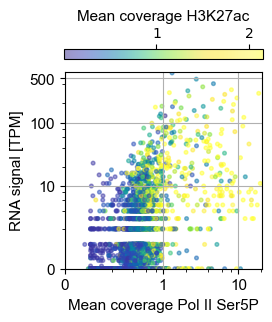

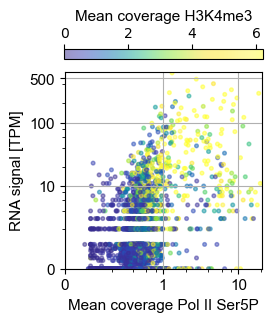

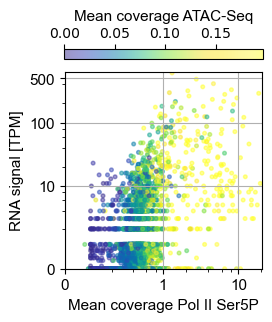

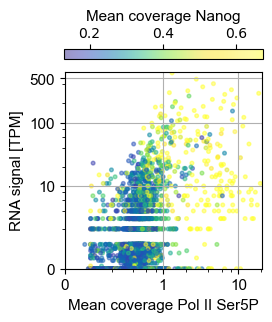

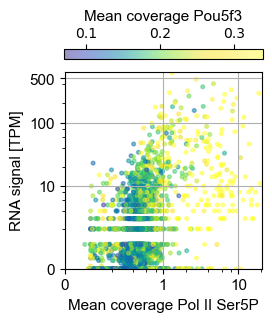

...

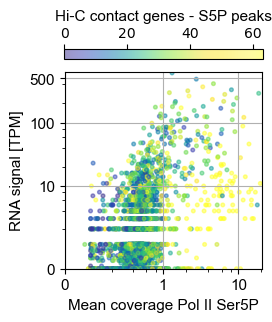

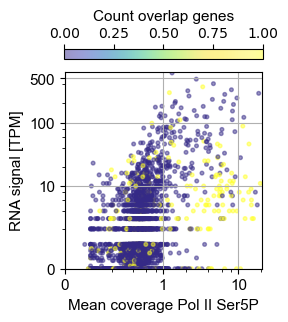

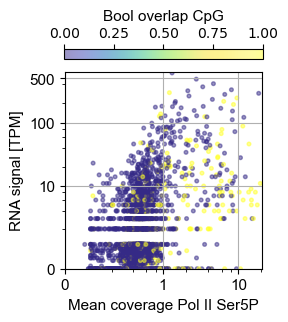

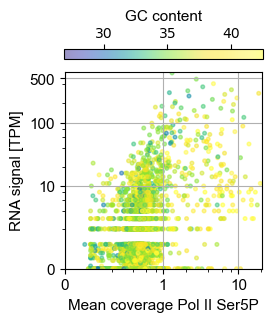

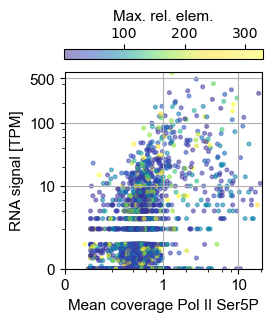

In [86]:
#Visualisation of gene features in gene map. Use scatter plot and log scales for easier visualisation.

#plot_signals_1=["H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq"]
#plot_labels=[e +" coverage" for e in plot_signals_1]


plot_signals_1=["H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq.","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]

plot_labels=["H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq.","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]
labels_signals_1=["Mean coverage H3K27ac","Mean coverage H3K4me3","Mean coverage ATAC-Seq","Mean coverage Nanog","Mean coverage Pou5f3","Mean coverage Sox19b","Mean coverage BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Hi-C contact genes - S5P peaks","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]

S5P_data=all_genes_details_expr_signals_2["S5P"].tolist()
RNA_data=all_genes_details_expr_signals_2["RNA"].tolist()
for i in range(len(plot_signals_1)):
    fig=plt.figure(figsize=(3.2,3.2))
    ax1 = fig.add_subplot(111)

    
    Signal_data=all_genes_details_expr_signals_2[plot_signals_1[i]].tolist()

    vmax1=np.percentile(Signal_data,97)
    color_scale_norm1=None #matplotlib.colors.PowerNorm(0.4)

    pl_111=ax1.scatter(S5P_data,RNA_data,s=7,c=Signal_data,vmax=vmax1,alpha=0.5,norm=color_scale_norm1,cmap=parula_cmap, rasterized=True)
    #fig.colorbar(pl_111,shrink=0.8).set_label(label=plot_labels[i],size=11,family="Arial")
    fig.colorbar(pl_111, location='top',shrink=0.8).set_label(label=labels_signals_1[i],size=11,family="Arial")

    #plt.legend(prop={'family': 'Arial','size': 11},loc=1)
    plt.ylabel("RNA signal [TPM]", size=11, fontname="Arial")
    plt.xlabel("Mean coverage Pol II Ser5P", size=11, fontname="Arial")
    ax1.grid()
    
    plt.yscale("asinh",linear_width=1,base=10) #symlog #asinh
    plt.xscale("asinh",linear_width=0.1,base=10)   #, nonposx='clip'

    y_ticks_set1=np.asarray([0,10,100,500])     #np.asarray([0,100,200,300,400,500,600])
    x_ticks_set1=np.asarray([0,1,10]) 
    
    #plt.yscale("log")
    #plt.xscale("log")
    ax1.xaxis.set_minor_locator(matplotlib.ticker.FixedLocator([0.2,0.4,0.6,0.8,2,4,6,8,20]))
    ax1.yaxis.set_minor_locator(matplotlib.ticker.FixedLocator([2,4,6,8,20,40,60,80,200,400]))
    plt.yticks(y_ticks_set1,y_ticks_set1,fontname = "Arial",fontsize=11) 
    plt.xticks(x_ticks_set1,x_ticks_set1,fontname = "Arial",fontsize=11) 

    plt.xlim(0,np.max(S5P_data)*1.05)
    plt.ylim(0,np.max(RNA_data)*1.05)

    #plt.xlim(0,5)
    #plt.ylim(0,100)

    
    ax1.set_aspect(1./ax1.get_data_ratio())
    
    
    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"log_log_scatter_" +str(labels_signals_1[i])+"_1.pdf"
    #print(name_s)

    #plt.savefig(name_s,format="pdf",bbox_inches="tight",dpi=300)
    
    
    
    
    #plt.tight_layout()

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/H3K27_class_boundaries_3_no_markers_section_A.png",format="png",dpi=300,bbox_inches="tight")

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/H3K27_class_boundaries_4_no_markers.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/H3K27_class_boundaries_2.pdf",format="pdf",bbox_inches="tight")

In [87]:
def S5P_trf(x):
    return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

def RNA_trf(x):
    return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

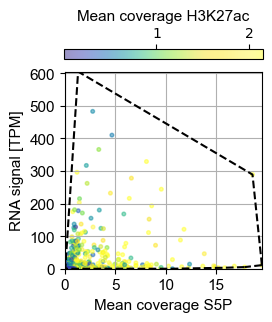

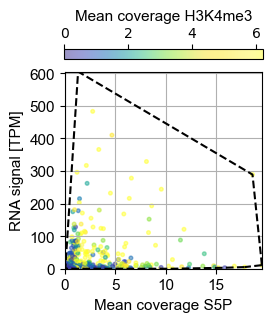

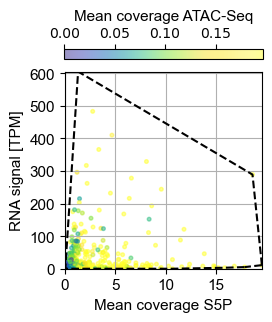

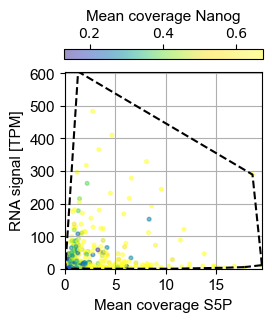

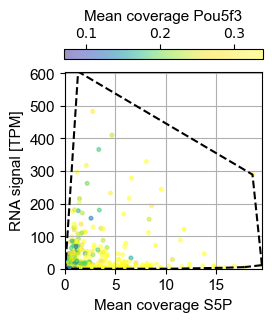

...

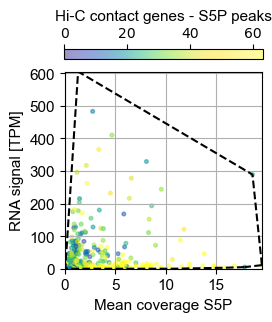

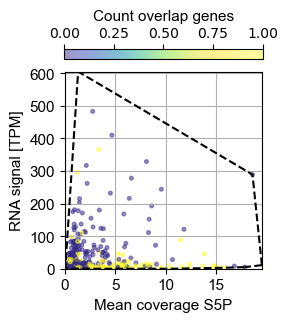

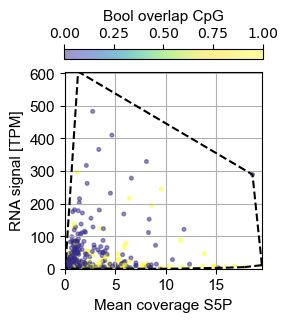

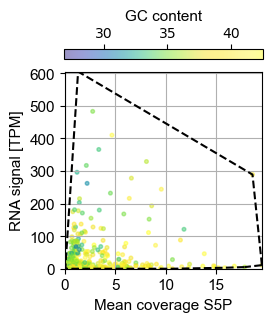

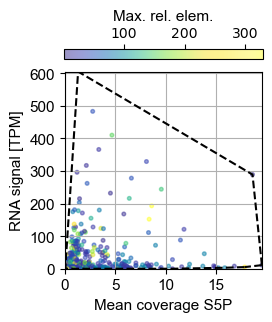

In [88]:
#Visualisation of gene features in gene map.

S5P_data=all_genes_details_expr_signals_2["S5P"].tolist()
RNA_data=all_genes_details_expr_signals_2["RNA"].tolist()


plot_signals_1=["H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq.","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]

labels_signals_1=["Mean coverage H3K27ac","Mean coverage H3K4me3","Mean coverage ATAC-Seq","Mean coverage Nanog","Mean coverage Pou5f3","Mean coverage Sox19b","Mean coverage BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Hi-C contact genes - S5P peaks","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]



for k in range(len(plot_signals_1[:])):
    
    
    
    signal_data=np.asarray(all_genes_details_expr_signals_2[plot_signals_1[k]].tolist())


    fig=plt.figure(figsize=(3.2,3.2))
    ax1 = fig.add_subplot(111)


    color_scale_norm1=None #matplotlib.colors.PowerNorm(0.8) #None
    vmax4= np.percentile(signal_data.flatten(),97)
    pl_111=ax1.scatter(S5P_data,RNA_data,s=7,c=signal_data,alpha=0.5,norm=color_scale_norm1, rasterized=True,vmax=vmax4,cmap=parula_cmap)
    #fig.colorbar(pl_111, location='top',shrink=0.8).set_label(label="Hi-C contact genes - S5P peaks",size=11,family="Arial")
    fig.colorbar(pl_111, location='top',shrink=0.8).set_label(label=labels_signals_1[k],size=11,family="Arial")
    ########################################
    ########################################
    markers_1=["o","v","^",">","<","X","s","P"]
    label_col="black" #lightsalmon
    #position of labels
    #pos_lables_genes_1={"foxd5":(160,7.5),"zgc:64022":(73,3.8),"klf2b":(45,3.5),"gadd45ga":(24,7),"vamp2":(6,4.3),"ripply1":(70,0.2),"iscub":(55,0.8),"drll.2":(40,1.4)}

    #pos_lables_genes_1={"foxd5":(160,7.5),"zgc:64022":(85,3.8),"klf2b":(45,3.5),"gadd45ga":(30,5),"vamp2":(8,6),"ripply1":(90,0.3),"iscub":(70,0.9),"drll.2":(40,1.4)}

    pos_lables_genes_1={"foxd5":(160,7.5),"zgc:64022":(135,3.8),"klf2b":(90,4.5),"gadd45ga":(60,5),"vamp2":(38,6),"ripply1":(140,0.4),"iscub":(120,1),"drll.2":(90,1.4)}

    '''for i in range(len(gene_examples_names_alt)):
        #index=names_1.index(gene_examples_names_alt[i])

        if gene_examples_names[i] in ["foxd5","zgc:64022"]:

            S5P_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["S5P"].to_numpy()[0]
            RNA_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["RNA"].to_numpy()[0]

            S5P_sel_scaled=S5P_sel
            RNA_sel_scaled=RNA_sel

            ax1.scatter(S5P_sel_scaled,RNA_sel_scaled,marker="s",fc="none",edgecolor="magenta")
            pos_lx=pos_lables_genes_1[gene_examples_names[i]][1]
            pos_ly=pos_lables_genes_1[gene_examples_names[i]][0]
            #plt.annotate(gene_examples_names[i], (Serin5P_1_scaled_1[index],RNA_1_scaled_1[index]), xytext=(Serin5P_1[index]+0.5, RNA_1[index]+0.5),arrowprops={"arrowstyle": "-"} )
            ax1.annotate(gene_examples_names[i], (S5P_sel_scaled,RNA_sel_scaled), xytext=(pos_lx, pos_ly),arrowprops={"arrowstyle": "-", "relpos":(0, 0),"color":"magenta"} , fontsize=11, fontname="Arial",color="magenta")

        else:
            S5P_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["S5P"].to_numpy()[0]
            RNA_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["RNA"].to_numpy()[0]

            S5P_sel_scaled=S5P_sel
            RNA_sel_scaled=RNA_sel

            ax1.scatter(S5P_sel_scaled,RNA_sel_scaled,marker="o",fc="none", edgecolors=label_col)
            pos_lx=pos_lables_genes_1[gene_examples_names[i]][1]
            pos_ly=pos_lables_genes_1[gene_examples_names[i]][0]
            #plt.annotate(gene_examples_names[i], (Serin5P_1_scaled_1[index],RNA_1_scaled_1[index]), xytext=(Serin5P_1[index]+0.5, RNA_1[index]+0.5),arrowprops={"arrowstyle": "-"} )
            ax1.annotate(gene_examples_names[i], (S5P_sel_scaled,RNA_sel_scaled), xytext=(pos_lx, pos_ly),arrowprops={"arrowstyle": "-", "relpos":(0, 0),"color":label_col} , fontsize=11, fontname="Arial",color=label_col)

'''

    #generate convex hull
    data_points_S5P_RNA=np.column_stack((S5P_data,RNA_data)) 
    hull_t=scipy.spatial.ConvexHull(data_points_S5P_RNA)
    ax1.errorbar(data_points_S5P_RNA[hull_t.vertices,0], data_points_S5P_RNA[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([data_points_S5P_RNA[hull_t.vertices,0][0] ,data_points_S5P_RNA[hull_t.vertices,0][-1]], [data_points_S5P_RNA[hull_t.vertices,1][0],data_points_S5P_RNA[hull_t.vertices,1][-1] ],color="black", fmt='--')

    
    #plt.legend(prop={'family': 'Arial','size': 11},loc=1)
    plt.ylabel("RNA signal [TPM]", size=11, fontname="Arial")
    plt.xlabel("Mean coverage S5P", size=11, fontname="Arial")
    ax1.grid()

    #plt.yscale("asinh",linear_width=1,base=10) #symlog #asinh
    #plt.xscale("asinh",linear_width=0.1,base=10)   #, nonposx='clip'

    y_ticks_set1=np.asarray([0,100,200,300,400,500,600])
    x_ticks_set1=np.asarray([0,5,10,15]) 

    #plt.yscale("log")
    #plt.xscale("log")
    #ax1.xaxis.set_minor_locator(matplotlib.ticker.FixedLocator([0.2,0.4,0.6,0.8,2,4,6,8,20]))
    #ax1.yaxis.set_minor_locator(matplotlib.ticker.FixedLocator([2,4,6,8,20,40,60,80,200,400]))
    plt.yticks(y_ticks_set1,y_ticks_set1,fontname = "Arial",fontsize=11) 
    plt.xticks(x_ticks_set1,x_ticks_set1,fontname = "Arial",fontsize=11) 

    plt.xlim(-0,np.max(S5P_data)*1.0)
    plt.ylim(-0,np.max(RNA_data)*1.0)

    #plt.xlim(0,10)
    #plt.ylim(0,200)


    ax1.set_aspect(1./ax1.get_data_ratio())

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"full_scatter_" +str(labels_signals_1[k])+"_1.pdf"
    #name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"zoom_annotation_scatter_" +str(labels_signals_1[k])+"_1.pdf"
    #plt.savefig(name_s,format="pdf",bbox_inches="tight",dpi=300)
    plt.show()


# Visualization 2

Generate locally averaged, continuous heatmaps to visualize patterns in genome wide data

In [89]:
#generate a locally average, distance weighted heatmap for data
def local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors): 

    #rescale entire data 

    #scaler_1_Serin5P=MinMaxScaler()
    scaler_1_Serin5P=StandardScaler()
    scaler_1_Serin5P.fit(S5P_data.reshape(-1, 1))
    Serin5P_1_scaled_1=scaler_1_Serin5P.transform(S5P_data.reshape(-1, 1)).flatten()

    #scaler_1_RNA=MinMaxScaler()
    scaler_1_RNA=StandardScaler()
    scaler_1_RNA.fit(RNA_data.reshape(-1, 1))
    RNA_1_scaled_1=scaler_1_RNA.transform(RNA_data.reshape(-1, 1)).flatten()


    #get non zero data points

    Serin5P_1_drop=[]
    RNA_1_drop=[]
    Signal_data_drop=[]


    for i in range(len(S5P_data)):
        if drop_zeros==True:
            if Signal_data[i]!=0:
            #if gene_SE_contact_freq_all_4hpf[i]>= np.percentile(gene_SE_contact_freq_all_4hpf,50):
                Serin5P_1_drop.append(S5P_data[i])
                RNA_1_drop.append(RNA_data[i])
                Signal_data_drop.append(Signal_data[i])
        else:
            Serin5P_1_drop.append(S5P_data[i])
            RNA_1_drop.append(RNA_data[i])
            Signal_data_drop.append(Signal_data[i])
            
            
    Serin5P_1_drop=np.asarray(Serin5P_1_drop)
    RNA_1_drop=np.asarray(RNA_1_drop)
    


    #define input data (could be with or without dropping zero entries)
    Serin5P_input_1=Serin5P_1_drop
    RNA_input_1=RNA_1_drop
    Signal_data_input_1=np.asarray(Signal_data_drop)
    
    #Signal input might contain Nans:
    Serin5P_input_1=Serin5P_input_1[~np.isnan(Signal_data_input_1)]
    RNA_input_1=RNA_input_1[~np.isnan(Signal_data_input_1)]
    Signal_data_input_1=Signal_data_input_1[~np.isnan(Signal_data_input_1)]

    print("Percentage of data used:",len(Serin5P_input_1)/len(S5P_data) *100)
    #rescale input data with scaler previously applied to all data

    Serin5P_input_1_scaled=scaler_1_Serin5P.transform(Serin5P_input_1.reshape(-1, 1)).flatten()
    RNA_input_1_scaled=scaler_1_RNA.transform(RNA_input_1.reshape(-1, 1)).flatten()


    #set up grid over entire range of original data

    max_Serin5P_v=np.max(Serin5P_1_scaled_1)#*1.1   #np.max(Serin5P_1_scaled_1) 
    max_RNA_v=np.max(RNA_1_scaled_1)#*1.1 #np.max(RNA_1_scaled_1) 

    min_Serin5P_v=np.min(Serin5P_1_scaled_1) #- abs(np.min(Serin5P_1_scaled_1)*0.1)#.01
    min_RNA_v=np.min(RNA_1_scaled_1) #- abs(np.min(RNA_1_scaled_1)*0.1)#0#.01


    print("max, min RNA",max_RNA_v,min_RNA_v)
    print("max, min Serin5P",max_Serin5P_v,min_Serin5P_v)
    print("mean Signal:", np.mean(Signal_data_input_1))

    x_spacing=np.linspace(min_Serin5P_v, max_Serin5P_v, 50)  #50x50 *75 neigh
    y_spacing=np.linspace(min_RNA_v, max_RNA_v, 50)

    pred_data_x_y=[] #grid points for which to make neighbours regression fit in heatmap
    for i in range(len(x_spacing)):
        for j in range(len(y_spacing)):
            pred_data_x_y.append([x_spacing[i],y_spacing[j]])
    pred_data_x_y=np.asarray(pred_data_x_y)

    grid_x, grid_y = np.meshgrid(x_spacing, y_spacing, indexing='ij')

    fit_data_x_y=[] #grid points at which data is known (scatter data)
    for i in range(len(Serin5P_input_1_scaled)):
        fit_data_x_y.append([Serin5P_input_1_scaled[i],RNA_input_1_scaled[i]])

    all_data_x_y=[] #all points at which data is known (scatter data)
    for i in range(len(Serin5P_1_scaled_1)):
        all_data_x_y.append([Serin5P_1_scaled_1[i],RNA_1_scaled_1[i]])

    all_data_x_y=np.asarray(all_data_x_y)    
    fit_data_x_y=np.asarray(fit_data_x_y)

    KNR_model = KNeighborsRegressor(algorithm='kd_tree', n_neighbors=n_neighbors, weights='distance').fit(fit_data_x_y,Signal_data_input_1)
    KNR_model_pred=KNR_model.predict(pred_data_x_y)
    KNR_model_pred_r=KNR_model_pred.reshape(len(x_spacing),len(y_spacing))



    '''def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()'''
    
    return all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.5492915163625306


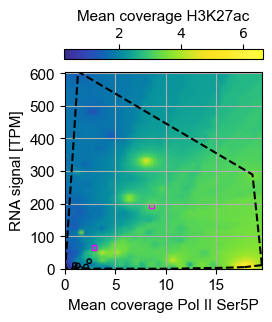

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 1.0714199451254436


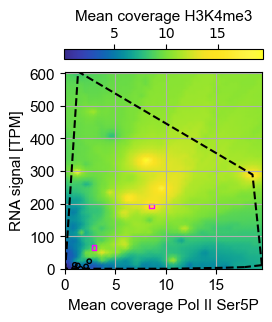

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.07243572562384143


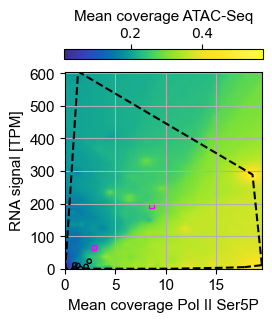

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.2888153870447734


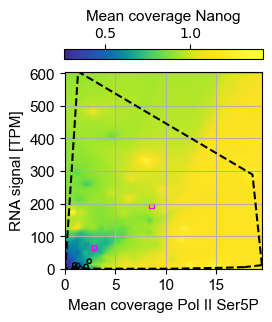

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.1722593486940508


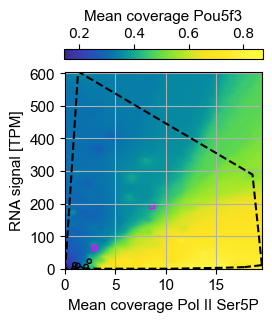

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.08278350054607256


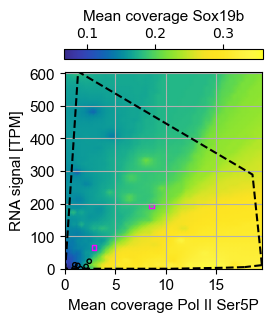

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.8089832312848914


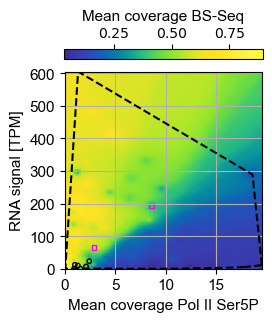

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 27.19883106665168


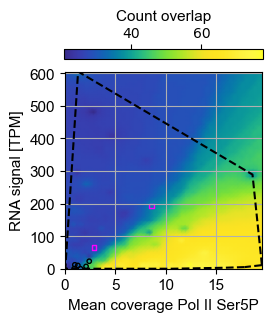

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: -2368746.252849206


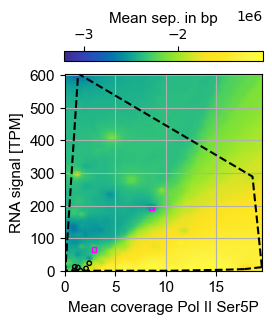

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: -242831.2231089131


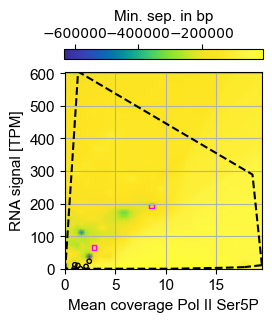

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 26.58151674542827


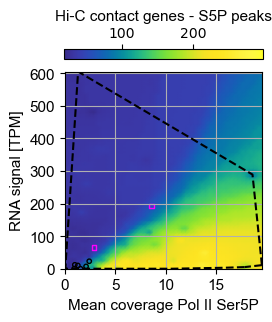

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.1336405529953917


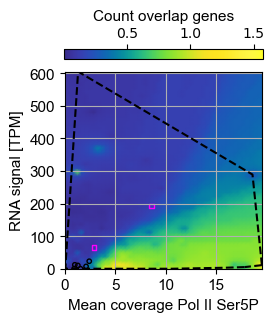

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 0.1254355400696864


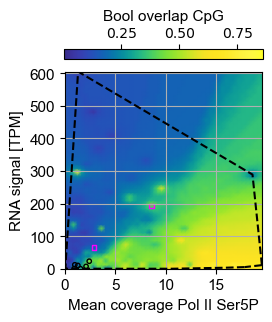

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 36.58890949836596


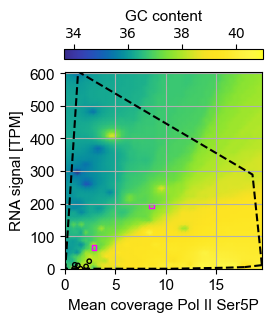

Percentage of data used: 100.0
max, min RNA 35.944120601987876 -0.15266083395153962
max, min Serin5P 21.523254272599356 -0.5520705733135913
mean Signal: 78.71170057322693


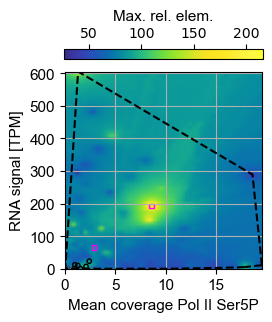

In [90]:

plot_signals_1=["H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq.","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]

labels_signals_1=["Mean coverage H3K27ac","Mean coverage H3K4me3","Mean coverage ATAC-Seq","Mean coverage Nanog","Mean coverage Pou5f3","Mean coverage Sox19b","Mean coverage BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Hi-C contact genes - S5P peaks","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]

#colorbar for locally averaged plot
#use 95 for viridis
#use False for parula_cmap
colorbar_cutoff_1=[False for i in plot_signals_1] #[95,95,95,95,False,False,False,False,95,False,False,False,95]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[97,97,97,97,97,97,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=np.asarray(all_genes_details_expr_signals_2["S5P"].tolist())
RNA_data=np.asarray(all_genes_details_expr_signals_2["RNA"].tolist())

#store heatmap plot data for later use
name_list=[]
all_data_x_y_list=[]
fit_data_x_y_list=[]
grid_x_list=[]
grid_y_list=[]
KNR_model_pred_r_list=[]
RNA_1_scaled_1_list=[]
Serin5P_1_scaled_1_list=[]
scaler_1_Serin5P_list=[]
scaler_1_RNA_list=[]

for k in range(len(plot_signals_1[:])):
    
    
    
    Signal_data=np.asarray(all_genes_details_expr_signals_2[plot_signals_1[k]].tolist())
    drop_zeros=drop_zeros_1[k]
    n_neighbors=75
    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff_1[k]!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff_1[k])
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_1[k]!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale_1[k])
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1, rasterized=True,cmap=parula_cmap)




    '''ser5P_xaxis2=np.arange(0,21)
    sep_line_2=gen_line(x1=ep_2[0][0],y1=ep_2[0][1],x2=ep_2[1][0],y2=ep_2[1][1],x_arr=ser5P_xaxis2)
    sep_line_2=scaler_1_RNA.transform(sep_line_2.reshape(-1,1)).flatten()
    ser5P_xaxis2=scaler_1_Serin5P.transform(ser5P_xaxis2.reshape(-1,1)).flatten()
    ax1.errorbar(ser5P_xaxis2,sep_line_2,color="black",fmt="--")


    ser5P_xaxis4=np.arange(0,4)
    sep_line_4=gen_line(x1=ep_4[0][0],y1=ep_4[0][1],x2=ep_4[1][0],y2=ep_4[1][1],x_arr=ser5P_xaxis4)

    sep_line_4=scaler_1_RNA.transform(sep_line_4.reshape(-1,1)).flatten()
    ser5P_xaxis4=scaler_1_Serin5P.transform(ser5P_xaxis4.reshape(-1,1)).flatten()

    #ax1.errorbar(ser5P_xaxis4,sep_line_4,color="black",label="Class boundary",fmt="--")
    ax1.errorbar(ser5P_xaxis4,sep_line_4,color="black",fmt="--")'''

    #fig.colorbar(sc_222,shrink=0.8).set_label(label='Mean contact frequency between \ngenes and super-enhancers',size=11,family="Arial")


    ########################################
    ########################################
    markers_1=["o","v","^",">","<","X","s","P"]
    label_col="black" #lightsalmon
    #position of labels 
    
    #original, not scaled
    #pos_lables_genes_1={"foxd5":(160,7.5),"zgc:64022":(73,3.8),"klf2b":(45,3.5),"gadd45ga":(24,7),"vamp2":(6,4.3),"ripply1":(70,0.2),"iscub":(55,0.8),"drll.2":(40,1.4)}
    
    #for log plot
    #pos_lables_genes_1={"foxd5":(RNA_trf(300),S5P_trf(7.5)),"zgc:64022":(RNA_trf(100),S5P_trf(4.3)),"klf2b":(RNA_trf(45),S5P_trf(4.3)),"gadd45ga":(RNA_trf(21),S5P_trf(4.3)),"vamp2":(RNA_trf(6),S5P_trf(4.3)),"ripply1":(RNA_trf(80),S5P_trf(0.2)),"iscub":(RNA_trf(55),S5P_trf(0.8)),"drll.2":(RNA_trf(40),S5P_trf(1.4))}
    
    #original, scaled
    #pos_lables_genes_1={"foxd5":(RNA_trf(160),S5P_trf(7.5)),"zgc:64022":(RNA_trf(73),S5P_trf(3.8)),"klf2b":(RNA_trf(45),S5P_trf(3.5)),"gadd45ga":(RNA_trf(24),S5P_trf(7)),"vamp2":(RNA_trf(6),S5P_trf(4.3)),"ripply1":(RNA_trf(70),S5P_trf(0.2)),"iscub":(RNA_trf(55),S5P_trf(0.8)),"drll.2":(RNA_trf(40),S5P_trf(1.4))}

    #new version, scaled
    pos_lables_genes_1={"foxd5":(RNA_trf(250),S5P_trf(10)),"zgc:64022":(RNA_trf(140),S5P_trf(7.5)),"klf2b":(RNA_trf(90),S5P_trf(7.5)),"gadd45ga":(RNA_trf(70),S5P_trf(12)),"vamp2":(RNA_trf(20),S5P_trf(12)),"ripply1":(RNA_trf(300),S5P_trf(2.2)),"iscub":(RNA_trf(250),S5P_trf(2.8)),"drll.2":(RNA_trf(200),S5P_trf(3.4))}
    
    #zoomed in
    #pos_lables_genes_1={"foxd5":(RNA_trf(160),S5P_trf(7.5)),"zgc:64022":(RNA_trf(73),S5P_trf(3.8)),"klf2b":(RNA_trf(45),S5P_trf(3.5)),"gadd45ga":(RNA_trf(26),S5P_trf(6)),"vamp2":(RNA_trf(6.5),S5P_trf(4.3)),"ripply1":(RNA_trf(70),S5P_trf(0.2)),"iscub":(RNA_trf(55),S5P_trf(0.8)),"drll.2":(RNA_trf(40),S5P_trf(1.4))}

    #only foxd5 and ripply1
    #pos_lables_genes_1={"foxd5":(RNA_trf(250),S5P_trf(10)),"ripply1":(RNA_trf(250),S5P_trf(2.2))}
   
    genes_to_show=["foxd5","zgc:64022","klf2b","gadd45ga","vamp2","ripply1","iscub","drll.2"]
    
    #genes_to_show=["foxd5","ripply1"]
    #genes_to_show=[None]
    size_marker_1=10 #None
    
    for i in range(len(gene_examples_names_alt)):
        #index=names_1.index(gene_examples_names_alt[i])
        if gene_examples_names[i] in genes_to_show:

            if gene_examples_names[i] in ["foxd5","zgc:64022"]:

                S5P_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["S5P"].to_numpy()[0]
                RNA_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["RNA"].to_numpy()[0]

                S5P_sel_scaled=scaler_1_Serin5P.transform(np.array(S5P_sel).reshape(-1,1)).flatten()
                RNA_sel_scaled=scaler_1_RNA.transform(np.array(RNA_sel).reshape(-1,1)).flatten()

                #ax1.scatter(S5P_sel_scaled,RNA_sel_scaled,marker="o",fc=label_col,edgecolor=label_col,s=size_marker_1)
                ax1.scatter(S5P_sel_scaled,RNA_sel_scaled,marker="s",fc="none",edgecolor="magenta",s=size_marker_1)
                pos_lx=pos_lables_genes_1[gene_examples_names[i]][1]
                pos_ly=pos_lables_genes_1[gene_examples_names[i]][0]
                #plt.annotate(gene_examples_names[i], (Serin5P_1_scaled_1[index],RNA_1_scaled_1[index]), xytext=(Serin5P_1[index]+0.5, RNA_1[index]+0.5),arrowprops={"arrowstyle": "-"} )
                #ax1.annotate(gene_examples_names[i], (S5P_sel_scaled,RNA_sel_scaled), xytext=(pos_lx, pos_ly),arrowprops={"arrowstyle": "-", "relpos":(0, 0),"color":label_col} , fontsize=11, fontname="Arial",color=label_col)

            else:
                S5P_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["S5P"].to_numpy()[0]
                RNA_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"]==gene_examples_names[i]]["RNA"].to_numpy()[0]

                S5P_sel_scaled=scaler_1_Serin5P.transform(np.array(S5P_sel).reshape(-1,1)).flatten()
                RNA_sel_scaled=scaler_1_RNA.transform(np.array(RNA_sel).reshape(-1,1)).flatten()

                ax1.scatter(S5P_sel_scaled,RNA_sel_scaled,marker="o",fc="none", edgecolors=label_col,s=size_marker_1)
                pos_lx=pos_lables_genes_1[gene_examples_names[i]][1]
                pos_ly=pos_lables_genes_1[gene_examples_names[i]][0]
                #plt.annotate(gene_examples_names[i], (Serin5P_1_scaled_1[index],RNA_1_scaled_1[index]), xytext=(Serin5P_1[index]+0.5, RNA_1[index]+0.5),arrowprops={"arrowstyle": "-"} )
                #ax1.annotate(gene_examples_names[i], (S5P_sel_scaled,RNA_sel_scaled), xytext=(pos_lx, pos_ly),arrowprops={"arrowstyle": "-", "relpos":(0, 0),"color":label_col} , fontsize=11, fontname="Arial",color=label_col)

        #print(gene_examples_names[i],Serin5P_1[index],RNA_1[index])  
    
    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2[k]!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2[k])
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2[k]!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2[k])
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=labels_signals_1[k],size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("RNA signal [TPM]", size=11, fontname="Arial")
    plt.xlabel("Mean coverage Pol II Ser5P", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())
    
    #plt.yscale("asinh",linear_width=0.5,base=10) #symlog #asinh
    #plt.xscale("asinh",linear_width=1,base=10)   #, nonposx='clip'

    y_ticks_set1=np.asarray([0,100,200,300,400,500,600]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,5,10,15,20])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
    
    #y_ticks_minor_trf=scaler_1_RNA.transform(np.asarray([2,4,6,8,20,40,60,80,200,400]).reshape(-1,1)).flatten()
    #x_ticks_minor_trf=scaler_1_Serin5P.transform(np.asarray([0.2,0.4,0.6,0.8,2,4,6,8,20]).reshape(-1,1)).flatten()
    
    #ax1.yaxis.set_minor_locator(matplotlib.ticker.FixedLocator(y_ticks_minor_trf))
    #ax1.xaxis.set_minor_locator(matplotlib.ticker.FixedLocator(x_ticks_minor_trf))
        
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    plt.xlim(np.min(x_ticks_set1_trf),up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)



    #x_ticks1=[0.1,1,10]
    #y_ticks1=[0,1,10,100]
    #plt.yticks(y_ticks1,y_ticks1,fontname = "Arial",fontsize=11) 
    #plt.xticks(x_ticks1,x_ticks1,fontname = "Arial",fontsize=11)
    

    ax1.set_aspect(1./ax1.get_data_ratio())
    
    #append heat map data
    name_list.append(labels_signals_1[k])
    all_data_x_y_list.append(all_data_x_y)
    fit_data_x_y_list.append(fit_data_x_y)
    grid_x_list.append(grid_x)
    grid_y_list.append(grid_y)
    KNR_model_pred_r_list.append(KNR_model_pred_r)
    RNA_1_scaled_1_list.append(RNA_1_scaled_1)
    Serin5P_1_scaled_1_list.append(Serin5P_1_scaled_1)
    scaler_1_Serin5P_list.append(scaler_1_Serin5P)
    scaler_1_RNA_list.append(scaler_1_RNA)
    

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"2d_plot_" +str(labels_signals_1[k])+"_rose_4.pdf"
    #print(name_s)

    #if k==10:
    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=1000,bbox_inches="tight")
    #plt.savefig(name_s,format="pdf",bbox_inches="tight",dpi=300)
    plt.show()
    
#add heatmap data to dict and then convert to df
S5P_RNA_heatmap_dict={"name":name_list,
                     "all_data_x_y":all_data_x_y_list,
                     "fit_data_x_y":fit_data_x_y_list,
                     "grid_x":grid_x_list,
                     "grid_y":grid_y_list,
                     "KNR_model_pred_r":KNR_model_pred_r_list,
                     "RNA_1_scaled_1":RNA_1_scaled_1_list,
                     "Serin5P_1_scaled_1":Serin5P_1_scaled_1_list,
                     "scaler_1_Serin5P":scaler_1_Serin5P_list,
                     "scaler_1_RNA":scaler_1_RNA_list}

S5P_RNA_heatmap_df=pd.DataFrame(S5P_RNA_heatmap_dict)

# Visualization 3

Plot signals for selected genes and selected groups of genes in regions of the gene map

In [91]:
#visitor active, similar position as foxd5:
subset_2D_plot_genes=all_genes_details_expr_signals_2[(all_genes_details_expr_signals_2['RNA'] >= 100) & (all_genes_details_expr_signals_2['RNA'] <= 300) &
                 (all_genes_details_expr_signals_2['S5P'] >= 5) & (all_genes_details_expr_signals_2['S5P'] <= 50)]

#non visitor active:

'''subset_2D_plot_genes=all_genes_details_expr_signals_2[(all_genes_details_expr_signals_2['RNA'] >= 100) & (all_genes_details_expr_signals_2['RNA'] <= 700) &
                 (all_genes_details_expr_signals_2['S5P'] >= 0) & (all_genes_details_expr_signals_2['S5P'] <= 5)]'''


subset_2D_plot_genes

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
39,ENSDARG00000041959,cxcr4b,9,10692955,10694930,plus,1975,10693942,10691955,10693055,168.0,5.846096,0.830623,1.02258,23.209009,0.30888,1.242256,0.407888,0.169019,0.633261,9,-2.433295e+06,-981316,9.820638,0,0,34.778538,7.0
79,ENSDARG00000010770,sox19a,5,24199180,24201444,minus,2264,24200312,24201344,24202444,244.0,9.560844,3.663024,2.990977,25.784733,0.369202,1.319786,0.411586,0.237418,0.136319,35,-1.676517e+06,-431,34.745861,0,1,40.700926,137.0
184,ENSDARG00000040764,id1,11,18704189,18705297,minus,1108,18704743,18705197,18706297,289.0,18.591469,4.040876,3.276851,25.276876,0.789819,1.590291,0.416075,0.242587,0.006,24,-2.047648e+06,-17533,24.601683,0,0,37.944096,2.0
437,ENSDARG00000002172,aplnra,8,40325911,40327397,minus,1486,40326654,40327297,40328397,111.0,8.292789,2.244242,3.503031,12.753232,0.373431,0.672226,0.417928,0.231655,0.020161,17,-1.869424e+06,-283,31.317553,0,0,43.218434,55.0
516,ENSDARG00000099761,vox,13,50621929,50624154,minus,2225,50623041,50624054,50625154,121.0,11.808494,2.356433,1.181947,20.348906,0.514135,1.833446,0.461566,0.170935,0.017658,18,-2.797787e+06,-7904,50.304115,0,0,33.43463,21.0
849,ENSDARG00000013576,gadd45bb,2,36939941,36941988,plus,2047,36940964,36938941,36940041,278.0,6.597927,1.608021,1.098894,7.932298,0.293821,1.316117,0.549385,0.249848,0.21851,29,-1.544482e+06,-561,41.762004,0,0,37.009204,46.0
1044,ENSDARG00000043128,cldne,15,2638884,2640821,minus,1937,2639852,2640721,2641821,152.0,8.355683,1.515367,1.967685,3.301593,0.076785,0.264231,0.241025,0.134015,0.963788,25,-2.262700e+06,-11246,37.830211,0,0,34.989126,410.0
1559,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,8.604894,4.510638,1.739001,27.787728,0.341548,0.905266,0.301296,0.157048,0.0,48,-3.586473e+06,-601221,25.402555,0,1,37.098308,605.0
4501,ENSDARG00000009881,ier5,22,16497670,16499153,plus,1483,16498411,16496670,16497770,216.0,6.388989,9.344498,2.615458,34.143202,0.533259,1.620509,0.577941,0.291121,0.124626,34,-2.299874e+06,-454,40.908324,0,1,40.204852,124.0


In [92]:
#option to filter genes with low expression at Prim5
subset_2D_plot_genes=subset_2D_plot_genes[subset_2D_plot_genes["Name"].isin(all_genes_expr[all_genes_expr["pharyngula prim-5"]<50]["Gene Name"].to_list())]

subset_2D_plot_genes

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
39,ENSDARG00000041959,cxcr4b,9,10692955,10694930,plus,1975,10693942,10691955,10693055,168.0,5.846096,0.830623,1.02258,23.209009,0.30888,1.242256,0.407888,0.169019,0.633261,9,-2.433295e+06,-981316,9.820638,0,0,34.778538,7.0
437,ENSDARG00000002172,aplnra,8,40325911,40327397,minus,1486,40326654,40327297,40328397,111.0,8.292789,2.244242,3.503031,12.753232,0.373431,0.672226,0.417928,0.231655,0.020161,17,-1.869424e+06,-283,31.317553,0,0,43.218434,55.0
516,ENSDARG00000099761,vox,13,50621929,50624154,minus,2225,50623041,50624054,50625154,121.0,11.808494,2.356433,1.181947,20.348906,0.514135,1.833446,0.461566,0.170935,0.017658,18,-2.797787e+06,-7904,50.304115,0,0,33.43463,21.0
849,ENSDARG00000013576,gadd45bb,2,36939941,36941988,plus,2047,36940964,36938941,36940041,278.0,6.597927,1.608021,1.098894,7.932298,0.293821,1.316117,0.549385,0.249848,0.21851,29,-1.544482e+06,-561,41.762004,0,0,37.009204,46.0
1559,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,8.604894,4.510638,1.739001,27.787728,0.341548,0.905266,0.301296,0.157048,0.0,48,-3.586473e+06,-601221,25.402555,0,1,37.098308,605.0


In [93]:
#select genes and features to plot by name

#gene_examples_names_2=["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]
#gene_examples_names_2=["foxd5","zgc:64022","ripply1"]
gene_examples_names_2=["foxd5","ripply1"]
#gene_examples_names_2=subset_2D_plot_genes["Name"].tolist()
#gene_examples_names_2=["si:ch211-113a14.6"]


plot_signals_2=["S5P","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq"]
#plot_signals_2=["S5P","H3K27ac"]

bw_signal_list=[bw_Serin5P_4_3_hpf, bw_H3K27ac_4_3_hpf,bw_H3K4me3_hpf,bw_ATAC_4_3_hpf,bw_nanog_4_hpf,bw_BS_seq_4_hpf]
#bw_signal_list=[bw_Serin5P_4_3_hpf, bw_H3K27ac_4_3_hpf]


labels_signals_2=["S5P","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq"]
#labels_signals_2=["S5P","H3K27ac"]

subset_gene_details_1=all_genes_details_expr_4[all_genes_details_expr_4["Name"].isin(gene_examples_names_2)]
subset_gene_details_1.reset_index(inplace=True,drop=True)
subset_gene_details_1

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA
0,ENSDARG00000054103,ripply1,21,37967457,37972497,minus,5040,37969977,37972397,37973497,0.4
1,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0


In [94]:
# get ChIP-Seq profiles of individual genes


#add signal tracks
subset_gene_details_expr_signals_1=subset_gene_details_1
interval_sel=6000   #4000
for i in range(len(bw_signal_list)):

    df_signal=get_coverage_for_genes_V1(df_genes=subset_gene_details_1,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Middle",Stop_col="Middle",Orientation_col="Orientation",Signal_col=labels_signals_2[i],expected_dim=100,add_interval=interval_sel,big_wig_file_name=bw_signal_list[i],chr_add="chr",signal_type="mean")


    subset_gene_details_expr_signals_1=pd.concat([subset_gene_details_expr_signals_1,df_signal[labels_signals_2[i]]], axis=1)
#add signal start stop entry
subset_gene_details_expr_signals_1=pd.concat([subset_gene_details_expr_signals_1,df_signal[["Signal start","Signal stop"]]], axis=1)


ENSDARG00000054103 ripply1 chr21 37963977 37975977 mean 100
0 / 1
ENSDARG00000042485 foxd5 chr8 30447520 30459520 mean 100
1 / 1
ENSDARG00000054103 ripply1 chr21 37963977 37975977 mean 100
0 / 1
ENSDARG00000042485 foxd5 chr8 30447520 30459520 mean 100
1 / 1
ENSDARG00000054103 ripply1 chr21 37963977 37975977 mean 100
0 / 1
ENSDARG00000042485 foxd5 chr8 30447520 30459520 mean 100
1 / 1
ENSDARG00000054103 ripply1 chr21 37963977 37975977 mean 100
0 / 1
ENSDARG00000042485 foxd5 chr8 30447520 30459520 mean 100
1 / 1
ENSDARG00000054103 ripply1 chr21 37963977 37975977 mean 100
0 / 1
ENSDARG00000042485 foxd5 chr8 30447520 30459520 mean 100
1 / 1
ENSDARG00000054103 ripply1 chr21 37963977 37975977 mean 100
0 / 1
ENSDARG00000042485 foxd5 chr8 30447520 30459520 mean 100
1 / 1


In [95]:
subset_gene_details_expr_signals_1

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K4me3,ATAC-Seq,Nanog,BS-Seq,Signal start,Signal stop
0,ENSDARG00000054103,ripply1,21,37967457,37972497,minus,5040,37969977,37972397,37973497,0.4,"[0.19661249748120704, 0.6125699877738953, 0.10...","[0.0964599996805191, 0.0964599996805191, 0.096...","[0.04508283397493263, 0.041359833891813955, 0....","[0.05733799984057744, 0.05954183309028546, 0.0...","[0.17762769758701324, 0.13057400286197662, 0.1...","[1.0, 0.9733333190282186, 1.0, 0.9299999872843...",37963977,37975977
1,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,"[0.18016116917133332, 0.07049033194780349, 0.0...","[0.0, 0.0, 2.499999936844688e-06, 0.0038267499...","[0.18060091324150562, 0.07090333330755433, 0.0...","[0.0, 0.01033750013448298, 0.02549916659481823...","[0.23592348244379868, 0.2413287374324032, 0, 0...","[0, 0, 0, 0, 0, 0, 0, 1.0, 0, 0, 0, 0, 1.0, 1....",30447520,30459520


In [96]:
max_value = max([item for sublist in subset_gene_details_expr_signals_1['S5P'] for item in sublist])
print(max_value)

33.88367206255595


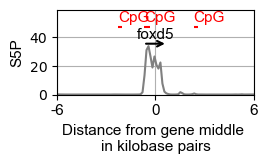

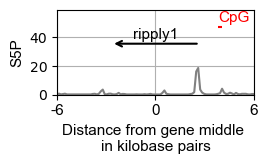

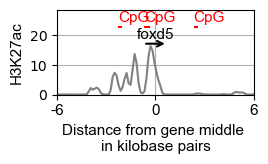

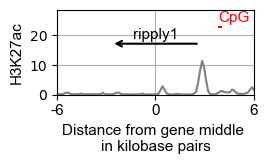

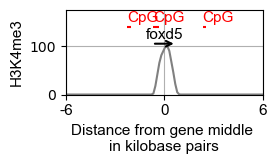

...

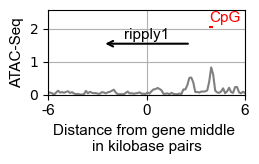

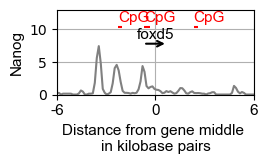

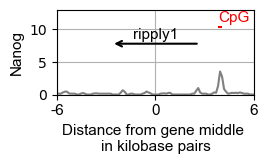

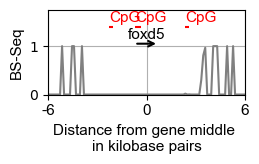

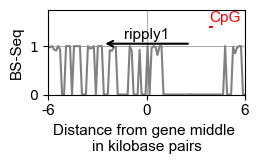

In [104]:
#visualisation with gene annotation and other features

for i in range(len(plot_signals_2)):
    #get max signal value to set y range
    max_signal_v = max([item for sublist in subset_gene_details_expr_signals_1[plot_signals_2[i]] for item in sublist])
    max_signal_v_s=max_signal_v*1.75  #1.4 -> if no CpG plottet
    #make plot for subset of genes that were selected
    for j in range(len(gene_examples_names_2)):
        fig=plt.figure(figsize=(2.54,1.1))
        ax2 = fig.add_subplot(111)
        
        signal_track_df_1=subset_gene_details_expr_signals_1[subset_gene_details_expr_signals_1["Name"]==gene_examples_names_2[j]]
        signal_track_1=signal_track_df_1[plot_signals_2[i]].tolist()[0]
        signal_track_start_1=signal_track_df_1["Signal start"].to_numpy()[0]
        signal_track_stop_1=signal_track_df_1["Signal stop"].to_numpy()[0]
        signal_track_middle_1=signal_track_df_1["Middle"].to_numpy()[0]
        signal_track_orientation_1=signal_track_df_1["Orientation"].values[0]#[0]
        signal_track_x_1=np.linspace(signal_track_start_1,signal_track_stop_1,len(signal_track_1))
        
        signal_track_annotation=[signal_track_middle_1-interval_sel,signal_track_middle_1,signal_track_middle_1+interval_sel]
        signal_track_annotation_l=[-int(interval_sel/1000),0,int(interval_sel/1000)]
        #ax2.errorbar(signal_track_x_1,signal_track_1,label=gene_examples_names_2[j],color="grey")
        ax2.errorbar(signal_track_x_1,signal_track_1,color="grey")

        
        gene_start=signal_track_df_1["Start"].to_numpy()[0]
        gene_stop=signal_track_df_1["Stop"].to_numpy()[0]
        #print(gene_start,gene_stop,max_signal_v, max_signal_v*1.15)
        gene_len=gene_stop-gene_start
        #ax2.hlines(40,gene_start,gene_stop,color="black")
        
        if signal_track_orientation_1=="plus":
            dir_arr="->"
        else:
            dir_arr="<-"
        
        ax2.annotate("", xy=(gene_start+gene_len, max_signal_v*1.05), xytext=(gene_start, max_signal_v*1.05),arrowprops=dict(arrowstyle=dir_arr, lw=1.5, shrinkA=0, shrinkB=0))
        #ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(gene_start, max_signal_v*1.15),fontsize=11,fontname = "Arial")
        ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(signal_track_middle_1, max_signal_v*1.15),fontsize=11,fontname = "Arial", ha='center')
        
        #plot CpG islands
        Gene_CpG_overlap_2_sel=Gene_CpG_overlap_2[Gene_CpG_overlap_2["Name"]==gene_examples_names_2[j]]["Names overlap"].tolist()[0]
        for m in range(len(Gene_CpG_overlap_2_sel)):
            
            name_CpG=Gene_CpG_overlap_2_sel[m]
                
            df_sub_set_CpG=CpG_read_in_1[CpG_read_in_1["NAME"]==name_CpG]

            start_CpG_1=df_sub_set_CpG["START"].to_numpy()[0]
            end_CpG_1=df_sub_set_CpG["STOP"].to_numpy()[0]
            len_CpG_1=end_CpG_1-start_CpG_1
            middle_CpG_1=df_sub_set_CpG["MIDDLE"].to_numpy()[0]
            
            #print(start_CpG_1)
            ax2.hlines(max_signal_v*1.4,start_CpG_1,end_CpG_1,color="red")   
            ax2.annotate("CpG",xy=(start_CpG_1+len_CpG_1, max_signal_v*1.5),xytext=(start_CpG_1, max_signal_v*1.5),fontsize=11,fontname = "Arial",color="red")


        #plt.legend(prop={'family': 'Arial','size': 11},loc=1)
        #plt.ylabel(signals_names[i], size=11, fontname="Arial")
        plt.xlabel("Distance from gene middle \nin kilobase pairs", size=11, fontname="Arial")
        plt.grid()
        plt.ylim(0,max_signal_v_s)
        plt.ylabel(labels_signals_2[i], size=11, fontname="Arial")
        #plt.xticks([4.5,104.5,204.5],[-100,0,100],fontname = "Arial",fontsize=11)
        
        plt.xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
        plt.xlim(signal_track_annotation[0],signal_track_annotation[-1])
        #ax2.set_aspect(1./ax2.get_data_ratio())
        #ax2.set_aspect(0.5/ax2.get_data_ratio())
        #plt.legend(fontsize=11, prop={'family': 'Arial'},loc=1)
        #ax2.set_aspect(0.45/ax2.get_data_ratio())

        name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/genome_tracks/" +str(labels_signals_2[i])+"_"+str(gene_examples_names_2[j])+"_12000bpfilter_1.pdf"
        #print(name_s)
        #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
        #plt.savefig(name_s,format="pdf",bbox_inches="tight")

        plt.show()

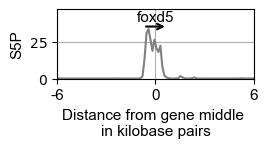

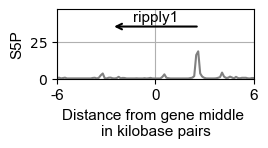

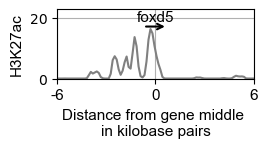

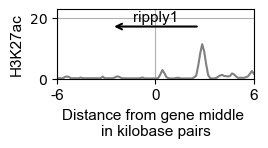

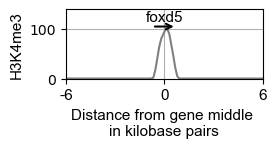

...

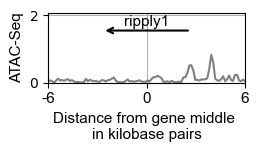

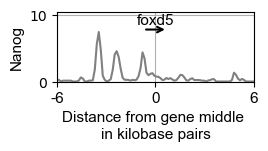

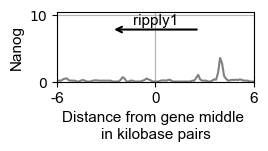

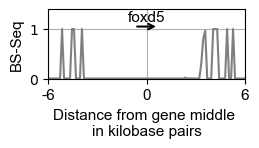

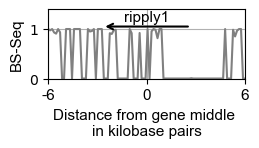

In [105]:
#visualisation with gene annotation and other features

for i in range(len(plot_signals_2)):
    #get max signal value to set y range
    max_signal_v = max([item for sublist in subset_gene_details_expr_signals_1[plot_signals_2[i]] for item in sublist])
    max_signal_v_s=max_signal_v*1.4  #1.4 -> if no CpG plottet
    #make plot for subset of genes that were selected
    for j in range(len(gene_examples_names_2)):
        fig=plt.figure(figsize=(2.54,0.9))
        ax2 = fig.add_subplot(111)
        
        signal_track_df_1=subset_gene_details_expr_signals_1[subset_gene_details_expr_signals_1["Name"]==gene_examples_names_2[j]]
        signal_track_1=signal_track_df_1[plot_signals_2[i]].tolist()[0]
        signal_track_start_1=signal_track_df_1["Signal start"].to_numpy()[0]
        signal_track_stop_1=signal_track_df_1["Signal stop"].to_numpy()[0]
        signal_track_middle_1=signal_track_df_1["Middle"].to_numpy()[0]
        signal_track_orientation_1=signal_track_df_1["Orientation"].values[0]#[0]
        signal_track_x_1=np.linspace(signal_track_start_1,signal_track_stop_1,len(signal_track_1))
        
        signal_track_annotation=[signal_track_middle_1-interval_sel,signal_track_middle_1,signal_track_middle_1+interval_sel]
        signal_track_annotation_l=[-int(interval_sel/1000),0,int(interval_sel/1000)]
        #ax2.errorbar(signal_track_x_1,signal_track_1,label=gene_examples_names_2[j],color="grey")
        ax2.errorbar(signal_track_x_1,signal_track_1,color="grey")

        
        gene_start=signal_track_df_1["Start"].to_numpy()[0]
        gene_stop=signal_track_df_1["Stop"].to_numpy()[0]
        #print(gene_start,gene_stop,max_signal_v, max_signal_v*1.15)
        gene_len=gene_stop-gene_start
        #ax2.hlines(40,gene_start,gene_stop,color="black")
        
        if signal_track_orientation_1=="plus":
            dir_arr="->"
        else:
            dir_arr="<-"
        
        ax2.annotate("", xy=(gene_start+gene_len, max_signal_v*1.05), xytext=(gene_start, max_signal_v*1.05),arrowprops=dict(arrowstyle=dir_arr, lw=1.5, shrinkA=0, shrinkB=0))
        #ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(gene_start, max_signal_v*1.15),fontsize=11,fontname = "Arial")
        ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(signal_track_middle_1, max_signal_v*1.15),fontsize=11,fontname = "Arial", ha='center')
        
        '''#plot CpG islands
        Gene_CpG_overlap_2_sel=Gene_CpG_overlap_2[Gene_CpG_overlap_2["Name"]==gene_examples_names_2[j]]["Names overlap"].tolist()[0]
        for m in range(len(Gene_CpG_overlap_2_sel)):
            
            name_CpG=Gene_CpG_overlap_2_sel[m]
                
            df_sub_set_CpG=CpG_read_in_1[CpG_read_in_1["NAME"]==name_CpG]

            start_CpG_1=df_sub_set_CpG["START"].to_numpy()[0]
            end_CpG_1=df_sub_set_CpG["STOP"].to_numpy()[0]
            len_CpG_1=end_CpG_1-start_CpG_1
            middle_CpG_1=df_sub_set_CpG["MIDDLE"].to_numpy()[0]
            
            #print(start_CpG_1)
            ax2.hlines(max_signal_v*1.4,start_CpG_1,end_CpG_1,color="red")   
            ax2.annotate("CpG",xy=(start_CpG_1+len_CpG_1, max_signal_v*1.5),xytext=(start_CpG_1, max_signal_v*1.5),fontsize=11,fontname = "Arial",color="red")'''


        #plt.legend(prop={'family': 'Arial','size': 11},loc=1)
        #plt.ylabel(signals_names[i], size=11, fontname="Arial")
        plt.xlabel("Distance from gene middle \nin kilobase pairs", size=11, fontname="Arial")
        plt.grid()
        plt.ylim(0,max_signal_v_s)
        plt.ylabel(labels_signals_2[i], size=11, fontname="Arial")
        #plt.xticks([4.5,104.5,204.5],[-100,0,100],fontname = "Arial",fontsize=11)
        
        plt.xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
        plt.xlim(signal_track_annotation[0],signal_track_annotation[-1])
        #ax2.set_aspect(1./ax2.get_data_ratio())
        #ax2.set_aspect(0.5/ax2.get_data_ratio())
        #plt.legend(fontsize=11, prop={'family': 'Arial'},loc=1)
        #ax2.set_aspect(0.45/ax2.get_data_ratio())

        name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/genome_tracks/" +str(labels_signals_2[i])+"_"+str(gene_examples_names_2[j])+"_12000bpfilter_2.pdf"
        #print(name_s)
        #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
        #plt.savefig(name_s,format="pdf",bbox_inches="tight")

        plt.show()

# Visualization 4

Plot signals for selected genes and selected groups of genes in regions of the gene map

In [106]:
# get ChIP-Seq profiles of individual genes

interval_sel_1=5*10**6
#add signal tracks
subset_gene_details_expr_signals_2=subset_gene_details_1
for i in range(len(bw_signal_list)):

    df_signal=get_coverage_for_genes_V1(df_genes=subset_gene_details_1,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Middle",Stop_col="Middle",Orientation_col="Orientation",Signal_col=labels_signals_2[i],expected_dim=200,add_interval=interval_sel_1,big_wig_file_name=bw_signal_list[i],chr_add="chr",signal_type="mean")


    subset_gene_details_expr_signals_2=pd.concat([subset_gene_details_expr_signals_2,df_signal[labels_signals_2[i]]], axis=1)
#add signal start stop entry
subset_gene_details_expr_signals_2=pd.concat([subset_gene_details_expr_signals_2,df_signal[["Signal start","Signal stop"]]], axis=1)


ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
0 / 1
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
1 / 1
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
0 / 1
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
1 / 1
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
0 / 1
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
1 / 1
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
0 / 1
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
1 / 1
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
0 / 1
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
1 / 1
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
0 / 1
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
1 / 1


In [107]:
subset_gene_details_expr_signals_2

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K4me3,ATAC-Seq,Nanog,BS-Seq,Signal start,Signal stop
0,ENSDARG00000054103,ripply1,21,37967457,37972497,minus,5040,37969977,37972397,37973497,0.4,"[0.39950506884257, 0.4128291735495773, 0.41447...","[0.17313845543151207, 0.20448287824346661, 0.2...","[0.18334662550104727, 0.24866160905894666, 0.2...","[0.05075213181350912, 0.05168961029240063, 0.0...","[0.22511525432746105, 0.2345595372126205, 0.21...","[0.9470264127315798, 0.9324700875235398, 0.934...",32969977,42969977
1,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,"[0.45259400014839923, 0.4287526215796377, 0.44...","[0.26014218833761016, 0.5786984027489196, 0.53...","[0.23879809741331798, 0.2684928925164855, 0.75...","[0.04612407442092895, 0.056115490000588554, 0....","[0.26362518519170275, 0.25643753682809717, 0.2...","[0.9463900714986865, 0.96062637655963, 0.78659...",25453520,35453520


In [108]:
S5P_peaks_read_in_2

,CHROM,START,STOP,name,score,strand,signal value,p value,q value,peak,MIDDLE
0,chr17,53383447,53383857,Peak_1,2463,.,24.84666,246.38214,237.24477,186,53383652
1,chr14,20104266,20104656,Peak_2,2217,.,16.09500,221.79599,214.59311,189,20104461
2,chr20,4608717,4609147,Peak_3,2187,.,26.84475,218.79016,211.74969,189,4608932
3,chr10,16794091,16794740,Peak_4,1726,.,13.42756,172.66121,166.11823,231,16794415
4,chr10,16800626,16801008,Peak_5,1565,.,13.08130,156.51080,150.12778,179,16800817
...,...,...,...,...,...,...,...,...,...,...,...
3814,chrUn_KN150127v1,25182,25373,Peak_3815,89,.,2.38781,8.97490,5.88778,130,25277
3815,chrUn_KZ115985v1,2615,2844,Peak_3816,85,.,4.56737,8.57836,5.52450,109,2729
3816,chr12,24100698,24101024,Peak_3817,77,.,4.46429,7.77530,4.80048,197,24100861
3817,chr19,20190148,20190346,Peak_3818,77,.,2.59100,7.76659,4.79256,6,20190247


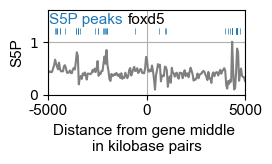

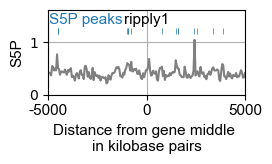

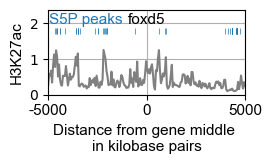

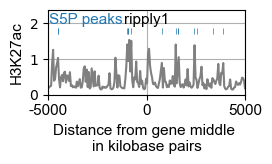

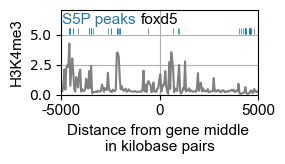

...

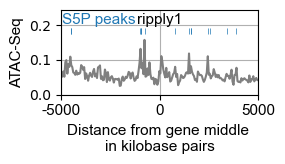

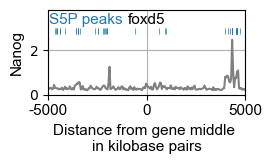

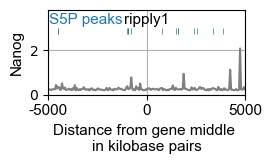

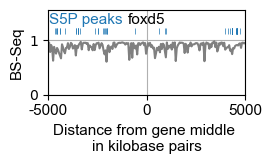

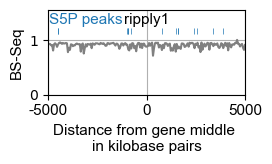

In [109]:
#plot genes and peaks in sourrounding genomic region

for i in range(len(plot_signals_2)):
    #get max signal value to set y range
    max_signal_v = max([item for sublist in subset_gene_details_expr_signals_2[plot_signals_2[i]] for item in sublist])
    max_signal_v_s=max_signal_v*1.55
    #make plot for subset of genes that were selected
    for j in range(len(gene_examples_names_2)):
        fig=plt.figure(figsize=(2.54,1.1))
        ax2 = fig.add_subplot(111)
        
        signal_track_df_1=subset_gene_details_expr_signals_2[subset_gene_details_expr_signals_2["Name"]==gene_examples_names_2[j]]
        signal_track_1=signal_track_df_1[plot_signals_2[i]].tolist()[0]
        signal_track_start_1=signal_track_df_1["Signal start"].to_numpy()[0]
        signal_track_stop_1=signal_track_df_1["Signal stop"].to_numpy()[0]
        signal_track_middle_1=signal_track_df_1["Middle"].to_numpy()[0]
        signal_track_orientation_1=signal_track_df_1["Orientation"].values[0]#[0]
        signal_track_x_1=np.linspace(signal_track_start_1,signal_track_stop_1,len(signal_track_1))
        
        signal_track_annotation=[signal_track_middle_1-interval_sel_1,signal_track_middle_1,signal_track_middle_1+interval_sel_1]
        signal_track_annotation_l=[-int(interval_sel_1/1000),0,int(interval_sel_1/1000)]
        #ax2.errorbar(signal_track_x_1,signal_track_1,label=gene_examples_names_2[j],color="grey")
        ax2.errorbar(signal_track_x_1,signal_track_1,color="grey")
        
        
        #select regulatory elements for sel gene
        Gene_SE_overlap_1_sel=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"]==gene_examples_names_2[j]]["Names overlap"].tolist()[0]
        for m in range(len(Gene_SE_overlap_1_sel)):
            
            name_cCRE=Gene_SE_overlap_1_sel[m]
            #for this step, select the dataframe used to find regulatory elements overlapping genes
            #ROSE SEs:
            #df_cCRE_sel=SE_read_in_1[SE_read_in_1["Name"]==name_cCRE]

            #ROSE SEs overlapping cCREs:
            #df_cCRE_sel=SE_read_in_1_overlap_cCREs_1[SE_read_in_1_overlap_cCREs_1["Name"]==name_cCRE]
            
            
            #cCREs:
            #df_cCRE_sel=cCRE_dynamic_read_in_clusters_1[cCRE_dynamic_read_in_clusters_1["Name"]==name_cCRE]
            
            #cCREs overlapping S5P peaks:
            #df_cCRE_sel=cCRE_dynamic_read_in_clusters_overlap_S5P_1[cCRE_dynamic_read_in_clusters_overlap_S5P_1["Name"]==name_cCRE]
            
            #S5P peaks not overlapping genes
            #df_cCRE_sel=S5P_peaks_read_in_no_overlap_genes_1[S5P_peaks_read_in_no_overlap_genes_1["name"]==name_cCRE]
            
            #S5P peaks not overlapping genes, but overlapping cCREs
            #df_cCRE_sel=S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1[S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1["name"]==name_cCRE]

            #S5P peaks
            df_cCRE_sel=S5P_peaks_read_in_2[S5P_peaks_read_in_2["name"]==name_cCRE]
            
            #PADREs
            #df_cCRE_sel=PADRES_read_in_enh_1[PADRES_read_in_enh_1["Name"]==name_cCRE]
            
            #PADREs overlapping S5P peaks
            #df_cCRE_sel=PADRES_read_in_1_overlap_S5P_1[PADRES_read_in_1_overlap_S5P_1["Name"]==name_cCRE]
            
            #adjust names of start, stop, middle
            #cCRE_sel_start_1=df_cCRE_sel["Start"].to_numpy()[0]
            #cCRE_sel_stop_1=df_cCRE_sel["Stop"].to_numpy()[0]
            #cCRE_sel_middle_1=df_cCRE_sel["Middle"].to_numpy()[0]
            
            cCRE_sel_start_1=df_cCRE_sel["START"].to_numpy()[0]
            cCRE_sel_stop_1=df_cCRE_sel["STOP"].to_numpy()[0]
            cCRE_sel_middle_1=df_cCRE_sel["MIDDLE"].to_numpy()[0]
            
            #ax2.vlines(cCRE_sel_middle_1,0,max_signal_v)
            
            ax2.vlines(cCRE_sel_middle_1,max_signal_v*1.1, max_signal_v*1.21, linewidth=0.5)

            #ax2.vlines(cCRE_sel_start_1,0,max_signal_v,color="black")
            #ax2.vlines(cCRE_sel_stop_1,0,max_signal_v,color="black")
            '''ax2.annotate('', xy=(cCRE_sel_middle_1, max_signal_v), xytext=(cCRE_sel_middle_1, max_signal_v*1.01),
             arrowprops=dict(facecolor='black', shrink=0.99, headwidth=1, headlength=1, width=0))'''




            
        gene_start=signal_track_df_1["Start"].to_numpy()[0]
        gene_stop=signal_track_df_1["Stop"].to_numpy()[0]
        #print(gene_start,gene_stop,max_signal_v, max_signal_v*1.15)
        gene_len=gene_stop-gene_start
        #ax2.hlines(40,gene_start,gene_stop,color="black")
        
        if signal_track_orientation_1=="plus":
            dir_arr="->"
        else:
            dir_arr="<-"
        
        #ax2.annotate("", xy=(gene_start+gene_len, max_signal_v*1.05), xytext=(gene_start, max_signal_v*1.05),arrowprops=dict(arrowstyle=dir_arr, lw=1.5, shrinkA=0, shrinkB=0))
        #ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(gene_start, max_signal_v*1.15),fontsize=11,fontname = "Arial")
        ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(signal_track_middle_1, max_signal_v*1.3),fontsize=11,fontname = "Arial", ha='center')
 
        ax2.annotate("S5P peaks",xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(signal_track_middle_1-3100000, max_signal_v*1.3),fontsize=11,fontname = "Arial", ha='center',color="tab:blue")

        #plt.legend(prop={'family': 'Arial','size': 11},loc="lower left")
        #plt.ylabel(signals_names[i], size=11, fontname="Arial")
        plt.xlabel("Distance from gene middle \nin kilobase pairs", size=11, fontname="Arial")
        plt.grid()
        plt.ylim(0,max_signal_v_s)
        plt.xlim(signal_track_annotation[0],signal_track_annotation[-1])
        plt.ylabel(labels_signals_2[i], size=11, fontname="Arial")
        #plt.xticks([4.5,104.5,204.5],[-100,0,100],fontname = "Arial",fontsize=11)
        
        plt.xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
        #ax2.set_aspect(1./ax2.get_data_ratio())
        #ax2.set_aspect(0.5/ax2.get_data_ratio())
        #plt.legend(fontsize=11, prop={'family': 'Arial'},loc=1)
        #ax2.set_aspect(0.45/ax2.get_data_ratio())

        name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/genome_tracks/" +str(labels_signals_2[i])+"_"+str(gene_examples_names_2[j])+"_5000kbpfilter_1.pdf"
        #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
        #plt.savefig(name_s,format="pdf",bbox_inches="tight")

        plt.show()

In [110]:
#plot acrs between genes and sourrounding peaks, that encode Hi-C interaction freq.

from matplotlib.patches import FancyArrowPatch
#draw arcs connecting regulatory elements with gene
def add_arc_connector(ax, x_signal, x_gene, y_base=None, arc_height=0.1,
                      color='tab:red', lw=2, rad=0.3, arrow=False):
    """
    Add an arced connector above the plot connecting a ChIP-seq point (x_signal)
    to a gene position (x_gene).

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Target axes.
    x_signal : float
        Genomic coordinate of the signal point on the x-axis.
    x_gene : float
        Genomic coordinate of the gene on the x-axis.
    y_base : float or None
        Baseline y-value to place the arc above. If None, uses ax.get_ylim()[1].
    arc_height : float
        Fraction of the y-range to lift the arc above y_base.
    color : str
        Line color.
    lw : float
        Line width.
    rad : float
        Curvature radius for 'arc3' connection style; positive bends upward.
    arrow : bool
        If True, draw an arrowhead at the gene side.
    """
    y0, y1 = ax.get_ylim()
    if y_base is None:
        y_base = y1
    # Lift the arc above the plot
    y_arc = y_base + arc_height * (y1 - y0)

    # Create a curved connector from (x_signal, y_arc) to (x_gene, y_arc)
    patch = FancyArrowPatch(
        (x_signal, y_arc), (x_gene, y_arc),
        connectionstyle=f"arc3,rad={rad}",
        arrowstyle='-|>' if arrow else '-',  # arrow head optional
        mutation_scale=15 if arrow else 1,
        color=color,
        linewidth=lw,
        clip_on=False,    # keep arc visible outside the axes area
        zorder=5
    )
    ax.add_patch(patch)




0.0 1.7549782991409302


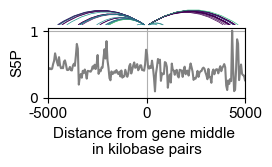

0.0 2.4547344744205475


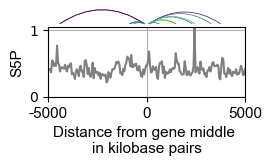

In [111]:
# plot signal track and calculate Hic interaction between genes and signal peaks
for i in range(len(plot_signals_2[:1])):
    #get max signal value to set y range
    max_signal_v = max([item for sublist in subset_gene_details_expr_signals_2[plot_signals_2[i]] for item in sublist])
    max_signal_v_s=max_signal_v #*1.55
    #make plot for subset of genes that were selected
    for j in range(len(gene_examples_names_2)):
        fig=plt.figure(figsize=(2.54,0.9))
        ax2 = fig.add_subplot(111)
        
        signal_track_df_1=subset_gene_details_expr_signals_2[subset_gene_details_expr_signals_2["Name"]==gene_examples_names_2[j]]
        signal_track_1=signal_track_df_1[plot_signals_2[i]].tolist()[0]
        signal_track_start_1=signal_track_df_1["Signal start"].to_numpy()[0]
        signal_track_stop_1=signal_track_df_1["Signal stop"].to_numpy()[0]
        signal_track_middle_1=signal_track_df_1["Middle"].to_numpy()[0]
        signal_track_orientation_1=signal_track_df_1["Orientation"].values[0]#[0]
        signal_track_chrom_1=signal_track_df_1["Chr"].values[0]#[0]
        signal_track_x_1=np.linspace(signal_track_start_1,signal_track_stop_1,len(signal_track_1))
        
        signal_track_annotation=[signal_track_middle_1-interval_sel_1,signal_track_middle_1,signal_track_middle_1+interval_sel_1]
        signal_track_annotation_l=[-int(interval_sel_1/1000),0,int(interval_sel_1/1000)]
        #ax2.errorbar(signal_track_x_1,signal_track_1,label=gene_examples_names_2[j],color="grey")
        ax2.errorbar(signal_track_x_1,signal_track_1,color="grey")
        
        
        #select regulatory elements for sel gene
        hic_signal_list=[]
        reg_element_middle_list=[]
        Gene_SE_overlap_1_sel=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"]==gene_examples_names_2[j]]["Names overlap"].tolist()[0]
        for m in range(len(Gene_SE_overlap_1_sel)):
            
            name_cCRE=Gene_SE_overlap_1_sel[m]
            #for this step, select the dataframe used to find regulatory elements overlapping genes
            #ROSE SEs:
            #df_cCRE_sel=SE_read_in_1[SE_read_in_1["Name"]==name_cCRE]

            #ROSE SEs overlapping cCREs:
            #df_cCRE_sel=SE_read_in_1_overlap_cCREs_1[SE_read_in_1_overlap_cCREs_1["Name"]==name_cCRE]
            
            
            #cCREs:
            #df_cCRE_sel=cCRE_dynamic_read_in_clusters_1[cCRE_dynamic_read_in_clusters_1["Name"]==name_cCRE]
            
            #cCREs overlapping S5P peaks:
            #df_cCRE_sel=cCRE_dynamic_read_in_clusters_overlap_S5P_1[cCRE_dynamic_read_in_clusters_overlap_S5P_1["Name"]==name_cCRE]
            
            #S5P peaks not overlapping genes
            #df_cCRE_sel=S5P_peaks_read_in_no_overlap_genes_1[S5P_peaks_read_in_no_overlap_genes_1["name"]==name_cCRE]
            
            #S5P peaks not overlapping genes, but overlapping cCREs
            #df_cCRE_sel=S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1[S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1["name"]==name_cCRE]

            #S5P peaks
            df_cCRE_sel=S5P_peaks_read_in_2[S5P_peaks_read_in_2["name"]==name_cCRE]
            
            #PADREs
            #df_cCRE_sel=PADRES_read_in_enh_1[PADRES_read_in_enh_1["Name"]==name_cCRE]
            
            #PADREs overlapping S5P peaks
            #df_cCRE_sel=PADRES_read_in_1_overlap_S5P_1[PADRES_read_in_1_overlap_S5P_1["Name"]==name_cCRE]
            
            #adjust names of start, stop, middle
            #cCRE_sel_start_1=df_cCRE_sel["Start"].to_numpy()[0]
            #cCRE_sel_stop_1=df_cCRE_sel["Stop"].to_numpy()[0]
            #cCRE_sel_middle_1=df_cCRE_sel["Middle"].to_numpy()[0]
            
            cCRE_sel_start_1=df_cCRE_sel["START"].to_numpy()[0]
            cCRE_sel_stop_1=df_cCRE_sel["STOP"].to_numpy()[0]
            cCRE_sel_middle_1=df_cCRE_sel["MIDDLE"].to_numpy()[0]
            
            #ax2.vlines(cCRE_sel_middle_1,0,max_signal_v)
            
            
            #get hic contact between gene and regulatory signal (e.g. S5P peak)
            #gene
            add_interval=15000
            add_interval_reg=15000
            sel_res=5000
            gr1=int(signal_track_middle_1-add_interval)
            gr2=int(signal_track_middle_1+add_interval)
            
            #reg. element
            gc1=int(cCRE_sel_middle_1-add_interval_reg)
            gc2=int(cCRE_sel_middle_1+add_interval_reg)
            
            #select lower, upper boundary such that no empty row/column is appended if boundaries dont match resolution
            gr1_r=int(np.round(gr1/sel_res)*sel_res)
            gr2_r=int(np.round(gr2/sel_res)*sel_res -sel_res/2)
            gc1_r=int(np.round(gc1/sel_res)*sel_res)
            gc2_r=int(np.round(gc2/sel_res)*sel_res -sel_res/2)
            

            hic_contact_sel=Hi_C_load_fct_V2(hic_zoom_matrix,None,signal_track_chrom_1,gr1_r,gr2_r,gc1_r,gc2_r)
            hic_signal_list.append(hic_contact_sel)
            reg_element_middle_list.append(cCRE_sel_middle_1)
            line_m=0.3+hic_contact_sel
            
            
            norm = matplotlib.colors.Normalize(vmin=0, vmax=2.5)
            cmap = matplotlib.cm.viridis
            color = cmap(norm(hic_contact_sel))

            
            ###

            
            ax2.vlines(cCRE_sel_middle_1,max_signal_v*1.1, max_signal_v*1.21, linewidth=0.5,color=color)

            #ax2.vlines(cCRE_sel_start_1,0,max_signal_v,color="black")
            #ax2.vlines(cCRE_sel_stop_1,0,max_signal_v,color="black")
            '''ax2.annotate('', xy=(cCRE_sel_middle_1, max_signal_v), xytext=(cCRE_sel_middle_1, max_signal_v*1.01),
             arrowprops=dict(facecolor='black', shrink=0.99, headwidth=1, headlength=1, width=0))'''


        print(np.min(hic_signal_list),np.max(hic_signal_list))
            
        gene_start=signal_track_df_1["Start"].to_numpy()[0]
        gene_stop=signal_track_df_1["Stop"].to_numpy()[0]
        #print(gene_start,gene_stop,max_signal_v, max_signal_v*1.15)
        gene_len=gene_stop-gene_start
        #ax2.hlines(40,gene_start,gene_stop,color="black")
        
        if signal_track_orientation_1=="plus":
            dir_arr="->"
        else:
            dir_arr="<-"
        
        #ax2.annotate("", xy=(gene_start+gene_len, max_signal_v*1.05), xytext=(gene_start, max_signal_v*1.05),arrowprops=dict(arrowstyle=dir_arr, lw=1.5, shrinkA=0, shrinkB=0))
        #ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(gene_start, max_signal_v*1.15),fontsize=11,fontname = "Arial")
        #ax2.annotate(gene_examples_names_2[j],xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(signal_track_middle_1, max_signal_v*1.3),fontsize=11,fontname = "Arial", ha='center')
 
        #ax2.annotate("S5P peaks",xy=(gene_start+gene_len, max_signal_v*1.15),xytext=(signal_track_middle_1-3100000, max_signal_v*1.3),fontsize=11,fontname = "Arial", ha='center',color="tab:blue")

        #plt.legend(prop={'family': 'Arial','size': 11},loc="lower left")
        #plt.ylabel(signals_names[i], size=11, fontname="Arial")
        plt.xlabel("Distance from gene middle \nin kilobase pairs", size=11, fontname="Arial")
        plt.grid()
        plt.ylim(0,max_signal_v_s)
        plt.xlim(signal_track_annotation[0],signal_track_annotation[-1])
        plt.ylabel(labels_signals_2[i], size=11, fontname="Arial")
        #plt.xticks([4.5,104.5,204.5],[-100,0,100],fontname = "Arial",fontsize=11)
        
        plt.xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
        #ax2.set_aspect(1./ax2.get_data_ratio())
        #ax2.set_aspect(0.5/ax2.get_data_ratio())
        #plt.legend(fontsize=11, prop={'family': 'Arial'},loc=1)
        #ax2.set_aspect(0.45/ax2.get_data_ratio())
        
        for u in range(len(reg_element_middle_list)):
            
            sign_curv=1
            if reg_element_middle_list[u]<signal_track_middle_1:
                sign_curv=-1
                
            norm = matplotlib.colors.Normalize(vmin=0, vmax=2.5)
            cmap = matplotlib.cm.viridis 
            color = cmap(norm(hic_signal_list[u]))
            
            add_arc_connector(ax=ax2, x_signal=reg_element_middle_list[u], x_gene=signal_track_middle_1, arc_height=0.12, color=color,lw=0.5, rad=sign_curv*0.35, arrow=False,y_base=0.95)
        
        #fig.colorbar(ax2, location='top',shrink=0.8).set_label(size=11,family="Arial")

        sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])  # not strictly required in recent Matplotlib, but safe
        #cbar = fig.colorbar(sm, ax=ax2, pad=0.02).set_label(label="Hi-C contact gene - S5P peak",size=11,family="Arial")


        name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/genome_tracks/" +str(labels_signals_2[i])+"_"+str(gene_examples_names_2[j])+"_5000kbpfilter_2.pdf"
        #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
        #plt.savefig(name_s,format="pdf",bbox_inches="tight")

        plt.show()

# Visualization 5

Visualize RNA expression

In [112]:
shortend_stage_names=["Zygote","2-cell","128-cell","1k-cell","Dome","50%-epiboly","Shield","75%-epiboly","1-4 somites","14-19 somites","20-25 somites","Prim-5","Prim-15","prim-25","Long-pec","Protruding mouth","Day 4", "Day 5"]

all_genes_expr


,Gene ID,Gene Name,zygote,cleavage 2-cell,blastula 128-cell,blastula 1k-cell,blastula dome,gastrula 50%-epiboly,gastrula shield,gastrula 75%-epiboly,segmentation 1-4 somites,segmentation 14-19 somites,segmentation 20-25 somites,pharyngula prim-5,pharyngula prim-15,pharyngula prim-25,hatching long-pec,larval protruding mouth,larval day 4,larval day 5
0,ENSDARG00000000001,slc35a5,2.0,5.0,16.0,17.0,8.0,4.0,2.0,4.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,6.0,5.0
1,ENSDARG00000000002,ccdc80,0.3,4.0,2.0,2.0,0.8,0.4,0.3,0.4,0.6,3.0,7.0,10.0,12.0,9.0,12.0,19.0,18.0,17.0
2,ENSDARG00000000018,nrf1,8.0,16.0,80.0,141.0,114.0,62.0,38.0,42.0,62.0,62.0,52.0,47.0,43.0,63.0,45.0,27.0,22.0,27.0
3,ENSDARG00000000019,ube2h,139.0,158.0,168.0,178.0,178.0,124.0,99.0,102.0,62.0,40.0,70.0,87.0,68.0,61.0,73.0,105.0,113.0,103.0
4,ENSDARG00000000068,slc9a3r1a,42.0,42.0,91.0,83.0,71.0,85.0,71.0,52.0,21.0,27.0,22.0,21.0,13.0,12.0,11.0,30.0,50.0,39.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24091,ENSDARG00000117814,CABZ01063971.1,0.6,0.0,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24092,ENSDARG00000117816,CABZ01078767.1,0.0,0.2,0.4,0.2,0.4,0.7,0.1,0.2,0.1,0.6,0.1,0.3,0.0,0.0,0.0,0.1,0.2,0.0
24093,ENSDARG00000117818,CR926130.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.1,0.0,0.6,2.0,2.0
24094,ENSDARG00000117822,ENSDARG00000117822,0.0,0.0,1.0,0.5,0.4,0.9,1.0,1.0,1.0,0.5,1.0,2.0,0.9,1.0,0.8,0.7,2.0,1.0


In [119]:
gene_examples_names_3=["foxd5","zgc:64022","ripply1"]
gene_examples_names_3=["foxd5"]
gene_examples_names_3= ["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]
gene_examples_names_3=["foxd5","ripply1"]

gene_examples_names_3

#gene_examples_names_3=["irx7","sox19a","gli2b","flt4","id3","sept2","ap1s1","serpine1"]


['foxd5', 'ripply1']

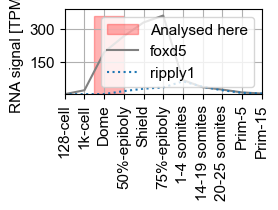

In [120]:
fig=plt.figure(figsize=(2.54,1.1))
ax2 = fig.add_subplot(111)
lim_a1=2
lim_b1=12
max_expr=[]
color_n1=["grey","tab:blue"]
ls_n1=["-",":"]
for i in range(len(gene_examples_names_3)):
    sel_gene_expr=all_genes_expr[all_genes_expr["Gene Name"]==gene_examples_names_3[i]]
    sel_gene_expr_v=sel_gene_expr.iloc[0].tolist()[2:]
    ax2.errorbar(shortend_stage_names,sel_gene_expr_v,color=color_n1[i],label=gene_examples_names_3[i],fmt=ls_n1[i])
    max_expr.append(np.max(sel_gene_expr_v))

x_ticks_expr=np.arange(0,len(sel_gene_expr_v))
plt.xticks(x_ticks_expr,shortend_stage_names,size=11, rotation='vertical', fontname="Arial")
plt.ylabel("RNA signal [TPM]", size=11, fontname="Arial")
#plt.xlabel("Developmental stage", size=11, fontname="Arial")
plt.grid()
plt.yticks([150,300],[150,300],fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
#plt.ylim(0,np.max(max_expr))
plt.ylim(0,390)
plt.xlim(2,12)
sel_state_rec=matplotlib.patches.Rectangle((3.5,0),width=1.5,height=360,alpha=0.3,color="r",label="Analysed here")
ax2.add_patch(sel_state_rec)
plt.legend(prop={'family': 'Arial','size': 11})
#ax2.set_aspect(0.45/ax2.get_data_ratio())

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/expression_profile_foxd5_ripply1_1.pdf"
#plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
#plt.savefig(name_s,format="pdf",bbox_inches="tight")

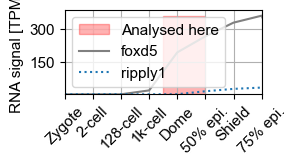

In [121]:
shortend_stage_names2=["Zygote","2-cell","128-cell","1k-cell","Dome","50% epi.","Shield","75% epi.","1-4 somites","14-19 somites","20-25 somites","Prim-5","Prim-15","prim-25","Long-pec","Protruding mouth","Day 4", "Day 5"]


fig=plt.figure(figsize=(2.54,1.1))
ax2 = fig.add_subplot(111)
lim_a1=2
lim_b1=12
max_expr=[]
color_n1=["grey","tab:blue"]
ls_n1=["-",":"]
for i in range(len(gene_examples_names_3)):
    sel_gene_expr=all_genes_expr[all_genes_expr["Gene Name"]==gene_examples_names_3[i]]
    sel_gene_expr_v=sel_gene_expr.iloc[0].tolist()[2:]
    ax2.errorbar(shortend_stage_names2,sel_gene_expr_v,color=color_n1[i],label=gene_examples_names_3[i],fmt=ls_n1[i])
    max_expr.append(np.max(sel_gene_expr_v))

x_ticks_expr=np.arange(0,len(sel_gene_expr_v))
plt.xticks(x_ticks_expr,shortend_stage_names2,size=11, rotation=45, fontname="Arial")
plt.ylabel("RNA signal [TPM]", size=11, fontname="Arial")
#plt.xlabel("Developmental stage", size=11, fontname="Arial")
plt.grid()
plt.yticks([150,300],[150,300],fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
#plt.ylim(0,np.max(max_expr))
plt.ylim(0,390)
plt.xlim(0,7)
sel_state_rec=matplotlib.patches.Rectangle((3.5,0),width=1.5,height=360,alpha=0.3,color="r",label="Analysed here")
ax2.add_patch(sel_state_rec)
plt.legend(prop={'family': 'Arial','size': 11})
#ax2.set_aspect(0.45/ax2.get_data_ratio())

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/expression_profile_foxd5_ripply1_2.pdf"
#plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
#plt.savefig(name_s,format="pdf",bbox_inches="tight")

# Analytical model

We test if the genome wide patterns are compatible with a 3-state markov model. We identify three minimal states required to be compatible with our microscopy data and with our simulation results. To be agnostic, we allow all rates between the states and don't impose detailed balance, as the system might be active. We then check if we can run a genom-wide pattern assesment similar to what we did for the sequencing based data, on the synthetic data. We then compare the patterns and see if we can match them to rates.


A 3‑state continuous‑time Markov model:

I<->A

A<->T

T<->I

Matrix calculation:

https://matrixcalc.org/slu.html#solve-using-Gaussian-elimination%28%7B%7B-%28a+f%29,b,k,0,0%7D,%7Ba,-%28b+c%29,d,0,0%7D,%7Bf,c,-%28d+k%29,0,0%7D,%7B1,1,1,0,1%7D%7D%29

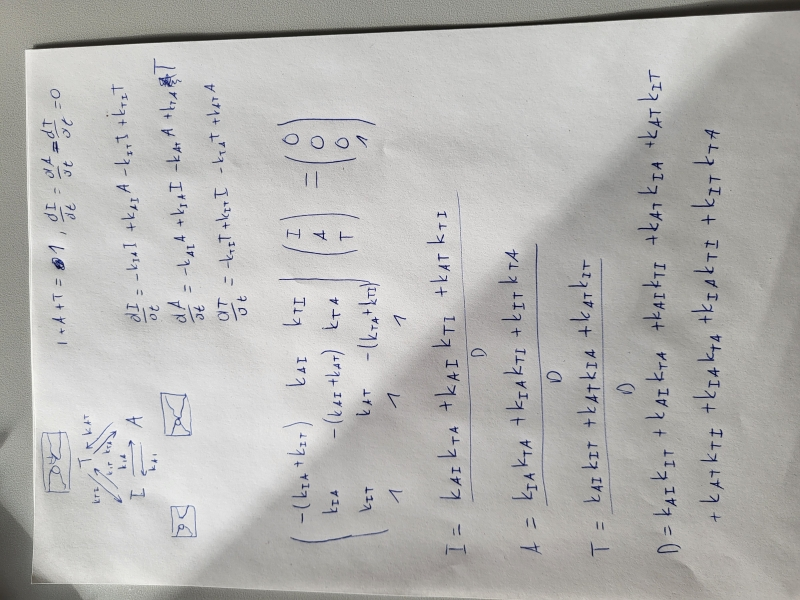

In [97]:

# compute steady state distributions of states I,A,T for forward and backward rates between states and I+A+T=1
def compute_steady_state(k_IA, k_AI, k_AT, k_TA, k_TI, k_IT):
    """
    Compute steady-state probabilities I, A, T for arrays of rate constants.
    All inputs should be NumPy arrays (or lists) of the same shape.
    """
    # Convert inputs to numpy arrays
    k_IA = np.array(k_IA, dtype=float)
    k_AI = np.array(k_AI, dtype=float)
    k_AT = np.array(k_AT, dtype=float)
    k_TA = np.array(k_TA, dtype=float)
    k_TI = np.array(k_TI, dtype=float)
    k_IT = np.array(k_IT, dtype=float)

    # Compute denominator D
    D = (k_AI*k_IT + k_AI*k_TA + k_AI*k_TI +
         k_AT*k_IA + k_AT*k_IT + k_AT*k_TI +
         k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)

    # Compute numerators for I, A, T
    I = (k_AI*k_TA + k_AI*k_TI + k_AT*k_TI) / D
    A = (k_IA*k_TA + k_IA*k_TI + k_IT*k_TA) / D
    T = (k_AI*k_IT + k_AT*k_IA + k_AT*k_IT) / D

    return I, A, T




def generate_random_rates(seeds, bounds, size=1):
    """
    Generate random rate constants within specified bounds using separate seeds.

    Parameters:
    - seeds: dict with keys ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT'] and integer seeds.
    - bounds: dict with keys ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT'] and tuple (low, high) for each rate.
    - size: number of random values per rate.

    Returns:
    - rates: dict with arrays of random values for each rate.
    """
    rates = {}
    for rate in ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT']:
        low, high = bounds[rate]
        rng = np.random.default_rng(seeds[rate])
        rates[rate] = rng.uniform(low, high, size)
    return rates


In [98]:
seeds = {'k_IA': 42, 'k_AI': 43, 'k_AT': 44, 'k_TA': 45, 'k_TI': 46, 'k_IT': 47}
bounds = {
    'k_IA': (0,1),
    'k_AI': (0,1),
    'k_AT': (0,1),
    'k_TA': (0,1),
    'k_TI': (0,1),
    'k_IT': (0,1)
}

random_rates = generate_random_rates(seeds, bounds, size=100000) #50000

k_IA = random_rates["k_IA"]
k_AI = random_rates["k_AI"]
k_AT = random_rates["k_AT"]
k_TA = random_rates["k_TA"]
k_TI = random_rates["k_TI"]
k_IT = random_rates["k_IT"]

#detailed balance (cycle condition)
#k_IA/k_AI * k_AT/k_TA * k_TI/k_IT =1
#k_IT=k_IA/k_AI * k_AT/k_TA * k_TI

I, A, T = compute_steady_state(k_IA, k_AI, k_AT, k_TA, k_TI, k_IT)


In [99]:
print(k_IA/k_AI * k_AT/k_TA * k_TI/k_IT)

[ 0.30976655  0.50173526 13.34627872 ...  9.45934828 16.54580155
  8.16183014]


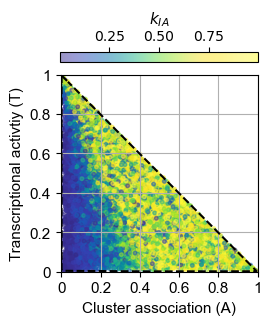

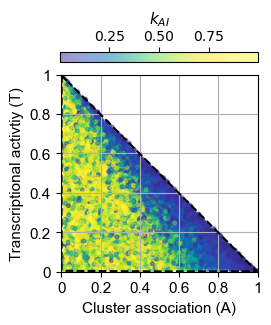

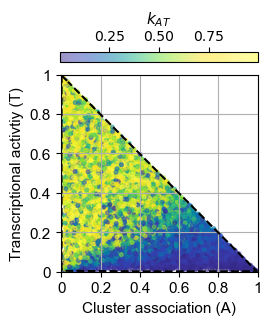

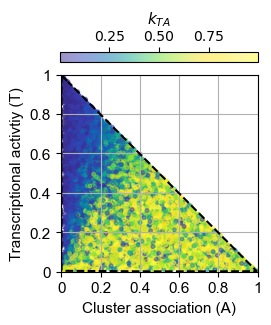

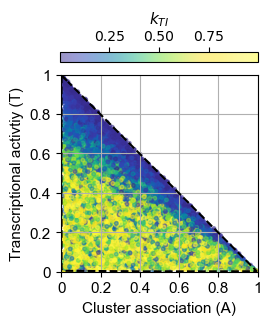

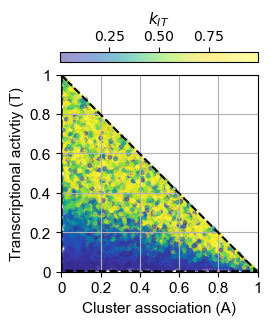

In [100]:
#scatter plot of many solutions of the 3-state model, visualised by plotting 2 steady states of each solution, and using color to encode the rates
#plt.scatter(A, I)


parameter_c=[k_IA,k_AI,k_AT,k_TA,k_TI,k_IT]
label_c=["k_IA","k_AI","k_AT","k_TA","k_TI","k_IT"]
label_c=[r"$k_{IA}$",r"$k_{AI}$",r"$k_{AT}$",r"$k_{TA}$",r"$k_{TI}$",r"$k_{IT}$"]

for i in range(len(parameter_c)):
    fig=plt.figure(figsize=(3.2,3.2))
    ax1 = fig.add_subplot(111)
    Signal_data=parameter_c[i]
    vmax1=None #np.percentile(Signal_data,99)
    color_scale_norm1=None #matplotlib.colors.PowerNorm(0.4)

    pl_111=ax1.scatter(A,T,s=7,c=Signal_data,vmax=vmax1,alpha=0.5,norm=color_scale_norm1,rasterized=True,cmap=parula_cmap)
    fig.colorbar(pl_111,shrink=0.8,location="top").set_label(label=label_c[i],size=11,family="Arial")
    
       #generate convex hull
    data_points_S5P_RNA=np.column_stack((A,T)) 
    hull_t=scipy.spatial.ConvexHull(data_points_S5P_RNA)
    ax1.errorbar(data_points_S5P_RNA[hull_t.vertices,0], data_points_S5P_RNA[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([data_points_S5P_RNA[hull_t.vertices,0][0] ,data_points_S5P_RNA[hull_t.vertices,0][-1]], [data_points_S5P_RNA[hull_t.vertices,1][0],data_points_S5P_RNA[hull_t.vertices,1][-1] ],color="black", fmt='--')
 
    plt.xlim(np.min(A)-0.005,np.max(A))
    plt.ylim(np.min(T),np.max(T))
    

    #plt.legend(prop={'family': 'Arial','size': 11},loc=1)
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    ax1.grid()

    ticks_fractions=[0,0.2,0.4,0.6,0.8,1]
    plt.yticks(ticks_fractions,ticks_fractions,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks_fractions,ticks_fractions,fontname = "Arial",fontsize=11) 

    #plt.xlim(0,np.max(A)*1.05)
    #plt.ylim(0,np.max(T)*1.05)

    #plt.xlim(0,5)
    #plt.ylim(0,100)
    
    


    ax1.set_aspect(1./ax1.get_data_ratio())   
    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"2d_model_scatter_plot_" +str(label_c[i])+"_1.pdf"

    #plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")


Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5006249366621588


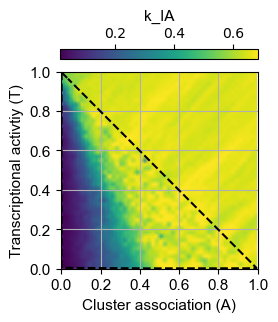

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.49999542597390273


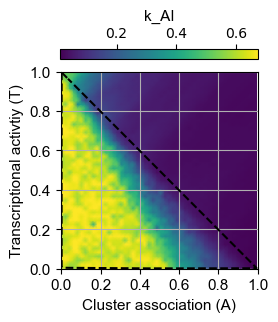

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5002674434694555


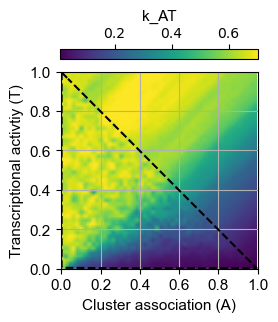

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5004483955339413


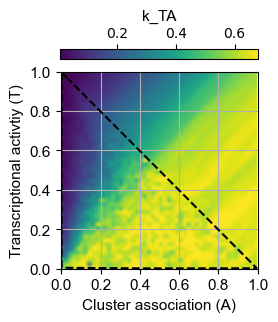

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5005544547129624


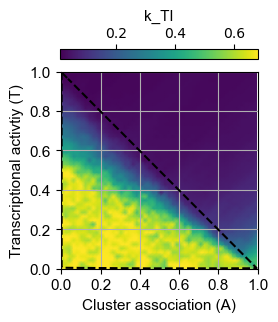

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5022716329367968


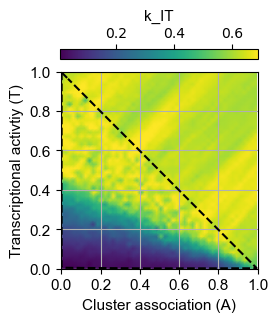

In [101]:
#Apply the same method that we used for genome-wide, locally averaged heatmaps to the data from the 3-state model

random_rates = generate_random_rates(seeds, bounds, size=100000)

k_IA = random_rates["k_IA"]
k_AI = random_rates["k_AI"]
k_AT = random_rates["k_AT"]
k_TA = random_rates["k_TA"]
k_TI = random_rates["k_TI"]
k_IT = random_rates["k_IT"]


#detailed balance (cycle condition)
#k_IA/k_AI * k_AT/k_TA * k_TI/k_IT =1
#k_IT=k_IA/k_AI * k_AT/k_TA * k_TI

I, A, T = compute_steady_state(k_IA, k_AI, k_AT, k_TA, k_TI, k_IT)

parameter_c=[k_IA,k_AI,k_AT,k_TA,k_TI,k_IT]
label_c=["k_IA","k_AI","k_AT","k_TA","k_TI","k_IT"]

plot_signals_1=parameter_c

labels_signals_1=label_c

#colorbar for locally averaged plot
colorbar_cutoff_1=[95,95,95,95,95,95,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=A
RNA_data=T

for k in range(len(plot_signals_1[:])):
    
    Signal_data=parameter_c[k]
    drop_zeros=drop_zeros_1[k]
    n_neighbors=75
    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff_1[k]!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff_1[k])
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_1[k]!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale_1[k])
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2[k]!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2[k])
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2[k]!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2[k])
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    #ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    #ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=labels_signals_1[k],size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        
    #plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    #plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 
    
    #plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
    #plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    ax1.set_aspect(1./ax1.get_data_ratio())
    

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_5/2d_plots/"+"2d_plot_" +str(labels_signals_1[k])+"_2.png"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
    plt.show()

# Look at example solutions from the 3-state model

select regions in the gene map from the 3-state model and use these regions to get average parameter combinations. Then use these average parameter combinations to get a new solution of the model, and evaluate these "exemplary" solutions

In [102]:
# get average rates in a region of the A-T plot


def sel_rates_in_region(I,A,T,T_lower,T_higher,A_lower,A_higher,k_IA,k_AI,k_AT,k_TA,k_TI,k_IT):
    A_in_region=[]
    I_in_region=[]
    T_in_region=[]
    
    k_IA_in_region=[]
    k_AI_in_region=[]
    k_AT_in_region=[]
    k_TA_in_region=[]
    k_TI_in_region=[]
    k_IT_in_region=[]
    
    for i in range(len(I)):
        A_sel=A[i]
        I_sel=I[i]
        T_sel=T[i]

        if (T_lower<T_sel<T_higher ) & (A_lower<A_sel<A_higher):
            A_in_region.append(A_sel)
            I_in_region.append(I_sel)
            T_in_region.append(T_sel)
            
            
            k_IA_in_region.append(k_IA[i])
            k_AI_in_region.append(k_AI[i])
            k_AT_in_region.append(k_AT[i])
            k_TA_in_region.append(k_TA[i])
            k_TI_in_region.append(k_TI[i])
            k_IT_in_region.append(k_IT[i])
            
        
    return A_in_region,I_in_region,T_in_region,k_IA_in_region,k_AI_in_region,k_AT_in_region,k_TA_in_region,k_TI_in_region,k_IT_in_region
            

canonical active: T_lower= 0.1 T_higher= 0.2 A_lower= 0.0 A_higher= 0.1
Mean, std, min, max of A in region 1: 0.06943022647590352 0.02297346678392087 0.004620176457802169 0.09998685632613549
Mean, std, min, max of I in region 1: 0.7805319978172652 0.03772614370183958 0.7034643770739342 0.8899320297312209
Mean, std, min, max of T in region 1: 0.1500377757068312 0.02922832297374312 0.10010085789084137 0.19979260242728006
##########################################
##########################################
Mean, std, min, max of k_IA in region 1: 0.05610810179970188 0.0448356551412556 6.21333425160353e-05 0.2117457056482034
Mean, std, min, max of k_AI in region 1: 0.6767487349840866 0.24755521497573893 0.006025918381169171 0.9998886658377142
Mean, std, min, max of k_AT in region 1: 0.6424658523292938 0.2734219157197636 0.0057949046611884825 0.998918634874398
Mean, std, min, max of k_TA in region 1: 0.3308026185582563 0.23803312147899822 0.0011690993444390951 0.9883477802708655
Mean, std, 

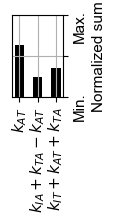

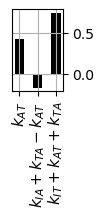

In [103]:
T_lower_r1=0.1
T_higher_r1=0.2
A_lower_r1=0.0
A_higher_r1=0.1
print("canonical active:","T_lower=",T_lower_r1,"T_higher=",T_higher_r1,"A_lower=",A_lower_r1,"A_higher=",A_higher_r1)

A_in_region1,I_in_region1,T_in_region1,k_IA_in_region1,k_AI_in_region1,k_AT_in_region1,k_TA_in_region1,k_TI_in_region1,k_IT_in_region1=sel_rates_in_region(I=I,A=A,T=T,T_lower=T_lower_r1,T_higher=T_higher_r1,A_lower=A_lower_r1,A_higher=A_higher_r1,k_IA=k_IA,k_AI=k_AI,k_AT=k_AT,k_TA=k_TA,k_TI=k_TI,k_IT=k_IT)



print("Mean, std, min, max of A in region 1:",np.mean(A_in_region1),np.std(A_in_region1),np.min(A_in_region1),np.max(A_in_region1))

print("Mean, std, min, max of I in region 1:",np.mean(I_in_region1),np.std(I_in_region1),np.min(I_in_region1),np.max(I_in_region1))

print("Mean, std, min, max of T in region 1:",np.mean(T_in_region1),np.std(T_in_region1),np.min(T_in_region1),np.max(T_in_region1))

print("##########################################")
print("##########################################")
print("Mean, std, min, max of k_IA in region 1:",np.mean(k_IA_in_region1),np.std(k_IA_in_region1),np.min(k_IA_in_region1),np.max(k_IA_in_region1))

print("Mean, std, min, max of k_AI in region 1:",np.mean(k_AI_in_region1),np.std(k_AI_in_region1),np.min(k_AI_in_region1),np.max(k_AI_in_region1))

print("Mean, std, min, max of k_AT in region 1:",np.mean(k_AT_in_region1),np.std(k_AT_in_region1),np.min(k_AT_in_region1),np.max(k_AT_in_region1))

print("Mean, std, min, max of k_TA in region 1:",np.mean(k_TA_in_region1),np.std(k_TA_in_region1),np.min(k_TA_in_region1),np.max(k_TA_in_region1))

print("Mean, std, min, max of k_TI in region 1:",np.mean(k_TI_in_region1),np.std(k_TI_in_region1),np.min(k_TI_in_region1),np.max(k_TI_in_region1))

print("Mean, std, min, max of k_IT in region 1:",np.mean(k_IT_in_region1),np.std(k_IT_in_region1),np.min(k_IT_in_region1),np.max(T_in_region1))

print("##########################################")
print("##########################################")
print("##########################################")
print("##########################################")
#repr. gene in region "canonical,active" mean in T_lower=0.2,T_higher=0.4,A_lower=0.1,A_higher=0.3:
k_IA_r1=np.mean(k_IA_in_region1)
k_AI_r1=np.mean(k_AI_in_region1)
k_AT_r1=np.mean(k_AT_in_region1)
k_TA_r1=np.mean(k_TA_in_region1)
k_TI_r1=np.mean(k_TI_in_region1)
k_IT_r1=np.mean(k_IT_in_region1)

I_r1, A_r1, T_r1 = compute_steady_state(k_IA=k_IA_r1, k_AI=k_AI_r1, k_AT=k_AT_r1, k_TA=k_TA_r1, k_TI=k_TI_r1, k_IT=k_IT_r1)

print("Region1 I,A,T:",I_r1, A_r1, T_r1 )
print("Flux I->A:",k_IA_r1*I_r1)
print("Flux A->I:",k_AI_r1*A_r1)
print("Flux A->T:",k_AT_r1*A_r1)
print("Flux T->A:",k_TA_r1*T_r1)
print("Flux T->I:",k_TI_r1*T_r1)
print("Flux I->T:",k_IT_r1*I_r1)

print("k_IA+k_TA-k_AT:",k_IA_r1+k_TA_r1-k_AT_r1)
print("k_IT+k_AT+k_TA:",k_IT_r1+k_AT_r1+k_TA_r1)
print("k_AT:",k_AT_r1)


fig=plt.figure(figsize=(0.65,3.2/3))
ax1 = fig.add_subplot(111)

#normalize values to 0-1
K_1=(k_AT_r1-np.min(k_IA))/(np.max(k_AT)-np.min(k_AT))

K_2_un=k_IA_r1+k_TA_r1-k_AT_r1
K_2_all_un=k_IA+k_TA-k_AT
K_2=(K_2_un-np.min(K_2_all_un))/(np.max(K_2_all_un)-np.min(K_2_all_un))

K_3_un=k_IT_r1+k_AT_r1+k_TA_r1
K_3_all_un=k_IT+k_AT+k_TA
K_3=(K_3_un-np.min(K_3_all_un))/(np.max(K_3_all_un)-np.min(K_3_all_un))
print("K1",K_1,"K2",K_2,"K3",K_3)

#plt.bar([1,2,3],[-k_AT_r1,k_IA_r1+k_TA_r1-k_AT_r1,k_IT_r1+k_AT_r1+k_TA_r1],width=0.5,color="black")
plt.bar([1,2,3],[K_1,K_2,K_3],width=0.5,color="black")
plt.grid()

#plt.xlim(1,3)
plt.ylim(0,1)

plt.yticks(ticks=[0,0.5,1],labels=["Min.","","Max."] ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.ylabel("Normalized sum" ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.xticks(ticks=[1,2,3],labels=[r"$k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$",r"$k_{IT}+k_{AT}+k_{TA}$"] ,fontname = "Arial",fontsize=11, rotation='vertical') 

ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"rates_canonical_active_2.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")

########################
#########################
##########################
########################

fig=plt.figure(figsize=(0.65,3.2/3))
ax1 = fig.add_subplot(111)

#normalize values with other values
K_1_un=k_AT_r1

K_2_un=k_IA_r1+k_TA_r1-k_AT_r1

K_3_un=k_IT_r1+k_AT_r1+k_TA_r1

K_1=K_1_un/(K_1_un+K_2_un+K_3_un)
K_2=K_2_un/(K_1_un+K_2_un+K_3_un)
K_3=K_3_un/(K_1_un+K_2_un+K_3_un)


print("K1",K_1,"K2",K_2,"K3",K_3)

#plt.bar([1,2,3],[-k_AT_r1,k_IA_r1+k_TA_r1-k_AT_r1,k_IT_r1+k_AT_r1+k_TA_r1],width=0.5,color="black")
plt.bar([1,2,3],[K_1,K_2,K_3],width=0.5,color="black")
plt.grid()

#plt.xlim(1,3)
#plt.ylim(0,1)

#plt.yticks(ticks=[0,0.5,1],labels=[0,0.5,1] ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.xticks(ticks=[1,2,3],labels=[r"$k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$",r"$k_{IT}+k_{AT}+k_{TA}$"] ,fontname = "Arial",fontsize=11, rotation='vertical') 

ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"rates_canonical_active_1.pdf"


In [104]:
np.mean(T_in_region1)

0.1500377757068312

visitor, active region: T_lower= 0.3 T_higher= 0.4 A_lower= 0.5 A_higher= 0.6
Mean, std, min, max of A in region 2: 0.5366571618701313 0.026486720971081963 0.5000965403537005 0.5998335816066596
Mean, std, min, max of I in region 2: 0.12462046752660114 0.03529242294260974 0.01216575432227478 0.1970250186770662
Mean, std, min, max of T in region 2: 0.3387223706032676 0.026904200426252477 0.30001888059032145 0.3997481096375954
##########################################
##########################################
Mean, std, min, max of k_IA in region 2: 0.657799205131276 0.2507311203080705 0.006569227765137908 0.9991919188209232
Mean, std, min, max of k_AI in region 2: 0.14141098227687748 0.1052302297297309 0.00015047511073074116 0.5680951036269473
Mean, std, min, max of k_AT in region 2: 0.41872128812738335 0.18563301641765892 0.008338588368299593 0.9326397270962953
Mean, std, min, max of k_TA in region 2: 0.6395916885804599 0.24935327573845079 0.02821062188970469 0.9993487236089209
Mean, 

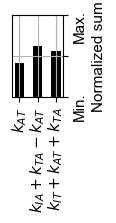

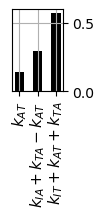

In [105]:

T_lower_r2=0.3
T_higher_r2=0.4
A_lower_r2=0.5
A_higher_r2=0.6
print("visitor, active region:","T_lower=",T_lower_r2,"T_higher=",T_higher_r2,"A_lower=",A_lower_r2,"A_higher=",A_higher_r2)


A_in_region2,I_in_region2,T_in_region2,k_IA_in_region2,k_AI_in_region2,k_AT_in_region2,k_TA_in_region2,k_TI_in_region2,k_IT_in_region2=sel_rates_in_region(I=I,A=A,T=T,T_lower=T_lower_r2,T_higher=T_higher_r2,A_lower=A_lower_r2,A_higher=A_higher_r2,k_IA=k_IA,k_AI=k_AI,k_AT=k_AT,k_TA=k_TA,k_TI=k_TI,k_IT=k_IT)
    
print("Mean, std, min, max of A in region 2:",np.mean(A_in_region2),np.std(A_in_region2),np.min(A_in_region2),np.max(A_in_region2))

print("Mean, std, min, max of I in region 2:",np.mean(I_in_region2),np.std(I_in_region2),np.min(I_in_region2),np.max(I_in_region2))

print("Mean, std, min, max of T in region 2:",np.mean(T_in_region2),np.std(T_in_region2),np.min(T_in_region2),np.max(T_in_region2))

print("##########################################")
print("##########################################")
print("Mean, std, min, max of k_IA in region 2:",np.mean(k_IA_in_region2),np.std(k_IA_in_region2),np.min(k_IA_in_region2),np.max(k_IA_in_region2))

print("Mean, std, min, max of k_AI in region 2:",np.mean(k_AI_in_region2),np.std(k_AI_in_region2),np.min(k_AI_in_region2),np.max(k_AI_in_region2))

print("Mean, std, min, max of k_AT in region 2:",np.mean(k_AT_in_region2),np.std(k_AT_in_region2),np.min(k_AT_in_region2),np.max(k_AT_in_region2))

print("Mean, std, min, max of k_TA in region 2:",np.mean(k_TA_in_region2),np.std(k_TA_in_region2),np.min(k_TA_in_region2),np.max(k_TA_in_region2))

print("Mean, std, min, max of k_TI in region 2:",np.mean(k_TI_in_region2),np.std(k_TI_in_region2),np.min(k_TI_in_region2),np.max(k_TI_in_region2))

print("Mean, std, min, max of k_IT in region 2:",np.mean(k_IT_in_region2),np.std(k_IT_in_region2),np.min(k_IT_in_region2),np.max(T_in_region2))

print("##########################################")
print("##########################################")
print("##########################################")
print("##########################################")
k_IA_r2=np.mean(k_IA_in_region2)
k_AI_r2=np.mean(k_AI_in_region2)
k_AT_r2=np.mean(k_AT_in_region2)
k_TA_r2=np.mean(k_TA_in_region2)
k_TI_r2=np.mean(k_TI_in_region2)
k_IT_r2=np.mean(k_IT_in_region2)

I_r2, A_r2, T_r2 = compute_steady_state(k_IA=k_IA_r2, k_AI=k_AI_r2, k_AT=k_AT_r2, k_TA=k_TA_r2, k_TI=k_TI_r2, k_IT=k_IT_r2)

print("region2 I,A,T:",I_r2, A_r2, T_r2 )
print("Flux I->A:",k_IA_r2*I_r2)
print("Flux A->I:",k_AI_r2*A_r2)
print("Flux A->T:",k_AT_r2*A_r2)
print("Flux T->A:",k_TA_r2*T_r2)
print("Flux T->I:",k_TI_r2*T_r2)
print("Flux I->T:",k_IT_r2*I_r2)

print("k_IA+k_TA-k_AT:",k_IA_r2+k_TA_r2-k_AT_r2)
print("k_IT+k_AT+k_TA:",k_IT_r2+k_AT_r2+k_TA_r2)
print("k_AT:",k_AT_r2)

fig=plt.figure(figsize=(0.65,3.2/3))
ax1 = fig.add_subplot(111)

#normalize values to 0-1
K_1=(k_AT_r2-np.min(k_IA))/(np.max(k_AT)-np.min(k_AT))

K_2_un=k_IA_r2+k_TA_r2-k_AT_r2
K_2_all_un=k_IA+k_TA-k_AT
K_2=(K_2_un-np.min(K_2_all_un))/(np.max(K_2_all_un)-np.min(K_2_all_un))

K_3_un=k_IT_r2+k_AT_r2+k_TA_r2
K_3_all_un=k_IT+k_AT+k_TA
K_3=(K_3_un-np.min(K_3_all_un))/(np.max(K_3_all_un)-np.min(K_3_all_un))


#plt.bar([1,2,3],[-k_AT_r1,k_IA_r1+k_TA_r1-k_AT_r1,k_IT_r1+k_AT_r1+k_TA_r1],width=0.5,color="black")
plt.bar([1,2,3],[K_1,K_2,K_3],width=0.5,color="black")
plt.grid()

#plt.xlim(1,3)
plt.ylim(0,1)

plt.yticks(ticks=[0,0.5,1],labels=["Min.","","Max."] ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.ylabel("Normalized sum" ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.xticks(ticks=[1,2,3],labels=[r"$k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$",r"$k_{IT}+k_{AT}+k_{TA}$"] ,fontname = "Arial",fontsize=11, rotation='vertical') 
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"rates_visitor_active_2.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")


########################
#########################
##########################
########################

fig=plt.figure(figsize=(0.65,3.2/3))
ax1 = fig.add_subplot(111)

#normalize values with other values
K_1_un=k_AT_r2

K_2_un=k_IA_r2+k_TA_r2-k_AT_r2

K_3_un=k_IT_r2+k_AT_r2+k_TA_r2

K_1=K_1_un/(K_1_un+K_2_un+K_3_un)
K_2=K_2_un/(K_1_un+K_2_un+K_3_un)
K_3=K_3_un/(K_1_un+K_2_un+K_3_un)


print("K1",K_1,"K2",K_2,"K3",K_3)

#plt.bar([1,2,3],[-k_AT_r1,k_IA_r1+k_TA_r1-k_AT_r1,k_IT_r1+k_AT_r1+k_TA_r1],width=0.5,color="black")
plt.bar([1,2,3],[K_1,K_2,K_3],width=0.5,color="black")
plt.grid()

#plt.xlim(1,3)
#plt.ylim(0,1)

#plt.yticks(ticks=[0,0.5,1],labels=[0,0.5,1] ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.xticks(ticks=[1,2,3],labels=[r"$k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$",r"$k_{IT}+k_{AT}+k_{TA}$"] ,fontname = "Arial",fontsize=11, rotation='vertical') 

ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"rates_canonical_active_1.pdf"


visitor, inactive region: T_lower= 0.0 T_higher= 0.025 A_lower= 0.7 A_higher= 0.8
Mean, std, min, max of A in region 3: 0.7466216918194382 0.030647607087372686 0.7082026803175215 0.7974013430015335
Mean, std, min, max of I in region 3: 0.23786602659183426 0.027626097744477284 0.19727200769834072 0.2795798309109578
Mean, std, min, max of T in region 3: 0.015512281588727646 0.006066439151035356 0.0053266493001257135 0.02366448168611859
##########################################
##########################################
Mean, std, min, max of k_IA in region 3: 0.6736621675288935 0.24501508684926304 0.12353047568851794 0.9784632188841721
Mean, std, min, max of k_AI in region 3: 0.2147869705344654 0.08773705190757695 0.0322026183591585 0.37701326640103683
Mean, std, min, max of k_AT in region 3: 0.013458350487695708 0.013322869579974765 0.0004494035749127434 0.0385046767628614
Mean, std, min, max of k_TA in region 3: 0.6084583433983678 0.2631234578226508 0.1891073316413484 0.92256345100702

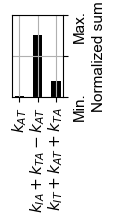

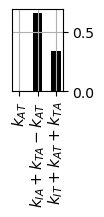

In [106]:

T_lower_r3=0.0    ##0.0
T_higher_r3=0.025 ##0.1
A_lower_r3=0.7
A_higher_r3=0.8
print("visitor, inactive region:","T_lower=",T_lower_r3,"T_higher=",T_higher_r3,"A_lower=",A_lower_r3,"A_higher=",A_higher_r3)


A_in_region3,I_in_region3,T_in_region3,k_IA_in_region3,k_AI_in_region3,k_AT_in_region3,k_TA_in_region3,k_TI_in_region3,k_IT_in_region3=sel_rates_in_region(I=I,A=A,T=T,T_lower=T_lower_r3,T_higher=T_higher_r3,A_lower=A_lower_r3,A_higher=A_higher_r3,k_IA=k_IA,k_AI=k_AI,k_AT=k_AT,k_TA=k_TA,k_TI=k_TI,k_IT=k_IT)
    
print("Mean, std, min, max of A in region 3:",np.mean(A_in_region3),np.std(A_in_region3),np.min(A_in_region3),np.max(A_in_region3))

print("Mean, std, min, max of I in region 3:",np.mean(I_in_region3),np.std(I_in_region3),np.min(I_in_region3),np.max(I_in_region3))

print("Mean, std, min, max of T in region 3:",np.mean(T_in_region3),np.std(T_in_region3),np.min(T_in_region3),np.max(T_in_region3))

print("##########################################")
print("##########################################")
print("Mean, std, min, max of k_IA in region 3:",np.mean(k_IA_in_region3),np.std(k_IA_in_region3),np.min(k_IA_in_region3),np.max(k_IA_in_region3))

print("Mean, std, min, max of k_AI in region 3:",np.mean(k_AI_in_region3),np.std(k_AI_in_region3),np.min(k_AI_in_region3),np.max(k_AI_in_region3))

print("Mean, std, min, max of k_AT in region 3:",np.mean(k_AT_in_region3),np.std(k_AT_in_region3),np.min(k_AT_in_region3),np.max(k_AT_in_region3))

print("Mean, std, min, max of k_TA in region 3:",np.mean(k_TA_in_region3),np.std(k_TA_in_region3),np.min(k_TA_in_region3),np.max(k_TA_in_region3))

print("Mean, std, min, max of k_TI in region 3:",np.mean(k_TI_in_region3),np.std(k_TI_in_region3),np.min(k_TI_in_region3),np.max(k_TI_in_region3))

print("Mean, std, min, max of k_IT in region 3:",np.mean(k_IT_in_region3),np.std(k_IT_in_region3),np.min(k_IT_in_region3),np.max(T_in_region3))

print("##########################################")
print("##########################################")
print("##########################################")
print("##########################################")
k_IA_r3=np.mean(k_IA_in_region3)
k_AI_r3=np.mean(k_AI_in_region3)
k_AT_r3=np.mean(k_AT_in_region3)
k_TA_r3=np.mean(k_TA_in_region3)
k_TI_r3=np.mean(k_TI_in_region3)
k_IT_r3=np.mean(k_IT_in_region3)

I_r3, A_r3, T_r3 = compute_steady_state(k_IA=k_IA_r3, k_AI=k_AI_r3, k_AT=k_AT_r3, k_TA=k_TA_r3, k_TI=k_TI_r3, k_IT=k_IT_r3)

print("region3 I,A,T:",I_r3, A_r3, T_r3 )
print("Flux I->A:",k_IA_r3*I_r3)
print("Flux A->I:",k_AI_r3*A_r3)
print("Flux A->T:",k_AT_r3*A_r3)
print("Flux T->A:",k_TA_r3*T_r3)
print("Flux T->I:",k_TI_r3*T_r3)
print("Flux I->T:",k_IT_r3*I_r3)

print("k_IA+k_TA-k_AT:",k_IA_r3+k_TA_r3-k_AT_r3)
print("k_IT+k_AT+k_TA:",k_IT_r3+k_AT_r3+k_TA_r3)
print("k_AT:",k_AT_r3)

fig=plt.figure(figsize=(0.65,3.2/3))
ax1 = fig.add_subplot(111)

#normalize values to 0-1
K_1=(k_AT_r3-np.min(k_IA))/(np.max(k_AT)-np.min(k_AT))

K_2_un=k_IA_r3+k_TA_r3-k_AT_r3
K_2_all_un=k_IA+k_TA-k_AT
K_2=(K_2_un-np.min(K_2_all_un))/(np.max(K_2_all_un)-np.min(K_2_all_un))

K_3_un=k_IT_r3+k_AT_r3+k_TA_r3
K_3_all_un=k_IT+k_AT+k_TA
K_3=(K_3_un-np.min(K_3_all_un))/(np.max(K_3_all_un)-np.min(K_3_all_un))


#plt.bar([1,2,3],[-k_AT_r1,k_IA_r1+k_TA_r1-k_AT_r1,k_IT_r1+k_AT_r1+k_TA_r1],width=0.5,color="black")
plt.bar([1,2,3],[K_1,K_2,K_3],width=0.5,color="black")
plt.grid()

#plt.xlim(1,3)
plt.ylim(0,1)

plt.yticks(ticks=[0,0.5,1],labels=["Min.","","Max."] ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.ylabel("Normalized sum" ,fontname = "Arial",fontsize=11, rotation='vertical')  
plt.xticks(ticks=[1,2,3],labels=[r"$k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$",r"$k_{IT}+k_{AT}+k_{TA}$"] ,fontname = "Arial",fontsize=11, rotation='vertical') 

ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"rates_visitor_inactive_2.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")


########################
#########################
##########################
########################

fig=plt.figure(figsize=(0.65,3.2/3))
ax1 = fig.add_subplot(111)

#normalize values with other values
K_1_un=k_AT_r3

K_2_un=k_IA_r3+k_TA_r3-k_AT_r3

K_3_un=k_IT_r3+k_AT_r3+k_TA_r3

K_1=K_1_un/(K_1_un+K_2_un+K_3_un)
K_2=K_2_un/(K_1_un+K_2_un+K_3_un)
K_3=K_3_un/(K_1_un+K_2_un+K_3_un)


print("K1",K_1,"K2",K_2,"K3",K_3)

#plt.bar([1,2,3],[-k_AT_r1,k_IA_r1+k_TA_r1-k_AT_r1,k_IT_r1+k_AT_r1+k_TA_r1],width=0.5,color="black")
plt.bar([1,2,3],[K_1,K_2,K_3],width=0.5,color="black")
plt.grid()

#plt.xlim(1,3)
#plt.ylim(0,1)

#plt.yticks(ticks=[0,0.5,1],labels=[0,0.5,1] ,fontname = "Arial",fontsize=11, rotation='vertical') 
plt.xticks(ticks=[1,2,3],labels=[r"$k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$",r"$k_{IT}+k_{AT}+k_{TA}$"] ,fontname = "Arial",fontsize=11, rotation='vertical') 

ax1.yaxis.tick_right()
ax1.yaxis.set_label_position("right")

name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"rates_canonical_active_1.pdf"


In [95]:
I_r123=[I_r1,I_r2,I_r3]
A_r123=[A_r1,A_r2,A_r3]
T_r123=[T_r1,T_r2,T_r3]


Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0010733321960998


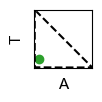

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.5029874719401934


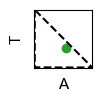

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5002674434694555


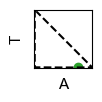

In [96]:
#plot solution in 3-state heatmap
parameter_c=[k_IA +k_TA , k_IT+k_AT+k_TA, k_AT,-k_AT,k_IA+k_TA-k_AT,1-k_AT]


label_c=[r"$k_{IA}+k_{TA}$ ", r"$k_{IT}+k_{AT}+k_{TA}$", r"$k_{AT}$",r"$-k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$ ",r"$1-k_{AT}$"]

plot_signals_1=parameter_c

labels_signals_1=label_c

#colorbar for locally averaged plot
#cutoff 95 for viridis
#cutoff False for parula
colorbar_cutoff_1=[False for e in plot_signals_1] #[95,95,95,95,95,95,95,95,95,95,95,95,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=A
RNA_data=T

for k in range(len(I_r123[:])):
   

    Signal_data=parameter_c[k] 
    drop_zeros=drop_zeros_1[k]
    n_neighbors=75
    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    #fig=plt.figure(figsize=(3.2/3,3.2/3)) #larger to include colorscale
    fig=plt.figure(figsize=(0.75,0.75))
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff_1[k]!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff_1[k])
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_1[k]!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale_1[k])
    #sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1, rasterized=True,cmap=parula_cmap)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2[k]!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2[k])
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2[k]!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2[k])


    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    
    T_rs=scaler_1_RNA.transform(np.array([T_r123[k]]).reshape(-1,1)).flatten()
    A_rs=scaler_1_Serin5P.transform(np.array([A_r123[k]]).reshape(-1,1)).flatten()

    ax1.scatter([A_rs],[T_rs])
    

    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("T", size=11, fontname="Arial")
    plt.xlabel("A", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    

    
    plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=[],labels=[] ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=[],labels=[] ,fontname = "Arial",fontsize=11) 

    ax1.set_aspect(1./ax1.get_data_ratio())
    

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"2d_plot_representative_design_" +str(k)+"_2.pdf"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_4.pdf",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
    plt.show()

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0010733321960998


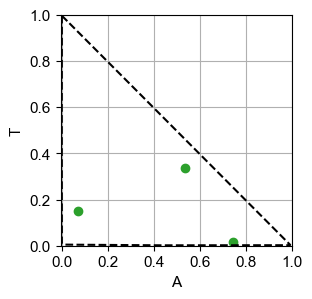

In [97]:
#plot location of all example solutions in gene map
parameter_c=[k_IA +k_TA , k_IT+k_AT+k_TA, k_AT,-k_AT,k_IA+k_TA-k_AT,1-k_AT]


label_c=[r"$k_{IA}+k_{TA}$ ", r"$k_{IT}+k_{AT}+k_{TA}$", r"$k_{AT}$",r"$-k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$ ",r"$1-k_{AT}$"]

plot_signals_1=parameter_c

labels_signals_1=label_c

#colorbar for locally averaged plot
#cutoff 95 for viridis
#cutoff False for parula
colorbar_cutoff_1=[False for e in plot_signals_1] #[95,95,95,95,95,95,95,95,95,95,95,95,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=A
RNA_data=T


fig=plt.figure(figsize=(3,3))

Signal_data=parameter_c[0] 
drop_zeros=drop_zeros_1[0]
n_neighbors=75
all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


def S5P_trf(x):
    return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

def RNA_trf(x):
    return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

#fig=plt.figure(figsize=(3,3)) #standard
#fig=plt.figure(figsize=(3.2/3,3.2/3)) #larger to include colorscale
ax1 = fig.add_subplot(111)

vmax2=None
if colorbar_cutoff_1[k]!=False:

    vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff_1[k])

color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
if colorbar_power_scale_1[k]!=False:
    color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale_1[k])
#sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1, rasterized=True,cmap=parula_cmap)

#option to plot all trf data:
vmax4=None
if colorbar_cutoff_2[k]!=False:

    vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2[k])

color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
if colorbar_power_scale_2[k]!=False:
    color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2[k])


#get lables
ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")

T_rs=scaler_1_RNA.transform(np.array(T_r123).reshape(-1,1)).flatten()
A_rs=scaler_1_Serin5P.transform(np.array(A_r123).reshape(-1,1)).flatten()

ax1.scatter([A_rs],[T_rs])


#generate convex hull
hull_t=scipy.spatial.ConvexHull(all_data_x_y)
ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')

plt.ylabel("T", size=11, fontname="Arial")
plt.xlabel("A", size=11, fontname="Arial")
plt.grid()


lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()


up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05



plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)


#plt.yticks(ticks=[],labels=[] ,fontname = "Arial",fontsize=11) 
#plt.xticks(ticks=[],labels=[] ,fontname = "Arial",fontsize=11) 
plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

ax1.set_aspect(1./ax1.get_data_ratio())


name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"2d_plot_all_representative_designs_1.pdf"

#plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.pdf",format="png",dpi=300,bbox_inches="tight")
#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
#plt.show()

# 3-state parameter combinations

Screen for potential parameter combinations in the 3-state model that produce heatmap patterns, matching those observed genome wide

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.000810462752741779


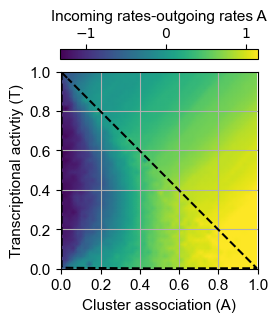

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.0015362261593487225


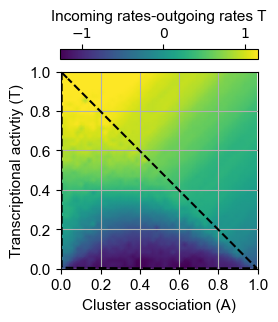

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.002346688912090502


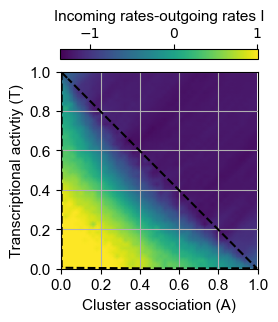

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.000810462752741779


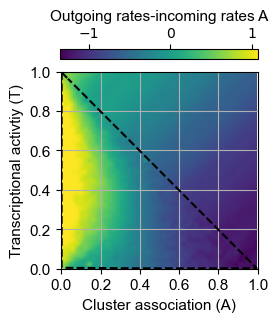

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.0015362261593487225


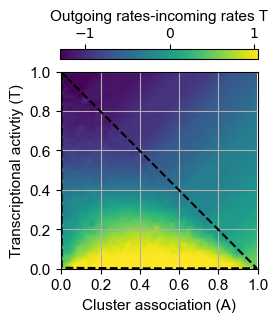

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.002346688912090502


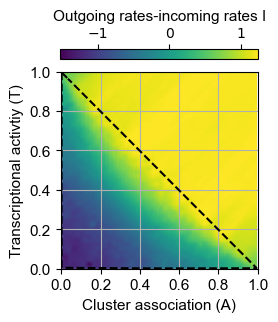

In [98]:
parameter_c=[(k_IA+k_TA)-(k_AI+k_AT), (k_AT+k_IT)-(k_TA+k_TI), (k_TI+k_AI)-(k_IT+k_IA),
            (k_AI+k_AT)-(k_IA+k_TA), (k_TA+k_TI)-(k_AT+k_IT), (k_IT+k_IA)-(k_TI+k_AI)]

#label_c=["Influx-Outflux A","Influx-Outflux T","Influx-Outflux I",
#        "Outflux-Influx A","Outflux-Influx T","Outflux-Influx I"]
label_c=["Incoming rates-outgoing rates A","Incoming rates-outgoing rates T","Incoming rates-outgoing rates I",
        "Outgoing rates-incoming rates A","Outgoing rates-incoming rates T","Outgoing rates-incoming rates I"]

plot_signals_1=parameter_c

labels_signals_1=label_c

#colorbar for locally averaged plot
colorbar_cutoff_1=[95,95,95,95,95,95,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=A
RNA_data=T

for k in range(len(plot_signals_1[:])):
    
    Signal_data=parameter_c[k]
    drop_zeros=drop_zeros_1[k]
    n_neighbors=75
    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff_1[k]!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff_1[k])
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_1[k]!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale_1[k])
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2[k]!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2[k])
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2[k]!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2[k])
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=labels_signals_1[k],size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        
    #plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    #plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    ax1.set_aspect(1./ax1.get_data_ratio())
    

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_5/2d_plots/"+"2d_plot_" +str(labels_signals_1[k])+"_2.png"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
    plt.show()

In [99]:
print(np.min(x_ticks_set1_trf))
print(np.min(y_ticks_set1_trf))

-2.1297068931045575
-2.131725894730497


Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0010733321960998


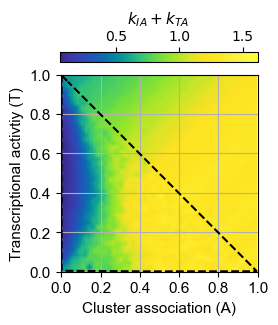

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.5029874719401934


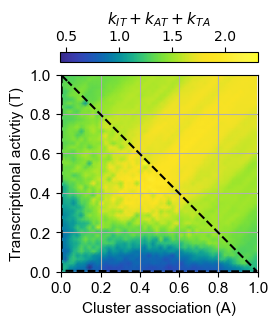

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5002674434694555


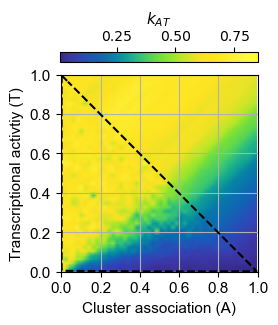

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.5002674434694555


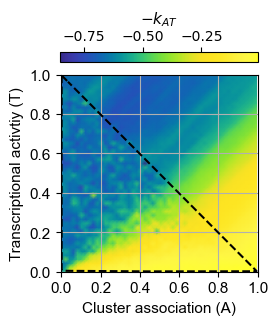

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5008058887266446


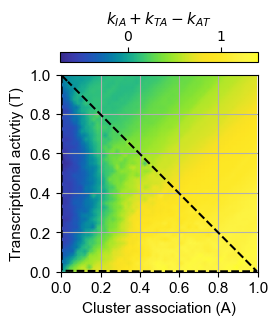

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.49973255653054455


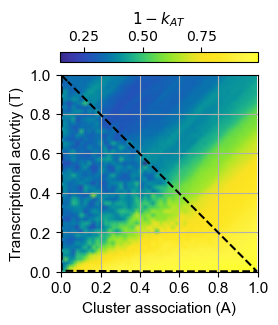

In [100]:
#parameter_c=[(k_IA*I+k_TA*T)-(k_AI*A+k_AT*A), (k_AT*A+k_IT*I)-(k_TA*T+k_TI*T), (k_TI*T+k_AI*A)-(k_IT*I+k_IA*I),
#            (k_AI*A+k_AT*A)-(k_IA*I+k_TA*T), (k_TA*T+k_TI*T)-(k_AT*A+k_IT*I), (k_IT*I+k_IA*I)-(k_TI*T+k_AI*A)]



#norm_k=k_IA+ k_AI+ k_AT+ k_TA+ k_TI+ k_IT

#parameter_c=[k_IA/norm_k, k_AI/norm_k, k_AT/norm_k, k_TA/norm_k, k_TI/norm_k, k_IT/norm_k]
parameter_c=[k_IA +k_TA , k_IT+k_AT+k_TA, k_AT,-k_AT,k_IA+k_TA-k_AT,1-k_AT]

#parameter_c=[k_IT+k_AT]
#label_c=["k_IA","k_AI","k_AT","k_TA","k_TI","k_IT"]
#label_c=["Influx-Outflux A","Influx-Outflux T","Influx-Outflux I",
#        "Outflux-Influx A","Outflux-Influx T","Outflux-Influx I"]
label_c=[r"$k_{IA}+k_{TA}$ ", r"$k_{IT}+k_{AT}+k_{TA}$", r"$k_{AT}$",r"$-k_{AT}$",r"$k_{IA}+k_{TA}-k_{AT}$ ",r"$1-k_{AT}$"]

plot_signals_1=parameter_c

labels_signals_1=label_c

#colorbar for locally averaged plot
#cutoff 95 for viridis
#cutoff False for parula
colorbar_cutoff_1=[False for e in plot_signals_1] #[95,95,95,95,95,95,95,95,95,95,95,95,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=A
RNA_data=T

for k in range(len(plot_signals_1[:])):
    
    Signal_data=parameter_c[k] 
    drop_zeros=drop_zeros_1[k]
    n_neighbors=75
    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff_1[k]!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff_1[k])
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_1[k]!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale_1[k])
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1, rasterized=True,cmap=parula_cmap)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2[k]!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2[k])
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2[k]!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2[k])
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=labels_signals_1[k],size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        
    #plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    #plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    ax1.set_aspect(1./ax1.get_data_ratio())
    

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"2d_plot_" +str(labels_signals_1[k])+"_3.png"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.pdf",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=1000,bbox_inches="tight")
    plt.show()

In [101]:
#screen many potential rate combinations
# --- metrics builder ---
def build_metrics(k_IA, k_AI, k_AT, k_TA, k_TI, k_IT, I=None, A=None, T=None, use_steady_state=True):
    """
    Build a catalog (OrderedDict) of meaningful combinations of rates and probabilities.
    If use_steady_state=True and I/A/T are None, compute steady-state probabilities.
    Works with scalars or NumPy arrays; returns an OrderedDict with arrays of the same shape.
    """
    # Convert to arrays for vectorized ops
    k_IA = np.array(k_IA, dtype=float)
    k_AI = np.array(k_AI, dtype=float)
    k_AT = np.array(k_AT, dtype=float)
    k_TA = np.array(k_TA, dtype=float)
    k_TI = np.array(k_TI, dtype=float)
    k_IT = np.array(k_IT, dtype=float)

    # Probabilities
    if I is None or A is None or T is None:
        if use_steady_state:
            I, A, T = steady_state_probs(k_IA, k_AI, k_AT, k_TA, k_TI, k_IT)
        else:
            raise ValueError("Provide I, A, T when use_steady_state=False")
    else:
        I = np.array(I, dtype=float)
        A = np.array(A, dtype=float)
        T = np.array(T, dtype=float)

    metrics = OrderedDict()

    # --- Raw rates ---
    metrics['k_IA'] = k_IA
    metrics['k_AI'] = k_AI
    metrics['k_AT'] = k_AT
    metrics['k_TA'] = k_TA
    metrics['k_TI'] = k_TI
    metrics['k_IT'] = k_IT
    
    metrics['-k_IA'] = -k_IA
    metrics['-k_AI'] = -k_AI
    metrics['-k_AT'] = -k_AT
    metrics['-k_TA'] = -k_TA
    metrics['-k_TI'] = -k_TI
    metrics['-k_IT'] = -k_IT

    # --- Probability-weighted singles ---
    metrics['k_IA*I'] = k_IA * I
    metrics['k_AI*A'] = k_AI * A
    metrics['k_AT*A'] = k_AT * A
    metrics['k_TA*T'] = k_TA * T
    metrics['k_TI*T'] = k_TI * T
    metrics['k_IT*I'] = k_IT * I

    # --- Simple sums ---
    metrics['(k_IA+k_TA)'] = k_IA + k_TA
    metrics['(k_AI+k_AT)'] = k_AI + k_AT
    
    metrics['(k_IT+k_AT)'] = k_IT + k_AT
    metrics['(k_TI+k_TA)'] = k_TI + k_TA
    
    metrics['(k_TI+k_AI)'] = k_TI + k_AI
    metrics['(k_IT+k_IA)'] = k_IT + k_IA
    
    #metrics['(k_IA+k_AI+k_AT+k_TA)'] = k_IA + k_AI + k_AT + k_TA

    # --- Probability-weighted sums ---
    metrics['(k_IA*I+k_TA*T)'] = k_IA*I + k_TA*T
    metrics['(k_AI*A+k_AT*A)'] = k_AI*A + k_AT*A
    
    metrics['(k_IT*I+k_AT*A)'] = k_IT*I + k_AT*A
    metrics['(k_TI*T+k_TA*T)'] = k_TI*T + k_TA*T
    
    metrics['(k_TI*T+k_AI*A)'] = k_TI*T + k_AI*A
    metrics['(k_IT*I+k_IA*I)'] = k_IT*I + k_IA*I
    
    # --- Biases (raw) ---
    metrics['bias_A_raw'] = (k_IA + k_TA) - (k_AI + k_AT)
    metrics['bias_T_raw'] = (k_AT + k_IT) - (k_TA + k_TI)
    metrics['bias_I_raw'] = (k_AI + k_TI) - (k_IA + k_IT)
    
    metrics['-bias_A_raw'] = -((k_IA + k_TA) - (k_AI + k_AT))
    metrics['-bias_T_raw'] = -((k_AT + k_IT) - (k_TA + k_TI))
    metrics['-bias_I_raw'] = -((k_AI + k_TI) - (k_IA + k_IT))
    # --- Biases (probability-weighted) ---
    # NOTE: At steady state these will be ~0
    #metrics['bias_A_pw'] = (k_IA*I + k_TA*T) - (k_AI*A + k_AT*A)
    #metrics['bias_T_pw'] = (k_AT*A + k_IT*I) - (k_TA*T + k_TI*T)
    #metrics['bias_I_pw'] = (k_AI*A + k_TI*T) - (k_IA*I + k_IT*I)

    # --- Pairwise net fluxes (non-zero in non-equilibrium steady states) ---
    #f_IA = k_IA*I - k_AI*A
    #f_AT = k_AT*A - k_TA*T
    #f_TI = k_TI*T - k_IT*I
    #metrics['flux_I->A'] = f_IA
    #metrics['flux_A->T'] = f_AT
    #metrics['flux_T->I'] = f_TI
    #metrics['cycle_flux_mean'] = (f_IA + f_AT + f_TI) / 3.0
    #metrics['cycle_flux_absmean'] = (np.abs(f_IA) + np.abs(f_AT) + np.abs(f_TI)) / 3.0

    # --- Ratio-based biases & detailed balance cycle check ---
    eps = 1e-12  # avoid divide-by-zero
    metrics['ratio_IA_AI'] = (k_IA + eps) / (k_AI + eps)
    metrics['ratio_AT_TA'] = (k_AT + eps) / (k_TA + eps)
    metrics['ratio_TI_IT'] = (k_TI + eps) / (k_IT + eps)
    #metrics['log_ratio_cycle'] = (np.log(metrics['ratio_IA_AI']) +
    #                              np.log(metrics['ratio_AT_TA']) +
    #                              np.log(metrics['ratio_TI_IT']))
    #db_cycle = metrics['ratio_IA_AI'] * metrics['ratio_AT_TA'] * metrics['ratio_TI_IT']
    #metrics['db_cycle'] = db_cycle
    #metrics['db_cycle_minus_1'] = db_cycle - 1.0

    # --- Include explicit forms ---
    metrics['((k_AT)/(k_AT+k_IT))'] = ((k_AT)/(k_AT+k_IT))
    metrics['((k_AT*A)/(k_AT*A+k_IT*I))'] = ((k_AT*A)/(k_AT*A+k_IT*I))
    metrics['(k_AT-k_TA)'] = k_AT-k_TA
    metrics['(k_IA-k_AI)'] = k_IA-k_AI
    metrics['(k_IT-k_TI)'] = k_IT-k_TI
    
    metrics['(k_TA-k_AT)'] = k_TA-k_AT
    metrics['(k_AI-k_IA)'] = k_AI-k_IA
    metrics['(k_TI-k_IT)'] = k_TI-k_IT
    
    metrics['(k_IT+k_TA+k_AT)'] = k_IT+k_TA+k_AT
    metrics['(k_IT*I+k_TA*T+k_AT*A)'] = k_IT*I+k_TA*T+k_AT*A
    metrics['(k_TI+k_IA-k_AT)'] = k_TI+k_IA-k_AT
    metrics['(k_IA-k_AT)'] = k_IA-k_AT
    metrics['(k_IA+k_TA-k_AT)'] = k_IA+k_TA-k_AT
    metrics['(k_IA*I+k_TA*T-k_AT*A)'] = k_IA*I+k_TA*T-k_AT*A
    
    metrics['1-k_AT'] = 1-k_AT

    
    #three rates driving system to T
    metrics['(k_IT+k_IA+k_AT)'] = k_IT+k_IA+k_AT
    metrics['(k_IT*I+k_IA*I+k_AT*A)'] = k_IT*I+k_IA*I+k_AT*A
    metrics['(k_IT+k_IA+k_AT)-(k_TI+k_AI+k_TA)'] = (k_IT+k_IA+k_AT)-(k_TI+k_AI+k_TA)
    metrics['(k_IT*I+k_IA*I+k_AT*A)-(k_TI*T+k_AI*A+k_TA*T)'] = (k_IT*I+k_IA*I+k_AT*A)-(k_TI*T+k_AI*A+k_TA*T)
    
    #three rates driving system to I
    metrics['(k_TI+k_AI+k_TA)'] = k_TI+k_AI+k_TA
    metrics['(k_TI*T+k_AI*A+k_TA*T)'] = k_TI*T+k_AI*A+k_TA*T
    metrics['(k_TI+k_AI+k_TA)-(k_IT+k_IA+k_AT)'] = (k_TI+k_AI+k_TA)-(k_IT+k_IA+k_AT)
    metrics['(k_TI*T+k_AI*A+k_TA*T)-(k_IT*I+k_IA*I+k_AT*A)'] = (k_TI*T+k_AI*A+k_TA*T)-(k_IT*I+k_IA*I+k_AT*A)
      
    #three rates driving system to A
    metrics['(k_IA+k_IT+k_TA)'] = k_IA+k_IT+k_TA
    metrics['(k_IA*I+k_IT*I+k_TA*T)'] = (k_IA*I+k_IT*I+k_TA*T)
    metrics['(k_IA+k_IT+k_TA)-(k_AI+k_TI+k_AT)'] = (k_IA+k_IT+k_TA)-(k_AI+k_TI+k_AT)
    metrics['(k_IA*I+k_IT*I+k_TA*T)-(k_AI*A+k_TI*T+k_AT*A)'] = (k_IA*I+k_IT*I+k_TA*T)-(k_AI*A+k_TI*T+k_AT*A)
    
    #local flow split
    metrics['k_IA/(k_IA+k_IT)'] = k_IA/(k_IA+k_IT)
    metrics['k_AI/(k_AI+k_AT)'] = k_AI/(k_AI+k_AT)
    metrics['k_AT/(k_AT+k_AI)'] = k_AT/(k_AT+k_AI)
    metrics['k_TA/(k_TA+k_TI)'] = k_TA/(k_TA+k_TI)
    metrics['k_TI/(k_TI+k_TA)'] = k_TI/(k_TI+k_TA)
    metrics['k_IT/(k_IT+k_IA)'] = k_IT/(k_IT+k_IA)
    
    #product of edge rates toriented toward I,A,T
    metrics["k_AI*k_TA + k_AI*k_TI + k_AT*k_TI"]=k_AI*k_TA + k_AI*k_TI + k_AT*k_TI
    metrics["k_IA*k_TA + k_IA*k_TI + k_IT*k_TA"]=k_IA*k_TA + k_IA*k_TI + k_IT*k_TA
    metrics["k_AI*k_IT + k_AT*k_IA + k_AT*k_IT"]=k_AI*k_IT + k_AT*k_IA + k_AT*k_IT

    #contributions to edge rates oriented toward I,A,T
    
    metrics["k_AI*k_TA/(k_AI*k_TA + k_AI*k_TI + k_AT*k_TI)"]=k_AI*k_TA/(k_AI*k_TA + k_AI*k_TI + k_AT*k_TI)
    metrics["k_AI*k_TI/(k_AI*k_TA + k_AI*k_TI + k_AT*k_TI)"]=k_AI*k_TI/(k_AI*k_TA + k_AI*k_TI + k_AT*k_TI)
    metrics["k_AT*k_TI/(k_AI*k_TA + k_AI*k_TI + k_AT*k_TI)"]=k_AT*k_TI/(k_AI*k_TA + k_AI*k_TI + k_AT*k_TI)

    metrics["k_IA*k_TA/(k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)"]=k_IA*k_TA/(k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)
    metrics["k_IA*k_TI/(k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)"]=k_IA*k_TI/(k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)
    metrics["k_IT*k_TA/(k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)"]=k_IT*k_TA/(k_IA*k_TA + k_IA*k_TI + k_IT*k_TA)
    
    metrics["k_AI*k_IT/(k_AI*k_IT + k_AT*k_IA + k_AT*k_IT)"]=k_AI*k_IT/(k_AI*k_IT + k_AT*k_IA + k_AT*k_IT)
    metrics["k_AT*k_IA/(k_AI*k_IT + k_AT*k_IA + k_AT*k_IT)"]=k_AT*k_IA/(k_AI*k_IT + k_AT*k_IA + k_AT*k_IT)
    metrics["k_AT*k_IT/(k_AI*k_IT + k_AT*k_IA + k_AT*k_IT)"]=k_AT*k_IT/(k_AI*k_IT + k_AT*k_IA + k_AT*k_IT)

    #metrics['((k_IA+k_TA)-(k_AI+k_AT))'] = metrics['bias_A_raw']
    #metrics['(k_IA*I+k_TA*T)-(k_AI*A+k_AT*A)'] = metrics['bias_A_pw']

    return metrics


Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5006249366621588


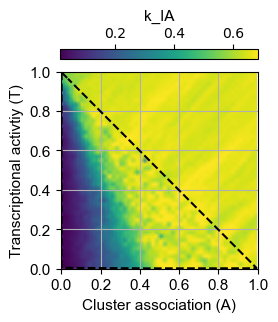

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.49999542597390273


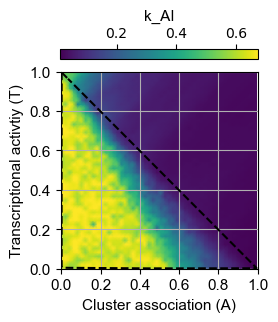

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5002674434694555


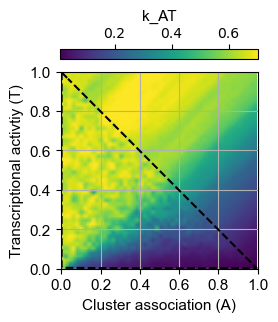

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5004483955339413


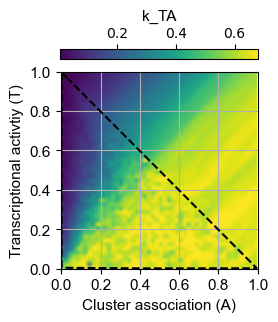

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5005544547129624


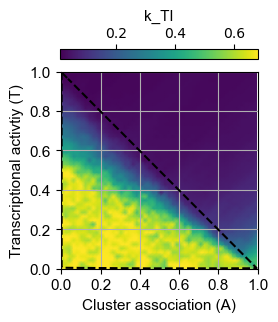

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5022716329367968


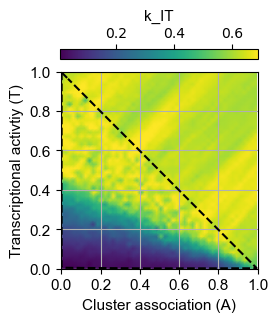

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.5006249366621588


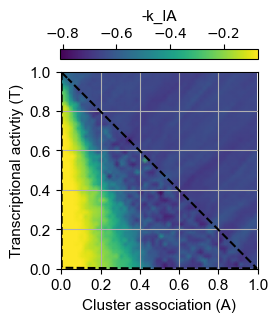

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.49999542597390273


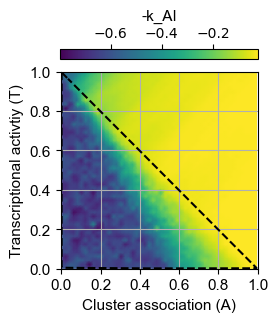

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.5002674434694555


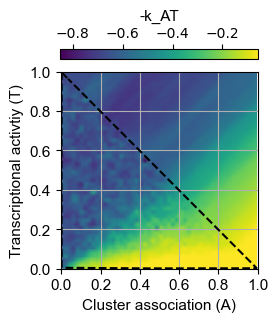

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.5004483955339413


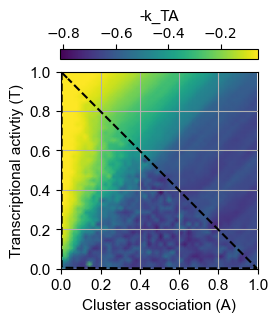

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.5005544547129624


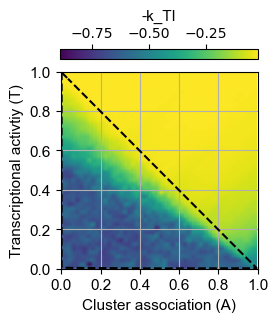

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.5022716329367968


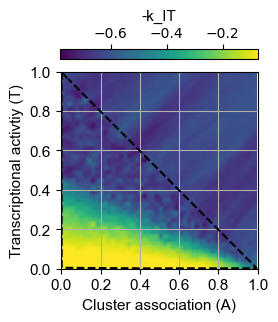

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.14550884634136033


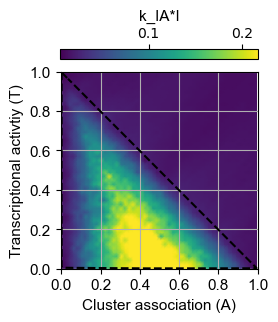

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.14573100078386064


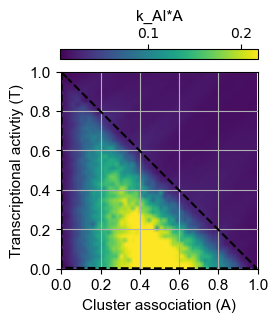

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.1455293079211512


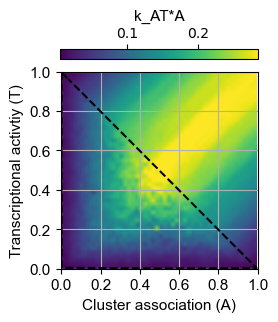

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.14575146236365155


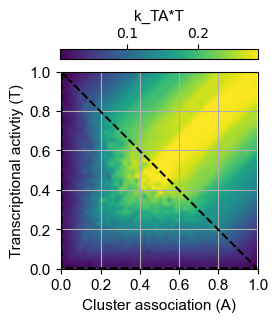

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.14583595372999186


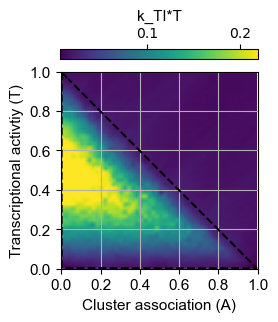

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.14605810817249223


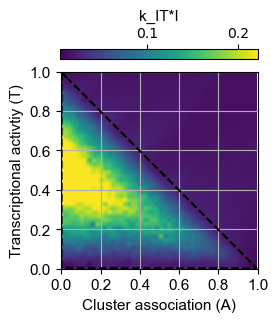

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0010733321960998


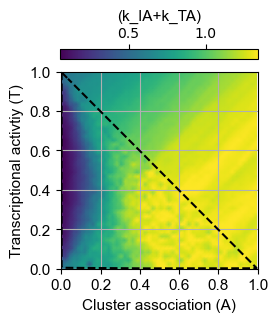

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.000262869443358


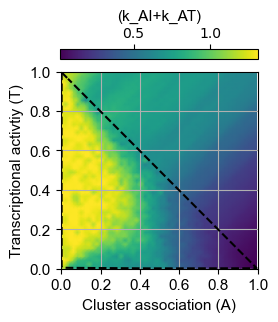

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0025390764062525


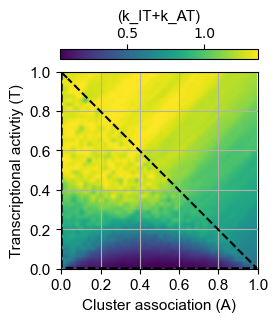

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0010028502469035


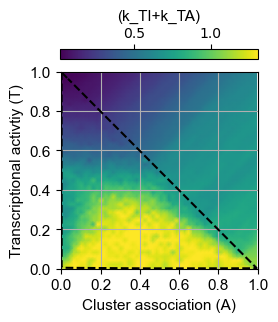

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0005498806868651


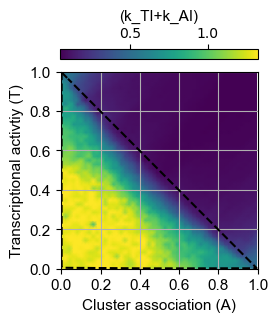

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.0028965695989558


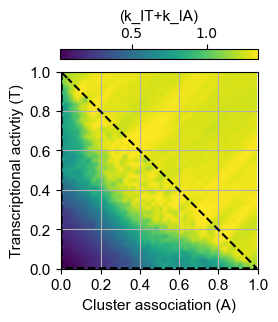

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.29126030870501185


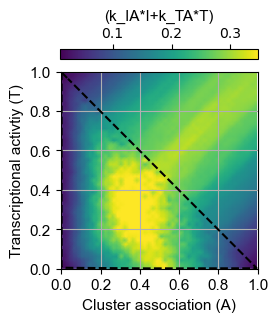

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.29126030870501185


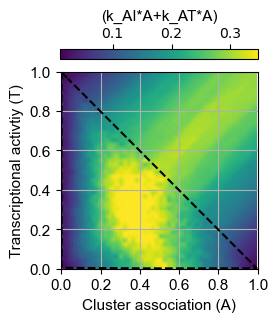

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2915874160936434


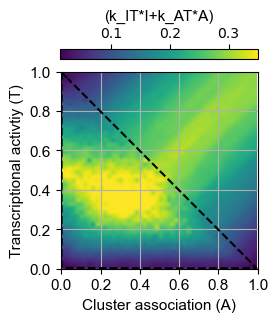

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2915874160936434


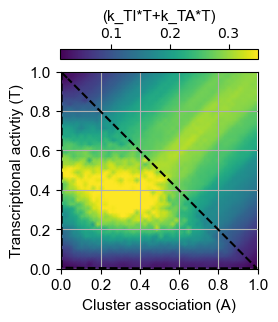

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2915669545138525


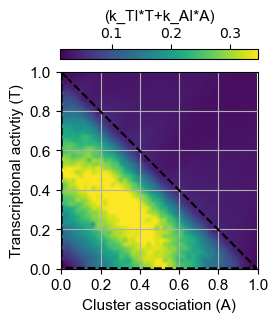

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2915669545138525


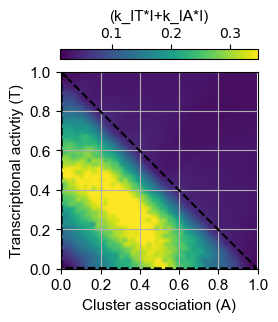

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.000810462752741779


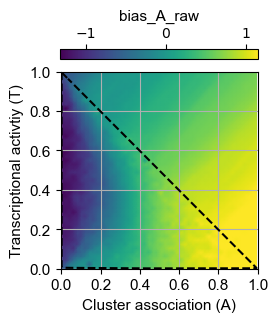

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.0015362261593487225


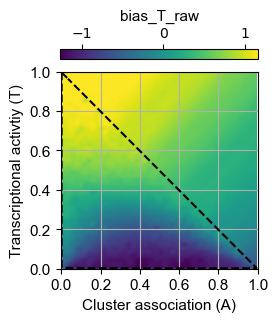

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.002346688912090502


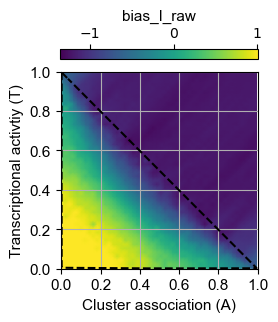

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.000810462752741779


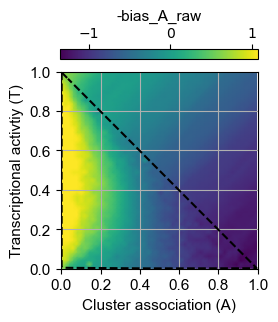

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.0015362261593487225


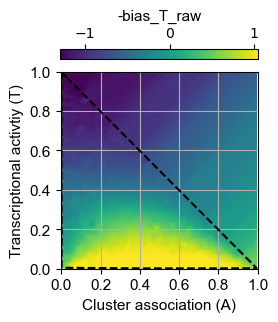

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.002346688912090502


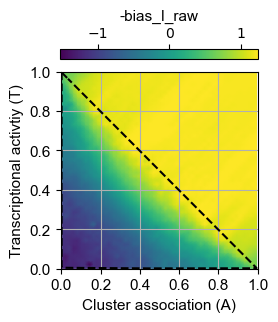

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 6.0372619096985956


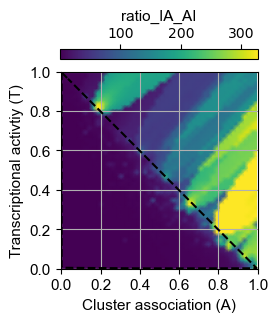

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 7.04956125115613


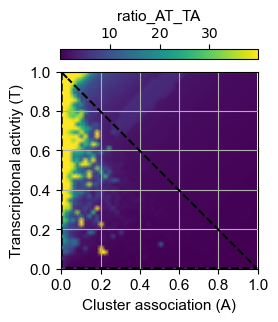

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 5.660659982874659


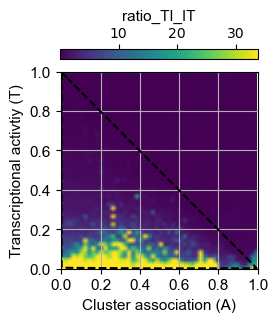

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.49862421394975803


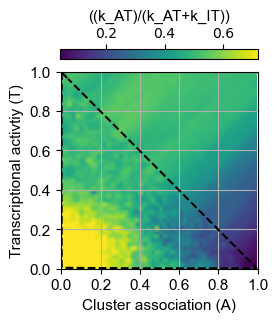

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.49917143548849474


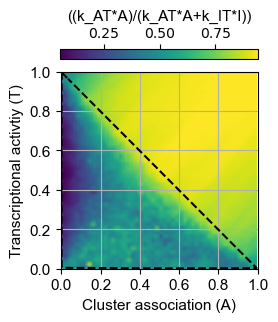

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.00018095206448580364


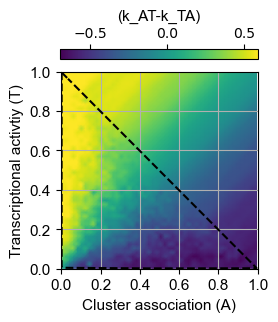

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.0006295106882559758


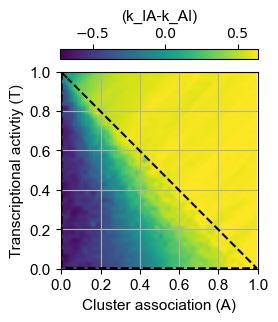

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.0017171782238345262


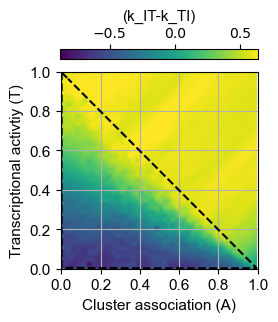

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.00018095206448580364


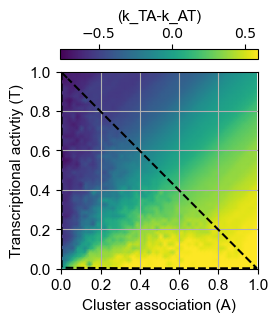

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.0006295106882559758


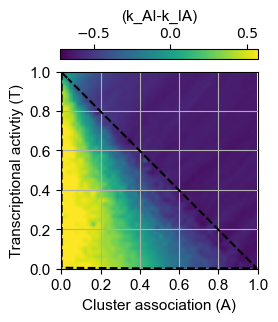

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.0017171782238345262


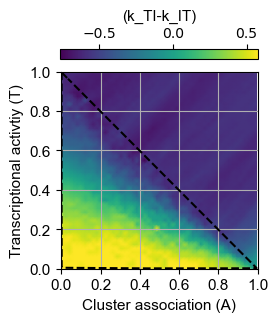

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.5029874719401934


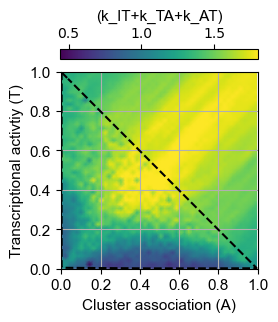

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4373388784572949


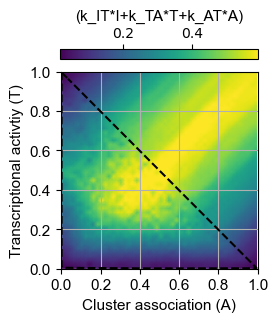

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5009119479056656


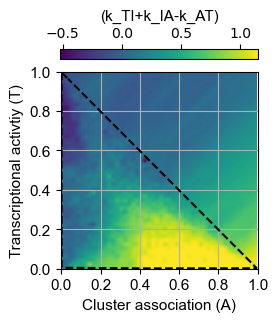

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.00035749319270328515


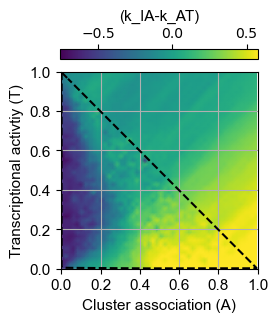

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5008058887266446


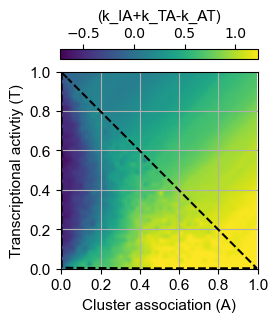

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.14573100078386064


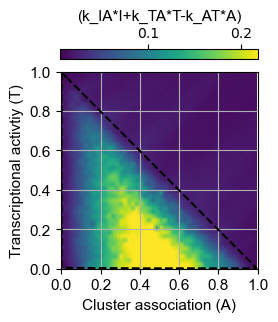

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.49973255653054455


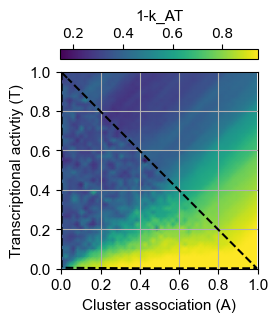

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.5031640130684112


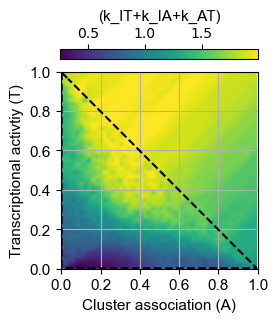

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.43709626243500366


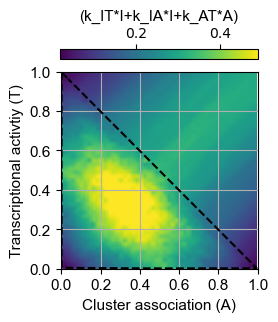

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.002165736847604699


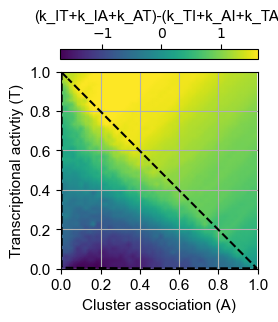

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.00022215444250034435


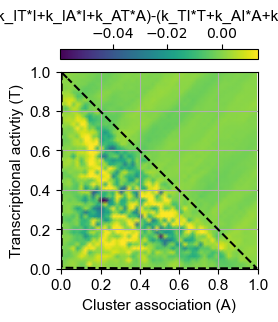

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.500998276220806


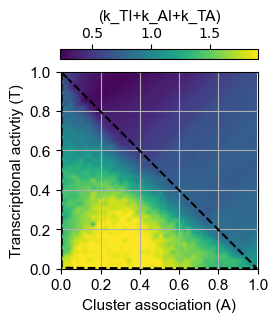

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4373184168775041


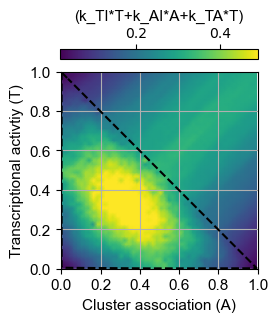

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: -0.002165736847604699


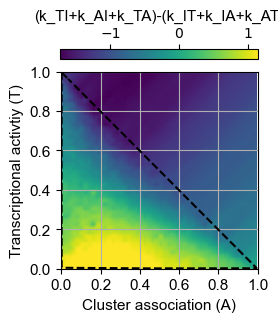

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.00022215444250034435


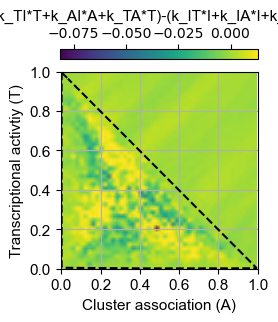

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 1.503344965132897


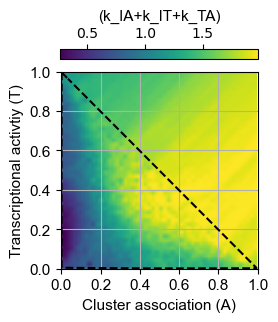

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4373184168775041


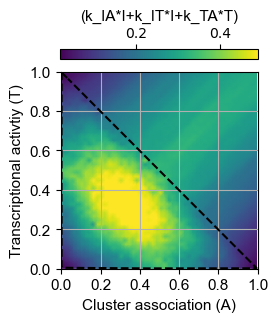

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.002527640976576306


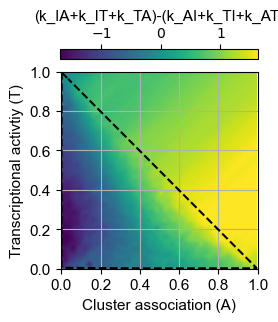

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.00022215444250034462


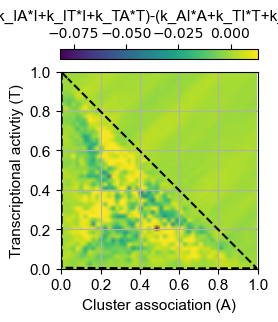

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4991059366226623


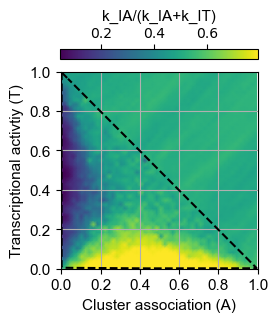

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5001655223710698


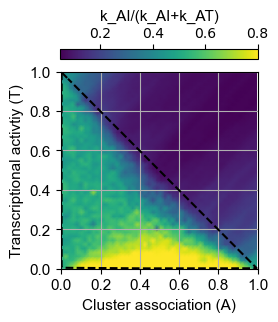

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4998344776289302


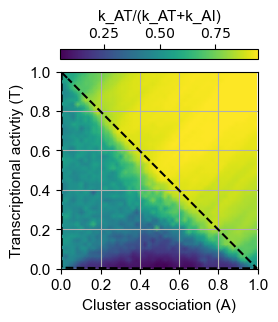

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4998349000397426


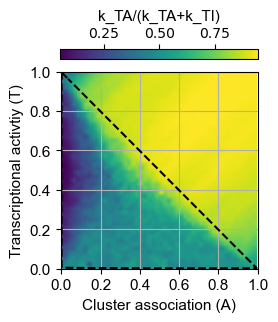

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5001650999602574


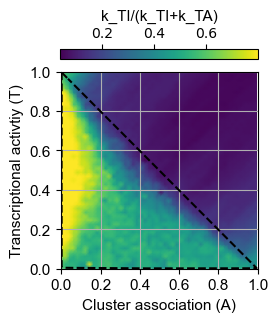

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5008940633773376


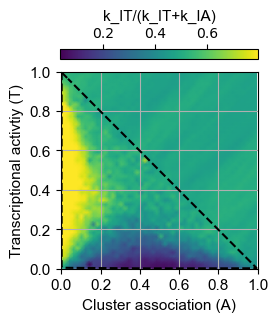

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.7511276072822489


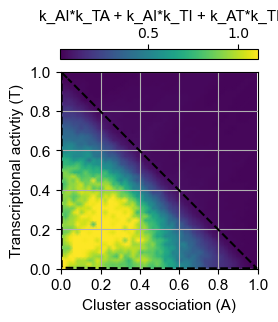

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.7520359657932518


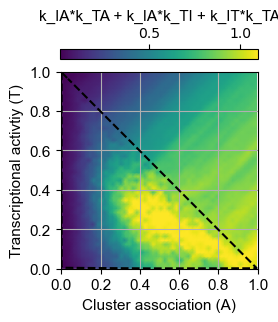

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.7528811945908132


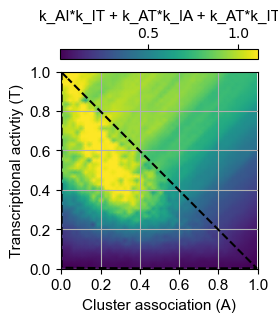

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.3490232129169324


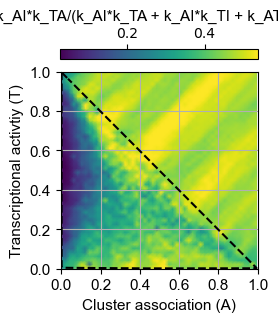

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.30211704703155823


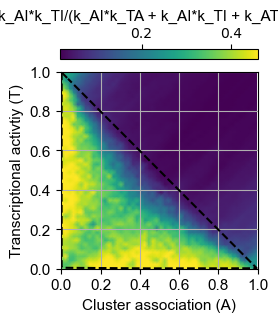

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.3488597400515094


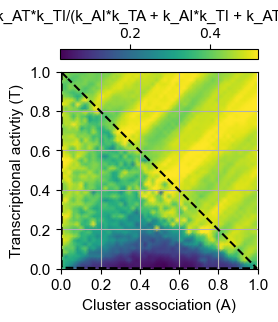

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.30151470548012876


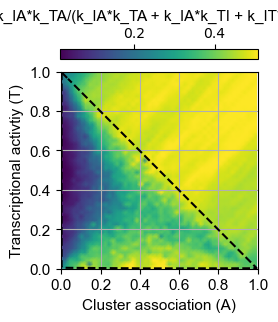

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.3486636032861873


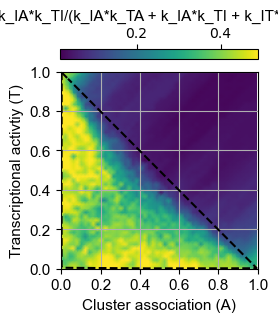

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.34982169123368395


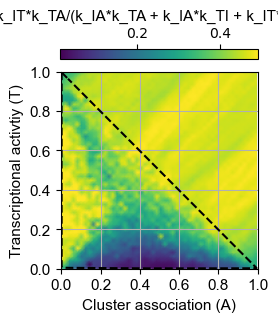

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.3497755273545089


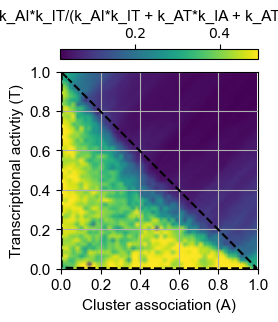

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.34806807777370313


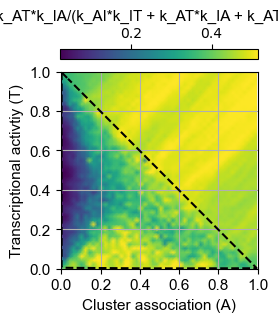

Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.3021563948717881


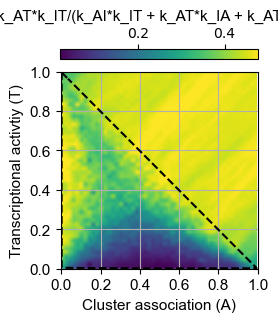

In [102]:
#use metric builder to visualise various parameter combinations

#parameter_c=[(k_IA*I+k_TA*T)-(k_AI*A+k_AT*A), (k_AT*A+k_IT*I)-(k_TA*T+k_TI*T), (k_TI*T+k_AI*A)-(k_IT*I+k_IA*I),
#            (k_AI*A+k_AT*A)-(k_IA*I+k_TA*T), (k_TA*T+k_TI*T)-(k_AT*A+k_IT*I), (k_IT*I+k_IA*I)-(k_TI*T+k_AI*A)]



#norm_k=k_IA+ k_AI+ k_AT+ k_TA+ k_TI+ k_IT

#parameter_c=[k_IA/norm_k, k_AI/norm_k, k_AT/norm_k, k_TA/norm_k, k_TI/norm_k, k_IT/norm_k]
parameter_c=[k_IA *I , k_AT*A, k_TI *T]

#parameter_c=[k_IT+k_AT]
#label_c=["k_IA","k_AI","k_AT","k_TA","k_TI","k_IT"]
#label_c=["Influx-Outflux A","Influx-Outflux T","Influx-Outflux I",
#        "Outflux-Influx A","Outflux-Influx T","Outflux-Influx I"]
label_c=["k_IA *I ", "k_AT  *A", "k_TI *T"]

plot_signals_1=parameter_c

labels_signals_1=label_c

#colorbar for locally averaged plot
colorbar_cutoff_1=[95,95,95,95,95,95,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]

#colorbar for scatter plot
colorbar_cutoff_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[False,False,False,False,False,False,False,False]
colorbar_power_scale_2=[False,False,False,False,False,False,False,False,False,False,False,False,False]        #[0.4,0.4,0.4,0.4,False,False,False,False]


drop_zeros_1=[False,False,False,False,False,False,False,False,False,False,False,False,False]

S5P_data=A
RNA_data=T

metrics_test=build_metrics(k_IA, k_AI, k_AT, k_TA, k_TI, k_IT, I, A, T, use_steady_state=True)

#store heatmap plot data for later use
name_list=[]
all_data_x_y_list=[]
fit_data_x_y_list=[]
grid_x_list=[]
grid_y_list=[]
KNR_model_pred_r_list=[]
RNA_1_scaled_1_list=[]
Serin5P_1_scaled_1_list=[]
scaler_1_Serin5P_list=[]
scaler_1_RNA_list=[]

for key,values in metrics_test.items():
    
    Signal_data=values
    drop_zeros=False #drop_zeros_1[k]
    n_neighbors=75
    colorbar_cutoff=95
    colorbar_cutoff_2=False
    colorbar_power_scale=False
    colorbar_power_scale_2=False

    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff)
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale)
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2)
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2)
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=key,size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        
    #plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    #plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    #to plot right boundary need to lower xlim slightly
    plt.xlim(np.min(x_ticks_set1_trf)-0.03,up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    ax1.set_aspect(1./ax1.get_data_ratio())
    
    
    #append heat map data
    name_list.append(key)
    all_data_x_y_list.append(all_data_x_y)
    fit_data_x_y_list.append(fit_data_x_y)
    grid_x_list.append(grid_x)
    grid_y_list.append(grid_y)
    KNR_model_pred_r_list.append(KNR_model_pred_r)
    RNA_1_scaled_1_list.append(RNA_1_scaled_1)
    Serin5P_1_scaled_1_list.append(Serin5P_1_scaled_1)
    scaler_1_Serin5P_list.append(scaler_1_Serin5P)
    scaler_1_RNA_list.append(scaler_1_RNA)

    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_5/2d_plots/"+"2d_plot_" +str(key)+"_2.png"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
    plt.show()

#add heatmap data to dict and then convert to df
three_state_model_metrics_dict={"name":name_list,
                     "all_data_x_y":all_data_x_y_list,
                     "fit_data_x_y":fit_data_x_y_list,
                     "grid_x":grid_x_list,
                     "grid_y":grid_y_list,
                     "KNR_model_pred_r":KNR_model_pred_r_list,
                     "RNA_1_scaled_1":RNA_1_scaled_1_list,
                     "Serin5P_1_scaled_1":Serin5P_1_scaled_1_list,
                     "scaler_1_Serin5P":scaler_1_Serin5P_list,
                     "scaler_1_RNA":scaler_1_RNA_list}

three_state_model_metrics_df=pd.DataFrame(three_state_model_metrics_dict)

In [115]:
#evaluate the similarity between heatmaps produced from genome wide data and from the 3-state model

def minmax_normalize(img: np.ndarray) -> np.ndarray:
    """Scale image to [0, 1] per-array (global min/max)."""
    img = img.astype(np.float64)
    minv, maxv = np.min(img), np.max(img)
    if maxv == minv:
        # Avoid division by zero: return zeros (no contrast) in this corner-case
        return np.zeros_like(img, dtype=np.float64)
    return (img - minv) / (maxv - minv)

def zscore_normalize(img: np.ndarray) -> np.ndarray:
    """Standardize image to zero mean, unit variance per-array."""
    img = img.astype(np.float64)
    mean, std = np.mean(img), np.std(img)
    if std == 0:
        # No variance: return zeros
        return np.zeros_like(img, dtype=np.float64)
    return (img - mean) / std

def compare_sim_heatmaps_1(df_heatmap1,df_heatmap2,limit_convex_hull=False,both_convex_hulls=False,normalise=True):
    #get signal name and signal values from df1,df2, normalize signal values

    names1 = df_heatmap1["name"].astype(str).tolist()
    names2 = df_heatmap2["name"].astype(str).tolist()
    
    
    if limit_convex_hull==False:
        if normalise==True:
            signal1 = [ minmax_normalize(x) for x in df_heatmap1["KNR_model_pred_r"].tolist() ]
            signal2 = [ minmax_normalize(x) for x in df_heatmap2["KNR_model_pred_r"].tolist() ]
        if normalise==False:
            signal1 = df_heatmap1["KNR_model_pred_r"].tolist() 
            signal2 = df_heatmap2["KNR_model_pred_r"].tolist() 
    #option to set signal points outside convex hull to zero
    if limit_convex_hull==True:
        if normalise==True:
            signal1_list =[ minmax_normalize(x) for x in df_heatmap1["KNR_model_pred_r"].tolist() ]
            signal2_list =[ minmax_normalize(x) for x in df_heatmap2["KNR_model_pred_r"].tolist() ]
        
        if normalise==False:
            signal1_list = df_heatmap1["KNR_model_pred_r"].tolist() 
            signal2_list = df_heatmap2["KNR_model_pred_r"].tolist() 
        #print(signal1_list[0].shape)
        #print(signal2_list[0].shape)
        grid_x1_list = df_heatmap1["grid_x"].tolist() 
        grid_x2_list = df_heatmap2["grid_x"].tolist() 
       
        grid_y1_list = df_heatmap1["grid_y"].tolist()
        grid_y2_list = df_heatmap2["grid_y"].tolist() 

        all_data_x_y1_list = df_heatmap1["all_data_x_y"].tolist() 
        all_data_x_y2_list = df_heatmap2["all_data_x_y"].tolist() 
        
        if both_convex_hulls==False:
            signal1=[set_points_outside_convex_hull_1(all_data_x_y1_list[e],grid_x1_list[e],grid_y1_list[e],signal1_list[e],0) for e in np.arange(len(signal1_list)) ]
            signal2=[set_points_outside_convex_hull_1(all_data_x_y2_list[e],grid_x2_list[e],grid_y2_list[e],signal2_list[e],0) for e in np.arange(len(signal2_list)) ]
            #print(signal1[0].shape)
            #print(signal2[0].shape)
        
        if both_convex_hulls==True:
            #points outside convex hull set to missing value
            #only keep points where  bot signals are != missing value (intersection of convex hulls)
            missing_val = -700
            signal1_u=[set_points_outside_convex_hull_1(all_data_x_y1_list[e],grid_x1_list[e],grid_y1_list[e],signal1_list[e],missing_val) for e in np.arange(len(signal1_list)) ]
            signal2_u=[set_points_outside_convex_hull_1(all_data_x_y2_list[e],grid_x2_list[e],grid_y2_list[e],signal2_list[e],missing_val) for e in np.arange(len(signal2_list)) ]
            
                    
            # Create mask: True where either signal heatmap has missing_val
            #mask will be the same for all signals
            mask = (signal1_u[0] == missing_val) | (signal2_u[0] == missing_val)

            # Set those positions to zero in both arrays
            #print(mask)
            signal1=[]
            for i in range(len(signal1_u)):
                e=signal1_u[i].copy()
                e[mask]=0 #np.random.rand()#0
                signal1.append(e)
            signal2=[]
            for i in range(len(signal2_u)):
                e=signal2_u[i].copy()
                e[mask]=0 #np.random.rand()#0
                signal2.append(e)
                


        
        for k in range(len(grid_x1_list)):
            all_data_x_y,grid_x, grid_y, KNR_model_pred_r=all_data_x_y1_list[k],grid_x1_list[k],grid_y1_list[k],signal1[k]
            plt.pcolormesh(grid_x, grid_y, KNR_model_pred_r)
            hull_t=scipy.spatial.ConvexHull(all_data_x_y)
            plt.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
            plt.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
            plt.show()
        for k in range(len(grid_x2_list)):
            all_data_x_y,grid_x, grid_y, KNR_model_pred_r=all_data_x_y2_list[k],grid_x2_list[k],grid_y2_list[k],signal2[k]
            plt.pcolormesh(grid_x, grid_y, KNR_model_pred_r)
            hull_t=scipy.spatial.ConvexHull(all_data_x_y)
            plt.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
            plt.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
            plt.show()
    # Compute SSIM matrix
    mat = np.zeros((len(signal1), len(signal2)), dtype=float)
    # Compute pearson correlation
    mat2 = np.zeros((len(signal1), len(signal2)), dtype=float)
    #compute RMSE
    mat3 = np.zeros((len(signal1), len(signal2)), dtype=float)
    #compute cosine similarity
    mat4 = np.zeros((len(signal1), len(signal2)), dtype=float)
    for i, im1 in enumerate(signal1):
        for j, im2 in enumerate(signal2):
            #print(im1.shape)
            #print(im2.shape)
            
            #ssim
            val = ssim(
                im1, im2,
                data_range=1,
                win_size=None,
                gaussian_weights=None,
                channel_axis=None
            )
            mat[i, j] = float(val)
            
            #pearson corr
            pr=scipy.stats.pearsonr(im1.flatten(),im2.flatten())
            val2=pr.statistic
            mat2[i, j] = float(val2)
    
            #rmse
            rmse=np.sqrt( np.mean(( im1.flatten()-im2.flatten() )**2) )
            mat3[i, j] = float(rmse)
            
            #cosine similarity
            denom = np.linalg.norm(im1.flatten()) * np.linalg.norm(im2.flatten())
            coss=np.dot(im1.flatten(), im2.flatten()) / denom
            mat4[i, j] = float(coss)

    # Build DataFrame with labeled axes
    ssim_df = pd.DataFrame(mat, index=names1, columns=names2)
   
    pearson_df = pd.DataFrame(mat2, index=names1, columns=names2)
   
    rmse_df = pd.DataFrame(mat3, index=names1, columns=names2)
    
    coss_df=pd.DataFrame(mat4, index=names1, columns=names2)
    
    #process heatmap data for later use (e.g. set entries outside convex hull to zero)
    #dict contains heatmap data
    processed_signal_1=dict(zip(names1, signal1))
    processed_signal_2=dict(zip(names2, signal2))

    return ssim_df,pearson_df,rmse_df,coss_df,processed_signal_1,processed_signal_2

#Version 2: exclude all values not inside intersection of convex hulls
def compare_sim_heatmaps_2(df_heatmap1,df_heatmap2,limit_convex_hull=False,both_convex_hulls=False,normalise=True):
    #get signal name and signal values from df1,df2, normalize signal values

    names1 = df_heatmap1["name"].astype(str).tolist()
    names2 = df_heatmap2["name"].astype(str).tolist()
    
    missing_val = -700
    if limit_convex_hull==False:
        if normalise==True:
            signal1 = [ minmax_normalize(x) for x in df_heatmap1["KNR_model_pred_r"].tolist() ]
            signal2 = [ minmax_normalize(x) for x in df_heatmap2["KNR_model_pred_r"].tolist() ]
        if normalise==False:
            signal1 = df_heatmap1["KNR_model_pred_r"].tolist() 
            signal2 = df_heatmap2["KNR_model_pred_r"].tolist() 
    #option to set signal points outside convex hull to zero
    if limit_convex_hull==True:
        if normalise==True:
            signal1_list =[ minmax_normalize(x) for x in df_heatmap1["KNR_model_pred_r"].tolist() ]
            signal2_list =[ minmax_normalize(x) for x in df_heatmap2["KNR_model_pred_r"].tolist() ]
        
        if normalise==False:
            signal1_list = df_heatmap1["KNR_model_pred_r"].tolist() 
            signal2_list = df_heatmap2["KNR_model_pred_r"].tolist() 
        #print(signal1_list[0].shape)
        #print(signal2_list[0].shape)
        grid_x1_list = df_heatmap1["grid_x"].tolist() 
        grid_x2_list = df_heatmap2["grid_x"].tolist() 
       
        grid_y1_list = df_heatmap1["grid_y"].tolist()
        grid_y2_list = df_heatmap2["grid_y"].tolist() 

        all_data_x_y1_list = df_heatmap1["all_data_x_y"].tolist() 
        all_data_x_y2_list = df_heatmap2["all_data_x_y"].tolist() 

        if both_convex_hulls==False:
            signal1=[set_points_outside_convex_hull_1(all_data_x_y1_list[e],grid_x1_list[e],grid_y1_list[e],signal1_list[e],0) for e in np.arange(len(signal1_list)) ]
            signal2=[set_points_outside_convex_hull_1(all_data_x_y2_list[e],grid_x2_list[e],grid_y2_list[e],signal2_list[e],0) for e in np.arange(len(signal2_list)) ]
            #print(signal1[0].shape)
            #print(signal2[0].shape)
        
        if both_convex_hulls==True:
            #points outside convex hull set to missing value
            #only keep points where  bot signals are != missing value (intersection of convex hulls)
            
            signal1_u=[set_points_outside_convex_hull_1(all_data_x_y1_list[e],grid_x1_list[e],grid_y1_list[e],signal1_list[e],missing_val) for e in np.arange(len(signal1_list)) ]
            signal2_u=[set_points_outside_convex_hull_1(all_data_x_y2_list[e],grid_x2_list[e],grid_y2_list[e],signal2_list[e],missing_val) for e in np.arange(len(signal2_list)) ]
            
                    
            # Create mask: True where either signal heatmap has missing_val
            #mask will be the same for all signals
            mask = (signal1_u[0] == missing_val) | (signal2_u[0] == missing_val)

            # Set those positions to zero in both arrays
            #print(mask)
            signal1=[]
            for i in range(len(signal1_u)):
                e=signal1_u[i].copy()
                e[mask]=missing_val #0 #np.random.rand()#0
                signal1.append(e)
            signal2=[]
            for i in range(len(signal2_u)):
                e=signal2_u[i].copy()
                e[mask]=missing_val #0 #np.random.rand()#0
                signal2.append(e)
                


        
        for k in range(len(grid_x1_list)):
            all_data_x_y,grid_x, grid_y, KNR_model_pred_r=all_data_x_y1_list[k],grid_x1_list[k],grid_y1_list[k],signal1[k]
            plt.pcolormesh(grid_x, grid_y, KNR_model_pred_r)
            hull_t=scipy.spatial.ConvexHull(all_data_x_y)
            plt.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
            plt.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
            plt.colorbar()
            plt.show()
        for k in range(len(grid_x2_list)):
            all_data_x_y,grid_x, grid_y, KNR_model_pred_r=all_data_x_y2_list[k],grid_x2_list[k],grid_y2_list[k],signal2[k]
            plt.pcolormesh(grid_x, grid_y, KNR_model_pred_r)
            hull_t=scipy.spatial.ConvexHull(all_data_x_y)
            plt.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
            plt.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
            plt.colorbar()
            plt.show()
    # Compute SSIM matrix
    mat = np.zeros((len(signal1), len(signal2)), dtype=float)
    # Compute pearson correlation
    mat2 = np.zeros((len(signal1), len(signal2)), dtype=float)
    #compute RMSE
    mat3 = np.zeros((len(signal1), len(signal2)), dtype=float)
    #compute cosine similarity
    mat4 = np.zeros((len(signal1), len(signal2)), dtype=float)
    for i, im1 in enumerate(signal1):
        for j, im2 in enumerate(signal2):
            #print(im1.shape)
            #print(im2.shape)
            #print(im2)
            
            #ssim
            val = ssim(
                im1, im2,
                data_range=1,
                win_size=None,
                gaussian_weights=None,
                channel_axis=None
            )
            mat[i, j] = float(val)
            

            mask = im1 != missing_val        # Create mask for entries outside convex hull
            im1_f = im1[mask]
            im2_f = im2[mask]
        

            #pearson corr
            pr=scipy.stats.pearsonr(im1_f,im2_f)
            val2=pr.statistic
            mat2[i, j] = float(val2)
    
            #rmse
            rmse=np.sqrt( np.mean(( im1_f-im2_f )**2) )
            mat3[i, j] = float(rmse)
            
            #cosine similarity
            denom = np.linalg.norm(im1_f) * np.linalg.norm(im2_f)
            coss=np.dot(im1_f, im2_f) / denom
            mat4[i, j] = float(coss)

    # Build DataFrame with labeled axes
    ssim_df = pd.DataFrame(mat, index=names1, columns=names2)
   
    pearson_df = pd.DataFrame(mat2, index=names1, columns=names2)
   
    rmse_df = pd.DataFrame(mat3, index=names1, columns=names2)
    
    coss_df=pd.DataFrame(mat4, index=names1, columns=names2)
    
    #process heatmap data for later use (e.g. set entries outside convex hull to zero)
    #dict contains heatmap data
    processed_signal_1=dict(zip(names1, signal1))
    processed_signal_2=dict(zip(names2, signal2))

    return ssim_df,pearson_df,rmse_df,coss_df,processed_signal_1,processed_signal_2

#set points outside convex hull of all_data_x_y to a value
def set_points_outside_convex_hull_1(all_data_x_y,grid_x,grid_y,z_values,set_to_value=0):
            # Build convex hull
        hull = scipy.spatial.ConvexHull(all_data_x_y)
        hull_coords = all_data_x_y[hull.vertices]  # ordered vertices around the hull

        # Create a Path from the hull polygon
        hull_path = matplotlib.path.Path(hull_coords)

        # Flatten grid coordinates into (N, 2) points
        points = np.column_stack([grid_x.ravel(), grid_y.ravel()])

        # Test each grid point: True if inside hull (or on edge), False otherwise
        # The 'radius' parameter can be used to include boundary points robustly.
        inside_mask_flat = hull_path.contains_points(points, radius=1e-12)
        inside_mask = inside_mask_flat.reshape(grid_x.shape)

        # Set values outside the hull to zero
        z_values_masked = z_values.copy()
        z_values_masked[~inside_mask] = set_to_value
        return z_values_masked
    
#visually highlight top ranked patterns
def highlight_top_k(s, k=3, color="#ffcc80"):  # orange highlight
    # Rank values in descending order
    ranks = s.rank(method="min", ascending=False)
    return [f"background-color: {color}" if r <= k else "" for r in ranks]

#visually highlight bottom ranked patterns
def highlight_bottom_k(s, k=3, color="#ffcc80"):  # orange highlight
    # Rank values in descending order
    ranks = s.rank(method="min", ascending=True)
    return [f"background-color: {color}" if r <= k else "" for r in ranks]



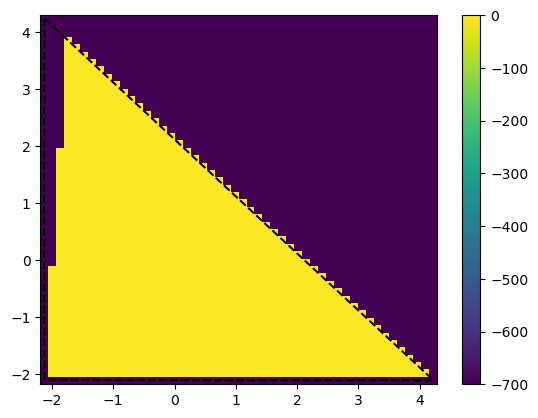

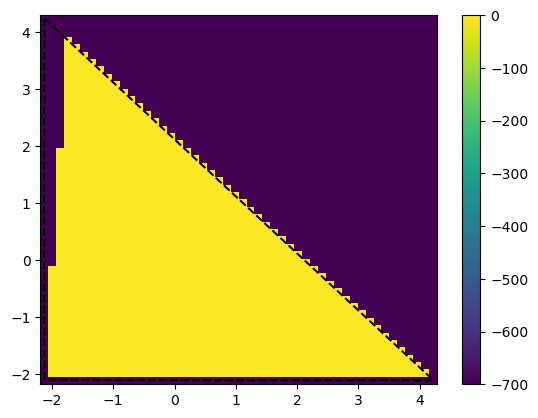

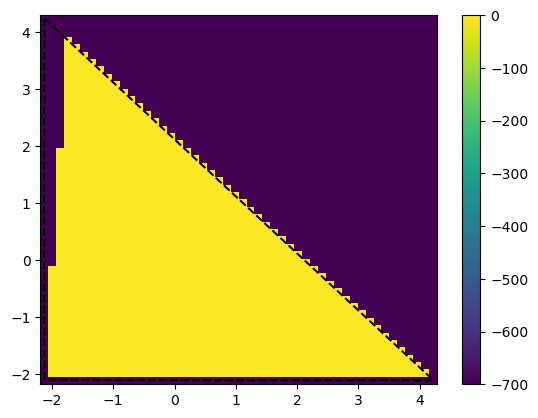

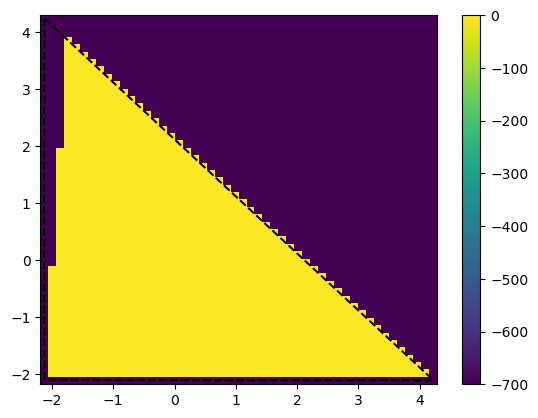

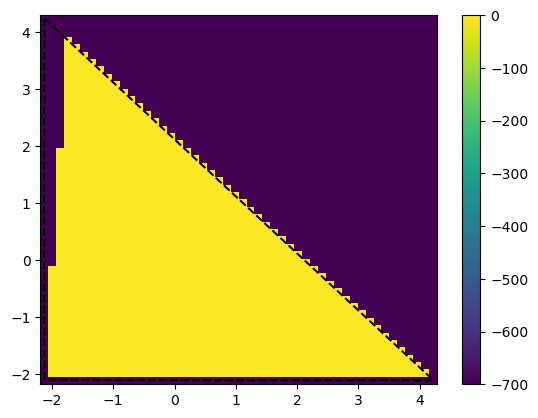

...

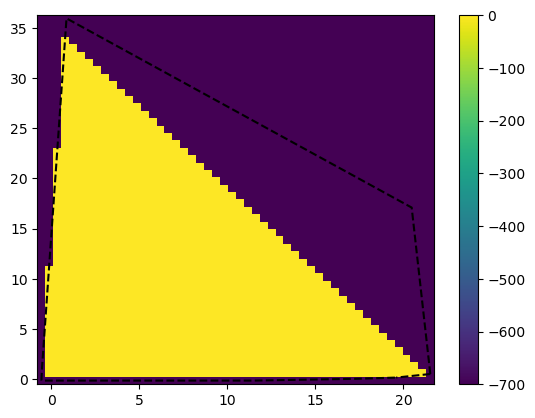

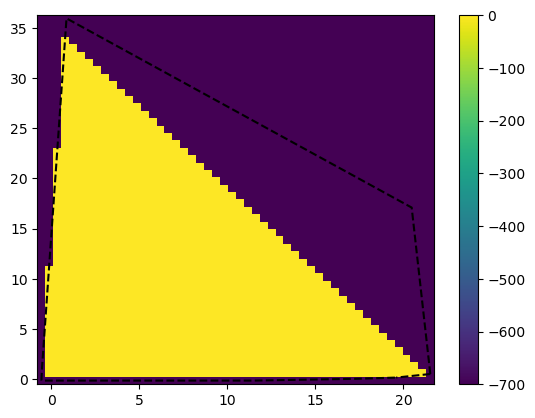

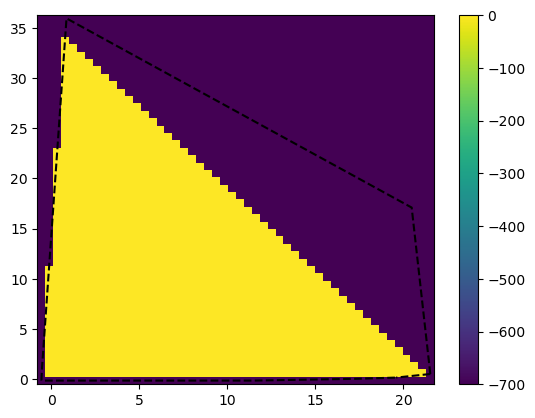

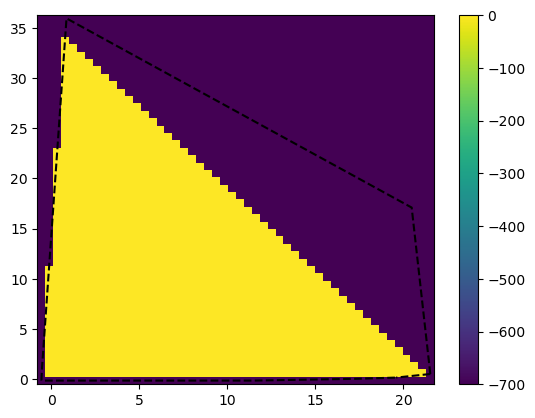

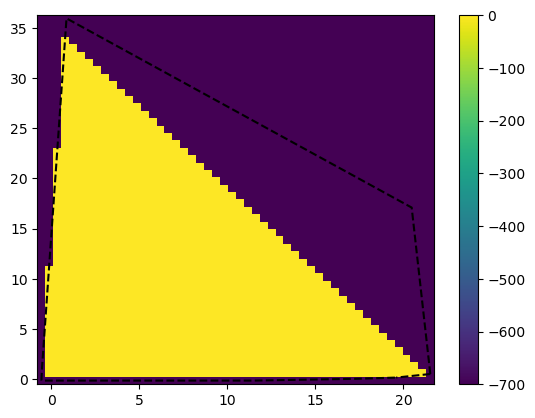

In [104]:
ssim_matrix_test,pearson_corr_matrix_test,rmse_matrix_test,coss_matrix_test,processed_signal_model,processed_signal_chipseq=compare_sim_heatmaps_2(df_heatmap1=three_state_model_metrics_df,df_heatmap2=S5P_RNA_heatmap_df,limit_convex_hull=True,both_convex_hulls=True,normalise=True)

In [107]:
# check if there are reoccurring, rates/rate combinations that are ranked as similar to genome-wide patters
# use different similarity metrics
# data inherently noisy, focus on simple rate combinations when similar rank as more complex ones


In [105]:
#ssim_matrix_test
ssim_matrix_test.style.apply(highlight_top_k, axis=0, k=3)

,Mean coverage H3K27ac,Mean coverage H3K4me3,Mean coverage ATAC-Seq,Mean coverage Nanog,Mean coverage Pou5f3,Mean coverage Sox19b,Mean coverage BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Hi-C contact genes - S5P peaks,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
k_IA,0.749446,0.761299,0.754951,0.740769,0.730386,0.737123,0.653110,0.702734,0.712741,0.722461,0.697928,0.689916,0.724134,0.743802,0.736312
k_AI,0.673133,0.653882,0.672986,0.664990,0.682822,0.685785,0.723162,0.686803,0.689319,0.694696,0.687465,0.694423,0.674339,0.675147,0.675523
k_AT,0.664366,0.744437,0.652885,0.699441,0.609420,0.622483,0.831006,0.606183,0.625935,0.668569,0.605799,0.609955,0.623362,0.620425,0.751332
k_TA,0.763540,0.754774,0.760174,0.716982,0.748992,0.760115,0.641548,0.713454,0.725969,0.710518,0.705985,0.696910,0.734668,0.794723,0.736811
k_TI,0.697188,0.667776,0.703051,0.671390,0.714338,0.712444,0.700081,0.714227,0.712670,0.696593,0.708720,0.708343,0.716788,0.710978,0.688715
k_IT,0.687037,0.761239,0.697154,0.732751,0.653497,0.666992,0.725550,0.636481,0.660399,0.703688,0.633412,0.634007,0.663064,0.646594,0.749661
-k_IA,0.666734,0.636586,0.661892,0.664217,0.668389,0.663411,0.745901,0.678495,0.681394,0.677771,0.681479,0.695126,0.676359,0.651395,0.660758
-k_AI,0.736211,0.738323,0.735238,0.734471,0.715844,0.711219,0.670568,0.696235,0.705751,0.700331,0.685903,0.684318,0.718787,0.719475,0.725342
-k_AT,0.769799,0.664201,0.789257,0.734775,0.845153,0.832506,0.617994,0.821695,0.830790,0.774052,0.801196,0.782793,0.805896,0.816986,0.684227
-k_TA,0.662299,0.656296,0.664779,0.696534,0.656013,0.655656,0.760320,0.666642,0.680646,0.702396,0.667609,0.677256,0.659514,0.626278,0.672624


In [108]:
#pearson_corr_matrix_test
pearson_corr_matrix_test.style.apply(highlight_top_k, axis=0, k=3)

,Mean coverage H3K27ac,Mean coverage H3K4me3,Mean coverage ATAC-Seq,Mean coverage Nanog,Mean coverage Pou5f3,Mean coverage Sox19b,Mean coverage BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Hi-C contact genes - S5P peaks,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
k_IA,0.562284,0.371209,0.650086,0.699990,0.485755,0.514524,-0.509534,0.419021,0.433707,0.547373,0.425163,0.363895,0.451849,0.466033,0.185793
k_AI,-0.522926,-0.218804,-0.570575,-0.658724,-0.441214,-0.455521,0.441876,-0.393615,-0.399350,-0.455694,-0.383710,-0.320617,-0.468367,-0.423070,-0.111567
k_AT,-0.785048,0.400206,-0.886141,-0.528562,-0.956133,-0.943207,0.945646,-0.962002,-0.943639,-0.771267,-0.961118,-0.944525,-0.928196,-0.943450,0.351375
k_TA,0.813142,0.065421,0.721467,0.360087,0.684654,0.704594,-0.748761,0.653399,0.605462,0.437510,0.644231,0.595487,0.712649,0.791853,0.082248
k_TI,0.143287,-0.455947,0.091190,-0.236557,0.251186,0.234566,-0.243777,0.295950,0.238736,-0.007640,0.288674,0.298910,0.270326,0.285910,-0.203446
k_IT,-0.161852,0.576829,-0.102746,0.271456,-0.306770,-0.277957,0.291566,-0.359077,-0.329299,-0.070022,-0.354829,-0.392623,-0.266204,-0.401119,0.364739
-k_IA,-0.562284,-0.371209,-0.650086,-0.699990,-0.485755,-0.514524,0.509534,-0.419021,-0.433707,-0.547373,-0.425163,-0.363895,-0.451849,-0.466033,-0.185793
-k_AI,0.522926,0.218804,0.570575,0.658724,0.441214,0.455521,-0.441876,0.393615,0.399350,0.455694,0.383710,0.320617,0.468367,0.423070,0.111567
-k_AT,0.785048,-0.400206,0.886141,0.528562,0.956133,0.943207,-0.945646,0.962002,0.943639,0.771267,0.961118,0.944525,0.928196,0.943450,-0.351375
-k_TA,-0.813142,-0.065421,-0.721467,-0.360087,-0.684654,-0.704594,0.748761,-0.653399,-0.605462,-0.437510,-0.644231,-0.595487,-0.712649,-0.791853,-0.082248


In [107]:
pcm_save=pearson_corr_matrix_test.loc[['k_AT', '(k_IA+k_TA-k_AT)',"(k_IT+k_TA+k_AT)"]][["Hi-C contact genes - S5P peaks","Mean coverage H3K27ac","Mean coverage H3K4me3","Count overlap","Mean coverage BS-Seq","Mean coverage Sox19b","Mean coverage Nanog","Mean coverage Pou5f3","Mean coverage ATAC-Seq","GC content","Bool overlap CpG"]].round(3)

pcm_save
#pcm_save.to_csv('clustering_genome_sections/figures/fig_analysing_genome_sections_7/pcm_save_3.csv', float_format='%.3f', index=False)

,Hi-C contact genes - S5P peaks,Mean coverage H3K27ac,Mean coverage H3K4me3,Count overlap,Mean coverage BS-Seq,Mean coverage Sox19b,Mean coverage Nanog,Mean coverage Pou5f3,Mean coverage ATAC-Seq,GC content,Bool overlap CpG
k_AT,-0.961,-0.785,0.400,-0.962,0.946,-0.943,-0.529,-0.956,-0.886,-0.943,-0.928
(k_IA+k_TA-k_AT),0.835,0.883,0.008,0.836,-0.904,0.887,0.651,0.873,0.925,0.902,0.859
(k_IT+k_TA+k_AT),-0.536,-0.140,0.779,-0.534,0.404,-0.423,0.058,-0.468,-0.237,-0.454,-0.397


In [120]:
#store tables as csv files
#pearson_corr_matrix_test.to_csv('clustering_genome_sections/figures/fig_analysing_genome_sections_7/pcm_full_save_1.csv',  index=True)

#coss_matrix_test.to_csv('clustering_genome_sections/figures/fig_analysing_genome_sections_7/coss_full_save_1.csv',  index=True)

#ssim_matrix_test.to_csv('clustering_genome_sections/figures/fig_analysing_genome_sections_7/ssim_full_save_1.csv',  index=True)

In [117]:
#rmse_matrix_test.style.apply(highlight_bottom_k, axis=0, k=3)

In [109]:
#coss_matrix_test
coss_matrix_test.style.apply(highlight_top_k, axis=0, k=3)

,Mean coverage H3K27ac,Mean coverage H3K4me3,Mean coverage ATAC-Seq,Mean coverage Nanog,Mean coverage Pou5f3,Mean coverage Sox19b,Mean coverage BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Hi-C contact genes - S5P peaks,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
k_IA,0.933319,0.913699,0.943751,0.942011,0.892191,0.917173,0.685224,0.798724,0.909187,0.924130,0.757620,0.764432,0.876223,0.915923,0.883060
k_AI,0.768675,0.826218,0.769895,0.801109,0.667583,0.722233,0.870984,0.535589,0.750334,0.840624,0.473906,0.531955,0.640769,0.753262,0.818162
k_AT,0.745605,0.904128,0.742068,0.823659,0.564848,0.645877,0.987761,0.373317,0.671495,0.832059,0.291534,0.343607,0.544497,0.681663,0.893017
k_TA,0.967255,0.888702,0.955761,0.920118,0.934636,0.951404,0.646545,0.864410,0.938843,0.923900,0.824083,0.832290,0.934126,0.966677,0.875462
k_TI,0.866892,0.808780,0.863097,0.847873,0.832643,0.857459,0.721448,0.757380,0.866061,0.876388,0.710188,0.739622,0.826271,0.876469,0.813424
k_IT,0.835172,0.928593,0.847161,0.899527,0.717585,0.773939,0.846316,0.566263,0.781339,0.880987,0.503294,0.528487,0.708536,0.776592,0.900184
-k_IA,0.717883,0.767398,0.713078,0.752866,0.610365,0.664669,0.869193,0.482538,0.700246,0.793862,0.414817,0.475204,0.598665,0.701460,0.768462
-k_AI,0.889460,0.848563,0.895753,0.895790,0.854879,0.873234,0.628262,0.775269,0.865612,0.869050,0.733687,0.732845,0.855351,0.871281,0.823012
-k_AT,0.944502,0.799836,0.955841,0.904111,0.989577,0.982500,0.541798,0.967181,0.978849,0.912225,0.944203,0.952373,0.981973,0.976974,0.777281
-k_TA,0.691842,0.816221,0.714756,0.797834,0.571905,0.637463,0.934586,0.412357,0.679187,0.811822,0.342471,0.401895,0.540403,0.653830,0.795062


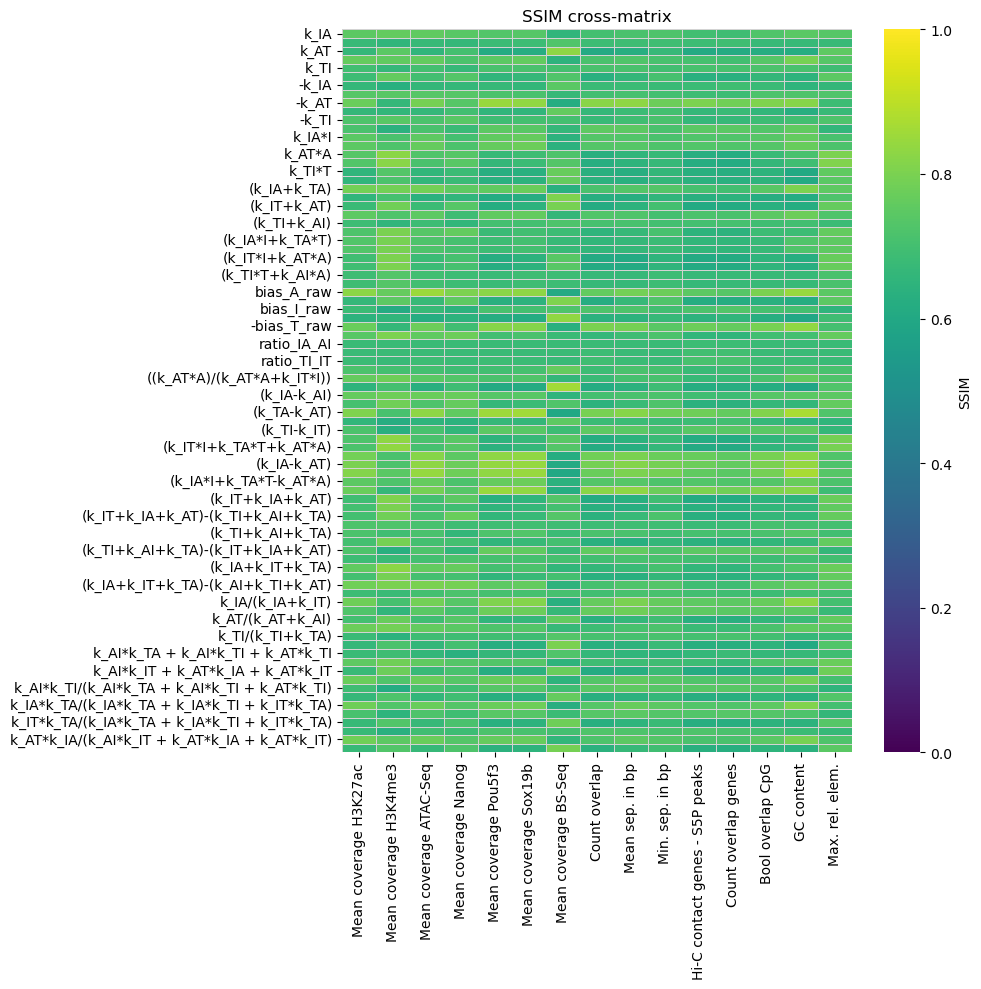

In [146]:

plt.figure(figsize=(10, 10))
ax = sns.heatmap(
    ssim_matrix_test,
    cmap="viridis",      # try "magma", "plasma", "rocket", "coolwarm"
    vmin=0, vmax=1,
    cbar_kws={"label": "SSIM"},
    square=False,        # set True if matrix is square and you want square cells
    linewidths=0.5, linecolor="lightgray"
)
#ax.set_xlabel("DF2 images")
#ax.set_ylabel("DF1 images")
ax.set_title("SSIM cross-matrix")

plt.tight_layout()
plt.show()



# Use linear fit to select parameter combinations in the 3-state model that best approximate the genome-wide data

In [108]:
#lineat fit of all rates to chip seq profiles
import numpy as np
from typing import Dict, Tuple

def _flatten_mask(*arrays):
    flats = [np.ravel(np.array(a, dtype=float)) for a in arrays]
    mask = np.ones_like(flats[0], dtype=bool)
    for f in flats:
        mask &= np.isfinite(f)
    return [f[mask] for f in flats]


def _flatten_mask2(*arrays, x_f=-700):
    """
    Flatten arrays and mask out:
        - non-finite values (nan, inf)
        - and optionally values equal to x_f
    """
    # Flatten all arrays to float vectors
    flats = [np.ravel(np.array(a, dtype=float)) for a in arrays]

    # Start with mask = all True
    mask = np.ones_like(flats[0], dtype=bool)

    for f in flats:
        # Mask non-finite values
        mask &= np.isfinite(f)

        # Mask forbidden value x_f if provided
        if x_f is not None:
            mask &= (f != x_f)

    # Return masked flattened arrays
    return [f[mask] for f in flats]

def pearson_corr(x, y) -> float:
    x = np.asarray(x); y = np.asarray(y)
    xm = x - x.mean(); ym = y - y.mean()
    den = np.sqrt((xm**2).sum() * (ym**2).sum())
    return float((xm @ ym) / den) if den != 0 else np.nan

def _rankdata(a: np.ndarray) -> np.ndarray:
    order = np.argsort(a)
    ranks = np.empty_like(order, dtype=float)
    ranks[order] = np.arange(1, a.size + 1)
    vals = a[order]
    i = 0
    while i < a.size:
        j = i + 1
        while j < a.size and vals[j] == vals[i]:
            j += 1
        if j - i > 1:
            avg = (i + 1 + j) / 2.0
            ranks[order[i:j]] = avg
        i = j
    return ranks

def spearman_corr(x, y) -> float:
    return pearson_corr(_rankdata(np.asarray(x)), _rankdata(np.asarray(y)))

def kfold_indices(n: int, k: int = 5, seed: int = 0):
    rng = np.random.default_rng(seed)
    idx = np.arange(n)
    rng.shuffle(idx)
    return np.array_split(idx, k)

def fit_linear_rates(
    rates: Dict[str, np.ndarray],
    Z_chip: np.ndarray,
    add_intercept: bool = True,
    ridge_lambda: float = 0.0,
    kfold: int = 0,
    seed: int = 0,
) -> Dict[str, np.ndarray]:
    """
    Fit Z_chip ≈ a*k_IA + b*k_AI + c*k_AT + d*k_TA + e*k_TI + f*k_IT + g (if add_intercept).

    Parameters
    ----------
    rates : dict with keys ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT'] and arrays on the same A–T grid
    Z_chip : array, same shape as the rates, target ChIP-seq surface
    add_intercept : include constant term g
    ridge_lambda : L2 penalty (0.0 = OLS; >0 uses ridge)
    kfold : 0 for no CV; otherwise, do k-fold CV and report held-out metrics
    seed : RNG seed for CV splits

    Returns
    -------
    result : dict with keys:
        'coeffs' : array [a,b,c,d,e,f,(g)]
        'names'  : feature names in coeff order
        'yhat'   : fitted values (vector, flattened)
        'pearson','spearman','rmse' : in-sample metrics
        'cv'     : dict with CV metrics if kfold>0
    """
    # 1) Flatten and mask
    k_IA, k_AI, k_AT = rates['k_IA'], rates['k_AI'], rates['k_AT']
    k_TA, k_TI, k_IT = rates['k_TA'], rates['k_TI'], rates['k_IT']
    (k_IA_v, k_AI_v, k_AT_v, k_TA_v, k_TI_v, k_IT_v, z_v) = _flatten_mask2(
        k_IA, k_AI, k_AT, k_TA, k_TI, k_IT, Z_chip
    )

    # 2) Design matrix
    X = np.column_stack([k_IA_v, k_AI_v, k_AT_v, k_TA_v, k_TI_v, k_IT_v])
    names = ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT']
    if add_intercept:
        X = np.column_stack([X, np.ones_like(k_IA_v)])
        names = names + ['intercept']

    y = z_v

    # 3) Fit (OLS or Ridge)
    if ridge_lambda > 0.0:
        # ridge solution: (X^T X + λI)^{-1} X^T y ; don't penalize intercept if present
        p = X.shape[1]
        XtX = X.T @ X
        reg = ridge_lambda * np.eye(p)
        if add_intercept:
            reg[-1, -1] = 0.0
        w = np.linalg.solve(XtX + reg, X.T @ y)
    else:
        w, *_ = np.linalg.lstsq(X, y, rcond=None)

    yhat = X @ w
    rmse = float(np.sqrt(np.mean((y - yhat)**2)))
    pr = pearson_corr(y, yhat)
    sr = spearman_corr(y, yhat)

    result = {
        'coeffs': w,
        'names': names,
        'yhat': yhat,
        'pearson': pr,
        'spearman': sr,
        'rmse': rmse
    }

    # 4) Optional K-fold CV to estimate generalization
    if kfold and kfold > 1:
        folds = kfold_indices(len(y), k=kfold, seed=seed)
        pearsons, spearmans, rmses = [], [], []
        for test_idx in folds:
            train_idx = np.setdiff1d(np.arange(len(y)), test_idx)
            Xtr, ytr = X[train_idx], y[train_idx]
            Xte, yte = X[test_idx], y[test_idx]

            if ridge_lambda > 0.0:
                p = Xtr.shape[1]
                XtX = Xtr.T @ Xtr
                reg = ridge_lambda * np.eye(p)
                if add_intercept:
                    reg[-1, -1] = 0.0
                w_cv = np.linalg.solve(XtX + reg, Xtr.T @ ytr)
            else:
                w_cv, *_ = np.linalg.lstsq(Xtr, ytr, rcond=None)

            yhat_te = Xte @ w_cv
            rmses.append(float(np.sqrt(np.mean((yte - yhat_te)**2))))
            pearsons.append(pearson_corr(yte, yhat_te))
            spearmans.append(spearman_corr(yte, yhat_te))

        result['cv'] = {
            'pearson_mean': float(np.nanmean(pearsons)),
            'pearson_std' : float(np.nanstd(pearsons)),
            'spearman_mean': float(np.nanmean(spearmans)),
            'spearman_std' : float(np.nanstd(spearmans)),
            'rmse_mean': float(np.nanmean(rmses)),
            'rmse_std' : float(np.nanstd(rmses)),
        }

    return result


#fit linear model to rates with positive coefficients
def fit_linear_rates2(
    rates: Dict[str, np.ndarray],
    Z_chip: np.ndarray,
    add_intercept: bool = True,
    ridge_lambda: float = 0.0,
    kfold: int = 0,
    seed: int = 0,
) -> Dict[str,Any]:
    """
    Fit Z_chip ≈ a*k_IA + b*k_AI + c*k_AT + d*k_TA + e*k_TI + f*k_IT + g (if add_intercept),
    with non-negative constraints on the six rate coefficients and a free intercept.

    Parameters
    ----------
    rates : dict with keys ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT'] and arrays on the same A–T grid
    Z_chip : array, same shape as the rates, target ChIP-seq surface
    add_intercept : include constant term g (unconstrained, unpenalized)
    ridge_lambda : L2 penalty (0.0 = OLS; >0 uses ridge)
    kfold : 0 for no CV; otherwise, do k-fold CV and report held-out metrics
    seed : RNG seed for CV splits

    Returns
    -------
    result : dict with keys:
        'coeffs' : array [a,b,c,d,e,f,(g)]
        'names'  : feature names in coeff order
        'yhat'   : fitted values (vector, flattened)
        'pearson','spearman','rmse' : in-sample metrics
        'cv'     : dict with CV metrics if kfold>0
    """
    # 1) Flatten and mask
    k_IA, k_AI, k_AT = rates['k_IA'], rates['k_AI'], rates['k_AT']
    k_TA, k_TI, k_IT = rates['k_TA'], rates['k_TI'], rates['k_IT']
    (k_IA_v, k_AI_v, k_AT_v, k_TA_v, k_TI_v, k_IT_v, z_v) = _flatten_mask(
        k_IA, k_AI, k_AT, k_TA, k_TI, k_IT, Z_chip
    )

    # 2) Design matrix
    X = np.column_stack([k_IA_v, k_AI_v, k_AT_v, k_TA_v, k_TI_v, k_IT_v])
    names = ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT']
    y = z_v

    # 3) Fit model (nonnegative coefficients; intercept optional)
    if ridge_lambda > 0.0:
        model = Ridge(alpha=ridge_lambda, positive=True, fit_intercept=add_intercept)
    else:
        model = LinearRegression(positive=True, fit_intercept=add_intercept)

    model.fit(X, y)
    yhat = model.predict(X)

    # Assemble coefficients in the requested order
    if add_intercept:
        coeffs = np.concatenate([model.coef_, [model.intercept_]])
        names_out = names + ['intercept']
    else:
        coeffs = model.coef_
        names_out = names

    # 4) In-sample metrics
    rmse = float(np.sqrt(np.mean((y - yhat)**2)))
    pr = pearson_corr(y, yhat)
    sr = spearman_corr(y, yhat)

    result = {
        'coeffs': coeffs,
        'names': names_out,
        'yhat': yhat,
        'pearson': pr,
        'spearman': sr,
        'rmse': rmse
    }

    # 5) Optional K-fold CV to estimate generalization
    if kfold and kfold > 1:
        folds = kfold_indices(len(y), k=kfold, seed=seed)
        pearsons, spearmans, rmses = [], [], []
        for test_idx in folds:
            train_idx = np.setdiff1d(np.arange(len(y)), test_idx)
            Xtr, ytr = X[train_idx], y[train_idx]
            Xte, yte = X[test_idx], y[test_idx]

            # Fresh model per fold
            if ridge_lambda > 0.0:
                model_cv = Ridge(alpha=ridge_lambda, positive=True, fit_intercept=add_intercept)
            else:
                model_cv = LinearRegression(positive=True, fit_intercept=add_intercept)

            model_cv.fit(Xtr, ytr)
            yhat_te = model_cv.predict(Xte)

            rmses.append(float(np.sqrt(np.mean((yte - yhat_te)**2))))
            pearsons.append(pearson_corr(yte, yhat_te))
            spearmans.append(spearman_corr(yte, yhat_te))

        result['cv'] = {
            'pearson_mean': float(np.nanmean(pearsons)),
            'pearson_std' : float(np.nanstd(pearsons)),
            'spearman_mean': float(np.nanmean(spearmans)),
            'spearman_std' : float(np.nanstd(spearmans)),
            'rmse_mean': float(np.nanmean(rmses)),
            'rmse_std' : float(np.nanstd(rmses)),
        }

    return result


#fit rate biases to data
def fit_linear_biases(
    rates: Dict[str, np.ndarray],
    Z_chip: np.ndarray,
    add_intercept: bool = True,
    ridge_lambda: float = 0.0,
    kfold: int = 0,
    seed: int = 0,
) -> Dict[str, np.ndarray]:
    """
    Fit Z_chip ≈ a*[(k_IA+k_TA)-(k_AI+k_AT)] + b*[(k_IT+k_AT) - (k_TI+k_TA)] + c*[(k_TI+k_AI) - (k_IT+k_IA)]  + g (if add_intercept).

    Parameters
    ----------
    rates : dict with keys ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT'] and arrays on the same A–T grid
    Z_chip : array, same shape as the rates, target ChIP-seq surface
    add_intercept : include constant term g
    ridge_lambda : L2 penalty (0.0 = OLS; >0 uses ridge)
    kfold : 0 for no CV; otherwise, do k-fold CV and report held-out metrics
    seed : RNG seed for CV splits

    Returns
    -------
    result : dict with keys:
        'coeffs' : array [a,b,c,d,e,f,(g)]
        'names'  : feature names in coeff order
        'yhat'   : fitted values (vector, flattened)
        'pearson','spearman','rmse' : in-sample metrics
        'cv'     : dict with CV metrics if kfold>0
    """
    # 1) Flatten and mask
    k_IA, k_AI, k_AT = rates['k_IA'], rates['k_AI'], rates['k_AT']
    k_TA, k_TI, k_IT = rates['k_TA'], rates['k_TI'], rates['k_IT']
    
    bias_A=(k_IA+k_TA) - (k_AI+k_AT)
    bias_T=(k_IT+k_AT) - (k_TI+k_TA) 
    bias_I=(k_TI+k_AI) - (k_IT+k_IA)
    
    (bias_A_v, bias_T_v, bias_I_v, z_v) = _flatten_mask2(
        bias_A, bias_T, bias_I, Z_chip
    )
    
    

    # 2) Design matrix
    X = np.column_stack([bias_A_v, bias_T_v, bias_I_v])
    names = ['bias_A','bias_T','bias_I']
    if add_intercept:
        X = np.column_stack([X, np.ones_like(bias_A_v)])
        names = names + ['intercept']

    y = z_v

    # 3) Fit (OLS or Ridge)
    if ridge_lambda > 0.0:
        # ridge solution: (X^T X + λI)^{-1} X^T y ; don't penalize intercept if present
        p = X.shape[1]
        XtX = X.T @ X
        reg = ridge_lambda * np.eye(p)
        if add_intercept:
            reg[-1, -1] = 0.0
        w = np.linalg.solve(XtX + reg, X.T @ y)
    else:
        w, *_ = np.linalg.lstsq(X, y, rcond=None)

    yhat = X @ w
    rmse = float(np.sqrt(np.mean((y - yhat)**2)))
    pr = pearson_corr(y, yhat)
    sr = spearman_corr(y, yhat)

    result = {
        'coeffs': w,
        'names': names,
        'yhat': yhat,
        'pearson': pr,
        'spearman': sr,
        'rmse': rmse
    }

    # 4) Optional K-fold CV to estimate generalization
    if kfold and kfold > 1:
        folds = kfold_indices(len(y), k=kfold, seed=seed)
        pearsons, spearmans, rmses = [], [], []
        for test_idx in folds:
            train_idx = np.setdiff1d(np.arange(len(y)), test_idx)
            Xtr, ytr = X[train_idx], y[train_idx]
            Xte, yte = X[test_idx], y[test_idx]

            if ridge_lambda > 0.0:
                p = Xtr.shape[1]
                XtX = Xtr.T @ Xtr
                reg = ridge_lambda * np.eye(p)
                if add_intercept:
                    reg[-1, -1] = 0.0
                w_cv = np.linalg.solve(XtX + reg, Xtr.T @ ytr)
            else:
                w_cv, *_ = np.linalg.lstsq(Xtr, ytr, rcond=None)

            yhat_te = Xte @ w_cv
            rmses.append(float(np.sqrt(np.mean((yte - yhat_te)**2))))
            pearsons.append(pearson_corr(yte, yhat_te))
            spearmans.append(spearman_corr(yte, yhat_te))

        result['cv'] = {
            'pearson_mean': float(np.nanmean(pearsons)),
            'pearson_std' : float(np.nanstd(pearsons)),
            'spearman_mean': float(np.nanmean(spearmans)),
            'spearman_std' : float(np.nanstd(spearmans)),
            'rmse_mean': float(np.nanmean(rmses)),
            'rmse_std' : float(np.nanstd(rmses)),
        }

    return result


In [109]:
#fit to full square heatmap
'''rates_res={'k_IA':three_state_model_metrics_df[three_state_model_metrics_df["name"]=="k_IA"]["KNR_model_pred_r"].to_list()[0],
        'k_AI':three_state_model_metrics_df[three_state_model_metrics_df["name"]=="k_AI"]["KNR_model_pred_r"].to_list()[0] ,
        'k_AT':three_state_model_metrics_df[three_state_model_metrics_df["name"]=="k_AT"]["KNR_model_pred_r"].to_list()[0] ,
        'k_TA':three_state_model_metrics_df[three_state_model_metrics_df["name"]=="k_TA"]["KNR_model_pred_r"].to_list()[0],
        'k_TI':three_state_model_metrics_df[three_state_model_metrics_df["name"]=="k_TI"]["KNR_model_pred_r"].to_list()[0] ,
        'k_IT':three_state_model_metrics_df[three_state_model_metrics_df["name"]=="k_IT"]["KNR_model_pred_r"].to_list()[0],}
'''

#set grid cells outside covex hulls to constant value
rates_res={'k_IA':processed_signal_model["k_IA"],
        'k_AI':processed_signal_model["k_AI"] ,
        'k_AT':processed_signal_model["k_AT"] ,
        'k_TA':processed_signal_model["k_TA"],
        'k_TI':processed_signal_model["k_TI"] ,
        'k_IT':processed_signal_model["k_IT"]}

#fit to full square heatmap
#Signal_grid_res=S5P_RNA_heatmap_df[S5P_RNA_heatmap_df["name"]=="Hi-C contact genes - S5P peaks"]["KNR_model_pred_r"].to_list()[0]

#set grid cells outside covex hulls to constant value
Signal_grid_res=processed_signal_chipseq["Hi-C contact genes - S5P peaks"]

# Fit OLS with intercept
res = fit_linear_biases(rates=rates_res, Z_chip=Signal_grid_res, add_intercept=True, ridge_lambda=0.0, kfold=5)

print("Selected linear model:")
for name, coef in zip(res['names'], res['coeffs']):
    print(f"  {name:10s} : {coef:.5f}")

print("\nIn-sample performance:")
print("  Pearson :", res['pearson'])
print("  Spearman:", res['spearman'])
print("  RMSE    :", res['rmse'])

print("\n5-fold CV performance (held-out):")
for k, v in res['cv'].items():
    print(f"  {k:15s}: {v:.4f}")


Selected linear model:
  bias_A     : 0.16920
  bias_T     : -0.16031
  bias_I     : -0.00889
  intercept  : 0.25088

In-sample performance:
  Pearson : 0.8763000759600037
  Spearman: 0.8987139148079742
  RMSE    : 0.1323009013790175

5-fold CV performance (held-out):
  pearson_mean   : 0.8752
  pearson_std    : 0.0149
  spearman_mean  : 0.8986
  spearman_std   : 0.0139
  rmse_mean      : 0.1324
  rmse_std       : 0.0049


Selected linear model:
  k_IA       : 0.03992
  k_AI       : -0.05248
  k_AT       : -0.16509
  k_TA       : 0.18207
  k_TI       : 0.03418
  k_IT       : 0.04999
  intercept  : 0.30583

In-sample performance:
  Pearson : 0.9013150819480131
  Spearman: 0.9077896763705786
  RMSE    : 0.04678851033516758
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.35032187727956937


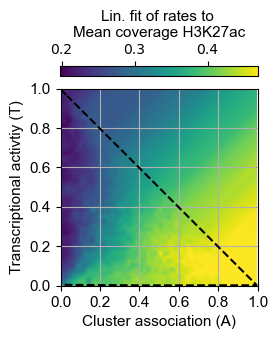

Selected linear model:
  k_IA       : 0.10726
  k_AI       : 0.13903
  k_AT       : 0.28066
  k_TA       : 0.34199
  k_TI       : -0.07909
  k_IT       : 0.19687
  intercept  : -0.06263

In-sample performance:
  Pearson : 0.8268168179602821
  Spearman: 0.8451471850202809
  RMSE    : 0.06700389776497154
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.43142693229504014


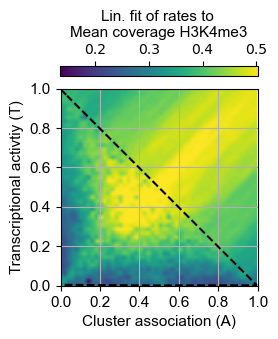

Selected linear model:
  k_IA       : 0.09956
  k_AI       : -0.03601
  k_AT       : -0.35104
  k_TA       : 0.04788
  k_TI       : 0.03900
  k_IT       : 0.08703
  intercept  : 0.49296

In-sample performance:
  Pearson : 0.9656205858843884
  Spearman: 0.9627453850734169
  RMSE    : 0.03235453197378353
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.43638276900583767


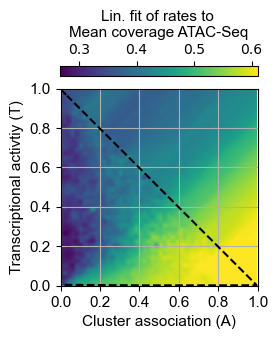

Selected linear model:
  k_IA       : 0.15959
  k_AI       : -0.11119
  k_AT       : -0.22261
  k_TA       : -0.09774
  k_TI       : 0.07727
  k_IT       : 0.10800
  intercept  : 0.65485

In-sample performance:
  Pearson : 0.8200373892876829
  Spearman: 0.8440296038297409
  RMSE    : 0.06715884948695984
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.6117977633328301


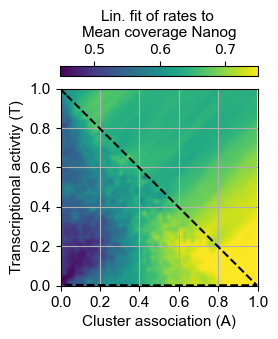

Selected linear model:
  k_IA       : 0.12052
  k_AI       : -0.11351
  k_AT       : -0.75783
  k_TA       : -0.06873
  k_TI       : 0.10166
  k_IT       : 0.01414
  intercept  : 0.79483

In-sample performance:
  Pearson : 0.9714307994439689
  Spearman: 0.9213039233008268
  RMSE    : 0.05559586854721569
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4428849441578349


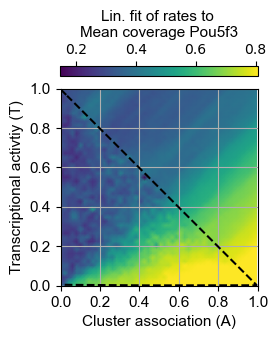

Selected linear model:
  k_IA       : 0.12803
  k_AI       : -0.08544
  k_AT       : -0.65740
  k_TA       : -0.01480
  k_TI       : 0.09537
  k_IT       : 0.03847
  intercept  : 0.75817

In-sample performance:
  Pearson : 0.9645217681420917
  Spearman: 0.9168412691668879
  RMSE    : 0.05629625286621292
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5103150602157759


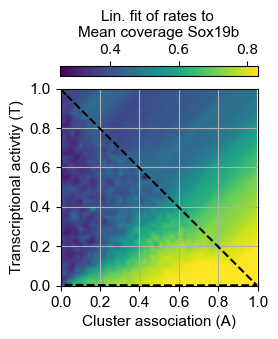

Selected linear model:
  k_IA       : -0.10466
  k_AI       : 0.03582
  k_AT       : 0.74523
  k_TA       : -0.10229
  k_TI       : -0.04560
  k_IT       : -0.06978
  intercept  : 0.22503

In-sample performance:
  Pearson : 0.9667065576559107
  Spearman: 0.9347911092606966
  RMSE    : 0.06254861547424298
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4542963556997684


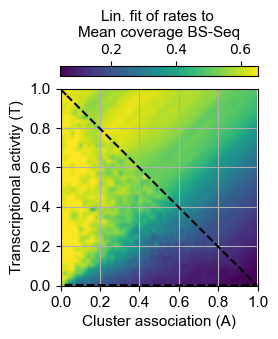

Selected linear model:
  k_IA       : 0.09369
  k_AI       : -0.15430
  k_AT       : -0.96517
  k_TA       : -0.14982
  k_TI       : 0.12976
  k_IT       : -0.01869
  intercept  : 0.88665

In-sample performance:
  Pearson : 0.9704138570129578
  Spearman: 0.861100515677473
  RMSE    : 0.06859087845545753
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.35415193983568344


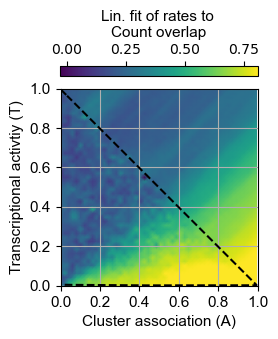

Selected linear model:
  k_IA       : 0.07711
  k_AI       : -0.07686
  k_AT       : -0.73235
  k_TA       : -0.14859
  k_TI       : 0.02024
  k_IT       : -0.02475
  intercept  : 0.99970

In-sample performance:
  Pearson : 0.9576588786701438
  Spearman: 0.822050705484863
  RMSE    : 0.058430694181747185
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5568434511631761


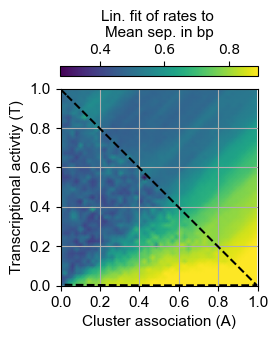

Selected linear model:
  k_IA       : 0.08905
  k_AI       : 0.01643
  k_AT       : -0.37778
  k_TA       : -0.10388
  k_TI       : -0.04779
  k_IT       : 0.03887
  intercept  : 1.01186

In-sample performance:
  Pearson : 0.8603029662316963
  Spearman: 0.8500634373528644
  RMSE    : 0.05357410265426495
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.8192841087512485


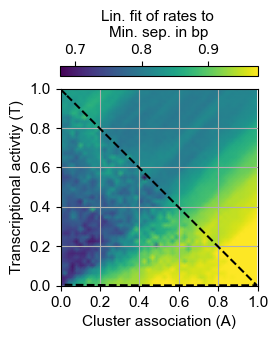

Selected linear model:
  k_IA       : 0.10918
  k_AI       : -0.10657
  k_AT       : -0.95812
  k_TA       : -0.15339
  k_TI       : 0.09825
  k_IT       : -0.01242
  intercept  : 0.80095

In-sample performance:
  Pearson : 0.9692795058466601
  Spearman: 0.864507900948264
  RMSE    : 0.06754523512338355
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2891830167437709


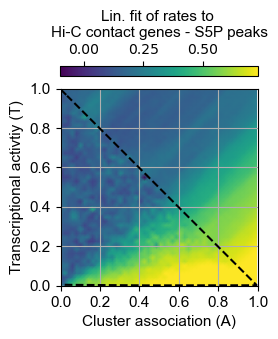

Selected linear model:
  k_IA       : 0.04362
  k_AI       : -0.02564
  k_AT       : -0.72393
  k_TA       : -0.13197
  k_TI       : -0.00036
  k_IT       : -0.03230
  intercept  : 0.66443

In-sample performance:
  Pearson : 0.9518568182550854
  Spearman: 0.8062078318740473
  RMSE    : 0.059450937661334684
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2288351269688471


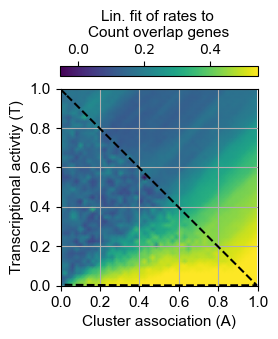

Selected linear model:
  k_IA       : -0.00191
  k_AI       : -0.16816
  k_AT       : -0.60146
  k_TA       : 0.03052
  k_TI       : 0.15957
  k_IT       : 0.10439
  intercept  : 0.58692

In-sample performance:
  Pearson : 0.9561584312420868
  Spearman: 0.9161389498002904
  RMSE    : 0.05889286397296252
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.3485673141335746


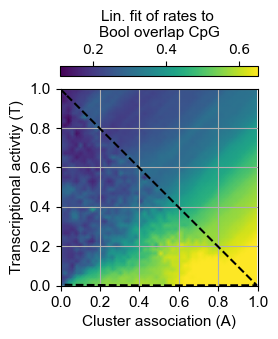

Selected linear model:
  k_IA       : 0.09232
  k_AI       : -0.10124
  k_AT       : -0.47493
  k_TA       : 0.11014
  k_TI       : 0.02985
  k_IT       : -0.09745
  intercept  : 0.76199

In-sample performance:
  Pearson : 0.9688236616800792
  Spearman: 0.957696845841029
  RMSE    : 0.04838665495942396
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5411112420305932


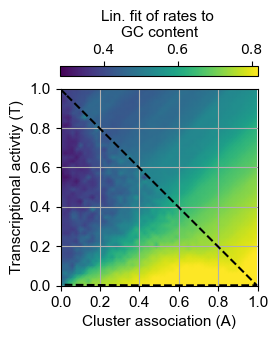

Selected linear model:
  k_IA       : 0.06975
  k_AI       : 0.00883
  k_AT       : 0.27176
  k_TA       : 0.21597
  k_TI       : 0.07254
  k_IT       : 0.09873
  intercept  : -0.10759

In-sample performance:
  Pearson : 0.6569268692067239
  Spearman: 0.7313820356133771
  RMSE    : 0.07107406919361178
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.26167243138452295


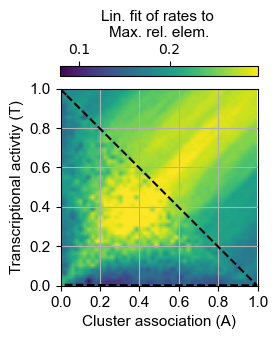

In [110]:
#plot linear fit of rates to heatmaps from chip seq data

S5P_data=A
RNA_data=T

for k in range(len(S5P_RNA_heatmap_df["name"].to_list())):
    
    #Signal_grid_res=S5P_RNA_heatmap_df[S5P_RNA_heatmap_df["name"]==S5P_RNA_heatmap_df["name"].to_list()[k]]["KNR_model_pred_r"].to_list()[0]
    
    Signal_grid_res=processed_signal_chipseq[S5P_RNA_heatmap_df["name"].to_list()[k]]

    signal_name="Lin. fit of rates to \n"+S5P_RNA_heatmap_df["name"].to_list()[k]
    # Fit OLS with intercept
    res = fit_linear_rates(rates=rates_res, Z_chip=Signal_grid_res, add_intercept=True, ridge_lambda=0.0, kfold=5)
    #res = fit_linear_biases(rates=rates_res, Z_chip=Signal_grid_res, add_intercept=True, ridge_lambda=0.0, kfold=5)

    print("Selected linear model:")
    for name, coef in zip(res['names'], res['coeffs']):
        print(f"  {name:10s} : {coef:.5f}")

    print("\nIn-sample performance:")
    print("  Pearson :", res['pearson'])
    print("  Spearman:", res['spearman'])
    print("  RMSE    :", res['rmse'])

    #print("\n5-fold CV performance (held-out):")
    #for k, v in res['cv'].items():
     #   print(f"  {k:15s}: {v:.4f}")

        
    #linear fit all rates:    
    parameter_c=np.array(res['coeffs'][0]*k_IA +res['coeffs'][1]*k_AI +res['coeffs'][2]*k_AT +res['coeffs'][3]*k_TA +res['coeffs'][4]*k_TI +res['coeffs'][5]*k_IT)+res['coeffs'][6]

    #linear fit biases:
    #bias_A=(k_IA+k_TA) - (k_AI+k_AT)
    #bias_T=(k_IT+k_AT) - (k_TI+k_TA) 
    #bias_I=(k_TI+k_AI) - (k_IT+k_IA)
    #parameter_c=np.array(res['coeffs'][0]*bias_A +res['coeffs'][1]*bias_T +res['coeffs'][2]*bias_I)+res['coeffs'][3]

    
    Signal_data=parameter_c

    drop_zeros=False #drop_zeros_1[k]
    n_neighbors=75
    colorbar_cutoff=95 #95
    colorbar_cutoff_2=False
    colorbar_power_scale=False
    colorbar_power_scale_2=False
    
    

    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff)
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale)
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2)
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2)
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=signal_name,size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        
    #plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    #plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    plt.xlim(np.min(x_ticks_set1_trf),up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    ax1.set_aspect(1./ax1.get_data_ratio())
    
    
    #append heat map data
    name_list.append(key)
    all_data_x_y_list.append(all_data_x_y)
    fit_data_x_y_list.append(fit_data_x_y)
    grid_x_list.append(grid_x)
    grid_y_list.append(grid_y)
    KNR_model_pred_r_list.append(KNR_model_pred_r)
    RNA_1_scaled_1_list.append(RNA_1_scaled_1)
    Serin5P_1_scaled_1_list.append(Serin5P_1_scaled_1)
    scaler_1_Serin5P_list.append(scaler_1_Serin5P)
    scaler_1_RNA_list.append(scaler_1_RNA)


    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_5/2d_plots/"+"2d_plot_" +str(key)+"_2.png"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
    plt.show()


In [110]:
#regularize fit by penalizing complex solutions
def sparse_linear_fit(rates, Z_chip,
                     method='lasso',          # 'lasso' | 'elastic' | 'aic' | 'stability'
                     cv_folds=5,
                     alpha_grid=np.logspace(-5, 1, 100),
                     l1_ratio=0.7,
                     stability_boot=200,
                     stability_thr=0.7,
                     positive=False):
    """
    Returns:
        beta      – array of length 6 (zero where dropped)
        intercept – scalar
        selected  – boolean mask of kept variables
        info      – dict with extra diagnostics (e.g., CV‑R², AIC, freq)
    """
    
     # 1) Flatten and mask
    k_IA, k_AI, k_AT = rates['k_IA'], rates['k_AI'], rates['k_AT']
    k_TA, k_TI, k_IT = rates['k_TA'], rates['k_TI'], rates['k_IT']
    (k_IA_v, k_AI_v, k_AT_v, k_TA_v, k_TI_v, k_IT_v, z_v) = _flatten_mask(
        k_IA, k_AI, k_AT, k_TA, k_TI, k_IT, Z_chip
    )

    # 2) Design matrix
    X = np.column_stack([k_IA_v, k_AI_v, k_AT_v, k_TA_v, k_TI_v, k_IT_v])
    names = ['k_IA','k_AI','k_AT','k_TA','k_TI','k_IT']


    y = z_v
    
    
    #import warnings, itertools, statsmodels.api as sm
    N, P = X.shape
    #assert P == 6

    if method == 'lasso':
        model = LassoCV(alphas=alpha_grid, cv=cv_folds,
                        max_iter=10_000, positive=positive).fit(X, y.ravel())
        beta = model.coef_
        intercept = model.intercept_
        r2 = model.score(X, y)
        info = dict(cv_r2=r2, best_alpha=model.alpha_)

    elif method == 'elastic':
        model = ElasticNetCV(alphas=alpha_grid, l1_ratio=l1_ratio,
                             cv=cv_folds, max_iter=10_000,
                             positive=positive).fit(X, y.ravel())
        beta = model.coef_
        intercept = model.intercept_
        r2 = model.score(X, y)
        info = dict(cv_r2=r2, best_alpha=model.alpha_, l1_ratio=model.l1_ratio_)

    elif method == 'aic':
        best_aic = np.inf
        best_mask = None
        best_par = None
        for mask in itertools.product([0,1], repeat=P):
            cols = np.where(mask)[0]
            Xsub = sm.add_constant(X[:, cols])
            fit = sm.OLS(y, Xsub).fit()
            if fit.aic < best_aic:
                best_aic = fit.aic
                best_mask = mask
                best_par = fit.params
        beta = np.zeros(P)
        beta[np.where(best_mask)[0]] = best_par[1:]   # drop intercept
        intercept = best_par[0]
        info = dict(aic=best_aic, mask=best_mask)

    elif method == 'stability':
        sel_counts = np.zeros(P)
        for _ in range(stability_boot):
            xb, yb = resample(X, y, replace=True)
            l = LassoCV(alphas=alpha_grid, cv=3,
                        max_iter=10_000, positive=positive).fit(xb, yb.ravel())
            sel_counts += (l.coef_ != 0)
        freq = sel_counts / stability_boot
        mask = freq >= stability_thr
        # refit OLS on the stable mask for unbiased β
        if mask.any():
            Xsub = sm.add_constant(X[:, mask])
            fit = sm.OLS(y, Xsub).fit()
            beta = np.zeros(P)
            beta[mask] = fit.params[1:]
            intercept = fit.params[0]
        else:                     # nothing survived the threshold
            beta = np.zeros(P)
            intercept = y.mean()
        info = dict(selection_freq=freq, mask=mask)

    else:
        raise ValueError('method not recognized')

    selected = beta != 0
    param_dict=dict(zip(names, beta  ))
    param_dict["intercept"]=intercept
    return beta, intercept, selected, info,param_dict

In [111]:
#set grid cells outside covex hulls to constant value
rates_res={'k_IA':processed_signal_model["k_IA"],
        'k_AI':processed_signal_model["k_AI"] ,
        'k_AT':processed_signal_model["k_AT"] ,
        'k_TA':processed_signal_model["k_TA"],
        'k_TI':processed_signal_model["k_TI"] ,
        'k_IT':processed_signal_model["k_IT"]}


#set grid cells outside covex hulls to constant value
Signal_grid_res=processed_signal_chipseq["Hi-C contact genes - S5P peaks"]



beta, inter, sel, info,param_dict = sparse_linear_fit(rates_res, Signal_grid_res.reshape(-1, 1), method='lasso')
print('Chosen rates:', np.where(sel)[0])      # e.g. [0 3 4 5]
print('Coefficients:', beta[sel])

Chosen rates: [0 1 4]
Coefficients: [9.99541367e-01 5.30463975e-07 2.04380872e-07]


Selected linear model:
k_IA 0.9997022502696719
k_AI 7.540650016492907e-07
k_AT -2.804107809226665e-07
k_TA -8.901296519668203e-08
k_TI 3.43613281611034e-07
k_IT -5.709456120704618e-07
intercept -0.2082697844510335
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.2922060729161543


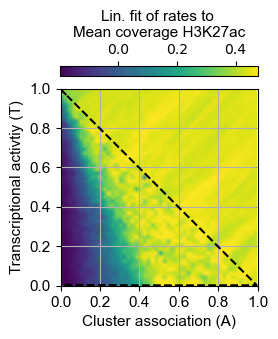

Selected linear model:
k_IA 0.9998794193981208
k_AI 8.545938466868153e-07
k_AT -7.944779571121869e-08
k_TA -5.141582548047773e-07
k_TI 3.646917693135454e-07
k_IT -2.464061870793419e-07
intercept -0.08412570540360775
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4164392721759712


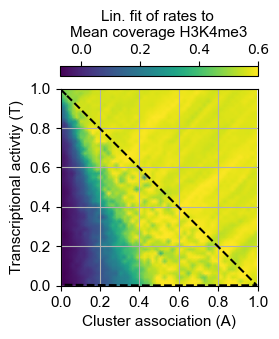

Selected linear model:
k_IA 0.9998175209353458
k_AI 6.810625963013081e-07
k_AT -3.0015102985548085e-07
k_TA -3.372275513969768e-08
k_TI 3.317249810457532e-07
k_IT -5.526843446860778e-07
intercept -0.12760368679909107
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.37292982490392496


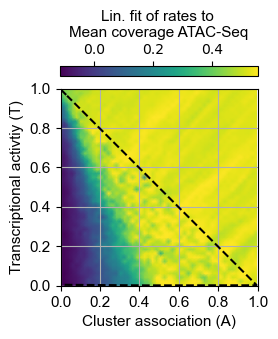

Selected linear model:
k_IA 1.0000604865894953
k_AI 6.650446786721566e-07
k_AT -1.8900392231487311e-07
k_TA -2.248839744753096e-07
k_TI 3.4890116780940727e-07
k_IT -3.7887815807434276e-07
intercept 0.04252336747248364
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.5431787129540386


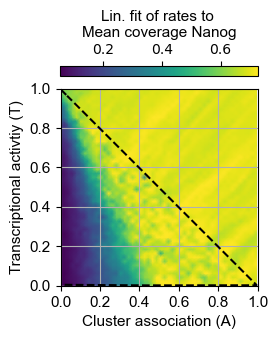

Selected linear model:
k_IA 0.9997863349829318
k_AI 5.420568361792684e-07
k_AT 0.0
k_TA 0.0
k_TI 1.6073664305152448e-07
k_IT 0.0
intercept -0.1467080897770643
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.35381023233283915


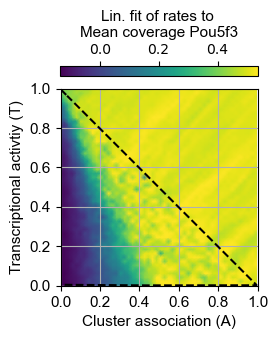

Selected linear model:
k_IA 0.9999005421691252
k_AI 5.646739533165243e-07
k_AT 0.0
k_TA 0.0
k_TI 1.3032544939628522e-07
k_IT 0.0
intercept -0.06827726377605359
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4322982293852009


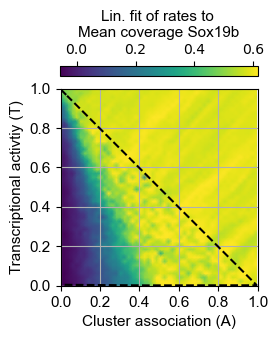

Selected linear model:
k_IA 0.9998186224135847
k_AI 1.4935568705526022e-06
k_AT -2.0411260318977255e-09
k_TA -1.2602998637039033e-06
k_TI 7.300727125028698e-07
k_IT -2.3047841273895765e-07
intercept -0.12643840154538566
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.37409672738145827


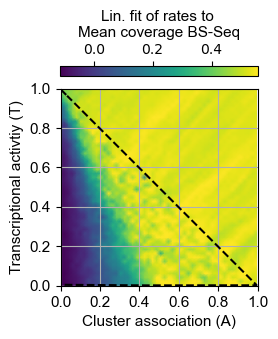

Selected linear model:
k_IA 0.9996245590957179
k_AI 5.112246720702597e-07
k_AT 0.0
k_TA 0.0
k_TI 2.2734341162163733e-07
k_IT 0.0
intercept -0.2559193597881517
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.24451799120283546


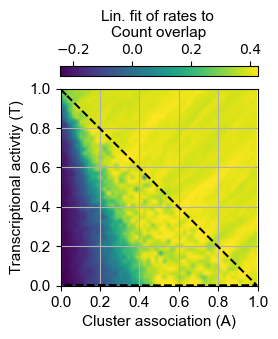

Selected linear model:
k_IA 0.9999422207876416
k_AI 6.446786642352902e-07
k_AT -4.4225941424796327e-07
k_TA 1.9503276113962454e-07
k_TI 3.395938126830302e-07
k_IT -7.432560463883743e-07
intercept -0.04038787629355056
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.460207811083231


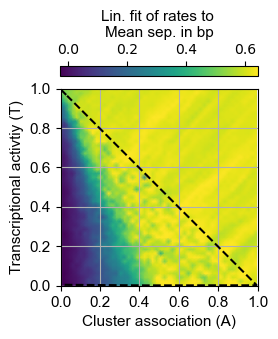

Selected linear model:
k_IA 1.0003435258448405
k_AI 7.800776605491637e-07
k_AT -2.917897132256295e-07
k_TA -1.7925265162309742e-07
k_TI 3.944707914205428e-07
k_IT -5.173208197715853e-07
intercept 0.24063986917337843
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.7414368190950659


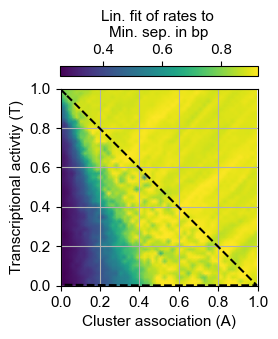

Selected linear model:
k_IA 0.9995413665734378
k_AI 5.304639748386109e-07
k_AT 0.0
k_TA 0.0
k_TI 2.0438087165966674e-07
k_IT 0.0
intercept -0.31572331597209313
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.1846723848932586


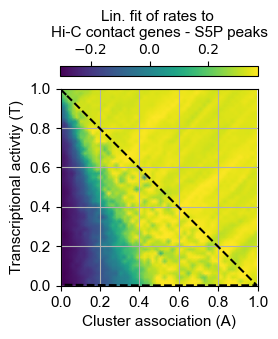

Selected linear model:
k_IA 0.9994741870328153
k_AI 7.212186422093194e-07
k_AT -4.665756131151712e-07
k_TA 1.6386262984605216e-07
k_TI 3.7255022877146873e-07
k_IT -7.819683267939681e-07
intercept -0.3679976060344643
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.13236378296188578


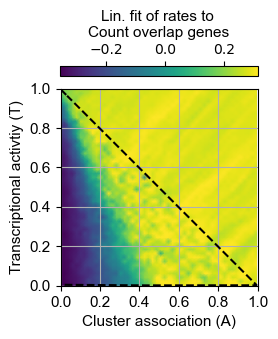

Selected linear model:
k_IA 0.999668577067146
k_AI 6.098415083546076e-07
k_AT -4.036729877908399e-07
k_TA 2.255946005973545e-07
k_TI 3.1079122817904847e-07
k_IT -7.256805787940583e-07
intercept -0.2319269131191959
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.26853179699337093


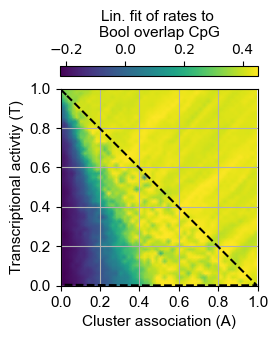

Selected linear model:
k_IA 0.9999458123607331
k_AI 6.350899344896751e-07
k_AT -4.2416232584326495e-07
k_TA 2.4294030952383025e-07
k_TI 2.9149351150914807e-07
k_IT -7.828211237846999e-07
intercept -0.03789168524775732
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.4627057695265616


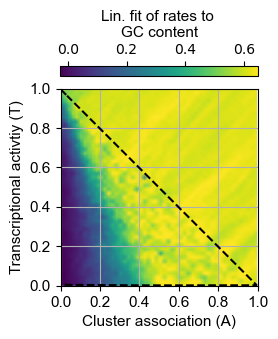

Selected linear model:
k_IA 0.999601676888431
k_AI 9.430413777358756e-07
k_AT -1.4275547819388706e-07
k_TA -4.847361009087829e-07
k_TI 4.3340937364263137e-07
k_IT -3.899244222292181e-07
intercept -0.27854781380546
Percentage of data used: 100.0
max, min RNA 4.235793513551707 -2.1203368348804643
max, min Serin5P 4.216785457369894 -2.1255310350100936
mean Signal: 0.22187806212992212


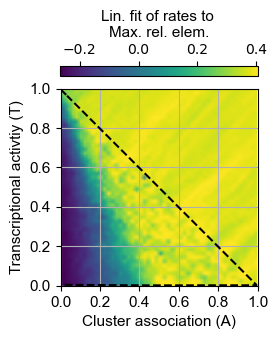

In [112]:
#plot linear fit of rates to heatmaps from chip seq data

S5P_data=A
RNA_data=T

for k in range(len(S5P_RNA_heatmap_df["name"].to_list())):
    
    #Signal_grid_res=S5P_RNA_heatmap_df[S5P_RNA_heatmap_df["name"]==S5P_RNA_heatmap_df["name"].to_list()[k]]["KNR_model_pred_r"].to_list()[0]
    
    Signal_grid_res=processed_signal_chipseq[S5P_RNA_heatmap_df["name"].to_list()[k]]

    signal_name="Lin. fit of rates to \n"+S5P_RNA_heatmap_df["name"].to_list()[k]
   

    # Fit OLS with intercept
    #res = fit_linear_rates(rates=rates_res, Z_chip=Signal_grid_res, add_intercept=True, ridge_lambda=0.0, kfold=5)
    #res = fit_linear_biases(rates=rates_res, Z_chip=Signal_grid_res, add_intercept=True, ridge_lambda=0.0, kfold=5)
    
    beta, inter, sel, info,param_dict = sparse_linear_fit(rates_res, Signal_grid_res.reshape(-1, 1), method='lasso')

    print("Selected linear model:")
    for key, value in param_dict.items():
        print(key, value)


    #print("\n5-fold CV performance (held-out):")
    #for k, v in res['cv'].items():
     #   print(f"  {k:15s}: {v:.4f}")

        
    #linear fit all rates:    
    parameter_c=np.array(param_dict["k_IA"]*k_IA +param_dict["k_AI"]*k_AI +param_dict["k_AT"]*k_AT +param_dict["k_AT"]*k_TA +param_dict["k_TI"]*k_TI +param_dict["k_IT"]*k_IT)+param_dict["intercept"]

    #linear fit biases:
    #bias_A=(k_IA+k_TA) - (k_AI+k_AT)
    #bias_T=(k_IT+k_AT) - (k_TI+k_TA) 
    #bias_I=(k_TI+k_AI) - (k_IT+k_IA)
    #parameter_c=np.array(res['coeffs'][0]*bias_A +res['coeffs'][1]*bias_T +res['coeffs'][2]*bias_I)+res['coeffs'][3]

    
    Signal_data=parameter_c

    drop_zeros=False #drop_zeros_1[k]
    n_neighbors=75
    colorbar_cutoff=95 #95
    colorbar_cutoff_2=False
    colorbar_power_scale=False
    colorbar_power_scale_2=False
    
    

    all_data_x_y, fit_data_x_y, grid_x, grid_y, KNR_model_pred_r,RNA_1_scaled_1,Serin5P_1_scaled_1,scaler_1_Serin5P,scaler_1_RNA=local_distance_weighted_average(S5P_data,RNA_data,Signal_data,drop_zeros,n_neighbors)


    def S5P_trf(x):
        return scaler_1_Serin5P.transform(np.asarray([x]).reshape(-1,1)).flatten()

    def RNA_trf(x):
        return scaler_1_RNA.transform(np.asarray([x]).reshape(-1,1)).flatten()

    #fig=plt.figure(figsize=(3,3)) #standard
    fig=plt.figure(figsize=(3.2,3.2)) #larger to include colorscale
    ax1 = fig.add_subplot(111)
    
    vmax2=None
    if colorbar_cutoff!=False:
    
        vmax2= np.percentile(KNR_model_pred_r.flatten(),colorbar_cutoff)
        
    color_scale_norm=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale!=False:
        color_scale_norm=matplotlib.colors.PowerNorm(colorbar_power_scale)
    sc_222=ax1.pcolormesh(grid_x, grid_y, KNR_model_pred_r, shading='gouraud',vmax=vmax2,norm=color_scale_norm,alpha=1)

    #option to plot all trf data:
    vmax4=None
    if colorbar_cutoff_2!=False:
    
        vmax4= np.percentile(Signal_data.flatten(),colorbar_cutoff_2)
        
    color_scale_norm4=None #matplotlib.colors.PowerNorm(0.7)
    if colorbar_power_scale_2!=False:
        color_scale_norm4=matplotlib.colors.PowerNorm(colorbar_power_scale_2)
        
    #S5P_data_trf=scaler_1_Serin5P.transform(S5P_data.reshape(-1,1)).flatten()
    #RNA_data_trf=scaler_1_RNA.transform(RNA_data.reshape(-1,1)).flatten()
    
    #pl_444=ax1.scatter(S5P_data_trf,RNA_data_trf,s=1,c=Signal_data,vmax=vmax4,alpha=0.5,norm=color_scale_norm4)

    #get lables
    ax1.scatter([1000],[1000],marker="o",fc=label_col,edgecolor=label_col,label="High contact")
    ax1.scatter([1000],[1000],marker="o",fc="none",edgecolor=label_col,label="Low contact")
    #plt.legend()
    
    fig.colorbar(sc_222, location='top',shrink=0.8).set_label(label=signal_name,size=11,family="Arial")
    #cb_1.xaxis.set_ticks_position('top')
    
    #generate convex hull
    hull_t=scipy.spatial.ConvexHull(all_data_x_y)
    ax1.errorbar(all_data_x_y[hull_t.vertices,0], all_data_x_y[hull_t.vertices,1],color="black", fmt='--')
    ax1.errorbar([all_data_x_y[hull_t.vertices,0][0] ,all_data_x_y[hull_t.vertices,0][-1]], [all_data_x_y[hull_t.vertices,1][0],all_data_x_y[hull_t.vertices,1][-1] ],color="black", fmt='--')
    
    plt.ylabel("Transcriptional activtiy (T)", size=11, fontname="Arial")
    plt.xlabel("Cluster association (A)", size=11, fontname="Arial")
    plt.grid()

    
    lin_wi_y_trf=abs(scaler_1_RNA.transform(np.array([1]).reshape(-1,1)).flatten())
    lin_wi_x_trf=abs(scaler_1_RNA.transform(np.array([0.1]).reshape(-1,1)).flatten())

    y_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1]) #np.asarray([0,10,100,500])
    x_ticks_set1=np.asarray([0,0.2,0.4,0.6,0.8,1])  #np.asarray([0,1,10])

    y_ticks_set1_trf=scaler_1_RNA.transform(y_ticks_set1.reshape(-1,1)).flatten()
    x_ticks_set1_trf=scaler_1_Serin5P.transform(x_ticks_set1.reshape(-1,1)).flatten()
        
    #plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    #plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    up_bound_RNA=np.max(RNA_1_scaled_1)#*1.05
    up_bound_Serin5P=np.max(Serin5P_1_scaled_1)#*1.05
    
    #show smaller section
    #up_bound_RNA=scaler_1_RNA.transform(np.asarray([200]).reshape(-1,1)).flatten()
    #up_bound_Serin5P=scaler_1_Serin5P.transform(np.asarray([10]).reshape(-1,1)).flatten()
    
    plt.xlim(np.min(x_ticks_set1_trf),up_bound_Serin5P)
    plt.ylim(np.min(y_ticks_set1_trf),up_bound_RNA)
    
    
    plt.yticks(ticks=y_ticks_set1_trf,labels=y_ticks_set1 ,fontname = "Arial",fontsize=11) 
    plt.xticks(ticks=x_ticks_set1_trf,labels=x_ticks_set1 ,fontname = "Arial",fontsize=11) 

    ax1.set_aspect(1./ax1.get_data_ratio())
    
    
    #append heat map data
    name_list.append(key)
    all_data_x_y_list.append(all_data_x_y)
    fit_data_x_y_list.append(fit_data_x_y)
    grid_x_list.append(grid_x)
    grid_y_list.append(grid_y)
    KNR_model_pred_r_list.append(KNR_model_pred_r)
    RNA_1_scaled_1_list.append(RNA_1_scaled_1)
    Serin5P_1_scaled_1_list.append(Serin5P_1_scaled_1)
    scaler_1_Serin5P_list.append(scaler_1_Serin5P)
    scaler_1_RNA_list.append(scaler_1_RNA)


    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_5/2d_plots/"+"2d_plot_" +str(key)+"_2.png"

    #plt.savefig("clustering_genome_sections/figures/fig_analysing_genome_sections_5/contact_freq_zoom_classes_3.png",format="png",dpi=300,bbox_inches="tight")
    #plt.savefig(name_s,format="png",dpi=300,bbox_inches="tight")
    plt.show()


# Compare sequencing with imaging based data


In [113]:
#load in microscopy based results
#microscopy_data_results=pd.read_csv("clustering_genome_sections/imaging_results_zebrafish_stages/gene_cluster_visit_OPoutcome_20260731.csv",low_memory=False)

microscopy_data_results=pd.read_csv("clustering_genome_sections/imaging_results_zebrafish_stages/gene_cluster_visit_OPoutcome_20260731_V2.csv",low_memory=False)


microscopy_data_results.head()





,Row,x5_percentile_distance,dist_CI_low,dist_CI_high,PolII_Ser5P_level,S5P_CI_low,S5P_CI_high,PolII_Ser2P_level,S2P_CI_low,S2P_CI_high,contact_fraction,predicted_distance_LOGO_CV
0,Oblong_drll2,0.542435,0.280690,0.578161,1.186056,1.148544,1.267693,1.244283,1.191225,1.307681,0.01,0.434847
1,Sphere_drll2,0.424415,0.368540,0.632496,1.166175,1.124221,1.226497,1.194139,1.149143,1.237476,0.00,0.453839
2,Dome_drll2,0.629373,0.545200,0.698640,1.076122,1.060757,1.097052,1.127495,1.106225,1.161129,0.00,0.700559
3,Epi30_drll2,0.665705,0.574858,0.808041,1.082814,1.065857,1.098944,1.102475,1.077881,1.125379,0.00,0.652217
4,Epi50_drll2,0.826828,0.667887,0.964407,1.071203,1.055929,1.086090,1.098606,1.079025,1.121612,0.00,0.688756


In [114]:
#In the microscopy_data_results dataframe, stage and gene name are concatenated, split into separate columns here
# Create a copy
microscopy_data_results2 = microscopy_data_results.copy()

#split using _
microscopy_data_results2[["Timepoint", "Name"]] = (
    microscopy_data_results2["Row"]
    .str.split("_", n=1, expand=True)
)
microscopy_data_results2

,Row,x5_percentile_distance,dist_CI_low,dist_CI_high,PolII_Ser5P_level,S5P_CI_low,S5P_CI_high,PolII_Ser2P_level,S2P_CI_low,S2P_CI_high,contact_fraction,predicted_distance_LOGO_CV,Timepoint,Name
0,Oblong_drll2,0.542435,0.280690,0.578161,1.186056,1.148544,1.267693,1.244283,1.191225,1.307681,0.010000,0.434847,Oblong,drll2
1,Sphere_drll2,0.424415,0.368540,0.632496,1.166175,1.124221,1.226497,1.194139,1.149143,1.237476,0.000000,0.453839,Sphere,drll2
2,Dome_drll2,0.629373,0.545200,0.698640,1.076122,1.060757,1.097052,1.127495,1.106225,1.161129,0.000000,0.700559,Dome,drll2
3,Epi30_drll2,0.665705,0.574858,0.808041,1.082814,1.065857,1.098944,1.102475,1.077881,1.125379,0.000000,0.652217,Epi30,drll2
4,Epi50_drll2,0.826828,0.667887,0.964407,1.071203,1.055929,1.086090,1.098606,1.079025,1.121612,0.000000,0.688756,Epi50,drll2
5,Oblong_zgc:64022,0.400236,0.120915,0.671886,1.181751,1.097099,1.359078,1.131514,1.083549,1.210533,0.014286,0.348283,Oblong,zgc:64022
6,Sphere_zgc:64022,0.431850,0.133470,0.581747,1.140769,1.098711,1.206923,1.067299,1.042714,1.092854,0.020349,0.410378,Sphere,zgc:64022
7,Dome_zgc:64022,0.537475,0.108325,0.740090,1.116484,1.075580,1.170869,1.038888,1.020988,1.056087,0.019737,0.459089,Dome,zgc:64022
8,Epi30_zgc:64022,0.785118,0.670652,0.892630,1.052918,1.031844,1.137670,1.028702,1.011630,1.044720,0.000000,0.665872,Epi30,zgc:64022
9,Epi50_zgc:64022,0.955296,0.819218,1.107480,1.030656,1.016323,1.058294,1.050534,1.025356,1.079266,0.003534,0.769669,Epi50,zgc:64022


In [115]:
# Columns we want to keep, dome stage
#cols = ["Name", "x5_percentile_distance","dist_CI_low","dist_CI_high",PolII_Ser5P_level 	S5P_CI_low 	S5P_CI_high 	PolII_Ser2P_level 	S2P_CI_low 	S2P_CI_high 	contact_fraction]

# Filter for a specific timepoint and keep only selected columns
df_all_m_dome = microscopy_data_results2.loc[microscopy_data_results2["Timepoint"] == "Dome"]

df_all_m_dome.loc[df_all_m_dome["Name"] == "drll2","Name"] = "drll.2"
df_all_m_dome

,Row,x5_percentile_distance,dist_CI_low,dist_CI_high,PolII_Ser5P_level,S5P_CI_low,S5P_CI_high,PolII_Ser2P_level,S2P_CI_low,S2P_CI_high,contact_fraction,predicted_distance_LOGO_CV,Timepoint,Name
2,Dome_drll2,0.629373,0.545200,0.698640,1.076122,1.060757,1.097052,1.127495,1.106225,1.161129,0.000000,0.700559,Dome,drll.2
7,Dome_zgc:64022,0.537475,0.108325,0.740090,1.116484,1.075580,1.170869,1.038888,1.020988,1.056087,0.019737,0.459089,Dome,zgc:64022
12,Dome_vamp2,0.693203,0.440827,0.827421,1.039786,1.020996,1.061794,1.044787,1.014309,1.072964,0.000000,0.748111,Dome,vamp2
17,Dome_klf2b,0.625877,0.526349,0.788263,1.022409,1.005114,1.042575,1.018994,0.991273,1.050847,0.000000,0.788159,Dome,klf2b
22,Dome_foxd5,0.227936,0.107045,0.453962,1.169414,1.124339,1.233721,1.048561,1.021396,1.071249,0.022222,0.315472,Dome,foxd5
27,Dome_gadd45ga,0.828102,0.683657,0.915321,1.041969,1.025704,1.060419,1.084379,1.052251,1.120799,0.000000,0.785974,Dome,gadd45ga
32,Dome_iscub,0.688592,0.580969,0.743630,1.060585,1.030369,1.128743,1.009683,0.984274,1.038606,0.000000,0.643931,Dome,iscub
37,Dome_ripply1,0.852496,0.707827,0.953634,1.033588,1.015037,1.054670,1.049819,1.014491,1.096841,0.000000,0.759501,Dome,ripply1


In [116]:
# Columns we want to keep, all time points
#cols = ["Name", "x5_percentile_distance","dist_CI_low","dist_CI_high",PolII_Ser5P_level 	S5P_CI_low 	S5P_CI_high 	PolII_Ser2P_level 	S2P_CI_low 	S2P_CI_high 	contact_fraction]

# Filter for a specific timepoint and keep only selected columns
df_all_m_all_t = microscopy_data_results2

df_all_m_all_t.loc[df_all_m_all_t["Name"] == "drll2","Name"] = "drll.2"
df_all_m_all_t

,Row,x5_percentile_distance,dist_CI_low,dist_CI_high,PolII_Ser5P_level,S5P_CI_low,S5P_CI_high,PolII_Ser2P_level,S2P_CI_low,S2P_CI_high,contact_fraction,predicted_distance_LOGO_CV,Timepoint,Name
0,Oblong_drll2,0.542435,0.280690,0.578161,1.186056,1.148544,1.267693,1.244283,1.191225,1.307681,0.010000,0.434847,Oblong,drll.2
1,Sphere_drll2,0.424415,0.368540,0.632496,1.166175,1.124221,1.226497,1.194139,1.149143,1.237476,0.000000,0.453839,Sphere,drll.2
2,Dome_drll2,0.629373,0.545200,0.698640,1.076122,1.060757,1.097052,1.127495,1.106225,1.161129,0.000000,0.700559,Dome,drll.2
3,Epi30_drll2,0.665705,0.574858,0.808041,1.082814,1.065857,1.098944,1.102475,1.077881,1.125379,0.000000,0.652217,Epi30,drll.2
4,Epi50_drll2,0.826828,0.667887,0.964407,1.071203,1.055929,1.086090,1.098606,1.079025,1.121612,0.000000,0.688756,Epi50,drll.2
5,Oblong_zgc:64022,0.400236,0.120915,0.671886,1.181751,1.097099,1.359078,1.131514,1.083549,1.210533,0.014286,0.348283,Oblong,zgc:64022
6,Sphere_zgc:64022,0.431850,0.133470,0.581747,1.140769,1.098711,1.206923,1.067299,1.042714,1.092854,0.020349,0.410378,Sphere,zgc:64022
7,Dome_zgc:64022,0.537475,0.108325,0.740090,1.116484,1.075580,1.170869,1.038888,1.020988,1.056087,0.019737,0.459089,Dome,zgc:64022
8,Epi30_zgc:64022,0.785118,0.670652,0.892630,1.052918,1.031844,1.137670,1.028702,1.011630,1.044720,0.000000,0.665872,Epi30,zgc:64022
9,Epi50_zgc:64022,0.955296,0.819218,1.107480,1.030656,1.016323,1.058294,1.050534,1.025356,1.079266,0.003534,0.769669,Epi50,zgc:64022


In [118]:
#of note: drl comes in multiple close-by copies, which makes direct comparison between seq-data and microscopy data difficult,as the later images the entire section
all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"].str.contains("drl", case=False, na=False)]

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
105,ENSDARG00000078004,drl,5,61645156,61652224,minus,7068,61648690,61652124,61653224,12.0,0.8764,0.749283,0.292264,1.11738,0.03746,1.514257,0.307686,0.163444,0.948492,34,-1.625941e+06,-9264,86.912388,0,0,35.415748,171.0
3061,ENSDARG00000035151,drll.1,5,61630696,61638125,minus,7429,61634410,61638025,61639125,14.0,1.216973,1.211777,0.312618,0.803704,0.032304,1.33479,0.192211,0.153522,0.946706,33,-1.666530e+06,-8047,88.632875,0,0,35.607395,171.0
3064,ENSDARG00000035150,drll.2,5,61615663,61624693,minus,9030,61620178,61624593,61625693,10.0,1.293859,1.46494,0.276499,2.530575,0.030602,1.182441,0.170749,0.119554,0.953993,33,-1.658072e+06,-369,104.000515,0,0,34.501388,171.0
4737,ENSDARG00000095635,drll.3,5,61602596,61609410,minus,6814,61606003,61609310,61610410,171.0,1.741024,1.065721,0.632503,9.505065,0.116699,1.234375,0.232012,0.210609,0.947352,32,-1.705221e+06,-489,83.614349,0,0,33.905463,19.0


In [119]:
#from the sequencing based dataframe generated before, pick the genes with exp imaging data
seq_based_data_for_ref_genes=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"].isin(gene_examples_names_11)]
seq_based_data_for_ref_genes

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
614,ENSDARG00000040432,klf2b,2,55665057,55670822,plus,5765,55667939,55664057,55665157,23.0,2.422123,1.292208,0.856044,4.891957,0.245633,0.752492,0.242701,0.150942,0.701608,44,-1.831152e+06,-130,61.780758,0,1,37.529242,27.0
714,ENSDARG00000056877,vamp2,10,22838373,22845484,minus,7111,22841928,22845384,22846484,0.0,1.553194,1.215776,0.603951,0.985048,0.232527,0.337473,0.221622,0.110676,0.507159,22,-1.672434e+06,-1642,32.843661,0,0,36.704574,59.0
996,ENSDARG00000054103,ripply1,21,37967457,37972497,minus,5040,37969977,37972397,37973497,0.4,0.951015,0.862974,0.758015,0.963514,0.090143,0.271167,0.137668,0.064761,0.600618,14,-2.169085e+06,-757870,14.498558,0,0,35.14522,61.0
1236,ENSDARG00000019417,gadd45ga,8,31367667,31369144,minus,1477,31368405,31369044,31370144,7.0,2.108342,3.744031,1.06581,12.985913,0.332028,1.014301,0.494592,0.272457,0.464274,41,-3.313912e+06,-47591,24.811442,0,0,40.491093,605.0
1559,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,8.604894,4.510638,1.739001,27.787728,0.341548,0.905266,0.301296,0.157048,0.0,48,-3.586473e+06,-601221,25.402555,0,1,37.098308,605.0
2295,ENSDARG00000070705,zgc:64022,19,24123409,24125422,minus,2013,24124415,24125322,24126422,65.0,2.923374,0.869966,0.873079,9.530166,0.186419,1.1313,0.59675,0.134091,0.58,22,-2.290523e+06,-198336,17.648199,0,0,35.722433,203.0
3064,ENSDARG00000035150,drll.2,5,61615663,61624693,minus,9030,61620178,61624593,61625693,10.0,1.293859,1.46494,0.276499,2.530575,0.030602,1.182441,0.170749,0.119554,0.953993,33,-1.658072e+06,-369,104.000515,0,0,34.501388,171.0
6189,ENSDARG00000026582,iscub,5,31860041,31868847,plus,8806,31864444,31859041,31860141,12.0,0.995245,0.58062,0.49928,1.134301,0.040073,0.268322,0.26328,0.084626,0.594944,31,-2.115477e+06,-493793,26.678046,0,0,36.500347,137.0


In [120]:
#rather than taking the genes, take the regions labelled with oligopaint
#correlation between seq. data and microscopy for S5P, S2P gene-cluster disance appears a bit
#clearer when using the averaged region, prediction of gene-cluster dist. from seq. features does not have better prob.


def aggregated_signals_in_regions(
    gene_regions,
    gene_df,
    signal_cols,
    chrom_col="Chr",
    start_col="Start",
    end_col="Stop",
    name_col="Name",
):
    """
    Aggregate sequencing-based signals across all genes overlapping each
    oligopaint-tiled region.

    Parameters
    ----------
    gene_regions : dict
        Maps a labeled gene name -> (chrom, region_start, region_end).
        Example: {"drll.2": ("chr1", 12345000, 12465000), ...}
    gene_df : pd.DataFrame
        The sequencing dataframe with genomic coordinates and signal columns.
    signal_cols : list of str, or dict
        Which columns to aggregate, and how:
        - list of str: aggregates every column with .sum() (old behavior).
        - dict {column: "sum" or "mean"}: per-column aggregation method,
          e.g. {"RNA": "mean", "S5P": "mean", "Int. freq.": "sum",
                "Count overlap": "sum"}.
    chrom_col, start_col, end_col, name_col : str
        Column names in gene_df for chromosome, start, end, and gene name.

    Returns
    -------
    pd.DataFrame
        One row per labeled gene, with aggregated signals, the number of
        genes found in the region, and their names (for QC).
    """
    # Normalize signal_cols into a {column: method} dict
    if isinstance(signal_cols, dict):
        agg_spec = signal_cols
    else:
        agg_spec = {col: "sum" for col in signal_cols}

    valid_methods = {"sum", "mean"}
    bad = {m for m in agg_spec.values() if m not in valid_methods}
    if bad:
        raise ValueError(f"Unsupported aggregation method(s): {bad}. Use 'sum' or 'mean'.")

    rows = []

    for labeled_gene, (chrom, region_start, region_end) in gene_regions.items():
        mask = (
            (gene_df[chrom_col] == chrom)
            & (gene_df[end_col] >= region_start)
            & (gene_df[start_col] <= region_end)
        )
        overlapping = gene_df.loc[mask]

        row = {
            "Name": labeled_gene,
            "region_chrom": chrom,
            "region_start": region_start,
            "region_end": region_end,
            "n_genes_in_region": len(overlapping),
            "genes_in_region": ", ".join(overlapping[name_col].astype(str)),
        }

        for col, method in agg_spec.items():
            if method == "sum":
                row[col] = overlapping[col].sum()
            elif method == "mean":
                row[col] = overlapping[col].mean()

        rows.append(row)

    return pd.DataFrame(rows)

#get region to aggregate from
def build_gene_regions_from_middle(
    gene_names,
    gene_df,
    window_size,
    chrom_col="Chr",
    middle_col="Middle",
    name_col="Name",
):
    """
    Build a gene_regions dict centered on each gene's Middle coordinate,
    spanning the given oligopaint tiling window.

    Parameters
    ----------
    gene_names : list of str
        Names of the genes to build regions for (must match entries in
        gene_df[name_col]).
    gene_df : pd.DataFrame
        The sequencing dataframe containing Chr/Middle/Name columns.
    window_size : int or dict
        Total window width in bp covered by the oligopaint probes
        (e.g. 180_000). Pass a single int to use the same window for
        every gene, or a dict {gene_name: window_size} if the tiling
        width varies per gene (since you mentioned 120-252 kb range).
    chrom_col, middle_col, name_col : str
        Column names in gene_df.

    Returns
    -------
    dict
        {gene_name: (chrom, region_start, region_end)}, ready to pass
        directly into sum_signals_in_regions().
    """
    gene_regions = {}

    for gene in gene_names:
        match = gene_df.loc[gene_df[name_col] == gene]
        if match.empty:
            print(f"Warning: '{gene}' not found in dataframe, skipped.")
            continue
        if len(match) > 1:
            print(f"Warning: multiple rows found for '{gene}', using the first.")

        row = match.iloc[0]
        chrom = row[chrom_col]
        middle = row[middle_col]

        # per-gene window size, if a dict was passed; else use the fixed value
        w = window_size[gene] if isinstance(window_size, dict) else window_size

        half_w = w / 2
        region_start = middle - half_w
        region_end = middle + half_w

        gene_regions[gene] = (chrom, region_start, region_end)

    return gene_regions


window_sizes = {
    "drll.2":  209_000,
    "zgc:64022":252_000,
    "klf2b":245_000,
    "foxd5":   157_000,
    "gadd45ga":177_000,
    "iscub":120_000,
    "vamp2":160_000,
    "ripply1": 190_000,
}

gene_names = ["drll.2","zgc:64022","klf2b","foxd5","gadd45ga","iscub","vamp2","ripply1"]


signal_agg = {
    "RNA": "mean",
    "S5P": "mean",
    "H3K27ac": "mean",
    "H3K4me3": "mean",
    "ATAC-Seq": "mean",
    "Nanog":"mean",
    "Pou5f3":"mean",
    "Sox19b":"mean",
    "BS-Seq": "mean",
    "GC content": "mean",
    "Int. freq.": "sum",
    "Count overlap": "sum",
    "Count overlap genes": "sum",
}


gene_regions = build_gene_regions_from_middle(
    gene_names, all_genes_details_expr_signals_2, window_size=window_sizes
)
df_region_agg = aggregated_signals_in_regions(
    gene_regions, all_genes_details_expr_signals_2, signal_agg
)
df_region_agg

,Name,region_chrom,region_start,region_end,n_genes_in_region,genes_in_region,RNA,S5P,H3K27ac,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,GC content,Int. freq.,Count overlap,Count overlap genes
0,drll.2,5,61515678.0,61724678.0,4,"drl, drll.1, drll.2, drll.3",51.750000,1.282064,1.122930,3.489181,0.054266,1.316466,0.225664,0.161782,0.949136,34.857498,363.160128,132,0
1,zgc:64022,19,23998415.0,24250415.0,1,zgc:64022,65.000000,2.923374,0.869966,9.530166,0.186419,1.131300,0.596750,0.134091,0.580000,35.722433,17.648199,22,0
2,klf2b,2,55545439.0,55790439.0,1,klf2b,23.000000,2.422123,1.292208,4.891957,0.245633,0.752492,0.242701,0.150942,0.701608,37.529242,61.780758,44,0
3,foxd5,8,30375020.0,30532020.0,2,"foxd5, pgm5",96.500000,4.608983,2.535174,14.563053,0.209903,0.662838,0.227607,0.113997,0.431214,36.102401,56.402078,97,0
4,gadd45ga,8,31279905.0,31456905.0,2,"gadd45ga, nim1ka",5.500000,1.305943,2.111850,6.969706,0.203348,0.668448,0.345977,0.177600,0.645990,38.009351,56.420415,83,0
5,iscub,5,31804444.0,31924444.0,3,"coro1cb, iscub, tmem119b",4.666667,0.664742,0.985952,1.055124,0.060733,0.284198,0.177689,0.082314,0.790195,36.476979,91.211155,96,0
6,vamp2,10,22761928.0,22921928.0,7,"per1a, vamp2, tmem88a, and3, pcolcea, rnasekb,...",0.000000,0.686203,1.024784,3.195225,0.137329,0.319068,0.174425,0.092608,0.569989,34.433919,163.313182,154,0
7,ripply1,21,37874977.0,38064977.0,4,"ripply1, cldn2, gabrb4, prrg3",0.350000,0.580336,0.435296,0.646741,0.060765,0.216551,0.127715,0.058176,0.846656,36.763299,58.722390,59,0


In [127]:
#merge sequencing based data and microscopy data
df_all_m_s_dome = pd.merge(df_all_m_dome, seq_based_data_for_ref_genes, on="Name", how="inner")

#merge sequencing based data and microscopy data, use summed data from oligopaint regions
#this might be a more accurate comparison to microscopy data, as the images always contain larger labelled regions 
#that can contain several genes, note that it likely still is difficult to make a direct comparison between
#labelled signals (e.g. PolII Ser2P/5P and ChIP seq and RNA seq data)

#df_all_m_s_dome = pd.merge(df_all_m_dome, df_region_agg, on="Name", how="inner")

df_all_m_s_dome

,Row,x5_percentile_distance,dist_CI_low,dist_CI_high,PolII_Ser5P_level,S5P_CI_low,S5P_CI_high,PolII_Ser2P_level,S2P_CI_low,S2P_CI_high,contact_fraction,predicted_distance_LOGO_CV,Timepoint,Name,ID,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K27ac 24hpf,H3K4me3,ATAC-Seq,Nanog,Pou5f3,Sox19b,BS-Seq,Count overlap,Mean sep. in bp,Min. sep. in bp,Int. freq.,Count overlap genes,Bool overlap CpG,GC content,Max. rel. elem.
0,Dome_drll2,0.629373,0.545200,0.698640,1.076122,1.060757,1.097052,1.127495,1.106225,1.161129,0.000000,0.700559,Dome,drll.2,ENSDARG00000035150,5,61615663,61624693,minus,9030,61620178,61624593,61625693,10.0,1.293859,1.46494,0.276499,2.530575,0.030602,1.182441,0.170749,0.119554,0.953993,33,-1.658072e+06,-369,104.000515,0,0,34.501388,171.0
1,Dome_zgc:64022,0.537475,0.108325,0.740090,1.116484,1.075580,1.170869,1.038888,1.020988,1.056087,0.019737,0.459089,Dome,zgc:64022,ENSDARG00000070705,19,24123409,24125422,minus,2013,24124415,24125322,24126422,65.0,2.923374,0.869966,0.873079,9.530166,0.186419,1.1313,0.59675,0.134091,0.58,22,-2.290523e+06,-198336,17.648199,0,0,35.722433,203.0
2,Dome_vamp2,0.693203,0.440827,0.827421,1.039786,1.020996,1.061794,1.044787,1.014309,1.072964,0.000000,0.748111,Dome,vamp2,ENSDARG00000056877,10,22838373,22845484,minus,7111,22841928,22845384,22846484,0.0,1.553194,1.215776,0.603951,0.985048,0.232527,0.337473,0.221622,0.110676,0.507159,22,-1.672434e+06,-1642,32.843661,0,0,36.704574,59.0
3,Dome_klf2b,0.625877,0.526349,0.788263,1.022409,1.005114,1.042575,1.018994,0.991273,1.050847,0.000000,0.788159,Dome,klf2b,ENSDARG00000040432,2,55665057,55670822,plus,5765,55667939,55664057,55665157,23.0,2.422123,1.292208,0.856044,4.891957,0.245633,0.752492,0.242701,0.150942,0.701608,44,-1.831152e+06,-130,61.780758,0,1,37.529242,27.0
4,Dome_foxd5,0.227936,0.107045,0.453962,1.169414,1.124339,1.233721,1.048561,1.021396,1.071249,0.022222,0.315472,Dome,foxd5,ENSDARG00000042485,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,8.604894,4.510638,1.739001,27.787728,0.341548,0.905266,0.301296,0.157048,0.0,48,-3.586473e+06,-601221,25.402555,0,1,37.098308,605.0
5,Dome_gadd45ga,0.828102,0.683657,0.915321,1.041969,1.025704,1.060419,1.084379,1.052251,1.120799,0.000000,0.785974,Dome,gadd45ga,ENSDARG00000019417,8,31367667,31369144,minus,1477,31368405,31369044,31370144,7.0,2.108342,3.744031,1.06581,12.985913,0.332028,1.014301,0.494592,0.272457,0.464274,41,-3.313912e+06,-47591,24.811442,0,0,40.491093,605.0
6,Dome_iscub,0.688592,0.580969,0.743630,1.060585,1.030369,1.128743,1.009683,0.984274,1.038606,0.000000,0.643931,Dome,iscub,ENSDARG00000026582,5,31860041,31868847,plus,8806,31864444,31859041,31860141,12.0,0.995245,0.58062,0.49928,1.134301,0.040073,0.268322,0.26328,0.084626,0.594944,31,-2.115477e+06,-493793,26.678046,0,0,36.500347,137.0
7,Dome_ripply1,0.852496,0.707827,0.953634,1.033588,1.015037,1.054670,1.049819,1.014491,1.096841,0.000000,0.759501,Dome,ripply1,ENSDARG00000054103,21,37967457,37972497,minus,5040,37969977,37972397,37973497,0.4,0.951015,0.862974,0.758015,0.963514,0.090143,0.271167,0.137668,0.064761,0.600618,14,-2.169085e+06,-757870,14.498558,0,0,35.14522,61.0


In [130]:
#other name used for other code
df_merged_dist_HiC=df_all_m_s_dome

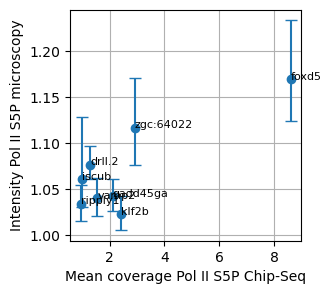

In [131]:
#plot Pol II S5P from microscopy against seq. based S5P levels
fig, ax = plt.subplots(figsize=(3, 3))

y = df_all_m_s_dome["PolII_Ser5P_level"]

lower_error = y - df_all_m_s_dome["S5P_CI_low"]
upper_error = df_all_m_s_dome["S5P_CI_high"] - y


plt.errorbar(
    df_all_m_s_dome["S5P"],
    y,
    yerr=[lower_error, upper_error],
    fmt="o",
    capsize=4
)
for _, row in df_all_m_s_dome.iterrows():
    plt.annotate(
        row["Name"],  # column containing the gene name
        (row["S5P"], row["PolII_Ser5P_level"]),
        fontsize=8
    )

plt.xlabel("Mean coverage Pol II S5P Chip-Seq")
plt.ylabel("Intensity Pol II S5P microscopy")

plt.grid()

ax.set_aspect(1./ax.get_data_ratio())

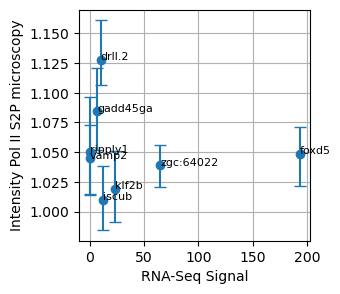

In [132]:
#plot Pol II S2P from microscopy against seq. based S2P levels
#correlation better when taking full genomic region into account, still no 1-1 comparison possible,
#potentially since final RNA levels and local S2P intentsity are mechanisically correlated, but represent differnt steps in transciption 

fig, ax = plt.subplots(figsize=(3, 3))

y = df_all_m_s_dome["PolII_Ser2P_level"]

lower_error = y - df_all_m_s_dome["S2P_CI_low"]
upper_error = df_all_m_s_dome["S2P_CI_high"] - y


plt.errorbar(
    df_all_m_s_dome["RNA"],
    y,
    yerr=[lower_error, upper_error],
    fmt="o",
    capsize=4
)

for _, row in df_all_m_s_dome.iterrows():
    plt.annotate(
        row["Name"],  # column containing the gene name
        (row["RNA"], row["PolII_Ser2P_level"]),
        fontsize=8
    )

plt.xlabel("RNA-Seq Signal")
plt.ylabel("Intensity Pol II S2P microscopy")

plt.grid()


ax.set_aspect(1./ax.get_data_ratio())

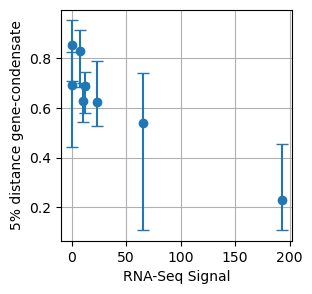

In [133]:
#plot Pol II S5P from microscopy against seq. based S5P levels
fig, ax = plt.subplots(figsize=(3, 3))

y = df_all_m_s_dome["x5_percentile_distance"]

lower_error = y - df_all_m_s_dome["dist_CI_low"]
upper_error = df_all_m_s_dome["dist_CI_high"] - y


plt.errorbar(
    df_all_m_s_dome["RNA"],
    y,
    yerr=[lower_error, upper_error],
    fmt="o",
    capsize=4
)
for _, row in df_all_m_s_dome.iterrows():
    plt.annotate(
        row["Name"],  # column containing the gene name
        (row["S5P"], row["PolII_Ser5P_level"]),
        fontsize=8
    )

plt.xlabel("RNA-Seq Signal")
plt.ylabel("5% distance gene-condensate")

plt.grid()

ax.set_aspect(1./ax.get_data_ratio())

In [134]:
#compare RNA data exression to the two stages that match microscopy data on S2P
all_genes_expr_sel_stages=all_genes_expr[all_genes_expr["Gene Name"].isin(gene_examples_names_11)][["Gene Name","blastula dome","gastrula 50%-epiboly"]]

all_genes_expr_sel_stages.columns=["Gene Name","Dome","Epi50"]

all_genes_expr_sel_stages

#keep all genes

all_full_genes_expr_sel_stages=all_genes_expr[["Gene Name","Gene ID","blastula dome","gastrula 50%-epiboly"]]

all_full_genes_expr_sel_stages.columns=["Gene Name","ID","Dome","Epi50"]

all_full_genes_expr_sel_stages

,Gene Name,ID,Dome,Epi50
0,slc35a5,ENSDARG00000000001,8.0,4.0
1,ccdc80,ENSDARG00000000002,0.8,0.4
2,nrf1,ENSDARG00000000018,114.0,62.0
3,ube2h,ENSDARG00000000019,178.0,124.0
4,slc9a3r1a,ENSDARG00000000068,71.0,85.0
...,...,...,...,...
24091,CABZ01063971.1,ENSDARG00000117814,0.0,0.0
24092,CABZ01078767.1,ENSDARG00000117816,0.4,0.7
24093,CR926130.2,ENSDARG00000117818,0.0,0.0
24094,ENSDARG00000117822,ENSDARG00000117822,0.4,0.9


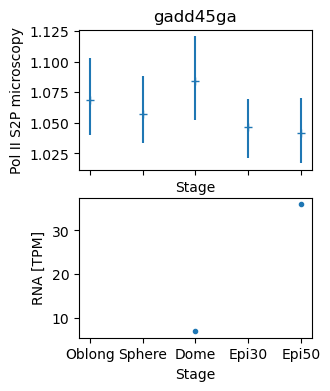

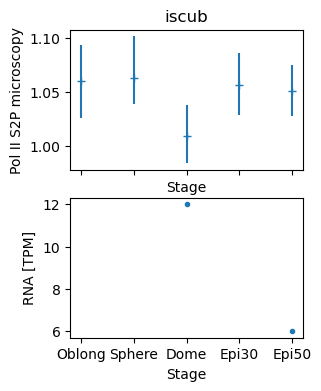

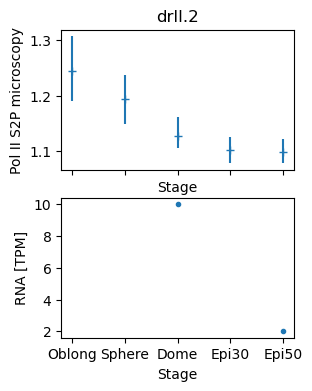

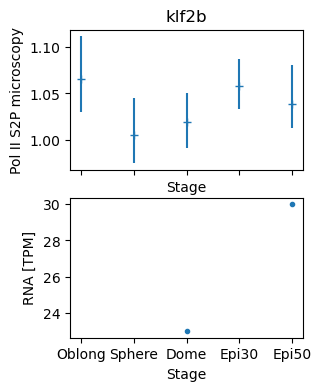

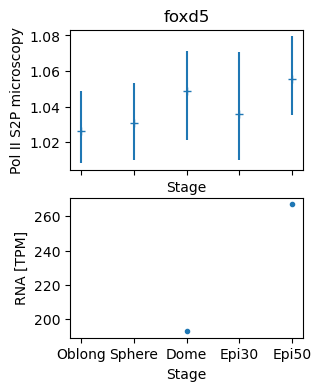

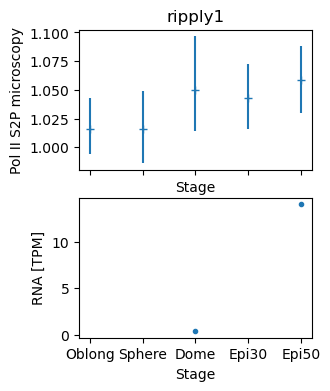

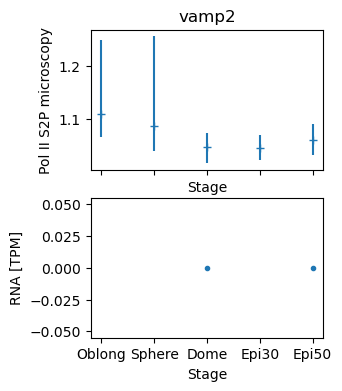

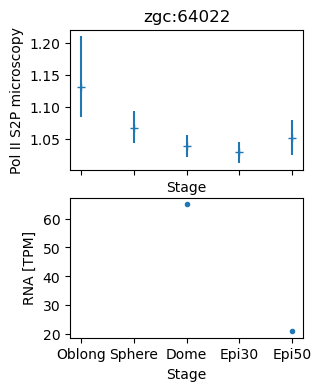

In [136]:
#compare RNA data exression to the two stages that match microscopy data on S2P

for i, row in all_genes_expr_sel_stages.iterrows():
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3, 4), sharex=True)
    
    
    name=row["Gene Name"]
    #x_dome=row["blastula dome"]
    
    
    stages_micr=["Oblong","Sphere","Dome","Epi30","Epi50"]
    S2P_list=[]
    S2P_err_h_list=[]
    S2P_err_l_list=[]
    for k in range(len(stages_micr)):
        stage_sel_micr=stages_micr[k]
        
        condition_sel_micr=(df_all_m_all_t['Name'] == name) & (df_all_m_all_t['Timepoint'] == stage_sel_micr)
        S2P=df_all_m_all_t.loc[condition_sel_micr, "PolII_Ser2P_level"].item()
        S2P_cf_l=df_all_m_all_t.loc[condition_sel_micr, "S2P_CI_low"].item()
        S2P_cf_h=df_all_m_all_t.loc[condition_sel_micr, "S2P_CI_high"].item()
        
        S2P_err_l=S2P-S2P_cf_l
        S2P_err_h=S2P_cf_h-S2P
        
        S2P_list.append(S2P)
        S2P_err_l_list.append(S2P_err_l)
        S2P_err_h_list.append(S2P_err_h)
        
    ax1.errorbar(stages_micr,S2P_list,fmt="+",yerr=[S2P_err_l_list,S2P_err_h_list])
    ax1.set_title(name)
    ax1.set_xlabel("Stage")
    ax1.set_ylabel("Pol II S2P microscopy")
    
    stages_seq=["Dome","Epi50"]
    RNA_list=[]
    for k in range(len(stages_seq)):
        stage_sel_seq=stages_seq[k]
        
        condition_sel_seq=(all_genes_expr_sel_stages['Gene Name'] == name) 
        RNA=all_genes_expr_sel_stages.loc[condition_sel_seq, stage_sel_seq].item()
        #print(RNA)
        
        RNA_list.append(RNA)

    ax2.errorbar(stages_seq,RNA_list,fmt=".")
    #ax2.set_title(name)
    ax2.set_xlabel("Stage")
    ax2.set_ylabel("RNA [TPM]")


gadd45ga / Dome: n=2, SEM=1.5
gadd45ga / Epi50: n=2, SEM=17.8


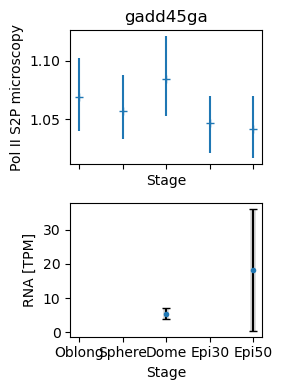

iscub / Dome: n=3, SEM=3.71
iscub / Epi50: n=3, SEM=2


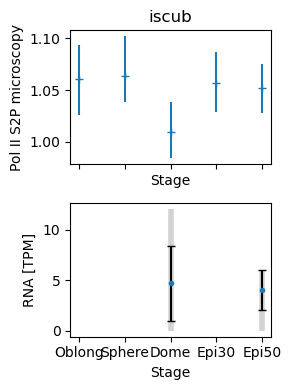

drll.2 / Dome: n=4, SEM=39.8
drll.2 / Epi50: n=4, SEM=8.48


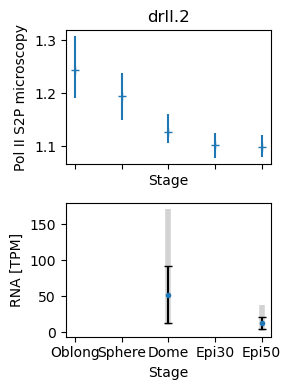

klf2b / Dome: n=1, SEM=0
klf2b / Epi50: n=1, SEM=0


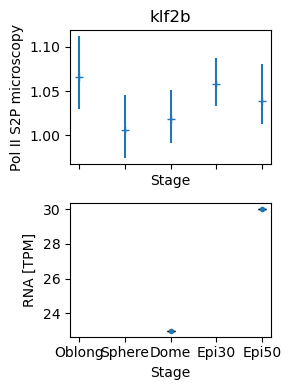

foxd5 / Dome: n=2, SEM=96.5
foxd5 / Epi50: n=2, SEM=133


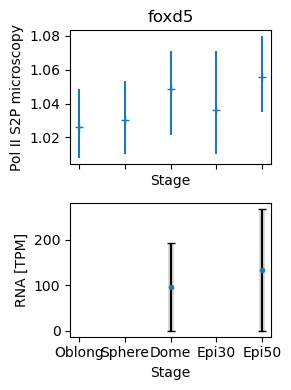

ripply1 / Dome: n=4, SEM=0.236
ripply1 / Epi50: n=4, SEM=3.42


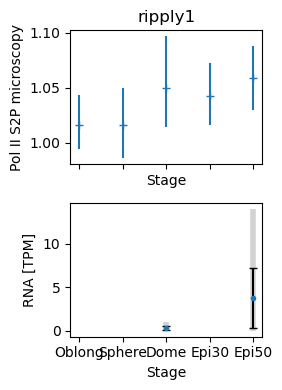

vamp2 / Dome: n=7, SEM=0
vamp2 / Epi50: n=7, SEM=0.167


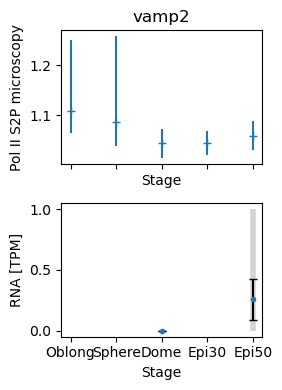

zgc:64022 / Dome: n=1, SEM=0
zgc:64022 / Epi50: n=1, SEM=0


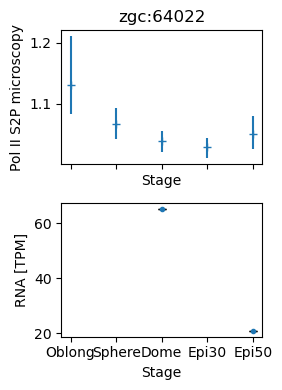

In [137]:
# Build a lookup: labeled gene -> list of gene NAMES in its tiled region
region_lookup = dict(
    zip(df_region_agg["Name"], df_region_agg["genes_in_region"].str.split(", "))
)

# Build a Name -> ID mapping from the full dataframe (assumes an "ID" column there)
name_to_id = dict(
    zip(all_genes_details_expr_signals_2["Name"], all_genes_details_expr_signals_2["ID"])
)

for i, row in all_genes_expr_sel_stages.iterrows():
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(3, 4), sharex=True)

    name = row["Gene Name"]

    stages_micr = ["Oblong", "Sphere", "Dome", "Epi30", "Epi50"]
    S2P_list = []
    S2P_err_h_list = []
    S2P_err_l_list = []
    for k in range(len(stages_micr)):
        stage_sel_micr = stages_micr[k]

        condition_sel_micr = (df_all_m_all_t['Name'] == name) & (df_all_m_all_t['Timepoint'] == stage_sel_micr)
        S2P = df_all_m_all_t.loc[condition_sel_micr, "PolII_Ser2P_level"].item()
        S2P_cf_l = df_all_m_all_t.loc[condition_sel_micr, "S2P_CI_low"].item()
        S2P_cf_h = df_all_m_all_t.loc[condition_sel_micr, "S2P_CI_high"].item()

        S2P_err_l = S2P - S2P_cf_l
        S2P_err_h = S2P_cf_h - S2P

        S2P_list.append(S2P)
        S2P_err_l_list.append(S2P_err_l)
        S2P_err_h_list.append(S2P_err_h)

    ax1.errorbar(stages_micr, S2P_list, fmt="+", yerr=[S2P_err_l_list, S2P_err_h_list])
    ax1.set_title(name)
    ax1.set_xlabel("Stage")
    ax1.set_ylabel("Pol II S2P microscopy")

    # --- RNA: averaged across all gene IDs in this labeled gene's tiled region ---
    genes_for_region = region_lookup.get(name, [name])

    # Convert gene names -> gene IDs; warn about any that don't resolve
    ids_for_region = []
    for g in genes_for_region:
        gid = name_to_id.get(g)
        if gid is None:
            print(f"Warning: no ID found for gene '{g}' (region of '{name}'), skipped.")
        else:
            ids_for_region.append(gid)

    stages_seq = ["Dome", "Epi50"]
    RNA_mean_list = []
    RNA_err_l_list = []   # mean - min
    RNA_err_h_list = []   # max - mean
    RNA_sem_list = []     # standard error of the mean
    RNA_n_list = []       # n genes contributing, for reference/printing
    for k in range(len(stages_seq)):
        stage_sel_seq = stages_seq[k]

        condition_sel_seq = all_full_genes_expr_sel_stages['ID'].isin(ids_for_region)  # now filtering by ID
        RNA_values = all_full_genes_expr_sel_stages.loc[condition_sel_seq, stage_sel_seq]

        n = len(RNA_values)
        RNA_mean = RNA_values.mean()
        RNA_min = RNA_values.min()
        RNA_max = RNA_values.max()
        # SEM undefined for n<=1; report 0 in that case
        RNA_sem = RNA_values.std(ddof=1) / np.sqrt(n) if n > 1 else 0.0

        RNA_mean_list.append(RNA_mean)
        RNA_err_l_list.append(RNA_mean - RNA_min)
        RNA_err_h_list.append(RNA_max - RNA_mean)
        RNA_sem_list.append(RNA_sem)
        RNA_n_list.append(n)

    # Wide, light error bar: min/max range
    ax2.errorbar(
        stages_seq, RNA_mean_list,
        yerr=[RNA_err_l_list, RNA_err_h_list],
        fmt="none", ecolor="lightgray", elinewidth=4, capsize=0, zorder=1,
    )
    # Narrow, prominent error bar: SEM
    ax2.errorbar(
        stages_seq, RNA_mean_list,
        yerr=RNA_sem_list,
        fmt=".", ecolor="black", elinewidth=1.5, capsize=3, zorder=2,
    )

    ax2.set_xlabel("Stage")
    ax2.set_ylabel("RNA [TPM]")

    # Optional: print n and SEM per stage for quick reference
    for stage, n, sem in zip(stages_seq, RNA_n_list, RNA_sem_list):
        print(f"{name} / {stage}: n={n}, SEM={sem:.3g}")

    plt.tight_layout()
    plt.show()

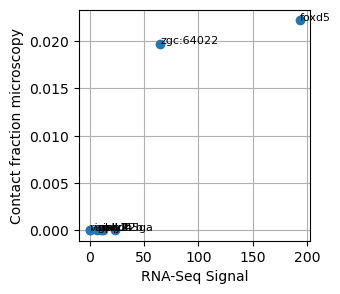

In [138]:
#plot contact freq. from imaging data againes RNA 
fig, ax = plt.subplots(figsize=(3, 3))

y = df_all_m_s_dome["contact_fraction"]

plt.errorbar(
    df_all_m_s_dome["RNA"],
    y,
    fmt="o",
    capsize=4
)

for _, row in df_all_m_s_dome.iterrows():
    plt.annotate(
        row["Name"],  # column containing the gene name
        ( row["RNA"],row["contact_fraction"]),
        fontsize=8
    )

plt.xlabel("RNA-Seq Signal")
plt.ylabel("Contact fraction microscopy")

plt.grid()

ax.set_aspect(1./ax.get_data_ratio())

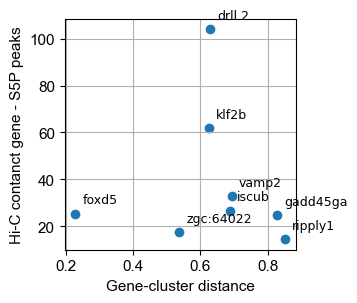

In [139]:
#plot Hi-C interaction against gene-cluster distance
fig, ax = plt.subplots(figsize=(3, 3))
ax.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["Int. freq."],)

for _, row in df_merged_dist_HiC.iterrows():
    ax.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["Int. freq."]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, 5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("Hi-C contanct gene - S5P peaks",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)

plt.grid()


ax.set_aspect(1./ax.get_data_ratio())
#plt.tight_layout()

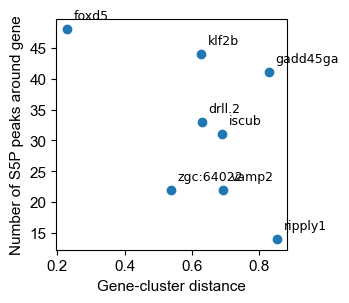

In [140]:
# number of S5P peaks against gene-cluster distance
fig, ax = plt.subplots(figsize=(3, 3))
ax.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["Count overlap"],)

for _, row in df_merged_dist_HiC.iterrows():
    ax.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["Count overlap"]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, 5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("Number of S5P peaks around gene",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)

ax.set_aspect(1./ax.get_data_ratio())

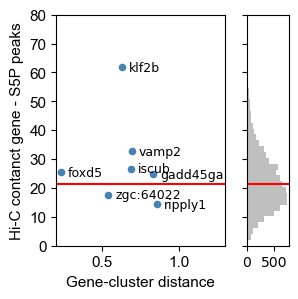

In [123]:
y_all = all_genes_details_expr_signals_2["Int. freq."]   # histogram uses ALL y-values

fig = plt.figure(figsize=(3, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.2)

# Scatter plot (left)
ax_scatter = fig.add_subplot(gs[0, 0])
ax_scatter.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["Int. freq."], s=20, color="steelblue")
plt.axhline(np.median(y_all),color="red")


for _, row in df_merged_dist_HiC.iterrows():
    ax_scatter.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["Int. freq."]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, -5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )

plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("Hi-C contanct gene - S5P peaks",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)
plt.ylim(0,80)
plt.xlim(0.2,1.3)

# Histogram on the right
ax_hist = fig.add_subplot(gs[0, 1], sharey=ax_scatter)
ax_hist.hist(y_all, bins=200, orientation="horizontal", color="gray", alpha=0.5)
plt.axhline(np.median(y_all),color="red")
# Hide redundant y-axis tick labels
plt.setp(ax_hist.get_yticklabels(), visible=False)

plt.show()

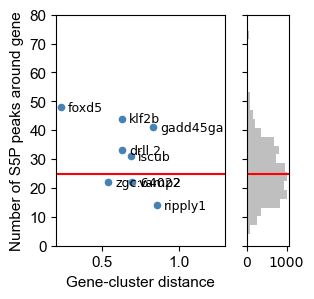

In [124]:
y_all = all_genes_details_expr_signals_2["Count overlap"]   # histogram uses ALL y-values

fig = plt.figure(figsize=(3, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.2)

# Scatter plot (left)
ax_scatter = fig.add_subplot(gs[0, 0])
ax_scatter.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["Count overlap"], s=20, color="steelblue")
plt.axhline(np.median(y_all),color="red")


for _, row in df_merged_dist_HiC.iterrows():
    ax_scatter.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["Count overlap"]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, -5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )

plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("Number of S5P peaks around gene",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)
plt.ylim(0,80)
plt.xlim(0.2,1.3)

# Histogram on the right
ax_hist = fig.add_subplot(gs[0, 1], sharey=ax_scatter)
ax_hist.hist(y_all, bins=30, orientation="horizontal", color="gray", alpha=0.5)
plt.axhline(np.median(y_all),color="red")
# Hide redundant y-axis tick labels
plt.setp(ax_hist.get_yticklabels(), visible=False)

plt.show()

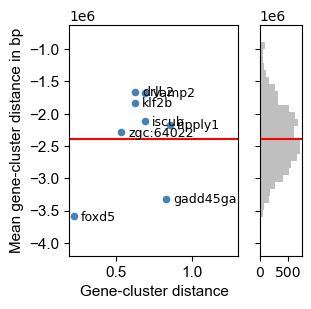

In [125]:
y_all = all_genes_details_expr_signals_2["Mean sep. in bp"]   # histogram uses ALL y-values

fig = plt.figure(figsize=(3, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.2)

# Scatter plot (left)
ax_scatter = fig.add_subplot(gs[0, 0])
ax_scatter.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["Mean sep. in bp"], s=20, color="steelblue")
plt.axhline(np.median(y_all),color="red")


for _, row in df_merged_dist_HiC.iterrows():
    ax_scatter.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["Mean sep. in bp"]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, -5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )

plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("Mean gene-cluster distance in bp",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)
#plt.ylim(0,80)
plt.xlim(0.2,1.3)

# Histogram on the right
ax_hist = fig.add_subplot(gs[0, 1], sharey=ax_scatter)
ax_hist.hist(y_all, bins=30, orientation="horizontal", color="gray", alpha=0.5)
plt.axhline(np.median(y_all),color="red")
# Hide redundant y-axis tick labels
plt.setp(ax_hist.get_yticklabels(), visible=False)

plt.show()

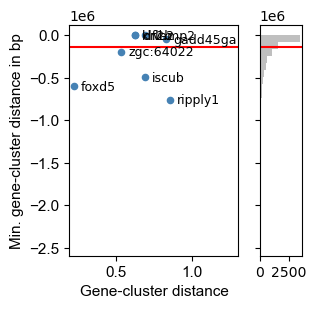

In [126]:
y_all = all_genes_details_expr_signals_2["Min. sep. in bp"]   # histogram uses ALL y-values

fig = plt.figure(figsize=(3, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.2)

# Scatter plot (left)
ax_scatter = fig.add_subplot(gs[0, 0])
ax_scatter.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["Min. sep. in bp"], s=20, color="steelblue")
plt.axhline(np.median(y_all),color="red")


for _, row in df_merged_dist_HiC.iterrows():
    ax_scatter.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["Min. sep. in bp"]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, -5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )

plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("Min. gene-cluster distance in bp",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)
#plt.ylim(0,80)
plt.xlim(0.2,1.3)

# Histogram on the right
ax_hist = fig.add_subplot(gs[0, 1], sharey=ax_scatter)
ax_hist.hist(y_all, bins=30, orientation="horizontal", color="gray", alpha=0.5)
plt.axhline(np.median(y_all),color="red")
# Hide redundant y-axis tick labels
plt.setp(ax_hist.get_yticklabels(), visible=False)

plt.show()

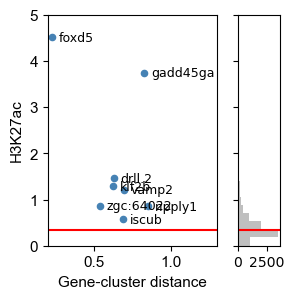

In [127]:
y_all = all_genes_details_expr_signals_2["H3K27ac"]   # histogram uses ALL y-values

fig = plt.figure(figsize=(3, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.2)

# Scatter plot (left)
ax_scatter = fig.add_subplot(gs[0, 0])
ax_scatter.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["H3K27ac"], s=20, color="steelblue")
plt.axhline(np.median(y_all),color="red")


for _, row in df_merged_dist_HiC.iterrows():
    ax_scatter.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["H3K27ac"]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, -5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )

plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("H3K27ac",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)
plt.ylim(0,5)
plt.xlim(0.2,1.3)

# Histogram on the right
ax_hist = fig.add_subplot(gs[0, 1], sharey=ax_scatter)
ax_hist.hist(y_all, bins=100, orientation="horizontal", color="gray", alpha=0.5)
plt.axhline(np.median(y_all),color="red")
# Hide redundant y-axis tick labels
plt.setp(ax_hist.get_yticklabels(), visible=False)

plt.show()

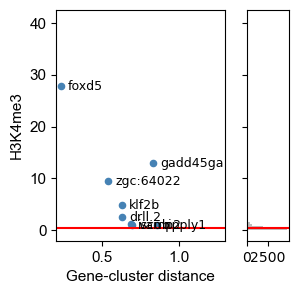

In [128]:
y_all = all_genes_details_expr_signals_2["H3K4me3"]   # histogram uses ALL y-values

fig = plt.figure(figsize=(3, 3))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1], wspace=0.2)

# Scatter plot (left)
ax_scatter = fig.add_subplot(gs[0, 0])
ax_scatter.scatter(df_merged_dist_HiC["x5_percentile_distance"], df_merged_dist_HiC["H3K4me3"], s=20, color="steelblue")
plt.axhline(np.median(y_all),color="red")


for _, row in df_merged_dist_HiC.iterrows():
    ax_scatter.annotate(
        row["Name"],                  # the label text
        (row["x5_percentile_distance"], row["H3K4me3"]),          # point to annotate
        textcoords="offset points",    # position text with an offset
        xytext=(5, -5),                 # offset (x,y) in points
        ha="left", va="bottom", fontsize=9, color="black"
    )

plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.ylabel("H3K4me3",fontname = "Arial",fontsize=11)
plt.xlabel("Gene-cluster distance",fontname = "Arial",fontsize=11)
#plt.ylim(0,5)
plt.xlim(0.2,1.3)

# Histogram on the right
ax_hist = fig.add_subplot(gs[0, 1], sharey=ax_scatter)
ax_hist.hist(y_all, bins=100, orientation="horizontal", color="gray", alpha=0.5)
plt.axhline(np.median(y_all),color="red")
# Hide redundant y-axis tick labels
plt.setp(ax_hist.get_yticklabels(), visible=False)

plt.show()

In [141]:
#add a text string of the model parameters to figure panels
def linear_equation_string(intercept, coefs, feature_names, decimals=2):
        """Return a string like: y = 1.23 + 0.45*a - 6.78*b + 0.00*c"""
        parts = []
        # Intercept
        parts.append(f"{intercept:.{decimals}f}")
        # Coefficients with signs
        for name, c in zip(feature_names, coefs):
            sign = " + " if c >= 0 else " - "
            parts.append(f"{sign}{abs(c):.{decimals}f}·{name}")
        return "Dist. = " + "\n".join(parts)

                              WLS Regression Results                              
Dep. Variable:     x5_percentile_distance   R-squared:                       0.763
Model:                                WLS   Adj. R-squared:                  0.586
Method:                     Least Squares   F-statistic:                     4.299
Date:                    Wed, 16 Sep 2026   Prob (F-statistic):             0.0964
Time:                            09:11:02   Log-Likelihood:                 8.9777
No. Observations:                       8   AIC:                            -9.955
Df Residuals:                           4   BIC:                            -9.638
Df Model:                               3                                         
Covariance Type:                nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1772: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


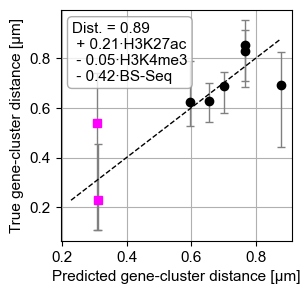

In [142]:

#statsmodel for p-values
import statsmodels.api as sm

#df_sel=df_merged_dist_HiC[["Name","Distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","GC content","Count overlap","Bool overlap CpG"]]


df_sel=df_all_m_s_dome[["Name","x5_percentile_distance","H3K27ac","H3K4me3","BS-Seq"]]

X = df_sel.drop(columns=["Name", "x5_percentile_distance"])   # the features a, b, c, ...

y = df_sel["x5_percentile_distance"]                           # the target

y_low=abs(df_all_m_s_dome["x5_percentile_distance"]-df_all_m_s_dome["dist_CI_low"])
y_high=abs(df_all_m_s_dome["x5_percentile_distance"]-df_all_m_s_dome["dist_CI_high"])


# Convert asymmetric error bars to approx. standard deviation
sigma = (y_high + y_low) / (2*1.96)


# Weights = 1/sigma^2
weights = 1.0 / (sigma**2 )




# X: predictors as a DataFrame or 2D array
# y: response as a Series or 1D array
X_sm = sm.add_constant(X.astype(float))
model2 = sm.WLS(y.astype(float), X_sm,weights=weights.astype(float)).fit()
result2 = sm.WLS(y, X_sm, weights=weights.astype(float)).fit()

#model2 = sm.WLS(y.astype(float), X_sm).fit()
#result2 = sm.WLS(y, X_sm).fit()

print(model2.summary())
print(model2.pvalues)

y_pred = result2.predict(X_sm)


fig, ax = plt.subplots(figsize=(3, 3))

ax.errorbar(
    y_pred,
    df_sel["x5_percentile_distance"],
    yerr=[y_low, y_high],
    fmt=".",
    color="red",
    ecolor="gray",
    elinewidth=1,
    capsize=3)

for index,row in df_all_m_s_dome.iterrows():
    if df_all_m_s_dome["Name"][index] in ["zgc:64022","foxd5"]:
        color1="magenta"
        fmt1="s"
    else:
        color1="black"
        fmt1="o"
    ax.errorbar(
    y_pred[index],
    df_sel["x5_percentile_distance"][index],
    fmt=fmt1,
    color=color1,
    ecolor="gray",
    elinewidth=1,
    capsize=3)


# Diagonal reference line y = x
min_val = min(df_sel["x5_percentile_distance"].min(), y_pred.min())
max_val = max(df_sel["x5_percentile_distance"].max(), y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)

eq_text = linear_equation_string(model2.params[0],model2.params[1:], X.columns, decimals=2)
# Add equation text inside the axes (top-left corner)
ax.text(
    0.05, 0.95,            # axes fraction coordinates (x, y)
    eq_text,
    transform=ax.transAxes,
    va="top", ha="left",
    fontsize=11,
    fontname = "Arial",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999")
)



# Labels & layout
ax.set_ylabel("True gene-cluster distance [μm]",fontname = "Arial",fontsize=11)
ax.set_xlabel("Predicted gene-cluster distance [μm]",fontname = "Arial",fontsize=11)
#ax.set_title("Predicted vs. True Distance")
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.grid()
ax.set_aspect(1./ax.get_data_ratio())


name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/"+"prediction_gene_cluster_distance_3.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
    
    
plt.show()

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/statsmodels/regression/linear_model.py:889: ValueWarning: Weights are not supported in OLS and will be ignoredAn exception will be raised in the next version.
  warnings.warn(msg, ValueWarning)
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/statsmodels/base/model.py:127: ValueWarning: unknown kwargs ['weights']
  warnings.warn(msg, ValueWarning)
/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1772: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


                              OLS Regression Results                              
Dep. Variable:     x5_percentile_distance   R-squared:                       0.748
Model:                                OLS   Adj. R-squared:                  0.559
Method:                     Least Squares   F-statistic:                     3.962
Date:                    Wed, 16 Sep 2026   Prob (F-statistic):              0.108
Time:                            09:11:04   Log-Likelihood:                 7.7773
No. Observations:                       8   AIC:                            -7.555
Df Residuals:                           4   BIC:                            -7.237
Df Model:                               3                                         
Covariance Type:                nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       

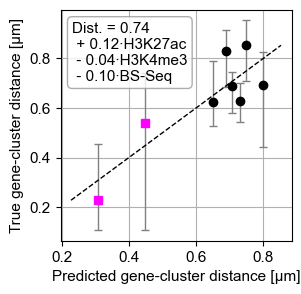

In [143]:

#statsmodel for p-values
import statsmodels.api as sm

#df_sel=df_merged_dist_HiC[["Name","Distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","GC content","Count overlap","Bool overlap CpG"]]


df_sel=df_all_m_s_dome[["Name","x5_percentile_distance","H3K27ac","H3K4me3","BS-Seq"]]

X = df_sel.drop(columns=["Name", "x5_percentile_distance"])   # the features a, b, c, ...

y = df_sel["x5_percentile_distance"]                           # the target

y_low=abs(df_all_m_s_dome["x5_percentile_distance"]-df_all_m_s_dome["dist_CI_low"])
y_high=abs(df_all_m_s_dome["x5_percentile_distance"]-df_all_m_s_dome["dist_CI_high"])


# Convert asymmetric error bars to approx. standard deviation
sigma = (y_high + y_low) / (2*1.96)


# Weights = 1/sigma^2
weights = 1.0 / (sigma**2 )




# X: predictors as a DataFrame or 2D array
# y: response as a Series or 1D array
X_sm = sm.add_constant(X.astype(float))



model2 = sm.OLS(y.astype(float), X_sm).fit(cov_type="HC3")
result2 = sm.OLS(y, X_sm, weights=weights.astype(float)).fit()

model2 = sm.OLS(y.astype(float), X_sm).fit()
result2 = sm.OLS(y, X_sm).fit()

###################
####################

#model2 = sm.WLS(y.astype(float), X_sm,weights=weights.astype(float)).fit()
#result2 = sm.WLS(y, X_sm, weights=weights.astype(float)).fit()

#model2 = sm.WLS(y.astype(float), X_sm).fit()
#result2 = sm.WLS(y, X_sm).fit()

print(model2.summary())
print(model2.pvalues)


##################
##################
from sklearn.model_selection import LeaveOneOut
from sklearn.linear_model import LinearRegression

loo = LeaveOneOut()
y_pred_cv = np.zeros(len(y))
Xv = X.astype(float).values
yv = y.astype(float).values

for train_idx, test_idx in loo.split(Xv):
    lr = LinearRegression().fit(Xv[train_idx], yv[train_idx],
                                 sample_weight=weights.values[train_idx])
    y_pred_cv[test_idx] = lr.predict(Xv[test_idx])

ss_res = np.sum((yv - y_pred_cv)**2)
ss_tot = np.sum((yv - yv.mean())**2)
q2 = 1 - ss_res/ss_tot
print("LOO Q²:", q2)
####################
####################
n_perm = 5000
observed_r2 = model2.rsquared
perm_r2 = np.zeros(n_perm)

y_arr = y.values.astype(float)
for i in range(n_perm):
    y_perm = np.random.permutation(y_arr)
    m = sm.WLS(y_perm, X_sm, weights=weights.astype(float)).fit()
    perm_r2[i] = m.rsquared

p_perm = (np.sum(perm_r2 >= observed_r2) + 1) / (n_perm + 1)
print("Permutation p-value:", p_perm)
####################
####################

y_pred = result2.predict(X_sm)


fig, ax = plt.subplots(figsize=(3, 3))

ax.errorbar(
    y_pred,
    df_sel["x5_percentile_distance"],
    yerr=[y_low, y_high],
    fmt=".",
    color="red",
    ecolor="gray",
    elinewidth=1,
    capsize=3)

for index,row in df_all_m_s_dome.iterrows():
    if df_all_m_s_dome["Name"][index] in ["zgc:64022","foxd5"]:
        color1="magenta"
        fmt1="s"
    else:
        color1="black"
        fmt1="o"
    ax.errorbar(
    y_pred[index],
    df_sel["x5_percentile_distance"][index],
    fmt=fmt1,
    color=color1,
    ecolor="gray",
    elinewidth=1,
    capsize=3)


# Diagonal reference line y = x
min_val = min(df_sel["x5_percentile_distance"].min(), y_pred.min())
max_val = max(df_sel["x5_percentile_distance"].max(), y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)

eq_text = linear_equation_string(model2.params[0],model2.params[1:], X.columns, decimals=2)
# Add equation text inside the axes (top-left corner)
ax.text(
    0.05, 0.95,            # axes fraction coordinates (x, y)
    eq_text,
    transform=ax.transAxes,
    va="top", ha="left",
    fontsize=11,
    fontname = "Arial",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999")
)



# Labels & layout
ax.set_ylabel("True gene-cluster distance [μm]",fontname = "Arial",fontsize=11)
ax.set_xlabel("Predicted gene-cluster distance [μm]",fontname = "Arial",fontsize=11)
#ax.set_title("Predicted vs. True Distance")
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.grid()
ax.set_aspect(1./ax.get_data_ratio())


name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/"+"prediction_gene_cluster_distance_3.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
    
    
plt.show()

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1772: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


                              OLS Regression Results                              
Dep. Variable:     x5_percentile_distance   R-squared:                       0.748
Model:                                OLS   Adj. R-squared:                  0.559
Method:                     Least Squares   F-statistic:                     3.962
Date:                    Wed, 16 Sep 2026   Prob (F-statistic):              0.108
Time:                            09:11:06   Log-Likelihood:                 7.7773
No. Observations:                       8   AIC:                            -7.555
Df Residuals:                           4   BIC:                            -7.237
Df Model:                               3                                         
Covariance Type:                nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       

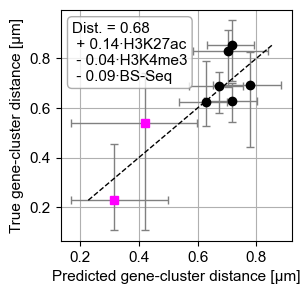

In [144]:
# Goal: test whether H3K27ac, H3K4me3, BS-Seq predict gene-cluster
# distance, given only 8 genes with asymmetric measurement CIs.
#
# 1. X (chromatin features) is NEVER resampled - all 8 genes and
#    their feature values stay fixed in every iteratio-> no statement about wheter this is a genome-wideobservation, captured by 8 representative genes
# 2. Only y (gene-cluster distance) is resampled: for each gene,
#    draw a new value from a split-normal centered on its measured
#    distance, using its own asymmetric CI (sigma_low/sigma_high).
# 3. Refit OLS on (X, y_boot) each iteration (n_boot=5000) ->
#    distribution of R^2 and coefficients = uncertainty from
#    MEASUREMENT NOISE ALONE (not from which genes were sampled).
# 4. P-value (permutation test): repeat step 2, then additionally
#    shuffle y_boot across genes to destroy the true X-y pairing.
#    Refit and record R^2 -> null distribution ("fit quality
#    achievable by chance, same noise, no real relationship").
#    p = fraction of null R^2 >= observed R^2 (+1 correction).
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# =========================================================
# Setup
# =========================================================
df_sel = df_all_m_s_dome[["Name", "x5_percentile_distance", "H3K27ac", "H3K4me3", "BS-Seq"]]
X = df_sel.drop(columns=["Name", "x5_percentile_distance"]).astype(float)
y = df_sel["x5_percentile_distance"].astype(float)

y_low  = (df_all_m_s_dome["x5_percentile_distance"] - df_all_m_s_dome["dist_CI_low"]).abs()
y_high = (df_all_m_s_dome["dist_CI_high"] - df_all_m_s_dome["x5_percentile_distance"]).abs()

# Convert 95% CI half-widths to approx. per-side standard deviations
sigma_low  = (y_low  / 1.96).values
sigma_high = (y_high / 1.96).values

n = len(y)
y_arr = y.values
X_sm = sm.add_constant(X, has_constant="add")  # same 8 genes every iteration, never resampled


def sample_split_normal(mu, s_low, s_high):
    """Draw one value from a two-piece (split) normal: sigma_low below mu,
    sigma_high above mu. Approximates an asymmetric confidence interval."""
    p_low = s_low / (s_low + s_high)
    if np.random.rand() < p_low:
        return mu - abs(np.random.normal(0, s_low))
    else:
        return mu + abs(np.random.normal(0, s_high))


# --- Point-estimate OLS fit (for reference) ---
model_obs = sm.OLS(y, X_sm).fit()
print(model_obs.summary())


# =========================================================
# Fixed-X bootstrap: resample only the outcome (per-gene noise), X held fixed
# =========================================================
n_boot = 5000
boot_r2_fixedX = np.zeros(n_boot)
boot_params_fixedX = np.zeros((n_boot, X_sm.shape[1]))

for i in range(n_boot):
    y_boot = np.array([
        sample_split_normal(y_arr[j], sigma_low[j], sigma_high[j]) for j in range(n)
    ])
    m = sm.OLS(y_boot, X_sm).fit()
    boot_r2_fixedX[i] = m.rsquared
    boot_params_fixedX[i, :] = m.params

r2_ci_fixedX = np.percentile(boot_r2_fixedX, [2.5, 97.5])
param_ci_fixedX = np.percentile(boot_params_fixedX, [2.5, 97.5], axis=0)
observed_r2_fixedX = np.median(boot_r2_fixedX)

print(f"\nFixed-X bootstrap R^2: median = {observed_r2_fixedX:.3f}, "
      f"95% CI = [{r2_ci_fixedX[0]:.3f}, {r2_ci_fixedX[1]:.3f}]")
for name, lo, hi in zip(X_sm.columns, param_ci_fixedX[0], param_ci_fixedX[1]):
    print(f"  {name}: 95% CI = [{lo:.3f}, {hi:.3f}]")


# =========================================================
# Bootstrap-based permutation p-value (X fixed, y noise resampled, then permuted)
# =========================================================
n_perm = 5000
perm_r2_fixedX = np.zeros(n_perm)

for i in range(n_perm):
    y_boot = np.array([
        sample_split_normal(y_arr[j], sigma_low[j], sigma_high[j]) for j in range(n)
    ])
    y_perm = np.random.permutation(y_boot)  # break the X-y relationship, X stays fixed
    m = sm.OLS(y_perm, X_sm).fit()
    perm_r2_fixedX[i] = m.rsquared

p_perm_fixedX = (np.sum(perm_r2_fixedX >= observed_r2_fixedX) + 1) / (n_perm + 1)
print("Fixed-X bootstrap permutation p-value:", p_perm_fixedX)


# =========================================================
# Figure: predicted vs. true gene-cluster distance, with bootstrap prediction CIs
# =========================================================
X_orig_sm = X_sm.values  # same 8 rows, since X was never resampled

boot_preds_fixedX = boot_params_fixedX @ X_orig_sm.T   # shape (n_boot, n_genes)

pred_median_fixedX = np.median(boot_preds_fixedX, axis=0)
pred_lo_fixedX, pred_hi_fixedX = np.percentile(boot_preds_fixedX, [2.5, 97.5], axis=0)

pred_err_low_fixedX  = pred_median_fixedX - pred_lo_fixedX
pred_err_high_fixedX = pred_hi_fixedX - pred_median_fixedX

fig, ax = plt.subplots(figsize=(3, 3))

for i, (idx, row) in enumerate(df_all_m_s_dome.iterrows()):
    is_highlight = row["Name"] in ["zgc:64022", "foxd5"]
    color1 = "magenta" if is_highlight else "black"
    fmt1 = "s" if is_highlight else "o"

    ax.errorbar(
        pred_median_fixedX[i],
        y_arr[i],
        xerr=[[pred_err_low_fixedX[i]], [pred_err_high_fixedX[i]]],
        yerr=[[y_low.values[i]], [y_high.values[i]]],
        fmt=fmt1,
        color=color1,
        ecolor="gray",
        elinewidth=1,
        capsize=3,
    )

min_val = min(y_arr.min(), pred_median_fixedX.min())
max_val = max(y_arr.max(), pred_median_fixedX.max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)

eq_text = linear_equation_string(
    np.median(boot_params_fixedX[:, 0]),
    np.median(boot_params_fixedX[:, 1:], axis=0),
    X.columns,
    decimals=2,
)
ax.text(
    0.05, 0.95, eq_text,
    transform=ax.transAxes, va="top", ha="left",
    fontsize=11, fontname="Arial",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999"),
)

ax.set_ylabel("True gene-cluster distance [μm]", fontname="Arial", fontsize=11)
ax.set_xlabel("Predicted gene-cluster distance [μm]", fontname="Arial", fontsize=11)
plt.yticks(fontname="Arial", fontsize=11)
plt.xticks(fontname="Arial", fontsize=11)
plt.grid()
ax.set_aspect(1. / ax.get_data_ratio())

name_s = "clustering_genome_sections/figures/fig_analysing_genome_sections_7/prediction_gene_cluster_distance_fixedX_bootstrap_1.pdf"
#plt.savefig(name_s, format="pdf", dpi=300, bbox_inches="tight")

#plt.show()

In [146]:
#correlations in parameters

from scipy.stats import pearsonr, spearmanr
for col in ["H3K27ac","H3K4me3","BS-Seq"]:
    r_p, p_p = pearsonr(X[col].astype(float), y.astype(float))
    r_s, p_s = spearmanr(X[col].astype(float), y.astype(float))
    print(col, "Pearson r=%.2f p=%.3f"%(r_p,p_p), "Spearman r=%.2f p=%.3f"%(r_s,p_s))

H3K27ac Pearson r=-0.47 p=0.244 Spearman r=-0.36 p=0.385
H3K4me3 Pearson r=-0.75 p=0.032 Spearman r=-0.64 p=0.086
BS-Seq Pearson r=0.58 p=0.133 Spearman r=0.12 p=0.779


In [147]:
from scipy.stats import spearmanr
import numpy as np

def perm_test_corr(x, y, n_perm=10000):
    obs_r, _ = spearmanr(x, y)
    perm_r = np.zeros(n_perm)
    for i in range(n_perm):
        perm_r[i] = spearmanr(x, np.random.permutation(y))[0]
    p = (np.sum(np.abs(perm_r) >= np.abs(obs_r)) + 1) / (n_perm + 1)
    return obs_r, p

for col in ["H3K27ac","H3K4me3","BS-Seq"]:
    r, p = perm_test_corr(X[col].values, y.values)
    print(col, "Spearman r=%.2f, perm p=%.3f" % (r, p))

H3K27ac Spearman r=-0.36, perm p=0.390
H3K4me3 Spearman r=-0.64, perm p=0.100
BS-Seq Spearman r=0.12, perm p=0.805


In [148]:
mask = ~df_all_m_s_dome["Name"].isin(["zgc:64022","foxd5"])
for col in ["H3K27ac","H3K4me3","BS-Seq"]:
    r_full, p_full = spearmanr(X[col], y)
    r_sub, p_sub = spearmanr(X[col][mask], y[mask])
    print(col, "full: r=%.2f p=%.3f | excl. outliers: r=%.2f p=%.3f (n=%d)" %
          (r_full, p_full, r_sub, p_sub, mask.sum()))

H3K27ac full: r=-0.36 p=0.385 | excl. outliers: r=-0.14 p=0.787 (n=6)
H3K4me3 full: r=-0.64 p=0.086 | excl. outliers: r=-0.43 p=0.397 (n=6)
BS-Seq full: r=0.12 p=0.779 | excl. outliers: r=-0.60 p=0.208 (n=6)


In [149]:
df_all_m_s_dome[["Name", "x5_percentile_distance", "dist_CI_low", "dist_CI_high"]].sort_values(
    "x5_percentile_distance", ascending=False
)

,Name,x5_percentile_distance,dist_CI_low,dist_CI_high
7,ripply1,0.852496,0.707827,0.953634
5,gadd45ga,0.828102,0.683657,0.915321
2,vamp2,0.693203,0.440827,0.827421
6,iscub,0.688592,0.580969,0.743630
0,drll.2,0.629373,0.545200,0.698640
3,klf2b,0.625877,0.526349,0.788263
1,zgc:64022,0.537475,0.108325,0.740090
4,foxd5,0.227936,0.107045,0.453962


In [150]:
df_all_m_all_t.sort_values(
    "x5_percentile_distance", ascending=True)

,Row,x5_percentile_distance,dist_CI_low,dist_CI_high,PolII_Ser5P_level,S5P_CI_low,S5P_CI_high,PolII_Ser2P_level,S2P_CI_low,S2P_CI_high,contact_fraction,predicted_distance_LOGO_CV,Timepoint,Name
23,Epi30_foxd5,0.098168,0.073368,0.145434,1.204353,1.141835,1.272877,1.035955,1.010086,1.070755,0.049708,0.185759,Epi30,foxd5
22,Dome_foxd5,0.227936,0.107045,0.453962,1.169414,1.124339,1.233721,1.048561,1.021396,1.071249,0.022222,0.315472,Dome,foxd5
13,Epi30_vamp2,0.325601,0.099497,0.574111,1.146159,1.106266,1.210823,1.043464,1.020592,1.068221,0.028674,0.374818,Epi30,vamp2
38,Epi30_ripply1,0.353977,0.104908,0.637616,1.156604,1.108849,1.228149,1.042722,1.016263,1.072426,0.026087,0.323390,Epi30,ripply1
5,Oblong_zgc:64022,0.400236,0.120915,0.671886,1.181751,1.097099,1.359078,1.131514,1.083549,1.210533,0.014286,0.348283,Oblong,zgc:64022
16,Sphere_klf2b,0.409642,0.130745,0.745424,1.111039,1.057000,1.217046,1.005752,0.974840,1.045181,0.012903,0.463427,Sphere,klf2b
1,Sphere_drll2,0.424415,0.368540,0.632496,1.166175,1.124221,1.226497,1.194139,1.149143,1.237476,0.000000,0.453839,Sphere,drll.2
6,Sphere_zgc:64022,0.431850,0.133470,0.581747,1.140769,1.098711,1.206923,1.067299,1.042714,1.092854,0.020349,0.410378,Sphere,zgc:64022
30,Oblong_iscub,0.435709,0.322625,0.548639,1.095780,1.060832,1.150216,1.060271,1.025996,1.093715,0.012658,0.580078,Oblong,iscub
15,Oblong_klf2b,0.439835,0.151514,0.631979,1.101521,1.039603,1.192499,1.065360,1.030354,1.111648,0.007194,0.561245,Oblong,klf2b


In [ ]:
#trying to interpret gene position in relation to genome wide average:

# ripply-> largest gene cluster distance ->most "average" (i.e. potential canoncial gene) in genome wide data (low RNA)
#foxd5 -> smallest gene cluster distance -> least average, (i.e. potential visitor gene) especially in Bs-Seq, H3K27ac and H3K4me3 (very high RNA)
#drll.2 -> kind of average with high BS seq -> very high interaction with S5P peaks (but medium gene-cluster distance)

/tmp/ipykernel_81/1822087189.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


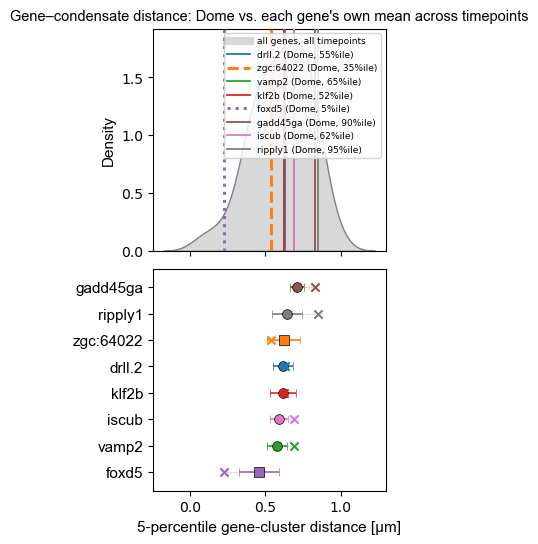

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D
from scipy.stats import percentileofscore

special_genes = ["zgc:64022", "foxd5"]
special_linestyles = {"zgc:64022": "--", "foxd5": ":"}

gene_names = df_all_m_s_dome["Name"].tolist()
palette = sns.color_palette("tab10", n_colors=len(gene_names))
gene_colors = dict(zip(gene_names, palette))

fig, (ax_kde, ax_mean) = plt.subplots(
    2, 1, figsize=(3,6), sharex=True, #4.5, 6.5
    gridspec_kw={"height_ratios": [2, 2], "hspace": 0.08}
)

# --- top panel: KDE + Dome-timepoint values for the 8 genes ---
all_vals = df_all_m_all_t["x5_percentile_distance"].astype(float).dropna()
sns.kdeplot(all_vals, ax=ax_kde, color="gray", fill=True, alpha=0.3, linewidth=1)

legend_handles = [Line2D([0], [0], color="gray", lw=6, alpha=0.3,
                          label="all genes, all timepoints")]

dome_vals = {}
for _, row in df_all_m_s_dome.iterrows():
    val, name = row["x5_percentile_distance"], row["Name"]
    dome_vals[name] = val
    pct = percentileofscore(all_vals, val)
    color = gene_colors[name]
    ls = special_linestyles.get(name, "-")
    lw = 2.2 if name in special_genes else 1.3

    ax_kde.axvline(val, color=color, linestyle=ls, linewidth=lw, zorder=3)
    legend_handles.append(
        Line2D([0], [0], color=color, linestyle=ls, lw=lw,
               label=f"{name} (Dome, {pct:.0f}%ile)")
    )

ax_kde.set_ylabel("Density", fontsize=11, fontname="Arial")
ax_kde.set_title("Gene–condensate distance: Dome vs. each gene's own mean across timepoints",
                  fontsize=10.5, fontname="Arial")
ax_kde.legend(handles=legend_handles, fontsize=6.5, loc="upper right",
              frameon=True, framealpha=0.85, handlelength=2.5)

# --- bottom panel: per-gene mean (± SEM) across all timepoints, one row per gene ---
across_tp = (
    df_all_m_all_t[df_all_m_all_t["Name"].isin(gene_names)]
    .groupby("Name")["x5_percentile_distance"]
    .agg(["mean", "sem", "count"])
)

# order rows, e.g. by across-timepoint mean (or use gene_names for a fixed order)
ordered_genes = across_tp.sort_values("mean").index.tolist()
y_positions = {name: i for i, name in enumerate(ordered_genes)}

for name in gene_names:
    color = gene_colors[name]
    marker = "s" if name in special_genes else "o"
    y = y_positions[name]
    mean_val = across_tp.loc[name, "mean"]
    sem_val = across_tp.loc[name, "sem"]

    ax_mean.errorbar(mean_val, y, xerr=sem_val, fmt=marker, color=color,
                      ecolor=color, elinewidth=1.2, capsize=3, markersize=7,
                      markeredgecolor="black", markeredgewidth=0.5, zorder=3)

    # dotted connector from Dome value to across-timepoint mean, same row
    ax_mean.plot([dome_vals[name], mean_val], [y, y],
                 color=color, linestyle="dotted", linewidth=0.8, alpha=0.6, zorder=2)
    # mark the Dome value itself on that row too
    ax_mean.scatter(dome_vals[name], y, marker="x", color=color, s=35, zorder=4)

ax_mean.set_yticks(range(len(ordered_genes)))
ax_mean.set_yticklabels(ordered_genes, fontsize=11, fontname="Arial")
ax_mean.set_ylim(-0.7, len(ordered_genes) - 0.3)
ax_mean.set_xlabel("5-percentile gene-cluster distance [μm]", fontsize=11, fontname="Arial")
ax_mean.set_ylabel("")


plt.tight_layout()
name_s = "clustering_genome_sections/figures/fig_analysing_genome_sections_7/gene_condensate_distance_dome_versus_mean_3.pdf"
#plt.savefig(name_s, format="pdf", dpi=300, bbox_inches="tight")
#plt.show()

In [ ]:
# foxd5 and ripply are most shifted from their mean-> use as extreme cases?
# ripply1 shifted to the right-> most like non-visitor gene
#foxd5 shifted to left,-> most like visitor gene

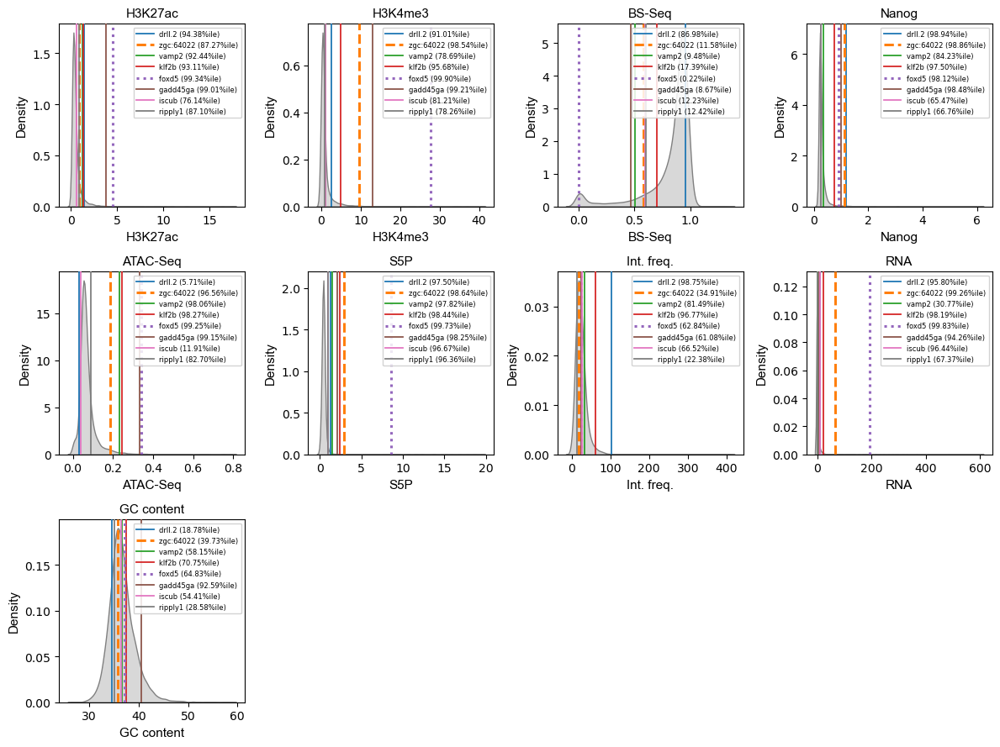

In [167]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.stats import percentileofscore
import numpy as np

features = ["H3K27ac", "H3K4me3", "BS-Seq", "Nanog", "ATAC-Seq", "S5P", "Int. freq.", "RNA", "GC content"]
special_genes = ["zgc:64022", "foxd5"]
special_linestyles = {"zgc:64022": "--", "foxd5": ":"}
gene_names = df_all_m_s_dome["Name"].tolist()
palette = sns.color_palette("tab10", n_colors=len(gene_names))
gene_colors = dict(zip(gene_names, palette))

# --- Arbitrary grid layout: compute rows/cols from number of features ---
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
axes_flat = np.array(axes).reshape(-1)  # flatten to 1D regardless of original shape

for i, (ax, feat) in enumerate(zip(axes_flat, features)):
    genome_vals = all_genes_details_expr_signals_2[feat].astype(float).dropna()
    sns.kdeplot(genome_vals, ax=ax, color="gray", fill=True, alpha=0.3, linewidth=1)
    legend_handles = []
    for _, row in df_all_m_s_dome.iterrows():
        val, name = row[feat], row["Name"]
        pct = percentileofscore(genome_vals, val)
        color = gene_colors[name]
        ls = special_linestyles.get(name, "-")
        lw = 2.2 if name in special_genes else 1.3
        ax.axvline(val, color=color, linestyle=ls, linewidth=lw, zorder=3)
        legend_handles.append(
            Line2D([0], [0], color=color, linestyle=ls, lw=lw,
                   label=f"{name} ({pct:.2f}%ile)")
        )
    ax.set_title(feat, fontsize=11, fontname="Arial")
    ax.set_xlabel(feat, fontsize=11, fontname="Arial")
    #ax.set_ylabel("Density" if i % n_cols == 0 else "", fontsize=11, fontname="Arial")
    ax.set_ylabel("Density", fontsize=11, fontname="Arial")
    ax.legend(handles=legend_handles, fontsize=6, loc="upper right",
              frameon=True, framealpha=0.85, handlelength=2.5)

# Hide any unused axes if n_rows*n_cols > len(features)
for ax in axes_flat[len(features):]:
    ax.axis("off")

plt.tight_layout()

name_s = "clustering_genome_sections/figures/fig_analysing_genome_sections_7/seq_based_gene_values_versus_mean_2.pdf"
#plt.savefig(name_s, format="pdf", dpi=300, bbox_inches="tight")
#plt.show()

                            WLS Regression Results                            
Dep. Variable:      PolII_Ser5P_level   R-squared:                       0.351
Model:                            WLS   Adj. R-squared:                 -0.136
Method:                 Least Squares   F-statistic:                    0.7214
Date:                Fri, 14 Aug 2026   Prob (F-statistic):              0.589
Time:                        15:11:11   Log-Likelihood:                 17.529
No. Observations:                   8   AIC:                            -27.06
Df Residuals:                       4   BIC:                            -26.74
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0138      0.058     17.606      0.0

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1772: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


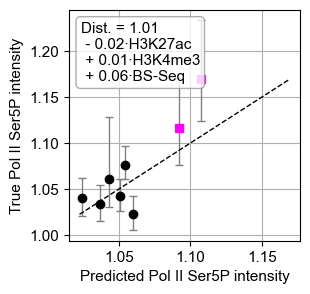

In [163]:

#statsmodel for p-values
import statsmodels.api as sm

#df_sel=df_merged_dist_HiC[["Name","Distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","GC content","Count overlap","Bool overlap CpG"]]


df_sel=df_all_m_s_dome[["Name","PolII_Ser5P_level","H3K27ac","H3K4me3","BS-Seq"]]

X = df_sel.drop(columns=["Name", "PolII_Ser5P_level"])   # the features a, b, c, ...

y = df_sel["PolII_Ser5P_level"]                           # the target

y_low=abs(df_all_m_s_dome["PolII_Ser5P_level"]-df_all_m_s_dome["S5P_CI_low"])
y_high=abs(df_all_m_s_dome["PolII_Ser5P_level"]-df_all_m_s_dome["S5P_CI_high"])


# Convert asymmetric error bars to approx. standard deviation
sigma = (y_high + y_low) / (2*1.96)


# Weights = 1/sigma^2
weights = 1.0 / (sigma**2 )




# X: predictors as a DataFrame or 2D array
# y: response as a Series or 1D array
X_sm = sm.add_constant(X.astype(float))
model2 = sm.WLS(y.astype(float), X_sm,weights=weights.astype(float)).fit()
result2 = sm.WLS(y, X_sm, weights=weights.astype(float)).fit()

#model2 = sm.WLS(y.astype(float), X_sm).fit()
#result2 = sm.WLS(y, X_sm).fit()

print(model2.summary())
print(model2.pvalues)

y_pred = result2.predict(X_sm)


fig, ax = plt.subplots(figsize=(3, 3))

ax.errorbar(
    y_pred,
    df_sel["PolII_Ser5P_level"],
    yerr=[y_low, y_high],
    fmt=".",
    color="red",
    ecolor="gray",
    elinewidth=1,
    capsize=3)

for index,row in df_all_m_s_dome.iterrows():
    if df_all_m_s_dome["Name"][index] in ["zgc:64022","foxd5"]:
        color1="magenta"
        fmt1="s"
    else:
        color1="black"
        fmt1="o"
    ax.errorbar(
    y_pred[index],
    df_sel["PolII_Ser5P_level"][index],
    fmt=fmt1,
    color=color1,
    ecolor="gray",
    elinewidth=1,
    capsize=3)
    


# Diagonal reference line y = x
min_val = min(df_sel["PolII_Ser5P_level"].min(), y_pred.min())
max_val = max(df_sel["PolII_Ser5P_level"].max(), y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)

eq_text = linear_equation_string(model2.params[0],model2.params[1:], X.columns, decimals=2)
# Add equation text inside the axes (top-left corner)
ax.text(
    0.05, 0.95,            # axes fraction coordinates (x, y)
    eq_text,
    transform=ax.transAxes,
    va="top", ha="left",
    fontsize=11,
    fontname = "Arial",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999")
)



# Labels & layout
ax.set_ylabel("True Pol II Ser5P intensity",fontname = "Arial",fontsize=11)
ax.set_xlabel("Predicted Pol II Ser5P intensity",fontname = "Arial",fontsize=11)
#ax.set_title("Predicted vs. True Distance")
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.grid()
ax.set_aspect(1./ax.get_data_ratio())


name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/"+"prediction_gene_cluster_distance_3.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
    
    
plt.show()

                            WLS Regression Results                            
Dep. Variable:      PolII_Ser2P_level   R-squared:                       0.709
Model:                            WLS   Adj. R-squared:                  0.492
Method:                 Least Squares   F-statistic:                     3.256
Date:                Fri, 14 Aug 2026   Prob (F-statistic):              0.142
Time:                        15:11:18   Log-Likelihood:                 20.287
No. Observations:                   8   AIC:                            -32.57
Df Residuals:                       4   BIC:                            -32.26
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9082      0.054     16.970      0.0

/home/aaron/miniconda3/envs/general2/lib/python3.9/site-packages/scipy/stats/_stats_py.py:1772: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


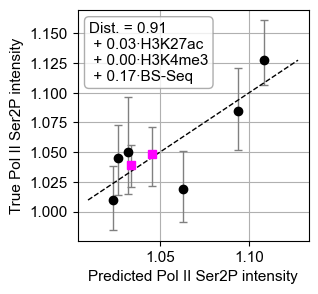

In [164]:

#statsmodel for p-values
import statsmodels.api as sm

#df_sel=df_merged_dist_HiC[["Name","Distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","GC content","Count overlap","Bool overlap CpG"]]


df_sel=df_all_m_s_dome[["Name","PolII_Ser2P_level","H3K27ac","H3K4me3","BS-Seq"]]

X = df_sel.drop(columns=["Name", "PolII_Ser2P_level"])   # the features a, b, c, ...

y = df_sel["PolII_Ser2P_level"]                           # the target

y_low=abs(df_all_m_s_dome["PolII_Ser2P_level"]-df_all_m_s_dome["S2P_CI_low"])
y_high=abs(df_all_m_s_dome["PolII_Ser2P_level"]-df_all_m_s_dome["S2P_CI_high"])


# Convert asymmetric error bars to approx. standard deviation
sigma = (y_high + y_low) / (2*1.96)


# Weights = 1/sigma^2
weights = 1.0 / (sigma**2 )




# X: predictors as a DataFrame or 2D array
# y: response as a Series or 1D array
X_sm = sm.add_constant(X.astype(float))
model2 = sm.WLS(y.astype(float), X_sm,weights=weights.astype(float)).fit()
result2 = sm.WLS(y, X_sm, weights=weights.astype(float)).fit()

#model2 = sm.WLS(y.astype(float), X_sm).fit()
#result2 = sm.WLS(y, X_sm).fit()

print(model2.summary())
print(model2.pvalues)

y_pred = result2.predict(X_sm)


fig, ax = plt.subplots(figsize=(3, 3))

ax.errorbar(
    y_pred,
    df_sel["PolII_Ser2P_level"],
    yerr=[y_low, y_high],
    fmt=".",
    color="red",
    ecolor="gray",
    elinewidth=1,
    capsize=3)

for index,row in df_all_m_s_dome.iterrows():
    if df_all_m_s_dome["Name"][index] in ["zgc:64022","foxd5"]:
        color1="magenta"
        fmt1="s"
    else:
        color1="black"
        fmt1="o"
    ax.errorbar(
    y_pred[index],
    df_sel["PolII_Ser2P_level"][index],
    fmt=fmt1,
    color=color1,
    ecolor="gray",
    elinewidth=1,
    capsize=3)


# Diagonal reference line y = x
min_val = min(df_sel["PolII_Ser2P_level"].min(), y_pred.min())
max_val = max(df_sel["PolII_Ser2P_level"].max(), y_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)

eq_text = linear_equation_string(model2.params[0],model2.params[1:], X.columns, decimals=2)
# Add equation text inside the axes (top-left corner)
ax.text(
    0.05, 0.95,            # axes fraction coordinates (x, y)
    eq_text,
    transform=ax.transAxes,
    va="top", ha="left",
    fontsize=11,
    fontname = "Arial",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999")
)



# Labels & layout
ax.set_ylabel("True Pol II Ser2P intensity",fontname = "Arial",fontsize=11)
ax.set_xlabel("Predicted Pol II Ser2P intensity",fontname = "Arial",fontsize=11)
#ax.set_title("Predicted vs. True Distance")
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.grid()
ax.set_aspect(1./ax.get_data_ratio())


name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/"+"prediction_gene_cluster_distance_3.pdf"

#plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")
    
    
plt.show()

In [165]:

# df columns:
# "Name", "Distance", "a", "b", "c", ...

# --- Prepare the inputs ---
#df_sel=df_merged_dist_HiC[["Name","x5_percentile_distance","S5P","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq.","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]]

#df_sel=df_merged_dist_HiC[["Name","x5_percentile_distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq","Count overlap","Count overlap genes","GC content"]]
df_sel=df_merged_dist_HiC[["Name","x5_percentile_distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","Pou5f3","Sox19b","BS-Seq","GC content","Count overlap","Bool overlap CpG"]]





X_a = df_sel.drop(columns=["Name", "x5_percentile_distance"])#[0]   # the features a, b, c, ...
y = df_sel["x5_percentile_distance"]                           # the target

for col in X_a.columns:
    X = X_a[[col]] #.to_numpy().reshape(-1, 1)
    
    y_low=abs(df_all_m_s_dome["x5_percentile_distance"]-df_all_m_s_dome["dist_CI_low"])
    y_high=abs(df_all_m_s_dome["x5_percentile_distance"]-df_all_m_s_dome["dist_CI_high"])


    # Convert asymmetric error bars to approx. standard deviation
    sigma = (y_high + y_low) / (2*1.96)
    #print(X)

   
    


    # Weights = 1/sigma^2
    weights = 1.0 / (sigma**2 )


    # --- Fit linear regression ---
    model = LinearRegression()
    model.fit(X, y, sample_weight=weights)

    # --- Print results ---
    print("Intercept:", model.intercept_)
    print("Coefficients:")

    for name, coef in zip(X.columns, model.coef_):
        print(f"  {name}: {coef}")

    # --- R² score (quality of explanation) ---
    r2 = model.score(X, y)
    print("\nR²:", r2)
    print("############")
    print("############")
    print("############")
    '''# --- Predictions ---
    df_sel["predicted_Distance"] = model.predict(X)

    # --- Plot: predicted vs true ---
    fig, ax = plt.subplots(figsize=(3, 3))

    #ax.scatter(df_sel["Distance"], df_sel["predicted_Distance"], color="steelblue")

    ax.errorbar(
        df_sel["predicted_Distance"],
        df_sel["Distance"],
        yerr=[df_merged_dist_HiC["Delta lower"], df_merged_dist_HiC["Delta upper"]],
        fmt="o",
        color="red",
        ecolor="gray",
        elinewidth=1,
        capsize=3
    )

    # Diagonal reference line y = x
    min_val = min(df_sel["Distance"].min(), df_sel["predicted_Distance"].min())
    max_val = max(df_sel["Distance"].max(), df_sel["predicted_Distance"].max())
    ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)



    # --- Build a readable equation string with rounded coefficients ---
    def linear_equation_string(intercept, coefs, feature_names, decimals=2):
        """Return a string like: y = 1.23 + 0.45*a - 6.78*b + 0.00*c"""
        parts = []
        # Intercept
        parts.append(f"{intercept:.{decimals}f}")
        # Coefficients with signs
        for name, c in zip(feature_names, coefs):
            sign = " + " if c >= 0 else " - "
            parts.append(f"{sign}{abs(c):.{decimals}f}·{name}")
        return "Dist. = " + "\n".join(parts) 

    eq_text = linear_equation_string(model.intercept_, model.coef_, X.columns, decimals=2)


    # Add equation text inside the axes (top-left corner)
    ax.text(
        0.05, 0.95,            # axes fraction coordinates (x, y)
        eq_text,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=11,
        fontname = "Arial",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999")
    )



    # Annotate each point with its name
    for _, row in df_sel.iterrows():
        ax.annotate(
            row["Name"],
            (row["Distance"], row["predicted_Distance"]),
            textcoords="offset points",
            xytext=(5, 4),   # slight offset so text does not sit directly on marker
            fontsize=11
        )

    # Labels & layout
    ax.set_ylabel("True gene-cluster distance [μm]",fontname = "Arial",fontsize=11)
    ax.set_xlabel("Predicted gene-cluster distance [μm]",fontname = "Arial",fontsize=11)
    #ax.set_title("Predicted vs. True Distance")
    plt.yticks(fontname = "Arial",fontsize=11) 
    plt.xticks(fontname = "Arial",fontsize=11) 
    plt.grid()
    ax.set_aspect(1./ax.get_data_ratio())


    name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/"+"prediction_gene_cluster_distance_2.pdf"

    #plt.savefig(name_s,format="pdf",dpi=300,bbox_inches="tight")


    plt.show()'''

Intercept: 0.7241331121634715
Coefficients:
  H3K27ac: -0.03209056661671221

R²: 0.13910240330087986
############
############
############
Intercept: 0.7272370185278119
Coefficients:
  H3K4me3: -0.010789256563547095

R²: 0.50255303601653
############
############
############
Intercept: 0.68914123235784
Coefficients:
  ATAC-Seq: -0.12536209228807998

R²: 0.023476875963154398
############
############
############
Intercept: 0.7508049060977275
Coefficients:
  Nanog: -0.10687284815500923

R²: 0.07853697947491312
############
############
############
Intercept: 0.6435781809930777
Coefficients:
  Pou5f3: 0.11529375161630369

R²: -0.09320018589685475
############
############
############
Intercept: 0.6513130427563596
Coefficients:
  Sox19b: 0.1687475987719726

R²: -0.051006035087600265
############
############
############
Intercept: 0.5879261325758771
Coefficients:
  BS-Seq: 0.12991580788631146

R²: 0.15733829371346864
############
############
############
Intercept: 0.067006264208317

Intercept: -31.33255082057124
Coefficients:
  H3K27ac: 3.314887585766059
  H3K4me3: -2.246010716713242
  BS-Seq: 6.240748548976762
  ATAC-Seq: 102.31265833986711
  Nanog: 10.741226091007984
  Count overlap: 1.2052993661620297
  Pou5f3: 100.2006509241272
  Sox19b: 3.691779536621255
  GC content: -0.2025528110960943

R²: 0.6419187901795984


/tmp/ipykernel_103/2204029008.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sel["predicted_Distance"] = model.predict(X)


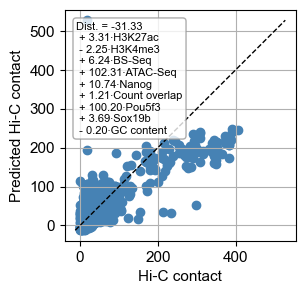

In [233]:

# df columns:
# "Name", "Distance", "a", "b", "c", ...

# --- Prepare the inputs ---
#df_sel=df_merged_dist_HiC[["Name","Distance","S5P","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq","Count overlap","Mean sep. in bp","Min. sep. in bp","Int. freq.","Count overlap genes","Bool overlap CpG","GC content","Max. rel. elem."]]

#df_sel=df_merged_dist_HiC[["Name","Distance","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq","Count overlap","Count overlap genes","GC content"]]

#all genes
df_sel=all_genes_details_expr_signals_2[["Name","Int. freq.","H3K27ac","H3K4me3","BS-Seq","ATAC-Seq","Nanog","Count overlap","Pou5f3","Sox19b","GC content"]]


#only 8 genes
#df_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"].isin(gene_examples_names_11)][["Name","Int. freq.","H3K27ac","H3K4me3","BS-Seq","ATAC-Seq","Nanog","Count overlap","Pou5f3","Sox19b"]]

#df_sel=all_genes_details_expr_signals_2[all_genes_details_expr_signals_2["Name"].isin(gene_examples_names_11)][["Name","Int. freq.","H3K27ac","H3K4me3","BS-Seq"]]


X = df_sel.drop(columns=["Name", "Int. freq."])   # the features a, b, c, ...
y = df_sel["Int. freq."]                           # the target

# --- Fit linear regression ---
model = LinearRegression()
model.fit(X, y)

# --- Print results ---
print("Intercept:", model.intercept_)
print("Coefficients:")

for name, coef in zip(X.columns, model.coef_):
    print(f"  {name}: {coef}")

# --- R² score (quality of explanation) ---
r2 = model.score(X, y)
print("\nR²:", r2)


# --- Predictions ---
df_sel["predicted_Distance"] = model.predict(X)

# --- Plot: predicted vs true ---
fig, ax = plt.subplots(figsize=(3, 3))

ax.scatter(df_sel["Int. freq."], df_sel["predicted_Distance"], color="steelblue")

# Diagonal reference line y = x
min_val = min(df_sel["Int. freq."].min(), df_sel["predicted_Distance"].min())
max_val = max(df_sel["Int. freq."].max(), df_sel["predicted_Distance"].max())
ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)



# --- Build a readable equation string with rounded coefficients ---
def linear_equation_string(intercept, coefs, feature_names, decimals=2):
    """Return a string like: y = 1.23 + 0.45*a - 6.78*b + 0.00*c"""
    parts = []
    # Intercept
    parts.append(f"{intercept:.{decimals}f}")
    # Coefficients with signs
    for name, c in zip(feature_names, coefs):
        sign = " + " if c >= 0 else " - "
        parts.append(f"{sign}{abs(c):.{decimals}f}·{name}")
    return "Dist. = " + "\n".join(parts) 

eq_text = linear_equation_string(model.intercept_, model.coef_, X.columns, decimals=2)


# Add equation text inside the axes (top-left corner)
ax.text(
    0.05, 0.95,            # axes fraction coordinates (x, y)
    eq_text,
    transform=ax.transAxes,
    va="top", ha="left",
    fontsize=8,
    fontname = "Arial",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="#999")
)


'''
# Annotate each point with its name
for _, row in df_sel.iterrows():
    ax.annotate(
        row["Name"],
        (row["Int. freq."], row["predicted_Distance"]),
        textcoords="offset points",
        xytext=(5, 4),   # slight offset so text does not sit directly on marker
        fontsize=8
    )'''

# Labels & layout
ax.set_xlabel("Hi-C contact",fontname = "Arial",fontsize=11)
ax.set_ylabel("Predicted Hi-C contact",fontname = "Arial",fontsize=11)
#ax.set_title("Predicted vs. True Distance")
plt.yticks(fontname = "Arial",fontsize=11) 
plt.xticks(fontname = "Arial",fontsize=11) 
plt.grid()
ax.set_aspect(1./ax.get_data_ratio())
plt.show()

# Visualize 6

Visualize Hi-C data and genome tracks

In [154]:
gene_examples_names_6=["vamp2","foxd5","zgc:64022","ripply1","drll.2","klf2b","gadd45ga","iscub"]
#gene_examples_names_6=["foxd5","zgc:64022","ripply1"]
#gene_examples_names_6=["foxd5","ripply1"]
#gene_examples_names_6=["si:ch211-113a14.6"]
#gene_examples_names_6=subset_2D_plot_genes["Name"].tolist()

plot_signals_6=["S5P","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq"]
#plot_signals_6=["S5P","H3K27ac"]

bw_signal_list_6=[bw_Serin5P_4_3_hpf, bw_H3K27ac_4_3_hpf,bw_H3K4me3_hpf,bw_ATAC_4_3_hpf,bw_nanog_4_hpf,bw_BS_seq_4_hpf]
#bw_signal_list_6=[bw_Serin5P_4_3_hpf, bw_H3K27ac_4_3_hpf]


labels_signals_6=["S5P","H3K27ac","H3K4me3","ATAC-Seq","Nanog","BS-Seq"]
#labels_signals_6=["S5P","H3K27ac"]

subset_gene_details_6=all_genes_details_expr_4[all_genes_details_expr_4["Name"].isin(gene_examples_names_6)]
subset_gene_details_6.reset_index(inplace=True,drop=True)
subset_gene_details_6


# get ChIP-Seq profiles of individual genes
#add signal tracks
subset_gene_details_expr_signals_6=subset_gene_details_6
interval_sel_6=5*10**6
sel_res_6=50000

exp_dim_6=int(2*interval_sel_6/sel_res_6) #  int(5*10**6/250000)
for i in range(len(bw_signal_list_6)):
    print(labels_signals_6[i])

    df_signal=get_coverage_for_genes_V1(df_genes=subset_gene_details_6,ID_col="ID",Name_col="Name",Chr_col="Chr",Start_col="Middle",Stop_col="Middle",Orientation_col="Orientation",Signal_col=labels_signals_6[i],expected_dim=exp_dim_6,add_interval=interval_sel_6,big_wig_file_name=bw_signal_list_6[i],chr_add="chr",signal_type="mean")


    subset_gene_details_expr_signals_6=pd.concat([subset_gene_details_expr_signals_6,df_signal[labels_signals_6[i]]], axis=1)
#add signal start stop entry
subset_gene_details_expr_signals_6=pd.concat([subset_gene_details_expr_signals_6,df_signal[["Signal start","Signal stop"]]], axis=1)


#get Hi-C maps around genes
hic_zoom_matrix2={}
hic_zoom_matrix2_exp={}

chr_num2=list(np.arange(1,26))
#4hpf
hic_dr=hicstraw.HiCFile("clustering_genome_sections/hic_downloads/4DNFI1ORHOTA.hic")
#5.3hpf
#hic_dr=hicstraw.HiCFile("clustering_genome_sections/hic_downloads/4DNFIGKX4A32.hic")

#chr_num.append("X")
#chr_num.append("Y")
for i in chr_num2:
    #print(i)
    hic_zoom_matrix_e = hic_dr.getMatrixZoomData(str(i), str(i), "oe", "KR", "BP", sel_res_6)
    
    
    hic_zoom_matrix_e_exp = hic_dr.getMatrixZoomData(str(i), str(i), "expected", "KR", "BP", sel_res_6)
    
    hic_zoom_matrix_e_obs = hic_dr.getMatrixZoomData(str(i), str(i), "observed", "KR", "BP", sel_res_6)
    
    hic_zoom_matrix2_exp[str(i)]=hic_zoom_matrix_e_exp
    
    hic_zoom_matrix2[str(i)]=hic_zoom_matrix_e_obs
    
#generate dict with chr. lengths    
chr_name_length_dict={}
for chrom in hic_dr.getChromosomes():
    #print(chrom.name, chrom.length)
    chr_name_length_dict[chrom.name]=chrom.length
    
#append Hi-C data to dataframe
hic_sel_dict={}
for index, row in subset_gene_details_6.iterrows():
    name_sel=row["Name"]
    chr_sel=str(row["Chr"])
    signal_start=int(row["Middle"]-interval_sel_6)
    signal_stop=int(row["Middle"]+interval_sel_6)
    #calculate boundaries in appropriate resolution
    hic_lower_b =int(np.round(signal_start/sel_res_6)*sel_res_6)
    hic_upper_b = int(np.round(signal_stop/sel_res_6)*sel_res_6 -sel_res_6/2) #need to reduce upper boundary to get correct number of bins
    
    #print(chr_sel,signal_start,signal_stop)

    hic_sel=hic_zoom_matrix2[chr_sel].getRecordsAsMatrix(hic_lower_b,hic_upper_b,hic_lower_b,hic_upper_b)
    
    #option for expected hic 
    #hic_sel_exp=hic_zoom_matrix2_exp[chr_sel].getRecordsAsMatrix(hic_lower_b,hic_upper_b,hic_lower_b,hic_upper_b)

    #hic_sel_list.append(hic_sel)
    hic_sel_dict[name_sel]=hic_sel #-hic_sel_exp
#hic_sel_dist=pd.DataFrame(hic_sel_list)
#subset_gene_details_expr_signals_6=pd.concat([subset_gene_details_expr_signals_6,hic_sel_dist])


S5P
error when trying to get data for  ENSDARG00000040432 klf2b
0 / 7
ENSDARG00000056877 vamp2 chr10 17841928 27841928 mean 200
1 / 7
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
2 / 7
ENSDARG00000019417 gadd45ga chr8 26368405 36368405 mean 200
3 / 7
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
4 / 7
ENSDARG00000070705 zgc:64022 chr19 19124415 29124415 mean 200
5 / 7
ENSDARG00000035150 drll.2 chr5 56620178 66620178 mean 200
6 / 7
ENSDARG00000026582 iscub chr5 26864444 36864444 mean 200
7 / 7
H3K27ac
error when trying to get data for  ENSDARG00000040432 klf2b
0 / 7
ENSDARG00000056877 vamp2 chr10 17841928 27841928 mean 200
1 / 7
ENSDARG00000054103 ripply1 chr21 32969977 42969977 mean 200
2 / 7
ENSDARG00000019417 gadd45ga chr8 26368405 36368405 mean 200
3 / 7
ENSDARG00000042485 foxd5 chr8 25453520 35453520 mean 200
4 / 7
ENSDARG00000070705 zgc:64022 chr19 19124415 29124415 mean 200
5 / 7
ENSDARG00000035150 drll.2 chr5 56620178 66620178 mean 200
6 / 7
ENSDARG0000

In [155]:
subset_gene_details_expr_signals_6

,ID,Name,Chr,Start,Stop,Orientation,Length,Middle,Prom. Start,Prom. Stop,RNA,S5P,H3K27ac,H3K4me3,ATAC-Seq,Nanog,BS-Seq,Signal start,Signal stop
0,ENSDARG00000040432,klf2b,2,55665057,55670822,plus,5765,55667939,55664057,55665157,23.0,"[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1....","[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1....","[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1....","[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1....","[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1....","[-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1....",50667939,60667939
1,ENSDARG00000056877,vamp2,10,22838373,22845484,minus,7111,22841928,22845384,22846484,0.0,"[0.47687690906001073, 0.4373962177530924, 0.41...","[0.3843940330635233, 0.3102328052439588, 0.339...","[0.40199891314515973, 0.7005613771585899, 0.22...","[0.04897594160897391, 0.048253029208864484, 0....","[0.3997779323601567, 0.2356794117765298, 0.259...","[0.8738328541264915, 0.892502277242998, 0.9036...",17841928,27841928
2,ENSDARG00000054103,ripply1,21,37967457,37972497,minus,5040,37969977,37972397,37973497,0.4,"[0.39950506884257, 0.4128291735495773, 0.41447...","[0.17313845543151207, 0.20448287824346661, 0.2...","[0.18334662550104727, 0.24866160905894666, 0.2...","[0.05075213181350912, 0.05168961029240063, 0.0...","[0.22511525432746105, 0.2345595372126205, 0.21...","[0.9470264127315798, 0.9324700875235398, 0.934...",32969977,42969977
3,ENSDARG00000019417,gadd45ga,8,31367667,31369144,minus,1477,31368405,31369044,31370144,7.0,"[0.4800214010096531, 0.404340354126575, 0.3832...","[0.7634594679552443, 0.3720237205610884, 0.249...","[2.5308229204336485, 1.0412920781069464, 0.255...","[0.08260189784237316, 0.06832914824230331, 0.0...","[0.29498712201901944, 0.24000692341405294, 0.2...","[0.7814738053939738, 0.925275775606701, 0.9495...",26368405,36368405
4,ENSDARG00000042485,foxd5,8,30452945,30454096,plus,1151,30453520,30451945,30453045,193.0,"[0.45259400014839923, 0.4287526215796377, 0.44...","[0.26014218833761016, 0.5786984027489196, 0.53...","[0.23879809741331798, 0.2684928925164855, 0.75...","[0.04612407442092895, 0.056115490000588554, 0....","[0.26362518519170275, 0.25643753682809717, 0.2...","[0.9463900714986865, 0.96062637655963, 0.78659...",25453520,35453520
5,ENSDARG00000070705,zgc:64022,19,24123409,24125422,minus,2013,24124415,24125322,24126422,65.0,"[0.41771123652495584, 0.4436591671790328, 0.40...","[0.22222118443306454, 0.20531323902941764, 0.3...","[0.17945657697403783, 0.960757157451894, 1.102...","[0.04620794941983053, 0.04906570735820702, 0.0...","[0.3323110598216857, 0.22251285532262263, 0.25...","[0.9374897681725488, 0.9256728440376025, 0.876...",19124415,29124415
6,ENSDARG00000035150,drll.2,5,61615663,61624693,minus,9030,61620178,61624593,61625693,10.0,"[0.3400488867419374, 0.33413480565688186, 0.32...","[0.19417666956962423, 0.2531515674461202, 0.22...","[0.21983168859689545, 0.21699405270642572, 0.2...","[0.05003038537604468, 0.05202145190358162, 0.0...","[0.22990556873631618, 0.2033416645454805, 0.22...","[0.9422564025071957, 0.9312918406322936, 0.946...",56620178,66620178
7,ENSDARG00000026582,iscub,5,31860041,31868847,plus,8806,31864444,31859041,31860141,12.0,"[0.43905217592725576, 0.47320724289389215, 0.3...","[0.6460354815219311, 0.5829692310154692, 0.339...","[0.9910672052394754, 2.448195652936426, 0.2553...","[0.07919044911384583, 0.07751369913305556, 0.0...","[0.2802755040227245, 0.20715531972027035, 0.27...","[0.7831230633224888, 0.8206434544630261, 0.959...",26864444,36864444


In [156]:
exp_dim_6

200

In [157]:
len(hic_sel_dict["foxd5"][0])

200

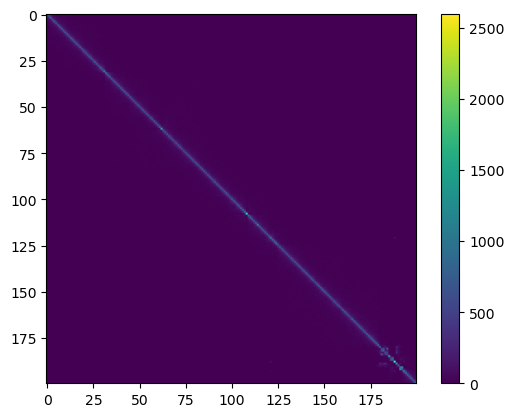

In [158]:
plt.imshow(hic_sel_dict["foxd5"])
plt.colorbar()

vamp2


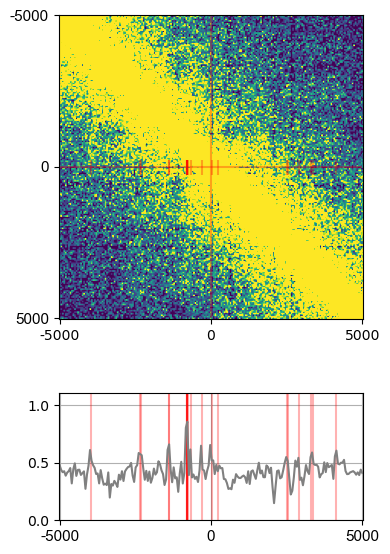

foxd5


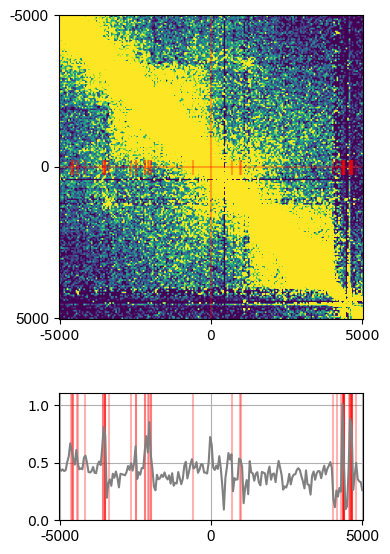

zgc:64022


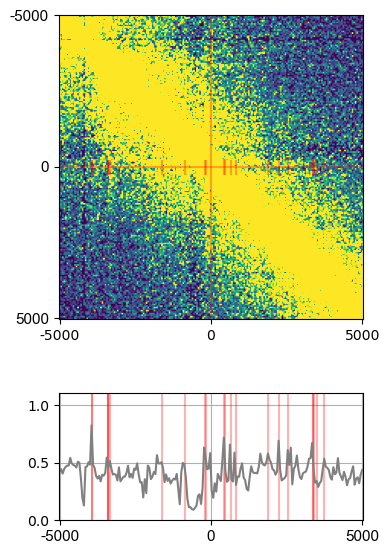

ripply1


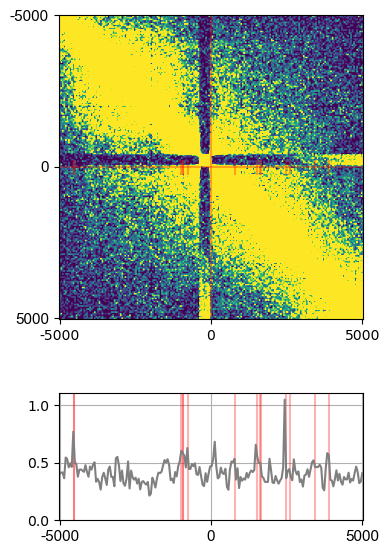

drll.2


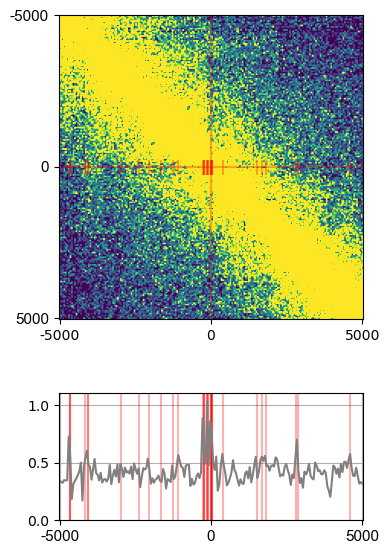

klf2b


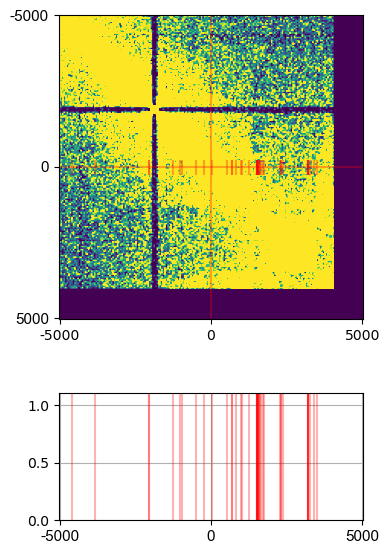

gadd45ga


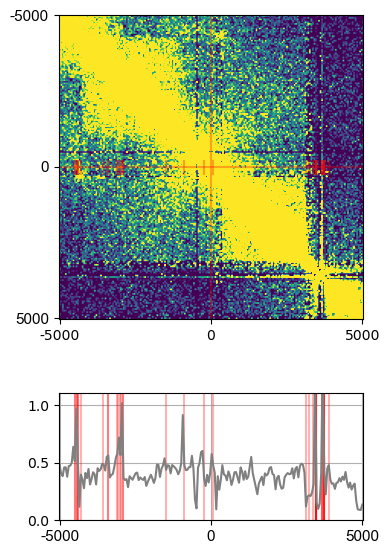

iscub


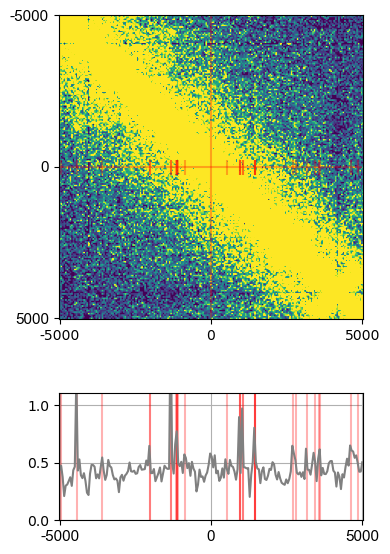

In [159]:
for i in range(len(gene_examples_names_6)):
    gene_name_sel=gene_examples_names_6[i]
    print(gene_name_sel)
    signal_track_df_6=subset_gene_details_expr_signals_6[subset_gene_details_expr_signals_6["Name"]==gene_name_sel]
    signal_track_6=signal_track_df_6["S5P"].tolist()[0]
    signal_track_start_6=signal_track_df_6["Signal start"].to_numpy()[0]
    signal_track_stop_6=signal_track_df_6["Signal stop"].to_numpy()[0]
    signal_track_middle_6=signal_track_df_6["Middle"].to_numpy()[0]
    signal_track_orientation_6=signal_track_df_6["Orientation"].values[0]#[0]
    #signal_track_x_6=np.linspace(signal_track_start_6,signal_track_stop_6,len(signal_track_6))
    signal_track_x_6=np.arange(0,len(signal_track_6))
    
    #signal_track_annotation=[signal_track_middle_6-interval_sel_6,signal_track_middle_6,signal_track_middle_6+interval_sel_6]
    signal_track_annotation=[0,signal_track_x_6[-1]/2,signal_track_x_6[-1]]
    signal_track_annotation_l=[-int(interval_sel_6/1000),0,int(interval_sel_6/1000)]
    
    #fig=plt.figure(figsize=(3,3))
    #fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
    #ax1.imshow(hic_sel_dict[gene_name_sel])
    #ax2.errorbar(signal_track_x_6,signal_track_6,color="grey")
    
    
    plt.figure(figsize=(4,6))
    #plt.figure(figsize=(8/1.5,4/1.5))
    gs = gridspec.GridSpec(2,1,height_ratios=[3,1])
    
    #Hi-C data
    ax1 = plt.subplot(gs[0,0])
    hic11=ax1.imshow(hic_sel_dict[gene_name_sel],vmax=5) #vmax=5:, no vmin for oe read in
    
    
    ax1.set_yticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
    ax1.vlines(signal_track_x_6[-1]/2, 0,signal_track_x_6[-1],color="red",alpha=0.3)
    ax1.hlines(signal_track_x_6[-1]/2, 0,signal_track_x_6[-1],color="red",alpha=0.3)

    ax1.set_aspect(1/ax1.get_data_ratio())
    
    #Chip-Seq data
    ax2 = plt.subplot(gs[1,0],sharex=ax1)
    ax2.errorbar(signal_track_x_6,signal_track_6,color="grey")
    ax2.grid()
    ax2.set_xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
    ax2.set_ylim(0,1.1)
    
    
    #annotation
     #select regulatory elements for sel gene
    Gene_SE_overlap_1_sel=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"]==gene_name_sel]["Names overlap"].tolist()[0]
    for m in range(len(Gene_SE_overlap_1_sel)):

        name_cCRE=Gene_SE_overlap_1_sel[m]
        #for this step, select the dataframe used to find regulatory elements overlapping genes
        #ROSE SEs:
        #df_cCRE_sel=SE_read_in_1[SE_read_in_1["Name"]==name_cCRE]

        #ROSE SEs overlapping cCREs:
        #df_cCRE_sel=SE_read_in_1_overlap_cCREs_1[SE_read_in_1_overlap_cCREs_1["Name"]==name_cCRE]


        #cCREs:
        #df_cCRE_sel=cCRE_dynamic_read_in_clusters_1[cCRE_dynamic_read_in_clusters_1["Name"]==name_cCRE]

        #cCREs overlapping S5P peaks:
        #df_cCRE_sel=cCRE_dynamic_read_in_clusters_overlap_S5P_1[cCRE_dynamic_read_in_clusters_overlap_S5P_1["Name"]==name_cCRE]

        #S5P peaks not overlapping genes
        #df_cCRE_sel=S5P_peaks_read_in_no_overlap_genes_1[S5P_peaks_read_in_no_overlap_genes_1["name"]==name_cCRE]

        #S5P peaks not overlapping genes, but overlapping cCREs
        #df_cCRE_sel=S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1[S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1["name"]==name_cCRE]

        #S5P peaks
        df_cCRE_sel=S5P_peaks_read_in_2[S5P_peaks_read_in_2["name"]==name_cCRE]

        #PADREs
        #df_cCRE_sel=PADRES_read_in_enh_1[PADRES_read_in_enh_1["Name"]==name_cCRE]

        #PADREs overlapping S5P peaks
        #df_cCRE_sel=PADRES_read_in_1_overlap_S5P_1[PADRES_read_in_1_overlap_S5P_1["Name"]==name_cCRE]

        #adjust names of start, stop, middle
        #cCRE_sel_start_1=df_cCRE_sel["Start"].to_numpy()[0]
        #cCRE_sel_stop_1=df_cCRE_sel["Stop"].to_numpy()[0]
        #cCRE_sel_middle_1=df_cCRE_sel["Middle"].to_numpy()[0]

        cCRE_sel_start_1=df_cCRE_sel["START"].to_numpy()[0]
        cCRE_sel_stop_1=df_cCRE_sel["STOP"].to_numpy()[0]
        cCRE_sel_middle_1=df_cCRE_sel["MIDDLE"].to_numpy()[0]
        
        #get coords in new scale
        cCRE_sel_start_1_rs=np.array(cCRE_sel_start_1-signal_track_start_6)/sel_res_6
        cCRE_sel_stop_1_rs=np.array(cCRE_sel_stop_1-signal_track_start_6)/sel_res_6
        cCRE_sel_middle_1_rs=np.array(cCRE_sel_middle_1-signal_track_start_6)/sel_res_6
        #print(cCRE_sel_start_1_rs)
        
        ax2.vlines(cCRE_sel_middle_1_rs,0,1.1,color="red",alpha=0.3)
        hic_line_lb=(len(hic_sel_dict[gene_name_sel])/2)*(1-0.05) 
        hic_line_ub=(len(hic_sel_dict[gene_name_sel])/2)*(1+0.05) 
        ax1.vlines(cCRE_sel_middle_1_rs,hic_line_lb,hic_line_ub,color="red",alpha=0.3)
        #ax2.vlines(cCRE_sel_middle_1,0,max_signal_v)

        #ax2.vlines(cCRE_sel_middle_1,max_signal_v*1.1, max_signal_v*1.21, linewidth=0.5)

        #ax2.vlines(cCRE_sel_start_1,0,max_signal_v,color="black")
        #ax2.vlines(cCRE_sel_stop_1,0,max_signal_v,color="black")
        '''ax2.annotate('', xy=(cCRE_sel_middle_1, max_signal_v), xytext=(cCRE_sel_middle_1, max_signal_v*1.01),
         arrowprops=dict(facecolor='black', shrink=0.99, headwidth=1, headlength=1, width=0))'''





    
    
    
    
    plt.tight_layout()
    plt.show()
    

vamp2


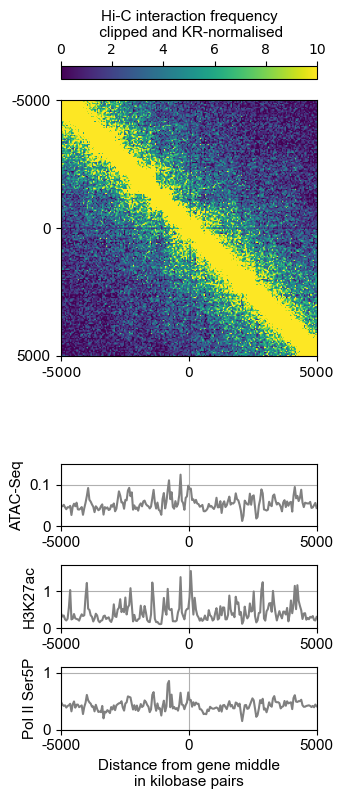

foxd5


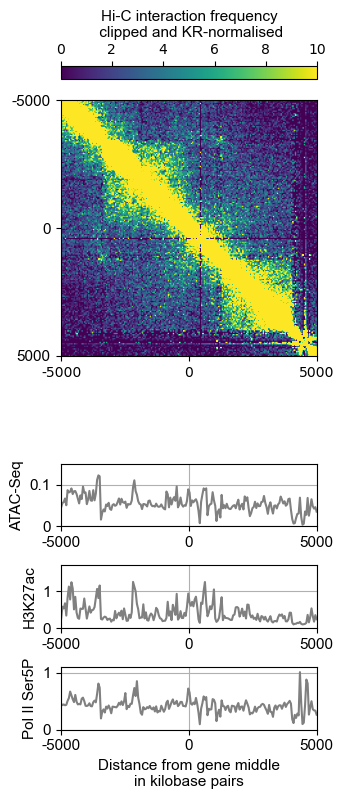

zgc:64022


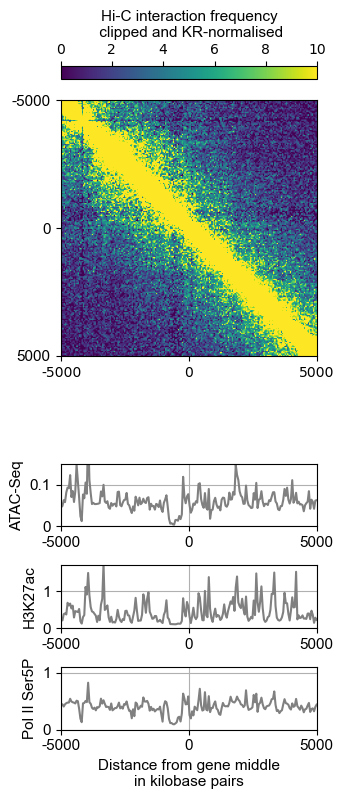

ripply1


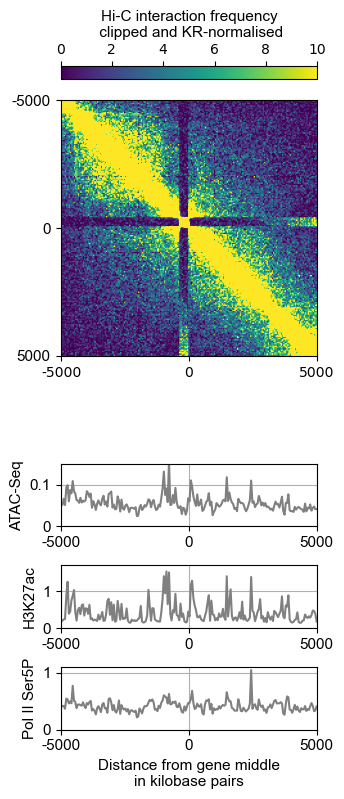

drll.2


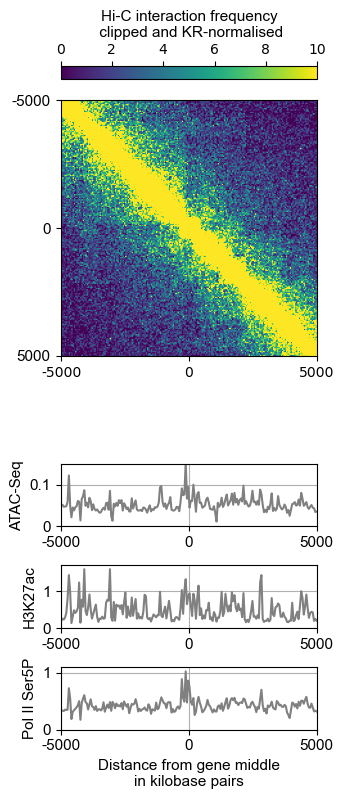

klf2b


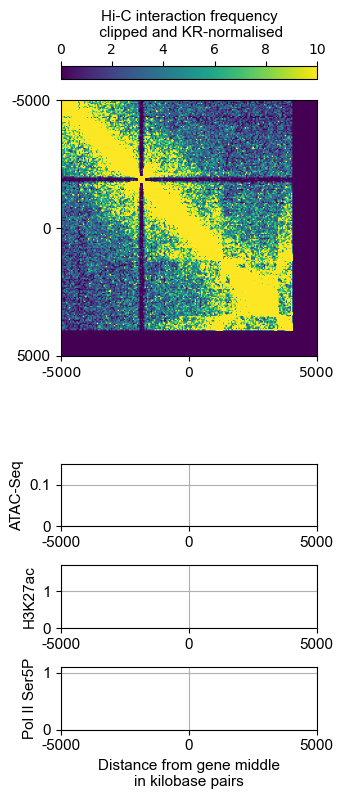

gadd45ga


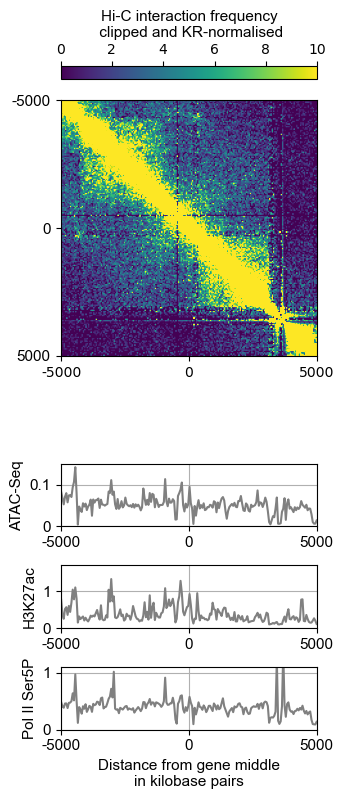

iscub


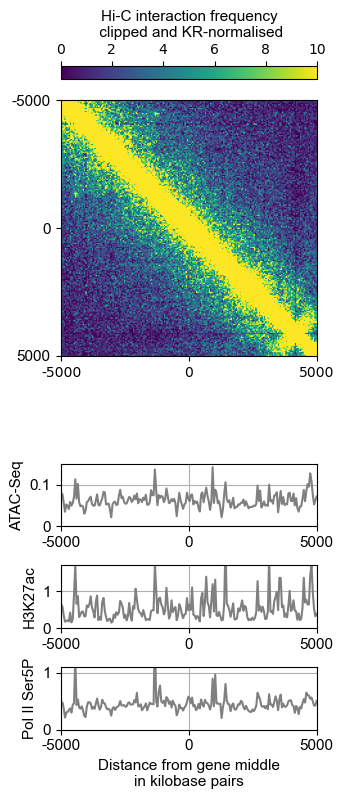

In [160]:

#visualize Hi-C with different genome tracks
for i in range(len(gene_examples_names_6)):
    gene_name_sel=gene_examples_names_6[i]
    print(gene_name_sel)
    signal_track_df_6=subset_gene_details_expr_signals_6[subset_gene_details_expr_signals_6["Name"]==gene_name_sel]
    signal_track_6=signal_track_df_6["S5P"].tolist()[0]
    signal_track_start_6=signal_track_df_6["Signal start"].to_numpy()[0]
    signal_track_stop_6=signal_track_df_6["Signal stop"].to_numpy()[0]
    signal_track_middle_6=signal_track_df_6["Middle"].to_numpy()[0]
    signal_track_orientation_6=signal_track_df_6["Orientation"].values[0]#[0]
    #signal_track_x_6=np.linspace(signal_track_start_6,signal_track_stop_6,len(signal_track_6))
    signal_track_x_6=np.arange(0,len(signal_track_6))
    
    #signal_track_annotation=[signal_track_middle_6-interval_sel_6,signal_track_middle_6,signal_track_middle_6+interval_sel_6]
    signal_track_annotation=[0,signal_track_x_6[-1]/2,signal_track_x_6[-1]]
    signal_track_annotation_l=[-int(interval_sel_6/1000),0,int(interval_sel_6/1000)]
    
    #fig=plt.figure(figsize=(3,3))
    #fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
    #ax1.imshow(hic_sel_dict[gene_name_sel])
    #ax2.errorbar(signal_track_x_6,signal_track_6,color="grey")
    
    
    #plt.figure(figsize=(4,6))
    #plt.figure(figsize=(8/1.5,4/1.5))
    plt.figure(figsize=(9/2.54,9/2.54 *2.3))
    n_tr=2
    #gs = gridspec.GridSpec(int(1+n_tr),1,height_ratios=[int(2+n_tr),1])
    gs = gridspec.GridSpec(4,1, height_ratios=[6.5, 1, 1,1])
    
    #Hi-C data
    ax1 = plt.subplot(gs[0,0])
    color_scale_norm1=None#matplotlib.colors.PowerNorm(0.8)
    hic11=ax1.imshow(hic_sel_dict[gene_name_sel],norm=color_scale_norm1,vmax=10) #vmax=5:, no vmin for oe read in
    ax1.set_yticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
    
    fig.colorbar(hic11, location='top',shrink=1).set_label(label="Hi-C interaction frequency\n clipped and KR-normalised",size=11,family="Arial")

    #ax1.vlines(signal_track_x_6[-1]/2, 0,signal_track_x_6[-1],color="red",alpha=0.3)
    #ax1.hlines(signal_track_x_6[-1]/2, 0,signal_track_x_6[-1],color="red",alpha=0.3)

    ax1.set_aspect(1/ax1.get_data_ratio())
    
    #Chip-Seq data
    ax3 = plt.subplot(gs[3,0],sharex=ax1)
    ax3.errorbar(signal_track_x_6,signal_track_6,color="grey")
    ax3.grid()
    ax3.set_xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
    ax3.set_yticks([0,1],[0,1],fontname = "Arial",fontsize=11)
    ax3.set_ylim(0,1.1)

    ax3.set_ylabel("Pol II Ser5P",fontname = "Arial",fontsize=11)
    ax3.set_xlabel("Distance from gene middle\nin kilobase pairs",fontname = "Arial",fontsize=11)
    ##################
    ax2 = plt.subplot(gs[2,0],sharex=ax1)
    ax2.errorbar(signal_track_x_6,signal_track_df_6["H3K27ac"].tolist()[0],color="grey")
    ax2.grid()
    ax2.set_xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
    ax2.set_yticks([0,1],[0,1],fontname = "Arial",fontsize=11)
    ax2.set_ylim(0,1.7)
    
    ax2.set_ylabel("H3K27ac",fontname = "Arial",fontsize=11)
    #ax2.set_xlabel("Distance from gene middle\nin kilobase pairs",fontname = "Arial",fontsize=11)
    ##################
    ax1 = plt.subplot(gs[1,0],sharex=ax1)
    ax1.errorbar(signal_track_x_6,signal_track_df_6["ATAC-Seq"].tolist()[0],color="grey")
    ax1.grid()
    ax1.set_xticks(signal_track_annotation,signal_track_annotation_l,fontname = "Arial",fontsize=11)
    ax1.set_yticks([0,0.1],[0,0.1],fontname = "Arial",fontsize=11)
    ax1.set_ylim(0,0.15)
    
    ax1.set_ylabel("ATAC-Seq",fontname = "Arial",fontsize=11)
    #ax1.set_xlabel("Distance from gene middle\nin kilobase pairs",fontname = "Arial",fontsize=11)
    
    
    #annotation
     #select regulatory elements for sel gene
    Gene_SE_overlap_1_sel=Gene_SE_overlap_1[Gene_SE_overlap_1["Name"]==gene_name_sel]["Names overlap"].tolist()[0]
    for m in range(len(Gene_SE_overlap_1_sel)):

        name_cCRE=Gene_SE_overlap_1_sel[m]
        #for this step, select the dataframe used to find regulatory elements overlapping genes
        #ROSE SEs:
        #df_cCRE_sel=SE_read_in_1[SE_read_in_1["Name"]==name_cCRE]

        #ROSE SEs overlapping cCREs:
        #df_cCRE_sel=SE_read_in_1_overlap_cCREs_1[SE_read_in_1_overlap_cCREs_1["Name"]==name_cCRE]


        #cCREs:
        #df_cCRE_sel=cCRE_dynamic_read_in_clusters_1[cCRE_dynamic_read_in_clusters_1["Name"]==name_cCRE]

        #cCREs overlapping S5P peaks:
        #df_cCRE_sel=cCRE_dynamic_read_in_clusters_overlap_S5P_1[cCRE_dynamic_read_in_clusters_overlap_S5P_1["Name"]==name_cCRE]

        #S5P peaks not overlapping genes
        #df_cCRE_sel=S5P_peaks_read_in_no_overlap_genes_1[S5P_peaks_read_in_no_overlap_genes_1["name"]==name_cCRE]

        #S5P peaks not overlapping genes, but overlapping cCREs
        #df_cCRE_sel=S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1[S5P_peaks_read_in_overlap_cCRE_no_overlap_genes_1["name"]==name_cCRE]

        #S5P peaks
        df_cCRE_sel=S5P_peaks_read_in_2[S5P_peaks_read_in_2["name"]==name_cCRE]

        #PADREs
        #df_cCRE_sel=PADRES_read_in_enh_1[PADRES_read_in_enh_1["Name"]==name_cCRE]

        #PADREs overlapping S5P peaks
        #df_cCRE_sel=PADRES_read_in_1_overlap_S5P_1[PADRES_read_in_1_overlap_S5P_1["Name"]==name_cCRE]

        #adjust names of start, stop, middle
        #cCRE_sel_start_1=df_cCRE_sel["Start"].to_numpy()[0]
        #cCRE_sel_stop_1=df_cCRE_sel["Stop"].to_numpy()[0]
        #cCRE_sel_middle_1=df_cCRE_sel["Middle"].to_numpy()[0]

        cCRE_sel_start_1=df_cCRE_sel["START"].to_numpy()[0]
        cCRE_sel_stop_1=df_cCRE_sel["STOP"].to_numpy()[0]
        cCRE_sel_middle_1=df_cCRE_sel["MIDDLE"].to_numpy()[0]
        
        #get coords in new scale
        cCRE_sel_start_1_rs=np.array(cCRE_sel_start_1-signal_track_start_6)/sel_res_6
        cCRE_sel_stop_1_rs=np.array(cCRE_sel_stop_1-signal_track_start_6)/sel_res_6
        cCRE_sel_middle_1_rs=np.array(cCRE_sel_middle_1-signal_track_start_6)/sel_res_6
        #print(cCRE_sel_start_1_rs)
        
       # ax2.vlines(cCRE_sel_middle_1_rs,0,1.1,color="red",alpha=0.3)
       # hic_line_lb=(len(hic_sel_dict[gene_name_sel])/2)*(1-0.05) 
       # hic_line_ub=(len(hic_sel_dict[gene_name_sel])/2)*(1+0.05) 
       # ax1.vlines(cCRE_sel_middle_1_rs,hic_line_lb,hic_line_ub,color="red",alpha=0.3)
        #ax2.vlines(cCRE_sel_middle_1,0,max_signal_v)

        #ax2.vlines(cCRE_sel_middle_1,max_signal_v*1.1, max_signal_v*1.21, linewidth=0.5)

        #ax2.vlines(cCRE_sel_start_1,0,max_signal_v,color="black")
        #ax2.vlines(cCRE_sel_stop_1,0,max_signal_v,color="black")
        '''ax2.annotate('', xy=(cCRE_sel_middle_1, max_signal_v), xytext=(cCRE_sel_middle_1, max_signal_v*1.01),
         arrowprops=dict(facecolor='black', shrink=0.99, headwidth=1, headlength=1, width=0))'''



    if gene_name_sel=="foxd5":
        name_s="clustering_genome_sections/figures/fig_analysing_genome_sections_7/2d_plots/"+"HiC_seq_overview_" +gene_name_sel+"_1.pdf"
        #print(name_s)

       # plt.savefig(name_s,format="pdf",bbox_inches="tight",dpi=300)

    
    
    
    
    plt.tight_layout()
    plt.show()
    